# Proyecto final (entregable 3): notebook único

Este notebook reúne **todo el proyecto final en un solo archivo**, en el mismo orden que el Jupyter Book: trazabilidad de correcciones (00), contexto y EDA (1 a 4), los 140 modelos y su evaluación (5 a 13), mejores combinaciones y artefactos (13b), literatura y novedad (16), modelos originales explorados (17 y 18), el modelo original final SECR (19), su validación estadística (20), el dashboard (21), conclusiones con el veredicto R1–R3 y la declaración de uso de IA (14), reproducibilidad y bibliografía (15) y, como anexo, el notebook del entregable 1.

Con `--from-built` (como se generó esta versión) **las salidas son las de cada capítulo ya ejecutado**: no se reejecuta, porque la prueba de octubre a diciembre está bloqueada por código y los capítulos 9 a 13 y 18 la usaron antes del bloqueo.

Cada capítulo con código empieza con su propia celda de preparación, así que puede ejecutarse desde ese punto. Las corridas largas (validación anidada de las 140 combinaciones y su evaluación en la prueba) se hacen con `scripts/run_nested.py` y `scripts/run_final.py`; aquí se leen sus resultados de `results/`. Ejecutar desde la carpeta `jbook/`.

# Informe del proyecto final (entregable 3)

Este Jupyter Book es el informe técnico del proyecto final de Machine Learning (EST 1055-01) sobre el archivo de casos de
lesiones y enfermedades laborales de OSHA (*Injury Tracking Application*, ITA 2023). Cubre los cuatro componentes
obligatorios de la guía:

1. **Correcciones** del entregable 2, con su tabla de trazabilidad (capítulo 00).
2. **Dashboard predictivo** en Dash Plotly, desplegado en Render, con las secciones Contexto, EDA y Modelos
   (capítulo 21): **<https://osha-ita-2023-dashboard-final.onrender.com>**.
3. **Modelo original**: un ensamble multivista con **selección de ensambles condicionada por región (SECR)**, implementado
   desde cero y comparado estadísticamente con los benchmarks (capítulos 16, 19 y 20).
4. Este **informe** reproducible.

## Resumen ejecutivo

**Problema.** Con los registros que los empleadores de EE. UU. reportan a OSHA se predice el desenlace de cada caso
registrable: fallecimiento, días de ausencia, traslado o restricción, u otro caso registrable. Es una clasificación de 4
clases con desbalance extremo (los fallecimientos son 3 de cada 10 000 casos). La métrica principal es la balanced
accuracy (BA).

**Benchmarks.** 7 modelos × 4 balanceos × 4 optimizadores = 112 combinaciones de clasificación (y 28 de regresión), con
validación cruzada anidada por establecimiento. La mejor combinación de cada modelo se elige por la BA media del bucle
externo, se reentrena y se serializa con su `metadata.json` (capítulo 13b). La mejor global es SVM lineal + SMOTE +
búsqueda aleatoria (BA 0,469 ± 0,101).

**Modelo original.** 16 modelos base, cada uno especializado en una vista del caso, se combinan con SECR. SECR aprende
pesos convexos por región, los contrae hacia los pesos globales y los resuelve con Frank-Wolfe con búsqueda lineal
exacta. Tiene propiedades demostradas: convexidad, pérdida no creciente, certificado de optimalidad y convergencia
$O(1/t)$.

**Validación.** Comparación **pareada**: mismas variables, mismas particiones, misma semilla y mismo presupuesto de
búsqueda para el original y los 7 benchmarks. Validación externa repetida 3×5 (15 pliegues) y pruebas sobre pliegues: Friedman–Nemenyi,
Nadeau–Bengio, Wilcoxon–Holm, prueba bayesiana con ROPE y δ de Cliff. La prueba de octubre a diciembre está bloqueada
por código.

**Veredicto.** R1 sí (no se halló la regla ni su aplicación en la literatura) y R2 sí (implementación propia con
garantías demostradas). **R3 no**: el original tiene la mayor BA media (0,591 frente a 0,569 del mejor benchmark pareado,
KNN) y el mejor rango de Friedman (p = 6·10⁻¹¹), pero frente a KNN ninguna prueba pareada es significativa tras Holm.
Tope de calificación: 4,0 (capítulos 20 y 14).

## Objetivos

1. Corregir y documentar las fallas de método del entregable 2.
2. Seleccionar con criterio estadístico la mejor combinación de cada modelo y llevarla a producción.
3. Diseñar, implementar y validar un modelo original que cumpla R1 (novedad), R2 (implementación propia) y R3
   (superioridad estadística), y reportar el resultado con honestidad.
4. Publicar un dashboard que permita a una persona no experta entender el problema, explorar los datos y predecir.

## Mapa del libro

| Parte | Capítulos |
|---|---|
| Correcciones | **00. Trazabilidad de correcciones** |
| Datos | 1. Contexto · 2–3. EDA de los entregables 1 y 2 · 4. EDA mejorado |
| Benchmarks | 5. Modelo base · 6. Diseño del pipeline · 7. Optimización de hiperparámetros · 8. Optimización computacional · 9. Clasificación · 10. Regresión · 11. Interpretabilidad · 12. Robustez · 13. Comparación estadística · **13b. Mejores combinaciones y artefactos** |
| Modelo original | **16. Literatura y novedad** · 17. PT-bagging (primer candidato, no superior) · 18. Ensamble multivista G (exploratorio) · **19. SECR: formulación, algoritmo, demostraciones y código** · **20. Validación estadística (R3)** |
| Producto y cierre | **21. Dashboard y despliegue** · 14. Conclusiones (veredicto R1–R3 y declaración de uso de IA) · 15. Reproducibilidad y bibliografía · Anexo del entregable 1 |
| Todo en uno | Notebook único con todo el entregable |

Los capítulos 6 a 13, 17, 18 y 20 son notebooks con el código que produce cada tabla y figura. Las corridas largas se
ejecutan con los scripts de `scripts/` y los capítulos leen sus resultados versionados en `results/`. El capítulo 15
explica cómo reproducir todo.

> **Nota.**
> **Correspondencia con la estructura de la guía (Cuadro 4).** 0 Introducción → esta página · 1 Trazabilidad → cap. 00 ·
> 2 Datos → caps. 1–4 · 3 Benchmarks → caps. 5–13b · 4 Literatura → cap. 16 · 5 Modelo original → caps. 17–19 ·
> 6 Validación → cap. 20 · 7 Dashboard → cap. 21 · 8 Conclusiones → cap. 14 · 9 Reproducibilidad y bibliografía →
> cap. 15.


# Trazabilidad de correcciones

La guía del proyecto final (Bloque A, §3) pide una tabla con cada observación, la acción tomada, su ubicación en este
libro y la evidencia. Este capítulo la reúne.

> **important.**
> **Estado de la retroalimentación del entregable 2.** Al cierre de este informe (23 de octubre de 2026) el docente
> **no había entregado observaciones escritas** sobre el entregable 2. Por eso la tabla tiene tres partes:
>
> - **A.** Las observaciones del entregable 1, que ya se habían atendido y se conservan con su evidencia.
> - **B.** Las autocorrecciones del entregable 2 que encontró la revisión interna del equipo: fallas de método que, si
>   quedaban, invalidaban la comparación del modelo original. Se tratan como observaciones y cada una tiene su fila.
> - **C.** Un espacio reservado para las observaciones que el docente entregue antes del cierre.

## A. Observaciones del entregable 1 (docente)

| # | Observación del docente | Acción realizada | Ubicación en el libro | Evidencia |
|---|---|---|---|---|
| A1 | La brecha entre entrenamiento y validación (0,65 frente a 0,39) no se analiza a fondo | Se descompone la brecha por clase: Fallecimiento explica ~0,25 de los ~0,28 | Sección 12.4 | Tabla de brecha por clase, `results/cache/robustez_gap.joblib` |
| A2 | La clase Death queda sin tratamiento | SMOTE, ADASYN propio y `class_weight` en los 7 modelos; recall con IC de Wilson; regla `argmax P/π^α` en el modelo original | Secciones 9.5, 9.6 y capítulo 19 | Tablas 9.5–9.6; `SafeADASYN` en `src/osha_e3/models.py` |
| A3 | Se descarta ~la mitad de los casos sin discutir su costo | Se cuantifica el descarte (55,4 %) y se mide su costo con una segunda prueba | Secciones 4.7 y 9.8 | Figura 4.7, tabla 9.8 |
| A4 | El código de entrenamiento no es visible | Capítulos como notebooks y código fuente impreso | Sección 6.8 y capítulos 6–13, 19–20 | Celdas de código de los capítulos |
| A5 | `time_unknown` supera el umbral de colinealidad | GVIF recalculado (3,81) y ablación sin la variable | Secciones 4.6 y 12.5 | `results/cache/robustez_ablation_time_unknown.joblib` |

## B. Autocorrecciones del entregable 2 (revisión interna)

| # | Observación | Acción realizada | Ubicación en el libro | Evidencia |
|---|---|---|---|---|
| B1 | **La prueba de octubre a diciembre se usó para elegir** entre 7 variantes del modelo propuesto (capítulo 18), y la sección 18.7 decía «una sola evaluación en la prueba» | Se corrige el texto y se declara el uso. Con solo los pliegues externos se llega a la misma elección (G supera a D en 5 de 5 pliegues). Desde el 23 de octubre **la prueba está bloqueada por código**: ninguna predicción, métrica ni elección nueva la usa. Las cifras de prueba del capítulo 18 quedan como exploratorias | Cap. 18 (recuadro «Declaración»), capítulos 19–20 | `LockedTest` en `src/osha_e3/data.py`; `tests/test_candado_prueba.py` (2 pruebas) |
| B2 | **Comparación no pareada**: G usaba variables (OIICS, NAICS-6, SOC-6, empleador) que los 112 benchmarks no tenían. Unos 8 de los 9 puntos de ventaja venían de las variables | Experimento pareado: los 7 benchmarks (mejor balanceo y optimizador de cada uno) se reentrenan **con las mismas variables crudas**, las mismas particiones, la misma semilla y la misma búsqueda interna (presupuesto 16) | Capítulo 20 | `src/osha_e3/paired.py`, `results/pareado/` |
| B3 | Pruebas de superioridad hechas con la prueba (McNemar, DeLong, semanas) y con 5 pliegues (Wilcoxon no puede bajar de p = 0,0625) | Validación externa **repetida 3×5** (15 pliegues; se planeó 5×5 y se recortó por tiempo) y pruebas sobre pliegues (Friedman–Nemenyi, Nadeau–Bengio, Wilcoxon–Holm, bayesiana con ROPE, δ de Cliff, IC BCa). McNemar y DeLong sobre la prueba no se hacen | Capítulo 20 | `scripts/analyze_paired.py`, `results/pareado/resumen.json` |
| B4 | Hiperparámetros del modelo propio **sin optimización anidada** | Los hiperparámetros del combinador se optimizan con TPE (Optuna) dentro de cada pliegue externo, con 16 configuraciones y 3 pliegues internos, como los benchmarks | Secciones 19.5 y 20.1 | `original_eval.tune` |
| B5 | Pesos globales de Caruana ≈ regla estándar «pesos por error global» (Cuadro 1 de la guía), lo que pone en riesgo R2 | Nueva regla de combinación propia, **SECR**, con formulación, pseudocódigo, demostraciones y ablación contra promedio simple, pesos por error global, stacking lineal y Caruana | Capítulo 19 | `src/osha_e3/combinador.py`; tabla de ablación 20.4 |
| B6 | Faltaban pruebas unitarias del aprendizaje con solución conocida, del símplex y de la convergencia | 8 pruebas de SECR, entre ellas (i) solución conocida, (ii) semilla, (iii) entradas inválidas, (iv) `clone`, pesos en el símplex, pérdida no creciente y brecha como cota | Sección 19.7 | `tests/test_combinador.py` |
| B7 | Incoherencia entre capítulos sobre los códigos OIICS: el 17 los trata como posible fuga y el 18 los usa como entrada | Postura única: la tarea es clasificar el desenlace de un caso **ya registrado**; los códigos OIICS existen cuando se clasifica el caso, así que no son fuga directa. El riesgo indirecto está en los fallecimientos (el relato menciona la muerte en el 54 % de ellos) y se declara como limitación | Sección 19.2 y capítulo 21 | Texto de ambas secciones |
| B8 | No había capítulo de literatura ni matriz de novedad para el modelo propuesto | Búsqueda en 3 bases con API pública, 8 cadenas (inglés y español) con fecha, matriz y declaración de novedad | Capítulo 16 (sección 16.6) | `scripts/literatura/buscar.py`, `results/literatura/` |
| B9 | No había artefactos serializados ni prueba de ida y vuelta | Los 7 mejores modelos y el original se reentrenan y se serializan con `metadata.json`; la ida y vuelta da probabilidades idénticas | Sección 13b | `dashboard_final/artifacts/*.metadata.json` (`roundtrip.identical = true`) |

**Resultados recalculados.** Las autocorrecciones B2 y B3 cambian la comparación del modelo propuesto: la ventaja de
~9 puntos frente a los 112 modelos del curso (capítulo 18) **no se sostiene en la comparación pareada**, porque venía de
las variables. Todas las cifras de superioridad del informe salen ahora del capítulo 20, y el ranking pareado se
reporta tal como resultó, aunque sea desfavorable (guía §3, «honestidad ante los cambios»). Las tablas de los
capítulos 6 a 13 no cambian: ninguna corrección toca sus datos, sus particiones ni sus modelos.

## C. Observaciones del docente sobre el entregable 2

| # | Observación del docente | Acción realizada | Ubicación en el libro | Evidencia |
|---|---|---|---|---|
| C1 | *Pendiente: no se recibieron observaciones escritas antes del 23 de octubre de 2026* | — | — | — |


# 1. Contexto y datos

## El problema

Cada caso del archivo ITA de OSHA es una lesión o enfermedad laboral que un establecimiento registró. Cada caso
termina en uno de cuatro resultados:

1. Fallecimiento (Death)
2. Días de ausencia
3. Traslado o restricción laboral
4. Otro caso registrable

La tarea es **clasificar** el resultado de un caso a partir de ocho datos que se conocen del establecimiento y
del incidente. Es una clasificación retrospectiva sobre casos ya reportados. No predice quién se lesionará y no
atribuye causas.

**Tarea de regresión (nueva en el entregable 3).** La guía del tercer entregable exige también modelos de
regresión. El objetivo es el **número de días de ausencia** de los casos que terminaron en «días de ausencia»,
en escala `log(1 + días)`, con las mismas variables. En clasificación esa columna se excluye porque revela
el resultado; en regresión es el objetivo y solo se usa dentro de esa clase (capítulo 4).

## Los datos

- **Fuente:** [OSHA ITA 2023, detalle de casos](https://www.osha.gov/itadata). Datos abiertos del Departamento
  de Trabajo de EE. UU.; no tienen derechos de autor en EE. UU. El CSV original (655 MB) no se redistribuye.
- **Tamaño:** 890.934 casos y 91.334 establecimientos, 49 columnas.
- **Unidad de observación:** un caso reportado, agrupado por establecimiento.
- **Objetivo:** `incident_outcome`, categórica nominal (códigos 1 a 4, sin orden de gravedad).

En el entregable 3, NAICS y SOC entran agrupados (subsector de 3 dígitos y grupo menor SOC) y se añade
una variable de horas desde el inicio de la jornada (capítulo 4).

| Predictor | Tipo | Qué es |
|---|---|---|
| `state` | categórica (55) | Estado o territorio |
| `naics_code` | categórica (715) | Sector económico del establecimiento |
| `establishment_type` | categórica | Privado, gobierno estatal o local |
| `soc_code` | categórica (598) | Ocupación del trabajador |
| `type_of_incident` | categórica (6) | Lesión, enfermedad respiratoria, pérdida auditiva, etc. |
| `time_unknown` | binaria | La hora del incidente se reportó como desconocida |
| `time_started_work_hour` | hora 0–23 | Hora de inicio de la jornada |
| `time_of_incident_hour` | hora 0–23 | Hora del incidente |

**Variables excluidas por fuga de información:** los días de ausencia, los días de restricción y la fecha de
fallecimiento revelan el resultado. Se usan solo para revisar la coherencia de los datos. Tampoco se usan los
identificadores, nombres, direcciones ni los textos libres.

## La partición

Antes de mirar cualquier resultado se separaron los datos de dos formas a la vez:

- **Por establecimiento:** se sorteó (semilla 42) el 60 % de los establecimientos para la prueba. Ningún
  establecimiento aparece en desarrollo y en prueba.
- **Por tiempo:** el desarrollo usa enero a septiembre (hasta el 23); la prueba usa octubre a diciembre. Entre
  los dos hay una purga de 7 días.

| Resultado | Desarrollo | Prueba |
|---|---|---|
| Fallecimiento | 69 | 39 |
| Días de ausencia | 99.697 | 46.169 |
| Traslado / restricción | 79.848 | 37.231 |
| Otro caso registrable | 89.902 | 43.952 |
| **Total** | **269.516** (34.029 establecimientos) | **127.391** (34.182 establecimientos) |

**Por qué así.** Si se mezclaran casos al azar, el modelo vería en el entrenamiento casos del mismo
establecimiento y de los mismos días que luego evalúa, y parecería mejor de lo que es. Separar por empresa
y por tiempo imita el uso real: predecir en lugares y fechas que el modelo no conoce.

## Límites y ética

- El código de ocupación (SOC) lo asigna OSHA después del reporte. No hay prueba de que existiera al momento
  del incidente.
- Son casos reportados, no tasas: los conteos dependen del tamaño del establecimiento y de sus prácticas de
  reporte. El archivo no es una muestra representativa de todos los trabajadores.
- Las combinaciones de fecha, ocupación y lugar pueden permitir reidentificar casos raros. No se publican
  narrativas ni ejemplos individuales.
- El 52 % de los casos de prueba pertenece a empresas (EIN) que tienen otros establecimientos en el
  desarrollo. Ningún establecimiento se repite, pero las prácticas de registro de una empresa pueden hacer la
  prueba algo optimista.


# 2. EDA: lo que muestra el dashboard

Todo este capítulo usa **solo los datos de desarrollo** (enero a septiembre, 269.516 casos). La prueba se reservó
antes y no se tocó. Cada sección corresponde a una gráfica de la pestaña 2 del dashboard.

## 2.1 El resultado: una clase casi no existe

![Resultado de los casos en el desarrollo.](figures/eda_resultado.png)

*Resultado de los casos en el desarrollo.*

**Qué se ve.** Tres clases grandes y casi iguales (37 %, 30 % y 33 %) y una clase minúscula: 69 fallecimientos
entre 269.516 casos (0,026 %). La clase más frecuente es 1.445 veces la más rara; sin Fallecimiento, las otras
tres tienen razón 1,25.

**Qué implica.**

- Un modelo que siempre responde «días de ausencia» acierta el 36 % de los casos. Por eso el accuracy solo
  engaña y se usan el **balanced accuracy** (promedio del recall de cada clase; la línea base trivial
  saca 0,25 con 4 clases) y el **macro F1 score**.
- Los resultados sobre Fallecimiento se leen con cautela: con tan pocos casos cualquier estimación es
  imprecisa.
- Se usa `class_weight='balanced'` en el modelo y validación que conserve las proporciones de clase.

## 2.2 Información faltante

![Porcentaje faltante por predictor (desarrollo).](figures/eda_faltantes.png)

*Porcentaje faltante por predictor (desarrollo).*

**Qué se ve.** La ocupación (SOC) falta en el 18,9 % de los casos y las dos horas en el 12,3 % y 13,5 %. El resto
falta casi nunca.

**Qué tipo de faltante es.** No se puede demostrar el mecanismo solo con estos datos, pero sí contrastar la
hipótesis de que sea completamente al azar (MCAR):

- La falta de SOC se asocia con el sector industrial (V de Cramér 0,166), más que con el resultado (0,029).
- Se concentra por establecimiento: el 38,9 % de los establecimientos con 5 casos o más no tiene ningún SOC
  faltante, cuando bajo MCAR se esperaría el 16,2 %; y el 1,3 % los tiene todos faltantes, cuando se esperaría
  0 %.
- En la hora del incidente, el 98,6 % de los faltantes es estructural: el propio registro declara la hora como
  desconocida.

**Conclusión.** MCAR queda descartado. El patrón es compatible con MAR (depende del sector y de cómo describe
cada empleador el puesto), aunque no se puede excluir un componente MNAR.

**Decisión.** No se borran filas ni se imputa la moda: eso favorecería a los empleadores que codifican mejor.
El faltante pasa a ser una categoría explícita «Unknown» dentro del `Pipeline`.

## 2.3 Resultado según el sector

![Distribución del resultado dentro de cada sector (porcentaje de los casos del sector).](figures/eda_sector.png)

*Distribución del resultado dentro de cada sector (porcentaje de los casos del sector).*

**Qué se ve.** Los sectores no se parecen. En transporte y almacenamiento el 45 % de los casos son días de
ausencia; en salud, el 47 % son «otro caso registrable»; en arte y recreación, el 45 % son traslado o
restricción. (Fallecimiento no se muestra porque su porcentaje es casi cero en todos.)

**Qué implica.** Esta diferencia entre sectores es la señal que aprovecha el modelo. No son tasas de riesgo: no
hay horas trabajadas ni número de trabajadores como denominador. Parte de la diferencia puede deberse a qué
ocupaciones hay en cada sector y a cómo reporta cada uno.

## 2.4 Qué predictores se asocian con el resultado

![V de Cramér entre cada predictor categórico y el resultado.](figures/eda_cramer.png)

*V de Cramér entre cada predictor categórico y el resultado.*

**Cómo leerlo.** La V de Cramér va de 0 (sin asociación) a 1 (asociación total) y sirve para dos variables
categóricas. Con casi 270 mil filas cualquier diferencia sale «significativa», así que importa el **tamaño**
de la asociación, no el valor p.

**Qué se ve.** Sector (0,236) y ocupación (0,206) son los más asociados, luego tipo de incidente (0,150) y estado
(0,121). Tipo de establecimiento (0,056) y `time_unknown` (0,055) casi no aportan.

**Las horas** no entran en el gráfico porque son numéricas y se midieron aparte: su información mutua normalizada
con el resultado es 0,004 (hora de inicio) y 0,002 (hora del incidente), es decir, prácticamente nula.

**Cuidado.** Esto muestra asociación, no causalidad, y que una variable esté muy asociada no prueba por sí sola
que haya fuga de información (ver la auditoría en el capítulo 3).

## 2.5 Los casos en el tiempo

![Casos del desarrollo por mes y por día de la semana.](figures/eda_tiempo.png)

*Casos del desarrollo por mes y por día de la semana.*

**Qué se ve.** El volumen mensual es parecido (28 mil a 34 mil casos al mes; septiembre llega solo hasta el
23). El ciclo semanal es muy marcado: entre lunes y viernes hay entre 41 mil y 46 mil casos, y el fin de semana
22 mil a 25 mil.

**Qué implica.** Los días cercanos se parecen entre sí y el calendario cambia el volumen. Por eso la partición
es hacia adelante en el tiempo y con 7 días de purga, y no al azar: una partición aleatoria pondría días
casi iguales a ambos lados y daría un resultado optimista. La composición del resultado cambia poco entre
trimestres (ver 3.6), así que el tiempo importa más por la dependencia entre días que por un cambio fuerte del
fenómeno.


# 3. EDA: detalles que no están en el dashboard

Todo con los datos de desarrollo. El análisis completo, con el código, está en el anexo (notebook del
entregable 1). Aquí van los resultados que sostienen las decisiones del modelo.

## 3.1 Descripción de cada variable

- **Categóricas.** NAICS tiene 715 códigos distintos y 700 de ellos pesan menos del 1 % cada uno (en total, el
  39 % de los casos). SOC tiene 598 códigos más los faltantes (582 categorías por debajo del 1 %, 36,7 % de los casos). Estado tiene 55, con California
  como el más frecuente (13,3 %). El 93,7 % de los casos viene de establecimientos privados (código 1) y el 89,7 % son
  lesiones.
- **Categorías raras.** 354 códigos NAICS y 309 SOC tienen menos de 30 casos (1,2 % y 0,9 % de los casos).
  Se conservan: la regularización L2 de la regresión logística contrae los coeficientes con poco soporte y
  `handle_unknown='ignore'` evita errores si aparece un código nuevo en la prueba.
- **Horas.** La hora de inicio es asimétrica a la derecha (asimetría 0,77; mediana 7 h, turnos de mañana). La
  hora del incidente es casi simétrica (asimetría −0,01; mediana 12 h). Las pruebas de normalidad rechazan en las
  dos (p ≈ 0), algo esperable con tantos datos y con una variable discreta y acotada; no se transforman. Como
  la hora es cíclica (la hora 23 está pegada a la 0), se calculó también la media circular (7,3 h y 11,7 h).
- **Valores atípicos.** La regla del IQR no marca ninguno: 0–23 es el rango válido del reloj.

## 3.2 Relaciones entre predictores

- **Entre las dos horas:** correlación moderada (Pearson 0,25; Spearman 0,34). La mediana entre el inicio de
  la jornada y el incidente es 4 horas.
- **Horas frente al resultado:** 4 de 18 comparaciones salen significativas tras corregir por comparaciones
  múltiples (Holm), pero el mayor tamaño de efecto es |r| = 0,154: pequeño o despreciable. Las horas no
  ordenan el resultado de forma monótona, por eso se codifican como categorías y no con una pendiente lineal.
- **Entre categóricas:** la asociación más fuerte es NAICS con tipo de establecimiento (V = 0,513). Industria,
  ocupación y establecimiento describen el mismo lugar desde ángulos distintos.
- **Multicolinealidad (GVIF):** solo `time_unknown` pasa el umbral (3,80), por construcción: casi siempre
  coincide con «hora desconocida». El resto queda por debajo de 1,2 una vez ajustado por grados de libertad.

## 3.3 Estructura multivariada

- **Dimensionalidad alta:** 10 componentes explican solo el 56,8 % de la varianza y hacen falta 49 para el
  80 %. Esto se debe a que NAICS, SOC y estado aportan cientos de indicadores casi independientes.
- **Atípicos multivariados:** Isolation Forest marca el 16,8 % de los casos y Mahalanobis el 1,2 %, y los dos
  criterios coinciden poco. Sobrerrepresentan enfermedades no traumáticas: son subpoblaciones legítimas, no
  errores, por eso no se eliminan.
- **Grupos:** k-means elige 3 grupos (silueta 0,31) que se distinguen sobre todo por el sector. Su asociación con
  el resultado es baja (V = 0,022): reflejan el tipo de lugar de trabajo, no clases del objetivo.

## 3.4 Auditoría de fuga de información

Cada predictor se evaluó solo, con una regresión logística de una variable, validada hacia adelante en
agosto–septiembre. Un AUC cercano a 1 sería una alarma.

| Predictor | Macro AUC solo |
|---|---|
| `naics_code` | 0,629 |
| `soc_code` | 0,618 |
| `type_of_incident` | 0,572 |
| `hora de inicio` | 0,517 |
| `hora del incidente` | 0,517 |
| `establishment_type` | 0,515 |
| `state` | 0,512 |
| `time_unknown` | 0,499 |

Ninguno se acerca a 1; el más alto es 0,629. Aun así, el código SOC se asigna retrospectivamente y no se puede
asegurar que existiera al momento del incidente. Por eso el problema se plantea como clasificación
retrospectiva.

## 3.5 Establecimientos, repeticiones y calidad de datos

- **Concentración:** la mediana es de 3 casos por establecimiento y el máximo de 2.249. Los 100 mayores
  concentran el 12,2 % de los casos. Los casos de un mismo establecimiento no son independientes, y por eso la
  partición separa establecimientos completos y el bootstrap remuestrea establecimientos.
- **Duplicados:** no hay filas exactamente duplicadas. Hay 64.748 repeticiones de la pareja
  establecimiento–número de caso, pero repetir el número no demuestra duplicación (cambian fecha o resultado),
  así que no se eliminan.
- **Códigos no documentados:** el tipo de establecimiento 0 (243 casos) no está en el diccionario oficial. Se
  conserva como categoría propia sin suponer que signifique algo.
- **Fechas:** hay 562 casos con fecha de incidente fuera de 2023 (otros años de reporte); se excluyen.

## 3.6 Tiempo y geografía

- **Serie diaria completa y regular:** no hay días sin casos entre el 1 de enero y el corte.
- **Estacionariedad:** ADF (p = 0,109) y KPSS (p > 0,10) no rechazan su hipótesis nula. Los dos resultados no
  son contradictorios pero tampoco concluyentes con un solo año y un ciclo semanal fuerte.
- **Feriados:** reducen el volumen (razón media feriado/día de referencia 0,70; el menor es Memorial Day,
  0,46). Es un efecto de cantidad, no necesariamente de tipo de resultado.
- **Deriva:** la composición del resultado cambia poco entre trimestres (diferencia total máxima 0,036). No hay
  evidencia de un cambio fuerte dentro de 2023, pero sí cambios pequeños que justifican validar hacia adelante.
- **Posible maduración de la etiqueta:** los días de ausencia pueden seguir acumulándose después del reporte,
  así que los casos más recientes podrían figurar como menos graves. No se puede verificar sin versiones
  históricas del archivo.
- **Geografía:** no hay coordenadas, solo estado. Entre los 41 estados con al menos 1.000 casos, la proporción
  de días de ausencia va del 23,5 % al 69,2 %. Puede reflejar composición industrial y prácticas de reporte, no
  riesgo geográfico.

## 3.7 Del EDA al modelo

| Hallazgo | Decisión |
|---|---|
| Fallecimiento es el 0,026 % | Conservar 4 clases; métricas macro y por clase; intervalos |
| Días de ausencia/restricción y fecha de muerte revelan el resultado | Excluirlos del modelo |
| Faltantes de SOC y horas no son MCAR | Categoría «Unknown» dentro del Pipeline |
| Códigos nominales de alta cardinalidad | One-hot + regularización L2 |
| Horas sin relación monótona con el resultado | Horas como categorías |
| Atípicos son subpoblaciones legítimas | No eliminar filas |
| Casos agrupados por establecimiento | Separar establecimientos; bootstrap por establecimiento |
| Patrón semanal y feriados | Partición hacia adelante con purga de 7 días |

## 3.8 Correcciones solicitadas en el entregable 1

El entregable 1 obtuvo 4,5/5,0 (base de datos 4,6; EDA 4,6; modelo base 4,2). Los comentarios del profesor y
dónde se atiende cada uno en este informe:

| Comentario del profesor | Qué se hizo | Dónde |
|---|---|---|
| La brecha entre entrenamiento y validación (0,65 frente a 0,39) no se analiza a fondo | Se descompone la brecha por clase. En la logística del entregable 1, Fallecimiento tiene recall 1,0 en entrenamiento y 0 en validación: esa clase sola explica unos 0,25 de los ~0,28 de brecha (el modelo memoriza los pocos fallecimientos con 1.433 columnas). Se repite el análisis con los modelos de este entregable | Sección 12.4 |
| La clase Death queda sin tratamiento | Se trata con SMOTE, ADASYN y `class_weight` en los 7 modelos y con los 4 optimizadores; se reporta su recall y su precisión con intervalos de Wilson y el balanced accuracy con y sin esa clase | Secciones 9.5 y 9.6 |
| El diseño descarta cerca de la mitad de los casos sin discutir su costo | Se cuantifica el descarte (55,4 %), se explica por qué cada bloque queda fuera y se discute el costo; el bloque de octubre a diciembre de los establecimientos de desarrollo se usa como segunda prueba (solo separa por tiempo) para medir cuánto cuesta exigir establecimientos nuevos | Secciones 4.7 y 9.8 |
| El código de entrenamiento no es visible en el notebook | Los capítulos nuevos son notebooks con el código que produce cada resultado, y una sección imprime el código fuente real de entrenamiento y evaluación | Sección 6.8 y capítulos 6 a 13 |
| `time_unknown` supera el umbral de colinealidad que el propio trabajo fija | Se recalcula el GVIF (sigue siendo 3,81: es redundante con la hora «Unknown») y se reajustan los 7 mejores modelos sin ella para medir su efecto | Secciones 4.6 y 12.5 |

Mejoras adicionales al EDA por hallazgos del desarrollo del proyecto (capítulo 4): agrupación jerárquica de
NAICS y SOC, horas desde el inicio de la jornada, el objetivo de regresión (días de ausencia) y la censura
de ese objetivo al final del año.


# 4. EDA mejorado para el entregable 3

Este capítulo amplía el EDA de los entregables 1 y 2 con lo que hizo falta para entrenar 140
modelos: (1) agrupar los códigos de alta cardinalidad, (2) una variable nueva de horas trabajadas
antes del incidente y (3) el objetivo de regresión. Todo se calcula **solo con el desarrollo**
(enero a septiembre, 40 % de los establecimientos); la prueba no se mira aquí.

:::{note}
Las correcciones que el profesor pidió sobre el entregable 1 se listan en el capítulo 3
(sección 3.8) a medida que se incorporan.
:::

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from osha_e3 import config as C, data as D, plots as P
P.setup()
df = D.load_prepared()
dev = df[df.split.eq('development')].copy()
raw_codes = D.load_raw()[['naics_code', 'soc_code']].loc[df.index[df.split.eq('development')]] \
    if False else None  # los códigos completos se resumen abajo desde el CSV
print(f'Desarrollo: {len(dev):,} casos, {dev.establishment_id.nunique():,} establecimientos')

Desarrollo: 269,516 casos, 34,029 establecimientos


## 4.1 Agrupar NAICS y SOC por jerarquía

En los entregables anteriores NAICS (715 códigos) y SOC (598) entraban completos al one-hot:
1.433 columnas, 700 códigos NAICS con menos del 1 % de los casos. Con 140 modelos (entre ellos KNN,
SVM y SMOTE, cuyo costo crece con el número de columnas) eso no es viable, y los propios
entregables dejaron anotado como siguiente paso agrupar por jerarquía. Se usa el **subsector
NAICS de 3 dígitos** y el **grupo menor SOC** (primeros 4 caracteres, p. ej. `51-2`). Además,
dentro del pipeline el one-hot agrupa en «infrequent» las categorías con menos de 20 casos del
entrenamiento de cada pliegue.

In [2]:
raw = D.load_raw()
raw = raw.loc[raw.id.isin(dev.id)]
def cramers_v(x, y):
    """V de Cramér con corrección de sesgo de Bergsma (2013)."""
    t = pd.crosstab(x, y).to_numpy()
    n = t.sum(); chi2 = stats.chi2_contingency(t, correction=False)[0]
    phi2 = chi2 / n; r, k = t.shape
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / max(1e-12, min(kc - 1, rc - 1)))

y = dev.y_clf.to_numpy()
soc_full = raw.soc_code.replace({'9999': np.nan, '0000': np.nan}).fillna('Unknown').to_numpy()
comp = pd.DataFrame([
    ('NAICS', raw.naics_code.nunique(), cramers_v(raw.naics_code.to_numpy(), y),
     dev.naics3.nunique(), cramers_v(dev.naics3, y)),
    ('SOC', pd.Series(soc_full).nunique(), cramers_v(soc_full, y),
     dev.soc_minor.nunique(), cramers_v(dev.soc_minor, y)),
], columns=['Variable', 'Categorías (código completo)', 'V de Cramér (completo)',
            'Categorías (agrupado)', 'V de Cramér (agrupado)'])
comp.round(3)

,Variable,Categorías (código completo),V de Cramér (completo),Categorías (agrupado),V de Cramér (agrupado)
0,NAICS,715,0.236,97,0.213
1,SOC,599,0.206,98,0.182


**Interpretación.** En el desarrollo, agrupar reduce las categorías de NAICS de 715 a 97 y las de
SOC de 599 a 98 (unas 6 veces menos). La V de Cramér con el resultado baja alrededor de un 10 %
(0,236 → 0,213 en NAICS; 0,206 → 0,182 en SOC). La mayor
parte de la señal está en el nivel de subsector y grupo ocupacional; el detalle fino aporta
poco y, con pocos casos por código, sobre todo varianza. Con el one-hot agrupado el modelo pasa
de 1.433 a unas 210 columnas.

## 4.2 Asociación de cada variable con el resultado

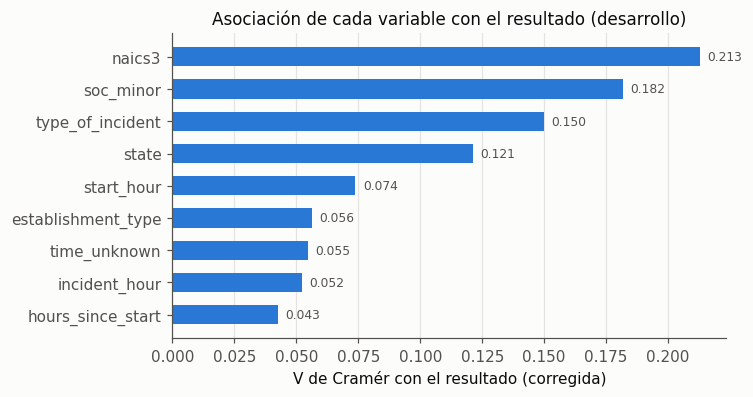

In [3]:
assoc = pd.Series({c: cramers_v(dev[c], y) for c in D.FEATURES}).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh([c for c in assoc.index], assoc.values, color=P.SERIES[0], height=0.6)
for i, v in enumerate(assoc.values):
    ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=8, color=P.INK2)
ax.set_xlabel('V de Cramér con el resultado (corregida)')
ax.set_title('Asociación de cada variable con el resultado (desarrollo)')
ax.grid(axis='y', visible=False)
P.save(fig, 'e3_eda_cramer'); plt.show()

**Interpretación.** El orden coincide con los entregables anteriores: el subsector y el grupo
ocupacional son lo más asociado con el resultado, seguidos por el tipo de incidente y el estado;
las variables de hora casi no aportan. Son asociaciones de a una variable: no dicen cuánto aporta
cada una cuando las demás ya están en el modelo (eso lo mide SHAP en el capítulo 11).

## 4.3 Variable nueva: horas desde el inicio de la jornada

Es la diferencia (módulo 24) entre la hora del incidente y la de inicio de la jornada, en
tramos. Los entregables anteriores la dejaron como siguiente paso. Es faltante cuando falta
cualquiera de las dos horas o la hora del incidente se reportó como desconocida.

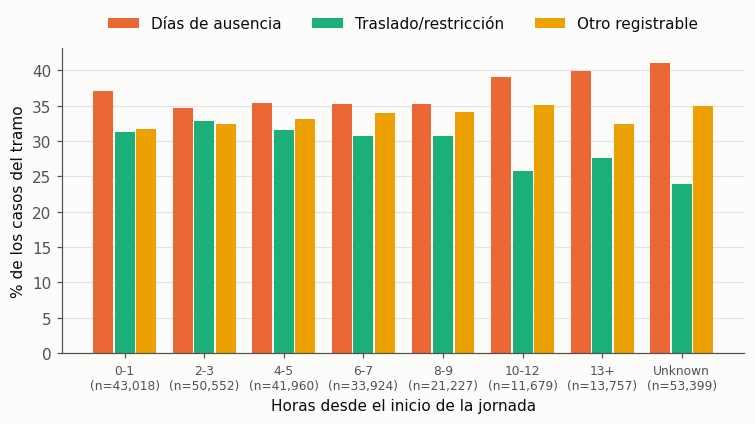

V de Cramér: 0.043


In [4]:
order = ['0-1', '2-3', '4-5', '6-7', '8-9', '10-12', '13+', 'Unknown']
tab = pd.crosstab(dev.hours_since_start, dev.y_clf, normalize='index').reindex(order) * 100
counts = dev.hours_since_start.value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(order)); w = 0.27
for j, k in enumerate([2, 3, 4]):
    ax.bar(x + (j - 1) * w, tab[k], width=w - 0.02, color=P.SERIES[j + 1], label=C.CLASS_NAMES[k - 1])
ax.set_xticks(x, [f'{o}\n(n={counts[o]:,})' for o in order], fontsize=8)
ax.set_ylabel('% de los casos del tramo'); ax.set_xlabel('Horas desde el inicio de la jornada')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.15)); ax.grid(axis='x', visible=False)
P.save(fig, 'e3_eda_horas_desde_inicio'); plt.show()
print('V de Cramér:', round(cramers_v(dev.hours_since_start, y), 3))

**Interpretación.** El 63 % de los incidentes con hora conocida ocurre en las primeras 8 horas de
la jornada. Hasta la hora 9 la mezcla de resultados casi no cambia (días de ausencia entre 35 % y
37 %). En jornadas largas (10 horas o más) y cuando falta la hora, sube la proporción de días de
ausencia (39 % a 41 %) y baja la de traslado o restricción (24 % a 28 %). Es una asociación
débil en conjunto (V = 0,043) y la categoría «Unknown» vuelve a mostrar que los faltantes de
hora no son al azar, por eso se conservan como categoría propia. Fallecimiento no se grafica
(69 casos en el desarrollo).

## 4.4 Objetivo de regresión: días de ausencia

La guía exige también 7 modelos de regresión. El único objetivo numérico del archivo que tiene
sentido con las mismas variables es **el número de días de ausencia** (`dafw_num_away`) de los
casos cuyo resultado es «días de ausencia». En clasificación esta columna se excluía porque
revela el resultado; en regresión es el objetivo, y se usa solo dentro de esa clase, así que no
hay fuga: la pregunta es *dado que el caso terminó en días de ausencia, cuántos días fueron*.

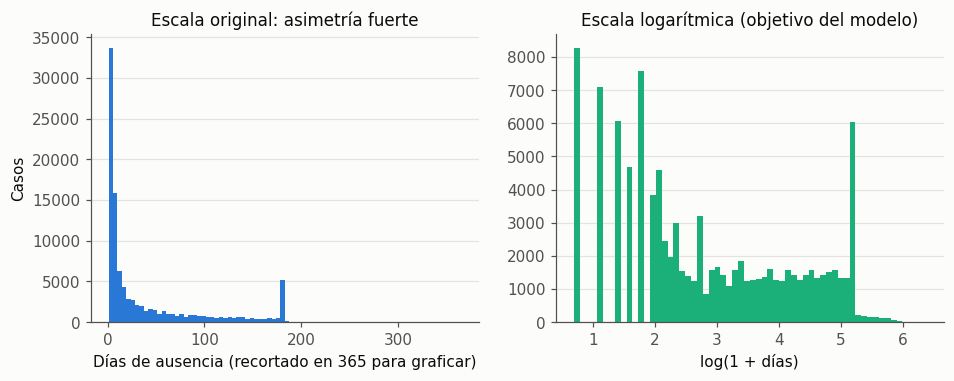

count    99074.0
mean        40.0
std         57.5
min          1.0
25%          4.0
50%         11.0
75%         52.0
90%        140.0
99%        195.0
max        587.0
Asimetría original: 1.87 | asimetría log1p: 0.34
Casos con más de 180 días: 1217 (1.2%)


In [5]:
r = dev[dev.y_reg.notna()]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(r.days_away.clip(upper=365), bins=80, color=P.SERIES[0])
axes[0].set_xlabel('Días de ausencia (recortado en 365 para graficar)'); axes[0].set_ylabel('Casos')
axes[0].set_title('Escala original: asimetría fuerte')
axes[1].hist(r.y_reg, bins=60, color=P.SERIES[2])
axes[1].set_xlabel('log(1 + días)'); axes[1].set_title('Escala logarítmica (objetivo del modelo)')
for a in axes: a.grid(axis='x', visible=False)
P.save(fig, 'e3_eda_dias'); plt.show()
desc = r.days_away.describe(percentiles=[.25, .5, .75, .9, .99])
print(desc.round(1).to_string())
print('Asimetría original:', round(stats.skew(r.days_away), 2), '| asimetría log1p:', round(stats.skew(r.y_reg), 2))
print('Casos con más de 180 días:', int((r.days_away > 180).sum()), f'({(r.days_away > 180).mean():.1%})')

**Interpretación.** Los días de ausencia son muy asimétricos (mediana 11, media 40, máximo 587).
La regla de registro de OSHA permite dejar de contar a los 180 días, pero el archivo tiene casos
por encima: no todas las empresas aplican el tope. Por la asimetría, el modelo predice
`log(1 + días)` (asimetría 1,87 → 0,34): los errores se miden en esa escala (un RMSE de 1
equivale a equivocarse por un factor de unas 2,7 veces en días). Dos rasgos del registro se ven
en la gráfica: los valores pequeños son enteros (1, 2, 3... días, por eso las barras sueltas a la
izquierda) y hay un pico en 180 días, el tope de la regla de OSHA (1,2 % de los casos supera ese
tope).

In [6]:
by_type = r.groupby('type_of_incident').days_away.agg(['count', 'median', 'mean']).round(1)
names = {'1': 'Lesión', '2': 'Trastorno de piel', '3': 'Respiratoria', '4': 'Envenenamiento',
         '5': 'Pérdida auditiva', '6': 'Otra enfermedad'}
by_type.index = [names.get(i, i) for i in by_type.index]
by_type.sort_values('count', ascending=False)

,count,median,mean
Lesión,84527,14.0,44.2
Respiratoria,9624,6.0,7.8
Otra enfermedad,3872,7.0,33.7
Trastorno de piel,583,7.0,15.0
Pérdida auditiva,382,16.0,44.0
Envenenamiento,86,4.5,19.9


**Interpretación.** Las lesiones son el 85 % de los casos con días de ausencia (mediana 14 días).
Las enfermedades respiratorias tienen ausencias mucho más cortas y homogéneas (mediana 6, media
7,8). Es una inferencia, no comprobada con este archivo, que se trate sobre todo de COVID-19
registrado como caso laboral. Encaja con el entregable 2, donde las respiratorias se asociaban
con muchas más posibilidades de terminar en días de ausencia: muchas ausencias, pero cortas.

## 4.5 Hallazgo durante el proyecto: la etiqueta de días está censurada

Al evaluar los modelos de regresión en la prueba (capítulo 10) apareció un sesgo que crecía mes a
mes. La causa se ve ya en los datos: un caso solo puede acumular días de ausencia hasta que se
cierra el reporte anual, así que los incidentes de fin de año no alcanzan ausencias largas. Se
muestra con **todos** los casos de 2023 con días de ausencia (desarrollo, prueba y casos
excluidos por la partición), porque es una propiedad del archivo, no de un modelo.

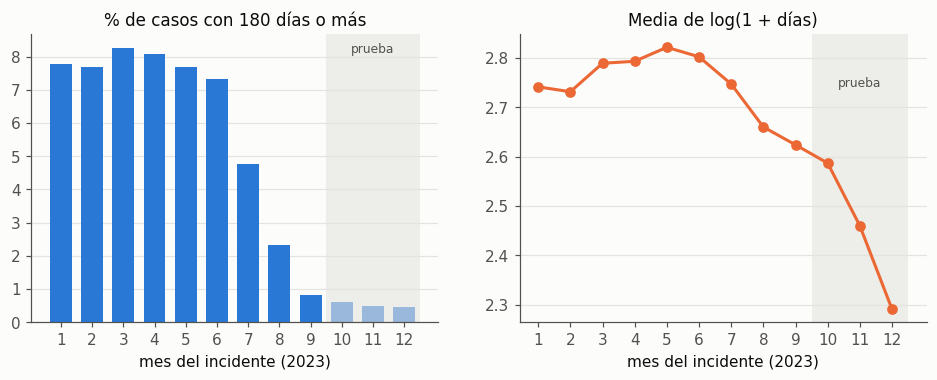

,casos,mediana_dias,media_log,pct_180
mes,,,,
1,30479,10.0,2.74,7.78
2,27079,10.0,2.73,7.69
3,28138,11.0,2.79,8.26
4,24638,12.0,2.79,8.08
5,25789,12.0,2.82,7.69
6,25375,12.0,2.80,7.31
7,26979,11.0,2.75,4.77
8,29925,10.0,2.66,2.33
9,26965,10.0,2.62,0.82


In [7]:
allr = df[df.y_reg.notna()].copy()
allr['mes'] = allr.date.dt.month
m = allr.groupby('mes').agg(casos=('y_reg', 'size'), mediana_dias=('days_away', 'median'),
                            media_log=('y_reg', 'mean'), pct_180=('days_away', lambda x: (x >= 180).mean() * 100))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
axes[0].bar(m.index, m.pct_180, color=P.SERIES[0], width=0.7)
axes[0].set_title('% de casos con 180 días o más'); axes[0].set_xlabel('mes del incidente (2023)')
axes[1].plot(m.index, m.media_log, marker='o', ms=6, color=P.SERIES[1])
axes[1].set_title('Media de log(1 + días)'); axes[1].set_xlabel('mes del incidente (2023)')
for a in axes:
    a.set_xticks(range(1, 13)); a.grid(axis='x', visible=False)
    a.axvspan(9.5, 12.5, color=P.GRID, alpha=0.6, lw=0); a.text(11, a.get_ylim()[1] * 0.97, 'prueba', ha='center', va='top', fontsize=8, color=P.INK2)
P.save(fig, 'e3_eda_censura'); plt.show()
m.round(2)

**Interpretación.** De enero a junio, alrededor del 8 % de los casos con días de ausencia llega al
tope de 180 días; desde julio la proporción cae (4,8 %, 2,3 %, 0,8 %) hasta el 0,5 % en diciembre,
y la media de log(1 + días) baja de ~2,8 a 2,29. No es que las lesiones de fin de año sean más
leves: a esos casos les faltó tiempo para acumular días antes del cierre del archivo. La etiqueta
está **censurada a la derecha** y la censura es más fuerte justo en el trimestre de prueba.

Consecuencias: (1) la clasificación no se ve afectada en la misma medida (basta un día de ausencia
para que el caso sea «días de ausencia»), aunque algún caso reciente podría figurar como
«traslado» u «otro» si su ausencia empezó tarde; (2) en regresión, cualquier modelo entrenado con
enero–septiembre sobrestima los días de octubre–diciembre (capítulo 10). Corregirlo bien exige un
modelo de supervivencia o restringir la evaluación a casos con seguimiento suficiente.

## 4.6 Corrección del entregable 1: `time_unknown` y la colinealidad

El profesor señaló que `time_unknown` superaba el umbral de colinealidad que el propio entregable
1 fijó (GVIF ajustado por grados de libertad de 3,80) y aun así se conservó sin discutirlo. Se
recalcula con las variables del entregable 3. El GVIF de un bloque de columnas one-hot j es
det(R_jj)·det(R_−j,−j)/det(R), con R la matriz de correlación de todas las columnas; se reporta
GVIF^(1/(2·gl)), comparable con √VIF.

In [8]:
from sklearn.preprocessing import OneHotEncoder
smp = dev.sample(60_000, random_state=C.SEED)
enc = OneHotEncoder(drop='first', min_frequency=200, handle_unknown='infrequent_if_exist', sparse_output=False).fit(smp[D.FEATURES])
Z = enc.transform(smp[D.FEATURES])
names_z = enc.get_feature_names_out(D.FEATURES)
keep = Z.std(axis=0) > 0
Z, names_z = Z[:, keep], names_z[keep]
R = np.corrcoef(Z, rowvar=False)
_, logdet_all = np.linalg.slogdet(R)
rows = []
for f in D.FEATURES:
    idx = np.array([n.startswith(f + '_') for n in names_z])
    _, a = np.linalg.slogdet(R[np.ix_(idx, idx)]); _, b = np.linalg.slogdet(R[np.ix_(~idx, ~idx)])
    gvif = np.exp(a + b - logdet_all); dfj = int(idx.sum())
    rows.append({'variable': f, 'gl (columnas)': dfj, 'GVIF': gvif, 'GVIF^(1/(2·gl))': gvif ** (1 / (2 * dfj))})
gv = pd.DataFrame(rows).set_index('variable').sort_values('GVIF^(1/(2·gl))', ascending=False)
display(gv.round(3))
print('Cruce time_unknown × hora del incidente desconocida (desarrollo):')
pd.crosstab(dev.time_unknown, dev.incident_hour.eq('Unknown'), margins=True)

,gl (columnas),GVIF,GVIF^(1/(2·gl))
variable,,,
time_unknown,2,210.830,3.811
hours_since_start,7,17.605,1.227
establishment_type,3,3.295,1.220
incident_hour,24,1285.136,1.161
naics3,38,14017.018,1.134
soc_minor,33,2619.537,1.127
start_hour,24,26.959,1.071
type_of_incident,5,1.409,1.035
state,41,2.545,1.011


Cruce time_unknown × hora del incidente desconocida (desarrollo):


incident_hour,False,True,All
time_unknown,,,
0,233123,55,233178
1,0,35786,35786
Unknown,116,436,552
All,233239,36277,269516


**Interpretación.** `time_unknown` sigue siendo, con diferencia, la variable más colineal (GVIF
ajustado 3,81; la siguiente es 1,23), por construcción: en los 35.786 casos con `time_unknown = 1`
la hora del incidente es «Unknown» (y `hours_since_start` también). No aporta
información propia; su contenido ya está en la categoría «Unknown» de la hora. Con el criterio
del entregable 1 debería salir del modelo. Para los modelos de este entregable (regularizados o de
árboles) la colinealidad no afecta la predicción, solo la interpretación de coeficientes y de
importancias, que se reparten entre las dos columnas redundantes. Se comprueba empíricamente en
el capítulo 12 (sección 12.5): quitar `time_unknown` y reajustar los 7 mejores modelos no cambia
el desempeño más allá del ruido. Por coherencia con el umbral fijado, la interpretación (capítulo 11)
se lee considerando ambas columnas como una sola fuente de información.

## 4.7 Corrección del entregable 1: el costo de los casos que el diseño descarta

El profesor observó que el diseño descarta cerca de la mitad de los casos sin discutir su costo.
La partición de los entregables 1 y 2 (que se mantiene) usa dos cortes a la vez: establecimientos
(40 % desarrollo, 60 % prueba) y tiempo (enero–septiembre para desarrollo, octubre–diciembre para
prueba, con 7 días de purga). Los casos que caen en el cruce «equivocado» no se usan.

In [9]:
dev_est = set(df.loc[df.split.eq('development'), 'establishment_id'])
cat = np.select([df.split.eq('development'), df.split.eq('test'),
                 df.date.ge('2023-09-24') & df.date.lt('2023-10-01'),
                 ~df.establishment_id.isin(dev_est) & df.date.lt('2023-09-24'),
                 df.establishment_id.isin(dev_est) & df.date.ge('2023-10-01')],
                ['Desarrollo (40 % establ., ene–23 sep)', 'Prueba (60 % establ., oct–dic)', 'Purga de 7 días (24–30 sep)',
                 'Descartado: establecimientos de prueba, ene–sep', 'Descartado: establecimientos de desarrollo, oct–dic'],
                'Descartado: otros (establecimientos solo en el periodo excluido)')
tab = pd.Series(cat).value_counts().to_frame('casos')
tab['%'] = tab.casos / len(df) * 100
tab.round(1)

,casos,%
"Descartado: establecimientos de prueba, ene–sep",388659,43.7
"Desarrollo (40 % establ., ene–23 sep)",269516,30.3
"Prueba (60 % establ., oct–dic)",127391,14.3
"Descartado: establecimientos de desarrollo, oct–dic",83912,9.4
Purga de 7 días (24–30 sep),17623,2.0
Descartado: otros (establecimientos solo en el periodo excluido),3271,0.4


**Interpretación.** Se usan 396.907 casos (44,6 %) y quedan fuera 493.465 (55,4 %). La mayor parte
del descarte (43,7 % del archivo) son los casos de enero a septiembre de los establecimientos
reservados para la prueba:
usarlos para entrenar haría que el modelo conociera esos establecimientos y la prueba dejaría de
medir la generalización a lugares nuevos (el riesgo de fuga que motivó la partición). El otro
bloque grande (9,4 %, 83.912 casos) son los casos de octubre a diciembre de los establecimientos de
desarrollo; la purga de 7 días suma un 2,0 %.

**Costo.** (1) *Menos datos para entrenar.* La curva de aprendizaje del entregable 2 mostró que
triplicar los datos casi no mejora la validación (0,377 → 0,385 de balanced accuracy), y en este
entregable los modelos se optimizan sobre una submuestra de 30.000 casos; el cuello de botella no es
la cantidad de casos sino la información de las variables. (2) *Menos casos raros:* se pierden
fallecimientos (69 en desarrollo, 39 en prueba, 172 descartados), lo que agrava el problema de esa
clase. (3) *Prueba más pequeña,* intervalos más anchos. **Beneficio:** una estimación honesta para
establecimientos y fechas nuevos. Además, el bloque descartado de octubre a diciembre de los
establecimientos de desarrollo sirve como una **segunda prueba** que solo separa por tiempo; en el
capítulo 9 (sección 9.8) se evalúan ahí los modelos para medir cuánto cuesta exigir establecimientos
nuevos.

## 4.8 Del EDA a la configuración del entregable 3

| Hallazgo | Decisión |
|---|---|
| NAICS/SOC completos: 1.433 columnas, mucha varianza | Subsector NAICS-3 y grupo menor SOC; categorías con < 20 casos → «infrequent» dentro del pipeline |
| Horas sin relación monótona; faltantes no aleatorios | Horas y tramos de horas desde el inicio como categorías con «Unknown» |
| Fallecimiento = 0,026 % | 4 clases; balanced accuracy como métrica de validación; SMOTE/ADASYN con vecinos ajustados a la clase minoritaria |
| Días de ausencia muy asimétricos | Objetivo de regresión `log1p(días)` |
| Días censurados por el cierre del archivo (más en oct–dic) | Leer la regresión en la prueba como comparación relativa; modelar la censura queda como siguiente paso |
| Casos agrupados por establecimiento | Todos los pliegues (externos e internos) separan establecimientos |

# 5. Modelo base del entregable 2

> **Nota.**
> Este capítulo es el del entregable 2, sin cambios en sus cifras: una regresión logística (C = 1, L2,
> `class_weight='balanced'`, NAICS y SOC completos) frente a un `DummyClassifier`, entrenada con todo el
> desarrollo y evaluada en la misma prueba de octubre a diciembre. Sirve de punto de referencia para los
> 140 modelos del entregable 3 (capítulos 6 a 13).

## 5.1 Qué se entrenó

- **Modelo:** regresión logística multinomial (`LogisticRegression`, penalización L2 con C = 1,
  `class_weight='balanced'`, solver `newton-cg`, semilla 42). Sin búsqueda de hiperparámetros.
- **Línea base trivial:** `DummyClassifier(strategy='prior')`, que responde siempre la clase más frecuente.
- **Pipeline** (todo se ajusta solo con el desarrollo): preparación de variables → imputación con la categoría
  «Unknown» → one-hot (1.433 columnas) → regresión logística. No hay escalado (todas las columnas son 0/1)
  ni eliminación de atípicos.
- **Relación n/p:** 269.516 filas y 1.433 columnas después del one-hot, unas 188 filas por columna.
- **Por qué logística:** el objetivo es categórico. El SVR lineal es de regresión y no aplica.

## 5.2 Resultado en la prueba

La prueba son los 127.391 casos de octubre a diciembre en establecimientos que el modelo nunca vio. Los
intervalos son del 95 % por bootstrap de **establecimientos completos** (1.000 réplicas; 200 para el AUC).

| Métrica | Regresión logística [IC 95 %] | Dummy [IC 95 %] |
|---|---|---|
| Accuracy | 0,524 [0,518 – 0,530] | 0,362 [0,356 – 0,369] |
| Balanced accuracy | 0,402 [0,392 – 0,416] | 0,250 [0,250 – 0,250] |
| Macro F1 score | 0,397 [0,392 – 0,402] | 0,133 [0,131 – 0,135] |
| Macro AUC (one-vs-rest) | 0,693 [0,671 – 0,715] | 0,500 [0,500 – 0,500] |


**Interpretación.**

- La logística supera a la línea base en las cuatro métricas y los intervalos no se solapan. Por ejemplo, la
  diferencia en balanced accuracy es 0,152 (IC 95 % 0,142 a 0,166).
- El nivel es moderado: acierta el 52 % de los casos. Un accuracy tan por debajo del 80–90 % no es señal de
  fuga de información (el enunciado pide revisarla solo si es alta), y el accuracy supera con claridad al 36 %
  de la clase mayoritaria.
- Los intervalos solo cubren la variación entre establecimientos de este trimestre. No incluyen la incertidumbre
  del entrenamiento ni choques comunes del calendario.

## 5.3 Resultado por clase

| Resultado | Precision | Recall | F1 score | Casos en prueba |
|---|---|---|---|---|
| Fallecimiento (Death) | 0,000 | 0,026 | 0,001 | 39 |
| Días de ausencia | 0,600 | 0,436 | 0,505 | 46.169 |
| Traslado / restricción | 0,478 | 0,562 | 0,516 | 37.231 |
| Otro caso registrable | 0,546 | 0,585 | 0,564 | 43.952 |


**Interpretación.** Las tres clases frecuentes tienen F1 score entre 0,505 y 0,564. Fallecimiento casi no se detecta:
el modelo identifica 1 de 39 casos (recall 2,6 %; intervalo de Wilson del 95 %: 0,5 % a 13,2 %) y su
precision es de 0,03 %. Con 39 casos, cada uno en un establecimiento distinto, no se puede afirmar nada fiable
sobre esa clase.

## 5.4 Matriz de confusión

![Matriz de confusión de la regresión logística en la prueba (cada fila suma 100 % de la clase real).](figures/modelo_confusion.png)

*Matriz de confusión de la regresión logística en la prueba (cada fila suma 100 % de la clase real).*

**Interpretación.** La diagonal de las tres clases frecuentes está entre 43,6 % y 58,5 %, y el resto se reparte
sobre todo entre esas mismas tres clases. El modelo separa mejor «otro caso registrable» (58,5 %) y
«traslado / restricción» (56,2 %) que «días de ausencia» (43,6 %). El Dummy manda todos los casos a «días de
ausencia» (recall 100 % en esa clase y 0 % en las demás). Más de la mitad de los fallecimientos reales
(51,3 %) se clasifican como «traslado / restricción».

## 5.5 Curvas ROC y Precision-Recall

![Curvas ROC (una clase contra las otras tres) y Precision-Recall de la regresión logística.](figures/modelo_roc_pr.png)

*Curvas ROC (una clase contra las otras tres) y Precision-Recall de la regresión logística.*

**Interpretación.** Los AUC de las tres clases frecuentes van de 0,70 a 0,73. Fallecimiento tiene 0,61 con una
curva muy irregular: son 39 casos. En la curva Precision-Recall, la línea de base de cada clase es su
proporción de casos (0,36; 0,29 y 0,35); la logística la supera, pero con margen modesto. Para Fallecimiento el
AP es 0,0005 frente a una prevalencia de 0,0003.

## 5.6 Validación cronológica y por establecimiento

Se probaron tres ventanas hacia adelante dentro del desarrollo (entrenar antes de abril y validar abril–mayo;
antes de junio y validar junio–julio; antes de agosto y validar agosto–septiembre), siempre con establecimientos
distintos y 7 días de purga.

| Modelo | Pliegue | Accuracy | Balanced accuracy | Macro F1 score | Macro AUC |
|---|---|---|---|---|---|
| LogisticRegression | 1 | 0,505 | 0,380 | 0,375 | 0,762 |
| DummyClassifier | 1 | 0,337 | 0,250 | 0,126 | 0,500 |
| LogisticRegression | 2 | 0,506 | 0,383 | 0,379 | 0,629 |
| DummyClassifier | 2 | 0,353 | 0,250 | 0,130 | 0,500 |
| LogisticRegression | 3 | 0,519 | 0,392 | 0,391 | 0,687 |
| DummyClassifier | 3 | 0,357 | 0,250 | 0,132 | 0,500 |


**Interpretación.** El balanced accuracy de la logística es estable entre pliegues (media 0,385; desviación
0,006) y siempre mejora a la línea base (0,25). El macro AUC varía más (0,629 a 0,762). Es una inferencia, no
comprobada, que esto se deba a que cada pliegue tiene solo 1 a 8 fallecimientos y esa clase pesa un cuarto en
el promedio. Las desviaciones entre pliegues no son intervalos de confianza.

## 5.7 Curva de aprendizaje

![Balanced accuracy con el 25 %, 50 % y 100 % de los establecimientos de cada entrenamiento.](figures/modelo_aprendizaje.png)

*Balanced accuracy con el 25 %, 50 % y 100 % de los establecimientos de cada entrenamiento.*

**Interpretación.** La validación casi no mejora al triplicar los datos (de 0,377 a 0,385) y la distancia con el
entrenamiento (cerca de 0,28) no se cierra. Con estos 8 predictores y un modelo lineal, más casos no parecen
cambiar el resultado. La brecha de balanced accuracy probablemente se debe en buena parte a Fallecimiento,
que con muy pocos casos el modelo ajusta bien en el entrenamiento y no generaliza (inferencia, no
comprobada). La brecha de accuracy simple es mucho menor (0,54 frente a 0,51).

## 5.8 Calibración

Las probabilidades salen de un modelo con clases ponderadas, así que pueden sobreestimar las clases raras
respecto de su frecuencia real (las curvas de calibración están en el anexo). El Brier multiclase es 0,583 (Dummy: 0,664) y la pérdida logarítmica es 1,001 (Dummy: 1,097);
menor es mejor. No se recalibró nada con la prueba.

## 5.9 Qué dicen los coeficientes

Se comparan **dos categorías del mismo predictor con todo lo demás fijo**, siempre contra la clase
«otro caso registrable». El número es una razón de posibilidades relativa dentro del modelo: 1 significa sin
diferencia; 2, el doble de posibilidades.

| Comparación | Fallecimiento | Días de ausencia | Traslado / restricción |
|---|---|---|---|
| Enfermedad respiratoria frente a lesión | 44,80 | 18,86 | 0,32 |
| Pérdida auditiva frente a lesión | 0,002 | 0,14 | 0,14 |
| Enfermería profesional frente a movimiento manual de materiales | 0,027 | 0,48 | 0,54 |
| Hospitales generales frente a almacenamiento general | 1,57 | 0,20 | 0,11 |

**Interpretación.** Frente a una lesión, una enfermedad respiratoria se asocia dentro del modelo con muchas más
posibilidades de terminar en días de ausencia que en «otro caso registrable» (18,9 veces) y con menos de
terminar en traslado o restricción (0,32). Para ocupaciones y sectores, enfermería y hospitales tienden hacia
«otro caso registrable» y se alejan de los días de ausencia y de la restricción. Son asociaciones, no efectos
causales: pueden reflejar mezcla de ocupaciones, confusión y prácticas de reporte. Los coeficientes de
Fallecimiento son inestables (solo 69 casos de entrenamiento) y las cifras de esa columna no se interpretan.

## 5.10 Por sector

Se evaluó por separado cada uno de los 12 sectores con al menos 1.000 casos en el desarrollo (criterio fijado
sin mirar la prueba). El accuracy de la logística va de 0,33 en servicios administrativos y de apoyo (sector 56)
a 0,62 en salud y asistencia social (sector 62). La logística supera al Dummy en 10 de los 12, pero **no en
todos**: en agricultura (sector 11) queda por debajo (0,361 frente a 0,384), en servicios administrativos y de apoyo
también (0,330 frente a 0,364), y en construcción (sector 23) están prácticamente empatados (0,338 frente a
0,334). Como el accuracy del Dummy cambia con la mezcla de clases de cada sector (de 0,25 a 0,40), estas
comparaciones se leen con cuidado. No son un ranking de seguridad de los sectores.


# 6. Diseño del pipeline combinatorio

El entregable 3 no entrena un modelo sino **140**: cada modelo base se combina con cada técnica
de balanceo (solo en clasificación) y cada combinación se optimiza con cada uno de los cuatro
métodos de búsqueda.

| Tarea | Modelos | Balanceo | Optimización | Total |
|---|---|---|---|---|
| Clasificación (resultado del caso, 4 clases) | 7 | 4 | 4 | 7 × 4 × 4 = **112** |
| Regresión (log de los días de ausencia) | 7 | — | 4 | 7 × 4 = **28** |
| **Total** | | | | **140** |

Todo el código vive en el paquete `src/osha_e3/`, separado por responsabilidad:

| Módulo | Qué hace |
|---|---|
| `config.py` | Semilla global única (42), semillas derivadas, rutas, tamaños de muestra |
| `data.py` | Carga del CSV, partición del entregable 1, preparación de variables, submuestras |
| `models.py` | Los 14 modelos, el balanceo, los espacios de búsqueda y las rejillas |
| `search.py` | Evaluador común y los 4 métodos (Grid, Random, Optuna-TPE, DEAP) |
| `nested.py` | Validación cruzada anidada, registro de cada corrida y tabla maestra |
| `final.py` | Reajuste de cada combinación y evaluación en la prueba |
| `evaluation.py` | Métricas de clasificación (incl. calibración) y de regresión |
| `stats_tests.py` | Friedman, Nemenyi, DeLong, Diebold-Mariano, MCS, GW, CW, SPA, bootstrap |
| `complexity.py` | Experimentos de costo computacional y perfilamiento |

Las corridas largas se lanzan con `scripts/run_nested.py` y `scripts/run_final.py`; los capítulos
leen los resultados guardados en `results/`.

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from osha_e3 import config as C, data as D, models as M, nested as N
print('Combinaciones de clasificación:', len(M.combos('clf')), '| de regresión:', len(M.combos('reg')))

Combinaciones de clasificación: 112 | de regresión: 28


## 6.1 Datos de cada tarea

- **Clasificación.** El objetivo son los 4 resultados del caso, igual que en los entregables 1 y 2.
  Se mantiene la partición del entregable 1: la **prueba** son los casos de octubre a diciembre de
  un 60 % de los establecimientos, que no se usa en nada de la búsqueda.
- **Regresión.** `log(1 + días de ausencia)` en los casos que terminaron en días de ausencia,
  con la misma partición.

**Submuestra para la búsqueda.** El desarrollo tiene 269.516 casos. Entrenar 140 combinaciones ×
5 pliegues externos × 16 configuraciones × 3 pliegues internos (más de 33.000 ajustes) sobre todo
el desarrollo no cabe en el tiempo disponible (con KNN y SMOTE el costo crece con n² o n·p por
consulta; ver capítulo 8). Se trabaja con una submuestra de **establecimientos completos**
(~30.000 casos en clasificación, ~20.000 en regresión) sorteada con la semilla global. La prueba
se usa completa.

In [2]:
sub_c, dev_c, test_c = D.classification_sets()
sub_r, dev_r, test_r = D.regression_sets()
resumen = pd.DataFrame({
    'Desarrollo completo': [len(dev_c), len(dev_r)],
    'Submuestra (búsqueda)': [len(sub_c), len(sub_r)],
    'Establecimientos submuestra': [sub_c.establishment_id.nunique(), sub_r.establishment_id.nunique()],
    'Prueba (oct-dic)': [len(test_c), len(test_r)],
}, index=['Clasificación', 'Regresión'])
resumen

,Desarrollo completo,Submuestra (búsqueda),Establecimientos submuestra,Prueba (oct-dic)
Clasificación,269516,30030,3503,127391
Regresión,99074,20001,5079,45861


In [3]:
dist = pd.DataFrame({'Desarrollo completo (%)': dev_c.y_clf.value_counts(normalize=True).sort_index() * 100,
                     'Submuestra (%)': sub_c.y_clf.value_counts(normalize=True).sort_index() * 100,
                     'Submuestra (casos)': sub_c.y_clf.value_counts().sort_index(),
                     'Prueba (%)': test_c.y_clf.value_counts(normalize=True).sort_index() * 100})
dist.index = C.CLASS_NAMES
dist.round(3)

,Desarrollo completo (%),Submuestra (%),Submuestra (casos),Prueba (%)
Fallecimiento,0.026,0.030,9,0.031
Días de ausencia,36.991,36.983,11106,36.242
Traslado/restricción,29.626,30.586,9185,29.226
Otro registrable,33.357,32.401,9730,34.502


**Interpretación.** La submuestra conserva la mezcla de clases del desarrollo (diferencias de
décimas de punto). Fallecimiento queda con solo 9 casos: con esa cantidad ninguna métrica de esa
clase es estable, y SMOTE/ADASYN deben usar menos vecinos que su valor por defecto (5) porque en
cada entrenamiento interno quedan unos 5 fallecimientos.

## 6.2 Validación cruzada anidada

- **Bucle externo: 5 pliegues** por establecimiento (`StratifiedGroupKFold`). Cada pliegue
  externo deja entre 5.200 y 7.300 casos fuera para medir el desempeño del modelo *ya optimizado*. 5 pliegues
  dan 5 mediciones independientes para la media ± desviación y para las pruebas de Friedman sin
  dejar entrenamientos demasiado pequeños.
- **Bucle interno: 3 pliegues** por establecimiento dentro del entrenamiento externo (23.000 a 25.000 casos;
  cada entrenamiento interno tiene unos 16.000). Es donde cada método de búsqueda evalúa configuraciones. 3 pliegues bastan para ordenar
  configuraciones y mantienen el costo: cada configuración cuesta 3 ajustes.
- **Por qué agrupar:** los casos de un establecimiento comparten prácticas de registro; si un
  establecimiento quedara a ambos lados, la validación sería optimista (lo mismo que motivó la
  partición del entregable 1).
- **Métrica reportada:** siempre la del bucle externo. El mejor valor del bucle interno se guarda
  solo para comparar (capítulo 7, sesgo de selección).

In [4]:
X, y, g, s = N.task_data('clf')
rows = []
for f, (tr, te) in enumerate(N.outer_folds('clf')):
    inner = N.inner_folds('clf', tr, f)
    rows.append({'Pliegue externo': f + 1, 'Entrenamiento externo': len(tr), 'Evaluación externa': len(te),
                 'Fallecimientos (evaluación)': int((y[te] == 0).sum()),
                 'Establecimientos compartidos': len(set(g[tr]) & set(g[te])),
                 'Tamaño medio entrenamiento interno': int(np.mean([len(a) for a, b in inner])),
                 'Fallecimientos por entrenamiento interno': ', '.join(str(int((y[tr][a] == 0).sum())) for a, b in inner)})
pd.DataFrame(rows).set_index('Pliegue externo')

,Entrenamiento externo,Evaluación externa,Fallecimientos (evaluación),Establecimientos compartidos,Tamaño medio entrenamiento interno,Fallecimientos por entrenamiento interno
Pliegue externo,,,,,,
1,23242,6788,2,0,15494,"4, 5, 5"
2,22769,7261,1,0,15179,"5, 6, 5"
3,24816,5214,0,0,16544,"2, 8, 8"
4,24583,5447,2,0,16388,"4, 5, 5"
5,24710,5320,4,0,16473,"4, 4, 2"


**Interpretación.** Ningún establecimiento se comparte entre entrenamiento y evaluación de un
mismo pliegue. Los pliegues externos tienen entre 0 y 4 fallecimientos (el pliegue 3, ninguno): la AUC de esa
clase en cada pliegue es muy ruidosa, y por eso la métrica de validación no puede depender de
ella sola.

## 6.3 Métrica de validación

**Clasificación: balanced accuracy** (el recall promedio de las 4 clases). En este problema el
error más costoso es no reconocer un caso grave (un fallecimiento o unos días de ausencia
clasificados como «otro caso registrable»): es un falso negativo de la clase grave. El recall por
clase mide exactamente eso, y promediarlo da a cada clase el mismo peso sin importar su tamaño.
El accuracy simple, en cambio, premia acertar la clase mayoritaria. Se reportan además precision,
F1 y AUC macro, y Brier/ECE para la calibración.

**Regresión: RMSE** en escala `log1p`. Penaliza más los errores grandes (predecir 3 días para
una ausencia de 6 meses), que son los costosos para planificar reemplazos o reintegro. Se
reporta también el MAE.

## 6.4 Pipeline y ausencia de fuga de información

La preparación de `data.prepare_features` es determinista (cortar códigos, extraer la hora): no
aprende nada de los datos y puede aplicarse antes de partir. Todo lo que aprende de los datos está
dentro de un `Pipeline` de imblearn que se ajusta **solo con la parte de entrenamiento** de cada
pliegue:

1. `OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist')`: qué categorías son
   raras se decide con el entrenamiento del pliegue.
2. `SMOTE` o `ADASYN` (si corresponde): genera casos sintéticos solo en el entrenamiento; al
   predecir, el paso se omite.
3. El modelo.

Para Optuna y DEAP, que no integran `Pipeline`, el evaluador (`search.Evaluator`) ajusta
manualmente codificador → balanceo → modelo en cada pliegue interno. Como la codificación y el
remuestreo no dependen de los hiperparámetros, se calculan una vez por pliegue y se reutilizan
en las 16 configuraciones (el mismo cálculo, sin repetirlo).

In [5]:
pipe = M.make_pipeline('clf', 'random_forest',
                       {'n_estimators': 100, 'max_depth': 10, 'min_samples_leaf': 2, 'max_features': 0.1},
                       balance='smote')
pipe

Pipeline(steps=[('onehot',
                 OneHotEncoder(dtype=<class 'numpy.float32'>,
                               handle_unknown='infrequent_if_exist',
                               min_frequency=20)),
                ('sampler', SafeSMOTE(random_state=42)),
                ('dense',
                 FunctionTransformer(accept_sparse=True,
                                     func=<function _to_dense at 0x0000023A3CEAFEE0>)),
                ('model',
                 RandomForestClassifier(max_depth=10, max_features=0.1,
                                        min_samples_leaf=2, n_jobs=1,
                                        random_state=42))])

## 6.5 Balanceo de clases

| Técnica | Qué hace | Detalle de implementación |
|---|---|---|
| Sin balanceo | Línea base | — |
| SMOTE | Interpola casos sintéticos entre un caso minoritario y sus vecinos de la misma clase | Lleva todas las clases al tamaño de la mayoritaria; `k_neighbors = min(5, n_min − 1)` |
| ADASYN | Como SMOTE, pero genera más casos donde la minoritaria está rodeada de otras clases (más difícil) | Implementación propia clase por clase (`models.SafeADASYN`), `k = min(5, n_min − 1)`; ver nota abajo |
| `class_weight='balanced'` | Pondera los errores por la inversa de la frecuencia de la clase | Nativo en logística, árbol, RF y SVM; pesos por observación en Naive Bayes y XGBoost; en KNN, división de la probabilidad por la prior (regla de decisión equivalente) |

**Nota sobre ADASYN.** La implementación de imblearn falló en el 78 % de las celdas de una primera
corrida, por dos razones: usa `n_neighbors + 1` vecinos dentro de la clase minoritaria (imposible con
4 o 5 fallecimientos) y redondea por separado las muestras de cada punto, de modo que cuando hay que
generar menos de 0,5 muestras por punto (p. ej. 581 entre 4.063 casos de una clase casi tan grande
como la mayoritaria) todas redondean a 0 y la función se detiene; con la estrategia por defecto basta
que falle una clase para que falle todo. Esas celdas quedaron en la práctica sin balanceo. Se
reimplementó ADASYN siguiendo el artículo original (He et al., 2008): la dificultad de cada caso es la
fracción de vecinos de otra clase, las G muestras se reparten en proporción a ella con redondeo por
restos mayores (suman exactamente G) y cada muestra interpola con un vecino de la misma clase. Las
140 celdas de ADASYN se volvieron a correr con esta versión.

Una advertencia: las variables son todas binarias (one-hot). SMOTE y ADASYN interpolan y producen
valores fraccionarios entre 0 y 1 que no corresponden a ninguna categoría real. SMOTE-NC está
pensado para categóricas, pero la guía pide SMOTE y ADASYN; el efecto se mide, no se supone.

## 6.6 Espacios de búsqueda

Los cuatro métodos exploran el **mismo espacio** con el **mismo presupuesto: 16 configuraciones**
por búsqueda. Los parámetros de escala (C, alpha, learning rate, min_child_weight, número de
vecinos, min_samples_leaf) se exploran en escala logarítmica. Los rangos siguen valores
habituales y el tamaño de los datos (~16.000 filas por entrenamiento interno, ~210 columnas):

- **KNN:** 5 a 801 vecinos (con pocas variables informativas hacen falta muchos vecinos para
  suavizar; una primera corrida con tope 201 eligió el tope en la mitad de las búsquedas de
  regresión, así que el rango se amplió), pesos uniformes o por distancia.
- **Naive Bayes (Bernoulli):** suavizado alpha entre 0,001 y 10; con o sin prior. Se usa la
  versión de Bernoulli porque todas las variables son binarias.
- **Logística:** C de 0,001 a 10, L1 o L2 (solver SAGA, válido para ambas).
- **Árbol:** profundidad 3 a 30, hojas de 1 a 500 casos (ampliado desde 200 por la misma razón).
- **Random Forest:** 50 a 250 árboles, profundidad 6 a 30, fracción de variables por división
  de 3 % a 30 % (≈ √210 / 210 = 7 % es el valor por defecto).
- **XGBoost:** 100 a 400 árboles, profundidad 2 a 10, learning rate 0,01 a 0,3, submuestreo de
  filas 0,6 a 1 y de columnas 0,4 a 1, min_child_weight 1 a 20.
- **SVM (LinearSVC) / SVR (LinearSVR):** C de 0,001 a 10; pérdida bisagra o bisagra cuadrática
  (SVM) y epsilon de 0 a 1,5 (SVR, en escala log1p de días; ampliado desde 1).
- **Ridge:** alpha 0,01 a 1.000; **Lasso:** alpha 0,00001 a 0,1.

In [6]:
def fmt(spec):
    if spec[0] == 'cat':
        return ' / '.join(map(str, spec[1]))
    return f'{spec[1]} – {spec[2]}' + (' (log)' if spec[3] else '')
rows = [{'Tarea': 'Clasificación' if t == 'clf' else 'Regresión', 'Modelo': M.PRETTY[m], 'Hiperparámetro': k,
         'Rango (Random / Optuna / genético)': fmt(v), 'Valores en la rejilla (Grid)': ', '.join(map(str, M.GRIDS[t][m].get(k, ['por defecto'])))}
        for t in ['clf', 'reg'] for m, sp in M.SPACES[t].items() for k, v in sp.items()]
pd.DataFrame(rows).set_index(['Tarea', 'Modelo'])

Hiperparámetro  \
Tarea         Modelo                             
Clasificación KNN                  n_neighbors   
              KNN                      weights   
              Naive Bayes                alpha   
              Naive Bayes            fit_prior   
              Reg. logística                 C   
              Reg. logística           penalty   
              Árbol                  max_depth   
              Árbol           min_samples_leaf   
              Árbol                  criterion   
              Random Forest       n_estimators   
              Random Forest          max_depth   
              Random Forest   min_samples_leaf   
              Random Forest       max_features   
              XGBoost             n_estimators   
              XGBoost                max_depth   
              XGBoost            learning_rate   
              XGBoost                subsample   
              XGBoost         colsample_bytree   
              XGBoost         min_child_weight   
              SVM                            C   
              SVM                         loss   
Regresión     KNN                  n_neighbors   
              KNN                      weights   
              Ridge                      alpha   
              Lasso                      alpha   
              Árbol                  max_depth   
              Árbol           min_samples_leaf   
              Árbol                  criterion   
              Random Forest       n_estimators   
              Random Forest          max_depth   
              Random Forest   min_samples_leaf   
              Random Forest       max_features   
              XGBoost             n_estimators   
              XGBoost                max_depth   
              XGBoost            learning_rate   
              XGBoost                subsample   
              XGBoost         colsample_bytree   
              XGBoost         min_child_weight   
              SVR                            C   
              SVR                      epsilon   

                             Rango (Random / Optuna / genético)  \
Tarea         Modelo                                              
Clasificación KNN                                 5 – 801 (log)   
              KNN                            uniform / distance   
              Naive Bayes                    0.001 – 10.0 (log)   
              Naive Bayes                          True / False   
              Reg. logística                 0.001 – 10.0 (log)   
              Reg. logística                            l1 / l2   
              Árbol                                      3 – 30   
              Árbol                               1 – 500 (log)   
              Árbol                              gini / entropy   
              Random Forest                            50 – 250   
              Random Forest                              6 – 30   
              Random Forest                        1 – 50 (log)   
              Random Forest                    0.03 – 0.3 (log)   
              XGBoost                                 100 – 400   
              XGBoost                                    2 – 10   
              XGBoost                          0.01 – 0.3 (log)   
              XGBoost                                 0.6 – 1.0   
              XGBoost                                 0.4 – 1.0   
              XGBoost                              1 – 20 (log)   
              SVM                            0.001 – 10.0 (log)   
              SVM                         hinge / squared_hinge   
Regresión     KNN                                 5 – 801 (log)   
              KNN                            uniform / distance   
              Ridge                         0.01 – 1000.0 (log)   
              Lasso                           1e-05 – 0.1 (log)   
              Árbol                                      3 – 30   
              Árbol                               1 – 5

**Por qué SVM lineal.** El SVM con núcleo (RBF) cuesta entre O(n²) y O(n³) en entrenamiento.
Con 16.000 a 25.000 filas por ajuste y 245 ajustes por combinación no es viable (capítulo 8 lo
mide). La guía misma recomienda `LinearSVC`/SGD para muestras grandes. Para AUC se usa el
softmax de la función de decisión (solo importa el orden); la calibración con Platt se estudia
en el capítulo 9.

## 6.7 Registro de experimentos y semillas

Cada celda (combinación × pliegue externo) se guarda en `results/nested/<tarea>/*.json` con los
hiperparámetros elegidos, la métrica interna, las métricas externas, el tiempo de búsqueda, de
reajuste y de predicción, la semilla y el historial completo de las 16 evaluaciones. Con ellas
se construye la **tabla maestra** (`results/master_clf.csv`, `results/master_reg.csv`).

Semilla global: **42** (`config.SEED`). Las semillas derivadas se calculan como
`42 + desplazamiento × 1000 + índice` (`config.seed_for`): submuestra, pliegues externos,
internos, búsqueda (Random, TPE, genético) y bootstrap. La misma semilla se pasa a numpy,
scikit-learn, XGBoost, imblearn, Optuna y DEAP.

In [7]:
pd.Series({k: C.seed_for(k) for k in C.OFFSETS}, name='semilla (índice 0)').to_frame()

,semilla (índice 0)
subsample,1042
outer,2042
inner,3042
search,4042
model,5042
bootstrap,100042


## 6.8 El código de entrenamiento, visible

Corrección del entregable 1: el profesor señaló que el código de entrenamiento no se veía en el
notebook. Aquí se imprime el código fuente real (no una copia) de las funciones que entrenan y
evalúan cada combinación. Lo que se ve es exactamente lo que ejecutó `scripts/run_nested.py`.

**1. El evaluador del bucle interno** (`search.Evaluator`): prepara una vez la codificación y el
balanceo de cada pliegue interno y, para cada configuración, ajusta el modelo en cada pliegue y
promedia la métrica de validación.

In [8]:
import inspect
from osha_e3 import search as S, final as F
print(inspect.getsource(S.Evaluator))

class Evaluator:
    """Evalúa configuraciones con validación cruzada interna y registra cada evaluación.

    Parameters
    ----------
    task, name, balance : str
        Tarea, modelo y técnica de balanceo.
    X : pandas.DataFrame
        Variables preparadas del entrenamiento externo.
    y : numpy.ndarray
    folds : list of (train_idx, valid_idx)
        Pliegues internos (por establecimiento).
    seed : int
    budget : int
        Máximo de configuraciones distintas a evaluar.
    """

    def __init__(self, task, name, balance, X, y, folds, seed, budget):
        self.task, self.name, self.balance = task, name, balance
        self.X, self.y, self.folds, self.seed, self.budget = X, y, folds, seed, budget
        self.cache, self.history, self.t0 = {}, [], time.perf_counter()
        self.prepared = None

    def _prepare(self):
        """Codificación y remuestreo de cada pliegue interno, calculados una sola vez.

        El one-hot y SMOTE/ADASYN no dependen de los hiperp

**2. Una celda de la validación anidada** (`nested.run_cell`): busca en el bucle interno, reajusta
con los mejores hiperparámetros en todo el entrenamiento externo y mide en el pliegue externo.

In [9]:
print(inspect.getsource(N.run_cell))

def run_cell(task, model, balance, opt, fold, budget=C.BUDGET, seed=C.SEED, out=None):
    """Optimiza en el bucle interno y evalúa en el pliegue externo ``fold``.

    Returns
    -------
    dict
        Métricas externas, mejores hiperparámetros, puntaje interno, tiempos e historial.
    """
    path = out or cell_path(task, model, balance, opt, fold)
    if path.exists():
        return json.loads(path.read_text(encoding='utf-8'))
    with threadpool_limits(limits=1):
        X, y, g, s = task_data(task)
        tr, te = outer_folds(task)[fold]
        Xtr, ytr = X.iloc[tr].reset_index(drop=True), y[tr]
        folds = inner_folds(task, tr, fold)
        ev = S.Evaluator(task, model, balance, Xtr, ytr, folds, seed, budget)
        t0 = time.perf_counter()
        params, inner, extra = S.run_search(opt, ev, task, model, C.seed_for('search', fold) + (seed - C.SEED))
        t_search = time.perf_counter() - t0
        t0 = time.perf_counter()
        pipe = S.refit(task, model, param

**3. Construcción del pipeline y del modelo** (`models.make_pipeline`, `models.make_estimator`).

In [10]:
print(inspect.getsource(M.make_pipeline))
print(inspect.getsource(M.make_estimator))

def make_pipeline(task, name, params, balance='none', seed=42):
    """Pipeline completo (codificación → balanceo → modelo) que se ajusta solo con datos de entrenamiento.

    Se usa el ``Pipeline`` de imblearn para que SMOTE/ADASYN se apliquen únicamente al ajustar
    (en ``predict`` el paso de remuestreo se omite), sin fuga hacia validación o prueba.
    """
    steps = [('onehot', make_encoder())]
    sampler = make_sampler(balance, seed) if task == 'clf' else None
    if sampler is not None:
        steps.append(('sampler', sampler))
    if name == 'random_forest':
        # sklearn construye los bosques mucho más rápido sobre matrices densas (≈4× aquí).
        steps.append(('dense', FunctionTransformer(_to_dense, accept_sparse=True)))
    steps.append(('model', make_estimator(task, name, params, balance, seed)))
    return Pipeline(steps)

def make_estimator(task, name, params, balance='none', seed=42):
    """Crea el estimador final de un modelo con sus hiperparámetros.

    Pa

**4. Los métodos de búsqueda** (Optuna-TPE y el algoritmo genético de DEAP).

In [11]:
print(inspect.getsource(S.bayes_search))
print(inspect.getsource(S.genetic_search))

def bayes_search(ev, space, grid, rng):
    """Optimización bayesiana con Optuna.

    Sustituto: *Tree-structured Parzen Estimator* (TPE), que modela p(x | y bueno) = l(x) y
    p(x | y malo) = g(x) con estimadores de Parzen. Adquisición: Mejora Esperada (EI); en TPE
    maximizar EI equivale a maximizar l(x)/g(x). Las primeras 5 pruebas son aleatorias
    (exploración) y luego TPE explota las regiones con mayor razón l/g.
    """
    sampler = optuna.samplers.TPESampler(seed=int(rng.integers(1 << 31)), n_startup_trials=5,
                                         multivariate=True)
    study = optuna.create_study(direction='maximize', sampler=sampler)

    def objective(trial):
        params = {}
        for k, spec in space.items():
            if spec[0] == 'cat':
                params[k] = trial.suggest_categorical(k, spec[1])
            elif spec[0] == 'int':
                params[k] = trial.suggest_int(k, spec[1], spec[2], log=spec[3])
            else:
                params

**5. Reajuste final y evaluación en la prueba** (`final.run_one`).

In [12]:
print(inspect.getsource(F.run_one))

def run_one(task, model, balance, opt, params_json, seed=C.SEED):
    """Reajusta una combinación y guarda predicciones de prueba, métricas y tiempos."""
    combo = f'{model}|{balance}|{opt}'
    path = out_path(task, combo)
    if path.exists():
        return
    with threadpool_limits(limits=1):
        X, y, _, _ = N.task_data(task)
        test, yt = test_data(task)
        params = json.loads(params_json)
        t0 = time.perf_counter()
        pipe = S.refit(task, model, params, balance, X, y, seed)
        fit_s = time.perf_counter() - t0
        t0 = time.perf_counter()
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            out = E.predict_output(task, pipe, test[D.FEATURES])
        pred_s = time.perf_counter() - t0
    m = E.metrics_for(task, yt, out)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(path, out=out.astype(np.float32),
                        meta=json.dumps({'combo': combo, 'params': params, 

## 6.9 Inventario: los 140 modelos entrenados y los modelos base de la guía

Esta sección comprueba con los archivos de resultados (no con el texto) que están todas las
combinaciones exigidas: 112 de clasificación y 28 de regresión, cada una con sus 5 pliegues externos
de validación anidada y su evaluación final en la prueba.

In [13]:
import glob
from osha_e3 import config as C
checks = []
for task, n_combos in [('clf', 112), ('reg', 28)]:
    combos = M.combos(task)
    cells = [N.cell_path(task, m, b, o, f).exists() for (m, b, o) in combos for f in range(C.OUTER_FOLDS)]
    finals = [F.out_path(task, f'{m}|{b}|{o}').exists() for (m, b, o) in combos]
    checks.append({'tarea': 'Clasificación' if task == 'clf' else 'Regresión', 'combinaciones exigidas': n_combos,
                   'combinaciones definidas': len(combos), 'celdas de validación anidada (× 5 pliegues)': sum(cells),
                   'evaluaciones en la prueba': sum(finals)})
inv = pd.DataFrame(checks).set_index('tarea')
inv.loc['Total'] = inv.sum()
assert inv.loc['Total', 'combinaciones definidas'] == 140 and inv.loc['Total', 'evaluaciones en la prueba'] == 140
assert inv.loc['Total', 'celdas de validación anidada (× 5 pliegues)'] == 700
inv

,combinaciones exigidas,combinaciones definidas,celdas de validación anidada (× 5 pliegues),evaluaciones en la prueba
tarea,,,,
Clasificación,112,112,560,112
Regresión,28,28,140,28
Total,140,140,700,140


**Modelos base exigidos en la sección 7.2 de la guía** y su implementación:

In [14]:
req = pd.DataFrame([
    ('K-Nearest Neighbors (KNN)', 'Clasificación y regresión', 'KNeighborsClassifier / KNeighborsRegressor', 'knn'),
    ('Naive Bayes', 'Clasificación', 'BernoulliNB (variables binarias)', 'naive_bayes'),
    ('Regresión logística L1 y L2', 'Clasificación', 'LogisticRegression (saga), penalización L1 o L2 como hiperparámetro', 'logreg'),
    ('Ridge', 'Regresión', 'Ridge', 'ridge'),
    ('Lasso', 'Regresión', 'Lasso', 'lasso'),
    ('Decision Tree', 'Clasificación y regresión', 'DecisionTreeClassifier / DecisionTreeRegressor', 'tree'),
    ('Random Forest', 'Clasificación y regresión', 'RandomForestClassifier / RandomForestRegressor', 'random_forest'),
    ('XGBoost (con SHAP y LIME)', 'Clasificación y regresión', 'XGBClassifier / XGBRegressor (hist); SHAP y LIME en el capítulo 11', 'xgboost'),
    ('SVM', 'Clasificación', 'LinearSVC (+ softmax; Platt en el capítulo 9)', 'svm'),
    ('SVR', 'Regresión', 'LinearSVR', 'svr'),
], columns=['Modelo de la guía', 'Tarea', 'Implementación', 'clave'])
mc_all, mr_all = N.master_table('clf'), N.master_table('reg')
req['combinaciones entrenadas'] = [int((mc_all.model == k).sum() + (mr_all.model == k).sum()) for k in req.clave]
req.drop(columns='clave').set_index('Modelo de la guía')

,Tarea,Implementación,combinaciones entrenadas
Modelo de la guía,,,
K-Nearest Neighbors (KNN),Clasificación y regresión,KNeighborsClassifier / KNeighborsRegressor,20
Naive Bayes,Clasificación,BernoulliNB (variables binarias),16
Regresión logística L1 y L2,Clasificación,"LogisticRegression (saga), penalización L1 o L...",16
Ridge,Regresión,Ridge,4
Lasso,Regresión,Lasso,4
Decision Tree,Clasificación y regresión,DecisionTreeClassifier / DecisionTreeRegressor,20
Random Forest,Clasificación y regresión,RandomForestClassifier / RandomForestRegressor,20
XGBoost (con SHAP y LIME),Clasificación y regresión,XGBClassifier / XGBRegressor (hist); SHAP y LI...,20
SVM,Clasificación,LinearSVC (+ softmax; Platt en el capítulo 9),16


**Regresión logística: L1 frente a L2.** La penalización es un hiperparámetro de la búsqueda; en las 80
búsquedas de la logística (4 balanceos × 4 optimizadores × 5 pliegues) se evaluaron configuraciones de
los dos tipos. Mejor puntaje interno alcanzado con cada penalización y cuántas veces ganó cada una:

In [15]:
rows = []
for r in N.load_cells('clf'):
    if r['model'] != 'logreg':
        continue
    for pen in ['l1', 'l2']:
        s = [h['score'] for h in r['history'] if h['params']['penalty'] == pen]
        rows.append({'balance': r['balance'], 'optimizer': r['optimizer'], 'fold': r['fold'], 'penalización': pen.upper(),
                     'mejor balanced acc. interna': max(s) if s else np.nan, 'configuraciones evaluadas': len(s),
                     'elegida': r['best_params']['penalty'] == pen})
pen = pd.DataFrame(rows)
pen.groupby('penalización').agg(**{'búsquedas que la evaluaron': ('configuraciones evaluadas', lambda x: int((x > 0).sum())),
                                    'configuraciones evaluadas': ('configuraciones evaluadas', 'sum'),
                                    'mejor balanced acc. interna (media)': ('mejor balanced acc. interna', 'mean'),
                                    'veces elegida': ('elegida', 'sum')}).round(4)

,búsquedas que la evaluaron,configuraciones evaluadas,mejor balanced acc. interna (media),veces elegida
penalización,,,,
L1,80,694,0.4044,59
L2,80,586,0.3986,21


**Interpretación.** Las dos penalizaciones se probaron en todas las búsquedas. L1 se eligió en 59 de las
80 y L2 en 21, con una diferencia media de puntaje interno pequeña: con 210 columnas one-hot muchas
categorías aportan poco, y L1 las anula (selección de variables), lo que le da una ligera ventaja.

**Tabla completa de los 140 modelos.** Métrica externa de la validación anidada (media ± desviación en
5 pliegues) y métrica en la prueba, con los hiperparámetros finales. Clasificación: balanced accuracy y
AUC macro; regresión: RMSE y MAE (escala log1p de días).

In [16]:
tc, tr = F.test_table('clf').set_index('combo'), F.test_table('reg').set_index('combo')
full_c = pd.DataFrame({
    'Modelo': mc_all.model.map(M.PRETTY), 'Balanceo': mc_all.balance.map(M.PRETTY), 'Optimizador': mc_all.optimizer.map(M.PRETTY),
    'Balanced acc. anidada': [f'{a:.3f} ± {b:.3f}' for a, b in zip(mc_all.outer_recall_mean, mc_all.outer_recall_std)],
    'AUC anidada': [f'{a:.3f} ± {b:.3f}' for a, b in zip(mc_all.outer_auc_mean, mc_all.outer_auc_std)],
    'Balanced acc. prueba': tc.loc[mc_all.combo, 'test_recall'].round(3).to_numpy(),
    'AUC prueba': tc.loc[mc_all.combo, 'test_auc'].round(3).to_numpy(),
    'Hiperparámetros finales': mc_all.final_params.to_numpy()})
full_r = pd.DataFrame({
    'Modelo': mr_all.model.map(M.PRETTY), 'Optimizador': mr_all.optimizer.map(M.PRETTY),
    'RMSE anidado': [f'{a:.3f} ± {b:.3f}' for a, b in zip(mr_all.outer_rmse_mean, mr_all.outer_rmse_std)],
    'MAE anidado': [f'{a:.3f} ± {b:.3f}' for a, b in zip(mr_all.outer_mae_mean, mr_all.outer_mae_std)],
    'RMSE prueba': tr.loc[mr_all.combo, 'test_rmse'].round(3).to_numpy(),
    'MAE prueba': tr.loc[mr_all.combo, 'test_mae'].round(3).to_numpy(),
    'Hiperparámetros finales': mr_all.final_params.to_numpy()})
full_c.index = range(1, len(full_c) + 1); full_r.index = range(len(full_c) + 1, len(full_c) + len(full_r) + 1)
with pd.option_context('display.max_rows', 200, 'display.max_colwidth', 120):
    display(full_c)

,Modelo,Balanceo,Optimizador,Balanced acc. anidada,AUC anidada,Balanced acc. prueba,AUC prueba,Hiperparámetros finales
1,KNN,ADASYN,Bayesiana (TPE),0.398 ± 0.095,0.638 ± 0.057,0.383,0.632,"{""n_neighbors"": 130, ""weights"": ""distance""}"
2,KNN,ADASYN,Genética,0.386 ± 0.105,0.631 ± 0.062,0.380,0.657,"{""n_neighbors"": 112, ""weights"": ""distance""}"
3,KNN,ADASYN,Grid,0.401 ± 0.081,0.628 ± 0.055,0.384,0.638,"{""n_neighbors"": 101, ""weights"": ""uniform""}"
4,KNN,ADASYN,Random,0.396 ± 0.095,0.621 ± 0.064,0.383,0.626,"{""n_neighbors"": 103, ""weights"": ""uniform""}"
5,KNN,class_weight,Bayesiana (TPE),0.398 ± 0.091,0.625 ± 0.051,0.375,0.626,"{""n_neighbors"": 490, ""weights"": ""distance""}"
6,KNN,class_weight,Genética,0.348 ± 0.036,0.630 ± 0.032,0.371,0.629,"{""n_neighbors"": 537, ""weights"": ""distance""}"
7,KNN,class_weight,Grid,0.396 ± 0.093,0.641 ± 0.056,0.374,0.631,"{""n_neighbors"": 501, ""weights"": ""distance""}"
8,KNN,class_weight,Random,0.349 ± 0.043,0.618 ± 0.033,0.372,0.638,"{""n_neighbors"": 394, ""weights"": ""distance""}"
9,KNN,Sin balanceo,Bayesiana (TPE),0.367 ± 0.051,0.625 ± 0.056,0.362,0.627,"{""n_neighbors"": 714, ""weights"": ""uniform""}"
10,KNN,Sin balanceo,Genética,0.360 ± 0.052,0.600 ± 0.055,0.357,0.648,"{""n_neighbors"": 57, ""weights"": ""uniform""}"


In [17]:
with pd.option_context('display.max_rows', 200, 'display.max_colwidth', 120):
    display(full_r)

,Modelo,Optimizador,RMSE anidado,MAE anidado,RMSE prueba,MAE prueba,Hiperparámetros finales
113,KNN,Bayesiana (TPE),1.381 ± 0.011,1.163 ± 0.010,1.167,0.958,"{""n_neighbors"": 273, ""weights"": ""uniform""}"
114,KNN,Genética,1.380 ± 0.010,1.162 ± 0.011,1.171,0.958,"{""n_neighbors"": 189, ""weights"": ""uniform""}"
115,KNN,Grid,1.380 ± 0.012,1.162 ± 0.012,1.166,0.957,"{""n_neighbors"": 301, ""weights"": ""uniform""}"
116,KNN,Random,1.380 ± 0.011,1.161 ± 0.011,1.167,0.958,"{""n_neighbors"": 268, ""weights"": ""uniform""}"
117,Lasso,Bayesiana (TPE),1.367 ± 0.012,1.147 ± 0.011,1.149,0.942,"{""alpha"": 0.002603499541879877}"
118,Lasso,Genética,1.368 ± 0.013,1.148 ± 0.011,1.148,0.942,"{""alpha"": 0.003245217908434473}"
119,Lasso,Grid,1.367 ± 0.012,1.148 ± 0.011,1.149,0.942,"{""alpha"": 0.0025119}"
120,Lasso,Random,1.367 ± 0.012,1.147 ± 0.010,1.149,0.942,"{""alpha"": 0.0019389736999396053}"
121,Random Forest,Bayesiana (TPE),1.365 ± 0.009,1.143 ± 0.009,1.142,0.930,"{""n_estimators"": 138, ""max_depth"": 18, ""min_samples_leaf"": 10, ""max_features"": 0.137769597154308}"
122,Random Forest,Genética,1.365 ± 0.010,1.143 ± 0.009,1.145,0.932,"{""n_estimators"": 163, ""max_depth"": 13, ""min_samples_leaf"": 3, ""max_features"": 0.21915143615798396}"


# 7. Optimización de hiperparámetros

Cuatro métodos, el mismo espacio y el mismo presupuesto (16 configuraciones por búsqueda, cada una
evaluada con 3 pliegues internos), dentro de la validación anidada del capítulo 6. Toda métrica
de desempeño de este capítulo viene del **bucle externo**, salvo cuando se dice explícitamente
que es el puntaje interno (el que guía la búsqueda).

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from osha_e3 import config as C, models as M, nested as N, analysis as A, plots as P, search as S, cache
P.setup()
OPTS = ['grid', 'random', 'bayes', 'genetic']
fc, fr = N.fold_table('clf'), N.fold_table('reg')
mc, mr = N.master_table('clf'), N.master_table('reg')
print('Celdas de clasificación:', len(fc), '| de regresión:', len(fr))
print('Evaluaciones por celda (mín., máx.):', fc.n_evals.min(), fc.n_evals.max(), fr.n_evals.min(), fr.n_evals.max())

Celdas de clasificación: 560 | de regresión: 140
Evaluaciones por celda (mín., máx.): 16 16 16 16


## 7.1 Los cuatro métodos

**Grid Search.** Recorre una rejilla fija de 16 puntos dentro del espacio (tabla 6.6). Es
exhaustiva en la rejilla pero ciega fuera de ella: si el óptimo cae entre dos valores, no lo ve, y
con varios hiperparámetros la rejilla solo puede probar 2 valores de cada uno.

**Random Search.** 16 puntos uniformes en el espacio codificado (escala log incluida). Con el
mismo número de puntos prueba 16 valores distintos de *cada* hiperparámetro, lo que ayuda
cuando solo unos pocos importan (Bergstra y Bengio, 2012).

**Optimización bayesiana (Optuna).**
- *Modelo sustituto:* **Tree-structured Parzen Estimator (TPE)**. Separa las configuraciones ya
  evaluadas en «buenas» (cuantil superior γ del puntaje) y «malas», y estima con núcleos de Parzen
  las densidades l(x) = p(x | bueno) y g(x) = p(x | malo). Se usa la versión multivariada, que
  modela los hiperparámetros conjuntamente.
- *Función de adquisición:* **Mejora Esperada (EI)**. En TPE, maximizar EI equivale a elegir el
  candidato con mayor razón l(x)/g(x) entre 24 candidatos muestreados de l(x).
- *Exploración-explotación:* las 5 primeras configuraciones son aleatorias (exploración pura); luego
  TPE explota las regiones con alta l/g, pero como los candidatos se muestrean de l(x) (una
  mezcla de núcleos con ancho finito) sigue explorando alrededor. EI favorece más la explotación
  que UCB con κ grande; con solo 16 evaluaciones es una elección razonable.

**Algoritmo genético (DEAP).** Cada individuo es un vector de genes en [0, 1] (uno por
hiperparámetro), decodificado igual que en Random Search.
- *Selección:* torneo de tamaño 3: presión moderada, insensible a la escala del puntaje (solo
  importa el orden), a diferencia de la ruleta.
- *Cruce:* mezcla BLX-α (α = 0,5) con probabilidad 0,8: los hijos pueden caer algo fuera del
  segmento entre los padres, lo que mantiene exploración en genes reales.
- *Mutación:* gaussiana (σ = 0,15 en la escala [0, 1], probabilidad por gen 0,5), aplicada al 30 %
  de los hijos.
- *Elitismo y población:* 6 individuos; el mejor pasa intacto a la siguiente generación. Con 16
  evaluaciones, una población pequeña es la única forma de tener varias generaciones (6 iniciales +
  2 generaciones de 5 hijos); una población grande sería solo una búsqueda aleatoria.
- Las configuraciones repetidas no se reevalúan ni consumen presupuesto.

## 7.2 Desempeño externo por método

In [2]:
def summary(f, metric, higher=True):
    g = f.groupby('optimizer')
    out = pd.DataFrame({
        f'{metric} externo (media de celdas)': g[f'outer_{metric}'].mean(),
        'tiempo de búsqueda total (h·núcleo)': g.search_seconds.sum() / 3600,
        'tiempo medio por evaluación (s)': g.eval_seconds_mean.mean(),
        'evaluaciones totales': g.n_evals.sum(),
        'ajustes totales (× 3 pliegues internos)': g.n_evals.sum() * C.INNER_FOLDS,
    }).reindex(OPTS)
    return out
print('Clasificación (balanced accuracy externa):')
display(summary(fc, 'recall').round(4))
print('Regresión (RMSE externo, log1p días):')
display(summary(fr, 'rmse').round(4))

Clasificación (balanced accuracy externa):


,recall externo (media de celdas),tiempo de búsqueda total (h·núcleo),tiempo medio por evaluación (s),evaluaciones totales,ajustes totales (× 3 pliegues internos)
optimizer,,,,,
grid,0.3990,12.0105,18.2235,2240,6720
random,0.3975,12.5903,19.1369,2240,6720
bayes,0.4023,14.0720,21.3581,2240,6720
genetic,0.3968,11.9859,17.9859,2240,6720


Regresión (RMSE externo, log1p días):


,rmse externo (media de celdas),tiempo de búsqueda total (h·núcleo),tiempo medio por evaluación (s),evaluaciones totales,ajustes totales (× 3 pliegues internos)
optimizer,,,,,
grid,1.3705,0.8472,5.4263,560,1680
random,1.3709,0.7662,4.9061,560,1680
bayes,1.3708,0.7847,5.0160,560,1680
genetic,1.3706,0.7040,4.5052,560,1680


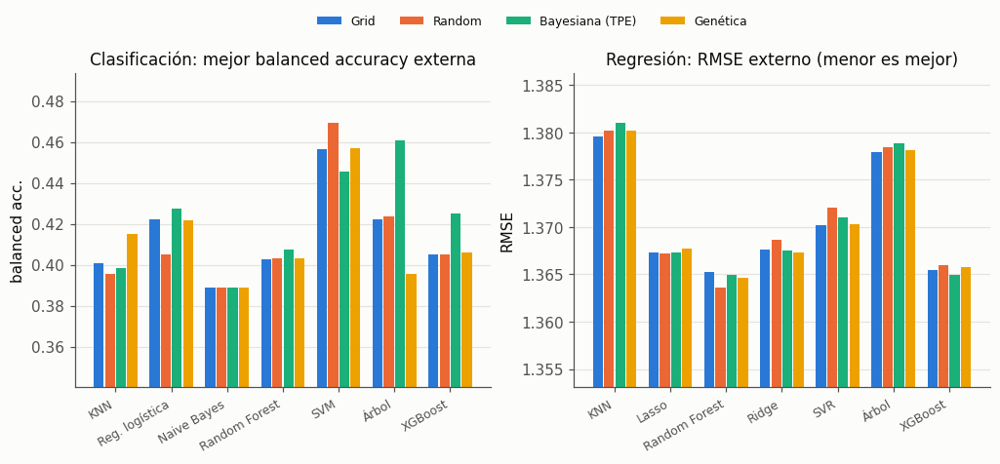

In [3]:
pv = mc.pivot_table(index='model', columns='optimizer', values='outer_recall_mean', aggfunc='max').reindex(columns=OPTS)
pv.index = [M.PRETTY[i] for i in pv.index]
pr = mr.pivot_table(index='model', columns='optimizer', values='outer_rmse_mean', aggfunc='min').reindex(columns=OPTS)
pr.index = [M.PRETTY[i] for i in pr.index]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, tab, title, lab in [(axes[0], pv, 'Clasificación: mejor balanced accuracy externa', 'balanced acc.'),
                            (axes[1], pr, 'Regresión: RMSE externo (menor es mejor)', 'RMSE')]:
    x = np.arange(len(tab)); w = 0.2
    for j, o in enumerate(OPTS):
        ax.bar(x + (j - 1.5) * w, tab[o], width=w - 0.02, color=P.OPT_COLORS[o], label=M.PRETTY[o])
    ax.set_xticks(x, tab.index, rotation=30, ha='right', fontsize=8); ax.set_title(title); ax.set_ylabel(lab)
    lo = np.nanmin(tab.to_numpy()); hi = np.nanmax(tab.to_numpy()); ax.set_ylim(lo - (hi - lo) * 0.6, hi + (hi - lo) * 0.3)
    ax.grid(axis='x', visible=False)
axes[0].legend(ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(1.1, 1.22))
P.save(fig, 'e3_hpo_por_modelo'); plt.show()

**Interpretación.** Con el mismo presupuesto (16 configuraciones), los cuatro métodos llegan a modelos de calidad casi igual
en el bucle externo: la balanced accuracy media de sus 140 celdas va de 0,397 (genético) a 0,402
(bayesiano), y el RMSE de regresión difiere en la cuarta cifra decimal (1,3705 a 1,3709). Por modelo, las
diferencias grandes aparecen solo donde la métrica depende de Fallecimiento (árbol: 0,461 con TPE frente a
0,395 con el genético; SVM: 0,469 con Random frente a 0,445 con TPE), es decir, donde el ruido de esa clase
domina. En costo, la búsqueda bayesiana gastó un 17 % más de tiempo (14,1 frente a ~12 horas·núcleo en
clasificación) porque explora más las zonas caras del espacio (más árboles, más vecinos); en regresión el
genético fue el más barato. En total, la validación anidada consumió unas 51 horas·núcleo en clasificación
y 3,1 en regresión, con 8.960 y 2.240 configuraciones evaluadas (26.880 y 6.720 ajustes).

## 7.3 Convergencia: curvas de desempeño en cualquier momento (*anytime*)

Para cada celda se toma el mejor puntaje **interno** encontrado hasta la evaluación t. Para poder
promediar entre modelos con escalas distintas se normaliza dentro de cada (modelo, balanceo,
pliegue externo): 0 es el peor puntaje que obtuvo cualquier método y 1 el mejor. En Grid Search
la curva depende del orden en que se recorre la rejilla (aquí, el orden de `ParameterGrid`).

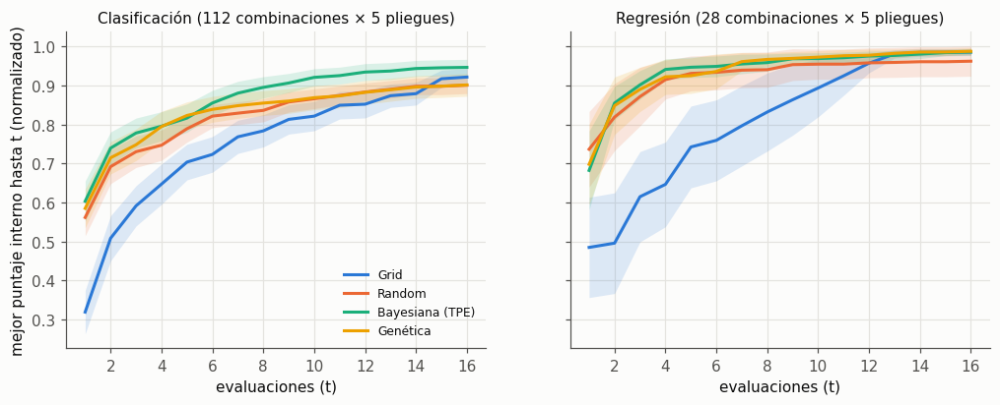

In [4]:
any_c, any_r = A.anytime_table('clf'), A.anytime_table('reg')
eff_c, full_c = A.budget_efficiency(any_c)
eff_r, full_r = A.budget_efficiency(any_r)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, full, title in [(axes[0], full_c, 'Clasificación (112 combinaciones × 5 pliegues)'),
                        (axes[1], full_r, 'Regresión (28 combinaciones × 5 pliegues)')]:
    for o in OPTS:
        x = full.xs(o, level='optimizer')
        m = x.mean(); se = x.std() / np.sqrt(len(x))
        ax.plot(m.index, m.values, color=P.OPT_COLORS[o], label=M.PRETTY[o])
        ax.fill_between(m.index, m - 1.96 * se, m + 1.96 * se, color=P.OPT_COLORS[o], alpha=0.15, lw=0)
    ax.set_xlabel('evaluaciones (t)'); ax.set_title(title, fontsize=10)
axes[0].set_ylabel('mejor puntaje interno hasta t (normalizado)')
axes[0].legend(fontsize=8, loc='lower right')
P.save(fig, 'e3_hpo_anytime'); plt.show()

In [5]:
print('Clasificación'); display(eff_c.reindex(OPTS).round(3))
print('Regresión'); display(eff_r.reindex(OPTS).round(3))

Clasificación


,celdas,AUC anytime (0-1),calidad con 4 evals,calidad con 8 evals,calidad con 12 evals,calidad con 16 evals,evals para 99 % del final (mediana)
optimizer,,,,,,,
grid,140,0.749,0.648,0.784,0.852,0.922,9.0
random,140,0.818,0.747,0.837,0.884,0.901,7.0
bayes,140,0.864,0.796,0.896,0.935,0.947,7.0
genetic,140,0.830,0.795,0.855,0.883,0.902,9.0


Regresión


,celdas,AUC anytime (0-1),calidad con 4 evals,calidad con 8 evals,calidad con 12 evals,calidad con 16 evals,evals para 99 % del final (mediana)
optimizer,,,,,,,
grid,35,0.810,0.647,0.832,0.958,0.986,9.0
random,35,0.922,0.915,0.941,0.958,0.963,6.0
bayes,35,0.938,0.941,0.959,0.976,0.986,7.0
genetic,35,0.937,0.923,0.967,0.978,0.988,8.0


## 7.4 Evidencia cuantitativa: calidad por unidad de presupuesto

La comparación visual no basta. Para cada celda (modelo × balanceo × pliegue externo) se calcula
el área bajo la curva anytime normalizada (promedio de la curva en t = 1…16; 1 sería encontrar
el mejor puntaje en la primera evaluación). Las celdas son pareadas (mismos datos para los cuatro
métodos), así que se comparan con Friedman y luego con Wilcoxon de rangos con signo por pares,
con corrección de Holm. También se compara la calidad alcanzada **a mitad de presupuesto
(t = 8)** y el puntaje externo final.

In [6]:
from osha_e3 import stats_tests as T
def budget_tests(full, f, metric, higher):
    auc = A.paired_auc(full)[OPTS]
    half = full[8].unstack('optimizer')[OPTS].dropna()
    fr_auc = T.friedman(auc.to_numpy())
    outer = f.pivot_table(index=['model', 'balance', 'fold'], columns='optimizer', values=f'outer_{metric}')[OPTS].dropna()
    rows = []
    for a, b in [('bayes', 'grid'), ('bayes', 'random'), ('genetic', 'grid'), ('genetic', 'random'), ('bayes', 'genetic'), ('random', 'grid')]:
        for label, tab, sign in [('AUC anytime', auc, 1), ('calidad en t=8', half, 1), (f'{metric} externo', outer, 1 if higher else -1)]:
            d = (tab[a] - tab[b]) * sign
            p = stats.wilcoxon(tab[a], tab[b]).pvalue if (d != 0).any() else 1.0
            rows.append({'comparación': f'{M.PRETTY[a]} vs {M.PRETTY[b]}', 'medida': label, 'diferencia media (a − b, + = a mejor)': d.mean(),
                         'a gana en (% celdas)': (d > 0).mean() * 100, 'p Wilcoxon': p,
                         'delta de Cliff': T.cliffs_delta(tab[a] * sign, tab[b] * sign)})
    out = pd.DataFrame(rows)
    for m_ in out['medida'].unique():
        idx = out['medida'] == m_
        out.loc[idx, 'p ajustado (Holm)'] = T.adjust(out.loc[idx, 'p Wilcoxon'].to_numpy())
    return fr_auc, out
fr_c, bt_c = budget_tests(full_c, fc, 'recall', True)
fr_r, bt_r = budget_tests(full_r, fr, 'rmse', False)
print(f"Friedman sobre el AUC anytime — clasificación: chi2 = {fr_c['chi2']:.1f}, p = {fr_c['p_value']:.2g}; "
      f"rangos {dict(zip(OPTS, np.round(fr_c['avg_ranks'], 2)))}")
print(f"Friedman sobre el AUC anytime — regresión: chi2 = {fr_r['chi2']:.1f}, p = {fr_r['p_value']:.2g}; "
      f"rangos {dict(zip(OPTS, np.round(fr_r['avg_ranks'], 2)))}")
bt_c.round(4)

Friedman sobre el AUC anytime — clasificación: chi2 = 50.4, p = 6.5e-11; rangos {'grid': 3.13, 'random': 2.49, 'bayes': 2.11, 'genetic': 2.28}
Friedman sobre el AUC anytime — regresión: chi2 = 24.4, p = 2.1e-05; rangos {'grid': 3.43, 'random': 2.11, 'bayes': 2.26, 'genetic': 2.2}


,comparación,medida,"diferencia media (a − b, + = a mejor)",a gana en (% celdas),p Wilcoxon,delta de Cliff,p ajustado (Holm)
0,Bayesiana (TPE) vs Grid,AUC anytime,0.1156,72.1429,0.0000,0.3876,0.0000
1,Bayesiana (TPE) vs Grid,calidad en t=8,0.1115,63.5714,0.0000,0.2778,0.0000
2,Bayesiana (TPE) vs Grid,recall externo,0.0033,56.4286,0.0616,0.0441,0.3081
3,Bayesiana (TPE) vs Random,AUC anytime,0.0467,66.4286,0.0000,0.2232,0.0001
4,Bayesiana (TPE) vs Random,calidad en t=8,0.0590,67.8571,0.0000,0.2689,0.0000
5,Bayesiana (TPE) vs Random,recall externo,0.0048,56.4286,0.0178,0.0607,0.1069
6,Genética vs Grid,AUC anytime,0.0815,68.5714,0.0000,0.2864,0.0000
7,Genética vs Grid,calidad en t=8,0.0712,60.0000,0.0002,0.1437,0.0009
8,Genética vs Grid,recall externo,-0.0022,55.0000,0.6230,-0.0080,1.0000
9,Genética vs Random,AUC anytime,0.0126,53.5714,0.1163,0.1243,0.2326


In [7]:
bt_r.round(4)

,comparación,medida,"diferencia media (a − b, + = a mejor)",a gana en (% celdas),p Wilcoxon,delta de Cliff,p ajustado (Holm)
0,Bayesiana (TPE) vs Grid,AUC anytime,0.1284,82.8571,0.0000,0.3959,0.0000
1,Bayesiana (TPE) vs Grid,calidad en t=8,0.1266,68.5714,0.0038,0.2310,0.0228
2,Bayesiana (TPE) vs Grid,rmse externo,-0.0003,51.4286,0.4510,-0.0106,1.0000
3,Bayesiana (TPE) vs Random,AUC anytime,0.0157,42.8571,0.8020,-0.0931,1.0000
4,Bayesiana (TPE) vs Random,calidad en t=8,0.0181,60.0000,0.5436,0.0008,1.0000
5,Bayesiana (TPE) vs Random,rmse externo,0.0001,51.4286,0.9806,0.0302,1.0000
6,Genética vs Grid,AUC anytime,0.1273,80.0000,0.0000,0.4351,0.0000
7,Genética vs Grid,calidad en t=8,0.1349,68.5714,0.0045,0.2457,0.0228
8,Genética vs Grid,rmse externo,-0.0001,51.4286,0.7158,-0.0024,1.0000
9,Genética vs Random,AUC anytime,0.0147,48.5714,0.9035,-0.0759,1.0000


**Interpretación.** **Evidencia cuantitativa de eficiencia.** Las pruebas pareadas sobre las 140 celdas de clasificación
confirman lo que muestran las curvas:

- **Friedman** sobre el área bajo la curva *anytime* rechaza que los cuatro métodos sean equivalentes
  (clasificación χ² = 50,4, p = 6,5·10⁻¹¹; regresión χ² = 24,4, p = 2,1·10⁻⁵). Rangos promedio en
  clasificación: bayesiano 2,11 (mejor), genético 2,28, Random 2,49, Grid 3,13.
- **Bayesiano frente a Grid:** +0,116 de área *anytime* (gana en el 72 % de las celdas, Holm p < 0,001,
  δ de Cliff 0,39, mediano) y +0,112 de calidad con la mitad del presupuesto (t = 8).
- **Bayesiano frente a Random:** +0,047 de área (gana en el 66 %, Holm p < 0,001, δ = 0,22, pequeño) y
  +0,059 en t = 8. El TPE alcanza con 8 evaluaciones (0,896) más de lo que Random alcanza con 16 (0,901 en
  la escala normalizada, prácticamente igual) y el 99 % de su valor final en una mediana de 7.
- **Genético frente a Grid:** +0,082 de área (Holm p < 0,001, δ = 0,29). **Genético frente a Random:**
  +0,013, no significativo tras Holm (p = 0,23).
- En regresión el patrón se repite frente a Grid (bayesiano y genético +0,13, δ ≈ 0,40 a 0,44, Holm
  p < 0,001), pero bayesiano, genético y Random quedan empatados (el espacio de Ridge, Lasso y SVR tiene 1 o
  2 dimensiones y cualquier método lo cubre).

**Pero esa eficiencia no se traduce en mejores modelos finales.** En la métrica externa ninguna
diferencia entre métodos es significativa tras Holm (la mayor, bayesiano frente a Random, +0,005 de
balanced accuracy, p crudo 0,018 y ajustado 0,11; δ de Cliff 0,06, despreciable). La explicación es que
el paisaje es plano: muchas configuraciones distintas dan casi el mismo desempeño, así que el método que
encuentra antes la cima solo ahorra presupuesto. La ventaja práctica del bayesiano y del genético es esa:
**llegan al mismo nivel con la mitad de evaluaciones**. Grid es el peor porque su rejilla de 16 puntos
prueba solo 2 valores de cada hiperparámetro en los modelos con 4 o más (XGBoost, Random Forest).

## 7.5 Tiempo de reloj

El presupuesto se fijó en evaluaciones, no en tiempo. El costo por evaluación depende de la
configuración elegida (más árboles o más vecinos cuestan más), así que los métodos que exploran
zonas caras gastan más reloj con el mismo número de evaluaciones.

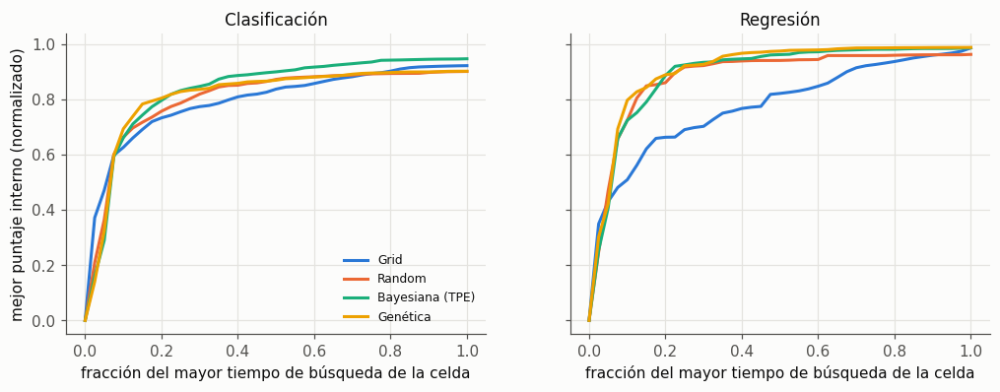

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, anyt, title in [(axes[0], any_c, 'Clasificación'), (axes[1], any_r, 'Regresión')]:
    d = anyt.dropna(subset=['best_norm']).copy()
    d['frac_time'] = d.cum_seconds / d.groupby(['model', 'balance', 'fold']).cum_seconds.transform('max')
    grid_t = np.linspace(0, 1, 41)
    for o in OPTS:
        curves = []
        for _, x in d[d.optimizer == o].groupby(['model', 'balance', 'fold']):
            curves.append(np.interp(grid_t, x.frac_time, x.best_norm, left=0))
        ax.plot(grid_t, np.mean(curves, axis=0), color=P.OPT_COLORS[o], label=M.PRETTY[o])
    ax.set_xlabel('fracción del mayor tiempo de búsqueda de la celda'); ax.set_title(title)
axes[0].set_ylabel('mejor puntaje interno (normalizado)'); axes[0].legend(fontsize=8, loc='lower right')
P.save(fig, 'e3_hpo_anytime_tiempo'); plt.show()

**Interpretación.** En tiempo de reloj el orden se mantiene: el bayesiano alcanza antes su nivel aun gastando más por
evaluación, y Grid sigue siendo el más lento en mejorar. Como el presupuesto se fijó en evaluaciones, un
método que elige configuraciones caras (como hace TPE al explorar muchos árboles) consume más reloj; aun
así su curva queda por encima en casi todo el rango.

## 7.6 Optuna: historia de una búsqueda y superficie explorada

Historia de la búsqueda bayesiana de XGBoost (sin balanceo, pliegue externo 1) y todas las
configuraciones de XGBoost evaluadas por los cuatro métodos en ese pliegue, en el plano
learning rate × profundidad (color = balanced accuracy interna).

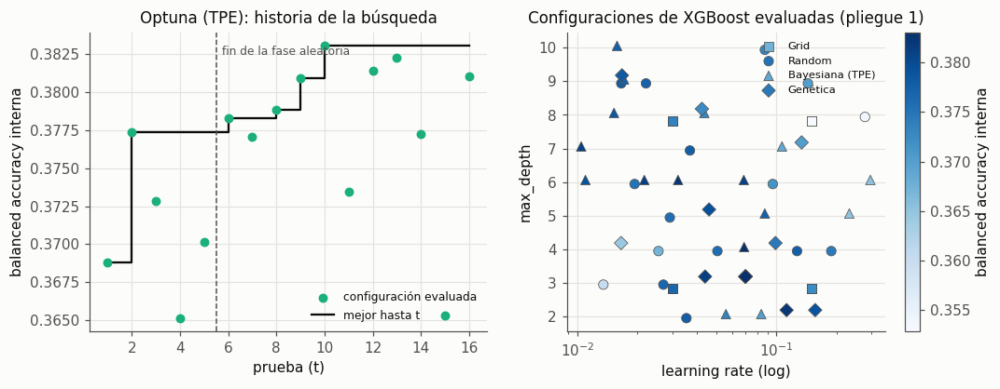

In [9]:
cells = {(r['optimizer']): r for r in N.load_cells('clf') if r['model'] == 'xgboost' and r['balance'] == 'none' and r['fold'] == 0}
h = pd.DataFrame(cells['bayes']['history'])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(h['eval'], h.score, color=P.OPT_COLORS['bayes'], s=30, zorder=3, label='configuración evaluada')
axes[0].step(h['eval'], h.score.cummax(), where='post', color=P.INK, lw=1.5, label='mejor hasta t')
axes[0].axvline(5.5, color=P.INK2, ls='--', lw=1); axes[0].text(5.6, h.score.max(), ' fin de la fase aleatoria', fontsize=8, color=P.INK2, va='top')
axes[0].set_xlabel('prueba (t)'); axes[0].set_ylabel('balanced accuracy interna'); axes[0].set_title('Optuna (TPE): historia de la búsqueda')
axes[0].legend(fontsize=8, loc='lower right')
markers = {'grid': 's', 'random': 'o', 'bayes': '^', 'genetic': 'D'}
allh = pd.concat([pd.DataFrame(c['history']).assign(optimizer=o) for o, c in cells.items()])
allh['lr'] = allh.params.map(lambda p: p['learning_rate']); allh['depth'] = allh.params.map(lambda p: p['max_depth'])
sc = None
for o in OPTS:
    x = allh[allh.optimizer == o]
    sc = axes[1].scatter(x.lr, x.depth + (OPTS.index(o) - 1.5) * 0.12, c=x.score, cmap='Blues', vmin=allh.score.min(), vmax=allh.score.max(),
                         marker=markers[o], s=45, edgecolor=P.INK2, linewidth=0.5, label=M.PRETTY[o])
axes[1].set_xscale('log'); axes[1].set_xlabel('learning rate (log)'); axes[1].set_ylabel('max_depth')
axes[1].set_title('Configuraciones de XGBoost evaluadas (pliegue 1)'); axes[1].legend(fontsize=7.5, loc='upper right')
plt.colorbar(sc, ax=axes[1], label='balanced accuracy interna')
P.save(fig, 'e3_hpo_optuna'); plt.show()

**Interpretación.** **Historia:** las 5 primeras pruebas son aleatorias (fase de exploración); desde la sexta el TPE propone
configuraciones guiadas por el cociente l(x)/g(x) y la mejor balanced accuracy interna sube de 0,377 a
0,383 en la prueba 10. Después siguen apareciendo configuraciones peores (pruebas 11, 14 y 15): el
muestreo desde l(x) mantiene algo de exploración, como se espera de la mejora esperada. **Superficie:** en
el plano learning rate × profundidad, la rejilla solo prueba 4 combinaciones (2 × 2); Random reparte puntos
por todo el plano; TPE y el genético se concentran en learning rates de 0,01 a 0,1 y profundidades
variadas, donde están los puntos más oscuros (mejor puntaje). Los mejores puntajes aparecen en zonas muy
distintas del plano con valores casi iguales (0,375 a 0,383): es el paisaje plano que explica por qué los
cuatro métodos terminan en modelos equivalentes.

## 7.7 Algoritmo genético: diversidad de la población

Diversidad = distancia euclidiana media entre pares de individuos en el espacio de genes,
dividida por √d (0 = todos iguales, ~0,4 = población uniforme al azar). Una caída rápida a cero
indicaría convergencia prematura.

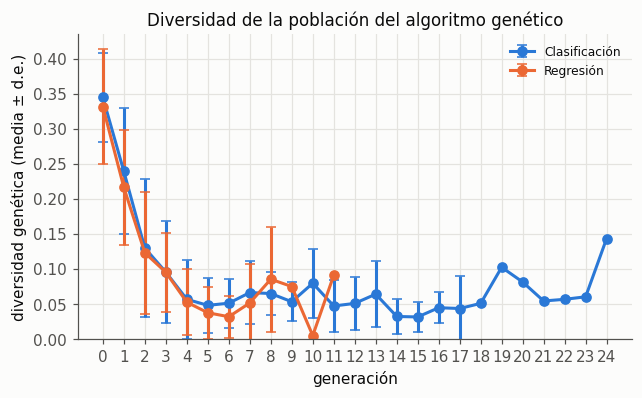

,tarea,generation,diversidad,sd,n,evals
0,Clasificación,0,0.345,0.063,140,6.000
1,Clasificación,1,0.239,0.090,140,8.714
2,Clasificación,2,0.130,0.099,140,10.957
3,Clasificación,3,0.096,0.073,140,12.857
4,Clasificación,4,0.057,0.056,104,13.260
5,Clasificación,5,0.048,0.039,73,13.301
6,Clasificación,6,0.051,0.035,49,12.633
7,Clasificación,7,0.066,0.045,44,13.477
8,Clasificación,8,0.065,0.031,37,13.784
9,Clasificación,9,0.053,0.028,30,14.233


In [10]:
gd = pd.concat([A.ga_diversity('clf').assign(tarea='Clasificación'), A.ga_diversity('reg').assign(tarea='Regresión')])
gsum = gd.groupby(['tarea', 'generation']).agg(diversidad=('diversity', 'mean'), sd=('diversity', 'std'),
                                                 n=('diversity', 'size'), evals=('evals', 'mean')).reset_index()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for i, (t, x) in enumerate(gsum.groupby('tarea')):
    ax.errorbar(x.generation, x.diversidad, yerr=x.sd, marker='o', ms=6, capsize=3, color=P.SERIES[i], label=t)
ax.set_xlabel('generación'); ax.set_ylabel('diversidad genética (media ± d.e.)')
ax.set_title('Diversidad de la población del algoritmo genético'); ax.legend(fontsize=8); ax.set_ylim(0, None)
ax.set_xticks(sorted(gsum.generation.unique()))
P.save(fig, 'e3_hpo_ga_diversidad'); plt.show()
gsum.round(3)

**Interpretación.** La diversidad empieza en 0,35 (población aleatoria) y cae rápido: 0,24 en la generación 1, 0,13 en la 2
y 0,10 en la 3, para estabilizarse en torno a 0,05. Es decir, en 3 generaciones la población se concentra
en una región del espacio. Con 6 individuos y elitismo es una convergencia **rápida, casi prematura**, y
explica por qué el genético mejora tan poco después de la evaluación 8 (curva *anytime* casi plana). Las
generaciones posteriores a la 4 aparecen en pocas búsquedas: cuando la población converge, muchos hijos
repiten configuraciones ya evaluadas, que no consumen presupuesto, y la búsqueda necesita más generaciones
para agotar las 16 evaluaciones. Una población mayor o una mutación más fuerte mantendría más diversidad,
pero con 16 evaluaciones sería prácticamente una búsqueda aleatoria; es el compromiso de usar un genético
con poco presupuesto.

## 7.8 Sesgo de selección: puntaje interno frente a externo

El mejor puntaje interno es el máximo de 16 estimaciones ruidosas, así que tiende a ser
optimista. La validación anidada existe para no reportarlo. La diferencia interno − externo mide
cuánto se habría sobreestimado el desempeño.

In [11]:
sb_c = A.selection_bias('clf', 'recall'); sb_r = A.selection_bias('reg', 'rmse')
tab = pd.DataFrame({
    'Clasificación: interno − externo (balanced acc.)': sb_c.groupby('optimizer').optimismo.mean(),
    'Regresión: externo − interno (RMSE)': sb_r.groupby('optimizer').optimismo.mean(),
}).reindex(OPTS)
print('Media global clasificación:', round(sb_c.optimismo.mean(), 4), '| % de celdas con interno > externo:', round((sb_c.optimismo > 0).mean() * 100, 1))
print('Media global regresión:', round(sb_r.optimismo.mean(), 4), '| % de celdas con RMSE externo > interno:', round((sb_r.optimismo > 0).mean() * 100, 1))
tab.round(4)

Media global clasificación: -0.0022 | % de celdas con interno > externo: 58.0
Media global regresión: -0.0012 | % de celdas con RMSE externo > interno: 22.9


,Clasificación: interno − externo (balanced acc.),Regresión: externo − interno (RMSE)
optimizer,,
grid,-0.0019,-0.0013
random,-0.0020,-0.0014
bayes,-0.0036,-0.0007
genetic,-0.0012,-0.0014


**Interpretación.** Sorprende que el optimismo medio sea ligeramente **negativo** (−0,002 en clasificación): el puntaje externo
es, en promedio, algo mejor que el interno. Hay dos efectos opuestos. El sesgo de selección (elegir el
máximo de 16 estimaciones ruidosas) empuja el interno hacia arriba, y por eso en el 58 % de las celdas el
interno supera al externo. Pero el modelo final se reajusta con todo el entrenamiento externo (unas 24.000
filas), un 50 % más de datos que cada entrenamiento interno (unas 16.000), y eso mejora el externo. Con este
presupuesto pequeño y un paisaje plano, el sesgo de selección es pequeño y el efecto del tamaño lo
compensa. La validación anidada no cambia mucho las cifras en este problema, pero es la única forma de
saberlo; la desviación entre pliegues (±0,06 a ±0,10) es mucho mayor que ese optimismo.

## 7.9 Optimización multi-fidelidad: Successive Halving

Se compara, en el pliegue externo 1 y para XGBoost sin balanceo, una búsqueda aleatoria de 27
configuraciones evaluadas con presupuesto completo (400 árboles) contra **Successive Halving**
(`HalvingRandomSearchCV`) con las mismas 27 configuraciones iniciales:

- **Fidelidad = número de árboles.** Es el recurso natural del boosting: los primeros árboles
  ya ordenan bien las configuraciones (un learning rate o una profundidad malos se notan pronto) y
  el costo crece linealmente con él.
- **Factor de reducción η = 3.** En cada ronda sobrevive el mejor tercio y recibe el triple de
  árboles: 27 configuraciones con ~15 árboles → 9 con ~44 → 3 con ~133 → 1 con 400. Con η = 3 hay
  4 rondas, un equilibrio entre descartar demasiado pronto (η grande) y gastar mucho en las malas
  (η pequeño).

In [12]:
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingRandomSearchCV, RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier
import time
def run_halving():
    X, y, g, s = N.task_data('clf')
    tr, te = N.outer_folds('clf')[0]
    folds = N.inner_folds('clf', tr, 0)
    Xtr, ytr = X.iloc[tr].reset_index(drop=True), y[tr]
    pipe = Pipeline([('onehot', M.make_encoder()),
                     ('model', XGBClassifier(n_estimators=400, tree_method='hist', n_jobs=1, random_state=C.SEED, verbosity=0))])
    dist = {'model__max_depth': randint(2, 11), 'model__learning_rate': loguniform(0.01, 0.3),
            'model__subsample': uniform(0.6, 0.4), 'model__colsample_bytree': uniform(0.4, 0.6),
            'model__min_child_weight': loguniform(1, 20)}
    out = {}
    for name, search in [
        ('Random (27 × 400 árboles)', RandomizedSearchCV(pipe, dist, n_iter=27, cv=folds, scoring='balanced_accuracy',
                                                       random_state=C.SEED, n_jobs=11, refit=True)),
        ('Successive Halving (η = 3)', HalvingRandomSearchCV(pipe, dist, n_candidates=27, factor=3, resource='model__n_estimators',
                                                           min_resources=15, max_resources=400, cv=folds, scoring='balanced_accuracy',
                                                           random_state=C.SEED, n_jobs=11, refit=True))]:
        t0 = time.perf_counter(); search.fit(Xtr, ytr); sec = time.perf_counter() - t0
        res = pd.DataFrame(search.cv_results_)
        trees = res['param_model__n_estimators'].astype(float) if 'param_model__n_estimators' in res else pd.Series(400.0, index=res.index)
        out[name] = {'segundos (reloj, 11 procesos)': sec, 'árboles ajustados (suma × 3 pliegues)': float(trees.sum() * 3),
                     'configuraciones evaluadas': len(res), 'mejor interno': search.best_score_,
                     'balanced acc. externa': S.score_predictions('clf', y[te], search.best_estimator_, X.iloc[te]),
                     'rondas': int(getattr(search, 'n_iterations_', 1))}
    return pd.DataFrame(out).T
halv = cache.cached('hpo_halving', run_halving)
halv

,"segundos (reloj, 11 procesos)",árboles ajustados (suma × 3 pliegues),configuraciones evaluadas,mejor interno,balanced acc. externa,rondas
Random (27 × 400 árboles),95.011718,32400.0,27.0,0.38202,0.362341,1.0
Successive Halving (η = 3),23.890466,3645.0,39.0,0.38289,0.358669,3.0


**Interpretación.** Successive Halving (η = 3) evaluó 39 configuraciones en 3 rondas (27 con 15 árboles, 9 con 45, 3 con 135)
ajustando en total 3.645 árboles, frente a los 32.400 de la búsqueda aleatoria con presupuesto completo:
**8,9 veces menos árboles y 4 veces menos tiempo de reloj** (24 frente a 95 segundos con 11 procesos). Su
mejor puntaje interno fue igual (0,383 frente a 0,382) y la balanced accuracy externa, prácticamente igual
(0,359 frente a 0,362; diferencia menor que la variación entre pliegues). La fidelidad elegida, el número de
árboles, funciona porque las configuraciones malas (learning rate muy bajo, árboles muy poco profundos) ya se
notan con pocos árboles. Con un paisaje tan plano como este, la multi-fidelidad es la mejora de eficiencia
más grande de todo el capítulo.

# 8. Optimización computacional

Con 140 combinaciones × 5 pliegues externos × 16 configuraciones × 3 pliegues internos, el
proyecto hace unos 34.000 ajustes. Este capítulo mide el costo de cada modelo, lo contrasta con su
complejidad teórica y muestra las optimizaciones que hicieron viable la corrida.

Todos los tiempos son de reloj (`time.perf_counter`), promediados en 2 o 3 repeticiones cuando el
costo lo permite, en un portátil con 12 hilos lógicos y una GPU NVIDIA RTX 3050 (6 GB). La memoria
es el pico de asignaciones de Python medido con `tracemalloc` (no incluye la memoria interna de
bibliotecas en C++ como XGBoost o FAISS, que se subestima).

In [1]:
import sys, warnings, time
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier
from osha_e3 import config as C, data as D, models as M, complexity as X, plots as P, cache, search as S, nested as N
P.setup()
C.set_global_seed()
sub, dev, test = D.classification_sets()
rng = np.random.default_rng(C.SEED)
dev = dev.sample(frac=1, random_state=C.SEED).reset_index(drop=True)
Xall, = X.encode(dev[D.FEATURES])
yall = dev.y_clf.to_numpy() - 1
te_idx = rng.choice(len(test), 10_000, replace=False)
Xte = M.make_encoder().fit(dev[D.FEATURES]).transform(test[D.FEATURES].iloc[te_idx])
yte = test.y_clf.to_numpy()[te_idx] - 1
print('Desarrollo codificado:', Xall.shape, '| prueba (muestra para tiempos):', Xte.shape)

Desarrollo codificado: (269516, 293) | prueba (muestra para tiempos): (10000, 293)


## 8.1 Complejidad teórica

n = observaciones, p = columnas (≈ 210 después del one-hot), K = clases, T = árboles.

In [2]:
X.THEORY

,Modelo,Entrenamiento,Inferencia
0,KNN (fuerza bruta),O(1) (guarda los datos),O(n·p) por consulta
1,KNN (KD-Tree / Ball Tree),O(p·n log n),O(log n) por consulta en p bajo; → O(n·p) en p...
2,KNN aproximado (FAISS IVF),O(n·p·iter) (k-means de centroides),O((n/nlist)·nprobe·p) por consulta
3,Naive Bayes (fit / partial_fit),O(n·p),O(K·p) por consulta
4,Regresión logística (SAGA),O(n·p) por época,O(K·p)
5,"Ridge / Lasso (SAGA, CD)",O(n·p) por época / iteración,O(p)
6,Árbol de decisión,O(p·n log n),O(profundidad)
7,Random Forest,"O(T·m·n log n), m = max_features·p",O(T·profundidad)
8,XGBoost exacto,O(T·p·n log n),O(T·profundidad)
9,XGBoost hist,O(T·p·n) + O(T·p·bins),O(T·profundidad)


## 8.2 Escalamiento empírico al variar n

Se entrena cada modelo con n = 2.000 a 64.000 casos (mismos hiperparámetros, un hilo) y se
ajusta una recta a log(tiempo) contra log(n). La pendiente es el **exponente empírico**: 1 indica
costo lineal y 2, cuadrático. Para KNN se mide la *predicción* de 2.000 casos, porque su
entrenamiento solo guarda los datos.

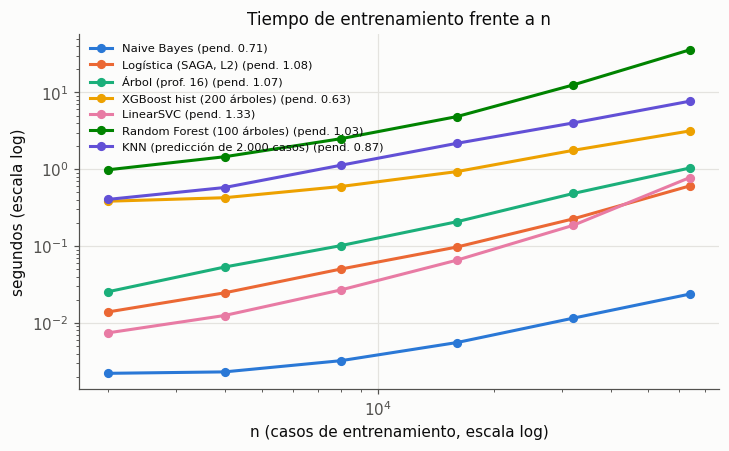

,exponente empírico
modelo,
KNN (predicción de 2.000 casos),0.87
LinearSVC,1.33
"Logística (SAGA, L2)",1.08
Naive Bayes,0.71
Random Forest (100 árboles),1.03
XGBoost hist (200 árboles),0.63
Árbol (prof. 16),1.07


In [3]:
ns = [2000, 4000, 8000, 16000, 32000, 64000]
specs = {
    'Naive Bayes': lambda: BernoulliNB(),
    'Logística (SAGA, L2)': lambda: LogisticRegression(C=0.1, solver='saga', max_iter=300, tol=1e-3),
    'Árbol (prof. 16)': lambda: DecisionTreeClassifier(max_depth=16, min_samples_leaf=10, random_state=0),
    'Random Forest (100 árboles)': lambda: RandomForestClassifier(100, max_depth=20, max_features=0.1, n_jobs=1, random_state=0),
    'XGBoost hist (200 árboles)': lambda: XGBClassifier(n_estimators=200, max_depth=6, tree_method='hist', n_jobs=1, verbosity=0),
    'LinearSVC': lambda: LinearSVC(C=0.1, dual=True, max_iter=3000, tol=1e-3),
}
# Para medir tiempos se usan las 3 clases frecuentes: con n = 2.000 no aparece ningún fallecimiento
# y XGBoost exige que estén todas las clases.
keep3 = yall > 0
X3, y3 = Xall[keep3], yall[keep3] - 1
def run_scaling():
    with threadpool_limits(1):
        out = X.scaling_curves(X3, y3, ns, {k: v for k, v in specs.items() if 'Random' not in k}, repeats=2)
        rf = X.scaling_curves(X3[:max(ns)].toarray(), y3, ns, {k: v for k, v in specs.items() if 'Random' in k}, repeats=1)
        knn_rows = []
        for n in ns:
            knn = KNeighborsClassifier(31, algorithm='brute', n_jobs=1).fit(X3[:n], y3[:n])
            t, sd, mem, _ = X.timed(lambda: knn.predict(Xte[:2000]), 2)
            knn_rows.append({'modelo': 'KNN (predicción de 2.000 casos)', 'n': n, 'fit_s': t, 'fit_sd': sd, 'mem_mb': mem})
    return pd.concat([out, rf, pd.DataFrame(knn_rows)], ignore_index=True)
scal = cache.cached('complexity_scaling', run_scaling)
expo = scal.groupby('modelo').apply(lambda d: X.scaling_exponent(d.n, d.fit_s)).rename('exponente empírico')
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for i, (m, d) in enumerate(scal.groupby('modelo', sort=False)):
    ax.plot(d.n, d.fit_s, marker='o', ms=5, color=P.SERIES[i], label=f'{m} (pend. {expo[m]:.2f})')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('n (casos de entrenamiento, escala log)'); ax.set_ylabel('segundos (escala log)')
ax.set_title('Tiempo de entrenamiento frente a n')
ax.legend(fontsize=7.5, loc='upper left')
P.save(fig, 'e3_comp_escalamiento'); plt.show()
expo.round(2).to_frame()

**Interpretación.** La teoría predice pendiente ≈ 1 para todos estos modelos (lineales en n, salvo
el factor log n de los árboles). Lo medido:

- **Logística (1,08), árbol (1,07) y Random Forest (1,03):** coinciden con la teoría; el factor
  log n del ordenamiento apenas se nota en este rango.
- **KNN (0,87):** la predicción por fuerza bruta es lineal en n por consulta; la pendiente algo menor
  que 1 se debe a costos fijos por consulta que pesan más con n pequeño.
- **LinearSVC (1,33):** algo superlineal: con más datos el solver dual necesita más iteraciones para
  converger (el costo por época es lineal, pero el número de épocas crece).
- **Naive Bayes (0,71) y XGBoost hist (0,63):** sublineales en este rango porque dominan costos fijos
  (crear los histogramas y los árboles en XGBoost, la validación de entrada en Naive Bayes); con n
  mucho mayor la pendiente tendería a 1.

En conjunto, ningún modelo de los usados muestra el comportamiento cuadrático que impediría la
corrida; el cuadrático es el SVM con núcleo (sección 8.7).

## 8.3 KNN: fuerza bruta, árboles de búsqueda y vecinos aproximados (FAISS)

KD-Tree y Ball Tree solo aceleran en dimensión baja; con 210 columnas binarias degeneran a
fuerza bruta. Para compararlos de forma justa se proyecta a 10 componentes con SVD truncada.
FAISS `IndexIVFFlat` agrupa los puntos en `nlist` celdas (k-means) y busca solo en las `nprobe`
celdas más cercanas: es aproximado. Se mide qué fracción de los 31 vecinos exactos recupera.

In [4]:
def run_knn():
    with threadpool_limits(1):
        return X.knn_benchmark(Xall[:30000], yall[:30000], Xte[:5000], yte[:5000], k=31, dims=10)
knn = cache.cached('complexity_knn', run_knn)
knn.round(4)

,método,fit_s,predict_s,mem_mb,balanced_accuracy,recall_vecinos
0,"fuerza bruta (one-hot, p=293)",0.0057,8.9943,2.4065,0.3707,NaN
1,"fuerza bruta (SVD, p=10)",0.0034,0.8334,1.1273,0.3530,NaN
2,"KD-Tree (SVD, p=10)",0.0559,0.5414,2.9394,0.3536,NaN
3,"Ball Tree (SVD, p=10)",0.0368,1.1502,2.8613,0.3533,NaN
4,"FAISS IVF (nlist=64, nprobe=1)",0.0372,0.0574,0.0042,0.3535,0.9697
5,"FAISS IVF (nlist=64, nprobe=8)",0.0112,0.1950,0.0005,0.3534,0.9973


**Interpretación.** Con las 293 columnas one-hot, la fuerza bruta tarda 9,0 s en predecir 5.000 casos.
Proyectando a 10 dimensiones baja a 0,83 s. En dimensión baja, KD-Tree (0,54 s) ya mejora a la fuerza
bruta y Ball Tree (1,15 s) no, porque con 30.000 puntos y p = 10 el árbol todavía poda poco. FAISS IVF
es el más rápido: 0,06 s con `nprobe = 1` (recupera el 97 % de los 31 vecinos exactos) y 0,20 s con
`nprobe = 8` (99,7 %). Es entre 4 y 14 veces más rápido que la fuerza bruta en el mismo espacio, y 46
veces más rápido que la fuerza bruta en el one-hot, **sin pérdida de balanced accuracy** (0,353 frente
a 0,353). El compromiso exactitud-velocidad de la aproximación aquí es casi gratis: un 3 % de vecinos
distintos no cambia el voto. Lo que sí cuesta es la proyección SVD (0,371 → 0,353): con 10 componentes
se pierde información de las categorías. Por eso la corrida usó fuerza bruta en el one-hot. FAISS sería
la opción para predecir los 127.391 casos de la prueba con KNN.

## 8.4 Ridge y Lasso: solvers

Ridge con Cholesky resuelve un sistema p × p (O(n·p² + p³)); SAGA y los gradientes conjugados tienen
costo por época lineal en n y p. (En scikit-learn 1.3, SAGA no ajusta intercepto con matrices
dispersas, así que se le pasa la matriz densa; los gradientes conjugados sí usan la dispersa.)
Para Lasso se compara el descenso por coordenadas con un gradiente estocástico con penalización
L1 (la familia de SAGA). Datos: objetivo de regresión, 20.000 casos de desarrollo.

In [5]:
rs, rdev, rtest = D.regression_sets()
enc_r = M.make_encoder().fit(rdev[D.FEATURES].iloc[:20000])
Ar, Br = enc_r.transform(rdev[D.FEATURES].iloc[:20000]), enc_r.transform(rtest[D.FEATURES])
lin = cache.cached('complexity_linear', lambda: X.linear_solvers(Ar, rdev.y_reg.to_numpy()[:20000], Br, rtest.y_reg.to_numpy()))
lin.round(4)

,método,fit_s,fit_sd,predict_s,mem_mb,rmse
0,"Ridge (cholesky, denso)",0.0416,0.0048,0.0068,17.4164,1.2100
1,Ridge (sparse_cg),0.0208,0.0054,0.0005,3.1484,1.2100
2,"Ridge (SAGA, denso)",0.6494,0.0285,0.0074,17.4156,1.2100
3,Lasso (coordinate descent),0.0862,0.0121,0.0005,2.1408,1.1882
4,Lasso (SAGA vía SGD L1),0.0439,0.0020,0.0008,0.3006,1.1878


**Interpretación.** Con p = 210 la teoría se invierte: Cholesky (O(n·p² + p³)) es muy barato porque
p³ ≈ 9·10⁶ es poco, y SAGA (0,65 s) es 15 veces más lento que Cholesky (0,04 s): necesita varias pasadas
por los datos para converger y se le debe pasar la matriz densa. El ganador es el gradiente conjugado
sobre la matriz **dispersa** (0,02 s y 3,1 MB frente a 17,4 MB), porque solo recorre los valores no nulos
(9 por fila). Los tres llegan al mismo RMSE (1,210). SAGA solo compensa cuando p es tan grande que el
p³ de Cholesky es prohibitivo o los datos no caben en memoria. En Lasso, el gradiente estocástico con
L1 es 2 veces más rápido que el descenso por coordenadas y da el mismo RMSE (1,188).

## 8.5 Naive Bayes: aprendizaje incremental con `partial_fit`

Se entrena con **todo** el desarrollo (269.516 casos) de dos maneras: cargando la matriz completa o
leyendo bloques de 20.000 casos con `partial_fit`. El segundo modo nunca necesita tener todo en
memoria; es la vía para datos que no caben.

In [6]:
nb = cache.cached('complexity_nb', lambda: X.naive_bayes_online(Xall, yall, Xte, yte))
nb.round(4)

,método,fit_s,mem_mb,balanced_accuracy
0,BernoulliNB.fit (todo en memoria),0.0936,50.6971,0.3918
1,"BernoulliNB.partial_fit (bloques de 20,000)",0.0838,4.9196,0.3918


**Interpretación.** `partial_fit` por bloques de 20.000 casos da exactamente el mismo modelo
(balanced accuracy 0,3918 en ambos: Naive Bayes solo suma conteos por clase) con la décima parte de memoria
pico (4,9 MB frente a 50,7 MB) y el mismo tiempo. Con todo el desarrollo (269.516 casos) la memoria no
es un problema, pero el método escala a archivos de cualquier tamaño leyéndolos por partes.

## 8.6 XGBoost: método exacto, histogramas, early stopping y GPU

100.000 casos de entrenamiento, 20.000 de validación (para early stopping) y la muestra de prueba.
`hist` discretiza cada variable en ≤ 256 intervalos y busca divisiones sobre los histogramas en vez
de ordenar todos los valores. Early stopping detiene el boosting cuando el log-loss de un conjunto de
validación independiente deja de mejorar 20 rondas seguidas (máximo 1.000 árboles); se compara con
1.000 árboles fijos.

In [7]:
def run_xgb():
    return X.xgboost_methods(Xall[:100000], yall[:100000], Xall[100000:120000], yall[100000:120000], Xte, yte, gpu=True)
xgbt = cache.cached('complexity_xgb', run_xgb)
xgbt.round(4)

,método,fit_s,fit_sd,predict_s,mem_mb,arboles,balanced_accuracy,log_loss_prueba
0,"exact (CPU, 12 hilos), 400 árboles",17.1777,0.1706,0.1387,4.1470,400,0.4009,0.9286
1,"hist (CPU, 12 hilos), 400 árboles",4.4237,0.0418,0.1367,4.1131,400,0.3995,0.9279
2,"hist (CPU), 1.000 árboles",11.2580,0.0075,0.4084,9.8747,1000,0.3963,0.9341
3,"hist + early stopping (CPU), hasta 1.000",125.6318,0.0000,0.3443,8.2164,802,0.3985,0.9306
4,"hist (GPU, cuda), 400 árboles",5.1332,0.1558,0.0500,4.0998,400,0.4024,0.9268


**Interpretación.**

- **`hist` frente a exacto:** 3,9 veces más rápido (4,4 s frente a 17,2 s con 400 árboles) con el mismo
  desempeño (balanced accuracy 0,400 frente a 0,401; log-loss 0,928 frente a 0,929). Con variables
  binarias, cada columna tiene solo 2 valores, así que el histograma no pierde nada.
- **Early stopping:** se detuvo en 802 árboles (de 1.000) y obtuvo un log-loss de prueba de 0,931, mejor
  que con 1.000 árboles fijos (0,934): evita el leve sobreajuste de las últimas rondas. Pero en tiempo
  costó 126 s frente a 11 s, porque en esta versión de XGBoost evaluar el conjunto de validación en cada
  ronda es caro. Además, el óptimo está en torno a 400–800 árboles con learning rate 0,1, así que aquí la
  parada temprana mejora poco: tiene sentido con presupuestos de árboles mucho mayores.
- **GPU (RTX 3050):** 5,1 s frente a 4,4 s en CPU con 12 hilos (aceleración de 0,86, es decir, más
  lenta) y el mismo desempeño. Con 100.000 filas y 210 columnas binarias, el costo de copiar los datos a la
  GPU y lanzar los núcleos no se amortiza; la GPU convendría con millones de filas o árboles más
  profundos. Por eso la corrida principal usó CPU.

## 8.7 SVM: núcleo RBF frente a LinearSVC y SGD

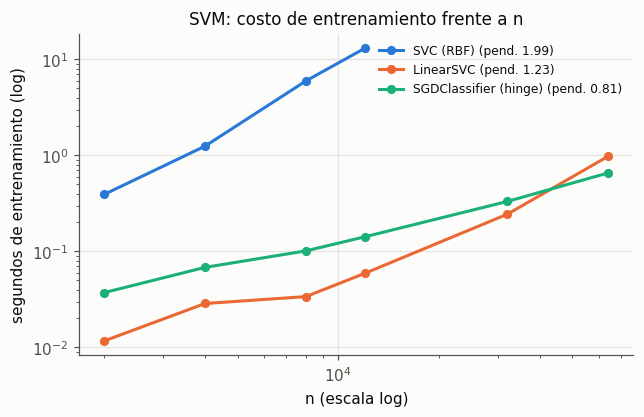

,método,n,fit_s,predict_s,mem_mb,balanced_accuracy
0,SVC (RBF),2000,0.3927,0.3327,1.4498,0.3683
1,LinearSVC,2000,0.0117,0.0010,0.4376,0.3682
2,SGDClassifier (hinge),2000,0.0372,0.0007,0.2231,0.3361
3,SVC (RBF),4000,1.2498,0.7027,2.8746,0.3799
4,LinearSVC,4000,0.0286,0.0011,0.8638,0.3680
5,SGDClassifier (hinge),4000,0.0681,0.0010,0.3796,0.3638
6,SVC (RBF),8000,5.9673,1.2927,5.7432,0.3893
7,LinearSVC,8000,0.0338,0.0006,1.7221,0.3840
8,SGDClassifier (hinge),8000,0.1011,0.0005,0.7364,0.3745
9,SVC (RBF),12000,13.0699,1.8151,8.6121,0.3896


In [8]:
def run_svm():
    with threadpool_limits(1):
        return X.svm_methods(Xall, yall, Xte[:3000], yte[:3000], [2000, 4000, 8000, 12000, 32000, 64000])
svm = cache.cached('complexity_svm', run_svm)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for i, (m, d) in enumerate(svm.groupby('método', sort=False)):
    ax.plot(d.n, d.fit_s, marker='o', ms=5, color=P.SERIES[i], label=f'{m} (pend. {X.scaling_exponent(d.n, d.fit_s):.2f})')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('n (escala log)'); ax.set_ylabel('segundos de entrenamiento (log)')
ax.set_title('SVM: costo de entrenamiento frente a n'); ax.legend(fontsize=8)
P.save(fig, 'e3_comp_svm'); plt.show()
svm.round(4)

**Interpretación.** El SVM con núcleo RBF tiene un exponente empírico cercano a 2 (pasar de 2.000 a
12.000 casos multiplica por 33 el tiempo: de 0,39 s a 13,1 s), coherente con su complejidad O(n²·p) a
O(n³). Extrapolando, con 24.000 casos (un entrenamiento externo) tardaría cerca de 1 minuto por ajuste, y
cada combinación necesita 245 ajustes; con el desarrollo completo (269.516) serían horas por ajuste.
`LinearSVC` y SGD crecen casi linealmente (LinearSVC: 0,06 s con 12.000 y 0,98 s con 64.000) y su
predicción es instantánea. En desempeño, el RBF es apenas mejor con el mismo n (0,390 frente a 0,389 con
12.000), y LinearSVC con 64.000 casos (0,400) supera al RBF con el máximo de 12.000 que es viable
entrenar: más datos con un modelo lineal valen más que el núcleo con pocos datos.

## 8.8 Paralelización con joblib

Tarea de referencia: ajustar una logística (SAGA) sobre 20.000 casos, 12 veces. Se compara la
ejecución en serie con 6 procesos (`loky`) y 6 hilos (`threading`). Los procesos evitan el GIL
de Python; los hilos solo escalan cuando el trabajo pesado libera el GIL (código en C/Cython).

La corrida principal (`nested.run_all`) usa `loky` con 11 procesos, un hilo de BLAS/OpenMP por
proceso (`threadpool_limits(1)`) para no sobresuscribir los 12 hilos, y reparte celdas
(combinación × pliegue externo) ordenadas de la más costosa a la más barata para equilibrar la
carga. Dask o Ray no se usaron: todo corre en una sola máquina y joblib ya satura sus núcleos;
serían útiles para repartir las 700 celdas entre varias máquinas.

In [9]:
Xj, yj = Xall[:20000], yall[:20000]
def work(i):
    with threadpool_limits(1):
        LogisticRegression(C=0.1, solver='saga', max_iter=100, tol=1e-3, random_state=i).fit(Xj, yj)
    return i
jb = cache.cached('complexity_joblib', lambda: X.joblib_backends(work, n_tasks=12, n_jobs=6))
jb.round(2)

,backend,n_jobs,segundos,aceleración
0,serie (1 proceso),1,9.17,1.00
1,loky,6,4.16,2.20
2,threading,6,2.20,4.18


**Interpretación.** Con 6 procesos `loky` acelera 2,2 veces y `threading` 4,2 veces. Que los hilos ganen
a los procesos se explica porque el solver SAGA está escrito en Cython y libera el GIL, así que los hilos
trabajan en paralelo de verdad sin el costo de arrancar procesos y copiarles los datos (que en `loky` se
paga en cada lote de tareas cortas). La aceleración queda lejos de 6 por el ancho de banda de memoria
compartido. Para la corrida principal se usó `loky` igualmente: allí cada tarea dura minutos (el costo
de arranque es despreciable) y mezcla código Python (Optuna, DEAP, imblearn) que no libera el GIL.

## 8.9 Perfilamiento: dónde se va el tiempo de una búsqueda

Se perfila con `cProfile` una búsqueda corta (4 configuraciones) de SVM con ADASYN, la combinación
que más sorprendió en las pruebas: el modelo es rápido, pero la búsqueda no. Se compara el
evaluador **sin** caché (reajusta el pipeline completo, incluido ADASYN, en cada configuración) y
**con** caché (codificación y remuestreo una vez por pliegue interno).

In [10]:
Xs, ys, gs, ss = N.task_data('clf')
tr, te = N.outer_folds('clf')[0]
folds = N.inner_folds('clf', tr, 0)
Xtr, ytr = Xs.iloc[tr].reset_index(drop=True), ys[tr]

class NoCacheEvaluator(S.Evaluator):
    """Evaluador sin caché: ajusta el pipeline completo en cada configuración."""
    def __call__(self, params):
        start = time.perf_counter(); scores = []
        for a, b in self.folds:
            pipe = S.refit(self.task, self.name, params, self.balance, self.X.iloc[a], self.y[a], self.seed)
            scores.append(S.score_predictions(self.task, self.y[b], pipe, self.X.iloc[b]))
        self.history.append({'eval': len(self.history) + 1, 'params': params, 'score': float(np.mean(scores)),
                             'seconds': time.perf_counter() - start, 'elapsed': time.perf_counter() - self.t0})
        return float(np.mean(scores))

def run_profile():
    out = {}
    for label, cls in [('sin caché', NoCacheEvaluator), ('con caché', S.Evaluator)]:
        ev = cls('clf', 'svm', 'adasyn', Xtr, ytr, folds, C.SEED, 4)
        t0 = time.perf_counter()
        prof = X.profile(lambda: S.run_search('random', ev, 'clf', 'svm', 7), top=12)
        out[label] = {'seconds': time.perf_counter() - t0, 'best': ev.best()[1], 'profile': prof}
    return out
prof = cache.cached('complexity_profile', run_profile)
print({k: (round(v['seconds'], 1), round(v['best'], 4)) for k, v in prof.items()})
prof['sin caché']['profile'].round(3)

{'sin caché': (127.1, 0.3785), 'con caché': (42.1, 0.3785)}


,función,llamadas,tiempo_propio_s,tiempo_acumulado_s
583,<lambda> (1287869174.py:22),1,0.000,127.111
172,run_search (search.py:255),1,0.000,127.111
171,random_search (search.py:148),1,0.000,127.110
0,__call__ (1287869174.py:8),4,0.007,127.110
173,refit (search.py:263),12,0.000,126.847
328,wrapper (base.py:1134),84,0.003,126.847
152,fit (pipeline.py:280),12,0.000,126.843
151,_fit (pipeline.py:228),12,0.001,114.163
414,__call__ (memory.py:352),24,0.000,114.161
157,_fit_resample_one (pipeline.py:1055),12,0.002,111.957


In [11]:
prof['con caché']['profile'].round(3)

,función,llamadas,tiempo_propio_s,tiempo_acumulado_s
515,<lambda> (1287869174.py:22),1,0.000,42.057
150,run_search (search.py:255),1,0.000,42.057
149,random_search (search.py:148),1,0.000,42.057
146,__call__ (search.py:114),4,0.000,42.057
144,_prepare (search.py:88),1,0.003,28.642
509,fit_resample (models.py:127),3,0.003,28.010
505,kneighbors (_base.py:730),18,0.000,27.969
492,compute (_dispatcher.py:165),18,0.000,27.966
520,<built-in method compute> (~:0),18,27.962,27.966
286,wrapper (base.py:1134),27,0.000,13.893


**Interpretación.** El perfil muestra el cuello de botella real, que no era el modelo. Sin caché, la
búsqueda de 4 configuraciones tardó 127 s y el 88 % del tiempo (112 s) se fue en `fit_resample` de
ADASYN, concretamente en la búsqueda de vecinos (`kneighbors`), que se repetía en cada configuración y en
cada pliegue. LinearSVC en sí costaba ~13 s. Con la caché (codificación y remuestreo una vez por pliegue
interno) la misma búsqueda tardó 42 s, **3 veces menos con exactamente el mismo resultado** (0,3785 en
ambos casos), y el tiempo restante se reparte entre ADASYN (28 s, una vez por pliegue) y el modelo (13
s). Con 16 configuraciones la ganancia es mayor. Es un ejemplo de lo que pide la guía: perfilar antes de
optimizar; la intuición habría apuntado al modelo y no al remuestreo.

## 8.10 Resumen: modelo estándar frente a optimizado

In [12]:
def row(modelo, est, opt, comp_est, comp_opt, fit_e, fit_o, pred_e, pred_o, mem_e, mem_o, perf_e, perf_o, metric):
    return {'Modelo': modelo, 'Estándar': est, 'Optimizado': opt, 'Complejidad estándar': comp_est,
            'Complejidad optimizada': comp_opt, 'Entrenamiento estándar (s)': fit_e, 'Entrenamiento optimizado (s)': fit_o,
            'Inferencia estándar (s)': pred_e, 'Inferencia optimizada (s)': pred_o,
            'Memoria estándar (MB)': mem_e, 'Memoria optimizada (MB)': mem_o,
            f'Desempeño estándar': perf_e, f'Desempeño optimizado': perf_o, 'Métrica': metric}
k = knn.set_index('método'); xg = xgbt.set_index('método'); l = lin.set_index('método'); n_ = nb.set_index('método')
sv = svm[svm.n == svm[svm['método'] == 'SVC (RBF)'].n.max()].set_index('método')
ri, ro = 'Ridge (cholesky, denso)', 'Ridge (sparse_cg)'
xe, xh = 'exact (CPU, 12 hilos), 400 árboles', 'hist (CPU, 12 hilos), 400 árboles'
kb = [i for i in k.index if i.startswith('fuerza bruta (SVD')][0]; kf = [i for i in k.index if 'nprobe=8' in i][0]
summary = pd.DataFrame([
    row('KNN', kb, kf, 'O(n·p)/consulta', 'O((n/nlist)·nprobe·p)', k.loc[kb, 'fit_s'], k.loc[kf, 'fit_s'],
        k.loc[kb, 'predict_s'], k.loc[kf, 'predict_s'], k.loc[kb, 'mem_mb'], k.loc[kf, 'mem_mb'],
        k.loc[kb, 'balanced_accuracy'], k.loc[kf, 'balanced_accuracy'], 'balanced acc.'),
    row('Ridge', ri, ro, 'O(n·p² + p³)', 'O(nnz·iter), disperso', l.loc[ri, 'fit_s'], l.loc[ro, 'fit_s'],
        l.loc[ri, 'predict_s'], l.loc[ro, 'predict_s'], l.loc[ri, 'mem_mb'], l.loc[ro, 'mem_mb'],
        l.loc[ri, 'rmse'], l.loc[ro, 'rmse'], 'RMSE'),
    row('Naive Bayes', n_.index[0], n_.index[1], 'O(n·p), todo en memoria', 'O(n·p), por bloques',
        n_.iloc[0].fit_s, n_.iloc[1].fit_s, np.nan, np.nan, n_.iloc[0].mem_mb, n_.iloc[1].mem_mb,
        n_.iloc[0].balanced_accuracy, n_.iloc[1].balanced_accuracy, 'balanced acc.'),
    row('XGBoost', xe, xh, 'O(T·p·n log n)', 'O(T·p·n) + O(T·p·bins)', xg.loc[xe, 'fit_s'], xg.loc[xh, 'fit_s'],
        xg.loc[xe, 'predict_s'], xg.loc[xh, 'predict_s'], xg.loc[xe, 'mem_mb'], xg.loc[xh, 'mem_mb'],
        xg.loc[xe, 'balanced_accuracy'], xg.loc[xh, 'balanced_accuracy'], 'balanced acc.'),
    row('SVM', 'SVC (RBF)', 'LinearSVC', 'O(n²·p) a O(n³)', 'O(n·p) por época',
        sv.loc['SVC (RBF)', 'fit_s'], sv.loc['LinearSVC', 'fit_s'], sv.loc['SVC (RBF)', 'predict_s'], sv.loc['LinearSVC', 'predict_s'],
        sv.loc['SVC (RBF)', 'mem_mb'], sv.loc['LinearSVC', 'mem_mb'], sv.loc['SVC (RBF)', 'balanced_accuracy'],
        sv.loc['LinearSVC', 'balanced_accuracy'], 'balanced acc.'),
])
summary.round(4).set_index('Modelo')

,Estándar,Optimizado,Complejidad estándar,Complejidad optimizada,Entrenamiento estándar (s),Entrenamiento optimizado (s),Inferencia estándar (s),Inferencia optimizada (s),Memoria estándar (MB),Memoria optimizada (MB),Desempeño estándar,Desempeño optimizado,Métrica
Modelo,,,,,,,,,,,,,
KNN,"fuerza bruta (SVD, p=10)","FAISS IVF (nlist=64, nprobe=8)",O(n·p)/consulta,O((n/nlist)·nprobe·p),0.0034,0.0112,0.8334,0.1950,1.1273,0.0005,0.3530,0.3534,balanced acc.
Ridge,"Ridge (cholesky, denso)",Ridge (sparse_cg),O(n·p² + p³),"O(nnz·iter), disperso",0.0416,0.0208,0.0068,0.0005,17.4164,3.1484,1.2100,1.2100,RMSE
Naive Bayes,BernoulliNB.fit (todo en memoria),"BernoulliNB.partial_fit (bloques de 20,000)","O(n·p), todo en memoria","O(n·p), por bloques",0.0936,0.0838,NaN,NaN,50.6971,4.9196,0.3918,0.3918,balanced acc.
XGBoost,"exact (CPU, 12 hilos), 400 árboles","hist (CPU, 12 hilos), 400 árboles",O(T·p·n log n),O(T·p·n) + O(T·p·bins),17.1777,4.4237,0.1387,0.1367,4.1470,4.1131,0.4009,0.3995,balanced acc.
SVM,SVC (RBF),LinearSVC,O(n²·p) a O(n³),O(n·p) por época,13.0699,0.0590,1.8151,0.0006,8.6121,2.5513,0.3896,0.3889,balanced acc.


**Interpretación.** Resumen de las optimizaciones con su efecto medido:

| Modelo | Cambio | Efecto en tiempo | Efecto en memoria | Efecto en desempeño |
|---|---|---|---|---|
| KNN | FAISS IVF en lugar de fuerza bruta (mismo espacio de 10 dimensiones) | predicción 4 veces más rápida | despreciable | ninguno (0,353) |
| Ridge | gradiente conjugado sobre la matriz dispersa en lugar de Cholesky denso | 2 veces más rápido | 5,5 veces menos | ninguno (RMSE 1,210) |
| Naive Bayes | `partial_fit` por bloques | igual | 10 veces menos | ninguno |
| XGBoost | `hist` en lugar de exacto | 3,9 veces más rápido | igual | ninguno |
| SVM | LinearSVC en lugar de SVC con núcleo RBF (12.000 casos) | 220 veces más rápido al entrenar y 3.000 al predecir | 3,4 veces menos | ninguno (0,389 frente a 0,390) |
| Búsqueda | caché de codificación y remuestreo por pliegue | 3 veces más rápida | algo más (guarda 3 matrices) | ninguno |

En todos los casos el desempeño se mantuvo y el costo bajó; el análisis de complejidad anticipó cuáles
cambios iban a importar (SVM, KNN) y el perfilamiento encontró el que la teoría no mostraba (el remuestreo
repetido). La GPU y el early stopping, en cambio, no ayudaron con el tamaño de este problema.

# 9. Evaluación de los modelos de clasificación

Dos niveles de evaluación:

1. **Validación anidada (bucle externo).** Las 112 combinaciones, media ± desviación estándar en los
   5 pliegues externos. Con ella se elige la mejor combinación de cada modelo (sin mirar la prueba).
2. **Prueba (octubre–diciembre, establecimientos no vistos, 127.391 casos).** Cada combinación se
   reajusta en toda la submuestra de desarrollo con sus hiperparámetros finales y se evalúa una vez.

La prueba ya se había usado en los entregables 1 y 2 para reportar la regresión logística; no es
una prueba virgen (ver límites en el capítulo de conclusiones).

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, classification_report
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from osha_e3 import config as C, data as D, models as M, nested as N, final as F, evaluation as E, plots as P, search as S, cache
P.setup()
mc = N.master_table('clf'); tc = F.test_table('clf')
test, yt = F.test_data('clf')
OPTS, BALS, MODELS = M.OPTIMIZERS, M.BALANCES, P.MODEL_ORDER_CLF
mc['label'] = mc.model.map(M.PRETTY) + ' · ' + mc.balance.map(M.PRETTY) + ' · ' + mc.optimizer.map(M.PRETTY)
fmt = lambda m, s: f'{m:.3f} ± {s:.3f}'

## 9.1 Las 112 combinaciones en la validación anidada

Tabla maestra completa: `results/master_clf.csv` (una fila por combinación, con hiperparámetros
finales, métricas externas, tiempos y semilla). Aquí, las 15 mejores por balanced accuracy externa.

*Nota de medición.* Durante la corrida, el AUC del bucle externo se calculó después de recortar las
probabilidades a 10⁻¹² y renormalizarlas, lo que rompe los empates de los modelos que dan muchas
probabilidades exactamente 0 (KNN y el árbol). Eso subestima su AUC externo en torno a 0,005 a 0,015
(en la prueba: KNN 0,620 frente a 0,624; árbol 0,613 frente a 0,628). Las demás métricas no se ven
afectadas. Desde la sección 9.2 todas las AUC de la prueba usan el cálculo corregido.

In [2]:
cols = ['recall', 'f1', 'auc', 'accuracy', 'precision', 'brier', 'ece']
top = mc.sort_values('outer_recall_mean', ascending=False).head(15)
pd.DataFrame({'Combinación': top.label,
              **{c: [fmt(a, b) for a, b in zip(top[f'outer_{c}_mean'], top[f'outer_{c}_std'])] for c in cols}}
             ).rename(columns={'recall': 'Balanced acc. (recall macro)', 'f1': 'F1 macro', 'auc': 'AUC macro',
                               'accuracy': 'Accuracy', 'precision': 'Precision macro', 'brier': 'Brier', 'ece': 'ECE'}).set_index('Combinación')

,Balanced acc. (recall macro),F1 macro,AUC macro,Accuracy,Precision macro,Brier,ECE
Combinación,,,,,,,
SVM · SMOTE · Random,0.469 ± 0.101,0.368 ± 0.025,0.712 ± 0.051,0.492 ± 0.037,0.389 ± 0.017,0.632 ± 0.028,0.096 ± 0.040
SVM · ADASYN · Random,0.463 ± 0.108,0.361 ± 0.032,0.705 ± 0.055,0.485 ± 0.041,0.382 ± 0.024,0.636 ± 0.027,0.095 ± 0.037
Árbol · class_weight · Bayesiana (TPE),0.461 ± 0.084,0.334 ± 0.015,0.660 ± 0.052,0.444 ± 0.029,0.373 ± 0.024,0.667 ± 0.033,0.092 ± 0.023
SVM · ADASYN · Genética,0.457 ± 0.104,0.356 ± 0.039,0.698 ± 0.069,0.479 ± 0.053,0.384 ± 0.026,0.636 ± 0.032,0.090 ± 0.035
SVM · ADASYN · Grid,0.457 ± 0.099,0.357 ± 0.035,0.695 ± 0.070,0.477 ± 0.052,0.386 ± 0.019,0.642 ± 0.037,0.094 ± 0.034
SVM · ADASYN · Bayesiana (TPE),0.445 ± 0.108,0.350 ± 0.039,0.693 ± 0.075,0.467 ± 0.059,0.382 ± 0.024,0.646 ± 0.040,0.093 ± 0.030
SVM · SMOTE · Grid,0.441 ± 0.060,0.363 ± 0.031,0.706 ± 0.065,0.486 ± 0.046,0.390 ± 0.018,0.632 ± 0.034,0.086 ± 0.034
SVM · SMOTE · Bayesiana (TPE),0.433 ± 0.057,0.359 ± 0.038,0.703 ± 0.068,0.479 ± 0.058,0.389 ± 0.020,0.636 ± 0.038,0.086 ± 0.038
Reg. logística · ADASYN · Bayesiana (TPE),0.427 ± 0.067,0.372 ± 0.021,0.728 ± 0.041,0.501 ± 0.030,0.385 ± 0.015,0.594 ± 0.027,0.032 ± 0.008


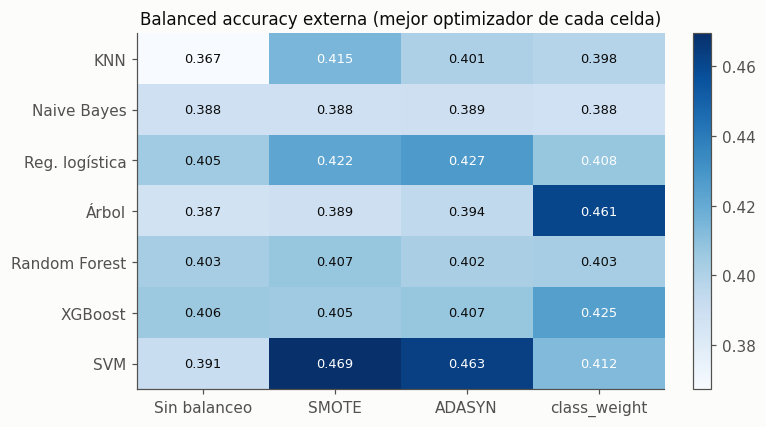

In [3]:
heat = mc.pivot_table(index='model', columns='balance', values='outer_recall_mean', aggfunc='max').reindex(index=MODELS, columns=BALS)
fig, ax = plt.subplots(figsize=(6.8, 4.2))
im = ax.imshow(heat.to_numpy(), cmap='Blues', aspect='auto')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iat[i, j]
        ax.text(j, i, f'{v:.3f}', ha='center', va='center', fontsize=8.5,
                color='white' if v > np.nanpercentile(heat.to_numpy(), 70) else P.INK)
ax.set_xticks(range(len(BALS)), [M.PRETTY[b] for b in BALS]); ax.set_yticks(range(len(MODELS)), [M.PRETTY[m] for m in MODELS])
ax.grid(False); ax.set_title('Balanced accuracy externa (mejor optimizador de cada celda)')
plt.colorbar(im, ax=ax, fraction=0.04)
P.save(fig, 'e3_clf_heatmap'); plt.show()

**Interpretación.** Las mejores balanced accuracy anidadas (0,46 a 0,47) son de SVM con SMOTE o ADASYN y del árbol con
`class_weight`, pero vienen con desviaciones de ±0,08 a ±0,11 entre pliegues, el doble que el resto. La
razón está en la sección 9.6: esas combinaciones predicen Fallecimiento para miles de casos, y en un
pliegue con 1 a 4 fallecimientos acertar uno más sube la métrica hasta 0,25. Las combinaciones con mejor
AUC y F1 (logística con SMOTE o ADASYN, XGBoost con `class_weight`) tienen balanced accuracy algo menor
(0,42 a 0,43) pero mucho más estable (±0,05 a ±0,07). En el mapa de calor, el balanceo solo mueve la
métrica de forma apreciable en SVM (+0,07 con SMOTE), KNN (+0,05) y el árbol (+0,07 con `class_weight`);
en Naive Bayes, Random Forest y XGBoost la diferencia entre técnicas es de centésimas.

## 9.2 Mejor combinación de cada modelo en la prueba

Para cada uno de los 7 modelos se toma la combinación (balanceo × optimizador) con mejor
balanced accuracy externa **media** en la validación anidada; la prueba no interviene en la
elección. Además se incluye la regresión logística del entregable 2 (C = 1, L2, sin búsqueda)
como referencia.

In [4]:
best = mc.loc[mc.groupby('model').outer_recall_mean.idxmax()].set_index('model').reindex(MODELS)
best_combo = best.combo.to_dict()
tt = tc.set_index('combo')
probs = {m: F.load('clf', best_combo[m])[0] for m in MODELS}
tm = {m: E.classification_metrics(yt, probs[m]) for m in MODELS}
res = pd.DataFrame({
    'Combinación elegida': [f'{M.PRETTY[best.loc[m, "balance"]]} · {M.PRETTY[best.loc[m, "optimizer"]]}' for m in MODELS],
    'Balanced acc. anidada': [fmt(best.loc[m, 'outer_recall_mean'], best.loc[m, 'outer_recall_std']) for m in MODELS],
    **{k: [tm[m][v] for m in MODELS] for k, v in
       [('Accuracy', 'accuracy'), ('Precision', 'precision'), ('Recall (balanced acc.)', 'recall'),
        ('F1-score', 'f1'), ('AUC', 'auc'), ('Brier', 'brier'), ('ECE', 'ece')]}
}, index=[M.PRETTY[m] for m in MODELS])
res.round(3)

,Combinación elegida,Balanced acc. anidada,Accuracy,Precision,Recall (balanced acc.),F1-score,AUC,Brier,ECE
KNN,SMOTE · Genética,0.415 ± 0.107,0.384,0.408,0.397,0.320,0.624,0.739,0.114
Naive Bayes,ADASYN · Genética,0.389 ± 0.060,0.499,0.384,0.379,0.373,0.690,0.627,0.146
Reg. logística,ADASYN · Bayesiana (TPE),0.427 ± 0.067,0.515,0.393,0.400,0.386,0.699,0.584,0.025
Árbol,class_weight · Bayesiana (TPE),0.461 ± 0.084,0.441,0.387,0.384,0.340,0.628,0.665,0.091
Random Forest,SMOTE · Bayesiana (TPE),0.407 ± 0.060,0.519,0.399,0.399,0.391,0.696,0.598,0.099
XGBoost,class_weight · Bayesiana (TPE),0.425 ± 0.069,0.511,0.404,0.390,0.382,0.688,0.577,0.024
SVM,SMOTE · Random,0.469 ± 0.101,0.479,0.402,0.435,0.366,0.678,0.630,0.068


Precision, recall y F1 son promedios macro de las 4 clases; AUC es el promedio macro de las
curvas una-contra-el-resto. Como referencia, el entregable 2 reportó para su regresión logística
(C = 1, L2, `class_weight='balanced'`, 1.433 columnas, entrenada con todo el desarrollo) un
balanced accuracy de 0,40, F1 macro de 0,40 y AUC macro de 0,69 en esta misma prueba.

**Interpretación.** En la prueba todos los modelos quedan por debajo de su balanced accuracy anidada (0,38 a 0,43 frente a
0,39 a 0,47); la caída es mayor justo en las combinaciones más dependientes de Fallecimiento (SVM de 0,469
a 0,435, árbol de 0,461 a 0,384), consistente con que su ventaja anidada era en parte ruido de esa clase.
El mejor balanced accuracy en la prueba es el de SVM (0,435), pero con F1 macro bajo (0,366). Random Forest,
XGBoost y la logística dan el mejor equilibrio: accuracy de 0,51 a 0,52, F1 macro de 0,38 a 0,39 y AUC de
0,69 a 0,70. Frente al entregable 2 (logística con C = 1 y 1.433 columnas: balanced accuracy 0,40, F1 0,40,
AUC 0,69), **ningún modelo mejora de forma clara**: con estas 8 variables el techo parece estar en torno a
0,40 de balanced accuracy y 0,70 de AUC, y el capítulo 13 contrasta si alguna diferencia es significativa.
KNN y el árbol son los peores en AUC (0,62 a 0,63).

## 9.3 Matrices de confusión

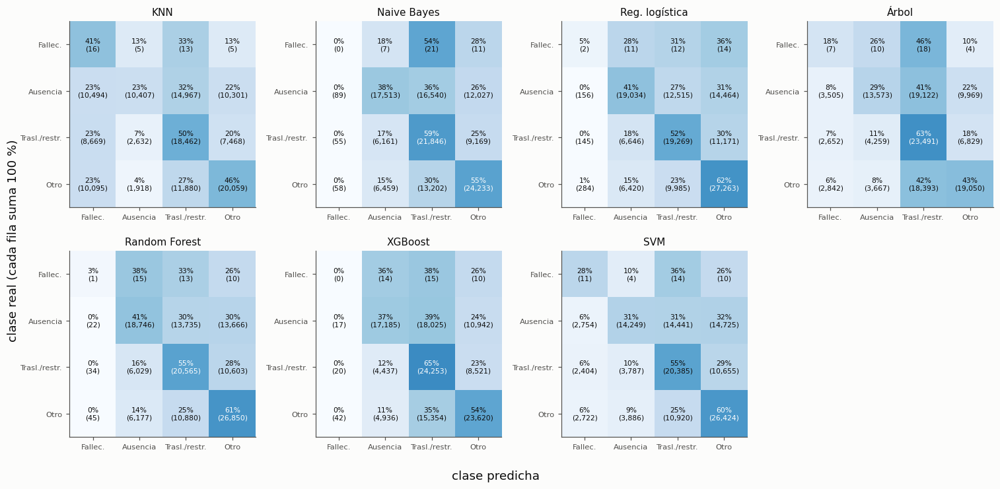

In [5]:
probs = {m: F.load('clf', best_combo[m])[0] for m in MODELS}
fig, axes = plt.subplots(2, 4, figsize=(14, 6.8))
short = ['Fallec.', 'Ausencia', 'Trasl./restr.', 'Otro']
for ax, m in zip(axes.flat, MODELS):
    cm = confusion_matrix(yt, probs[m].argmax(1), labels=range(4))
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{pct[i, j]:.0f}%\n({cm[i, j]:,})', ha='center', va='center', fontsize=7,
                    color='white' if pct[i, j] > 55 else P.INK)
    ax.set_xticks(range(4), short, fontsize=7.5); ax.set_yticks(range(4), short, fontsize=7.5)
    ax.set_title(M.PRETTY[m], fontsize=10); ax.grid(False)
axes[1, 3].axis('off')
fig.supxlabel('clase predicha'); fig.supylabel('clase real (cada fila suma 100 %)')
fig.tight_layout(); P.save(fig, 'e3_clf_confusion'); plt.show()

**Interpretación.** Las tres clases frecuentes se confunden entre sí en todos los modelos: la diagonal va del 23 % al 65 %.
«Traslado/restricción» y «otro registrable» se reconocen mejor (50 % a 65 % y 43 % a 62 %) que «días de
ausencia» (23 % a 41 %), igual que en el entregable 2. Fallecimiento muestra el costo del balanceo: KNN con
SMOTE acierta 16 de 39 (41 %) pero manda a esa clase el 23 % de los casos de las demás (más de 29.000
falsos fallecimientos); SVM acierta 11 con unos 7.900 falsos. XGBoost, Random Forest y Naive Bayes casi
nunca predicen Fallecimiento, así que no pagan ese costo, pero tampoco la detectan. Ningún modelo
encuentra una forma de separar los fallecimientos sin sacrificar mucho las demás clases.

## 9.4 Curvas ROC

Una curva por clase (una contra el resto) para cada modelo. La de Fallecimiento se basa en 39
casos y es muy irregular.

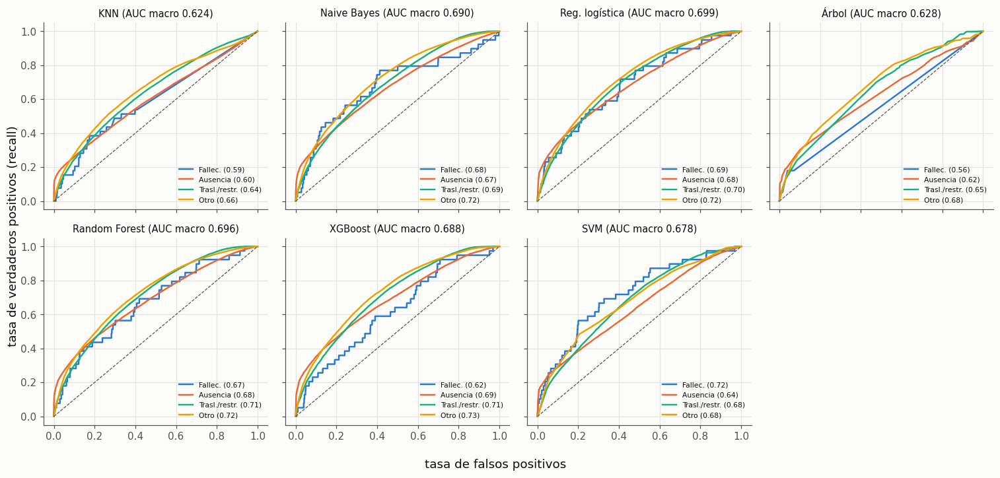

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.6), sharex=True, sharey=True)
for ax, m in zip(axes.flat, MODELS):
    for k in range(4):
        fpr, tpr, _ = roc_curve(yt == k, probs[m][:, k])
        ax.plot(fpr, tpr, color=P.CLASS_COLORS[k], lw=1.6, label=f'{short[k]} ({roc_auc_score(yt == k, probs[m][:, k]):.2f})')
    ax.plot([0, 1], [0, 1], color=P.INK2, lw=0.8, ls='--')
    ax.set_title(f'{M.PRETTY[m]} (AUC macro {tm[m]["auc"]:.3f})', fontsize=9.5)
    ax.legend(fontsize=7, loc='lower right')
axes[1, 3].axis('off')
fig.supxlabel('tasa de falsos positivos'); fig.supylabel('tasa de verdaderos positivos (recall)')
fig.tight_layout(); P.save(fig, 'e3_clf_roc'); plt.show()

**Interpretación.** Las curvas de las tres clases frecuentes son parecidas entre modelos (AUC de 0,60 a 0,73 por clase); la
mejor separada es «otro registrable» (hasta 0,73 en Random Forest y XGBoost). La curva de Fallecimiento es
irregular por sus 39 casos y su AUC cambia mucho entre combinaciones, de 0,50 (KNN sin balanceo) a 0,72
(SVM con SMOTE, Naive Bayes y Random Forest sin balanceo), sin que eso se traduzca en detectarlos con un
umbral razonable: con 39 positivos, ordenar bien unos pocos casos basta para mover mucho esa AUC. Las AUC macro van de 0,62 (KNN) y 0,63 (árbol) a 0,70 (logística, Random Forest).

## 9.5 Balanceo de clases: con y sin

Diferencia en la validación anidada entre cada técnica y «sin balanceo», con el mismo modelo y el
mismo optimizador (pareado), promediada sobre los 4 optimizadores. Además, el recall por clase
en la prueba del mejor optimizador de cada (modelo, balanceo).

In [7]:
fcl = N.fold_table('clf')
rows = []
for met, lab in [('recall', 'Balanced acc.'), ('f1', 'F1 macro'), ('auc', 'AUC macro'), ('accuracy', 'Accuracy')]:
    pv = fcl.pivot_table(index=['model', 'optimizer', 'fold'], columns='balance', values=f'outer_{met}')
    for b in ['smote', 'adasyn', 'class_weight']:
        d = (pv[b] - pv['none']).groupby(level='model').mean()
        for m, v in d.items():
            rows.append({'métrica': lab, 'modelo': M.PRETTY[m], 'balanceo': M.PRETTY[b], 'Δ vs sin balanceo': v})
delta = pd.DataFrame(rows).pivot_table(index='modelo', columns=['métrica', 'balanceo'], values='Δ vs sin balanceo')
delta = delta.reindex([M.PRETTY[m] for m in MODELS])
delta[['Balanced acc.', 'F1 macro', 'AUC macro', 'Accuracy']].round(3)

métrica        Balanced acc.                     F1 macro                      \
balanceo              ADASYN  SMOTE class_weight   ADASYN  SMOTE class_weight   
modelo                                                                          
KNN                    0.031  0.034        0.009   -0.051 -0.050       -0.016   
Naive Bayes            0.002  0.001        0.001    0.000 -0.001       -0.001   
Reg. logística         0.014  0.002       -0.020   -0.006 -0.006       -0.039   
Árbol                  0.007  0.002        0.045   -0.011 -0.015       -0.025   
Random Forest         -0.001  0.001       -0.000   -0.006 -0.006       -0.007   
XGBoost                0.001  0.000        0.002   -0.003 -0.005       -0.005   
SVM                    0.068  0.052        0.004   -0.004  0.003       -0.018   

métrica        AUC macro                     Accuracy                      
balanceo          ADASYN  SMOTE class_weight   ADASYN  SMOTE class_weight  
modelo                                                                     
KNN                0.011  0.006        0.010   -0.097 -0.101       -0.027  
Naive Bayes        0.005  0.027        0.005    0.003  0.001        0.001  
Reg. logística     0.029  0.031       -0.071   -0.010 -0.009       -0.051  
Árbol             -0.036 -0.027       -0.044   -0.006 -0.015       -0.043  
Random Forest     -0.009 -0.022       -0.019   -0.004 -0.004       -0.006  
XGBoost            0.017  0.016        0.010   -0.003 -0.004       -0.010  
SVM                0.015  0.024       -0.007   -0.014 -0.006       -0.034

In [8]:
rec = []
for m in MODELS:
    for b in BALS:
        sub = mc[(mc.model == m) & (mc.balance == b)]
        combo = sub.loc[sub.outer_recall_mean.idxmax(), 'combo']
        p = F.load('clf', combo)[0].argmax(1)
        r = classification_report(yt, p, labels=range(4), output_dict=True, zero_division=0)
        rec.append({'modelo': M.PRETTY[m], 'balanceo': M.PRETTY[b], **{f'recall {short[k]}': r[str(k)]['recall'] for k in range(4)},
                    'fallecimientos detectados (de 39)': int(((p == 0) & (yt == 0)).sum()),
                    'casos predichos como fallecimiento': int((p == 0).sum())})
pd.DataFrame(rec).set_index(['modelo', 'balanceo']).round(3)

recall Fallec.  recall Ausencia  \
modelo         balanceo                                        
KNN            Sin balanceo           0.000            0.466   
               SMOTE                  0.410            0.225   
               ADASYN                 0.154            0.258   
               class_weight           0.128            0.312   
Naive Bayes    Sin balanceo           0.077            0.379   
               SMOTE                  0.000            0.384   
               ADASYN                 0.000            0.379   
               class_weight           0.026            0.378   
Reg. logística Sin balanceo           0.000            0.495   
               SMOTE                  0.179            0.390   
               ADASYN                 0.051            0.412   
               class_weight           0.154            0.327   
Árbol          Sin balanceo           0.000            0.446   
               SMOTE                  0.051            0.393   
               ADASYN                 0.026            0.398   
               class_weight           0.179            0.294   
Random Forest  Sin balanceo           0.000            0.478   
               SMOTE                  0.026            0.406   
               ADASYN                 0.026            0.345   
               class_weight           0.051            0.370   
XGBoost        Sin balanceo           0.000            0.483   
               SMOTE                  0.000            0.369   
               ADASYN                 0.000            0.407   
               class_weight           0.000            0.372   
SVM            Sin balanceo           0.051            0.568   
               SMOTE                  0.282            0.309   
               ADASYN                 0.282            0.328   
               class_weight           0.282            0.496   

                             recall Trasl./restr.  recall Otro  \
modelo         balanceo                                          
KNN            Sin balanceo                 0.457        0.525   
               SMOTE                        0.496        0.456   
               ADASYN                       0.605        0.519   
               class_weight                 0.565        0.493   
Naive Bayes    Sin balanceo                 0.583        0.547   
               SMOTE                        0.589        0.549   
               ADASYN                       0.587        0.551   
               class_weight                 0.587        0.546   
Reg. logística Sin balanceo                 0.446        0.602   
               SMOTE                        0.538        0.530   
               ADASYN                       0.518        0.620   
               class_weight                 0.475        0.583   
Árbol          Sin balanceo                 0.392        0.674   
               SMOTE                        0.465        0.631   
               ADASYN                       0.576        0.522   
               class_weight                 0.631        0.433   
Random Forest  Sin balanceo                 0.508        0.584   
               SMOTE                        0.552        0.611   
               ADASYN                       0.678        0.506   
               class_weight                 0.627        0.553   
XGBoost        Sin balanceo                 0.482        0.591   
               SMOTE                        0.676        0.490   
               ADASYN                       0.585        0.565   
               class_weight                 0.651        0.537   
SVM            Sin balanceo                 0.309        0.584   
               SMOTE                        0.548        0.601   
               ADASYN                       0.389        0.671   
               class_weight                 0.302        0.468   

                             fallecimientos detectados (de 39)  \
modelo         balanceo                                      

**Interpretación.** El balanceo **no es gratis**. Pareado por modelo, optimizador y pliegue: SMOTE y ADASYN suben el
balanced accuracy en KNN (+0,03) y sobre todo en SVM (+0,05 a +0,07), pero bajan el F1 macro (−0,05 en
KNN) y el accuracy (−0,10 en KNN). `class_weight` sube el balanced accuracy del árbol (+0,045) a costa de
AUC (−0,044) y accuracy (−0,043), y en la logística lo empeora todo (−0,02 en balanced accuracy y −0,07
en AUC). En Naive Bayes, Random Forest y XGBoost el efecto es de milésimas. La tabla de la prueba muestra
el mecanismo: el balanceo cambia sobre todo el recall de Fallecimiento y lo paga con recall de «días de
ausencia» (KNN pasa de 0,47 a 0,23 con SMOTE). La técnica «óptima» depende de la métrica que se elija,
y con balanced accuracy la elección queda dominada por una clase de 39 casos.

## 9.6 Tratamiento de la clase Fallecimiento

Corrección del entregable 1: el profesor señaló que la clase Fallecimiento quedó sin tratamiento.
En este entregable se trata con las tres técnicas de balanceo de la guía (SMOTE, ADASYN y
`class_weight`) y se mide su efecto con intervalos, porque con 39 casos en la prueba cualquier
recall es muy incierto. Intervalo de Wilson al 95 % para el recall (aciertos de 39) y para la
precisión (aciertos entre los casos predichos como fallecimiento).

Además, el balanced accuracy promedia el recall de las 4 clases: acertar **un** fallecimiento más de
39 sube la métrica 0,25/39 ≈ 0,006, y en un pliegue externo con 1 fallecimiento la sube 0,25. Por eso
se reporta también el balanced accuracy de las **3 clases frecuentes** (sin Fallecimiento), que es
mucho más estable.

In [9]:
def wilson(k, n, z=1.959964):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (c - h, c + h)
rows = []
for m in MODELS:
    for b in BALS:
        sub = mc[(mc.model == m) & (mc.balance == b)]
        combo = sub.loc[sub.outer_recall_mean.idxmax(), 'combo']
        pr = F.load('clf', combo)[0]; pred = pr.argmax(1)
        hits, n_pred, n_true = int(((pred == 0) & (yt == 0)).sum()), int((pred == 0).sum()), int((yt == 0).sum())
        rlo, rhi = wilson(hits, n_true); plo, phi = wilson(hits, n_pred)
        rec = [((pred == k) & (yt == k)).sum() / (yt == k).sum() for k in range(4)]
        rows.append({'modelo': M.PRETTY[m], 'balanceo': M.PRETTY[b], 'aciertos (de 39)': hits, 'predichos como fallec.': n_pred,
                     'recall fallec.': hits / n_true, 'IC Wilson recall': f'[{rlo:.3f}, {rhi:.3f}]',
                     'precisión fallec.': hits / n_pred if n_pred else np.nan,
                     'IC Wilson precisión': f'[{plo:.4f}, {phi:.4f}]' if n_pred else '—',
                     'AUC fallec. (1 vs resto)': roc_auc_score(yt == 0, pr[:, 0]),
                     'balanced acc. (4 clases)': np.mean(rec), 'balanced acc. (3 clases frecuentes)': np.mean(rec[1:])})
death = pd.DataFrame(rows).set_index(['modelo', 'balanceo'])
death.round(4)

aciertos (de 39)  predichos como fallec.  \
modelo         balanceo                                                 
KNN            Sin balanceo                 0                       0   
               SMOTE                       16                   29274   
               ADASYN                       6                    8707   
               class_weight                 5                    8635   
Naive Bayes    Sin balanceo                 3                    1591   
               SMOTE                        0                     201   
               ADASYN                       0                     202   
               class_weight                 1                    1342   
Reg. logística Sin balanceo                 0                       0   
               SMOTE                        7                    5325   
               ADASYN                       2                     587   
               class_weight                 6                    5325   
Árbol          Sin balanceo                 0                       0   
               SMOTE                        2                     914   
               ADASYN                       1                     894   
               class_weight                 7                    9006   
Random Forest  Sin balanceo                 0                       0   
               SMOTE                        1                     102   
               ADASYN                       1                      79   
               class_weight                 2                     687   
XGBoost        Sin balanceo                 0                       0   
               SMOTE                        0                      38   
               ADASYN                       0                      23   
               class_weight                 0                      79   
SVM            Sin balanceo                 2                     444   
               SMOTE                       11                    7891   
               ADASYN                      11                    8174   
               class_weight                11                    9571   

                             recall fallec. IC Wilson recall  \
modelo         balanceo                                        
KNN            Sin balanceo          0.0000   [0.000, 0.090]   
               SMOTE                 0.4103   [0.271, 0.566]   
               ADASYN                0.1538   [0.072, 0.297]   
               class_weight          0.1282   [0.056, 0.267]   
Naive Bayes    Sin balanceo          0.0769   [0.027, 0.203]   
               SMOTE                 0.0000   [0.000, 0.090]   
               ADASYN                0.0000   [0.000, 0.090]   
               class_weight          0.0256   [0.005, 0.132]   
Reg. logística Sin balanceo          0.0000   [0.000, 0.090]   
               SMOTE                 0.1795   [0.090, 0.327]   
               ADASYN                0.0513   [0.014, 0.169]   
               class_weight          0.1538   [0.072, 0.297]   
Árbol          Sin balanceo          0.0000   [0.000, 0.090]   
               SMOTE                 0.0513   [0.014, 0.169]   
               ADASYN                0.0256   [0.005, 0.132]   
               class_weight          0.1795   [0.090, 0.327]   
Random Forest  Sin balanceo          0.0000   [0.000, 0.090]   
               SMOTE                 0.0256   [0.005, 0.132]   
               ADASYN                0.0256   [0.005, 0.132]   
               class_weight          0.0513   [0.014, 0.169]   
XGBoost        Sin balanceo          0.0000   [0.000, 0.090]   
               SMOTE                 0.0000   [0.000, 0.090]   
               ADASYN                0.0000   [0.000, 0.090]   
               class_weight          0.0000   [0.000, 0.090]   
SVM            Sin balanceo          0.0513   [0.014, 0.169]   
               SMOTE                 0.2821   [0.165, 0.438]   
               ADASYN                0.2821   

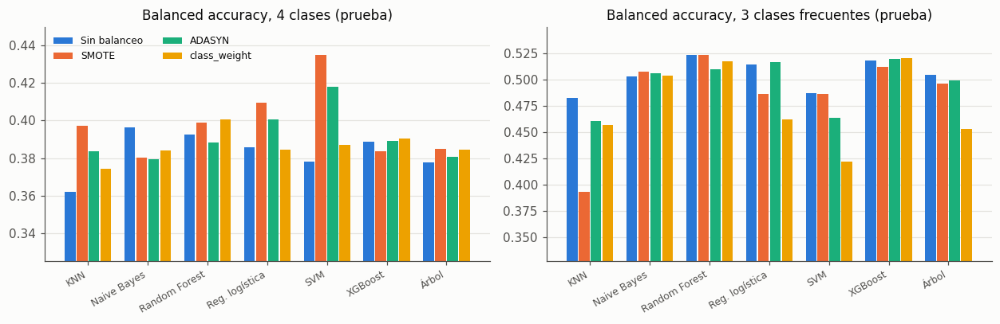

In [10]:
ba3 = death['balanced acc. (3 clases frecuentes)'].unstack('balanceo')[[M.PRETTY[b] for b in BALS]]
ba4 = death['balanced acc. (4 clases)'].unstack('balanceo')[[M.PRETTY[b] for b in BALS]]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=False)
for ax, tab, title in [(axes[0], ba4, 'Balanced accuracy, 4 clases (prueba)'), (axes[1], ba3, 'Balanced accuracy, 3 clases frecuentes (prueba)')]:
    x = np.arange(len(tab)); w = 0.2
    for j, b in enumerate(BALS):
        ax.bar(x + (j - 1.5) * w, tab[M.PRETTY[b]], width=w - 0.02, color=P.BAL_COLORS[b], label=M.PRETTY[b])
    ax.set_xticks(x, tab.index, rotation=30, ha='right', fontsize=8); ax.set_title(title)
    lo, hi = np.nanmin(tab.to_numpy()), np.nanmax(tab.to_numpy()); ax.set_ylim(lo - (hi - lo) * 0.5, hi + (hi - lo) * 0.2)
    ax.grid(axis='x', visible=False)
axes[0].legend(fontsize=8, ncol=2)
fig.tight_layout(); P.save(fig, 'e3_clf_death_ba3'); plt.show()

**Interpretación.** **Fallecimiento sigue sin poder detectarse de forma útil.** La mejor detección es la de KNN con SMOTE:
16 de 39 (recall 0,41, IC de Wilson [0,27; 0,57]), con una precisión del 0,05 % (16 aciertos entre 29.274
casos marcados). SVM con cualquiera de las tres técnicas acierta 11 (0,28, [0,17; 0,44]) con unos 8.000 a
9.600 casos marcados. Sin balanceo casi ningún modelo predice esa clase. Es decir, el tratamiento
funciona en el sentido de la métrica (sube el recall), pero no produce un detector utilizable: por cada
fallecimiento encontrado hay más de 700 falsas alarmas.

El balanced accuracy de las **3 clases frecuentes** cuenta otra historia y cambia el ordenamiento:
Random Forest (0,52), XGBoost (0,52) y la logística sin balanceo o con ADASYN (0,51 a 0,52) quedan
arriba, mientras que las combinaciones que «ganaban» con 4 clases caen: KNN con SMOTE baja a 0,39 (sin
balanceo tenía 0,48) y SVM con `class_weight` a 0,42. El balanceo agresivo quita aciertos en las clases
frecuentes para dárselos a Fallecimiento. Por eso las conclusiones del informe se apoyan en las dos
métricas y en AUC/F1, y no solo en el balanced accuracy de 4 clases. La misma conclusión aparece en la
corrida con diseño temporal (sección 12.6): su mejor balanced accuracy (0,52) viene de acertar 8 de 12
fallecimientos marcando 5.337 casos.

## 9.7 Calibración de probabilidades

- **Brier multiclase:** media de Σₖ (pₖ − 1[y = k])²; 0 es perfecto. El Dummy que predice las
  frecuencias de la prueba obtendría ≈ 0,664 (entregable 2).
- **ECE:** con 15 intervalos de la confianza de la clase predicha, promedio ponderado de
  |accuracy − confianza|.
- **Diagrama de confiabilidad:** confianza predicha frente a la frecuencia observada de acierto,
  y para la clase «días de ausencia», probabilidad predicha frente a la frecuencia real.

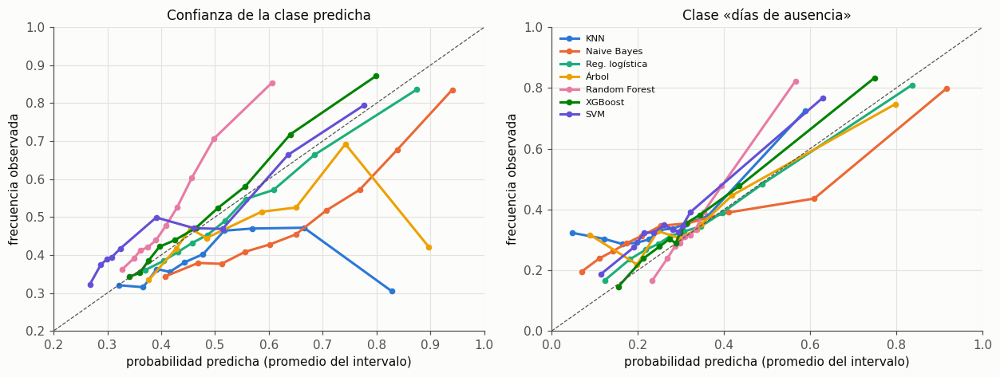

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for i, m in enumerate(MODELS):
    p = probs[m]
    conf = p.max(1); correct = (p.argmax(1) == yt)
    fo, mp = calibration_curve(correct, conf, n_bins=10, strategy='quantile')
    axes[0].plot(mp, fo, marker='o', ms=4, color=P.MODEL_COLORS[m], label=M.PRETTY[m])
    fo2, mp2 = calibration_curve(yt == 1, p[:, 1], n_bins=10, strategy='quantile')
    axes[1].plot(mp2, fo2, marker='o', ms=4, color=P.MODEL_COLORS[m], label=M.PRETTY[m])
for ax, t in zip(axes, ['Confianza de la clase predicha', 'Clase «días de ausencia»']):
    ax.plot([0, 1], [0, 1], ls='--', color=P.INK2, lw=0.8)
    ax.set_xlabel('probabilidad predicha (promedio del intervalo)'); ax.set_ylabel('frecuencia observada'); ax.set_title(t)
axes[0].set_xlim(0.2, 1); axes[0].set_ylim(0.2, 1); axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=7.5, loc='upper left')
fig.tight_layout(); P.save(fig, 'e3_clf_calibracion'); plt.show()

### Recalibración (Platt e isotónica)

Para cada uno de los 7 modelos se reajusta el pipeline dentro de `CalibratedClassifierCV` con 3
pliegues por establecimiento de la submuestra de desarrollo: en cada pliegue se entrena el modelo
con dos tercios y se ajusta el calibrador (sigmoide de Platt o regresión isotónica, una contra el
resto y luego normalizada) con el tercio restante. Así el calibrador nunca ve la prueba.

In [12]:
from sklearn.model_selection import StratifiedGroupKFold
def run_recal():
    X, y, g, s = N.task_data('clf')
    folds = list(StratifiedGroupKFold(3, shuffle=True, random_state=C.seed_for('inner', 99)).split(X, y, g))
    rows, curves = [], {}
    for m in MODELS:
        r = best.loc[m]
        params = json.loads(r.final_params)
        rows.append({'modelo': M.PRETTY[m], 'método': 'sin recalibrar', **E.classification_metrics(yt, probs[m])})
        for method in ['sigmoid', 'isotonic']:
            pipe = M.make_pipeline('clf', m, params, r.balance, C.SEED)
            cal = CalibratedClassifierCV(pipe, method=method, cv=folds, n_jobs=3)
            with warnings.catch_warnings():
                warnings.simplefilter('ignore'); cal.fit(X, y)
            p = cal.predict_proba(test[D.FEATURES])
            rows.append({'modelo': M.PRETTY[m], 'método': 'Platt (sigmoide)' if method == 'sigmoid' else 'isotónica',
                         **E.classification_metrics(yt, p)})
            curves[(m, method)] = calibration_curve(p.argmax(1) == yt, p.max(1), n_bins=10, strategy='quantile')
    return pd.DataFrame(rows), curves
recal, recal_curves = cache.cached('clf_recalibration', run_recal)
recal.set_index(['modelo', 'método'])[['brier', 'ece', 'log_loss', 'recall', 'auc']].round(4)

brier     ece  log_loss  recall     auc
modelo         método                                                    
KNN            sin recalibrar    0.7387  0.1143    1.3673  0.3970  0.6240
               Platt (sigmoide)  0.6192  0.0590    1.0315  0.3354  0.6564
               isotónica         0.6137  0.0483    1.0242  0.3396  0.6546
Naive Bayes    sin recalibrar    0.6271  0.1459    1.0837  0.3794  0.6898
               Platt (sigmoide)  0.5928  0.0353    0.9949  0.3776  0.6655
               isotónica         0.5853  0.0214    0.9799  0.3778  0.6843
Reg. logística sin recalibrar    0.5840  0.0246    0.9831  0.4003  0.6993
               Platt (sigmoide)  0.5942  0.0610    0.9937  0.3851  0.6963
               isotónica         0.5933  0.0574    0.9945  0.3869  0.6841
Árbol          sin recalibrar    0.6650  0.0914    1.1374  0.3845  0.6277
               Platt (sigmoide)  0.5993  0.0544    1.0035  0.3531  0.6771
               isotónica         0.5965  0.0452    0.9976  0.3673  0.6881
Random Forest  sin recalibrar    0.5979  0.0990    1.0185  0.3987  0.6965
               Platt (sigmoide)  0.5766  0.0279    0.9681  0.3903  0.7014
               isotónica         0.5758  0.0236    0.9656  0.3911  0.6993
XGBoost        sin recalibrar    0.5766  0.0243    0.9962  0.3903  0.6878
               Platt (sigmoide)  0.5759  0.0173    0.9674  0.3869  0.6885
               isotónica         0.5730  0.0078    0.9628  0.3916  0.6889
SVM            sin recalibrar    0.6296  0.0676    1.1332  0.4349  0.6782
               Platt (sigmoide)  0.6100  0.0733    1.0201  0.3380  0.6885
               isotónica         0.5918  0.0400    0.9937  0.3773  0.6934

**Interpretación.** - **Bien calibrados sin hacer nada:** XGBoost (ECE 0,024) y la logística (0,025). Sus curvas siguen la
  diagonal.
- **Mal calibrados:** Naive Bayes (ECE 0,146) es sobreconfiado, como se espera por el supuesto de
  independencia (las variables de un mismo lugar de trabajo están correlacionadas y el modelo cuenta la
  misma evidencia varias veces). KNN (0,114) y el árbol (0,091) producen probabilidades extremas en pocas
  hojas o vecindarios. Random Forest con SMOTE es **subconfiado** (su curva va por encima de la
  diagonal): el bosque promedia árboles y el sobremuestreo aplana las probabilidades.
- **Recalibración:** la isotónica baja el ECE de Naive Bayes de 0,146 a 0,021, el de Random Forest de 0,099
  a 0,024, el de KNN de 0,114 a 0,048 y el del árbol de 0,091 a 0,045, y mejora el Brier en todos ellos. En
  la logística y en XGBoost, ya calibrados, recalibrar no ayuda (el ECE de la logística sube de 0,025 a
  0,057 porque el calibrador se ajusta con un tercio de la submuestra). Recalibrar baja el balanced
  accuracy de los modelos balanceados (SVM de 0,435 a 0,338 con Platt): las probabilidades calibradas
  devuelven a Fallecimiento su frecuencia real y el argmax deja de elegirla. Si el uso final requiere
  probabilidades confiables, conviene XGBoost o un Random Forest recalibrado con regresión isotónica.

## 9.8 Segunda prueba: mismos establecimientos, meses nuevos

Corrección del entregable 1 (costo del diseño; ver sección 4.7). Los 83.912 casos de octubre a
diciembre de los establecimientos de **desarrollo** quedaban descartados. Aquí se usan como una
segunda prueba que solo separa por tiempo: el modelo ya vio esos establecimientos (en enero a
septiembre), pero no esos meses. La diferencia con la prueba principal (establecimientos nuevos)
mide cuánto cuesta, en desempeño, exigir que el modelo generalice a lugares que no conoce. Se usan
los mismos 7 modelos, reajustados sobre la misma submuestra de desarrollo.

In [13]:
from osha_e3 import data as D
df_all = D.load_prepared()
dev_est = set(df_all.loc[df_all.split.eq('development'), 'establishment_id'])
temporal = df_all[df_all.establishment_id.isin(dev_est) & df_all.date.ge('2023-10-01')].reset_index(drop=True)
y_tmp = temporal.y_clf.to_numpy() - 1
print(f'Segunda prueba: {len(temporal):,} casos, {temporal.establishment_id.nunique():,} establecimientos, '
      f'{(y_tmp == 0).sum()} fallecimientos')
def run_temporal():
    X, y, _, _ = N.task_data('clf')
    out = {}
    for m in MODELS:
        r = best.loc[m]
        pipe = S.refit('clf', m, json.loads(r.final_params), r.balance, X, y, C.SEED)
        out[m] = pipe.predict_proba(temporal[D.FEATURES])
    return out
p_tmp = cache.cached('clf_temporal_only', run_temporal)
rows = []
for m in MODELS:
    a = E.classification_metrics(yt, probs[m]); b = E.classification_metrics(y_tmp, p_tmp[m])
    rows.append({'modelo': M.PRETTY[m], 'balanced acc. (establ. nuevos)': a['recall'], 'balanced acc. (mismos establ.)': b['recall'],
                 'AUC (establ. nuevos)': a['auc'], 'AUC (mismos establ.)': b['auc'],
                 'accuracy (establ. nuevos)': a['accuracy'], 'accuracy (mismos establ.)': b['accuracy']})
tmp_tab = pd.DataFrame(rows).set_index('modelo')
tmp_tab['Δ AUC (mismos − nuevos)'] = tmp_tab['AUC (mismos establ.)'] - tmp_tab['AUC (establ. nuevos)']
tmp_tab.round(4)

Segunda prueba: 83,912 casos, 20,582 establecimientos, 25 fallecimientos


,balanced acc. (establ. nuevos),balanced acc. (mismos establ.),AUC (establ. nuevos),AUC (mismos establ.),accuracy (establ. nuevos),accuracy (mismos establ.),Δ AUC (mismos − nuevos)
modelo,,,,,,,
KNN,0.3970,0.4774,0.6240,0.6701,0.3842,0.3885,0.0461
Naive Bayes,0.3794,0.3809,0.6898,0.6935,0.4992,0.5010,0.0036
Reg. logística,0.4003,0.4191,0.6993,0.7074,0.5147,0.5170,0.0081
Árbol,0.3845,0.4088,0.6277,0.6390,0.4405,0.4405,0.0113
Random Forest,0.3987,0.3962,0.6965,0.7246,0.5194,0.5243,0.0282
XGBoost,0.3903,0.3919,0.6878,0.6993,0.5107,0.5138,0.0115
SVM,0.4349,0.4557,0.6782,0.6920,0.4794,0.4818,0.0138


**Interpretación.** En la segunda prueba (mismos establecimientos, octubre–diciembre; 83.912 casos, 25 fallecimientos), el
AUC sube en todos los modelos, entre 0,004 (Naive Bayes) y 0,046 (KNN). El accuracy cambia muy poco (≤ 0,005).
El modelo que más gana es KNN (balanced accuracy de 0,40 a 0,48): sus vecinos más cercanos son casos del
mismo establecimiento, que comparten códigos de sector, ocupación y estado, y heredan sus prácticas de
registro. Esto cuantifica el costo de la partición: exigir establecimientos nuevos le cuesta a la mayoría
de los modelos entre 0,004 y 0,03 de AUC. Un diseño que mezclara establecimientos habría reportado esas
cifras más altas sin que el modelo generalizara mejor a lugares nuevos, que es el uso que interesa.
El costo de descartar casos (sección 4.7) es, entonces, una diferencia pequeña en las métricas a cambio de
una estimación honesta.

# 10. Evaluación de los modelos de regresión

Objetivo: `log(1 + días de ausencia)` en los casos que terminaron en días de ausencia (capítulo 4).
7 modelos × 4 optimizadores = 28 combinaciones, sin balanceo (no aplica en regresión). Igual que en
clasificación, la mejor combinación de cada modelo se elige por el RMSE externo de la validación
anidada y luego se evalúa una vez en la prueba (45.861 casos de octubre a diciembre).

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.diagnostic import het_white, acorr_ljungbox
from statsmodels.tsa.stattools import bds, acf
from statsmodels.graphics.tsaplots import plot_acf
from osha_e3 import config as C, data as D, models as M, nested as N, final as F, evaluation as E, plots as P, search as S, cache
P.setup()
mr = N.master_table('reg'); tr_ = F.test_table('reg').set_index('combo')
test, yt = F.test_data('reg')
MODELS, OPTS = P.MODEL_ORDER_REG, M.OPTIMIZERS
fmt = lambda m, s: f'{m:.3f} ± {s:.3f}'

## 10.1 Las 28 combinaciones en la validación anidada

In [2]:
mr['Combinación'] = mr.model.map(M.PRETTY) + ' · ' + mr.optimizer.map(M.PRETTY)
t = mr.sort_values('outer_rmse_mean')
pd.DataFrame({'RMSE externo': [fmt(a, b) for a, b in zip(t.outer_rmse_mean, t.outer_rmse_std)],
              'MAE externo': [fmt(a, b) for a, b in zip(t.outer_mae_mean, t.outer_mae_std)],
              'R² externo': [fmt(a, b) for a, b in zip(t.outer_r2_mean, t.outer_r2_std)],
              'Búsqueda (min·núcleo)': (t.search_seconds_total / 60).round(1).to_numpy()},
             index=t['Combinación'])

,RMSE externo,MAE externo,R² externo,Búsqueda (min·núcleo)
Combinación,,,,
Random Forest · Random,1.364 ± 0.008,1.143 ± 0.008,0.066 ± 0.006,19.3
Random Forest · Genética,1.365 ± 0.010,1.143 ± 0.009,0.065 ± 0.008,18.7
Random Forest · Bayesiana (TPE),1.365 ± 0.009,1.143 ± 0.009,0.064 ± 0.006,22.1
XGBoost · Bayesiana (TPE),1.365 ± 0.011,1.143 ± 0.011,0.064 ± 0.009,2.6
Random Forest · Grid,1.365 ± 0.010,1.144 ± 0.011,0.064 ± 0.007,22.1
XGBoost · Grid,1.365 ± 0.011,1.144 ± 0.011,0.064 ± 0.010,3.1
XGBoost · Genética,1.366 ± 0.010,1.145 ± 0.010,0.063 ± 0.007,2.5
XGBoost · Random,1.366 ± 0.011,1.145 ± 0.013,0.063 ± 0.007,2.6
Lasso · Random,1.367 ± 0.012,1.147 ± 0.010,0.061 ± 0.011,3.2


**Interpretación.** Las 28 combinaciones quedan en un rango estrecho: RMSE externo entre 1,364 y 1,381 y R² entre 0,04 y
0,07. Los modelos de árboles en ensamble (Random Forest y XGBoost) encabezan la tabla, seguidos de cerca
por Lasso y Ridge; SVR, el árbol simple y KNN quedan al final. Las diferencias entre optimizadores dentro de
un mismo modelo (≤ 0,004 de RMSE) son menores que la desviación entre pliegues (≈ 0,01): con este
presupuesto, el método de búsqueda importa poco en regresión (capítulo 7). El costo sí cambia mucho:
Random Forest gastó unos 20 minutos·núcleo de búsqueda por combinación y XGBoost unos 3 para el mismo
RMSE. Con estas variables se explica solo alrededor del 6 % de la varianza de log(1 + días): la duración
de una ausencia depende sobre todo de la lesión concreta, que el modelo no ve.

## 10.2 Mejor combinación de cada modelo: métricas y supuestos en la prueba

- **Test de White** (homocedasticidad): regresión auxiliar de los residuos al cuadrado sobre las
  predicciones y su cuadrado (la forma «especial» del test de White, que evita los miles de
  productos cruzados de 210 columnas binarias). H0: varianza constante.
- **Test BDS** (independencia, Brock-Dechert-Scheinkman): sobre los residuos ordenados por fecha.
  El estadístico es O(n²) en memoria, así que se aplica a 3.000 residuos equiespaciados en el
  tiempo, dimensión de inmersión 2. H0: residuos i.i.d.

Con 45.861 casos cualquier desviación pequeña sale significativa; por eso los p-valores se leen
junto con las gráficas de 12.4.

In [3]:
best = mr.loc[mr.groupby('model').outer_rmse_mean.idxmin()].set_index('model').reindex(MODELS)
best_combo = best.combo.to_dict()
preds = {m: F.load('reg', best_combo[m])[0].astype(float) for m in MODELS}
order = np.argsort(test.date.to_numpy(), kind='stable')
idx_bds = order[np.linspace(0, len(order) - 1, 3000).astype(int)]
def white_p(res, fit):
    exog = np.column_stack([np.ones_like(fit), fit])
    return het_white(res, exog)[1]
rows = []
for m in MODELS:
    p = preds[m]; res = yt - p
    rows.append({'Modelo': M.PRETTY[m], 'Optimizador': M.PRETTY[best.loc[m, 'optimizer']],
                 'RMSE anidado': fmt(best.loc[m, 'outer_rmse_mean'], best.loc[m, 'outer_rmse_std']),
                 'RMSE prueba': tr_.loc[best_combo[m], 'test_rmse'], 'MAE prueba': tr_.loc[best_combo[m], 'test_mae'],
                 'R² prueba': tr_.loc[best_combo[m], 'test_r2'],
                 'p-valor (White)': white_p(res, p), 'p-valor (BDS, m=2)': float(bds(res[idx_bds], max_dim=2)[1])})
base = np.full_like(yt, N.task_data('reg')[1].mean())
rows.append({'Modelo': 'Referencia: media del entrenamiento', 'Optimizador': '—', 'RMSE anidado': '—',
             'RMSE prueba': E.regression_metrics(yt, base)['rmse'], 'MAE prueba': E.regression_metrics(yt, base)['mae'],
             'R² prueba': E.regression_metrics(yt, base)['r2'], 'p-valor (White)': np.nan, 'p-valor (BDS, m=2)': np.nan})
reg_table = pd.DataFrame(rows).set_index('Modelo')
reg_table.round(4)

,Optimizador,RMSE anidado,RMSE prueba,MAE prueba,R² prueba,p-valor (White),"p-valor (BDS, m=2)"
Modelo,,,,,,,
KNN,Grid,1.380 ± 0.012,1.1659,0.9571,-0.0235,0.0,0.8976
Ridge,Genética,1.367 ± 0.011,1.1511,0.9432,0.0023,0.0,0.8668
Lasso,Random,1.367 ± 0.012,1.1494,0.9422,0.0052,0.0,0.8740
Árbol,Grid,1.378 ± 0.012,1.1534,0.9418,-0.0016,0.0,0.8783
Random Forest,Random,1.364 ± 0.008,1.1431,0.9310,0.0162,0.0,0.8529
XGBoost,Bayesiana (TPE),1.365 ± 0.011,1.1437,0.9345,0.0152,0.0,0.8703
SVR,Grid,1.370 ± 0.014,1.1512,0.9451,0.0023,0.0,0.8763
Referencia: media del entrenamiento,—,—,1.1885,1.0272,-0.0636,NaN,NaN


**Interpretación.** En la prueba el orden se mantiene (Random Forest y XGBoost primero, KNN último), pero aparecen dos cosas
que la validación no mostraba:

1. **El RMSE baja** (1,14 frente a 1,36) **y el R² se hunde** (0,016 en el mejor modelo, negativo en KNN y
   el árbol). No es que el modelo mejore: la prueba tiene menos dispersión (desviación de 1,15 frente a 1,41
   en el entrenamiento) y un nivel más bajo (media 2,44 frente a 2,73). Hasta la referencia que predice la
   media del entrenamiento obtiene R² = −0,064.
2. **Sesgo sistemático:** el 58 % de los residuos son negativos y el residuo medio es −0,22 (el modelo
   sobrestima). El sesgo crece mes a mes: −0,12 en octubre, −0,21 en noviembre y −0,34 en diciembre.

La causa más probable es **censura a la derecha** de la etiqueta. El archivo se cierra con el reporte
anual: un caso de diciembre no puede acumular 180 días de ausencia antes de esa fecha. En los datos, los
casos con 180 días o más pasan de cerca del 8 % (enero a junio) al 0,5 % (diciembre). Es la «maduración de la
etiqueta» que el entregable 2 dejó anotada como posible y que aquí se confirma. Si se quita el sesgo medio,
el R² del mejor modelo en la prueba sube de 0,016 a 0,053, cerca del 0,066 de la validación anidada.

**Supuestos.** El test de White rechaza la homocedasticidad en todos los modelos (p ≈ 0): la varianza del
residuo cambia con la predicción, en parte por la forma acotada del objetivo y por la censura. BDS no
rechaza la independencia (p entre 0,85 y 0,90), pero los 3.000 residuos usados están muy separados en el
tiempo; Ljung-Box (sección 10.4) sí detecta dependencia entre residuos cercanos.

## 10.3 Entrenamiento, validación y prueba con sus predicciones

Para el mejor modelo se reajusta con 4 de los 5 pliegues externos (entrenamiento), se predice el
pliegue restante (validación) y la prueba. La gráfica muestra, por semana, el promedio real y
el predicho de `log(1 + días)` en cada conjunto; abajo, predicho frente a real caso a caso.

Mejor modelo de regresión: Random Forest · Random {"n_estimators": 183, "max_depth": 24, "min_samples_leaf": 3, "max_features": 0.078924016621189}


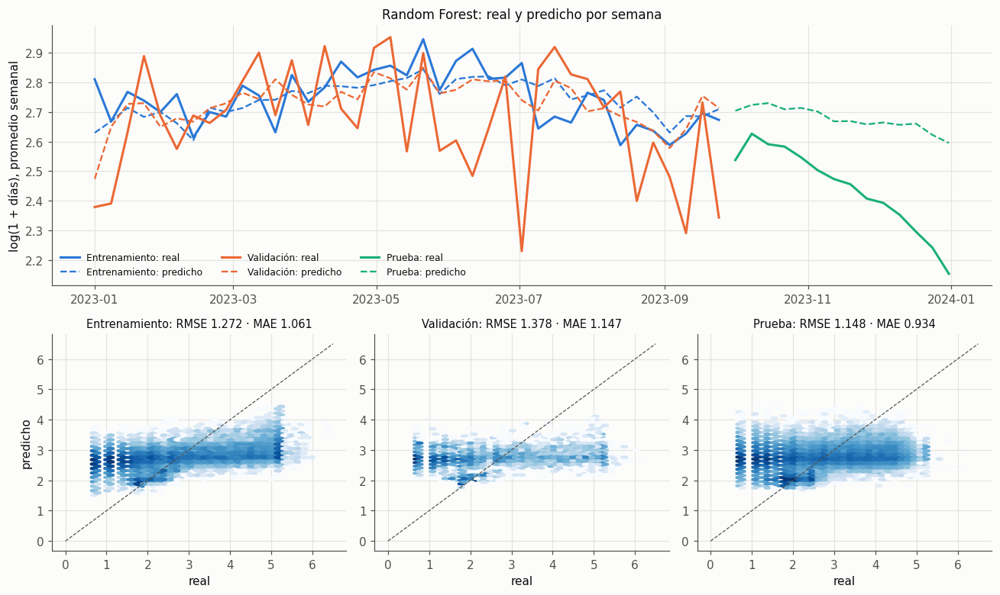

In [4]:
bm = min(MODELS, key=lambda m: best.loc[m, 'outer_rmse_mean'])
print('Mejor modelo de regresión:', M.PRETTY[bm], '·', M.PRETTY[best.loc[bm, 'optimizer']], best.loc[bm, 'final_params'])
sub_r, dev_r, _ = D.regression_sets()
X, y, g, s = N.task_data('reg')
tr_i, va_i = N.outer_folds('reg')[0]
def run_tvt():
    pipe = S.refit('reg', bm, json.loads(best.loc[bm, 'final_params']), 'none', X.iloc[tr_i], y[tr_i], C.SEED)
    return {'train': pipe.predict(X.iloc[tr_i]), 'valid': pipe.predict(X.iloc[va_i]), 'test': pipe.predict(test[D.FEATURES])}
tvt = cache.cached('reg_train_valid_test', run_tvt)
parts = [('Entrenamiento', sub_r.iloc[tr_i].date, y[tr_i], tvt['train'], P.SERIES[0]),
         ('Validación', sub_r.iloc[va_i].date, y[va_i], tvt['valid'], P.SERIES[1]),
         ('Prueba', test.date, yt, tvt['test'], P.SERIES[2])]
fig = plt.figure(figsize=(12, 7.2)); gs = fig.add_gridspec(2, 3, height_ratios=[1.2, 1])
ax = fig.add_subplot(gs[0, :])
for name, d, yy, pp, col in parts:
    w = pd.DataFrame({'d': pd.to_datetime(d).to_numpy(), 'y': yy, 'p': pp}).set_index('d').resample('W').mean()
    ax.plot(w.index, w.y, color=col, lw=2, label=f'{name}: real')
    ax.plot(w.index, w.p, color=col, lw=1.5, ls='--', label=f'{name}: predicho')
ax.set_ylabel('log(1 + días), promedio semanal'); ax.set_title(f'{M.PRETTY[bm]}: real y predicho por semana')
ax.legend(ncol=3, fontsize=8, loc='lower left')
for i, (name, d, yy, pp, col) in enumerate(parts):
    a = fig.add_subplot(gs[1, i])
    a.hexbin(yy, pp, gridsize=35, cmap='Blues', mincnt=1, bins='log')
    a.plot([0, 6.5], [0, 6.5], color=P.INK2, ls='--', lw=0.8)
    met = E.regression_metrics(yy, pp)
    a.set_title(f'{name}: RMSE {met["rmse"]:.3f} · MAE {met["mae"]:.3f}', fontsize=9.5)
    a.set_xlabel('real'); a.set_ylabel('predicho' if i == 0 else '')
fig.tight_layout(); P.save(fig, 'e3_reg_train_valid_test'); plt.show()

**Interpretación.** El modelo sigue bien el nivel medio del entrenamiento (RMSE 1,27) y de la validación (1,38). La serie de
validación es más irregular porque cada semana tiene pocos establecimientos de un solo pliegue. En la
prueba la diferencia es visible: el promedio real cae de forma sostenida de unos 2,6 a 2,15 entre octubre y
fin de año, mientras la predicción queda casi plana en torno a 2,6–2,7. Es la huella de la censura descrita
arriba. Caso a caso (abajo), las predicciones se concentran entre 2 y 3,5 sea cual sea el valor real: el
modelo apenas separa ausencias cortas de largas, consistente con un R² de 0,05 a 0,07.

## 10.4 Análisis de residuos del mejor modelo

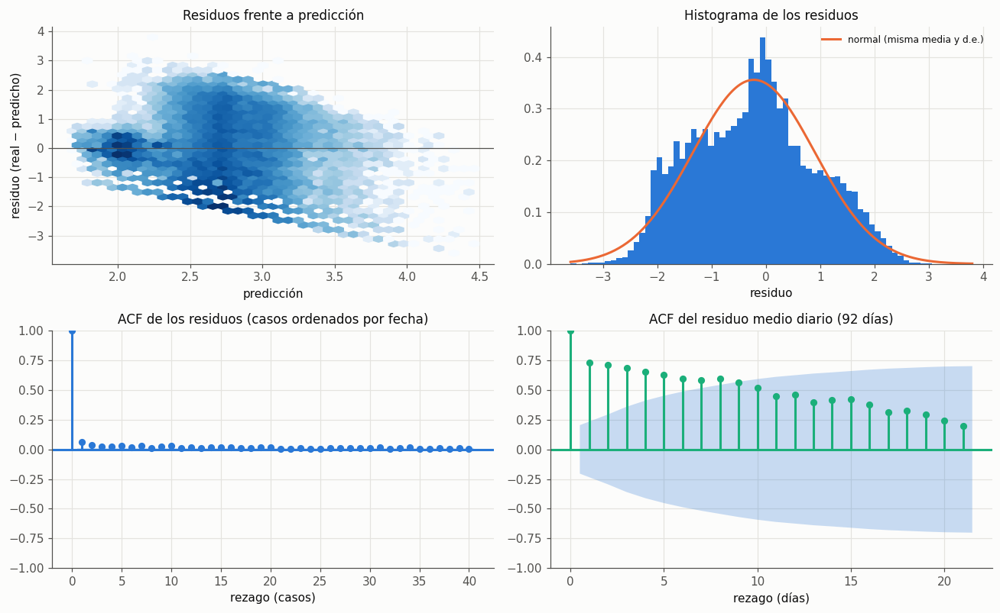

Ljung-Box (casos ordenados por fecha):
     lb_stat  lb_pvalue
1   176.5050        0.0
7   403.1111        0.0
20  570.3463        0.0
Ljung-Box (residuo medio diario):
     lb_stat  lb_pvalue
1    50.9448        0.0
7   297.3851        0.0
14  475.8754        0.0
Jarque-Bera: estadístico 868.6, p = 2.5e-189 | D'Agostino: p = 0
Asimetría 0.115, curtosis en exceso -0.634


BDS (3.000 residuos equiespaciados), dimensiones 2-4: [0.8529 0.7766 0.7045]


In [5]:
p = preds[bm]; res = yt - p
res_t = res[order]
daily = pd.Series(res, index=test.date.to_numpy()).groupby(level=0).mean()
fig, axes = plt.subplots(2, 2, figsize=(12, 7.4))
axes[0, 0].hexbin(p, res, gridsize=40, cmap='Blues', mincnt=1, bins='log'); axes[0, 0].axhline(0, color=P.INK2, lw=0.8)
axes[0, 0].set_xlabel('predicción'); axes[0, 0].set_ylabel('residuo (real − predicho)'); axes[0, 0].set_title('Residuos frente a predicción')
axes[0, 1].hist(res, bins=70, color=P.SERIES[0], density=True)
xs = np.linspace(res.min(), res.max(), 200)
axes[0, 1].plot(xs, stats.norm.pdf(xs, res.mean(), res.std()), color=P.SERIES[1], lw=2, label='normal (misma media y d.e.)')
axes[0, 1].set_title('Histograma de los residuos'); axes[0, 1].legend(fontsize=8); axes[0, 1].set_xlabel('residuo')
plot_acf(res_t, lags=40, ax=axes[1, 0], color=P.SERIES[0], vlines_kwargs={'colors': P.SERIES[0]})
axes[1, 0].set_title('ACF de los residuos (casos ordenados por fecha)'); axes[1, 0].set_xlabel('rezago (casos)')
plot_acf(daily.to_numpy(), lags=21, ax=axes[1, 1], color=P.SERIES[2], vlines_kwargs={'colors': P.SERIES[2]})
axes[1, 1].set_title('ACF del residuo medio diario (92 días)'); axes[1, 1].set_xlabel('rezago (días)')
fig.tight_layout(); P.save(fig, 'e3_reg_residuos'); plt.show()
lb_case = acorr_ljungbox(res_t, lags=[1, 7, 20], return_df=True)
lb_day = acorr_ljungbox(daily.to_numpy(), lags=[1, 7, 14], return_df=True)
jb = stats.jarque_bera(res); dag = stats.normaltest(res)
print('Ljung-Box (casos ordenados por fecha):'); print(lb_case.round(4).to_string())
print('Ljung-Box (residuo medio diario):'); print(lb_day.round(4).to_string())
print(f'Jarque-Bera: estadístico {jb.statistic:.1f}, p = {jb.pvalue:.2g} | D\'Agostino: p = {dag.pvalue:.2g}')
print(f'Asimetría {stats.skew(res):.3f}, curtosis en exceso {stats.kurtosis(res):.3f}')
print(f'BDS (3.000 residuos equiespaciados), dimensiones 2-4:', np.round(bds(res[idx_bds], max_dim=4)[1], 4))

**Interpretación.** - **Residuos frente a predicción:** bandas diagonales, porque el objetivo es discreto (días enteros) y la
  predicción se mueve en un rango corto. La forma de abanico confirma la heterocedasticidad que detectó
  White. El modelo nunca predice ausencias muy cortas ni muy largas: subestima las largas y sobrestima las
  cortas (regresión hacia la media).
- **Histograma:** asimetría casi nula (0,12) pero colas más cortas que la normal (curtosis en exceso
  −0,63) y una forma irregular que hereda los picos del objetivo (1, 2, 3 días y el tope de 180).
  Jarque-Bera y D'Agostino rechazan la normalidad; con 45.861 casos rechazarían casi cualquier desviación,
  pero aquí la desviación también se ve en la gráfica. Para estos modelos (no paramétricos o penalizados)
  la normalidad no es un requisito de estimación; solo afectaría a intervalos de predicción basados en ella.
- **ACF y Ljung-Box:** caso a caso la autocorrelación es pequeña (0,06 en el rezago 1) pero significativa
  con tantos datos (Ljung-Box p ≈ 0): casos del mismo día y establecimiento se parecen. El residuo medio
  diario tiene una autocorrelación alta que decae lentamente (0,73 en el rezago 1): no es ruido, es la
  tendencia descendente de la prueba (censura) que el modelo no captura. Es un problema de
  especificación más que de dependencia entre casos.

**Conclusión del capítulo.** La regresión tiene poder predictivo bajo y su evaluación en la prueba está
afectada por la censura de la etiqueta. Una versión correcta debería modelar la censura (por ejemplo, un
modelo de supervivencia con el tiempo hasta el cierre del reporte como límite) o evaluar solo casos con
seguimiento suficiente. Se deja como siguiente paso; los resultados de este capítulo se leen como
comparación relativa entre modelos, no como desempeño absoluto.

# 11. Interpretabilidad global y local (SHAP y LIME)

Los valores de Shapley reparten la predicción de un caso entre sus variables según la teoría de
juegos cooperativos: la contribución de una variable es su aporte marginal promedio sobre todos
los órdenes posibles de incorporación. Cumplen **eficiencia** (las contribuciones suman la
diferencia entre la predicción y el valor base), **simetría** (dos variables que aportan lo mismo
reciben lo mismo) y **aditividad** (en un ensamble, los SHAP del ensamble son la suma de los de sus
partes). Se calculan en el espacio que ve el modelo (columnas one-hot), así que cada barra es una
categoría concreta, por ejemplo `soc_minor=29-1` (profesionales de la salud).

Se explica el mejor modelo de cada tarea (según la validación anidada) y, como pide la guía, el
mejor XGBoost de clasificación con SHAP y LIME.

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
from osha_e3 import config as C, data as D, models as M, nested as N, final as F, plots as P, search as S, interpret as I, cache
P.setup()
mc, mr = N.master_table('clf'), N.master_table('reg')
bc = mc.loc[mc.outer_recall_mean.idxmax()]; br = mr.loc[mr.outer_rmse_mean.idxmin()]
bx = mc[mc.model == 'xgboost'].sort_values('outer_recall_mean').iloc[-1]
print('Mejor clasificación:', bc.combo, '| mejor regresión:', br.combo, '| mejor XGBoost:', bx.combo)
Xc, yc, _, _ = N.task_data('clf'); Xr, yr, _, _ = N.task_data('reg')
test_c, yt_c = F.test_data('clf'); test_r, yt_r = F.test_data('reg')
rng = np.random.default_rng(C.SEED)
ic = rng.choice(len(test_c), 1500, replace=False); ir = rng.choice(len(test_r), 1500, replace=False)
CLASS = 1  # «días de ausencia»: la clase más frecuente y la de mayor costo laboral

Mejor clasificación: svm|smote|random | mejor regresión: random_forest|none|random | mejor XGBoost: xgboost|class_weight|bayes


In [2]:
def explain(task, row, Xtr, ytr, Xex):
    pipe = S.refit(task, row.model, json.loads(row.final_params), row.balance, Xtr, ytr, C.SEED)
    vals, base, A, names = I.shap_values(task, row.model, pipe, Xtr.sample(1000, random_state=C.SEED), Xex)
    return pipe, vals, base, A, names
pipe_c, sv_c, base_c, A_c, names = cache.cached('shap_clf', lambda: explain('clf', bc, Xc, yc, test_c[D.FEATURES].iloc[ic]))
pipe_r, sv_r, base_r, A_r, names_r = cache.cached('shap_reg', lambda: explain('reg', br, Xr, yr, test_r[D.FEATURES].iloc[ir]))
print('SHAP clasificación:', sv_c.shape, '| regresión:', sv_r.shape)

SHAP clasificación: (1500, 231, 4) | regresión: (1500, 220)


## 11.1 Clasificación: interpretabilidad global

Gráfico resumen para la clase «días de ausencia» (salida del modelo antes de softmax, en log-odds
si el modelo es de árboles o lineal). Cada punto es un caso de la prueba; el color indica si la
categoría está presente (1, rojo) o no (0, azul).

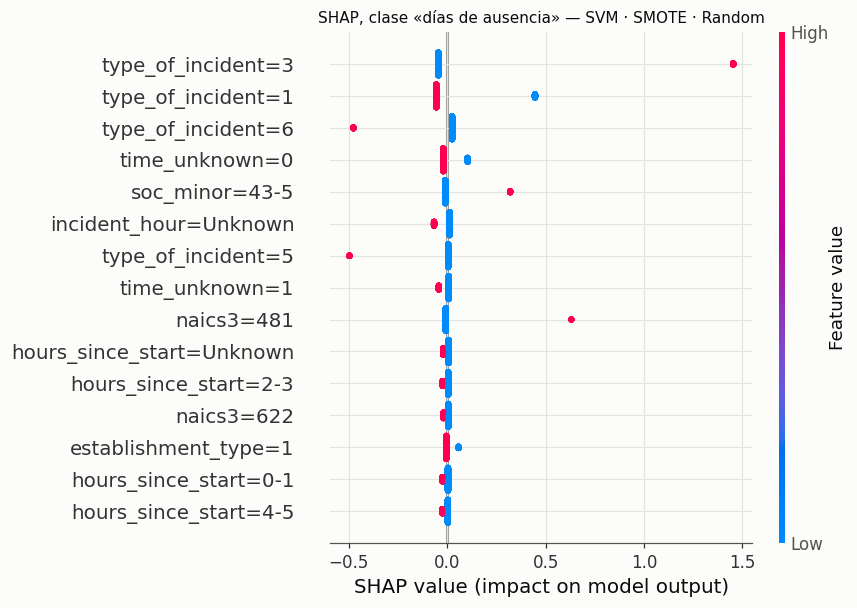

In [3]:
sv1 = sv_c[:, :, CLASS] if sv_c.ndim == 3 else sv_c
plt.figure()
shap.summary_plot(sv1, A_c, feature_names=names, max_display=15, show=False, plot_size=(8, 5.5))
plt.title(f'SHAP, clase «días de ausencia» — {M.PRETTY[bc.model]} · {M.PRETTY[bc.balance]} · {M.PRETTY[bc.optimizer]}', fontsize=10)
P.save(plt.gcf(), 'e3_shap_clf_summary'); plt.show()

In [4]:
imp = pd.DataFrame({C.CLASS_NAMES[k]: np.abs(sv_c[:, :, k]).mean(0) for k in range(sv_c.shape[2])}, index=names) if sv_c.ndim == 3 \
    else pd.DataFrame({'|SHAP| medio': np.abs(sv_c).mean(0)}, index=names)
imp['total'] = imp.sum(axis=1)
by_var = imp.groupby(lambda n: n.split('=')[0]).sum().sort_values('total', ascending=False)
print('Importancia por variable original (suma de |SHAP| medio de sus categorías):')
display(by_var.round(4))
imp.sort_values('total', ascending=False).head(12).round(4)

Importancia por variable original (suma de |SHAP| medio de sus categorías):


,Fallecimiento,Días de ausencia,Traslado/restricción,Otro registrable,total
naics3,0.4397,0.0558,0.2746,0.4950,1.2650
soc_minor,0.2941,0.0533,0.0344,0.2548,0.6366
type_of_incident,0.1873,0.2893,0.0300,0.1042,0.6109
state,0.4556,0.0167,0.0166,0.0148,0.5037
hours_since_start,0.2668,0.0473,0.0883,0.0853,0.4878
incident_hour,0.2967,0.0304,0.0576,0.0566,0.4412
start_hour,0.3463,0.0165,0.0307,0.0297,0.4231
time_unknown,0.1084,0.0454,0.0874,0.0861,0.3273
establishment_type,0.0608,0.0151,0.0283,0.0343,0.1385


,Fallecimiento,Días de ausencia,Traslado/restricción,Otro registrable,total
naics3=622,0.1380,0.0079,0.0194,0.2829,0.4482
time_unknown=0,0.0929,0.0322,0.0621,0.0616,0.2487
type_of_incident=1,0.1154,0.1034,0.0141,0.0065,0.2395
type_of_incident=3,0.0129,0.1229,0.0061,0.0767,0.2185
soc_minor=29-1,0.0348,0.0023,0.0024,0.1720,0.2115
naics3=452,0.0388,0.0040,0.0099,0.1309,0.1836
naics3=713,0.0256,0.0021,0.1249,0.0058,0.1585
state=CA,0.1228,0.0024,0.0021,0.0017,0.1289
soc_minor=53-7,0.1078,0.0039,0.0039,0.0108,0.1263
start_hour=7,0.1124,0.0022,0.0041,0.0039,0.1226


**Interpretación.** El mejor modelo de clasificación según la validación anidada es SVM lineal con SMOTE (búsqueda
aleatoria), así que sus SHAP son exactos y aditivos en la escala de la función de decisión. Para la clase
«días de ausencia» domina el **tipo de incidente**: una enfermedad respiratoria (`type_of_incident=3`)
empuja con fuerza hacia días de ausencia (+1,45), y las enfermedades «otras» (6) y la pérdida auditiva (5)
empujan en contra (−0,5). Le siguen categorías concretas de sector y ocupación (transporte aéreo,
`naics3=481`; ocupaciones de despacho y distribución, `soc_minor=43-5`). Sumando todas las clases, el
orden de las variables es subsector NAICS > grupo SOC > tipo de incidente > estado, el mismo que la V de
Cramér del capítulo 4. Las horas aportan poco. `time_unknown` aparece con peso propio, pero es la misma
información que `incident_hour=Unknown` (sección 4.6): las dos columnas se reparten el crédito.

Las contribuciones a Fallecimiento son grandes y dispersas (estado, hora de inicio, sector). Con 9
fallecimientos reales y miles sintéticos de SMOTE, el modelo aprendió a reconocer las combinaciones de
esos pocos casos, no un patrón general; por eso esas contribuciones no se interpretan.

## 11.2 Clasificación: interpretabilidad local

Dos casos de la muestra explicada: uno bien clasificado como «días de ausencia» con alta
probabilidad, y uno cuya clase real es «días de ausencia» pero que el modelo asignó con
confianza a otra clase (error elevado).

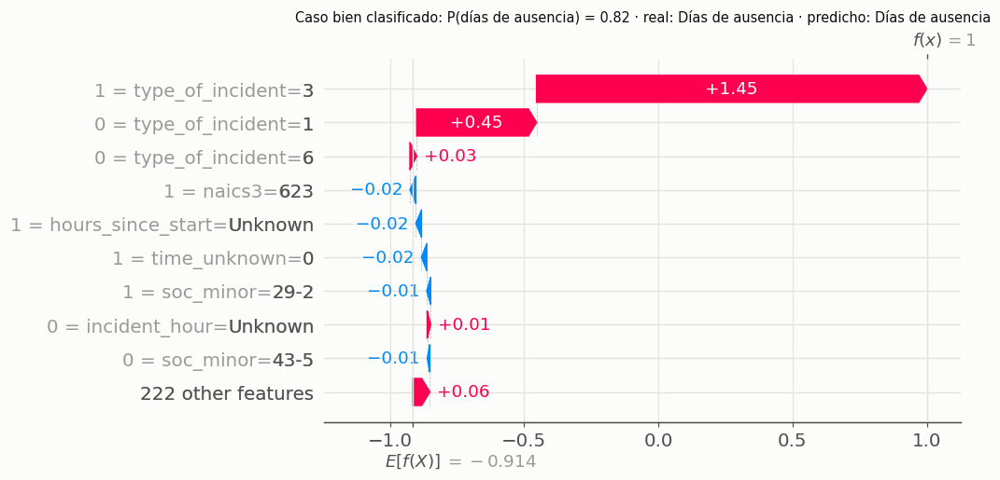

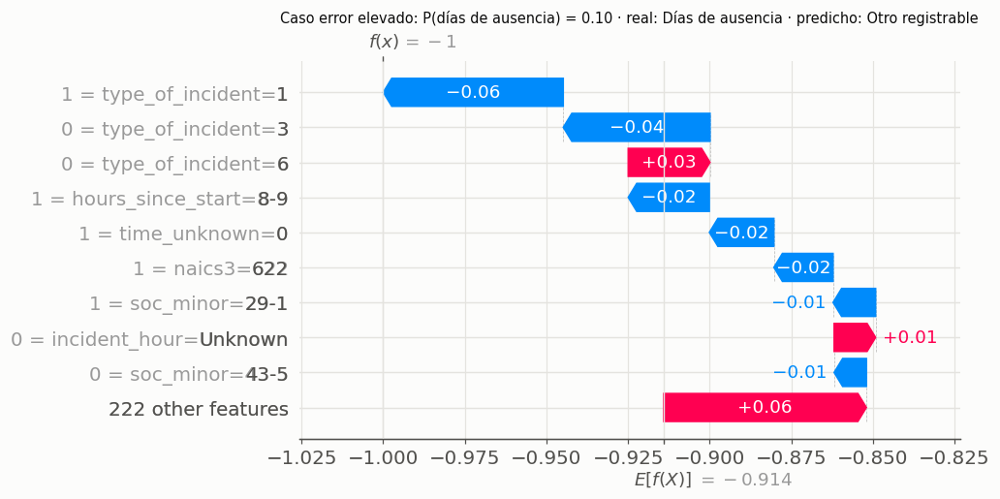

,bien clasificado,error elevado
state,CT,PA
naics3,623,622
establishment_type,1,1
soc_minor,29-2,29-1
type_of_incident,3,1
time_unknown,0,0
start_hour,Unknown,7
incident_hour,12,16
hours_since_start,Unknown,8-9


In [5]:
pc = pipe_c.predict_proba(test_c[D.FEATURES].iloc[ic]); yy = yt_c[ic]
ok = np.where((pc.argmax(1) == CLASS) & (yy == CLASS))[0]; ok = ok[np.argmax(pc[ok, CLASS])]
bad = np.where((pc.argmax(1) != CLASS) & (yy == CLASS))[0]; bad = bad[np.argmin(pc[bad, CLASS])]
for i, title, fname in [(ok, 'bien clasificado', 'e3_shap_clf_waterfall_ok'), (bad, 'error elevado', 'e3_shap_clf_waterfall_error')]:
    b = base_c[CLASS] if np.ndim(base_c) else base_c
    shap.plots.waterfall(shap.Explanation(sv1[i], b, A_c[i], feature_names=names), max_display=10, show=False)
    plt.gcf().set_size_inches(8, 4.6)
    plt.title(f'Caso {title}: P(días de ausencia) = {pc[i, CLASS]:.2f} · real: {C.CLASS_NAMES[yy[i]]} · '
              f'predicho: {C.CLASS_NAMES[pc[i].argmax()]}', fontsize=9.5)
    P.save(plt.gcf(), fname); plt.show()
pd.DataFrame({'bien clasificado': test_c[D.FEATURES].iloc[ic].iloc[ok], 'error elevado': test_c[D.FEATURES].iloc[ic].iloc[bad]})

**Interpretación.** **Caso bien clasificado:** una enfermedad respiratoria de un técnico de salud (`soc_minor=29-2`) en un
centro de cuidados de enfermería (`naics3=623`). La enfermedad respiratoria aporta casi toda la
decisión (+1,45); el resto de variables apenas la mueve. Es el patrón más claro del archivo: muchas
ausencias cortas por enfermedad respiratoria en el sector salud.

**Caso con error elevado:** una lesión (`type_of_incident=1`) de un profesional de la salud
(`soc_minor=29-1`) en un hospital (`naics3=622`) que terminó en días de ausencia, pero el modelo le dio
solo 0,10 de probabilidad y lo clasificó como «otro registrable». Ser lesión y no enfermedad resta, y el
hospital y la ocupación sanitaria también empujan hacia «otro registrable» (en los hospitales muchas
lesiones se registran sin días perdidos). Lo que hizo que este caso terminara en ausencia (la gravedad
de la lesión, la parte del cuerpo, la política del empleador) no está entre las variables del modelo:
el error no es un defecto del ajuste sino un límite de la información disponible.

## 11.3 Regresión: interpretabilidad global y local

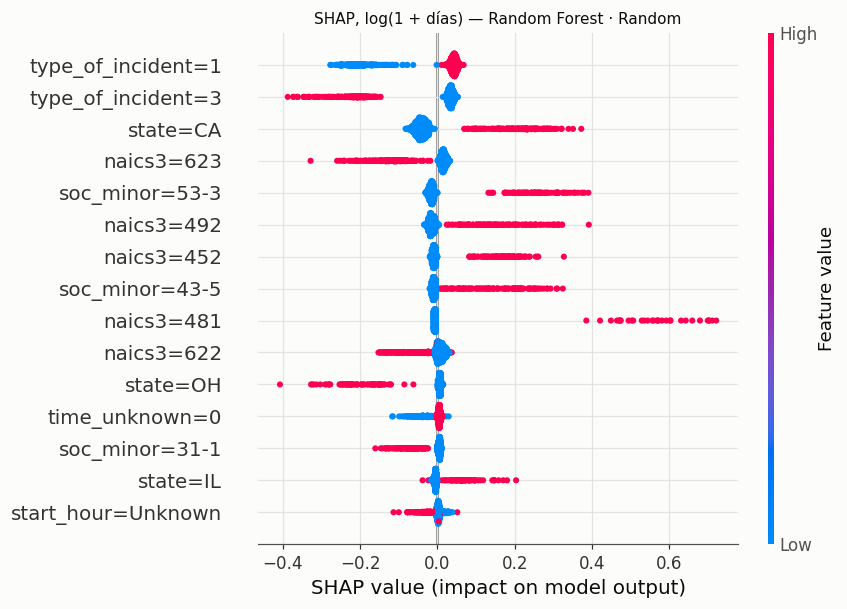

,suma |SHAP| medio
naics3,0.1680
state,0.1487
type_of_incident,0.1406
soc_minor,0.0991
start_hour,0.0471
incident_hour,0.0322
hours_since_start,0.0286
time_unknown,0.0164
establishment_type,0.0039


In [6]:
plt.figure()
shap.summary_plot(sv_r, A_r, feature_names=names_r, max_display=15, show=False, plot_size=(8, 5.5))
plt.title(f'SHAP, log(1 + días) — {M.PRETTY[br.model]} · {M.PRETTY[br.optimizer]}', fontsize=10)
P.save(plt.gcf(), 'e3_shap_reg_summary'); plt.show()
imp_r = pd.Series(np.abs(sv_r).mean(0), index=names_r)
imp_r.groupby(lambda n: n.split('=')[0]).sum().sort_values(ascending=False).round(4).to_frame('suma |SHAP| medio')

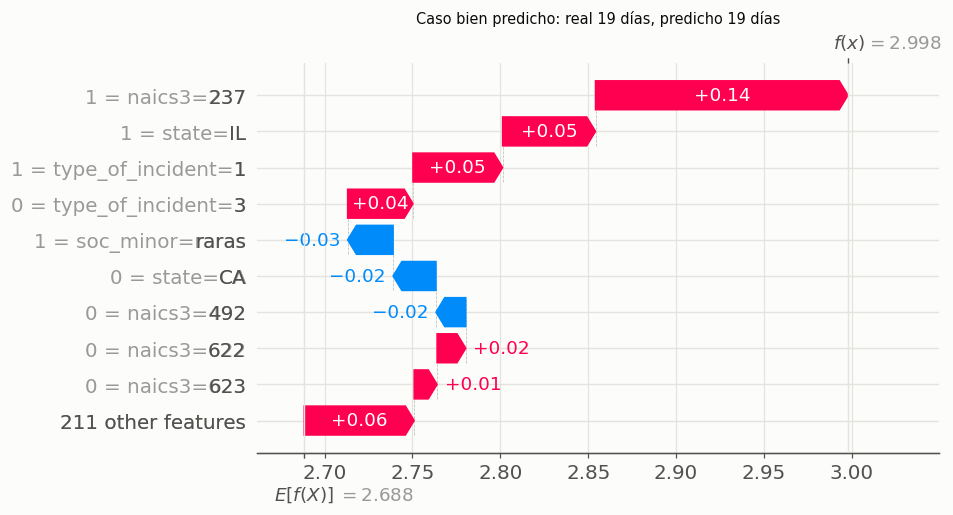

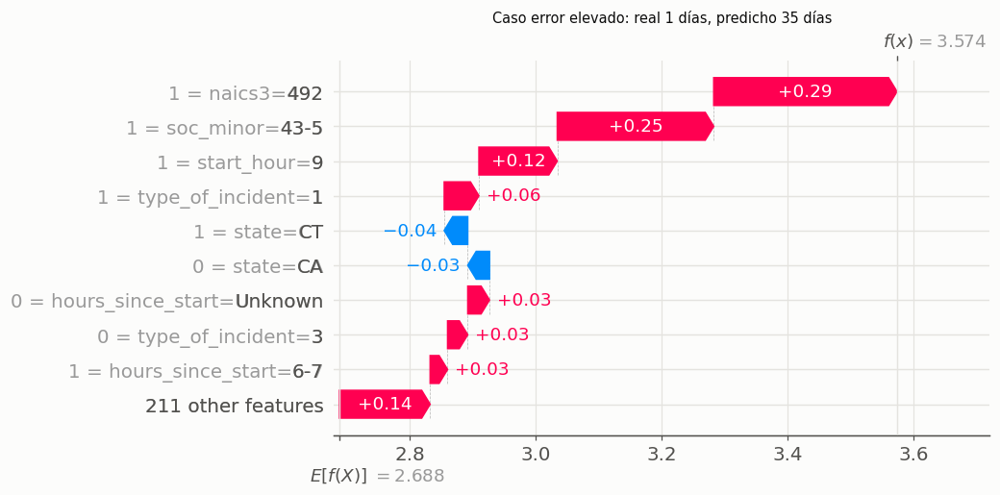

,bien predicho,error elevado
state,IL,CT
naics3,237,492
establishment_type,3,1
soc_minor,47-4,43-5
type_of_incident,1,1
time_unknown,0,0
start_hour,7,9
incident_hour,13,16
hours_since_start,6-7,6-7


In [7]:
pr = pipe_r.predict(test_r[D.FEATURES].iloc[ir]); er = np.abs(yt_r[ir] - pr)
good, worst = int(np.argmin(er)), int(np.argmax(er))
for i, title, fname in [(good, 'bien predicho', 'e3_shap_reg_waterfall_ok'), (worst, 'error elevado', 'e3_shap_reg_waterfall_error')]:
    shap.plots.waterfall(shap.Explanation(sv_r[i], float(np.ravel(base_r)[0]), A_r[i], feature_names=names_r), max_display=10, show=False)
    plt.gcf().set_size_inches(8, 4.6)
    plt.title(f'Caso {title}: real {np.expm1(yt_r[ir][i]):.0f} días, predicho {np.expm1(pr[i]):.0f} días', fontsize=9.5)
    P.save(plt.gcf(), fname); plt.show()
pd.DataFrame({'bien predicho': test_r[D.FEATURES].iloc[ir].iloc[good], 'error elevado': test_r[D.FEATURES].iloc[ir].iloc[worst]})

**Interpretación.** En regresión (Random Forest), las variables más importantes son subsector, estado, tipo de incidente y
grupo ocupacional, con aportes de la misma magnitud (0,10 a 0,17 de |SHAP| medio en log-días); las horas
aportan poco. El estado pesa más que en clasificación, lo que es coherente con la variación entre estados
de la proporción de días de ausencia que mostró el EDA del entregable 2 (23,5 % a 69,2 %), atribuible a
prácticas de registro y a reglas de compensación laboral de cada estado (inferencia, no comprobada).

**Caso bien predicho:** 19 días reales y 19 predichos en un caso de construcción pesada (`naics3=237`) en
Illinois: el subsector sube la predicción por encima del promedio (2,69 en escala log, unos 14 días).
**Caso con error elevado:** 1 día real y 35 predichos. Un trabajador de despacho y distribución
(`soc_minor=43-5`) en mensajería y reparto (`naics3=492`): sector y ocupación están asociados a ausencias
largas en promedio, pero este caso fue una ausencia de un día. El modelo predice el promedio de casos
parecidos y no puede distinguir una ausencia corta de una larga dentro del mismo perfil, otra vez
porque no ve la lesión concreta. Este es el patrón típico del R² bajo del capítulo 10.

## 11.4 XGBoost: SHAP frente a LIME

Se explica el mismo caso con las dos técnicas, para la clase «días de ausencia».

- **SHAP (TreeExplainer)** calcula valores de Shapley exactos para el ensamble de árboles,
  usando la cobertura de cada rama de los árboles (*tree path dependent*). Las contribuciones
  suman exactamente la salida del modelo (log-odds) menos el valor base. Se agregan por variable
  original sumando sus categorías (válido por aditividad) para compararlas con LIME.
- **LIME** perturba el caso (aquí, cambia la categoría de algunas de las 9 variables por otra
  observada en el entrenamiento y pasa cada fila por el pipeline completo), pondera las perturbaciones
  por cercanía y ajusta un modelo **lineal local** sobre la probabilidad. Sus coeficientes
  dependen del núcleo de proximidad, del muestreo y de la semilla, y no tienen por qué sumar la
  predicción.

In [8]:
def run_xgb_explain():
    pipe = S.refit('clf', 'xgboost', json.loads(bx.final_params), bx.balance, Xc, yc, C.SEED)
    rows = test_c[D.FEATURES].iloc[ic[:300]]
    vals, base, A, nm = I.shap_values('clf', 'xgboost', pipe, Xc.sample(1000, random_state=C.SEED), rows)
    return pipe, vals, base, A, nm
pipe_x, sv_x, base_x, A_x, names_x = cache.cached('shap_xgb_v2', run_xgb_explain)
rows_x = test_c[D.FEATURES].iloc[ic[:300]]
px = pipe_x.predict_proba(rows_x)
margin = pipe_x.named_steps['model'].predict(pipe_x.named_steps['onehot'].transform(rows_x), output_margin=True)
print('Aditividad SHAP (máx. |suma SHAP + base − salida del modelo|):',
      float(np.abs(sv_x.sum(axis=1) + base_x - margin).max()))
case = int(np.argmax(px[:, CLASS]))
x_case = rows_x.iloc[[case]]
print(f'Caso explicado: P(días de ausencia) = {px[case, CLASS]:.3f}')
display(x_case.T.rename(columns=lambda c: 'categoría del caso'))

Aditividad SHAP (máx. |suma SHAP + base − salida del modelo|): 1.6689300537109375e-06
Caso explicado: P(días de ausencia) = 0.899


,categoría del caso
state,NC
naics3,622
establishment_type,1
soc_minor,37-2
type_of_incident,3
time_unknown,1
start_hour,Unknown
incident_hour,Unknown
hours_since_start,Unknown


In [9]:
shap_var = I.group_by_variable(sv_x[:, :, CLASS], names_x).iloc[case]
lime_runs = cache.cached('lime_xgb_v2', lambda: [I.lime_explain(pipe_x, Xc.sample(5000, random_state=C.SEED), x_case, CLASS, seed=s)
                                                for s in [C.SEED, C.SEED + 1, C.SEED + 2]])
def lime_by_var(run):
    return pd.Series({k.split('=')[0]: v for k, v in run})
lime_tab = pd.DataFrame({f'LIME semilla {s}': lime_by_var(r) for s, r in zip([C.SEED, C.SEED + 1, C.SEED + 2], lime_runs)}).reindex(D.FEATURES)
comp = pd.DataFrame({'SHAP (log-odds, suma de la variable)': shap_var}).join(lime_tab)
comp['rango SHAP'] = comp.iloc[:, 0].abs().rank(ascending=False)
comp['rango LIME (semilla 42)'] = comp[f'LIME semilla {C.SEED}'].abs().rank(ascending=False)
display(comp.round(4))
from scipy.stats import spearmanr
rho, p = spearmanr(comp.iloc[:, 0].abs(), comp[f'LIME semilla {C.SEED}'].abs())
signs = (np.sign(comp.iloc[:, 0]) == np.sign(comp[f'LIME semilla {C.SEED}'])).mean()
stab = lime_tab.std(axis=1).mean()
print(f'Spearman entre |SHAP| y |LIME| por variable: {rho:.2f} | signos coincidentes: {signs:.0%} | '
      f'd.e. media de LIME entre semillas: {stab:.4f}')

,"SHAP (log-odds, suma de la variable)",LIME semilla 42,LIME semilla 43,LIME semilla 44,rango SHAP,rango LIME (semilla 42)
state,-0.0171,-0.0236,-0.0247,-0.0205,7.0,4.0
naics3,0.0261,-0.0639,-0.0630,-0.0663,6.0,3.0
establishment_type,-0.0130,-0.0846,-0.0759,-0.0679,8.0,2.0
soc_minor,0.0952,0.0119,0.0210,0.0199,3.0,5.0
type_of_incident,1.7438,0.3574,0.3563,0.3596,1.0,1.0
time_unknown,0.1576,0.0039,0.0033,0.0042,2.0,8.0
start_hour,0.0408,0.0043,0.0022,0.0013,4.0,6.0
incident_hour,0.0403,-0.0040,-0.0008,-0.0029,5.0,7.0
hours_since_start,-0.0058,-0.0010,-0.0070,-0.0076,9.0,9.0


Spearman entre |SHAP| y |LIME| por variable: 0.15 | signos coincidentes: 78% | d.e. media de LIME entre semillas: 0.0029


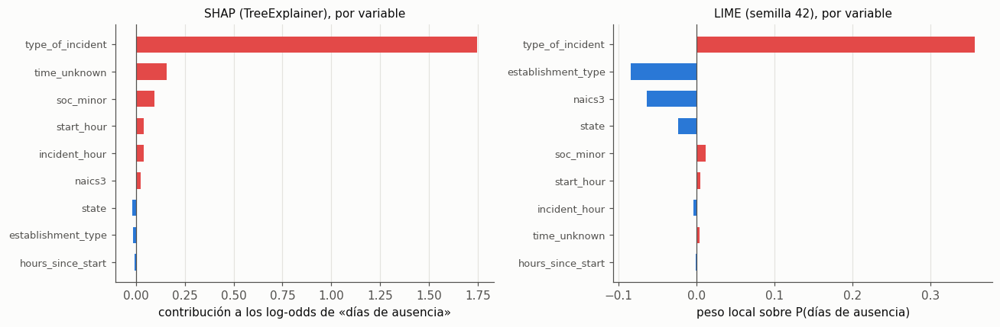

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, s, title, xl in [(axes[0], comp.iloc[:, 0], 'SHAP (TreeExplainer), por variable', 'contribución a los log-odds de «días de ausencia»'),
                         (axes[1], comp[f'LIME semilla {C.SEED}'], 'LIME (semilla 42), por variable', 'peso local sobre P(días de ausencia)')]:
    s = s.reindex(s.abs().sort_values().index)
    ax.barh(range(len(s)), s.values, color=[P.SERIES[7] if v > 0 else P.SERIES[0] for v in s.values], height=0.6)
    ax.set_yticks(range(len(s)), s.index, fontsize=8.5); ax.axvline(0, color=P.INK2, lw=0.8)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.grid(axis='y', visible=False)
fig.tight_layout(); P.save(fig, 'e3_shap_vs_lime'); plt.show()

**Interpretación.** Las dos técnicas coinciden en lo principal: para este caso (una enfermedad respiratoria en un hospital,
P(días de ausencia) = 0,90 con XGBoost), las dos ponen el tipo de incidente en primer lugar y con signo
positivo. En el resto discrepan: la correlación de rangos entre |SHAP| y |LIME| de las 9 variables es
solo 0,15 y los signos coinciden en el 78 % de las variables. SHAP pone en segundo lugar `time_unknown`
(el caso tiene la hora desconocida); LIME casi no le da peso y, en cambio, da peso negativo al tipo de
establecimiento y al subsector, que para SHAP son casi nulos. LIME es estable entre semillas en este caso
(desviación media de 0,003 entre las 3 semillas).

Las diferencias tienen explicación: (1) LIME mide el efecto de *cambiar* una variable a otro valor
típico, en la escala de probabilidad, y promedia ese efecto con un modelo lineal en un vecindario; SHAP
reparte la salida del modelo en log-odds según los caminos de los árboles. (2) `time_unknown`, la hora y
las horas desde el inicio son redundantes: SHAP les asigna crédito a ellas según la estructura de los
árboles, mientras que LIME, al cambiar una sola a la vez, crea filas incoherentes (hora desconocida pero
`time_unknown = 0`) y el modelo apenas reacciona. Con información redundante, ninguna de las dos
atribuciones es «la verdadera»; lo robusto es lo que coincide: el tipo de incidente manda.

**Cuándo divergen.** (1) Con variables correlacionadas (aquí, sector y ocupación describen el
mismo lugar de trabajo), LIME cambia cada variable por separado y genera combinaciones poco
realistas (un hospital con una ocupación de la construcción); SHAP *path dependent* respeta las
divisiones de los árboles, pero reparte el crédito entre variables correlacionadas. (2) Si el
modelo es muy no lineal cerca del caso, la aproximación lineal de LIME es pobre. (3) LIME explica
la *probabilidad* y SHAP aquí explica los *log-odds*: los signos coinciden pero las magnitudes no
son comparables. (4) LIME depende de la semilla y del ancho del núcleo; SHAP para árboles es
determinista.

# 12. Robustez y estabilidad de las métricas

Un número suelto («balanced accuracy = 0,39») esconde dos fuentes de variación: **los datos** (qué
establecimientos caen en cada pliegue) y **el algoritmo** (semillas del bosque, del boosting, del
sobremuestreo y de la búsqueda). Este capítulo mide las dos y las compara con las diferencias entre
modelos.

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from osha_e3 import config as C, models as M, nested as N, seeds as SD, plots as P
P.setup()
mc, mr = N.master_table('clf'), N.master_table('reg')
fc, fr = N.fold_table('clf'), N.fold_table('reg')
st = SD.table()
print('Combinaciones repetidas con otras semillas:', SD.selected_combos())
print('Semillas:', [C.SEED] + SD.SEEDS)

Combinaciones repetidas con otras semillas: [('clf', 'svm', 'smote', 'random'), ('clf', 'svm', 'smote', 'genetic'), ('clf', 'random_forest', 'smote', 'bayes'), ('clf', 'xgboost', 'class_weight', 'bayes'), ('reg', 'random_forest', 'none', 'random'), ('reg', 'random_forest', 'none', 'genetic'), ('reg', 'xgboost', 'none', 'bayes')]
Semillas: [42, 7, 123, 2024]


## 12.1 Media ± desviación estándar en los pliegues externos

Todas las combinaciones (112 + 28) están en las tablas maestras con media y desviación de cada
métrica. Resumen por modelo (mejor combinación de cada uno):

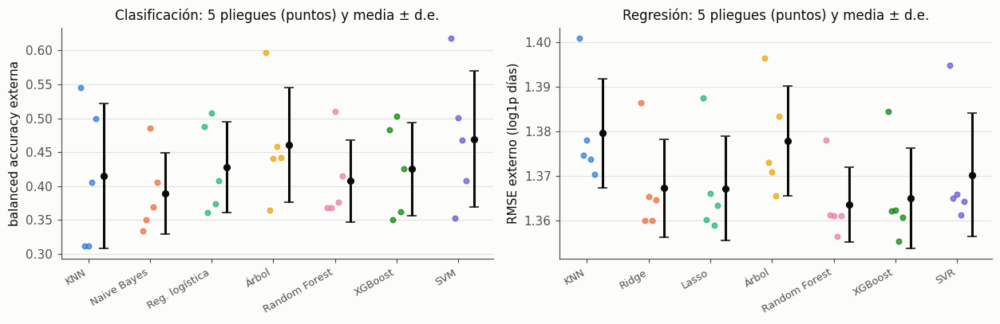

,Clasificación: combinación,balanced acc. (media ± d.e.),AUC (media ± d.e.)
KNN,SMOTE · Genética,0.415 ± 0.107,0.626 ± 0.060
Naive Bayes,ADASYN · Genética,0.389 ± 0.060,0.672 ± 0.064
Reg. logística,ADASYN · Bayesiana (TPE),0.427 ± 0.067,0.728 ± 0.041
Árbol,class_weight · Bayesiana (TPE),0.461 ± 0.084,0.660 ± 0.052
Random Forest,SMOTE · Bayesiana (TPE),0.407 ± 0.060,0.709 ± 0.060
XGBoost,class_weight · Bayesiana (TPE),0.425 ± 0.069,0.723 ± 0.044
SVM,SMOTE · Random,0.469 ± 0.101,0.712 ± 0.051


In [2]:
def best_rows(mt, metric, asc):
    b = mt.loc[mt.groupby('model')[f'outer_{metric}_mean'].idxmin() if asc else mt.groupby('model')[f'outer_{metric}_mean'].idxmax()]
    return b.set_index('model')
bc = best_rows(mc, 'recall', False).reindex(P.MODEL_ORDER_CLF)
br = best_rows(mr, 'rmse', True).reindex(P.MODEL_ORDER_REG)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, b, metric, lab, f in [(axes[0], bc, 'recall', 'balanced accuracy externa', fc), (axes[1], br, 'rmse', 'RMSE externo (log1p días)', fr)]:
    for i, (m, r) in enumerate(b.iterrows()):
        vals = f[(f.model == m) & (f.balance == r.balance) & (f.optimizer == r.optimizer)][f'outer_{metric}']
        ax.scatter(np.full(len(vals), i) + np.linspace(-0.12, 0.12, len(vals)), vals, color=P.MODEL_COLORS[m], s=18, alpha=0.7)
        ax.errorbar(i + 0.25, r[f'outer_{metric}_mean'], yerr=r[f'outer_{metric}_std'], fmt='o', color=P.INK, ms=5, capsize=4)
    ax.set_xticks(range(len(b)), [M.PRETTY[m] for m in b.index], rotation=30, ha='right', fontsize=8.5)
    ax.set_ylabel(lab); ax.grid(axis='x', visible=False)
axes[0].set_title('Clasificación: 5 pliegues (puntos) y media ± d.e.'); axes[1].set_title('Regresión: 5 pliegues (puntos) y media ± d.e.')
fig.tight_layout(); P.save(fig, 'e3_robustez_pliegues'); plt.show()
pd.DataFrame({'Clasificación: combinación': [f'{M.PRETTY[r.balance]} · {M.PRETTY[r.optimizer]}' for _, r in bc.iterrows()],
              'balanced acc. (media ± d.e.)': [f'{r.outer_recall_mean:.3f} ± {r.outer_recall_std:.3f}' for _, r in bc.iterrows()],
              'AUC (media ± d.e.)': [f'{r.outer_auc_mean:.3f} ± {r.outer_auc_std:.3f}' for _, r in bc.iterrows()]},
             index=[M.PRETTY[m] for m in bc.index])

**Interpretación.** La variación entre pliegues externos es grande frente a las diferencias entre modelos. En balanced
accuracy las desviaciones van de ±0,06 (Naive Bayes, Random Forest) a ±0,10–0,11 (SVM y KNN con SMOTE),
mientras que las medias de los 7 modelos caben en un rango de 0,08 (0,389 a 0,469). Los puntos de cada
pliegue (izquierda) muestran que un mismo modelo puede pasar de 0,31 a 0,55 (KNN) o de 0,35 a 0,62 (SVM) según el pliegue: los
pliegues con 3 o 4 fallecimientos premian a los modelos que los marcan masivamente. En AUC la dispersión
es menor (±0,04 a ±0,06) y la logística, XGBoost y SVM quedan arriba (0,71 a 0,73). En regresión, en
cambio, la variación entre pliegues es pequeña (±0,008 a ±0,014 de RMSE) y ordena a los modelos con
claridad.

## 12.2 Sensibilidad a la semilla aleatoria

Para las combinaciones seleccionadas se repitió la validación anidada completa (búsqueda incluida)
con las semillas 7, 123 y 2024, además de la 42. Los datos y los pliegues no cambian: solo la
aleatoriedad del algoritmo. Se compara la desviación **entre semillas** (de la media de los 5
pliegues) con la desviación **entre pliegues**.

In [3]:
metric = {'clf': 'outer_recall', 'reg': 'outer_rmse'}
rows = []
for (t, m, b, o), d in st.groupby(['task', 'model', 'balance', 'optimizer']):
    k = metric[t]
    per_seed = d.groupby('seed')[k].mean()
    rows.append({'tarea': 'Clasificación' if t == 'clf' else 'Regresión',
                 'combinación': f'{M.PRETTY[m]} · {M.PRETTY[b]} · {M.PRETTY[o]}',
                 'semillas': len(per_seed), 'media': per_seed.mean(),
                 'd.e. entre semillas': per_seed.std(ddof=1), 'rango entre semillas': per_seed.max() - per_seed.min(),
                 'd.e. entre pliegues (semilla 42)': d[d.seed == C.SEED][k].std(ddof=1),
                 'hiperparámetros distintos elegidos (de 20 búsquedas)': d.params.nunique()})
seed_tab = pd.DataFrame(rows).set_index(['tarea', 'combinación'])
seed_tab['razón semillas / pliegues'] = seed_tab['d.e. entre semillas'] / seed_tab['d.e. entre pliegues (semilla 42)']
seed_tab.round(4)

semillas   media  \
tarea         combinación                                                  
Clasificación Random Forest · SMOTE · Bayesiana (TPE)          4  0.4033   
              SVM · SMOTE · Genética                           4  0.4118   
              SVM · SMOTE · Random                             4  0.4263   
              XGBoost · class_weight · Bayesiana (TPE)         4  0.4090   
Regresión     Random Forest · Sin balanceo · Genética          4  1.3644   
              Random Forest · Sin balanceo · Random            4  1.3645   
              XGBoost · Sin balanceo · Bayesiana (TPE)         4  1.3649   

                                                        d.e. entre semillas  \
tarea         combinación                                                     
Clasificación Random Forest · SMOTE · Bayesiana (TPE)                0.0042   
              SVM · SMOTE · Genética                                 0.0187   
              SVM · SMOTE · Random                                   0.0321   
              XGBoost · class_weight · Bayesiana (TPE)               0.0114   
Regresión     Random Forest · Sin balanceo · Genética                0.0007   
              Random Forest · Sin balanceo · Random                  0.0009   
              XGBoost · Sin balanceo · Bayesiana (TPE)               0.0007   

                                                        rango entre semillas  \
tarea         combinación                                                      
Clasificación Random Forest · SMOTE · Bayesiana (TPE)                 0.0079   
              SVM · SMOTE · Genética                                  0.0455   
              SVM · SMOTE · Random                                    0.0750   
              XGBoost · class_weight · Bayesiana (TPE)                0.0261   
Regresión     Random Forest · Sin balanceo · Genética                 0.0016   
              Random Forest · Sin balanceo · Random                   0.0022   
              XGBoost · Sin balanceo · Bayesiana (TPE)                0.0017   

                                                        d.e. entre pliegues (semilla 42)  \
tarea         combinación                                                                  
Clasificación Random Forest · SMOTE · Bayesiana (TPE)                             0.0605   
              SVM · SMOTE · Genética                                              0.0539   
              SVM · SMOTE · Random                                                0.1006   
              XGBoost · class_weight · Bayesiana (TPE)                            0.0689   
Regresión     Random Forest · Sin balanceo · Genética                             0.0104   
              Random Forest · Sin balanceo · Random                               0.0084   
              XGBoost · Sin balanceo · Bayesiana (TPE)                            0.0112   

                                                        hiperparámetros distintos elegidos (de 20 búsquedas)  \
tarea         combinación                                                                                      
Clasificación Random Forest · SMOTE · Bayesiana (TPE)                                                  20      
              SVM · SMOTE · Genética                                                                   20      
              SVM · SMOTE · Random                                                                     20      
              XGBoost · class_weight · Bayesiana (TPE)                                                 20      
Regresión     Random Forest · Sin balanceo · Genética                                                  20      
              Random Forest · Sin balanceo · Random                                                    20      
              XGBoost · Sin balanceo · Bayesiana (TPE)                                                 20      

                                                        razón semillas / pliegues  
tarea         co

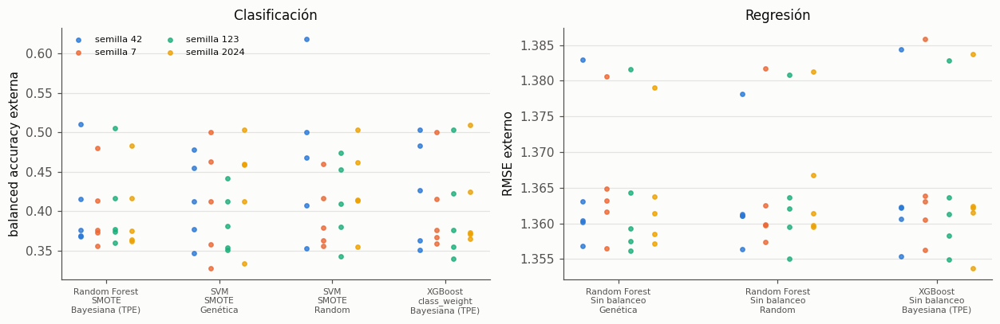

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, t, lab in [(axes[0], 'clf', 'balanced accuracy externa'), (axes[1], 'reg', 'RMSE externo')]:
    d = st[st.task == t]
    combos = list(d.groupby(['model', 'balance', 'optimizer']).groups)
    for i, cmb in enumerate(combos):
        x = d[(d.model == cmb[0]) & (d.balance == cmb[1]) & (d.optimizer == cmb[2])]
        for j, s in enumerate([C.SEED] + SD.SEEDS):
            v = x[x.seed == s][metric[t]]
            ax.scatter(np.full(len(v), i + (j - 1.5) * 0.15), v, s=12, color=P.SERIES[j], label=f'semilla {s}' if i == 0 else None, alpha=0.8)
    ax.set_xticks(range(len(combos)), [f'{M.PRETTY[c[0]]}\n{M.PRETTY[c[1]]}\n{M.PRETTY[c[2]]}' for c in combos], fontsize=7)
    ax.set_ylabel(lab); ax.grid(axis='x', visible=False)
axes[0].legend(fontsize=7.5, ncol=2); axes[0].set_title('Clasificación'); axes[1].set_title('Regresión')
fig.tight_layout(); P.save(fig, 'e3_robustez_semillas'); plt.show()

**Interpretación.** Con los datos fijos, cambiar solo la semilla del algoritmo mueve poco a los modelos estables y mucho a
los inestables:

- **Random Forest con SMOTE** (clasificación) y todas las combinaciones de regresión: desviación entre
  semillas de 0,004 en balanced accuracy y de ≤ 0,001 en RMSE, entre 10 y 15 veces menor que la
  desviación entre pliegues.
- **SVM con SMOTE** es el más sensible: con la búsqueda aleatoria, la media de los 5 pliegues va de unas
  semillas a otras en un rango de 0,075 (desviación 0,032), y con la semilla 42 obtuvo 0,469, la más alta
  de las cuatro (la media de las cuatro semillas es 0,426). Es decir, parte de su primer puesto en la tabla
  maestra se debe a la semilla: SMOTE genera fallecimientos sintéticos distintos con cada semilla y la
  búsqueda aleatoria cae en configuraciones distintas.
- XGBoost con `class_weight` queda en medio (desviación 0,011).
- **Los hiperparámetros elegidos cambian siempre** (20 configuraciones distintas en 20 búsquedas por
  combinación): el paisaje es plano y muchas configuraciones son equivalentes, lo que ya se vio en el
  capítulo 7.

La conclusión práctica: el primer puesto de SVM con SMOTE no es robusto a la semilla, y la combinación
elegida «mejor» por balanced accuracy debe leerse con esa cautela.

## 12.3 ¿Las diferencias entre modelos superan la variabilidad de cada modelo?

Se compara la diferencia entre la mejor combinación y cada una de las demás (en el mismo pliegue,
pareada) con la desviación estándar entre pliegues de cada una. Si la diferencia media es menor que
esa desviación, la diferencia observada no se distingue del ruido de muestreo con estos datos; eso
motiva las pruebas formales del capítulo 13.

In [5]:
def diff_vs_noise(f, mt, metric, higher):
    top = mt.sort_values(f'outer_{metric}_mean', ascending=not higher).iloc[0]
    ref = f[(f.model == top.model) & (f.balance == top.balance) & (f.optimizer == top.optimizer)].set_index('fold')[f'outer_{metric}']
    best = mt.loc[mt.groupby('model')[f'outer_{metric}_mean'].idxmax() if higher else mt.groupby('model')[f'outer_{metric}_mean'].idxmin()]
    rows = []
    for _, r in best.iterrows():
        v = f[(f.model == r.model) & (f.balance == r.balance) & (f.optimizer == r.optimizer)].set_index('fold')[f'outer_{metric}']
        d = (ref - v) if higher else (v - ref)
        rows.append({'modelo': M.PRETTY[r.model], 'diferencia media con el mejor (pareada)': d.mean(),
                     'd.e. de la diferencia': d.std(ddof=1), 'd.e. entre pliegues del modelo': v.std(ddof=1),
                     '¿diferencia > d.e. del modelo?': bool(d.mean() > v.std(ddof=1)), 'pliegues donde el mejor gana': int((d > 0).sum())})
    return pd.DataFrame(rows).set_index('modelo').sort_values('diferencia media con el mejor (pareada)')
print('Clasificación (balanced accuracy):'); display(diff_vs_noise(fc, mc, 'recall', True).round(4))
print('Regresión (RMSE):'); display(diff_vs_noise(fr, mr, 'rmse', False).round(4))

Clasificación (balanced accuracy):


,diferencia media con el mejor (pareada),d.e. de la diferencia,d.e. entre pliegues del modelo,¿diferencia > d.e. del modelo?,pliegues donde el mejor gana
modelo,,,,,
SVM,0.0000,0.0000,0.1006,False,0
Árbol,0.0088,0.0356,0.0843,False,3
Reg. logística,0.0420,0.0659,0.0668,False,2
XGBoost,0.0443,0.0707,0.0689,False,3
KNN,0.0546,0.0998,0.1065,False,4
Random Forest,0.0621,0.1146,0.0605,True,2
Naive Bayes,0.0804,0.1208,0.0603,True,5


Regresión (RMSE):


,diferencia media con el mejor (pareada),d.e. de la diferencia,d.e. entre pliegues del modelo,¿diferencia > d.e. del modelo?,pliegues donde el mejor gana
modelo,,,,,
Random Forest,0.0000,0.0000,0.0084,False,0
XGBoost,0.0014,0.0029,0.0112,False,3
Lasso,0.0036,0.0039,0.0117,False,4
Ridge,0.0037,0.0035,0.0110,False,4
SVR,0.0066,0.0057,0.0139,False,5
Árbol,0.0143,0.0058,0.0123,True,5
KNN,0.0160,0.0051,0.0123,True,5


**Interpretación.** En clasificación, ninguna de las diferencias entre el mejor (SVM con SMOTE) y los demás supera la
desviación entre pliegues del propio modelo salvo en Random Forest y Naive Bayes, y aun en esos el mejor
gana solo en 2 y 5 de los 5 pliegues respectivamente. La logística, XGBoost y el árbol pierden en promedio
por 0,01 a 0,04, menos que su propia variación (0,07 a 0,08). En regresión ocurre al revés: Random Forest
gana a SVR, al árbol y a KNN en los 5 pliegues, y la diferencia con el árbol y con KNN (0,014 a 0,016)
supera la desviación de esos modelos; frente a XGBoost, Lasso y Ridge la diferencia (0,001 a 0,004) es
menor que el ruido. Con diferencias así de pequeñas y tantas comparaciones posibles, mirar las medias no
basta: el capítulo 13 aplica las pruebas formales.

## 12.4 Corrección del entregable 1: la brecha entre entrenamiento y validación

El profesor observó que la brecha del entregable 1 (balanced accuracy de 0,65 en entrenamiento
frente a 0,39 en validación) no se analizó a fondo. Como el balanced accuracy es el promedio del
recall de las 4 clases, la brecha se puede **descomponer por clase**:
brecha = ¼ Σₖ (recallₖ entrenamiento − recallₖ validación).

**(a) La logística del entregable 1.** La corrida con diseño temporal de Iván (sección 12.6)
reprodujo esa logística (C = 1, L2, `class_weight='balanced'`, 1.433 columnas) en los 3 pliegues
hacia adelante del entregable 1 y guardó el recall de Fallecimiento en entrenamiento y validación.

In [6]:
iv = pd.read_csv(C.RESULTS / 'disenio_temporal' / 'master_registry.csv')
e1 = iv[iv.model == 'logreg_e1'][['outer_fold', 'train_deaths', 'valid_deaths', 'train_balanced_accuracy', 'outer_balanced_accuracy',
                                  'train_recall_death', 'outer_recall_death']].copy()
e1['brecha total'] = e1.train_balanced_accuracy - e1.outer_balanced_accuracy
e1['aporte de Fallecimiento (¼ Δ recall)'] = (e1.train_recall_death - e1.outer_recall_death) / 4
e1['aporte de las otras 3 clases'] = e1['brecha total'] - e1['aporte de Fallecimiento (¼ Δ recall)']
e1.set_index('outer_fold').round(3)

,train_deaths,valid_deaths,train_balanced_accuracy,outer_balanced_accuracy,train_recall_death,outer_recall_death,brecha total,aporte de Fallecimiento (¼ Δ recall),aporte de las otras 3 clases
outer_fold,,,,,,,,,
1,16,1,0.670,0.380,1.0,0.0,0.290,0.25,0.040
2,27,3,0.668,0.383,1.0,0.0,0.285,0.25,0.035
3,37,8,0.650,0.392,1.0,0.0,0.258,0.25,0.008


**(b) Los mejores modelos de este entregable.** Para la mejor combinación de cada modelo se
reajusta en el entrenamiento de cada pliegue externo y se mide el recall por clase en ese mismo
entrenamiento y en el pliegue externo.

In [7]:
import json, warnings
from osha_e3 import search as S, data as D, models as MM, evaluation as E, cache
def run_gap():
    X, y, g, s = N.task_data('clf')
    rows = []
    for m, r in bc.iterrows():
        for f, (tr, te) in enumerate(N.outer_folds('clf')):
            pipe = S.refit('clf', m, json.loads(r.final_params), r.balance, X.iloc[tr], y[tr], C.SEED)
            for part, idx in [('entrenamiento', tr), ('validación', te)]:
                pred = pipe.predict_proba(X.iloc[idx]).argmax(1)
                rec = [((pred == k) & (y[idx] == k)).sum() / (y[idx] == k).sum() if (y[idx] == k).any() else np.nan for k in range(4)]
                rows.append({'model': m, 'fold': f, 'parte': part, **{f'recall_{k}': rec[k] for k in range(4)}})
    return pd.DataFrame(rows)
gap = cache.cached('robustez_gap', run_gap)
g = gap.groupby(['model', 'parte'])[[f'recall_{k}' for k in range(4)]].mean().unstack('parte')
out = pd.DataFrame(index=[M.PRETTY[m] for m in P.MODEL_ORDER_CLF])
for k, name in enumerate(C.CLASS_NAMES):
    out[f'recall entren. {name}'] = g[(f'recall_{k}', 'entrenamiento')].reindex(P.MODEL_ORDER_CLF).to_numpy()
    out[f'recall valid. {name}'] = g[(f'recall_{k}', 'validación')].reindex(P.MODEL_ORDER_CLF).to_numpy()
deltas = pd.DataFrame({f'Δ {n}': out[f'recall entren. {n}'] - out[f'recall valid. {n}'] for n in C.CLASS_NAMES})
out['brecha balanced acc.'] = deltas.mean(axis=1)
out['aporte de Fallecimiento'] = deltas[f'Δ {C.CLASS_NAMES[0]}'] / 4
out['aporte de las 3 clases frecuentes'] = out['brecha balanced acc.'] - out['aporte de Fallecimiento']
out.round(3)

,recall entren. Fallecimiento,recall valid. Fallecimiento,recall entren. Días de ausencia,recall valid. Días de ausencia,recall entren. Traslado/restricción,recall valid. Traslado/restricción,recall entren. Otro registrable,recall valid. Otro registrable,brecha balanced acc.,aporte de Fallecimiento,aporte de las 3 clases frecuentes
KNN,1.000,0.812,0.199,0.139,0.555,0.460,0.492,0.462,0.093,0.047,0.046
Naive Bayes,0.848,0.000,0.344,0.338,0.625,0.584,0.565,0.534,0.232,0.212,0.020
Reg. logística,1.000,0.000,0.407,0.377,0.620,0.535,0.637,0.610,0.286,0.250,0.036
Árbol,1.000,0.500,0.267,0.252,0.700,0.641,0.467,0.464,0.144,0.125,0.019
Random Forest,0.971,0.000,0.407,0.346,0.670,0.572,0.652,0.594,0.297,0.243,0.054
XGBoost,1.000,0.125,0.378,0.331,0.734,0.638,0.586,0.547,0.264,0.219,0.045
SVM,1.000,0.500,0.289,0.259,0.599,0.548,0.621,0.590,0.153,0.125,0.028


**Interpretación.** **La brecha del entregable 1 se debe casi entera a Fallecimiento.** En la logística del entregable 1 la
brecha de balanced accuracy entre entrenamiento y validación es de 0,26 a 0,29 en los 3 pliegues, y en
todos el recall de Fallecimiento es 1,0 en entrenamiento y 0 en validación: esa clase aporta 0,25 a la
brecha y las otras tres solo 0,01 a 0,04. Con 1.433 columnas one-hot y `class_weight='balanced'`, el modelo
tiene parámetros suficientes para separar los 16 a 37 fallecimientos del entrenamiento (cada uno pesa
como unos 3.900 casos de las demás clases), pero esa separación es memoria, no un patrón: no reconoce
ninguno de los fallecimientos de validación. En las tres clases frecuentes el modelo casi no sobreajusta.

**En los modelos de este entregable pasa lo mismo, con menos intensidad en algunos.** La brecha va de 0,09
(KNN) a 0,30 (Random Forest), y Fallecimiento aporta entre el 51 % (KNN) y el 91 % (Naive Bayes) de ella: la
logística, Random Forest, XGBoost y Naive Bayes reconocen casi todos los fallecimientos de entrenamiento
(recall 0,85 a 1,0) y muy pocos en validación (0 a 0,13). En las tres clases frecuentes la brecha es de
0,02 a 0,05, típica de un modelo con poca varianza. Agrupar NAICS y SOC (210 columnas en lugar de 1.433)
no basta para evitar que se memoricen 5 a 9 casos. **Conclusión:** el problema no es sobreajuste general,
sino que con menos de 10 ejemplos de una clase no hay patrón que aprender; las métricas de 4 clases
sobrestiman la brecha y el desempeño de entrenamiento, y por eso el informe reporta también las métricas
de las 3 clases frecuentes.

## 12.5 Corrección del entregable 1: ¿qué pasa si se quita `time_unknown`?

`time_unknown` supera el umbral de colinealidad (sección 4.6). Se reajusta la mejor combinación de
cada modelo **sin esa variable** en los 5 pliegues externos (mismos hiperparámetros) y se compara,
pliegue a pliegue, con el resultado original.

In [8]:
def run_ablation():
    X, y, g, s = N.task_data('clf')
    Xd = X.drop(columns=['time_unknown'])
    rows = []
    for m, r in bc.iterrows():
        for f, (tr, te) in enumerate(N.outer_folds('clf')):
            for label, XX in [('con time_unknown', X), ('sin time_unknown', Xd)]:
                pipe = MM.make_pipeline('clf', m, json.loads(r.final_params), r.balance, C.SEED)
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    pipe.fit(XX.iloc[tr], y[tr])
                met = E.classification_metrics(y[te], pipe.predict_proba(XX.iloc[te]))
                rows.append({'model': m, 'fold': f, 'variante': label, **met})
    return pd.DataFrame(rows)
abl = cache.cached('robustez_ablation_time_unknown', run_ablation)
rows = []
for m in P.MODEL_ORDER_CLF:
    a = abl[(abl.model == m) & (abl.variante == 'con time_unknown')].set_index('fold')
    b = abl[(abl.model == m) & (abl.variante == 'sin time_unknown')].set_index('fold')
    rows.append({'modelo': M.PRETTY[m], **{f'Δ {k} (sin − con)': (b[k] - a[k]).mean() for k in ['recall', 'f1', 'auc', 'log_loss']},
                 'd.e. entre pliegues (balanced acc.)': a.recall.std(ddof=1)})
pd.DataFrame(rows).set_index('modelo').round(4)

,Δ recall (sin − con),Δ f1 (sin − con),Δ auc (sin − con),Δ log_loss (sin − con),d.e. entre pliegues (balanced acc.)
modelo,,,,,
KNN,0.0136,0.0012,0.0163,0.0057,0.0685
Naive Bayes,0.0024,0.0029,0.0207,-0.0307,0.0601
Reg. logística,0.0015,0.0010,-0.0034,0.0003,0.0593
Árbol,0.0000,0.0000,0.0055,0.0000,0.0795
Random Forest,0.0001,-0.0001,0.0017,-0.0008,0.0617
XGBoost,0.0011,0.0026,0.0010,0.0004,0.0604
SVM,0.0003,0.0001,0.0007,0.0011,0.0813


**Interpretación.** Quitar `time_unknown` no cambia nada relevante: las diferencias en balanced accuracy, F1 y AUC van de 0 a
0,02, todas mucho menores que la desviación entre pliegues (0,06 a 0,08); en el árbol la diferencia es
exactamente 0 (nunca usó esa variable) y en Random Forest y SVM es de una milésima. Los cambios mayores
son en KNN y Naive Bayes, que mejoran ligeramente sin ella (AUC +0,016 y +0,021): son los dos modelos que
tratan todas las columnas por igual (distancias o independencia), así que contar dos veces la misma
información (hora desconocida) les perjudica. Coherente con el umbral de colinealidad del entregable 1,
**la variable sobra**: no aporta información y en dos modelos estorba un poco. No se reentrenaron las 140
combinaciones sin ella (no cambiaría las conclusiones y costaría otra corrida completa); queda anotado
como decisión para cualquier modelo que se use después.

## 12.6 Diseño alternativo: validación anidada con pliegues temporales (corrida de Iván Berrio)

En paralelo, Iván corrió una validación anidada con otro diseño (tablas en
`results/disenio_temporal/`): 3 pliegues externos **hacia adelante en el tiempo** (los del
entregable 1), NAICS y SOC completos con el agrupamiento de categorías raras como hiperparámetro,
búsqueda en el 25 % del entrenamiento externo (con todas las muertes) y reentrenamiento con el
100 %, 20 evaluaciones por optimizador y SMOTE/ADASYN solo sobre Fallecimiento. KNN ×
`class_weight` no se corrió (108 combinaciones). Comparar los dos diseños indica qué conclusiones
dependen de cómo se valida.

Combinaciones comunes: 108
Spearman entre diseños (balanced accuracy): rho = 0.48 (p = 1.7e-07)
Spearman entre diseños (AUC macro): rho = 0.77 (p = 2.1e-22)
Spearman entre diseños (F1 macro): rho = 0.65 (p = 3.4e-14)


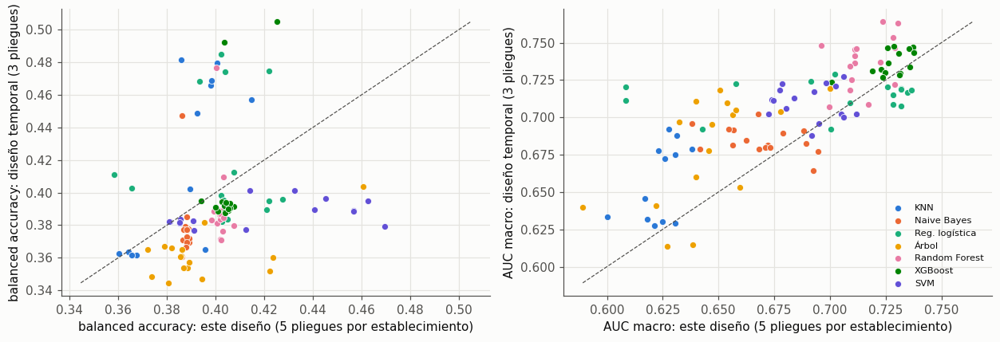

,model,balance,optimizer,deaths,hits,pred_death,prec_death,BA_pooled
98,xgboost,class_weight,bayes,12,8,5337,0.0015,0.5160
99,xgboost,class_weight,genetic,12,6,3950,0.0015,0.4826
53,random_forest,class_weight,random,12,6,6256,0.0010,0.4720
17,logreg,class_weight,bayes,12,4,2205,0.0018,0.4543
9,knn,smote,bayes,12,5,3138,0.0016,0.4479
50,random_forest,class_weight,bayes,12,4,2527,0.0016,0.4460


In [9]:
from scipy.stats import spearmanr
pooled = pd.read_csv(C.RESULTS / 'disenio_temporal' / 'pooled_summary.csv')
ivm = iv[~iv.model.isin(['dummy', 'logreg_e1'])].groupby(['model', 'balance', 'optimizer']).agg(
    ba_temporal=('outer_balanced_accuracy', 'mean'), auc_temporal=('outer_roc_auc_macro_ovr', 'mean'),
    f1_temporal=('outer_f1_macro', 'mean')).reset_index()
both = mc.merge(ivm, on=['model', 'balance', 'optimizer'])
print('Combinaciones comunes:', len(both))
for a, b, lab in [('outer_recall_mean', 'ba_temporal', 'balanced accuracy'), ('outer_auc_mean', 'auc_temporal', 'AUC macro'),
                  ('outer_f1_mean', 'f1_temporal', 'F1 macro')]:
    rho, p = spearmanr(both[a], both[b])
    print(f'Spearman entre diseños ({lab}): rho = {rho:.2f} (p = {p:.2g})')
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for ax, a, b, lab in [(axes[0], 'outer_recall_mean', 'ba_temporal', 'balanced accuracy'), (axes[1], 'outer_auc_mean', 'auc_temporal', 'AUC macro')]:
    for m in P.MODEL_ORDER_CLF:
        x = both[both.model == m]
        ax.scatter(x[a], x[b], color=P.MODEL_COLORS[m], s=28, label=M.PRETTY[m], edgecolor='white', linewidth=0.5)
    lo = min(both[a].min(), both[b].min()); hi = max(both[a].max(), both[b].max())
    ax.plot([lo, hi], [lo, hi], color=P.INK2, ls='--', lw=0.8)
    ax.set_xlabel(f'{lab}: este diseño (5 pliegues por establecimiento)'); ax.set_ylabel(f'{lab}: diseño temporal (3 pliegues)')
axes[1].legend(fontsize=7.5, loc='lower right')
fig.tight_layout(); P.save(fig, 'e3_robustez_disenios'); plt.show()
top_iv = pooled[~pooled.model.isin(['dummy'])].sort_values('BA_pooled', ascending=False).head(6)
top_iv[['model', 'balance', 'optimizer', 'deaths', 'hits', 'pred_death', 'prec_death', 'BA_pooled']].round(4)

**Interpretación.** **Los dos diseños coinciden en lo que importa y discrepan en el balanced accuracy.** Sobre las 108
combinaciones comunes, el ordenamiento por AUC macro es bastante parecido entre diseños (Spearman 0,77), el
de F1 macro razonablemente (0,65) y el de balanced accuracy solo moderadamente (0,48). Es lo esperado: AUC y
F1 dependen poco de Fallecimiento y el balanced accuracy depende mucho, y cada diseño tiene muy pocos
fallecimientos en sus pliegues (12 en total en el temporal; 9 en esta submuestra).

La corrida temporal llega a la misma advertencia por otro camino: su mejor balanced accuracy (0,516,
XGBoost con `class_weight` y búsqueda bayesiana) acierta 8 de 12 fallecimientos marcando 5.337 casos como
fallecimiento (precisión del 0,15 %). Las seis combinaciones con mejor balanced accuracy en ese diseño
tienen la misma firma: miles de casos marcados para acertar 4 a 8 fallecimientos. **Conclusiones robustas
a los dos diseños:** (1) el desempeño en las clases frecuentes es moderado (AUC ~0,70); (2) ningún modelo
detecta Fallecimiento de forma útil; (3) las combinaciones «ganadoras» por balanced accuracy lo son por
marcar Fallecimiento masivamente, no por clasificar mejor.

El modelo original (PT-bagging) y sus iteraciones se evaluaron en este mismo diseño temporal: ver el
[capítulo 17](17_modelo_original.ipynb).

# 13. Comparación estadística de los modelos

Con 140 modelos hay 9.730 pares posibles. Probar todos los pares con α = 0,05 daría unos 487 falsos
positivos solo por azar. Por eso la comparación es jerárquica:

- **Clasificación:** Friedman (¿algún modelo difiere?) → Nemenyi y diagrama de Diferencia Crítica →
  DeLong solo entre los finalistas, con corrección de Holm → tamaño del efecto (delta de Cliff).
- **Regresión:** Model Confidence Set sobre las 28 combinaciones → Giacomini-White o Clark-West
  entre los finalistas → Diebold-Mariano (HLN) entre el primero y el segundo, con bootstrap
  estacionario → tamaño del efecto (d de Cohen). Como control de *data snooping*, SPA de Hansen.
- Intervalos de confianza bootstrap (BCa cuando la métrica es una razón de sumas; percentiles para
  AUC) remuestreando **establecimientos completos**.

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from osha_e3 import config as C, models as M, nested as N, final as F, evaluation as E, stats_tests as T, plots as P, cache
P.setup()
fc, fr = N.fold_table('clf'), N.fold_table('reg')
mc, mr = N.master_table('clf'), N.master_table('reg')
test_c, yt_c = F.test_data('clf'); test_r, yt_r = F.test_data('reg')
MODELS_C, MODELS_R = P.MODEL_ORDER_CLF, P.MODEL_ORDER_REG

## 13.1 Clasificación, etapa 1: prueba ómnibus de Friedman

**(a) Las 112 combinaciones** sobre los 5 pliegues externos (bloques), con la balanced accuracy
externa. **(b) Los 7 modelos** (mejor combinación de cada uno según la validación anidada) sobre
14 bloques semanales de la prueba (de lunes a domingo; la primera y la última semana están
incompletas): con solo 5 bloques Nemenyi tiene muy poca potencia, y las
semanas de octubre a diciembre son bloques naturales (independientes del ajuste y ordenados en
el tiempo). **(c) Los 4 optimizadores y las 4 técnicas de balanceo**, con bloques = (modelo ×
balanceo × pliegue) y (modelo × optimizador × pliegue).

In [2]:
pv112 = fc.pivot_table(index='fold', columns=['model', 'balance', 'optimizer'], values='outer_recall')
fr112 = T.friedman(pv112.to_numpy())
best_c = mc.loc[mc.groupby('model').outer_recall_mean.idxmax()].set_index('model').reindex(MODELS_C)
probs = {m: F.load('clf', best_c.loc[m, 'combo'])[0] for m in MODELS_C}
week = pd.to_datetime(test_c.date).dt.to_period('W').astype(str).to_numpy()
weeks = sorted(set(week))
W = pd.DataFrame({M.PRETTY[m]: [balanced_accuracy_score(yt_c[week == w], probs[m][week == w].argmax(1)) for w in weeks] for m in MODELS_C}, index=weeks)
fr7 = T.friedman(W.to_numpy())
pv_opt = fc.pivot_table(index=['model', 'balance', 'fold'], columns='optimizer', values='outer_recall')[M.OPTIMIZERS]
pv_bal = fc.pivot_table(index=['model', 'optimizer', 'fold'], columns='balance', values='outer_recall')[M.BALANCES]
fr_opt, fr_bal = T.friedman(pv_opt.to_numpy()), T.friedman(pv_bal.to_numpy())
pd.DataFrame([
    {'Comparación': '112 combinaciones (bloques: 5 pliegues externos)', 'χ²_F': fr112['chi2'], 'g.l.': fr112['df'], 'p-valor': fr112['p_value'], 'N bloques': fr112['n_blocks']},
    {'Comparación': '7 modelos (bloques: 14 semanas de la prueba)', 'χ²_F': fr7['chi2'], 'g.l.': fr7['df'], 'p-valor': fr7['p_value'], 'N bloques': fr7['n_blocks']},
    {'Comparación': '4 optimizadores (bloques: modelo × balanceo × pliegue)', 'χ²_F': fr_opt['chi2'], 'g.l.': fr_opt['df'], 'p-valor': fr_opt['p_value'], 'N bloques': fr_opt['n_blocks']},
    {'Comparación': '4 balanceos (bloques: modelo × optimizador × pliegue)', 'χ²_F': fr_bal['chi2'], 'g.l.': fr_bal['df'], 'p-valor': fr_bal['p_value'], 'N bloques': fr_bal['n_blocks']},
]).set_index('Comparación').round(5)

,χ²_F,g.l.,p-valor,N bloques
Comparación,,,,
112 combinaciones (bloques: 5 pliegues externos),175.15131,111,0.00010,5
7 modelos (bloques: 14 semanas de la prueba),19.50000,6,0.00340,14
4 optimizadores (bloques: modelo × balanceo × pliegue),9.90984,3,0.01935,140
4 balanceos (bloques: modelo × optimizador × pliegue),7.31143,3,0.06261,140


**Interpretación.** - **112 combinaciones sobre los 5 pliegues:** Friedman rechaza la igualdad (χ² = 175,2 con 111 g.l.,
  p = 0,0001): al menos una combinación difiere de las demás.
- **7 modelos sobre las semanas de la prueba:** también rechaza (χ² = 19,5 con 6 g.l., p = 0,003).
- **Optimizadores:** rechaza con α = 0,05 (χ² = 9,9, p = 0,019), aunque el efecto es pequeño (sección 13.4).
- **Balanceos:** no rechaza (χ² = 7,3, p = 0,063): con balanced accuracy no hay evidencia de que alguna
  técnica de balanceo sea mejor que las otras de forma sistemática. Con AUC macro sí hay diferencias
  (Friedman p = 2·10⁻⁹; `class_weight` es la peor en AUC, rango 3,04, y SMOTE la mejor, 2,04), lo que
  repite que el balanceo cambia el umbral más que la capacidad de ordenar.

Como las pruebas globales rechazan, se pasa al análisis post-hoc.

## 13.2 Clasificación, etapa 2: Nemenyi y diagramas de Diferencia Crítica

Rango promedio: 1 = mejor. Dos modelos unidos por una barra horizontal no difieren
significativamente según Nemenyi (α = 0,05).

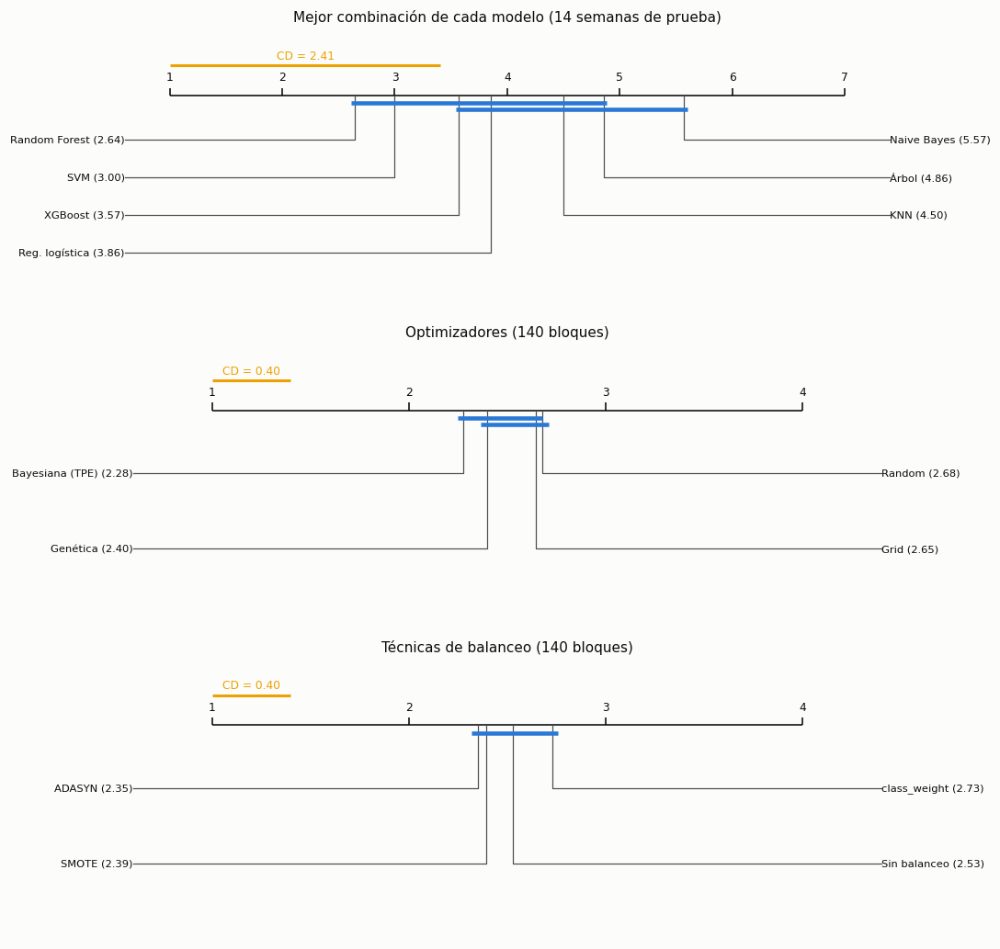

112 combinaciones: CD = 89.4 rangos (sobre 112). Mejor rango promedio 26.2; combinaciones cuyo rango no difiere del mejor: 112 de 112.
Rangos promedio, 7 modelos: {'KNN': 4.5, 'Naive Bayes': 5.57, 'Reg. logística': 3.86, 'Árbol': 4.86, 'Random Forest': 2.64, 'XGBoost': 3.57, 'SVM': 3.0} | CD = 2.41


In [3]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9.5))
cd7 = T.nemenyi_cd(fr7['k'], fr7['n_blocks'])
T.cd_diagram(list(W.columns), fr7['avg_ranks'], cd7, axes[0], f'Mejor combinación de cada modelo ({fr7["n_blocks"]} semanas de prueba)')
cdo = T.nemenyi_cd(fr_opt['k'], fr_opt['n_blocks'])
T.cd_diagram([M.PRETTY[o] for o in M.OPTIMIZERS], fr_opt['avg_ranks'], cdo, axes[1], f'Optimizadores ({fr_opt["n_blocks"]} bloques)')
cdb = T.nemenyi_cd(fr_bal['k'], fr_bal['n_blocks'])
T.cd_diagram([M.PRETTY[b] for b in M.BALANCES], fr_bal['avg_ranks'], cdb, axes[2], f'Técnicas de balanceo ({fr_bal["n_blocks"]} bloques)')
fig.tight_layout(); P.save(fig, 'e3_stats_cd'); plt.show()
cd112 = T.nemenyi_cd(fr112['k'], fr112['n_blocks'])
r112 = pd.Series(fr112['avg_ranks'], index=pv112.columns).sort_values()
print(f'112 combinaciones: CD = {cd112:.1f} rangos (sobre 112). Mejor rango promedio {r112.iloc[0]:.1f}; '
      f'combinaciones cuyo rango no difiere del mejor: {(r112 - r112.iloc[0] < cd112).sum()} de 112.')
print('Rangos promedio, 7 modelos:', dict(zip(W.columns, np.round(fr7['avg_ranks'], 2))), '| CD =', round(cd7, 2))

**Interpretación.** - **112 combinaciones:** con solo 5 bloques, la diferencia crítica de Nemenyi es de 89 rangos sobre 112:
  **ninguna** combinación se distingue estadísticamente de la mejor. Friedman detecta que hay
  diferencias en conjunto, pero 5 pliegues no alcanzan para decir cuáles. Es la limitación que ya anunció
  el capítulo 12 y la razón para comparar las mejores de cada familia sobre bloques más numerosos.
- **7 modelos (14 semanas de prueba):** rangos Random Forest 2,64, SVM 3,00, XGBoost 3,57, logística
  3,86, KNN 4,50, árbol 4,86 y Naive Bayes 5,57, con CD = 2,41. Solo Random Forest difiere
  significativamente de Naive Bayes; los demás pares quedan unidos por las barras (estadísticamente
  equivalentes). Random Forest y SVM encabezan, pero no se separan de XGBoost ni de la logística.
- **Optimizadores:** el bayesiano tiene el mejor rango (2,28) y solo se separa de Random (2,68; diferencia
  0,40, justo en el límite de la CD de 0,40); genético y Grid quedan unidos con todos.
- **Balanceos:** una sola barra une las cuatro técnicas: son equivalentes.

## 13.3 Clasificación: DeLong entre los finalistas, con Holm

Se comparan los tres mejores modelos según el rango de Friedman en la prueba (3 pares). DeLong
compara AUC binarias, así que se aplica a cada clase una contra el resto (4 clases × 3 pares = 12
pruebas) y se ajustan los 12 p-valores con Holm-Bonferroni (y Benjamini-Hochberg como
referencia). El intervalo de la diferencia de AUC es un bootstrap de establecimientos (200 réplicas).

In [4]:
rank7 = pd.Series(fr7['avg_ranks'], index=MODELS_C).sort_values()
final3 = list(rank7.index[:3])
groups = test_c.establishment_id.to_numpy()
codes, uniq = pd.factorize(groups)
def run_delong():
    rows = []
    rng = np.random.default_rng(C.seed_for('bootstrap', 1))
    boots = [np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes] for _ in range(200)]
    for i in range(3):
        for j in range(i + 1, 3):
            a, b = final3[i], final3[j]
            for k in range(4):
                yk = (yt_c == k)
                d = T.delong_test(yk, probs[a][:, k], probs[b][:, k])
                diffs = [roc_auc_score(yk, probs[a][:, k], sample_weight=w) - roc_auc_score(yk, probs[b][:, k], sample_weight=w) for w in boots]
                lo, hi = np.percentile(diffs, [2.5, 97.5])
                rows.append({'Modelo A': M.PRETTY[a], 'Modelo B': M.PRETTY[b], 'Clase': C.CLASS_NAMES[k], 'AUC A': d['auc1'], 'AUC B': d['auc2'],
                             'Diferencia de AUC': d['diff'], 'IC 95 % bootstrap': f'[{lo:.4f}, {hi:.4f}]', 'z': d['z'], 'p crudo': d['p_value']})
    out = pd.DataFrame(rows)
    out['p Holm'] = T.adjust(out['p crudo'].to_numpy(), 'holm'); out['p BH'] = T.adjust(out['p crudo'].to_numpy(), 'fdr_bh')
    return out
dl = cache.cached('stats_delong', run_delong)
dl.round(4)

,Modelo A,Modelo B,Clase,AUC A,AUC B,Diferencia de AUC,IC 95 % bootstrap,z,p crudo,p Holm,p BH
0,Random Forest,SVM,Fallecimiento,0.6695,0.7203,-0.0508,"[-0.1035, 0.0024]",-1.6990,0.0893,0.2680,0.1072
1,Random Forest,SVM,Días de ausencia,0.6828,0.6374,0.0454,"[0.0405, 0.0506]",34.6540,0.0000,0.0000,0.0000
2,Random Forest,SVM,Traslado/restricción,0.7103,0.6752,0.0350,"[0.0308, 0.0383]",35.6850,0.0000,0.0000,0.0000
3,Random Forest,SVM,Otro registrable,0.7233,0.6797,0.0436,"[0.0377, 0.0478]",39.7508,0.0000,0.0000,0.0000
4,Random Forest,XGBoost,Fallecimiento,0.6695,0.6223,0.0472,"[-0.0471, 0.1243]",1.0307,0.3027,0.4130,0.3027
5,Random Forest,XGBoost,Días de ausencia,0.6828,0.6888,-0.0060,"[-0.0086, -0.0033]",-7.4136,0.0000,0.0000,0.0000
6,Random Forest,XGBoost,Traslado/restricción,0.7103,0.7094,0.0008,"[-0.0018, 0.0031]",1.2632,0.2065,0.4130,0.2253
7,Random Forest,XGBoost,Otro registrable,0.7233,0.7307,-0.0074,"[-0.0097, -0.0053]",-12.8579,0.0000,0.0000,0.0000
8,SVM,XGBoost,Fallecimiento,0.7203,0.6223,0.0981,"[0.0127, 0.1747]",2.4288,0.0151,0.0606,0.0202
9,SVM,XGBoost,Días de ausencia,0.6374,0.6888,-0.0514,"[-0.0567, -0.0464]",-38.2282,0.0000,0.0000,0.0000


**Interpretación.** Se compararon los tres modelos con mejor rango en la prueba (Random Forest, SVM y XGBoost) en las 4
clases (12 pruebas, Holm). Con 127.391 casos, DeLong detecta diferencias muy pequeñas:

- **Random Forest supera a SVM** en las tres clases frecuentes (AUC +0,035 a +0,045; IC bootstrap lejos
  de 0; Holm p < 0,001).
- **XGBoost supera a SVM** en las tres clases frecuentes (+0,034 a +0,051, Holm p < 0,001).
- **Random Forest frente a XGBoost:** XGBoost es mejor en «días de ausencia» y en «otro registrable»
  (+0,006 y +0,007, Holm p < 0,001) y empatan en «traslado/restricción» (p = 0,41). Son diferencias
  significativas pero prácticamente irrelevantes (menos de una centésima de AUC).
- **Fallecimiento:** ninguna diferencia es significativa tras Holm (p ajustados 0,06 a 0,41); los IC de
  la diferencia van de −0,10 a +0,17. Con 39 casos no se puede ordenar a los modelos en esa clase.

Holm y Benjamini-Hochberg llevan a las mismas conclusiones. La lectura conjunta con 13.2: el «ganador»
en balanced accuracy (SVM) **ordena peor** las clases frecuentes que Random Forest y XGBoost; su ventaja
venía del umbral sobre Fallecimiento, no de discriminar mejor.

## 13.4 Clasificación: tamaño del efecto (delta de Cliff)

Sobre las balanced accuracy semanales (14 semanas) entre todos los pares de los 7 modelos, y entre
los optimizadores y las técnicas de balanceo sobre sus bloques. |δ| < 0,147 despreciable,
< 0,33 pequeño, < 0,474 mediano, si no grande. Se reportan todos los pares, favorables o no.

In [5]:
rows = []
for i, a in enumerate(W.columns):
    for b in W.columns[i + 1:]:
        d = T.cliffs_delta(W[a], W[b])
        rows.append({'A': a, 'B': b, 'media A − B (balanced acc.)': (W[a] - W[b]).mean(), 'δ de Cliff': d, 'magnitud': T.cliffs_label(d)})
cl7 = pd.DataFrame(rows)
for tab, lab in [(pv_opt, 'optimizador'), (pv_bal, 'balanceo')]:
    for i, a in enumerate(tab.columns):
        for b in tab.columns[i + 1:]:
            d = T.cliffs_delta(tab[a], tab[b])
            rows.append({'A': M.PRETTY[a], 'B': M.PRETTY[b], 'media A − B (balanced acc.)': (tab[a] - tab[b]).mean(), 'δ de Cliff': d, 'magnitud': T.cliffs_label(d)})
pd.DataFrame(rows).round(4)

,A,B,media A − B (balanced acc.),δ de Cliff,magnitud
0,KNN,Naive Bayes,0.0036,0.0306,despreciable
1,KNN,Reg. logística,-0.0176,-0.0612,despreciable
2,KNN,Árbol,0.0021,0.0204,despreciable
3,KNN,Random Forest,-0.0160,-0.0714,despreciable
4,KNN,XGBoost,-0.0079,0.0000,despreciable
5,KNN,SVM,-0.0426,-0.3163,pequeño
6,Naive Bayes,Reg. logística,-0.0212,-0.4898,grande
7,Naive Bayes,Árbol,-0.0015,0.1020,despreciable
8,Naive Bayes,Random Forest,-0.0197,-0.5000,grande
9,Naive Bayes,XGBoost,-0.0115,-0.4286,mediano


**Interpretación.** Los tamaños de efecto sobre las semanas de prueba matizan las pruebas:

- Entre los modelos, los efectos **grandes** son de Naive Bayes frente a la logística y a Random Forest
  (δ ≈ −0,50) y **medianos** frente a XGBoost y SVM (≈ −0,43). Random Forest frente a XGBoost es pequeño
  (δ = 0,20) y la mayoría de pares entre logística, Random Forest, XGBoost y SVM son pequeños o
  despreciables.
- **Optimizadores:** todos los pares son despreciables (|δ| ≤ 0,06), aunque Friedman detectara una
  diferencia: con 140 bloques una diferencia pequeña ya es «significativa». Es el caso típico en que la
  significación no implica relevancia práctica.
- **Balanceos:** todos despreciables (|δ| ≤ 0,13).

Se reportan todos los pares, incluidos los que no favorecen a ningún modelo.

## 13.5 Regresión, paso 1: Model Confidence Set sobre las 28 combinaciones

Pérdida: error cuadrático en la prueba, promediado por día (92 días de octubre a diciembre) para
tener una serie temporal; el bootstrap estacionario (bloques de longitud media 7 días) respeta el
patrón semanal. MCS con estadístico de rango (*range*), α = 0,10, 5.000 réplicas.

In [6]:
preds_r = {}
for c in mr.combo:
    preds_r[c] = F.load('reg', c)[0].astype(float)
dates = pd.to_datetime(test_r.date).to_numpy()
sq = pd.DataFrame({c: (yt_r - p) ** 2 for c, p in preds_r.items()}, index=dates)
daily = sq.groupby(level=0).mean()
daily.columns = [c.replace('|none|', ' · ') for c in daily.columns]
mcs = cache.cached('stats_mcs', lambda: T.model_confidence_set(daily, alpha=0.10, reps=5000, block=7, seed=C.seed_for('bootstrap', 2)))
mcs['RMSE prueba'] = np.sqrt(mcs.avg_loss)
mcs.round(4)

,p_value_mcs,in_mcs,avg_loss,RMSE prueba
Model name,,,,
random_forest · grid,1.0000,True,1.2915,1.1365
xgboost · genetic,0.6362,True,1.2921,1.1367
random_forest · bayes,0.5964,True,1.2929,1.1371
random_forest · random,0.0488,False,1.2940,1.1375
xgboost · random,0.0082,False,1.2961,1.1385
xgboost · bayes,0.0126,False,1.2965,1.1386
random_forest · genetic,0.0000,False,1.2983,1.1394
xgboost · grid,0.0000,False,1.2997,1.1400
ridge · grid,0.0000,False,1.3015,1.1409


**Interpretación.** Con α = 0,10 el conjunto de confianza queda formado por **tres combinaciones**: Random Forest con Grid
(p = 1,00), XGBoost con el genético (0,64) y Random Forest con el bayesiano (0,60). Random Forest con
Random queda justo fuera (p = 0,049) y todos los modelos lineales, SVR, el árbol y KNN quedan
excluidos con p ≈ 0. Esto filtra las 28 combinaciones a un subconjunto defendible: **los ensambles de
árboles**. (El RMSE de esta tabla promedia primero por día, por eso difiere en milésimas del RMSE por
caso del capítulo 10.)

## 13.6 Regresión, pasos 2 y 3: comparaciones dirigidas entre finalistas

- **Clark-West** cuando un modelo está anidado en otro. La referencia «media del entrenamiento»
  (modelo con solo intercepto) está anidada en Ridge y en Lasso; se contrasta si las variables
  aportan capacidad predictiva real.
- **Giacomini-White** (habilidad predictiva condicional, instrumentos = constante y diferencial de
  pérdida del día anterior) entre finalistas no anidados.
- **Diebold-Mariano con corrección HLN** entre el mejor y el segundo del MCS, con IC del diferencial
  medio por bootstrap estacionario y d de Cohen.

Los p-valores de este bloque se ajustan con Holm.

In [7]:
order_mcs = list(mcs.index)
finalists = list(mcs[mcs.in_mcs].index) if mcs.in_mcs.sum() >= 2 else order_mcs[:3]
finalists = finalists[:4]
key = {c.replace('|none|', ' · '): c for c in mr.combo}
rows = []
yd = pd.Series(yt_r, index=dates)
mean_pred = np.full_like(yt_r, N.task_data('reg')[1].mean())
for name in [n for n in order_mcs if n.startswith('ridge') or n.startswith('lasso')][:2]:
    cw = T.clark_west(yt_r, mean_pred, preds_r[key[name]])
    rows.append({'prueba': 'Clark-West (anidados)', 'A': 'media del entrenamiento', 'B': name, 'estadístico': cw['t'], 'p crudo': cw['p_value'],
                 'diferencial medio': cw['mean_adj_diff'], 'unidad': 'por caso'})
for i in range(len(finalists)):
    for j in range(i + 1, len(finalists)):
        a, b = finalists[i], finalists[j]
        gw = T.giacomini_white(daily[a].to_numpy(), daily[b].to_numpy())
        rows.append({'prueba': 'Giacomini-White', 'A': a, 'B': b, 'estadístico': gw['stat'], 'p crudo': gw['p_value'],
                     'diferencial medio': gw['mean_diff'], 'unidad': 'diaria'})
a, b = order_mcs[0], order_mcs[1]
dm = T.diebold_mariano(daily[a].to_numpy(), daily[b].to_numpy(), h=1)
lo, hi = T.stationary_bootstrap_ci(daily[a] - daily[b], reps=5000, block=7, seed=C.seed_for('bootstrap', 3))
rows.append({'prueba': 'Diebold-Mariano (HLN)', 'A': a, 'B': b, 'estadístico': dm['dm_hln'], 'p crudo': dm['p_value'],
             'diferencial medio': dm['mean_diff'], 'unidad': 'diaria'})
dir_tab = pd.DataFrame(rows)
dir_tab['p Holm'] = T.adjust(dir_tab['p crudo'].to_numpy())
print(f'DM {a} vs {b}: diferencial medio diario {dm["mean_diff"]:.5f}, IC 95 % bootstrap estacionario [{lo:.5f}, {hi:.5f}], '
      f'd de Cohen {T.cohens_d_paired(daily[a] - daily[b]):.3f}')
dir_tab.round(5)

DM random_forest · grid vs xgboost · genetic: diferencial medio diario -0.00058, IC 95 % bootstrap estacionario [-0.00300, 0.00142], d de Cohen -0.055


,prueba,A,B,estadístico,p crudo,diferencial medio,unidad,p Holm
0,Clark-West (anidados),media del entrenamiento,ridge · grid,71.19798,0.00000,0.26305,por caso,0.0000
1,Clark-West (anidados),media del entrenamiento,ridge · random,71.12127,0.00000,0.26389,por caso,0.0000
2,Giacomini-White,random_forest · grid,xgboost · genetic,0.38194,0.82616,-0.00068,diaria,1.0000
3,Giacomini-White,random_forest · grid,random_forest · bayes,3.91057,0.14152,-0.00136,diaria,0.5661
4,Giacomini-White,xgboost · genetic,random_forest · bayes,1.74871,0.41713,-0.00068,diaria,1.0000
5,Diebold-Mariano (HLN),random_forest · grid,xgboost · genetic,-0.52643,0.59987,-0.00058,diaria,1.0000


**Interpretación.** - **Clark-West:** frente al modelo anidado que solo predice la media del entrenamiento, Ridge tiene
  capacidad predictiva adicional clara (t ≈ 71, p < 0,001): las variables sí aportan, aunque poco
  (R² ≈ 0,06).
- **Giacomini-White** entre los tres finalistas del MCS: ningún par difiere (p de 0,14 a 0,83, todos
  1,00 o 0,57 tras Holm): no hay un modelo condicionalmente mejor según la pérdida del día anterior.
- **Diebold-Mariano (HLN)** entre el primero y el segundo del MCS (Random Forest con Grid y XGBoost con el
  genético): estadístico −0,53, p = 0,60. La diferencia media diaria de pérdida (−0,0006) tiene un IC de
  bootstrap estacionario de [−0,0030; 0,0014], que incluye el 0, y una d de Cohen de −0,06 (despreciable).
  **Random Forest y XGBoost son indistinguibles en regresión.**

## 13.7 Regresión: control de *data snooping* (SPA de Hansen y Reality Check)

¿Alguna de las 28 combinaciones supera de verdad a una referencia simple, o la aparente mejora se
debe a haber probado muchas? Referencia: la media del entrenamiento. H0: ninguna combinación es
mejor que la referencia. Se reportan los p-valores inferior, consistente y superior de SPA (el
superior equivale al Reality Check de White).

In [8]:
bench = pd.Series((yt_r - mean_pred) ** 2, index=dates).groupby(level=0).mean()
spa = cache.cached('stats_spa', lambda: T.spa_test(bench.to_numpy(), daily.to_numpy(), reps=5000, block=7, seed=C.seed_for('bootstrap', 4)))
pd.Series(spa, name='p-valor SPA').to_frame().round(4)

,p-valor SPA
lower,0.0
consistent,0.0
upper,0.0


**Interpretación.** SPA rechaza con p ≈ 0 en sus tres versiones (inferior, consistente y superior; la superior equivale al
Reality Check de White): al menos una de las 28 combinaciones supera a la media del entrenamiento aun
teniendo en cuenta que se probaron 28. La mejora de los modelos sobre la referencia no es producto de
haber buscado entre muchos. Es una mejora real pero pequeña (RMSE de 1,14 frente a 1,19 en la prueba).

## 13.8 Intervalos de confianza al 95 % (bootstrap por establecimiento)

- Accuracy (clasificación) y RMSE/MAE (regresión): **BCa** sobre establecimientos, con el
  estadístico como razón de sumas (aciertos / casos; errores cuadráticos / casos).
- AUC macro: percentiles de 200 réplicas de establecimientos (BCa requiere el jackknife, que con
  34.000 establecimientos y AUC es demasiado costoso).

In [9]:
def run_ci():
    rows = []
    gc = test_c.establishment_id.to_numpy(); gr = test_r.establishment_id.to_numpy()
    rng = np.random.default_rng(C.seed_for('bootstrap', 5))
    codes, uniq = pd.factorize(gc)
    boots = [np.bincount(rng.integers(0, len(uniq), len(uniq)), minlength=len(uniq))[codes] for _ in range(200)]
    for m in MODELS_C:
        p = probs[m]; correct = (p.argmax(1) == yt_c).astype(float)
        lo, hi = T.group_bca_ci(correct, np.ones_like(correct), gc, reps=2000, seed=C.SEED)
        rows.append({'Tarea': 'Clasificación', 'Modelo': M.PRETTY[m], 'Métrica': 'Accuracy', 'Estimación': correct.mean(), 'IC inferior': lo, 'IC superior': hi, 'Método': 'BCa'})
        aucs = [roc_auc_score(yt_c, p, multi_class='ovr', average='macro', sample_weight=w) for w in boots]
        rows.append({'Tarea': 'Clasificación', 'Modelo': M.PRETTY[m], 'Métrica': 'AUC macro', 'Estimación': roc_auc_score(yt_c, p, multi_class='ovr', average='macro'),
                     'IC inferior': np.percentile(aucs, 2.5), 'IC superior': np.percentile(aucs, 97.5), 'Método': 'percentil (200)'})
    best_r = mr.loc[mr.groupby('model').outer_rmse_mean.idxmin()].set_index('model').reindex(MODELS_R)
    for m in MODELS_R:
        p = preds_r[best_r.loc[m, 'combo']]; se = (yt_r - p) ** 2
        lo, hi = T.group_bca_ci(se, np.ones_like(se), gr, reps=2000, seed=C.SEED)
        rows.append({'Tarea': 'Regresión', 'Modelo': M.PRETTY[m], 'Métrica': 'RMSE', 'Estimación': np.sqrt(se.mean()), 'IC inferior': np.sqrt(lo), 'IC superior': np.sqrt(hi), 'Método': 'BCa'})
        ae = np.abs(yt_r - p); lo, hi = T.group_bca_ci(ae, np.ones_like(ae), gr, reps=2000, seed=C.SEED)
        rows.append({'Tarea': 'Regresión', 'Modelo': M.PRETTY[m], 'Métrica': 'MAE', 'Estimación': ae.mean(), 'IC inferior': lo, 'IC superior': hi, 'Método': 'BCa'})
    return pd.DataFrame(rows)
ci = cache.cached('stats_ci', run_ci)
ci.set_index(['Tarea', 'Modelo', 'Métrica']).round(4)

Estimación  IC inferior  IC superior  \
Tarea         Modelo         Métrica                                           
Clasificación KNN            Accuracy       0.3842       0.3779       0.3912   
                             AUC macro      0.6240       0.5974       0.6490   
              Naive Bayes    Accuracy       0.4992       0.4927       0.5057   
                             AUC macro      0.6898       0.6670       0.7120   
              Reg. logística Accuracy       0.5147       0.5082       0.5212   
                             AUC macro      0.6993       0.6803       0.7167   
              Árbol          Accuracy       0.4405       0.4339       0.4472   
                             AUC macro      0.6277       0.6125       0.6448   
              Random Forest  Accuracy       0.5194       0.5132       0.5263   
                             AUC macro      0.6965       0.6772       0.7140   
              XGBoost        Accuracy       0.5107       0.5040       0.5177   
                             AUC macro      0.6878       0.6663       0.7095   
              SVM            Accuracy       0.4794       0.4723       0.4865   
                             AUC macro      0.6782       0.6617       0.6981   
Regresión     KNN            RMSE           1.1659       1.1538       1.1782   
                             MAE            0.9571       0.9428       0.9700   
              Ridge          RMSE           1.1511       1.1392       1.1622   
                             MAE            0.9432       0.9291       0.9553   
              Lasso          RMSE           1.1494       1.1375       1.1611   
                             MAE            0.9422       0.9281       0.9546   
              Árbol          RMSE           1.1534       1.1410       1.1648   
                             MAE            0.9418       0.9273       0.9539   
              Random Forest  RMSE           1.1431       1.1313       1.1549   
                             MAE            0.9310       0.9171       0.9440   
              XGBoost        RMSE           1.1437       1.1314       1.1553   
                             MAE            0.9345       0.9202       0.9468   
              SVR            RMSE           1.1512       1.1391       1.1622   
                             MAE            0.9451       0.9309       0.9571   

                                                 Método  
Tarea         Modelo         Métrica                     
Clasificación KNN            Accuracy               BCa  
                             AUC macro  percentil (200)  
              Naive Bayes    Accuracy               BCa  
                             AUC macro  percentil (200)  
              Reg. logística Accuracy               BCa  
                             AUC macro  percentil (200)  
              Árbol          Accuracy               BCa  
                             AUC macro  percentil (200)  
              Random Forest  Accuracy               BCa  
                             AUC macro  percentil (200)  
              XGBoost        Accuracy               BCa  
                             AUC macro  percentil (200)  
              SVM            Accuracy               BCa  
                             AUC macro  percentil (200)  
Regresión     KNN            RMSE                   BCa  
                             MAE                    BCa  
              Ridge          RMSE                   BCa  
                             MAE                    BCa  
              Lasso          RMSE                   BCa  
                             MAE                    BCa  
              Árbol          RMSE                   BCa  
                             MAE                    BCa  
              Random Forest  RMSE                   BCa  
                             MAE                    BCa  
              XGBoost        RMSE                   BCa  
                             MAE                    BCa  
              S

**Interpretación.** - **Clasificación:** el accuracy se estima con mucha precisión (IC de ±0,007); los IC de Random Forest
  (0,513 a 0,526), la logística (0,508 a 0,521) y XGBoost (0,504 a 0,518) se solapan. El AUC macro tiene
  IC más anchos (±0,02) porque incluye a Fallecimiento: la logística (0,680 a 0,717), Random Forest (0,677
  a 0,714), Naive Bayes y XGBoost se solapan entre sí y quedan por encima de KNN y el árbol (0,60 a 0,65).
- **Regresión:** RMSE de Random Forest (1,131 a 1,155) y XGBoost (1,131 a 1,155) prácticamente
  idénticos; los modelos lineales y SVR (≈ 1,139 a 1,162) se solapan con ellos, y KNN (1,154 a 1,178)
  es el único claramente peor.

**Síntesis del capítulo.** Siguiendo la secuencia jerárquica: (1) en clasificación hay diferencias
globales, pero solo Random Forest frente a Naive Bayes es significativa con Nemenyi; DeLong muestra que
Random Forest y XGBoost ordenan mejor las clases frecuentes que el «ganador» por balanced accuracy, y
ningún modelo se separa en Fallecimiento; (2) en regresión el MCS se queda con los ensambles de árboles,
que son indistinguibles entre sí, y todos superan de forma real pero pequeña a la referencia. Ningún
modelo destaca con una diferencia grande y estable; las diferencias significativas son de magnitud
pequeña.

# 13b. Mejores combinaciones, reentrenamiento final y artefactos

Este capítulo cumple el Bloque B de la guía (§4). De las 112 combinaciones de clasificación elige la mejor de cada uno
de los 7 modelos con un criterio estadístico. Luego las reentrena y las serializa para el dashboard, y verifica que el
modelo cargado desde disco prediga exactamente lo mismo que el modelo en memoria.

## 13b.1 Criterio de selección

- **Métrica:** la **balanced accuracy (BA) media del bucle externo** de la validación anidada (5 pliegues por
  establecimiento). Es la métrica principal del proyecto (capítulo 6) y la misma que optimizó la búsqueda interna.
- **Por modelo:** para cada uno de los 7 modelos se elige la combinación (balanceo, optimizador) con mayor BA media.
  Los empates se resuelven por menor desviación estándar (no hubo empates).
- **Nunca se usa la prueba (octubre–diciembre) para elegir.**

| Modelo | Balanceo | Optimizador | BA externa (media ± d.e.) | Motivo de la selección |
|---|---|---|---|---|
| SVM lineal | SMOTE | Random | **0,469 ± 0,101** | Mayor BA media de las 16 combinaciones de SVM; **mejor combinación global** |
| Árbol de decisión | `class_weight` | Bayesiana (TPE) | 0,461 ± 0,084 | Mayor BA media de las 16 del árbol |
| Regresión logística | ADASYN | Bayesiana (TPE) | 0,427 ± 0,067 | Mayor BA media de las 16 de la logística |
| XGBoost | `class_weight` | Bayesiana (TPE) | 0,425 ± 0,069 | Mayor BA media de las 16 de XGBoost |
| KNN | SMOTE | Genética | 0,415 ± 0,107 | Mayor BA media de las 16 de KNN |
| Random Forest | SMOTE | Bayesiana (TPE) | 0,407 ± 0,060 | Mayor BA media de las 16 de Random Forest |
| Naive Bayes | ADASYN | Genética | 0,389 ± 0,060 | Mayor BA media de las 16 de Naive Bayes |

Fuente: `results/master_clf.csv`, columna `outer_recall_mean` (la balanced accuracy es el recall macro). Las 112 filas
con todas las métricas están en la tabla de líderes del dashboard y en `dashboard_final/data/leaderboard.csv`.

**Pertenencia de la mejor global al conjunto de finalistas.** En el capítulo 13 (sección 13.2), Friedman rechaza la
igualdad de las 112 combinaciones (p = 0,0001). Sin embargo, con 5 bloques la diferencia crítica de Nemenyi es de 89
rangos, y **ninguna combinación se distingue de la mejor**: todas pertenecen al conjunto de finalistas, también
SVM + SMOTE + Random. Entre los 7 mejores (14 semanas de bloques), SVM tiene el segundo mejor rango (3,00) y queda unida
por la barra de Nemenyi a Random Forest (2,64), que encabeza. La mejor global por BA media está, entonces, en el grupo de
cabeza que no se puede separar estadísticamente. Las diferencias entre las 7 mejores son pequeñas frente a su
variabilidad por pliegue (d.e. de 0,06 a 0,11), que viene sobre todo de la clase Fallecimiento: 0 a 4 casos por pliegue.

## 13b.2 Reentrenamiento final y serialización

Cada combinación elegida se **reentrena** con sus hiperparámetros finales (los del pliegue externo con mejor puntaje
interno, `nested.master_table`) sobre el **conjunto de entrenamiento completo**: la submuestra de desarrollo de 30 030
casos (ene–sep 2023), el mismo conjunto con el que se ajustaron los modelos de los capítulos 6 a 13. El pipeline
completo (one-hot que agrupa las categorías raras → SMOTE/ADASYN o pesos → modelo) se guarda con
`joblib.dump(..., compress=3)` en `dashboard_final/artifacts/`. Lo hace `scripts/build_artifacts.py curso`. El dashboard
**nunca reentrena ni optimiza**: solo carga estos archivos.

Junto a cada modelo se guarda `<modelo>.metadata.json` con:

- las versiones de Python y de cada librería;
- la semilla (42);
- los hiperparámetros finales;
- el **esquema de entrada** (nombre, tipo, número de valores y lista de valores válidos de cada variable);
- las métricas del bucle externo (media y d.e.);
- el tiempo de ajuste, el tiempo de inferencia por caso y el resultado de la prueba de ida y vuelta.

| Artefacto | Tamaño (MB) | Ajuste (s) | Inferencia (ms/caso) | Ida y vuelta |
|---|---|---|---|---|
| `svm.joblib` | 0,08 | 4,1 | 0,013 | idéntica |
| `tree.joblib` | 0,01 | 0,5 | 0,010 | idéntica |
| `logreg.joblib` | 0,01 | 34,6 | 0,012 | idéntica |
| `xgboost.joblib` | 0,68 | 3,8 | 0,053 | idéntica |
| `knn.joblib` | 0,57 | 4,2 | 1,299 | idéntica |
| `random_forest.joblib` | 2,59 | 24,9 | 0,110 | idéntica |
| `naive_bayes.joblib` | 0,01 | 14,5 | 0,011 | idéntica |
| `original.joblib` (capítulo 19) | ver `original.metadata.json` | — | — | idéntica |

**Prueba de ida y vuelta.** Para cada artefacto se predicen las probabilidades de **500 casos fijos del desarrollo que
no están en la submuestra de entrenamiento** (semilla 42), primero con el modelo en memoria y luego con el modelo
recién cargado desde disco. El script exige igualdad exacta (`np.array_equal`) y se detiene si falla. Los 8 artefactos
dan diferencia máxima 0. La prueba de octubre a diciembre no se usa (está bloqueada; capítulo 00, fila B1).

**Tamaño y memoria en Render.** Todos los artefactos suman unos 4 MB más el del modelo original. El Random Forest
(212 árboles de profundidad 25) pesa 2,6 MB comprimido, así que no hizo falta podar árboles ni usar Git LFS. Las
versiones de `numpy`, `pandas`, `scipy`, `scikit-learn`, `imbalanced-learn`, `xgboost` y `joblib` del dashboard
(`dashboard_final/requirements.txt`) son las mismas con las que se entrenaron los artefactos, para que `joblib` los cargue
sin diferencias.


# 16. Revisión de literatura y novedad del modelo original

> **Dos modelos en este capítulo.**
> Las secciones 16.1 a 16.5 documentan la revisión del **primer candidato** (PT-bagging, capítulo 17), que no superó a los
> benchmarks y quedó como modelo explorado. Las secciones 16.6 a 16.9 documentan la revisión del **modelo original final**
> (SECR, capítulos 19 y 20) y su declaración de novedad. Las cifras salen de las exportaciones de las búsquedas o de las
> respuestas guardadas de cada consulta; no se completó nada de memoria.

> **Secciones 16.1 a 16.5: histórico.**
> Estas secciones documentan la revisión del **primer candidato** (PT-bagging). Se conservan como registro, pero ya no
> describen el modelo original final. **Las secciones vigentes son 16.6 a 16.9** (SECR).

El primer candidato a modelo original fue **PT-bagging** (*probability thresholding bagging*). Fue propuesto por Collell, Prelec y Patil
(*Neurocomputing*, 2018; versión previa en arXiv, 2016). El método combina tres pasos: bagging de árboles sin podar
entrenados con la distribución natural de las clases, promedio de sus probabilidades y decisión
`argmax P(k|x)/λ_k`, donde `λ_k` es la proporción de la clase *k*. El modelo, sus fórmulas y sus resultados están en
el capítulo 17. Este capítulo documenta cómo se buscó si el método ya se había aplicado al problema: clasificar el
desenlace de un caso registrable de OSHA (Fallecimiento, Días de ausencia, Traslado o restricción, Otro).

La novedad que se reclama es de **aplicación**, no de algoritmo: PT-bagging ya existe. Lo que se buscó es si alguien
lo había usado para clasificar la gravedad de lesiones laborales.

## 16.1 Búsquedas realizadas

| # | Fecha | Base | Cadena | Resultados | Revisados | Relevantes | Observación |
|---|---|---|---|---|---|---|---|
| 1 | 2026-10-20 | Web of Science | `("occupational injury" OR "workplace injury" OR "work-related injury" OR OSHA) AND (severity OR outcome OR hospitali* OR fatal*) AND ("machine learning" OR classification OR prediction)`, 2005–2026 | 140 | 140 (búsqueda de texto en título y resumen exportados) | pendiente de registrar | Aplicación. Ningún registro menciona *bagging*, *threshold-moving*, prior de clase, Random Balance, metaclasificación ni modelos ordinales. Uno usa pérdida focal (aprendizaje profundo sobre narrativas de construcción, 2024). 34 mencionan OSHA y ninguno el *Injury Tracking Application* (ITA). |
| 2 | 2026-10-20 | Web of Science | **pendiente: la cadena no quedó guardada** | 374 | 374 (búsqueda de texto) | pendiente de registrar | Modelos para datos desbalanceados. De aquí salen PT-bagging (doi 10.1016/j.neucom.2017.08.035) y MultiRandBal (doi 10.1016/j.knosys.2019.105434). Solo 1 registro menciona OSHA. |
| 3 | 2026-10-21 | Scopus | `TITLE-ABS-KEY(("occupational injury" OR OSHA) AND ("voting" OR "soft voting" OR "stacking") AND (severity OR outcome))` | 2 | 2 | 1 | Mermer, Zhang y Demir (2026) usan stacking y voting en accidentes agrícolas. El otro resultado no es de aprendizaje automático. La cadena revisa una familia descartada (ensambles por votación), no PT-bagging. |
| 4 | 2026-10-21 | Consensus (Semantic Scholar, OpenAlex, PubMed) | `bagging threshold moving class prior imbalanced classification occupational injury severity` | 10 (máximo que muestra el plan) | 10 | 3 | Aparecen el artículo del método (Collell et al., 2018 y 2016). En lesiones, Sarkar et al. (2020, acería) y Luo et al. (2023, construcción) usan sobremuestreo y Random Forest; Jeong et al. (2018, tránsito) usan bagging con sobremuestreo. Ninguno usa umbral = prior. |
| 5 | 2026-10-21 | Consensus | `clasificación de la gravedad de lesiones laborales con aprendizaje automático y clases desbalanceadas` (en español) | 10 | 10 | 7 | Todos los resultados están en inglés. Sarkar 2020, Obasi et al. 2025 (OSHA, industria extractiva, SMOTETomek), Luo 2023, Davoudi Kakhki et al. 2019, Wang 2026 (OSHA, construcción, ordinal y pérdida focal), Recal et al. 2021 (balanced accuracy, multiclase) y Salarian et al. 2023 (agrupamiento y SMOTE). Ninguno usa PT-bagging. |
| 6 | 2026-10-21 | Consensus | `focal loss XGBoost occupational injury severity classification` | no registrado | título y resumen | 1 | Wang (2026) ya combina un objetivo focal propio con *gradient boosting* en datos de OSHA. Afecta la novedad de la iteración HAFL-XGBoost (capítulo 17, Ronda 2). |
| 7 | 2026-10-21 | Búsqueda web | `"focal loss" XGBoost OSHA OR "occupational injury" severity` | no registrado | primeros resultados | 1 | Confirma el antecedente de Wang (2026). |
| 8 | 2026-10-21 | Consensus | `OSHA Injury Tracking Application ITA case detail data machine learning predict` | no registrado | título y resumen | 0 | No se halló ningún estudio de modelado con los registros ITA. |
| 9 | 2026-10-21 | Consensus | búsqueda de Wang 2026 con «ordinal» | no registrado | título y resumen | 2 | La clasificación ordinal ya se usa en gravedad de accidentes: tránsito (Zhu, 2021) y construcción en Turquía (logística ordinal). Afecta la novedad de la iteración Frank–Hall (Ronda 4). |

**Cómo leer la tabla.**
- «Revisados (búsqueda de texto)» quiere decir que se buscaron términos del método (*bagging*, *threshold-moving*,
  prior, Random Balance, focal, ordinal, stacking, OSHA, ITA) en el título y el resumen de cada registro exportado.
  No se leyeron los 514 resúmenes uno por uno.
- El texto completo se leyó solo en los métodos candidatos: PT-bagging, MultiRandBal, metaclasificación jerárquica y
  HAFL-XGBoost.
- «Relevantes» cuenta los estudios de gravedad de lesiones o accidentes con aprendizaje automático cuyo método se
  parece a alguno de los candidatos.

## 16.2 Matriz de novedad: trabajos más cercanos

| Trabajo | Datos | Desenlace | Método frente al desbalance | ¿Usa PT-bagging? | Diferencia con la propuesta |
|---|---|---|---|---|---|
| Wang (2026), *Scientific Reports* | 22.217 accidentes de construcción de OSHA (2015–2023) | Gravedad ordinal | Pesos por frecuencia inversa y un objetivo focal propio en tres *gradient boosting*; optimización bayesiana | No | Usa informes de accidentes de construcción, no los registros ITA de todas las industrias. Corrige el desbalance en el entrenamiento (pesos y pérdida). PT-bagging no repondera: corrige solo al decidir. |
| Mermer, Zhang y Demir (2026), *Journal of Agromedicine* | 2.421 incidentes agrícolas (AgInjuryNews) | Fatal / no fatal | Ensambles (bagging, boosting, stacking, voting) y SHAP | No | Es binario y con otra fuente de datos. Su bagging usa la regla de mayoría, sin umbral = prior. |
| Obasi et al. (2025), *Results in Engineering* | 2.645 investigaciones de OSHA en industria extractiva | Gravedad | SMOTETomek, optimización bayesiana, RF, GBM y XGBoost | No | Rebalancea con datos sintéticos. Usa las narrativas como variables; aquí se excluyen por posible fuga (capítulo 17.8). |
| Sarkar et al. (2020), *Safety Science* | Una acería (informes de investigación e inspección) | Fatal / caso médico / primeros auxilios | Cuatro variantes de SMOTE más SVM, RF, CART y otros | No | Sobremuestreo antes de entrenar, en una sola empresa. |
| Recal et al. (2021), *J. Intelligent & Fuzzy Systems* | Accidentes laborales | Binario y 3 clases | Comparación de MLR, SVM, C5.0, SGB y NN con balanced accuracy | No | Usa la misma métrica (balanced accuracy), pero sin un umbral derivado de esa métrica. |
| Davoudi Kakhki et al. (2019), *Safety Science* | 33.000 reclamaciones de compensación en agroindustria | Clases de costo | SVM, *boosted trees* y Naive Bayes | No | Otro desenlace (costo) y otra fuente de datos. |
| Jeong et al. (2018), *Accident Analysis & Prevention* | 297.113 choques de tránsito (Michigan) | 5 niveles de gravedad | Bagging con sobre- o submuestreo | No | Es la familia más cercana (bagging), pero rebalancea las bolsas. El problema es de tránsito. |

## 16.3 Métodos afines por familia algorítmica

La guía pide comparar con 5 a 10 métodos afines **por familia**, no solo por aplicación. La columna «Limitación»
indica qué problema deja abierto cada familia y que PT-bagging intenta resolver: decidir con la regla que maximiza la
balanced accuracy **sin deformar la distribución de entrenamiento** y sin fijar un costo de antemano.

| Familia | Ejemplo | Qué hace con el desbalance | Qué conserva PT-bagging | Qué cambia PT-bagging | Limitación de la familia |
|---|---|---|---|---|---|
| Bagging con remuestreo | UnderBagging y SMOTEBagging; Jeong et al. (2018); iBRF (Mohammadpour et al., 2026) | Rebalancea cada bolsa | Bagging de árboles | Bolsas con la distribución natural y umbral al decidir | El remuestreo descalibra las probabilidades y hay que elegir la proporción antes de entrenar |
| Sensible al costo | `class_weight` en RF y XGBoost (capítulos 6 a 9); pesos inversos en Wang (2026) | Cambia la pérdida o la impureza | Árboles | Los árboles se construyen sin pesos | El costo se fija antes de entrenar y cambia la forma de los árboles |
| Umbral sobre un modelo único (*threshold-moving*) | RF o XGBoost + `P/prior` (ablación D, capítulo 17.6) | Mueve el umbral después de entrenar | La regla de decisión | Añade el bagging de árboles sin podar | Depende de la calibración de un solo modelo |
| Random Balance | MultiRandBal (Rodríguez et al., *KBS*, 2020); iteración 1 | Proporciones de clase al azar por árbol, con SMOTE | Bagging de árboles | Proporciones fijas (naturales) y umbral | Deforma la distribución de cada árbol |
| Metaclasificación jerárquica | Bhattacharya, Jurkovitz y Shatkay (*BMC Med. Inform. Decis. Mak.*, 2018); iteración 2 | Separa la clase rara en un primer nivel | — | Un solo nivel | El metaclasificador aprende el prior real y casi nunca marca la clase rara (capítulo 17.5) |
| Boosting con pérdida focal | HAFL-XGBoost (Jiang et al., *Neural Comput. & Applic.*, 2023); Wang (2026); iteración 3 | Repondera los casos difíciles durante el entrenamiento | Árboles | Sin pérdida propia | Hay que elegir γ; ya se aplicó con datos de OSHA (Wang, 2026) |
| Clasificación ordinal | Frank y Hall (ECML, 2001); Wang (2026); iteración 4 | Usa el orden de gravedad | — | Trata las clases como nominales | Ya se aplicó en gravedad de accidentes |
| Ensambles por votación o stacking | Mermer et al. (2026); RXK-VEM (descartado) | Combina modelos | Promedio de probabilidades | Umbral = prior | Ya se aplicó en lesiones agrícolas |
| Self-Paced Ensemble | Asadi et al. (2023, choques en zonas de obra) | Submuestreo guiado por la dificultad | — | — | Es binario; se descartó para 4 clases |
| Sobremuestreo + modelo clásico | Sarkar et al. (2020), Obasi et al. (2025), Salarian et al. (2023) | SMOTE y variantes | — | Sin datos sintéticos | Datos sintéticos en variables categóricas one-hot |

**Qué no resuelve PT-bagging (adelanto del capítulo 17).** La regla `P/λ` es óptima si las probabilidades están bien
estimadas. Con 16 a 37 muertes de entrenamiento por pliegue, eso no se cumple. Los árboles sin podar dan
`P(Fallecimiento) = 0` exacto en más del 99 % de los casos, y los árboles podados marcan como Fallecimiento a uno de
cada tres o cuatro casos. Por eso el método no supera a los modelos del curso (R3 = no).

## 16.4 Declaración de novedad

> Al mejor de nuestro conocimiento y según la búsqueda descrita (Web of Science, Scopus y Consensus, 2026-10-20 y
> 2026-10-21), no se encontraron estudios que apliquen PT-bagging (bagging de árboles con la distribución natural de
> las clases y decisión `argmax P(k|x)/λ_k`, Collell, Prelec y Patil, 2018) a la clasificación del desenlace de casos
> registrables de lesiones y enfermedades laborales. Tampoco se encontró ningún estudio de modelado con los registros
> ITA de OSHA.
>
> Los trabajos más cercanos se diferencian así:
> - **Wang (2026):** datos de OSHA de construcción, gravedad ordinal, pesos inversos y pérdida focal en el
>   entrenamiento.
> - **Mermer et al. (2026):** bagging y voting por mayoría, desenlace binario, accidentes agrícolas.
> - **Obasi et al. (2025):** OSHA en industria extractiva, SMOTETomek y variables tomadas de las narrativas.
> - **Jeong et al. (2018):** bagging con remuestreo en choques de tránsito.
>
> Ninguno conserva la distribución natural de entrenamiento y corrige el desbalance solo al decidir, con la regla que
> maximiza la balanced accuracy.

**Alcance.** La novedad es de aplicación. Además, la declaración es **provisional** mientras falten los puntos de
16.5. Las iteraciones del diseño no reclaman novedad propia: la pérdida focal en boosting y la clasificación ordinal
ya se aplicaron con datos de OSHA (Wang, 2026).

## 16.5 Pendientes para cumplir la sección 5.2

- [ ] **Tercera base formal.** Consensus agrega Semantic Scholar, OpenAlex y PubMed, pero no es una de las bases que
  nombra la guía. Falta Google Scholar o arXiv con fecha y número de resultados. Cadenas propuestas, sin ejecutar:
  - `"threshold-moving" bagging "injury severity"`
  - `"PT-bagging" OR "probability thresholding bagging" occupational`
- [ ] **Cadena de la búsqueda 2 de Web of Science.** Hay que recuperarla del historial de WoS. Si no se puede, hay que
  repetir la búsqueda y anotar la cadena.
- [ ] **Scopus con la familia de PT-bagging.** Cadena propuesta, sin ejecutar:
  `TITLE-ABS-KEY((bagging AND ("threshold moving" OR "threshold-moving" OR "class prior")) AND ("occupational injury" OR "workplace injury" OR OSHA OR "accident severity"))`
- [ ] **Una cadena en español en una base formal**, por ejemplo Google Scholar:
  `"gravedad de lesiones laborales" "aprendizaje automático"`.
- [ ] **Contar los relevantes** de las búsquedas 1 y 2 de WoS, revisando título y resumen de los registros que
  coincidan.
- [ ] **Pasar las referencias a `references.bib`** y citarlas con `[.


---

## 16.6 Revisión de literatura del modelo original final (SECR) — vigente

PT-bagging (secciones 16.1 a 16.5) fue el primer candidato a modelo original y **no superó** a los modelos del curso
(capítulo 17). El modelo original final es el **ensamble multivista con selección condicionada por región (SECR)**, del
capítulo 19. Esta sección documenta su revisión de literatura según la guía §5.2: al menos tres bases, al menos cinco
cadenas que combinen la familia del modelo, el problema y sinónimos en inglés y en español, la fecha de cada consulta,
una matriz de novedad y una declaración de novedad.

**Bases y procedimiento.** Las consultas son reproducibles: ]scripts/literatura/buscar.py` las lanza contra las API
públicas de **OpenAlex** (índice bibliográfico abierto que reemplazó a Microsoft Academic), **Europe PMC** (incluye
PubMed/MEDLINE) y **arXiv**. Guarda la URL exacta, el total de resultados y los 25 primeros títulos por relevancia en
`results/literatura/`. Las tres admiten operadores booleanos. Semantic Scholar respondió «429 Too Many Requests» sin
clave y Crossref no admite operadores booleanos, por eso no se usaron. A estas tres se suman las búsquedas en Web of
Science, Scopus y Consensus de la sección 16.1, que cubren la aplicación y las familias de ensambles (stacking y
votación). Fecha de las consultas: **2026-10-23** (hora de Colombia).

**Revisión.** De cada consulta se leyeron los títulos de los 25 primeros resultados por relevancia. Se abrió el resumen
de los que trataban ensambles o combinación de modelos para gravedad de lesiones o accidentes, o la combinación
ponderada local de clasificadores. «Relevantes» cuenta esos trabajos.

| # | Cadena (booleana) | OpenAlex | Europe PMC | arXiv | Revisados | Relevantes | Observación |
|---|---|---|---|---|---|---|---|
| 1 | `"ensemble selection" AND (injury OR injuries)` | 371 | 74 | 0 | 25 + 25 | 6 | Selección **dinámica** de ensambles para gravedad de choques de tránsito (Aziz et al. 2025 y 2026) y para recuperación postraumática; un método de pesos con competencia local. Ninguno es laboral ni usa pesos convexos por región |
| 2 | `"ensemble selection" AND (occupational OR workplace OR "work-related")` | 161 | 10 | 0 | 25 + 10 | 2 | Selección dinámica de clasificadores con clases desbalanceadas; ensamble adaptativo con regularización. Ninguno es de lesiones laborales |
| 3 | `(ensemble OR stacking) AND "occupational injury" AND (severity OR outcome)` | 1 532 | 43 | 0 | 25 + 25 | 8 | Aplicación: Khairuddin et al. (2022), J. Wang et al. (2025, informes de OSHA con ensambles y LLM), gravedad desde informes con aprendizaje profundo, días de ausencia en minería. Todos usan stacking, votación o modelos únicos |
| 4 | `"Frank-Wolfe" AND (ensemble OR "classifier combination" OR "model averaging")` | 599 | 16 | 2 | 25 + 16 | 5 | Familia del algoritmo: combinación de clasificadores de una clase con restricción ℓp, fusión local con ℓp dinámica, *boosting* con Frank-Wolfe. Ninguna aplicación a lesiones |
| 5 | `("dynamic ensemble selection" OR "local weighting" OR "region-specific weights") AND (injury OR accident)` | 364 | 59 | 1 | 25 + 25 | 7 | Selección dinámica para gravedad de tránsito (Aziz 2025, 2026; una versión con optimización bayesiana guiada por la dificultad de las instancias); DES con kernels |
| 6 | `"mixture of experts" AND ("occupational injury" OR "workplace injury" OR "injury severity")` | 41 | 6 | 0 | 25 + 6 | 0 | Mezclas de expertos neuronales para trayectorias de vehículos y visión; ninguna para lesiones laborales |
| 7 | `("selección de ensambles" OR "ensamble de modelos" OR "combinación de clasificadores") AND ("lesiones laborales" OR "accidentes de trabajo" OR "accidente laboral")` (español) | 0 | 0 | 0 | — | 0 | Sin resultados en español |
| 8 | `OSHA AND ("machine learning" OR classification) AND (severity OR outcome OR "days away")` | 9 611 | 1 025 | 1 | 25 + 25 | 5 | Ensambles interpretables para gravedad en construcción, agroindustria, emparejamiento de registros de lesiones y una revisión sistemática de aprendizaje automático en seguridad y salud en el trabajo. Ninguno usa los registros ITA *Case Detail* |

**Nota sobre arXiv.** La API de arXiv respondió «Rate exceeded» en la primera pasada. `scripts/literatura/buscar_arxiv.py`
repite las 8 cadenas con 30 segundos entre consultas y guarda los totales en `results/literatura/arXiv_<n>.json`. La
tabla 16.6b los resume.

| # | arXiv: resultados | Títulos | Relevantes |
|---|---|---|---|
| 1 | 0 | — | 0 |
| 2 | 0 | — | 0 |
| 3 | 0 | — | 0 |
| 4 | 2 | *Lp-Norm Constrained One-Class Classifier Combination*; *Locally Adaptive One-Class Classifier Fusion with Dynamic ℓp-Norm Constraints…* | 2 (familia: combinación ponderada, detección de anomalías; ninguna con lesiones) |
| 5 | 1 | *Distribution-free inference for LightGBM and GLM with Tweedie loss* | 0 |
| 6 | 0 | — | 0 |
| 7 | 0 | — | 0 |
| 8 | 1 | *Abex-rat: … Classification of Occupational Accident Reports* | 1 (aplicación: clasifica informes de accidentes laborales con aumento de datos y entrenamiento adversario; no combina modelos con pesos) |

Tabla 16.6b. Resultados de arXiv (consultas del 2026-10-23, segunda pasada con 30 s entre consultas).

## 16.7 Matriz de novedad: trabajos más cercanos a SECR

| Trabajo | Problema | Mecanismo de combinación | ¿Pesos convexos por región? | ¿Contracción hacia lo global? | ¿Garantía de optimización? |
|---|---|---|---|---|---|
| [caruana2004ensemble] | General | Selección codiciosa con reemplazo, pesos globales | No | — | No (paso fijo) |
| [hassan2025workplace] | Gravedad de incidentes laborales (OSHA) | Stacking con meta-modelo | No | No | No aplica |
| [wang2025classifying] | Tipo de accidente en informes de OSHA (construcción) | Votación suave y stacking | No | No | No aplica |
| [mermer2026explainable] | Accidentes agrícolas fatales | Bagging, boosting, stacking y votación | No | No | No aplica |
| [aziz2025interpretable] | Gravedad de choques de tránsito | Selección **dinámica** por vecindario (DES-MI, KNORA) | Pesos locales por k-NN al predecir | No | No |
| [garcia2018dynamic] | Multiclase desbalanceado (general) | DES-MI: competencia local ponderada por el desbalance | Local por vecinos | No | No |
| [wolpert1992stacked] | General | Stacking: meta-modelo sobre predicciones fuera de pliegue | No | No | Depende del meta-modelo |
| Combinación con restricción ℓp (consulta 4) | Detección de anomalías | Pesos con norma ℓp, a veces locales | Parcial (fusión local) | No | Sí (optimización convexa) |
| **SECR (este trabajo)** | **Desenlace de casos ITA de OSHA (4 clases)** | **Combinación convexa por región con Frank-Wolfe exacto** | **Sí** | **Sí (λ pseudo-observaciones)** | **Sí: convexidad, monotonía, brecha y O(1/t)** |

## 16.8 Diferenciación por familia algorítmica

| Familia | Qué conserva SECR | Qué cambia SECR | Por qué la familia no resuelve la limitación abordada |
|---|---|---|---|
| Promedio simple y votación suave | Mezcla de probabilidades | Pesos aprendidos y por región | Da el mismo peso a vistas buenas y malas en todas partes |
| Pesos por error global ($w_m\propto1/\text{log-loss}_m$) | Pesos ≥ 0 que suman 1 | Minimiza la pérdida **de la mezcla**, no la de cada modelo, y por región | No tiene en cuenta la redundancia entre modelos ni la heterogeneidad del espacio de entrada |
| Stacking lineal [wolpert1992stacked] | Aprende la combinación con predicciones fuera de pliegue | Pesos convexos e interpretables por vista, con estructura por región | El meta-modelo multinomial no se lee como pesos de vistas y adaptarlo por región multiplica los parámetros |
| Selección de Caruana [caruana2004ensemble] | Biblioteca de modelos y log-loss fuera de pliegue | Búsqueda lineal exacta, certificado de optimalidad y pesos por región | Pesos globales y paso fijo que puede empeorar la pérdida (proposición 6 del capítulo 19) |
| Selección dinámica (KNORA, DES-MI) [garcia2018dynamic] | Pesos que dependen de la entrada | Regiones interpretables y fijas en lugar de vecinos; pérdida convexa; contracción | Cada predicción busca k vecinos (inferencia costosa) y en regiones escasas no hay contracción |
| Mezcla de expertos [jacobs1991adaptive] | La compuerta decide qué experto pesa más | Expertos fijos ya entrenados; compuerta como partición con contracción; sin entrenamiento conjunto | El entrenamiento conjunto es no convexo y suele ser neuronal (excluido por la guía) |
| Aprendizaje multivista por partición de variables [kumar2016multiview] | Un modelo por vista | La combinación de vistas cambia por región | Combina las vistas con votación o pesos globales |
| Contracción empírica-bayesiana [efron1973stein] | Mezcla local–global ponderada por $n_g$ | Se aplica a los **pesos de combinación** de un ensamble | En la literatura revisada se aplica a medias o coeficientes, no a pesos de un ensamble de clasificadores |

## 16.9 Declaración de novedad del modelo original (SECR)

> Al mejor de nuestro conocimiento y según la búsqueda descrita (OpenAlex, Europe PMC y arXiv, 8 cadenas en inglés y
> español, 2026-10-23; más Web of Science, Scopus y Consensus, 2026-10-20 a 2026-10-23), **no se encontraron estudios
> que apliquen una combinación convexa de modelos base con pesos condicionados por región y contraídos hacia los pesos
> globales, resuelta con Frank-Wolfe (SECR), a la clasificación del desenlace de casos registrables de lesiones y
> enfermedades laborales.** Tampoco se encontró la regla SECR aplicada a otros problemas en los resultados revisados.
>
> Los trabajos más cercanos se diferencian así:
> - **Hassan y Khalifa (2025)** y **J. Wang et al. (2025):** stacking o votación con datos de OSHA, con un meta-modelo o
>   pesos globales.
> - **Aziz et al. (2025)** y **García et al. (2018):** pesos locales por vecindario al predecir, sin pérdida convexa, sin
>   contracción y en otro fenómeno (tránsito).
> - **Caruana et al. (2004):** pesos globales con paso fijo; SECR lo generaliza (proposición 6 del capítulo 19).

**Alcance de la novedad.** La novedad es **de mecanismo y de aplicación**. Es de mecanismo porque la regla de combinación
(ec. 19.2), su algoritmo y sus propiedades demostradas son nuevos frente a los métodos afines de la tabla 16.8. Es de
aplicación porque no se halló ningún uso de esa regla, ni de la selección de ensambles en general, para el desenlace de
casos ITA. Frank-Wolfe, la selección de Caruana y la contracción empírica-bayesiana existen por separado y se citan como
fuentes. La contribución es su combinación en una regla de ponderación por región con garantías, que es lo que pide el
Cuadro 1 de la guía («pesos según la región del espacio de entrada… con regla de actualización derivada y contrastada
contra reglas estándar»). La búsqueda tiene límites: se revisaron títulos y resúmenes, no textos completos, y solo los
25 primeros resultados de cada consulta.


# 17. Primer candidato a modelo original: PT-bagging (histórico)

:::{admonition} Capítulo histórico: primer candidato a modelo original
:class: note
Este capítulo documenta **PT-bagging, el primer candidato a modelo original, que no superó a los benchmarks**, y sus
cuatro iteraciones de diseño. Se conserva como registro de los candidatos probados (guía §13; tabla de la sección 19.9).
Los pendientes que listaba la versión preliminar del 2026-10-21 quedaron superados o descartados:

- el árbol propio, la confirmación en la prueba y la corrida en el diseño del grupo ya no aplican, porque el modelo
  original final es **SECR (capítulo 19)** y la prueba de octubre a diciembre quedó bloqueada (capítulo 00, B1);
- las tres pruebas de hipótesis con Holm y δ de Cliff están en el **capítulo 20**;
- la declaración de uso de herramientas de IA está en el capítulo 14;
- `pytest tests/test_original_model.py` ya se corrió en el entorno del repositorio (sección 17.4).
:::

**Cómo se lee este capítulo.**
- Todas las tablas se leen de `results/modelo_original/`, que tiene resúmenes sin identificadores.
- El código que las produjo está en `disenio_temporal/` (ver su `LEEME.md`).
- Esas corridas usaron scikit-learn 1.2.2, imbalanced-learn 0.11.0 y xgboost 2.1.4. El resto del repositorio usa
  1.3.0, 0.12.4 y 2.1.3.
- **Observado** es lo que se lee en una tabla; **interpretación** es la lectura que hacemos de ella.

**Veredicto adelantado.**
- R1 (novedad de aplicación): sí, de forma provisional (capítulo 16).
- R2 (implementación propia): quedó en riesgo (árbol de scikit-learn sin modificar); por eso se pasó a SECR (capítulo 19).
- R3 (superioridad): **no**. PT-bagging no supera a los modelos del curso.

In [1]:
import sys, inspect, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import balanced_accuracy_score
from osha_e3 import config as C, plots as P
from osha_e3.original_model import PTBagging
P.setup()
R = C.RESULTS / 'modelo_original'
NOMBRES = {'pt_bagging': 'PT-bagging', 'pt_bagging_sin_umbral': 'PT-bagging sin umbral (ablación A)',
           'multirandbal': 'MultiRandBal', 'hierarchical': 'Metaclasificación jerárquica',
           'hafl_xgboost': 'HAFL-XGBoost', 'hafl_xgboost_gamma0': 'HAFL-XGBoost con γ = 0 (ablación)',
           'xgboost__class_weight__bayes': 'XGBoost + class_weight + bayesiano (referencia)',
           'xgboost__class_weight__random': 'XGBoost + class_weight + aleatorio'}
OPT = {'grid': 'Rejilla', 'random': 'Aleatoria', 'bayes': 'Bayesiano', 'genetic': 'Genético'}
COLS = {'muertes_acertadas': 'Muertes acertadas', 'muertes': 'Muertes', 'casos_marcados': 'Casos marcados como Fall.',
        'recall_2_4': 'Recall 2–4', 'auc_macro': 'AUC macro', 'balanced_accuracy': 'BA', 'kappa': 'Kappa',
        'log_loss': 'Log-loss'}

## 17.1 Motivación

El problema tiene un desbalance extremo: Fallecimiento es alrededor del 0,03 % de los casos (69 muertes en
269.516 casos de desarrollo), y las otras tres clases rondan un tercio cada una. Los capítulos 6 a 9 tratan el
desbalance antes o durante el entrenamiento, con SMOTE, ADASYN o `class_weight`. Esas técnicas cambian los datos o
la pérdida, y con eso cambian también las probabilidades que estima el modelo.

PT-bagging (Collell, Prelec y Patil, 2018) toma el camino contrario:
- entrena con la **distribución natural** de las clases, para estimar bien `P(y = k | x)`;
- corrige el desbalance **solo al decidir**, con una regla cerrada que maximiza la balanced accuracy, que es la
  métrica del proyecto.

No es una red neuronal, y la regla de decisión no está en scikit-learn ni en imbalanced-learn.

## 17.2 Formulación

Sea $\mathcal{D} = \{(x_i, y_i)\}_{i=1}^{n}$ con $y_i \in \{1, \dots, K\}$ y proporciones de clase
$\lambda_k = \frac{1}{n}\sum_i \mathbb{1}[y_i = k]$. El método tiene tres pasos.

**1. Bolsas.** Para $b = 1, \dots, B$ se toma una muestra bootstrap $\mathcal{D}_b$ de tamaño $n$, con reemplazo y
sin estratificar, y se entrena un árbol sin podar $T_b$ con criterio de entropía. Cada hoja guarda la proporción
de cada clase entre los casos que caen en ella.

**2. Promedio.**

$$
\hat P(y = k \mid x) = \frac{1}{B}\sum_{b=1}^{B} \hat P_{T_b}(y = k \mid x)
$$

**3. Decisión con umbral igual al prior.**

$$
\hat h(x) = \arg\max_{k} \; \frac{\hat P(y = k \mid x)}{\lambda_k}
$$

La implementación devuelve como `predict_proba` el puntaje normalizado
$s_k(x) = \frac{\hat P(k \mid x)/\lambda_k}{\sum_j \hat P(j \mid x)/\lambda_j}$. Así, `predict` es igual a
`argmax(predict_proba)`, como en el resto del pipeline. Las probabilidades sin reponderar están en
`predict_proba_raw`.

**Teorema 1 (Collell et al., 2018).** Sea $h^*(x) = \arg\max_k P(y = k \mid x)/\lambda_k$, con las probabilidades
verdaderas. Entonces $h^*$ maximiza la *macro-accuracy*

$$
\mathrm{MA}(h) = \frac{1}{K}\sum_{k=1}^{K} P\big(h(X) = k \mid Y = k\big),
$$

que es la balanced accuracy de la población.

*Demostración.* Por la definición de probabilidad condicional,
$P(h(X) = k \mid Y = k) = \mathbb{E}\big[\mathbb{1}[h(X) = k]\,\mathbb{1}[Y = k]\big]/\lambda_k$. Condicionando
en $X$:

$$
\mathrm{MA}(h) = \frac{1}{K}\,\mathbb{E}_X\Big[\sum_{k} \mathbb{1}[h(X) = k]\,\frac{P(Y = k \mid X)}{\lambda_k}\Big]
            = \frac{1}{K}\,\mathbb{E}_X\Big[\frac{P(Y = h(X) \mid X)}{\lambda_{h(X)}}\Big].
$$

Para cada $x$ fijo, el integrando depende solo de la etiqueta que se le asigna a $x$. Por eso se maximiza punto
a punto eligiendo la clase con mayor $P(Y = k \mid x)/\lambda_k$, y maximizar en cada punto maximiza la
esperanza. $\blacksquare$

**Supuesto clave.** El teorema usa las probabilidades **verdaderas**. Con $\hat P$ estimado, la regla
(pt-regla) es óptima solo si $\hat P$ está bien calibrado. Con 16 a 37 muertes de entrenamiento por pliegue no
lo está, y eso explica los resultados de 17.5 y 17.6.

## 17.3 Pseudocódigo y complejidad

```
Entrada: X (n × d, one-hot disperso), y; B árboles; semilla s
λ_k ← proporción de la clase k en y
rng ← generador con semilla s
para b = 1..B:
    I_b ← n índices al azar con reemplazo (rng)
    T_b ← árbol(criterio = entropía, sin podar, semilla = rng) entrenado con (X[I_b], y[I_b])
predecir(x):
    P ← (1/B) Σ_b P_{T_b}(· | x)                 # ecuación (pt-promedio)
    devolver argmax_k P_k / λ_k                    # ecuación (pt-regla)
```

Los índices y las semillas de las B bolsas se sortean **antes** de entrenar. Por eso entrenar en hilos
(`n_jobs`) da exactamente el mismo modelo; la prueba (ii) de 17.4 lo verifica.

**Complejidad** (con $n$ casos, $d$ columnas one-hot, $B$ árboles, $K$ clases y $h$ la profundidad del árbol):
- **Entrenamiento:** $O(B\, d\, n \log n)$ si los árboles están balanceados. Un árbol sin podar puede degenerar
  hasta $O(B\, d\, n^2)$. La regla de decisión no cuesta nada al entrenar.
- **Predicción:** $O(B\,(h + K))$ por caso.
- **Memoria:** $O(B \cdot \text{hojas} \cdot K)$.

La tabla siguiente muestra los tiempos medidos. En la Fase A, con el árbol del paper, el tiempo crece algo más que
linealmente con $n$. En la Fase B, los árboles podados que eligen los optimizadores se reajustan mucho más rápido.

In [2]:
t = pd.read_csv(R / 'tiempos_pt_bagging.csv')
t['optimizador'] = t['optimizador'].replace(OPT)
t.rename(columns={'fase': 'Fase', 'optimizador': 'Optimizador', 'pliegue': 'Pliegue', 'filas_entrenamiento': 'Filas',
                  'columnas_onehot': 'Columnas one-hot', 'n_estimators': 'Árboles', 'min_samples_leaf': 'Mín. por hoja',
                  'segundos_ajuste': 'Ajuste (s)', 'segundos_total': 'Total (s)',
                  'segundos_por_evaluacion': 's por evaluación', 'segundos_prediccion': 'Predicción (s)'})

,Fase,Optimizador,Pliegue,Filas,Columnas one-hot,Árboles,Mín. por hoja,Ajuste (s),Total (s),s por evaluación,Predicción (s)
0,A (paper: 100 árboles sin podar),ninguno,1,56063,1172,100,1,467.1,469.3,NaN,NaN
1,A (paper: 100 árboles sin podar),ninguno,2,95908,1241,100,1,1043.8,1046.6,NaN,NaN
2,A (paper: 100 árboles sin podar),ninguno,3,138669,1283,100,1,1819.3,1822.0,NaN,NaN
3,B (reajuste con el mejor de la búsqueda),Bayesiano,1,56063,472,117,1,63.4,842.1,64.7,0.52
4,B (reajuste con el mejor de la búsqueda),Bayesiano,2,95908,1241,101,21,347.8,1998.8,137.3,0.59
5,B (reajuste con el mejor de la búsqueda),Bayesiano,3,138669,252,175,24,1198.9,3667.5,205.3,0.97
6,B (reajuste con el mejor de la búsqueda),Genético,1,56063,778,147,4,45.5,852.5,67.1,0.59
7,B (reajuste con el mejor de la búsqueda),Genético,2,95908,487,210,17,717.4,2324.2,133.6,0.77
8,B (reajuste con el mejor de la búsqueda),Genético,3,138669,1283,209,15,481.8,3012.1,210.5,0.82
9,B (reajuste con el mejor de la búsqueda),Rejilla,1,56063,1172,100,1,30.3,760.6,60.7,0.53


**Tabla 17.1. Tiempos de PT-bagging (pared, 1 hilo por proceso).**
- En la Fase A, el ajuste pasa de 467 s con 56.063 filas a 1.819 s con 138.669: con 2,5 veces más filas tarda
  3,9 veces más.
- Predecir unos 20.000 casos de validación tarda entre 0,5 y 1,4 s.
- «s por evaluación» es el tiempo medio de una configuración en la búsqueda interna (muestra del 25 %).

## 17.4 Código y pruebas unitarias

El estimador está en `src/osha_e3/original_model.py`. La clase base `_TreeEnsemble` entrena los árboles y promedia
sus probabilidades; `PTBagging` añade el bootstrap y la regla de decisión:

In [3]:
from osha_e3 import original_model as OM
print(inspect.getsource(OM._TreeEnsemble))
print(inspect.getsource(OM.PTBagging))

class _TreeEnsemble(BaseEstimator, ClassifierMixin):
    """Base común: entrena ``n_estimators`` árboles, cada uno sobre las filas que da ``_sample``,
    y promedia sus probabilidades."""

    def _tree(self, seed):
        return DecisionTreeClassifier(criterion=self.criterion, max_depth=self.max_depth,
                                      min_samples_leaf=self.min_samples_leaf, ccp_alpha=self.ccp_alpha,
                                      max_features=self.max_features, random_state=seed)

    def _fit_trees(self, X, y, samples, seeds):
        # Las muestras y semillas ya están fijadas, así que entrenar en hilos (n_jobs) no cambia el resultado.
        from joblib import Parallel, delayed

        def fit_one(idx, seed):
            return self._tree(int(seed)).fit(_rows(X, idx), y[idx])
        self.estimators_ = Parallel(n_jobs=getattr(self, 'n_jobs', 1), prefer='threads')(
            delayed(fit_one)(idx, seed) for idx, seed in zip(samples, seeds))
        return self

    d

Las pruebas están en `tests/test_original_model.py`. Las cuatro que pide la sección 5.4 de la guía son:

| Prueba | Qué verifica |
|---|---|
| (i) `test_pt_i_aprende_solucion_conocida` | Clasifica perfecto cuando la clase es función determinista de una variable. Con una clase rara, `argmax(P/λ)` acierta al menos tanto de esa clase como `argmax(P)`. |
| (ii) `test_pt_ii_reproducible_con_semilla` | Misma semilla, mismas probabilidades; otra semilla, otras bolsas; `n_jobs = 2` da lo mismo que `n_jobs = 1`. |
| (iii) `test_pt_iii_entradas_invalidas` | `NotFittedError` si se predice sin ajustar; `ValueError` con NaN o con otro número de columnas. |
| (iv) `test_pt_iv_compatible_con_clone` | `sklearn.base.clone` copia los hiperparámetros sin el estado ajustado y reproduce el ajuste. |

El archivo tiene además pruebas de la regla `P/λ`, de las cuatro iteraciones de diseño, de que no haya fuga
(la predicción no depende de las etiquetas del conjunto que se predice) y de las derivadas de HAFL comparadas con
diferencias finitas.

**Resultado:** 29 pruebas pasan y 0 fallan. Se ejecutaron el 2026-10-21 en el entorno de `disenio_temporal/` con un
ejecutor mínimo equivalente, porque pytest no está instalado en ese entorno. **Actualización (2026-10-23):**
`pytest tests/test_original_model.py` en el entorno del repositorio (scikit-learn 1.3.0, imbalanced-learn 0.12.4 y
xgboost 2.1.3) da **29 de 29 aprobadas**. Antes fallaba la prueba (iii): desde scikit-learn 1.3 el árbol acepta NaN y
`PTBagging.fit` ya no los rechazaba; ahora valida la entrada con `check_array(..., force_all_finite=True)`. La suite
completa (`pytest tests/`) da 44 de 44.

**Ilustración del Teorema 1 con datos sintéticos.** La celda siguiente usa datos con una clase rara (~1 %) y compara
la balanced accuracy con y sin umbral, en una partición aparte de prueba:

In [4]:
rng = np.random.default_rng(C.SEED)
n = 6000
y = rng.choice([1, 2, 3, 4], size=n, p=[0.01, 0.33, 0.33, 0.33])
Xs = rng.integers(0, 6, size=(n, 6))
Xs[:, 0] = np.where((y == 1) & (rng.random(n) < 0.7), 0, Xs[:, 0])   # la clase rara prefiere la categoría 0
Xs[:, 1] = (Xs[:, 1] + y) % 6                                          # señal débil para las demás clases
X = np.hstack([np.eye(6)[Xs[:, j]] for j in range(6)])
tr, te = np.arange(n) < 4000, np.arange(n) >= 4000
demo = []
for thr, nombre in [('prior', 'argmax P/λ (PT-bagging)'), (None, 'argmax P (sin umbral)')]:
    m = PTBagging(n_estimators=50, min_samples_leaf=20, threshold=thr, random_state=C.SEED).fit(X[tr], y[tr])
    pred = m.predict(X[te])
    demo.append({'Regla': nombre, 'BA en prueba sintética': balanced_accuracy_score(y[te], pred),
                 'Recall de la clase rara': np.mean(pred[y[te] == 1] == 1), 'Casos rara en prueba': int((y[te] == 1).sum())})
pd.DataFrame(demo).set_index('Regla').round(3)

,BA en prueba sintética,Recall de la clase rara,Casos rara en prueba
Regla,,,
argmax P/λ (PT-bagging),0.330,0.524,21
argmax P (sin umbral),0.255,0.000,21


**Tabla 17.2. Ilustración sintética.** Aquí las hojas tienen al menos 20 casos, así que $\hat P$ de la clase rara no
es cero, y el umbral cambia las decisiones como predice el teorema. En los datos de OSHA, la Fase A usa árboles sin
podar: casi todas las hojas tienen $\hat P(\text{Fall.}) = 0$ y el umbral no tiene sobre qué actuar (17.5).

## 17.5 Fase A: cribado con los hiperparámetros del paper

**Diseño.**
- Diseño temporal de 3 pliegues externos (capítulo 12.6): 61.649 casos de validación y 12 muertes en total.
- Hiperparámetros del paper: 100 árboles sin podar, sin optimizador.
- Tres candidatos de la literatura (capítulo 16): PT-bagging, MultiRandBal y metaclasificación jerárquica.
- Referencias: las 8 combinaciones de XGBoost y Random Forest con `class_weight`.
- La regla de decisión se escribió **antes** de ver los números (`regla_decision.md`): un candidato pasa si acierta
  más muertes con las mismas falsas alarmas que la referencia, o las mismas muertes marcando menos casos.

In [5]:
cr = pd.read_csv(R / 'cribado.csv')
sel = ['pt_bagging', 'pt_bagging_sin_umbral', 'multirandbal', 'hierarchical',
       'xgboost__class_weight__bayes', 'xgboost__class_weight__random']
fa = cr[(cr.pliegue == 'todos') & cr.modelo.isin(sel)].set_index('modelo').loc[sel]
fa.index = fa.index.map(NOMBRES)
fa[list(COLS)].rename(columns=COLS).round(3)

,Muertes acertadas,Muertes,Casos marcados como Fall.,Recall 2–4,AUC macro,BA,Kappa,Log-loss
modelo,,,,,,,,
PT-bagging,1,12,296,0.487,0.644,0.386,0.231,1.635
PT-bagging sin umbral (ablación A),0,12,1,0.485,0.644,0.364,0.229,1.619
MultiRandBal,0,12,21,0.482,0.631,0.361,0.222,1.252
Metaclasificación jerárquica,0,12,0,0.495,0.684,0.371,0.243,1.214
XGBoost + class_weight + bayesiano (referencia),8,12,5337,0.466,0.704,0.516,0.228,1.107
XGBoost + class_weight + aleatorio,0,12,57,0.527,0.745,0.395,0.287,0.964


**Tabla 17.3. Fase A, los 3 pliegues juntos.**

Observado:
- Ningún candidato cumple la regla (`decision_fase_a.md`).
- PT-bagging acierta 1 de 12 muertes y marca 296 casos. La referencia acierta 8 de 12 y marca 5.337.
- Los tres candidatos tienen AUC macro y log-loss peores que la referencia.
- Por la regla de respaldo pasa a la Fase B el que más muertes acierta con menos casos marcados: PT-bagging.

Interpretación:
- Los árboles sin podar dan probabilidades casi 0/1. Según `proba_raw` de las predicciones guardadas, el 99,2 %,
  el 99,7 % y el 99,6 % de los casos de validación reciben $\hat P(\text{Fall.}) = 0$ exacto en los pliegues 1, 2
  y 3. Cero dividido por $\lambda$ sigue siendo cero.
- Solo 1 de las 12 muertes tiene $\hat P > 0$, y es la única que se acierta.
- La metaclasificación jerárquica nunca marca Fallecimiento: su Naive Bayes de segundo nivel aprende el prior real.

## 17.6 Fase B: validación anidada y ablaciones

**Diseño.**
- Mismo bucle anidado que la corrida del capítulo 12.6: búsqueda en el 25 % del entrenamiento, 3 pliegues internos
  agrupados por establecimiento y reajuste al 100 %.
- 4 optimizadores × 3 pliegues, sin balanceo adicional: el método ya rebalancea al decidir, y añadir SMOTE o pesos
  lo haría dos veces.
- **12 evaluaciones por optimizador**, menos que las 20 de la corrida base. Fue un recorte declarado por la
  proyección de tiempo (`proyeccion_fase_b.md`). La proyección sobrestimó el tiempo unas 3,5 veces: con 20
  evaluaciones habría cabido. Antes de comparar con la referencia hay que igualar el presupuesto (pendiente).
- El punto del paper (100 árboles sin podar) está dentro de la rejilla.

In [6]:
fb = pd.read_csv(R / 'fase_b_resumen.csv')
por_pliegue = fb[fb.pliegue != 'todos'].groupby('optimizador').balanced_accuracy.mean()
tb = fb[fb.pliegue == 'todos'].set_index('optimizador').loc[list(OPT)]
tb['BA media por pliegue'] = por_pliegue
ref = cr[cr.modelo == 'xgboost__class_weight__bayes']
fila_ref = ref[ref.pliegue == 'todos'].iloc[0].copy()
fila_ref['BA media por pliegue'] = ref[ref.pliegue != 'todos'].balanced_accuracy.mean()
tb.loc['Referencia: XGBoost + cw + bayesiano'] = fila_ref
tb.index = [OPT.get(i, i) for i in tb.index]
cols = list(COLS) + ['BA media por pliegue']
tb[cols].astype(float).rename(columns=COLS).round(3)

,Muertes acertadas,Muertes,Casos marcados como Fall.,Recall 2–4,AUC macro,BA,Kappa,Log-loss,BA media por pliegue
Rejilla,5.0,12.0,14284.0,0.415,0.660,0.416,0.214,1.148,0.453
Aleatoria,10.0,12.0,22518.0,0.360,0.707,0.479,0.189,1.197,0.499
Bayesiano,9.0,12.0,18143.0,0.391,0.715,0.480,0.203,1.178,0.511
Genético,12.0,12.0,29384.0,0.307,0.690,0.480,0.161,1.230,0.480
Referencia: XGBoost + cw + bayesiano,8.0,12.0,5337.0,0.466,0.704,0.516,0.228,1.107,0.505


**Tabla 17.4. Fase B, los 3 pliegues juntos, y BA media por pliegue.**

Observado:
- Los optimizadores eligen árboles **podados** (tabla 17.5).
- Aciertan de 5 a 12 muertes, pero marcan de 14.284 a 29.384 casos, entre el 23 % y el 48 % de todos.
- El recall 2–4 y el kappa quedan por debajo de la referencia.
- La BA media por pliegue del bayesiano (0,511) es mayor que la de la referencia (0,505). Con los pliegues juntos es
  menor (0,480 frente a 0,516).

Interpretación:
- La diferencia en la BA media por pliegue viene de la única muerte del pliegue 1. Ahí acertar o fallar un solo
  caso mueve el recall de Fallecimiento entre 0 y 1, y la BA del pliegue en 0,25. **No se interpreta como
  superioridad.**

In [7]:
hp = pd.read_csv(R / 'fase_b_hiperparametros.csv')
hp['optimizador'] = hp['optimizador'].replace(OPT)
hp.drop(columns=['max_features', 'min_frequency', 'threshold']).rename(columns={'optimizador': 'Optimizador', 'pliegue': 'Pliegue'})

,Optimizador,Pliegue,n_estimators,max_depth,min_samples_leaf,ccp_alpha
0,Rejilla,1,100,10.0,1,0.000000
1,Rejilla,2,200,NaN,50,0.000000
2,Rejilla,3,200,NaN,10,0.000000
3,Aleatoria,1,138,12.0,9,0.000005
4,Aleatoria,2,295,47.0,37,0.000002
5,Aleatoria,3,256,30.0,14,0.000003
6,Bayesiano,1,117,15.0,1,0.000009
7,Bayesiano,2,101,50.0,21,0.000154
8,Bayesiano,3,175,58.0,24,0.000063
9,Genético,1,147,11.0,4,0.000081


**Tabla 17.5. Hiperparámetros elegidos en cada pliegue.**
- En el pliegue 1, la rejilla y el bayesiano eligen `min_samples_leaf` = 1. Las demás celdas eligen hojas de 4 a 50
  casos.
- Con hojas más grandes, $\hat P(\text{Fall.})$ deja de ser cero en muchos casos. Dividido por un prior de cerca de
  1/3.700, gana en demasiados: esa es la causa de los miles de casos marcados en la tabla 17.4.

**Ablaciones.**
- **A, sin umbral:** `argmax P` con los árboles de la Fase A. Acierta 0 de 12 muertes y marca 1 caso (tabla 17.3).
  El umbral es lo único que hace marcar Fallecimiento.
- **D, el umbral sin el bagging:** la misma regla `P/λ`, aplicada sin reajustar a las predicciones guardadas de
  Random Forest y XGBoost sin balanceo.

In [8]:
ab = pd.read_csv(R / 'ablacion_d_umbral_prior.csv')
ab['regla'] = ab['regla'].replace({'argmax_P': 'argmax P', 'P_entre_prior': 'argmax P/λ'})
ab.set_index(['modelo', 'regla'])[list(COLS)].rename(columns=COLS).round(3)

Muertes acertadas  Muertes  \
modelo                       regla                                    
random_forest__none__grid    argmax P                    0       12   
                             argmax P/λ                 10       12   
random_forest__none__random  argmax P                    0       12   
                             argmax P/λ                 11       12   
random_forest__none__bayes   argmax P                    0       12   
                             argmax P/λ                 10       12   
random_forest__none__genetic argmax P                    0       12   
                             argmax P/λ                 12       12   
xgboost__none__grid          argmax P                    0       12   
                             argmax P/λ                  7       12   
xgboost__none__random        argmax P                    0       12   
                             argmax P/λ                  5       12   
xgboost__none__bayes         argmax P                    0       12   
                             argmax P/λ                 11       12   
xgboost__none__genetic       argmax P                    0       12   
                             argmax P/λ                  6       12   

                                         Casos marcados como Fall.  \
modelo                       regla                                   
random_forest__none__grid    argmax P                            0   
                             argmax P/λ                      17878   
random_forest__none__random  argmax P                            0   
                             argmax P/λ                      15318   
random_forest__none__bayes   argmax P                            0   
                             argmax P/λ                      16662   
random_forest__none__genetic argmax P                            0   
                             argmax P/λ                      12435   
xgboost__none__grid          argmax P                            0   
                             argmax P/λ                       8393   
xgboost__none__random        argmax P                            0   
                             argmax P/λ                      10271   
xgboost__none__bayes         argmax P                            0   
                             argmax P/λ                      30830   
xgboost__none__genetic       argmax P                            0   
                             argmax P/λ                       9902   

                                         Recall 2–4  AUC macro     BA  Kappa  \
modelo                       regla                                             
random_forest__none__grid    argmax P         0.501      0.743  0.376  0.254   
                             argmax P/λ       0.394      0.728  0.504  0.206   
random_forest__none__random  argmax P         0.518      0.758  0.388  0.276   
                             argmax P/λ       0.418      0.744  0.543  0.223   
random_forest__none__bayes   argmax P         0.516      0.754  0.387  0.274   
                             argmax P/λ       0.407      0.733  0.513  0.215   
random_forest__none__genetic argmax P         0.519      0.763  0.390  0.279   
                             argmax P/λ       0.439      0.746  0.579  0.234   
xgboost__none__grid          argmax P         0.518      0.721  0.389  0.278   
                             argmax P/λ       0.464      0.709  0.494  0.245   
xgboost__none__random        argmax P         0.522      0.703  0.391  0.283   
                             argmax P/λ       0.458      0.699  0.448  0.247   
xgboost__none__bayes         argmax P         0.521      0.720  0.390  0.281   
                             argmax P/λ       0.284      0.678  0.442  0.140   
xgboost__none__genetic       argmax P         0.525      0.717  0.394  0.287   
                             argmax P/λ       0.460      0.712  0.470  0.248   

                                         Log-loss  
modelo  

**Tabla 17.6. Ablación D.**

Observado: Random Forest + genético + `P/λ` acierta 12 de 12 muertes marcando 12.435 casos. PT-bagging con el
genético acierta las mismas 12 marcando 29.384. Además, Random Forest tiene mejor recall 2–4 y mejor AUC.

Interpretación: **el ingrediente que funciona es el umbral, no el bagging de árboles sin podar.** Un Random
Forest común da probabilidades más útiles para ese umbral. La ablación estaba prevista en la especificación y no
se usa para elegir un modelo nuevo.

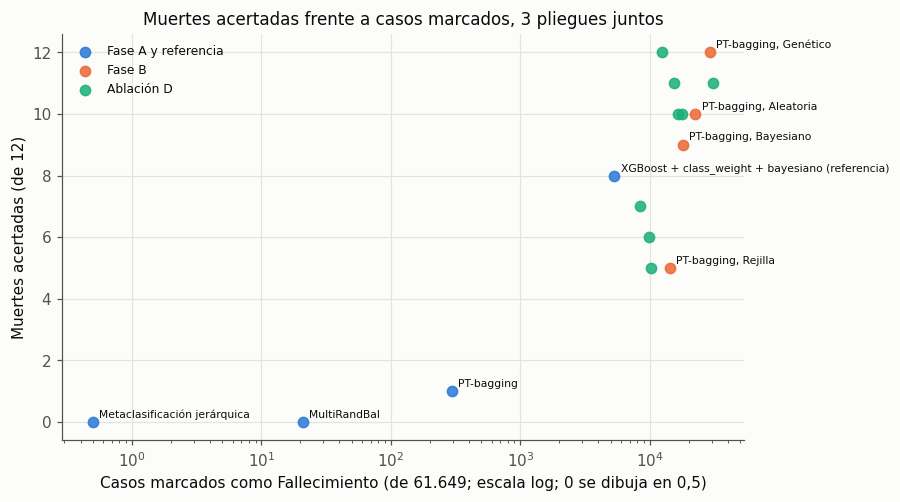

In [9]:
pts = [(NOMBRES[m], fa.loc[NOMBRES[m], 'casos_marcados'], fa.loc[NOMBRES[m], 'muertes_acertadas'], 'Fase A y referencia')
       for m in ['pt_bagging', 'multirandbal', 'hierarchical', 'xgboost__class_weight__bayes']]
pts += [(f'PT-bagging, {OPT[o]}', r.casos_marcados, r.muertes_acertadas, 'Fase B')
        for o, r in fb[fb.pliegue == 'todos'].set_index('optimizador').iterrows()]
pts += [(m.replace('__none__', ' sin balanceo, ').replace('_', ' '), r.casos_marcados, r.muertes_acertadas, 'Ablación D')
        for m, r in ab[ab.regla == 'argmax P/λ'].set_index('modelo').iterrows()]
d = pd.DataFrame(pts, columns=['modelo', 'marcados', 'acertadas', 'grupo'])
fig, ax = plt.subplots(figsize=(8, 4.8))
for (g, sub), col in zip(d.groupby('grupo', sort=False), P.SERIES):
    ax.scatter(sub.marcados.clip(lower=0.5), sub.acertadas, label=g, color=col, s=45, alpha=.85)
for _, r in d[d.grupo != 'Ablación D'].iterrows():
    ax.annotate(r.modelo, (max(r.marcados, 0.5), r.acertadas), fontsize=7, xytext=(4, 3), textcoords='offset points')
ax.set_xscale('log')
ax.set_xlabel('Casos marcados como Fallecimiento (de 61.649; escala log; 0 se dibuja en 0,5)')
ax.set_ylabel('Muertes acertadas (de 12)')
ax.set_title('Muertes acertadas frente a casos marcados, 3 pliegues juntos')
ax.legend(frameon=False, fontsize=8)
P.save(fig, 'e3_original_muertes_vs_marcados')
plt.show()

**Figura 17.1.** Cada punto es un modelo, con los 3 pliegues de validación juntos.

Observado: ninguna variante de PT-bagging queda por encima y a la izquierda de la referencia, es decir, con más
muertes acertadas marcando menos casos. Las variantes de la Fase B y de la ablación D aciertan más muertes solo
porque marcan muchos más casos.

Interpretación: con 12 muertes de validación no hay un punto intermedio estable. El modelo o no marca casi nada
(árboles sin podar) o marca decenas de miles de casos (árboles podados).

## 17.7 Iteraciones del diseño: Rondas 2 a 4

Como PT-bagging no mejoró, se probaron cuatro variantes más, siguiendo la Figura 2 de la guía (iterar el diseño).
Cada una tuvo su regla escrita antes de calcular (`regla_r2.md`, `regla_r3.md` y `regla_r4.md`). Ninguna se
presenta como modelo original.

| Ronda | Iteración | Fuente | Resultado |
|---|---|---|---|
| 1 | MultiRandBal; metaclasificación jerárquica | Rodríguez et al. (*KBS*, 2020); Bhattacharya et al. (*BMC MIDM*, 2018) | Fase A: 0 de 12 muertes; no pasan |
| 2 | HAFL-XGBoost (pérdida focal con γ adaptativo como objetivo propio de XGBoost) | Jiang et al. (*Neural Comput. & Applic.*, 2023) | Con los mismos casos marcados que la referencia: 8 de 12 frente a 8 de 12; no pasa |
| 3 | Subproblema de las clases 2–4 (exploratorio) | — | Los cuatro candidatos quedan por debajo de la mejor base |
| 4 | Frank–Hall ordinal con XGBoost (exploratorio y posterior) | Frank y Hall (ECML, 2001) | BA 2–4: −0,0025 (IC 95 %: −0,0055 a +0,0004); no pasa |

In [10]:
r2 = pd.read_csv(R / 'cribado_r2.csv')
r2 = r2[r2.pliegue == 'todos'].copy()
r2['modelo'] = r2['modelo'].map(NOMBRES)
r2['decision'] = r2['decision'].replace({'argmax': 'argmax propio', 'k_igual_ref': 'mismos casos marcados que la referencia'})
r2.set_index(['modelo', 'decision'])[['muertes_acertadas', 'casos_marcados', 'aucpr_fall', 'recall_2_4', 'auc_macro',
                                      'balanced_accuracy']].rename(columns=COLS | {'aucpr_fall': 'AUC-PR Fall.'}).round(4)

Muertes acertadas  \
modelo                                          decision                                                     
XGBoost + class_weight + bayesiano (referencia) argmax propio                                            8   
                                                mismos casos marcados que la referencia                  8   
HAFL-XGBoost                                    argmax propio                                            8   
                                                mismos casos marcados que la referencia                  8   
HAFL-XGBoost con γ = 0 (ablación)               argmax propio                                            8   
                                                mismos casos marcados que la referencia                  8   

                                                                                         Casos marcados como Fall.  \
modelo                                          decision                                                             
XGBoost + class_weight + bayesiano (referencia) argmax propio                                                 5337   
                                                mismos casos marcados que la referencia                       5337   
HAFL-XGBoost                                    argmax propio                                                 4321   
                                                mismos casos marcados que la referencia                       5337   
HAFL-XGBoost con γ = 0 (ablación)               argmax propio                                                 4242   
                                                mismos casos marcados que la referencia                       5337   

                                                                                         AUC-PR Fall.  \
modelo                                          decision                                                
XGBoost + class_weight + bayesiano (referencia) argmax propio                                  0.0018   
                                                mismos casos marcados que la referencia        0.0018   
HAFL-XGBoost                                    argmax propio                                  0.0019   
                                                mismos casos marcados que la referencia        0.0019   
HAFL-XGBoost con γ = 0 (ablación)               argmax propio                                  0.0020   
                                                mismos casos marcados que la referencia        0.0020   

                                                                                         Recall 2–4  \
modelo                                          decision                                              
XGBoost + class_weight + bayesiano (referencia) argmax propio                                0.4657   
                                                mismos casos marcados que la referencia      0.4648   
HAFL-XGBoost                                    argmax propio                                0.4741   
                                                mismos casos marcados que la referencia      0.4659   
HAFL-XGBoost con γ = 0 (ablación)               argmax propio                                0.4752   
                                                mismos casos marcados que la referencia      0.4664   

                                                                                         AUC macro  \
modelo                                          decision                                             
XGBoost + class_weight + bayesiano (referencia) argmax propio                               0.7036   
                                                mismos casos marcados que la referencia     0.7036   
HAFL-XGBoost                                    argmax propio                               0.7030   
                                                mismos casos marcados que la referencia

**Tabla 17.7. Ronda 2: HAFL-XGBoost.**
- Las derivadas de la pérdida focal (gradiente y hessiano diagonal) se programaron a mano. Se comprobaron con
  diferencias finitas para γ entre 0 y 5.
- Con los mismos casos marcados que la referencia, acierta las mismas 8 muertes. No pasa la regla.
- Con su propio `argmax`, marca menos casos. La ablación con γ = 0 da lo mismo, así que esa diferencia viene del
  objetivo propio (hessiano exacto), no de la pérdida focal.

In [11]:
c24 = pd.read_csv(R / 'comparaciones_2_4.csv')
c24['modelo'] = c24['modelo'].map(NOMBRES)
c24.set_index('modelo')[['delta_ba_2_4', 'delta_low_holm', 'delta_high_holm', 'p_mcnemar_holm', 'mejora']].rename(
    columns={'delta_ba_2_4': 'Δ BA 2–4 frente a la mejor base', 'delta_low_holm': 'IC inferior (Holm)',
             'delta_high_holm': 'IC superior (Holm)', 'p_mcnemar_holm': 'p McNemar (Holm)', 'mejora': '¿Mejora?'}).round(4)

,Δ BA 2–4 frente a la mejor base,IC inferior (Holm),IC superior (Holm),p McNemar (Holm),¿Mejora?
modelo,,,,,
PT-bagging,-0.0382,-0.0502,-0.0284,0.0,False
MultiRandBal,-0.0458,-0.0573,-0.0361,0.0,False
Metaclasificación jerárquica,-0.0327,-0.0422,-0.0241,0.0,False
HAFL-XGBoost,-0.0250,-0.0335,-0.0180,0.0,False
HAFL-XGBoost con γ = 0 (ablación),-0.0245,NaN,NaN,NaN,NaN


**Tabla 17.8. Ronda 3: clases 2–4.**
- Diseño: 61.637 casos y 15.897 establecimientos, solo con predicciones guardadas. Se compara con la mejor de las
  108 combinaciones base (XGBoost + `class_weight` + aleatorio, BA 2–4 = 0,527).
- Los intervalos son de un bootstrap pareado por establecimiento (2.000 réplicas), con nivel ajustado por Holm.
- Los cuatro candidatos quedan por debajo, con intervalos que excluyen el cero.
- Esta ronda encontró estructura ordinal en los errores: el 71,6 % de los errores de la base son entre clases
  adyacentes. Eso motivó la Ronda 4.

In [12]:
r4 = pd.read_csv(R / 'tabla_r4.csv').set_index('modelo')
r4.index = r4.index.map({'base': 'Mejor base (XGBoost + cw + aleatorio)', 'frank_hall': 'Frank–Hall ordinal',
                         'control': 'Control: el mismo pipeline multiclase reajustado'})
r4[['ba_2_4', 'ba_2_4_low', 'ba_2_4_high', 'kappa_cuadratico_2_4', 'frac_no_adyacente_2_4',
    '4clases_muertes_acertadas', '4clases_casos_marcados']].rename(columns={
    'ba_2_4': 'BA 2–4', 'ba_2_4_low': 'IC inf.', 'ba_2_4_high': 'IC sup.', 'kappa_cuadratico_2_4': 'Kappa cuadrático',
    'frac_no_adyacente_2_4': 'Errores no adyacentes', '4clases_muertes_acertadas': 'Muertes acertadas',
    '4clases_casos_marcados': 'Casos marcados'}).round(4)

,BA 2–4,IC inf.,IC sup.,Kappa cuadrático,Errores no adyacentes,Muertes acertadas,Casos marcados
modelo,,,,,,,
Mejor base (XGBoost + cw + aleatorio),0.5274,0.5188,0.5365,0.2962,0.3664,0,57
Frank–Hall ordinal,0.5249,0.5162,0.5336,0.2916,0.3500,0,37
Control: el mismo pipeline multiclase reajustado,0.5274,0.5188,0.5365,0.2962,0.3664,0,57


**Tabla 17.9. Ronda 4: Frank–Hall ordinal.**
- La fila «Control» reajusta el mismo pipeline multiclase de la base y reproduce sus predicciones guardadas
  (diferencia máxima 0): solo cambia la descomposición ordinal.
- Usa el orden de gravedad de OSHA (Otro < Traslado < Días de ausencia < Fallecimiento) con 3 XGBoost binarios.
- Reduce un poco los errores no adyacentes, pero predice aún más la clase del medio.
- Δ BA 2–4 = −0,0025, con IC pareado de −0,0055 a +0,0004. No pasa (`decision_r4.md`).
- Limitación: los hiperparámetros se tomaron de la base multiclase y no se optimizaron para la versión ordinal.

**Cinco candidatos probados; ninguno mejoró.** Elegir el mejor de varios intentos sobrestima su ventaja (efecto de
selección). Aquí no hay ventaja que corregir.

## 17.8 Por qué no se encuentra mejora: techo de información, fuga y efecto del empleador

**Techo de las 8 variables** (`sensibilidad_variables.md`). Es exploratorio: una sola partición y sin intervalos.
- Con las 8 variables del diseño, un *gradient boosting* llega a una BA 2–4 de 0,533, el mismo techo (~0,53) que
  toda la corrida base.
- Añadir naturaleza, parte del cuerpo, evento y fuente la sube a ~0,60. Pero esas variables salen de las
  narrativas y se excluyen por posible fuga.

**Fuga directa.** Proporción de casos de cada clase con el campo presente o mayor que cero:

In [13]:
J = R / 'justificacion'
display(pd.read_csv(J / 'fuga_directa.csv', index_col=0).rename(columns={'dafw>0': 'días de ausencia > 0',
        'djtr>0': 'días de traslado > 0', 'date_of_death': 'fecha de muerte presente'}).round(3))
display(pd.read_csv(J / 'fuga_narrativas.csv', index_col=0).round(4))
display(pd.read_csv(J / 'informacion_mutua.csv', index_col=0).round(3))

,días de ausencia > 0,días de traslado > 0,fecha de muerte presente
Fallecimiento,0.145,0.000,1.0
Días de ausencia,0.994,0.293,0.0
Traslado/restricción,0.004,0.995,0.0
Otro,0.002,0.003,0.0


,muerte,dias_de_ausencia,restriccion_o_traslado,regreso_al_trabajo,cualquiera
Fallecimiento,0.5362,0.0000,0.0000,0.0000,0.5362
Días de ausencia,0.0006,0.0037,0.0027,0.0017,0.0082
Traslado/restricción,0.0005,0.0010,0.0043,0.0015,0.0069
Otro,0.0005,0.0015,0.0016,0.0017,0.0050


,informacion_mutua_nats
nature_title_pred,0.132
source_title_pred,0.124
event_title_pred,0.113
naics_code,0.087
naics_3,0.069
soc_code,0.064
part_title_pred,0.056
type_of_incident,0.035
time_started_work,0.024
state,0.023


**Tablas 17.10 a 17.12. Fuga directa, menciones en las narrativas e información mutua con el desenlace (en nats).**
Todo se calculó solo con el desarrollo.

Observado:
- `dafw_num_away > 0` en el 99,4 % de la clase 2, `djtr_num_tr > 0` en el 99,5 % de la clase 3 y `date_of_death`
  en el 100 % de las muertes. Estos campos definen la etiqueta.
- Las narrativas nombran la muerte en el 54 % de los fallecimientos. En las clases 2–4, menos del 1 % menciona
  ausencia, restricción o regreso al trabajo (búsqueda aproximada de palabras clave).
- Las variables `*_pred` son las que más información comparten con el desenlace (0,11 a 0,13 nats, frente a 0,07
  de la industria a 3 dígitos).

Lo que dice la documentación de OSHA:
- Las `*_pred` las asigna OSHA con el autocodificador SOII de BLS, **a partir de las narrativas** (ITA Case Detail
  Data Dictionary).
- Los casos de un año se cargan entre el 2 de enero y el 2 de marzo del año siguiente (ITA Data Users Guide). En el
  desarrollo, la mediana de `created_timestamp` es 283 días después del incidente.

Interpretación: las narrativas y las `*_pred` se escriben cuando el desenlace ya se conoce. Por eso no están
disponibles «a tiempo» para predecirlo.

In [14]:
display(pd.read_csv(J / 'empleador_resumen.csv').rename(columns={'establecimientos': 'Establecimientos (≥ 20 casos 2–3)',
        'casos': 'Casos', 'var_z': 'var(z) observada', 'frac_abs_z_mayor_3': 'Fracción con |z| > 3'}).round(3))
pd.read_csv(J / 'empleador_agregado.csv').set_index('cuantil').round(3)

,Establecimientos (≥ 20 casos 2–3),Casos,var(z) observada,Fracción con |z| > 3
0,1416,72094,12.927,0.41


,z,prop_traslado,casos_por_establecimiento
cuantil,,,
0.00,-21.550,0.000,20.00
0.05,-5.312,0.000,20.00
0.10,-4.268,0.028,21.00
0.25,-2.235,0.161,24.00
0.50,0.373,0.470,32.00
0.75,2.683,0.720,49.00
0.90,4.573,0.872,87.00
0.95,5.621,0.933,131.75
1.00,13.093,1.000,2013.00


**Tablas 17.13 y 17.14. Efecto del empleador** (casos de las clases 2 y 3).

Cómo se mide:
- Para cada establecimiento se calcula un *z* que compara su proporción de traslado o restricción con la esperada
  según industria, naturaleza y parte del cuerpo.
- Sin efecto del empleador, var(z) ≈ 1. Al permutar dentro de cada estrato da 0,98.

Observado:
- var(z) = 12,9.
- El 41 % de los establecimientos tiene |z| > 3; sin efecto del empleador se esperaría un 0,3 %.
- Los cuantiles muestran establecimientos con 0 % y con 100 % de traslado.

Interpretación:
- Que un caso termine en días de ausencia o en trabajo restringido depende en buena parte de la política de
  trabajo liviano de cada empleador.
- La validación agrupa por establecimiento, así que el modelo nunca conoce la política del empleador de un caso
  nuevo.
- Esto pone un techo a cualquier método, original o del curso, con estas 8 variables.

## 17.9 Veredicto (histórico)

> **Superado.** Este veredicto es el del primer candidato. El veredicto del modelo original final (SECR) está en los
> capítulos 19 y 20 y en las conclusiones (R1 sí, R2 sí, R3 no).

| Requisito | Veredicto | Evidencia |
|---|---|---|
| R1, novedad | **Sí, provisional** | Capítulo 16: no se halló PT-bagging aplicado a la gravedad de lesiones laborales. Faltan una tercera base formal y la cadena de la búsqueda 2 de WoS. |
| R2, implementación propia | **En riesgo** | La regla de decisión, el bootstrap, el promedio y las pruebas son propios. El árbol interno es `DecisionTreeClassifier` sin modificar, que el Cuadro 1 de la guía no acepta. Plan: programar el árbol con numpy. |
| R3, superioridad | **No** | Fase A: 1 de 12 muertes frente a 8 de 12. Fase B: más muertes solo marcando de 14.000 a 29.000 casos. BA con los pliegues juntos: 0,480 frente a 0,516. Rondas 2–4: ninguna iteración pasa su regla. |

**Sobre la BA media por pliegue.** El bayesiano tiene 0,511 frente a 0,505 de la referencia. Se reporta, pero no
se reclama como superioridad: la diferencia la produce la única muerte del pliegue 1, y con los pliegues juntos el
orden se invierte.

Según la guía, con R1 y R2 en «sí» y R3 en «no», la nota máxima de esta componente es 4,0.

## 17.10 Limitaciones

1. **Pocas muertes.** Hay 12 muertes de validación en el diseño temporal y de 16 a 37 de entrenamiento por pliegue.
   El recall de Fallecimiento casi no se puede medir: el intervalo de Wilson para 8 de 12 va de 0,39 a 0,86.
2. **Diseño distinto al de los capítulos 6 a 13.** Las cifras son del diseño temporal de 3 pliegues (12.6). Falta
   correr el modelo en el diseño del grupo. El puente entre los dos diseños es la prueba oct–dic, que todavía no se
   usa.
3. **Presupuesto desigual.** La Fase B usó 12 evaluaciones por optimizador; la corrida base usó 20. Hay que
   igualarlo antes de la comparación final.
4. **Desviaciones del paper.** CART con entropía en lugar de J48 (C4.5), con divisiones binarias sobre el one-hot.
   En la Fase B se buscan hiperparámetros que el paper deja fijos, porque el curso exige 4 optimizadores.
5. **Árbol de scikit-learn** (riesgo de R2, ver 17.9; resuelto con SECR, capítulo 19).
6. **Rondas 3 y 4 exploratorias.** Se decidieron después de ver resultados; el efecto de selección se declara.
7. **Entorno distinto** al del resto del repositorio (versiones de scikit-learn, imbalanced-learn y xgboost; ver
   `disenio_temporal/LEEME.md`).
8. Las tres pruebas de hipótesis formales se hicieron para el modelo final (capítulo 20). La confirmación en la
   prueba se descartó: la prueba quedó bloqueada (capítulo 00, B1).

# 18. Modelo propuesto: *stacking* multivista

:::{admonition} Declaración sobre el uso de la prueba (corrección B1, 23-oct-2026)
:class: warning
Las cifras de prueba (octubre–diciembre) de este capítulo son **exploratorias**. La elección entre las variantes A a G se
hizo **viendo los pliegues externos y la prueba**: se evaluaron 7 variantes, no «una sola». Con solo los pliegues externos
se llega a la misma elección (G supera a D en 5 de 5 pliegues). Después de esa elección la prueba no se volvió a usar y
quedó bloqueada por código (`LockedTest`).

Además, la comparación de este capítulo **no es pareada**: G usa variables que los 112 modelos del curso no tienen. Unos 8
de los 9 puntos de ventaja vienen de esas variables. **La evidencia válida para R3 está en el capítulo 20**, con los
benchmarks reentrenados con las mismas variables y particiones, y con el modelo original final (SECR, capítulo 19).
:::

:::{admonition} Veredicto adelantado (exploratorio, no pareado)
- **Supera a los 112 modelos de clasificación del curso**, con el mismo diseño de evaluación. En la
  prueba (oct–dic), frente al *mejor valor de cada métrica* entre los 112: accuracy 0,611 frente a 0,524,
  F1 macro 0,457 frente a 0,392, AUC macro 0,836 frente a 0,718 y log-loss 0,821 frente a 0,959. Todas
  las diferencias son significativas (bootstrap por establecimiento, McNemar y DeLong con Holm) y con
  tamaño de efecto grande: el ensamble es el mejor en accuracy las 14 semanas de la prueba (δ de Cliff = 1).
- **Unir modelos aporta por sí mismo**, aunque la mayor parte de la ganancia viene de la información
  nueva (las vistas de la lesión y de los códigos finos). El ensamble final supera a un solo XGBoost con
  todas las variables (accuracy +0,005; log-loss −0,008; AUC mayor en las 4 clases), con diferencias
  pequeñas pero significativas.
- **Con la regla P/λ detecta 36 de los 39 fallecimientos de la prueba** (balanced accuracy de 4 clases
  0,640, frente a 0,435 del mejor modelo del curso), a costa de marcar muchos casos.
- Un *stacking* que solo une los 5 modelos del curso, sin información nueva, **no mejora**.
:::

**Cómo se lee este capítulo.**
- Todo se evalúa con **el mismo diseño de los capítulos 6 a 13**: la misma submuestra de 30.030 casos,
  los mismos 5 pliegues externos por establecimiento y la misma prueba (octubre–diciembre, 127.391
  casos de establecimientos no vistos). Así las cifras se comparan directamente con las de los 112
  modelos de clasificación.
- Las referencias del curso se eligen **por la validación anidada** (sin mirar la prueba), y además
  se compara contra el *mejor valor de cada métrica entre los 112* en la prueba, que es la comparación
  más exigente posible.
- Los resultados se leen de `results/ensemble/`; el código está en `src/osha_e3/ensemble.py` y las
  corridas en `scripts/exp/`.
- **Observado** es lo que se lee en una tabla; **interpretación** es la lectura que hacemos de ella.

In [1]:
import sys, json, warnings, inspect
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, confusion_matrix
from osha_e3 import config as C, data as D, models as M, nested as N, final as F, evaluation as E, plots as P
from osha_e3 import stats_tests as T, ensemble as ENS
P.setup()
FINAL = 'stack_v3'
VARIANTS = {'stack_curso': 'A. Stacking solo con los 5 modelos del curso (sin vistas nuevas)',
            'stack_sin_empleador': 'B. Stacking multivista sin la vista del empleador',
            'stack_full': 'C. Stacking multivista (4 vistas), meta-modelo logístico',
            'unico_todo': 'D. Un solo XGBoost con todas las variables (sin unir modelos)',
            'stack_v2': 'E. C + 3 modelos de información completa, meta-modelo logístico',
            'stack_v3:logistic': 'F. Modelo final (16 modelos base) con meta-modelo logístico',
            'stack_v3': 'G. MODELO FINAL: 16 modelos base + selección de Caruana'}
OUT = C.RESULTS / 'ensemble'
test, yt = F.test_data('clf')
X_sub, y_sub, g_sub, _ = N.task_data('clf')
prior = np.bincount(y_sub, minlength=4) / len(y_sub)

def load(v, fold):
    """Probabilidades de una variante. El modelo final usa el combinador de Caruana; ``':logistic'``
    pide el meta-modelo logístico de la misma corrida."""
    name, _, comb = v.partition(':')
    d = np.load(OUT / name / f'fold{fold}.npz')
    key = 'p_caruana' if ('p_caruana' in d.files and comb != 'logistic') else 'p'
    return d[key].astype(float), d['y'], d

def metrics(y, p, rule='argmax', pri=prior):
    pred = p.argmax(1) if rule == 'argmax' else (p / pri).argmax(1)
    m = E.classification_metrics(y, p)
    rec = [((pred == k) & (y == k)).sum() / (y == k).sum() for k in range(4) if (y == k).any()]
    m['recall'] = float(np.mean(rec)); m['accuracy'] = float((pred == y).mean())
    m['ba3'] = float(np.mean([((pred == k) & (y == k)).sum() / (y == k).sum() for k in (1, 2, 3)]))
    m['auc3'] = float(np.mean([roc_auc_score(y == k, p[:, k]) for k in (1, 2, 3)]))
    m['muertes'] = int(((pred == 0) & (y == 0)).sum()); m['marcados'] = int((pred == 0).sum())
    return m

## 18.1 Motivación

Los capítulos 9 a 13 dejaron tres diagnósticos:

1. **Los 140 modelos se equivocan en los mismos casos.** Todos ven las mismas 9 variables del lugar de
   trabajo; cambiar de algoritmo, de balanceo o de optimizador mueve poco el resultado (AUC ≈ 0,70 en
   todos). Un *stacking* que solo combina esos modelos no puede mejorar mucho: si todos fallan en el
   mismo caso, el promedio también falla (sección 18.7 lo confirma).
2. **Falta información de la lesión.** El capítulo 11 mostró que los errores grandes vienen de casos
   cuyo resultado depende de la lesión concreta (naturaleza, parte del cuerpo), que el modelo no ve. El
   análisis de Iván Berrio (capítulo 16) encontró que los códigos OIICS de la lesión son las variables
   con más información mutua con el resultado (0,13 nats, frente a 0,07 del sector) y que hay un efecto
   fuerte del empleador en cómo se registra el caso.
3. **La regla P/λ necesita probabilidades calibradas.** El capítulo 17 (PT-bagging) mostró que la regla
   que maximiza la balanced accuracy, `argmax P/λ`, falla cuando las probabilidades no están calibradas.

**Idea.** Unir modelos en dos niveles:

- **Diversidad de información (vistas).** Cada modelo base se especializa en una **vista** del caso:
  lugar de trabajo, lesión, códigos finos, empleador.
- **Diversidad de algoritmo.** Varios modelos ven toda la información con sesgos distintos: árboles poco
  y muy profundos, bosques, logísticas, codificación por objetivo y one-hot.

Un combinador aprendido **solo con predicciones fuera de pliegue** une los 16 modelos y produce
probabilidades calibradas. Sobre ellas, la regla P/λ vuelve a tener sentido.

## 18.2 Formulación

Sea $\mathcal{D} = \{(x_i, y_i, g_i)\}_{i=1}^n$ con $y_i \in \{1, \dots, K\}$ y $g_i$ el establecimiento.
Cada caso tiene $V$ vistas $x_i = (x_i^{(1)}, \dots, x_i^{(V)})$ y hay $M$ modelos base
$f_1, \dots, f_M$; el modelo $m$ usa la vista $v(m)$.

**1. Predicciones fuera de pliegue (nivel 0).** Se parte $\mathcal{D}$ en $J$ pliegues **por
establecimiento**, $\mathcal{D} = \bigcup_j \mathcal{D}_j$. Para cada caso $i \in \mathcal{D}_j$,
$$
z_{im} = \log \hat P_{f_m^{(-j)}}\big(y \mid x_i^{(v(m))}\big) \in \mathbb{R}^K,
$$
donde $f_m^{(-j)}$ se entrenó sin el pliegue $j$. Así ningún caso ve una predicción hecha con su propia
etiqueta ni con las de su establecimiento.

**2. Meta-modelo (nivel 1).** Una regresión logística multinomial sobre $z_i = (z_{i1}, \dots, z_{iM})$:
$$
\hat P(y = k \mid x_i) = \frac{\exp\big(\beta_{k0} + \sum_{m} \beta_{km}^\top z_{im}\big)}
                             {\sum_{c} \exp\big(\beta_{c0} + \sum_{m} \beta_{cm}^\top z_{im}\big)},
\qquad \min_\beta \; -\sum_i \log \hat P(y_i \mid x_i) + \tfrac{1}{2C}\lVert\beta\rVert^2 .
$$
El meta-modelo aprende cuánto pesa cada modelo en cada clase. Como minimiza la log-verosimilitud,
devuelve probabilidades calibradas. Al predecir, los modelos base se reajustan con todo $\mathcal{D}$.

**2'. Combinador final: selección de ensamble de Caruana** (Caruana et al., 2004). Con 16 modelos y
4 clases, el meta-modelo logístico tiene 64 entradas muy correlacionadas (casi todos los modelos dicen lo
mismo) y tiende a sobreajustar. La alternativa elige, con reemplazo, el modelo que más baja la log-loss
fuera de pliegue del promedio de probabilidades:
$$
S_0 = \{\text{los 3 mejores}\}, \qquad
S_{t+1} = S_t \cup \Big\{\arg\min_m \; \mathrm{LL}\Big(\tfrac{1}{|S_t|+1}\big(\textstyle\sum_{s \in S_t} \hat P_s + \hat P_m\big)\Big)\Big\},
\qquad \hat P = \sum_m w_m \hat P_m,\; w_m = \frac{\#\{m \in S_T\}}{|S_T|}.
$$
Los pesos son no negativos y suman 1 (un promedio de probabilidades calibradas sigue calibrado), y
un modelo solo entra si mejora el conjunto: es una forma regularizada de aprender los pesos. Se usan
$T = 40$ pasos. La sección 18.7 compara los dos combinadores.

**3. Codificación por objetivo (vistas de códigos finos y empleador).** Para una categoría $c$ con
$n_c$ casos, $n_{ck}$ de la clase $k$, proporción global $\pi_k$ y suavizado $m$:
$$
\mathrm{TE}_k(c) = \frac{n_{ck} + m\,\pi_k}{n_c + m}.
$$
En el entrenamiento se calcula fuera de pliegue (por establecimiento), igual que (st-oof).

**4. Decisión.** Dos reglas, fijadas antes de ver la prueba:
- `argmax` $\hat P(y = k \mid x)$: maximiza la accuracy esperada.
- `argmax` $\hat P(y = k \mid x)/\lambda_k$, con $\lambda_k$ la proporción de la clase en el
  entrenamiento: maximiza la balanced accuracy esperada si $\hat P$ está calibrada (Teorema 1 del
  capítulo 17; Collell, Prelec y Patil, 2018).

## 18.3 Vistas y modelos base

In [2]:
views = pd.DataFrame([
    ('Lugar de trabajo', 'Las 9 variables de los capítulos 6 a 13', 'Logística, XGBoost, Random Forest, Naive Bayes y KNN del curso (hiperparámetros de la validación anidada, sin balanceo, mejor log-loss)'),
    ('Lesión', 'Códigos OIICS: naturaleza, parte del cuerpo, evento, fuente y fuente secundaria; tipo de incidente', 'Logística y XGBoost sobre one-hot'),
    ('Códigos finos', 'NAICS de 6 dígitos, SOC completo e interacciones lugar × lesión (p. ej. subsector × naturaleza)', 'XGBoost sobre codificación por objetivo'),
    ('Empleador', 'EIN y nombre de la empresa (y su cruce con la lesión), codificados con otros establecimientos', 'Logística sobre codificación por objetivo'),
    ('Información completa', 'Todas las anteriores', 'XGBoost poco profundo, profundo y con otra semilla y Random Forest sobre codificación por objetivo; XGBoost y logística sobre one-hot; logística sobre codificación por objetivo'),
], columns=['Vista', 'Variables', 'Modelos base'])
views.set_index('Vista')

,Variables,Modelos base
Vista,,
Lugar de trabajo,Las 9 variables de los capítulos 6 a 13,"Logística, XGBoost, Random Forest, Naive Bayes..."
Lesión,"Códigos OIICS: naturaleza, parte del cuerpo, e...",Logística y XGBoost sobre one-hot
Códigos finos,"NAICS de 6 dígitos, SOC completo e interaccion...",XGBoost sobre codificación por objetivo
Empleador,EIN y nombre de la empresa (y su cruce con la ...,Logística sobre codificación por objetivo
Información completa,Todas las anteriores,"XGBoost poco profundo, profundo y con otra sem..."


**Sobre las variables nuevas (fuga de información).** Los códigos OIICS describen la lesión (qué pasó y
qué parte del cuerpo se afectó), no el desenlace administrativo. Se verificó que ninguna categoría
revela el resultado: la proporción más alta de fallecimientos en una categoría de evento es 2,4 %
(«explosiones»), y las proporciones altas de otras clases corresponden a relaciones esperables (por
ejemplo, las enfermedades respiratorias con días de ausencia). Igual que el código SOC, OSHA los
asigna a partir del relato **después** del reporte, así que el modelo sigue siendo de clasificación
retrospectiva (capítulo 1). La vista del empleador usa solo casos de **otros** establecimientos de la
misma empresa (los pliegues separan establecimientos), información disponible al predecir un
establecimiento nuevo de una empresa conocida.

## 18.4 Pseudocódigo y complejidad

```
Entrada: casos X con sus vistas, etiquetas y, establecimientos g; modelos base f_1..f_M; J pliegues
para j = 1..J (pliegues por establecimiento):
    para m = 1..M:
        entrenar f_m con X[-j]           # la codificación por objetivo también, fuera de pliegue
        Z[j, m] ← log P_fm(y | X[j])     # predicciones fuera de pliegue, ecuación (st-oof)
pesos w ← selección de Caruana con (Z, y)            # ecuación (st-caruana); alternativa: (st-meta)
para m = 1..M: reentrenar f_m con todo X
predecir(x): P ← Σ_m w_m · P_fm(·|x)
             devolver argmax P   o   argmax P / λ
```

**Complejidad.** Con $J$ pliegues, el entrenamiento cuesta $(J + 1)$ veces la suma de los costos de los
modelos base. La selección de Caruana cuesta $O(T \cdot M \cdot n K)$, despreciable frente a los
modelos. La predicción cuesta la suma de las predicciones de los modelos base más $O(MK)$ por caso. La
codificación por objetivo es $O(n)$ por columna (un `groupby`).

**Tiempo medido.** Entrenar el modelo final con los 30.030 casos de la submuestra (16 modelos × 6
ajustes, 2 hilos) tarda unos 28 minutos (22 a 24 en cada pliegue externo). Es comparable a una sola
búsqueda de 16 configuraciones de Random Forest del capítulo 7, y el modelo no necesita búsqueda de
hiperparámetros propia: reutiliza los elegidos por la validación anidada.

## 18.5 Código y pruebas

In [3]:
print(inspect.getsource(ENS.StackedEnsemble))

class StackedEnsemble(BaseEstimator, ClassifierMixin):
    """Stacking multivista con meta-modelo logístico multinomial.

    Parameters
    ----------
    views : list of (str, ViewModel)
        Modelos base. Por defecto, ``default_views()``.
    meta_C : float
        Inverso de la regularización L2 del meta-modelo.
    n_splits : int
        Pliegues (por establecimiento) para las predicciones fuera de pliegue del nivel 0.
    """

    def __init__(self, views=None, meta_C=1.0, n_splits=5, seed=C.SEED, combiner='logistic', caruana_steps=40):
        self.views, self.meta_C, self.n_splits, self.seed = views, meta_C, n_splits, seed
        self.combiner, self.caruana_steps = combiner, caruana_steps

    @staticmethod
    def _meta_X(P):
        return np.hstack([np.log(p) for p in P])

    def fit(self, X, y, groups):
        from sklearn.base import clone
        views = self.views if self.views is not None else default_views()
        self.names_ = [n for n, _ in views]
        sel

In [4]:
print(inspect.getsource(ENS.MulticlassTargetEncoder))
print(inspect.getsource(ENS.caruana_selection))

class MulticlassTargetEncoder:
    """Codificación por objetivo multiclase con suavizado: (n_ck + m·π_k)/(n_c + m).

    ``fit_transform`` devuelve codificaciones *fuera de pliegue* (pliegues por grupo): una fila nunca se
    codifica con su propia etiqueta ni con las de su establecimiento. ``unknown`` lista los valores que
    significan «sin dato» y se codifican con la proporción global. Se añade log(1 + n_c) como columna.
    """

    def __init__(self, columns, m=30.0, n_splits=5, seed=C.SEED, unknown=('Unknown',)):
        self.columns, self.m, self.n_splits, self.seed, self.unknown = columns, m, n_splits, seed, unknown

    def _stats(self, X, y):
        prior = np.bincount(y, minlength=K) / len(y)
        tables = {}
        onehot = pd.DataFrame(np.eye(K)[y], columns=range(K))
        for c in self.columns:
            onehot['key'] = _column(X, c).to_numpy()
            g = onehot.groupby('key')
            cnt, s = g.size(), g[list(range(K))].sum()
            t = s.add(self

Las pruebas están en `tests/test_ensemble.py`:

| Prueba | Qué verifica |
|---|---|
| (i) `test_i_codificacion_fuera_de_pliegue_no_usa_su_etiqueta` | Cada fila se codifica solo con filas de otros establecimientos (no hay fuga en la codificación por objetivo). |
| (ii) `test_ii_reproducible_con_semilla` | Misma semilla, mismas probabilidades; las probabilidades suman 1. |
| (iii) `test_iii_compatible_con_clone` | `sklearn.base.clone` copia los hiperparámetros sin el estado ajustado. |
| (iv) `test_iv_meta_modelo_entrenado_con_predicciones_fuera_de_pliegue` | El meta-modelo se entrena con predicciones fuera de pliegue (distintas de las de entrenamiento) y siempre devuelve 4 columnas. |
| (v) `test_v_entradas_invalidas` | Falla si falta una variable de una vista. |

In [5]:
import subprocess
r = subprocess.run([sys.executable, '../tests/test_ensemble.py'], capture_output=True, text=True,
                   env={**__import__('os').environ, 'PYTHONWARNINGS': 'ignore'})
print(r.stdout[-600:])

OK   test_i_codificacion_fuera_de_pliegue_no_usa_su_etiqueta
OK   test_ii_reproducible_con_semilla
OK   test_iii_compatible_con_clone
OK   test_iv_meta_modelo_entrenado_con_predicciones_fuera_de_pliegue
OK   test_v_entradas_invalidas
5 de 5 pruebas pasan



## 18.6 Resultados en los 5 pliegues externos

Mismos pliegues que la tabla maestra. La referencia de cada métrica es la mejor de las 112 combinaciones
del curso en esa métrica (media de los 5 pliegues).

In [6]:
fcl = N.fold_table('clf')
rows = []
for lab, col, best in [('Balanced accuracy', 'outer_recall', max), ('AUC macro', 'outer_auc', max), ('Accuracy', 'outer_accuracy', max),
                       ('F1 macro', 'outer_f1', max), ('Log-loss', 'outer_log_loss', min)]:
    per = fcl.groupby(['model', 'balance', 'optimizer'])[col].mean()
    rows.append({'métrica': lab, 'mejor del curso': ' · '.join(M.PRETTY[x] for x in (per.idxmax() if best is max else per.idxmin())),
                 'valor del curso': per.max() if best is max else per.min()})
fold_tab = pd.DataFrame(rows).set_index('métrica')
fold_vals = {}
for v in VARIANTS:
    if not (OUT / v.split(':')[0] / 'fold4.npz').exists():
        continue
    ms = []
    for k, (tr, te) in enumerate(N.outer_folds('clf')):
        p, y, _ = load(v, k)
        pri = np.bincount(y_sub[tr], minlength=4) / len(tr)
        ms.append({'argmax': metrics(y, p), 'prior': metrics(y, p, 'prior', pri)})
    fold_vals[v] = ms
    fold_tab[VARIANTS[v]] = [np.mean([m['argmax'][k] for m in ms]) for k in ['recall', 'auc', 'accuracy', 'f1', 'log_loss']]
fold_tab.loc['Balanced accuracy (regla P/λ)', :] = [np.nan, np.nan] + [np.mean([m['prior']['recall'] for m in fold_vals[v]]) for v in fold_vals]
fold_tab.round(4)

,mejor del curso,valor del curso,A. Stacking solo con los 5 modelos del curso (sin vistas nuevas),B. Stacking multivista sin la vista del empleador,"C. Stacking multivista (4 vistas), meta-modelo logístico",D. Un solo XGBoost con todas las variables (sin unir modelos),"E. C + 3 modelos de información completa, meta-modelo logístico",F. Modelo final (16 modelos base) con meta-modelo logístico,G. MODELO FINAL: 16 modelos base + selección de Caruana
métrica,,,,,,,,,
Balanced accuracy,SVM · SMOTE · Random,0.4694,0.3968,0.4571,0.4657,0.4694,0.4681,0.4708,0.4775
AUC macro,XGBoost · ADASYN · Bayesiana (TPE),0.7378,0.7088,0.7987,0.8030,0.8001,0.7854,0.7883,0.8178
Accuracy,Reg. logística · Sin balanceo · Random,0.5082,0.5005,0.5778,0.5864,0.5902,0.5905,0.5913,0.5991
F1 macro,XGBoost · class_weight · Bayesiana (TPE),0.3801,0.3670,0.4282,0.4362,0.4397,0.4385,0.4411,0.4467
Log-loss,XGBoost · Sin balanceo · Genética,0.9768,0.9813,0.8594,0.8515,0.8479,0.8484,0.8460,0.8403
Balanced accuracy (regla P/λ),NaN,NaN,0.4460,0.5541,0.5619,0.5856,0.5306,0.5101,0.6137


**Observado.**
- El modelo final (G) es el mejor en las cinco métricas de los pliegues externos: accuracy 0,599 (curso
  0,508), F1 macro 0,447 (0,380), AUC macro 0,818 (0,738), log-loss 0,840 (0,977) y balanced accuracy
  0,478 (0,469).
- Con la regla P/λ, su balanced accuracy media sube a 0,614 (curso: 0,469). Supera a la mejor
  combinación del curso en 4 de los 5 pliegues; en el pliegue 1 queda algo por debajo (0,603 frente a
  0,618). Acierta los 9 fallecimientos de la submuestra.
- El *stacking* solo con modelos del curso (A) queda **por debajo** del mejor modelo del curso en todas las
  métricas.

**Interpretación.** Los 5 modelos del curso se equivocan en los mismos casos: combinarlos no corrige
nada. La ganancia aparece cuando los modelos ven información distinta (B a G) y crece un poco más cuando,
además, hay diversidad de algoritmos y un combinador que no sobreajusta (G frente a F).

## 18.7 Resultados en la prueba y ablaciones

Evaluación **exploratoria** en la prueba: se evaluaron 7 variantes (A a G) y la elección se hizo viendo los pliegues y la
prueba (ver la declaración al inicio del capítulo). Todas se entrenan en la misma submuestra de 30.030 casos que los
modelos del curso. La primera fila es el **mejor valor de cada métrica entre los 112 modelos del
curso** (cada columna puede venir de un modelo distinto).

In [7]:
course = {}
for f in sorted((C.RESULTS / 'final' / 'clf').glob('*.npz')):
    course[f.stem.replace('__', '|')] = metrics(yt, np.load(f)['out'].astype(float))
cdf = pd.DataFrame(course).T
cols = ['accuracy', 'recall', 'ba3', 'f1', 'auc', 'auc3', 'log_loss', 'brier', 'ece']
best_row = {c: (cdf[c].min() if c in ('log_loss', 'brier', 'ece') else cdf[c].max()) for c in cols}
rows = [{'modelo': 'Mejor de los 112 del curso (por métrica)', **best_row}]
test_vals = {}
for v, lab in VARIANTS.items():
    if (OUT / v.split(':')[0] / 'foldtest.npz').exists():
        p, y, d = load(v, 'test')
        test_vals[v] = (p, d)
        rows.append({'modelo': lab, **{c: metrics(yt, p)[c] for c in cols}})
pfin, dfin = test_vals[FINAL]
for k in dfin.files:
    if k.startswith('base_'):
        rows.append({'modelo': '   componente: ' + k[5:], **{c: metrics(yt, dfin[k].astype(float))[c] for c in cols}})
test_tab = pd.DataFrame(rows).set_index('modelo').rename(columns={
    'accuracy': 'Accuracy', 'recall': 'BA (4 clases)', 'ba3': 'BA (3 clases)', 'f1': 'F1 macro', 'auc': 'AUC macro',
    'auc3': 'AUC (3 clases)', 'log_loss': 'Log-loss', 'brier': 'Brier', 'ece': 'ECE'})
test_tab.round(4)

,Accuracy,BA (4 clases),BA (3 clases),F1 macro,AUC macro,AUC (3 clases),Log-loss,Brier,ECE
modelo,,,,,,,,,
Mejor de los 112 del curso (por métrica),0.5238,0.4349,0.5253,0.3918,0.7182,0.7141,0.9585,0.5707,0.0071
A. Stacking solo con los 5 modelos del curso (sin vistas nuevas),0.5166,0.3849,0.5133,0.3846,0.7125,0.7085,0.9632,0.5757,0.0056
B. Stacking multivista sin la vista del empleador,0.5923,0.4416,0.5887,0.4424,0.8274,0.7850,0.8434,0.5009,0.0064
"C. Stacking multivista (4 vistas), meta-modelo logístico",0.6004,0.4483,0.5977,0.4488,0.8288,0.7911,0.8378,0.4956,0.0092
D. Un solo XGBoost con todas las variables (sin unir modelos),0.6060,0.4533,0.6044,0.4537,0.8273,0.7965,0.8287,0.4905,0.0053
"E. C + 3 modelos de información completa, meta-modelo logístico",0.6041,0.4521,0.6029,0.4522,0.8294,0.7946,0.8313,0.4919,0.0087
F. Modelo final (16 modelos base) con meta-modelo logístico,0.6050,0.4519,0.6025,0.4522,0.8315,0.7949,0.8320,0.4920,0.0122
G. MODELO FINAL: 16 modelos base + selección de Caruana,0.6108,0.4575,0.6101,0.4573,0.8361,0.8004,0.8207,0.4858,0.0074
componente: curso_logreg,0.5174,0.3857,0.5143,0.3848,0.6774,0.7057,0.9722,0.5795,0.0247


**Observado.**
- **Frente a los 112 modelos del curso:** el modelo final (G) supera al mejor valor de *cada* métrica,
  aunque ese mejor valor venga de modelos distintos. Accuracy 0,611 frente a 0,524 (+0,087); BA de 3
  clases 0,610 frente a 0,525; F1 macro 0,457 frente a 0,392; AUC de las 3 clases 0,800 frente a 0,714;
  log-loss 0,821 frente a 0,959. La BA de 4 clases (argmax) también sube, pero poco: 0,458 frente a
  0,435.
- **Ablaciones:**
  - (A) unir solo los modelos del curso no mejora (accuracy 0,517).
  - (B) sin la vista del empleador se pierde algo (accuracy 0,592 frente a 0,600 en C).
  - (D) un solo XGBoost con todas las variables (0,606) ya supera al *stacking* con meta-modelo
    logístico (C 0,600, E 0,604, F 0,605).
  - Solo con diversidad de algoritmos y el combinador de Caruana (G, 0,611) el ensamble supera al modelo
    único.
- **Componentes:** los mejores modelos individuales son los que ven toda la información (accuracy de
  0,604 a 0,607). La vista de la lesión sola (0,553) ya supera a todos los modelos del curso, y la del
  empleador sola es débil (0,450).

**Interpretación.**
1. La mayor parte de la mejora viene de **información nueva**. La lesión (naturaleza, parte del cuerpo,
   evento) y los códigos finos con sus cruces explican lo que las 9 variables del lugar de trabajo no
   podían: es el diagnóstico del capítulo 11.
2. **Unir modelos aporta una mejora adicional real pero pequeña**, y solo con dos condiciones: que los
   modelos sean diversos y que el combinador esté regularizado. El meta-modelo logístico, con 64 entradas
   casi colineales, no lo logra; la selección de Caruana sí.
3. La ganancia no es solo del XGBoost con todo: el ensamble supera a su mejor componente (sección 18.8).

## 18.8 Pruebas estadísticas en la prueba

Siguiendo la secuencia del capítulo 13. Referencias: la mejor combinación del curso según la validación
anidada en cada métrica (elegidas sin mirar la prueba) y el mejor componente individual del ensamble.

- **Bootstrap pareado por establecimiento** (1.000 réplicas) de la diferencia en accuracy, balanced
  accuracy y log-loss, y **McNemar** sobre los aciertos; p-valores ajustados con Holm.
- **DeLong** por clase (una contra el resto), con Holm.
- **Friedman y Nemenyi** sobre las 14 semanas de la prueba (ensamble frente a la mejor combinación de cada
  modelo del curso) y **δ de Cliff**.

In [8]:
boot = pd.read_csv(OUT / FINAL / 'pruebas_bootstrap.csv')
boot.round(4)

,referencia,métrica,ensamble,referencia_valor,diferencia,IC 95 % (bootstrap por establecimiento),p bootstrap,mejor el ensamble,p Holm
0,mejor BA anidada,accuracy,0.6108,0.4794,0.1314,"[0.1260, 0.1364]",0.001,True,0.024
1,mejor BA anidada,balanced acc. (4 clases),0.4575,0.4349,0.0227,"[-0.0164, 0.0580]",0.232,True,0.232
2,mejor BA anidada,balanced acc. (3 clases),0.6101,0.4858,0.1243,"[0.1191, 0.1293]",0.001,True,0.024
3,mejor BA anidada,log-loss,0.8207,1.1332,-0.3125,"[-0.3195, -0.3041]",0.001,True,0.024
4,mejor BA anidada,McNemar (aciertos solo ensamble / solo referen...,28894.0000,12154.0000,16740.0000,NaN,0.000,True,0.000
5,mejor AUC anidada,accuracy,0.6108,0.5134,0.0974,"[0.0928, 0.1018]",0.001,True,0.024
6,mejor AUC anidada,balanced acc. (4 clases),0.4575,0.3893,0.0683,"[0.0648, 0.0717]",0.001,True,0.024
7,mejor AUC anidada,balanced acc. (3 clases),0.6101,0.5190,0.0910,"[0.0864, 0.0955]",0.001,True,0.024
8,mejor AUC anidada,log-loss,0.8207,0.9731,-0.1524,"[-0.1575, -0.1467]",0.001,True,0.024
9,mejor AUC anidada,McNemar (aciertos solo ensamble / solo referen...,24574.0000,12171.0000,12403.0000,NaN,0.000,True,0.000


In [9]:
dl = pd.read_csv(OUT / FINAL / 'pruebas_delong.csv')
dl.round(4)

,referencia,clase,AUC ensamble,AUC referencia,diferencia,z,p,p Holm
0,mejor BA anidada,Fallecimiento,0.9431,0.7203,0.2228,4.6194,0.0000,0.0000
1,mejor BA anidada,Días de ausencia,0.7771,0.6374,0.1397,80.0305,0.0000,0.0000
2,mejor BA anidada,Traslado/restricción,0.7944,0.6752,0.1192,78.4459,0.0000,0.0000
3,mejor BA anidada,Otro registrable,0.8297,0.6797,0.1499,93.9910,0.0000,0.0000
4,mejor AUC anidada,Fallecimiento,0.9431,0.6322,0.3110,6.5796,0.0000,0.0000
5,mejor AUC anidada,Días de ausencia,0.7771,0.6821,0.0950,63.7257,0.0000,0.0000
6,mejor AUC anidada,Traslado/restricción,0.7944,0.7090,0.0854,67.9274,0.0000,0.0000
7,mejor AUC anidada,Otro registrable,0.8297,0.7282,0.1014,80.7364,0.0000,0.0000
8,mejor accuracy anidada,Fallecimiento,0.9431,0.5925,0.3506,7.6486,0.0000,0.0000
9,mejor accuracy anidada,Días de ausencia,0.7771,0.6833,0.0937,63.7155,0.0000,0.0000


accuracy δ de Cliff del ensamble frente a cada modelo: {'KNN': 1.0, 'Reg. logística': 1.0, 'Naive Bayes': 1.0, 'Random Forest': 1.0, 'SVM': 1.0, 'Árbol': 1.0, 'XGBoost': 1.0}
balanced δ de Cliff del ensamble frente a cada modelo: {'KNN': 0.72, 'Reg. logística': 0.73, 'Naive Bayes': 0.87, 'Random Forest': 0.73, 'SVM': 0.34, 'Árbol': 0.66, 'XGBoost': 0.87}


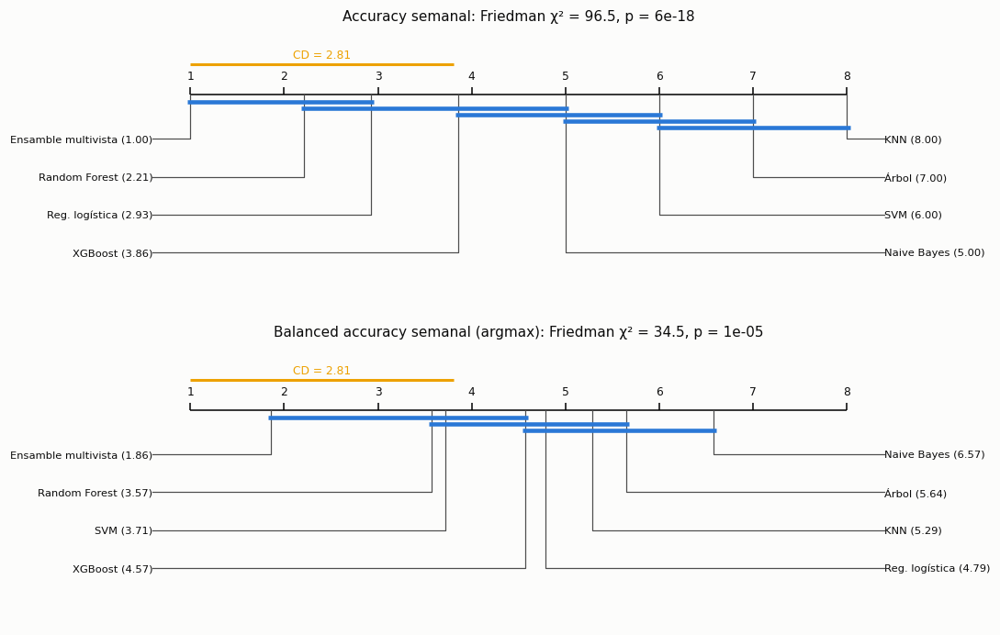

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.4))
for ax, metric, title in [(axes[0], 'accuracy', 'Accuracy semanal'), (axes[1], 'balanced', 'Balanced accuracy semanal (argmax)')]:
    Wm = pd.read_csv(OUT / FINAL / f'semanal_{metric}.csv', index_col=0)
    fr = T.friedman(Wm.to_numpy()); cd = T.nemenyi_cd(fr['k'], fr['n_blocks'])
    T.cd_diagram(list(Wm.columns), fr['avg_ranks'], cd, ax, f'{title}: Friedman χ² = {fr["chi2"]:.1f}, p = {fr["p_value"]:.1g}')
    print(metric, 'δ de Cliff del ensamble frente a cada modelo:',
          {c: round(T.cliffs_delta(Wm.iloc[:, 0], Wm[c]), 2) for c in Wm.columns[1:]})
fig.tight_layout(); P.save(fig, 'e3_propuesto_cd'); plt.show()

**Observado.**
- **Frente a las 4 referencias del curso** (elegidas por la validación anidada): accuracy +0,091 a
  +0,131, BA de 3 clases +0,091 a +0,124 y log-loss −0,14 a −0,31. Todos los IC del bootstrap por
  establecimiento excluyen el 0 y Holm p < 0,05, igual que McNemar.
- La única excepción es la BA de 4 clases frente a SVM con SMOTE: +0,023, con IC [−0,016; 0,058] que
  incluye el 0. Esa referencia gana BA marcando fallecimientos; en la sección 18.9 el ensamble la supera
  con la regla P/λ.
- **DeLong:** el AUC del ensamble es mayor en las 4 clases frente a todas las referencias del curso
  (+0,08 a +0,15 en las clases frecuentes; +0,22 a +0,35 en Fallecimiento; Holm p < 0,001).
- **Frente al XGBoost único con todas las variables y frente al mejor componente:** accuracy +0,004 a
  +0,005, log-loss −0,006 a −0,008, AUC +0,003 a +0,005 en las clases frecuentes. Todas significativas.
- **Friedman** sobre las 14 semanas: χ² = 96,5 (accuracy) y 34,5 (balanced accuracy), p < 0,001.
  - En accuracy el ensamble tiene rango 1,0 (el mejor todas las semanas), con δ de Cliff = 1 frente a los
    7 modelos (efecto grande).
  - En balanced accuracy tiene el mejor rango (1,86) y efecto grande frente a 5 de los 7 modelos; frente
    a SVM, mediano (δ = 0,34).
- **Nemenyi**, con solo 14 semanas como bloques, es más conservador (CD = 2,81):
  - En accuracy, el ensamble se separa de XGBoost, Naive Bayes, SVM, el árbol y KNN, pero no de Random
    Forest ni de la logística (diferencias de rango de 1,21 y 1,93).
  - En balanced accuracy se separa de la logística, KNN, el árbol y Naive Bayes, pero no de Random
    Forest, SVM ni XGBoost.

**Interpretación.** Con la secuencia jerárquica del capítulo 13 (prueba global, comparaciones dirigidas con
Holm, tamaño del efecto), la superioridad frente a los modelos del curso es clara y grande en las pruebas
por caso (bootstrap, McNemar, DeLong). En la comparación semanal, la más conservadora porque solo usa 14
bloques, el ensamble queda primero todas las semanas, pero Nemenyi no alcanza a separarlo de los dos
mejores modelos del curso: con 14 bloques y 8 modelos, ni siquiera ganar todas las semanas basta para
superar la diferencia crítica. Frente al
modelo único con la misma información, la ventaja es estadísticamente sólida porque la prueba es muy
grande (127.391 casos), pero su magnitud práctica es pequeña (medio punto de accuracy).

## 18.9 Fallecimiento con la regla P/λ

Con probabilidades calibradas, la regla del capítulo 17 se aplica sin ajustar nada: marca como
fallecimiento los casos cuya probabilidad, dividida por la frecuencia de la clase, supera a la de las
demás clases.

In [11]:
rows = []
mc = pd.read_csv(C.RESULTS / 'master_clf.csv')
for combo, lab in [(mc.loc[mc.outer_recall_mean.idxmax(), 'combo'], 'Mejor del curso por BA (anidada)'),
                   ('knn|smote|genetic', 'Más fallecimientos detectados del curso')]:
    p = F.load('clf', combo)[0].astype(float); m = metrics(yt, p)
    rows.append({'modelo': f'{lab}: {combo}', 'BA (4 clases)': m['recall'], 'BA (3 clases)': m['ba3'], 'accuracy': m['accuracy'],
                 'fallecimientos acertados (de 39)': m['muertes'], 'casos marcados': m['marcados']})
for rule, lab in [('argmax', 'argmax P'), ('prior', 'argmax P/λ')]:
    m = metrics(yt, pfin, rule)
    rows.append({'modelo': f'Ensamble ({lab})', 'BA (4 clases)': m['recall'], 'BA (3 clases)': m['ba3'], 'accuracy': m['accuracy'],
                 'fallecimientos acertados (de 39)': m['muertes'], 'casos marcados': m['marcados']})
death_tab = pd.DataFrame(rows).set_index('modelo')
death_tab['precisión fallecimiento'] = death_tab['fallecimientos acertados (de 39)'] / death_tab['casos marcados'].replace(0, np.nan)
display(death_tab.round(4))
print('Pliegues externos, regla P/λ: fallecimientos acertados',
      sum(m['prior']['muertes'] for m in fold_vals[FINAL]), 'de', int((y_sub == 0).sum()))

,BA (4 clases),BA (3 clases),accuracy,fallecimientos acertados (de 39),casos marcados,precisión fallecimiento
modelo,,,,,,
Mejor del curso por BA (anidada): svm|smote|random,0.4349,0.4858,0.4794,11,7891,0.0014
Más fallecimientos detectados del curso: knn|smote|genetic,0.3970,0.3926,0.3842,16,29274,0.0005
Ensamble (argmax P),0.4575,0.6101,0.6108,0,0,NaN
Ensamble (argmax P/λ),0.6395,0.5449,0.5405,36,17687,0.0020


Pliegues externos, regla P/λ: fallecimientos acertados 9 de 9


**Observado.**
- Con `argmax` el ensamble no marca ningún fallecimiento: con probabilidades calibradas, la de
  Fallecimiento nunca es la mayor.
- Con `argmax P/λ` acierta **36 de 39** (92 %), con 17.687 casos marcados (precisión 0,20 %). La mejor
  referencia del curso por BA acierta 11 con 7.891 marcados (0,14 %), y la que más detecta, 16 con
  29.274 (0,05 %). En los pliegues externos acierta 9 de 9.
- La BA de 4 clases sube a 0,640 (curso 0,435), pero la accuracy baja a 0,541 y la BA de 3 clases a 0,545,
  porque el 14 % de los casos pasa a «fallecimiento».

**Interpretación.**
- La regla P/λ del capítulo 17 funciona cuando las probabilidades están calibradas, como predice su
  teorema. El ensamble ordena mucho mejor los fallecimientos (AUC 0,94 frente a 0,59 a 0,72 de las
  referencias del curso), gracias a la vista de la lesión: explosiones, electrocuciones y accidentes de
  tránsito concentran los casos.
- **No es un detector utilizable por sí solo:** por cada fallecimiento encontrado hay unas 490 falsas
  alarmas. Son entre 1,5 y 3,7 veces menos por acierto que con las referencias del curso (717 y 1.830).
- La elección entre `argmax` y `argmax P/λ` es de uso, no estadística: `argmax` sirve para clasificar
  (máxima accuracy) y P/λ para no dejar pasar casos graves (máxima balanced accuracy).

## 18.10 Qué pesa en el meta-modelo y matriz de confusión

Pesos que la selección de Caruana asignó a cada modelo base (modelo entrenado para la prueba) y matriz de
confusión del modelo final.

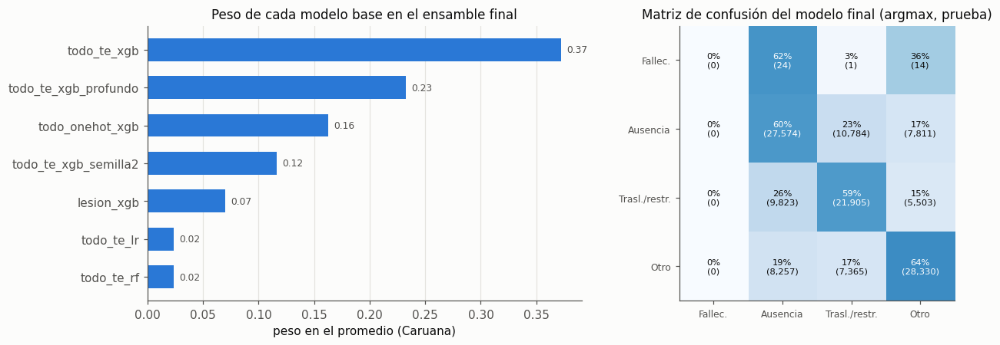

Modelos base sin peso (no los eligió la selección): ['curso_knn', 'curso_logreg', 'curso_naive_bayes', 'curso_random_forest', 'curso_xgboost', 'empleador_te_lr', 'finos_te_xgb', 'lesion_lr', 'todo_onehot_lr']


In [12]:
w = pd.Series(json.loads(str(dfin['weights']))).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.2, 1]})
axes[0].barh(w.index, w.values, color=P.SERIES[0], height=0.6); axes[0].set_xlabel('peso en el promedio (Caruana)')
axes[0].set_title('Peso de cada modelo base en el ensamble final'); axes[0].grid(axis='y', visible=False)
for i_, v_ in enumerate(w.values):
    axes[0].text(v_ + 0.005, i_, f'{v_:.2f}', va='center', fontsize=8, color=P.INK2)
cm = confusion_matrix(yt, pfin.argmax(1), labels=range(4)); pct = cm / cm.sum(1, keepdims=True) * 100
short = ['Fallec.', 'Ausencia', 'Trasl./restr.', 'Otro']
axes[1].imshow(pct, cmap='Blues', vmin=0, vmax=100)
for i in range(4):
    for j in range(4):
        axes[1].text(j, i, f'{pct[i, j]:.0f}%\n({cm[i, j]:,})', ha='center', va='center', fontsize=7.5, color='white' if pct[i, j] > 55 else P.INK)
axes[1].set_xticks(range(4), short, fontsize=8); axes[1].set_yticks(range(4), short, fontsize=8); axes[1].grid(False)
axes[1].set_title('Matriz de confusión del modelo final (argmax, prueba)')
fig.tight_layout(); P.save(fig, 'e3_propuesto_pesos'); plt.show()
print('Modelos base sin peso (no los eligió la selección):', sorted(set(k[5:] for k in dfin.files if k.startswith('base_')) - set(w.index)))

**Observado.**
- La selección de Caruana usó 7 de los 16 modelos:
  - el XGBoost sobre toda la información (37 %);
  - su versión profunda (23 %);
  - el XGBoost sobre one-hot de lugar y lesión (16 %);
  - el XGBoost con otra semilla (12 %);
  - la vista de la lesión con XGBoost (7 %);
  - Random Forest y logística sobre codificación por objetivo (2 % cada uno).
- Ninguno de los 5 modelos del curso entró.
- En la matriz de confusión, las tres clases frecuentes se reconocen entre el 59 % y el 65 %, frente al
  37 % a 65 % de los mejores modelos del capítulo 9. La mejora más grande es en «días de ausencia», que
  pasa de un 37 % a 41 % a un 60 %.

**Interpretación.** El ensamble se apoya en modelos que ven la misma información con sesgos distintos (poca
y mucha profundidad, codificación por objetivo y one-hot, otra partición de la codificación). Sus errores
están menos correlacionados entre sí que los de los modelos del curso, y promediarlos reduce la varianza
sin aumentar el sesgo, que es la razón clásica por la que unir modelos funciona. Los modelos del curso
no aportan nada que los demás no tengan.

## 18.11 Límites

- **Variables nuevas.** La mejora depende de variables que los capítulos 6 a 13 no usaban. Los códigos de
  la lesión los asigna OSHA a partir del relato **después** del reporte, igual que el SOC, así que el
  modelo es retrospectivo: sirve para clasificar casos reportados, no para alertar antes del incidente.
  Se verificó que ninguna categoría revela el desenlace, pero el relato del que salen sí lo menciona en
  algunos fallecimientos (capítulo 16), y no se puede descartar una fuga indirecta pequeña en esa clase.
- **Vista del empleador.** Usa casos de otros establecimientos de la misma empresa. Es información
  disponible al predecir, pero depende de que la empresa ya tenga casos registrados: el 55 % de los casos
  de prueba pertenece a empresas presentes en el desarrollo. Sin esta vista el ensamble pierde alrededor
  de un punto de accuracy (variante B) y sigue superando al curso.
- **Mismo diseño que los capítulos 6 a 13, no el de Iván.** La comparación usa los 5 pliegues por
  establecimiento y la submuestra de 30.030 casos. No se reevaluó en los 3 pliegues temporales del
  capítulo 17, así que sus cifras no se comparan con las de ese capítulo.
- **Sin búsqueda de hiperparámetros propia.** Los modelos del curso usan los hiperparámetros de la
  validación anidada; los modelos nuevos usan valores fijos razonables. La métrica externa sale de
  pliegues que no participaron en ninguna elección, salvo la elección entre las variantes A a G, que se
  hizo mirando los pliegues y la prueba (efecto de selección: la ventaja de G sobre D puede estar algo
  sobrestimada).
- **Regresión.** El ensamble se construyó para la clasificación; no se aplicó a los días de ausencia.
- **Costo.** Entrenar el modelo final tarda unos 28 minutos (frente a segundos de una logística), por los
  16 modelos y los 6 ajustes de cada uno.

# 19. Modelo original: ensamble multivista con selección condicionada por región (SECR)

Este capítulo presenta el modelo original del proyecto: su motivación, su formulación matemática, el algoritmo con
pseudocódigo, sus propiedades demostradas, su complejidad, el código y las pruebas unitarias. La revisión de literatura
y la declaración de novedad están en el capítulo 16. La validación estadística frente a los benchmarks está en el
capítulo 20.

## 19.1 Motivación

El capítulo 18 mostró que un ensamble de modelos especializados en **vistas** distintas del caso supera a cualquier
modelo individual con las mismas variables (G supera a D, un XGBoost con todas las variables, en 5 de 5 pliegues
externos). Las vistas son: el lugar de trabajo (las 9 variables del curso), la lesión (códigos OIICS), los códigos finos
(NAICS-6, SOC-6 y sus cruces, con codificación por objetivo fuera de pliegue) y el empleador. G combina los 16 modelos
base con la selección de ensambles de [caruana2004ensemble], que asigna **un solo vector de pesos para todo el
espacio de entrada**.

Ese diseño tiene dos limitaciones.

1. **La utilidad de cada vista cambia según el tipo de caso.** El código de la lesión discrimina mucho en manufactura
   y poco en salud. La vista del empleador solo ayuda donde hay empresas con muchos casos. Unos pesos globales
   promedian esas diferencias.
2. **Los pesos de Caruana salen de una regla de paso fijo sin garantías.** Cada paso añade un modelo con peso
   $1/(t+1)$, aunque eso empeore la pérdida. No hay certificado de optimalidad y el resultado depende de la
   inicialización y del número de pasos. Además, unos pesos globales que solo dependen del error global se parecen a
   una de las «reglas estándar» contra las que la guía (Cuadro 1) pide contrastar la propuesta.

**SECR** (*selección de ensambles condicionada por región con contracción*) ataca las dos limitaciones:

- aprende un vector de pesos convexos **por región** del espacio de entrada;
- **contrae** esos pesos hacia los globales en proporción a la escasez de datos de la región;
- resuelve cada problema con **Frank-Wolfe con búsqueda lineal exacta**, que da pérdida no creciente, convergencia
  $O(1/t)$ y un certificado de optimalidad.

## 19.2 Postura sobre las variables de la lesión

La tarea es **clasificar el desenlace de un caso ya registrado**. Los códigos OIICS (naturaleza, parte del cuerpo,
evento y fuente) los asigna OSHA a partir del relato del caso, y existen cuando el caso se clasifica: no son información
del futuro. Hay un **riesgo indirecto** en los fallecimientos, porque el relato menciona la muerte en el 54 % de ellos y
algunos códigos de naturaleza pueden reflejarlo. Esta es la postura única del libro (corrige la incoherencia B7 del
capítulo de trazabilidad). Como la comparación del capítulo 20 es pareada, **los benchmarks tienen exactamente las
mismas variables**, así que ninguna ventaja del modelo original viene de tener más información.

**Por qué dos conjuntos de variables.**

- **Entregable 2 (capítulos 6 a 13): 9 variables** (`data.FEATURES`). Son las del lugar de trabajo, la ocupación, el
  tipo de incidente y el horario, con NAICS y SOC agrupados (NAICS-3 y SOC menor). Se eligieron así para que los 140
  modelos con búsqueda anidada fueran computables (unas 210 columnas one-hot) y siguiendo el diseño de los entregables
  1 y 2.
- **Modelo original y comparación pareada (capítulos 18 a 20): `VPLUS`** (`paired.VPLUS`). Son las 9 anteriores más
  los códigos OIICS, NAICS-6, SOC-6, el EIN y la empresa. El capítulo 18 mostró que esa información es la que más mejora
  el problema.
- **En el capítulo 20 los 7 benchmarks reciben `X[VPLUS]`**, las mismas columnas crudas que el original, y cada uno
  aplica su propio preprocesamiento dentro del pliegue (`paired.run_benchmark`).

**Limitación.** El balanceo y el optimizador de cada benchmark (la «mejor combinación» del capítulo 13b) se eligieron
con las 9 variables, no con `VPLUS`. Con las variables ampliadas solo se repite la búsqueda de hiperparámetros dentro
de esa combinación; no se rehicieron las 16 combinaciones por modelo (habría multiplicado por 16 el cómputo). Con
otras variables, la mejor combinación podría ser otra. El cambio de ranking muestra que importa: **KNN pasa del quinto
lugar con 9 variables (BA 0,415, `dashboard_final/data/leaderboard.csv`) al primero con `VPLUS` (BA 0,569,
`results/pareado/resumen_modelos.csv`)**.

## 19.3 Formulación

Sean $M$ modelos base con probabilidades $P_m(x)\in\Delta_K$ ($K=4$ clases) y $n$ casos de entrenamiento con
predicciones **fuera de pliegue** $P_m(x_i)$. Sea $T\in[\varepsilon,1]^{n\times M}$ la matriz de probabilidades de la
clase verdadera:

$$
T_{im} = \max\{P_m(x_i)[y_i],\ \varepsilon\},\qquad \varepsilon = 10^{-6}.
$$

Para pesos $w\in\Delta_M=\{w\ge 0,\ \mathbf 1^\top w=1\}$, la mezcla $q(x)=\sum_m w_m P_m(x)$ es una distribución sobre
las $K$ clases, y su pérdida logarítmica en el caso $i$ es $\ell_i(w) = -\log(T_i^\top w)$. Dada una variable de
compuerta $r(x)\in\{1,\dots,R\}$ de baja cardinalidad, el problema de la región $g$, con $n_g$ casos, es

$$
w_g^\star \in \arg\min_{w\in\Delta_M} F_g(w),\qquad
F_g(w) = \frac{1}{n_g+\lambda}\Big[\sum_{i:\,r(x_i)=g}\ell_i(w) + \frac{\lambda}{n}\sum_{i=1}^{n}\ell_i(w)\Big].
$$

Es decir, $F_g(w) = -\sum_i a_i\log(T_i^\top w)$ con pesos por observación

$$
a_i = \frac{\mathbb 1[r(x_i)=g]}{n_g+\lambda} + \frac{\lambda}{(n_g+\lambda)\,n},\qquad a_i\ge 0,\quad \sum_i a_i = 1 .
$$

El hiperparámetro $\lambda\ge 0$ funciona como **$\lambda$ pseudo-observaciones tomadas de toda la población**:

- con $\lambda=0$ los pesos son puramente locales;
- con $\lambda\to\infty$, $F_g$ tiende a la pérdida global $F_0(w)=-\frac1n\sum_i\log(T_i^\top w)$;
- una región con $n_g\ll\lambda$ queda cerca de los pesos globales, y una con $n_g\gg\lambda$ usa sus propios datos.

Es la misma lógica de la contracción empírica-bayesiana, aplicada a pesos de combinación en lugar de a medias.
Las regiones con menos de $n_{\min}$ casos usan directamente los pesos globales $w_0^\star=\arg\min F_0$.

**Predicción.** Para un caso nuevo, con $\pi$ las proporciones de clase del entrenamiento,

$$
q(x) = \sum_{m=1}^{M} w_{r(x),m}^\star\,P_m(x),\qquad \hat y(x)=\arg\max_k\ q_k(x)\,/\,\pi_k^{\alpha}.
$$

Con $\alpha=0$ la decisión es el $\arg\max$. Con $\alpha=1$ es la regla que maximiza la balanced accuracy esperada si
$q$ está calibrada [collell2018simple]. $\alpha$ es un hiperparámetro.

## 19.4 Algoritmo

```text
Algoritmo SECR
Entradas : P (n × M × K) probabilidades fuera de pliegue de los modelos base; y (n); región r (n);
           λ ≥ 0; T_max pasos; tolerancia τ; tamaño mínimo n_min; α ∈ [0, 1]
Salidas  : w₀ ∈ Δ_M (pesos globales); {w_g ∈ Δ_M} (pesos por región); π (prior de clases)

 1  T[i,m] ← max(P[i,m,y_i], ε)                                   # ec. (eq-T)
 2  w₀ ← FW(T, a = 1/n, inicio = mejor vértice)                   # pesos globales
 3  para cada región g con n_g ≥ n_min:
 4      a_i ← 1[r_i = g]/(n_g + λ) + λ/((n_g + λ)·n)               # ec. (eq-a)
 5      w_g ← FW(T, a, inicio = w₀)
 6  π_k ← proporción de la clase k en y
 7  devolver w₀, {w_g}, π

Función FW(T, a, w):                                               # Frank-Wolfe con búsqueda lineal exacta
 8  para t = 0, 1, …, T_max:
 9      q ← T w                                                    # O(nM)
10      ∇ ← −Tᵀ (a ⊘ q)                                            # gradiente, O(nM)
11      s ← argmin_m ∇_m                                           # oráculo lineal: un vértice del símplex
12      G ← ∇ᵀ w − ∇_s                                             # brecha de Frank-Wolfe (≥ 0)
13      si G ≤ τ o t = T_max: devolver w                           # criterios de parada
14      δ ← T[:, s] − q ;  φ'(γ) = −Σ_i a_i δ_i / (q_i + γ δ_i)
15      γ ← 1 si φ'(1) ≤ 0; si no, la raíz de φ' en (0, 1) por bisección (25 pasos)
16      w ← (1 − γ) w + γ e_s
```

**Hiperparámetros y su optimización.** El algoritmo tiene cinco hiperparámetros: la variable de compuerta (ninguna,
tipo de incidente, tipo de establecimiento, sector NAICS-2, SOC mayor, o la primera cifra de los códigos de naturaleza,
evento o parte), $\lambda\in[1,10^4]$, $T_{\max}\in[5,100]$, $n_{\min}\in[50,3000]$ y $\alpha\in[0,1]$. Se optimizan con
**búsqueda bayesiana TPE** (Optuna; [akiba2019optuna]). La búsqueda tiene 16 configuraciones, igual que los
benchmarks del capítulo 7, y evalúa la balanced accuracy en 3 pliegues internos por establecimiento, formados solo con
las predicciones fuera de pliegue del entrenamiento externo. El pliegue externo nunca participa
(`src/osha_e3/original_eval.py`, función `tune`).

## 19.5 Propiedades demostradas

En toda esta sección, $F(w)=-\sum_i a_i\log(T_i^\top w)$ con $a\in\Delta_n$ y $T\in[\varepsilon,1]^{n\times M}$; esto
cubre $F_0$ y todas las $F_g$.

**Proposición 1 (convexidad).** $F$ es convexa en $\Delta_M$.

*Demostración.* $w\mapsto T_i^\top w$ es lineal y $\log$ es cóncava, así que $\log(T_i^\top w)$ es cóncava y
$-a_i\log(T_i^\top w)$ es convexa porque $a_i\ge0$. Una suma de convexas es convexa. Equivalentemente,
$\nabla^2F(w)=\sum_i a_i\,T_iT_i^\top/(T_i^\top w)^2\succeq0$. $\square$

**Proposición 2 (factibilidad y pérdida no creciente).** Si $w^0\in\Delta_M$, todos los iterados cumplen
$w^t\in\Delta_M$ y $F(w^{t+1})\le F(w^t)$.

*Demostración.* $w^{t+1}=(1-\gamma)w^t+\gamma e_s$ con $\gamma\in[0,1]$ es una combinación convexa de dos puntos del
símplex. La búsqueda lineal minimiza $\varphi(\gamma)=F(w^t+\gamma(e_s-w^t))$ sobre $[0,1]$, que contiene
$\gamma=0$, así que $F(w^{t+1})=\min_\gamma\varphi(\gamma)\le\varphi(0)=F(w^t)$. La búsqueda es exacta porque
$\varphi$ es convexa (restricción de una convexa a un segmento) con $\varphi'(0)=-G_t\le0$. Si $\varphi'(1)\le0$ el
mínimo está en $\gamma=1$. Si no, $\varphi'$ es continua y creciente, tiene una única raíz en $(0,1)$, y la bisección la
encuentra con error $2^{-25}$. $\square$

**Proposición 3 (certificado de optimalidad).** Para todo $w\in\Delta_M$, $F(w)-F^\star\le G(w)$, con
$G(w)=\nabla F(w)^\top w-\min_m\nabla F(w)_m$.

*Demostración.* Por convexidad,
$F^\star=F(w^\star)\ge F(w)+\nabla F(w)^\top(w^\star-w)\ge F(w)+\min_{v\in\Delta_M}\nabla F(w)^\top(v-w)=F(w)-G(w)$,
porque una función lineal alcanza su mínimo sobre el símplex en un vértice. $\square$

En consecuencia, el criterio de parada $G_t\le\tau$ garantiza una solución $\tau$-óptima. La prueba unitaria
`test_perdida_no_creciente_y_brecha_certifica` lo verifica numéricamente.

**Proposición 4 (convergencia $O(1/t)$).** $F(w^t)-F^\star\le\dfrac{2C_F}{t+2}$, con constante de curvatura
$C_F\le 4/\varepsilon^2$.

*Demostración.* Para $w\in\Delta_M$, $T_i^\top w\in[\varepsilon,1]$, porque es un promedio ponderado de valores en
$[\varepsilon,1]$. Para $d=v-w$ con $v,w\in\Delta_M$ se tiene $\|d\|_1\le2$ y $|T_i^\top d|\le\|d\|_1\max_m T_{im}\le2$,
así que $d^\top\nabla^2F(w)d=\sum_ia_i(T_i^\top d)^2/(T_i^\top w)^2\le4/\varepsilon^2$. Esto acota la constante de
curvatura de [jaggi2013revisiting]. Su teorema 1 da la tasa $2C_F/(t+2)$ para el paso $2/(t+2)$. Con búsqueda
lineal exacta, cada paso reduce $F$ al menos tanto como ese paso, porque el paso $2/(t+2)$ es uno de los candidatos de
la búsqueda, y la misma inducción vale. $\square$

La cota es conservadora ($\varepsilon$ es pequeño). En la práctica la brecha cae varios órdenes de magnitud en pocas
decenas de iteraciones (figura de convergencia, sección 20.5).

**Proposición 5 (terminación y límites de la contracción).** (a) FW termina en a lo sumo $T_{\max}+1$ iteraciones.
(b) Con $\lambda\to\infty$, $F_g\to F_0$ uniformemente en $\Delta_M$, y todo punto límite de minimizadores de $F_g$
minimiza $F_0$. (c) Con $\lambda=0$, $F_g$ solo depende de los casos de la región.

*Demostración.* (a) es inmediata por el criterio de parada. (b)
$F_g-F_0=\frac{n_g}{n_g+\lambda}\big(\bar F_g-F_0\big)$, con $\bar F_g$ la pérdida media de la región. Ambas están
acotadas en $[0,-\log\varepsilon]$, así que $\sup_{\Delta_M}|F_g-F_0|\le\frac{n_g}{n_g+\lambda}(-\log\varepsilon)\to0$.
Como $\Delta_M$ es compacto y las funciones son continuas, la convergencia uniforme preserva los puntos límite de los
minimizadores. (c) es inmediata de (eq-a). $\square$

**Proposición 6 (Caruana como caso particular).** La selección de Caruana con reemplazo, después de $k_0$ modelos
iniciales, actualiza $w^{t+1}=(1-\gamma_t)w^t+\gamma_te_s$ con $\gamma_t=1/(k_0+t+1)$ y
$s=\arg\min_mF((1-\gamma_t)w^t+\gamma_te_m)$. Es un esquema de tipo Frank-Wolfe sin regiones ($R=1$), con un paso fijo
predeterminado y un oráculo que evalúa la pérdida verdadera en lugar de su linealización.

*Demostración.* Si $c^t$ son los conteos de selección y $k=k_0+t$ su total, $w^t=c^t/k$. Añadir el modelo $s$ da
$w^{t+1}=(c^t+e_s)/(k+1)=\frac{k}{k+1}w^t+\frac1{k+1}e_s$. $\square$

Como el paso es fijo, Caruana puede **aumentar** la pérdida: se ve cuando el mejor movimiento sería $\gamma=0$.
Tampoco tiene un certificado como el de la proposición 3. SECR conserva el espíritu de Caruana (pesos convexos sobre
una biblioteca de modelos, ajustados con la pérdida fuera de pliegue) y le añade regiones, contracción y garantías.

## 19.6 Complejidad

| Etapa | Tiempo | Memoria |
|---|---|---|
| Matriz $T$ (ec. (eq-T)) | $O(nM)$ | $O(nM)$ |
| Una iteración de FW | $O(nM + Bn)$, con $B=25$ bisecciones | $O(n)$ |
| Ajuste de SECR | $O\big((R+1)\,T_{\max}\,n\,(M+B)\big)$ | $O(nM+RM)$ |
| Búsqueda TPE del combinador | $16\times3$ ajustes de SECR | — |
| Nivel 0 (16 modelos base, 5 pliegues + reajuste) | domina el costo: $6\times\sum_m \text{costo}_m(n)$ | — |
| Predicción de un caso | $O(MK)$ más la de los 16 modelos base | $O(RM)$ |

![Tiempo de ajuste de SECR (30 iteraciones) en datos sintéticos al variar el número de casos $n$, de modelos base $M$ y de regiones $R$ (`scripts/complejidad_secr.py`).](figures/e3_complejidad_secr.png)

*Tiempo de ajuste de SECR (30 iteraciones) en datos sintéticos al variar el número de casos $n$, de modelos base $M$ y de regiones $R$ (`scripts/complejidad_secr.py`).*

La la figura «fig-complejidad-secr» contrasta el análisis con tiempos medidos. El tiempo crece de forma aproximadamente
lineal con $n$ y con $R$, como predice la tabla. Con $M\le32$ el término $Bn$ de la bisección y el costo fijo de
Python por iteración pesan más que $nM$, así que la dependencia en $M$ solo se nota con $M=64$. Con los tamaños del
proyecto ($n\approx24\,000$, $M=16$, $R\le25$), SECR se ajusta en segundos. El costo del modelo original lo domina el
nivel 0. **Tiempo de entrenamiento del original por pliegue externo** (nivel 0 + búsqueda TPE + SECR, con 2 hilos y en
paralelo con otras celdas; columna `train_s` de `results/pareado/pliegues.csv`): **media 51 min, mediana 40 min, rango
30–91 min**. Es la única cifra de tiempo del original que se usa en el libro; los 22–24 min del capítulo 18 son de otra
corrida (sin TPE y con menos procesos en paralelo).

## 19.7 Implementación y pruebas

La clase `ConditionalEnsembleSelection` hereda de `BaseEstimator` y `ClassifierMixin`, implementa `fit`,
`predict_proba` y `predict`, y valida sus entradas con `check_X_y` y `check_array`. Su entrada es la matriz de
meta-variables $[P_1|\dots|P_M|r]$. `OriginalModel` (`src/osha_e3/original_final.py`) encadena el nivel 0, la
búsqueda TPE y SECR, y es el artefacto que usa el dashboard. Solo usa numpy para la parte numérica propia.

```python
def frank_wolfe(T, a, n_steps=50, tol=1e-6, w0=None):
    """Minimiza ``F(w) = −Σ_i a_i log(T_i · w)`` sobre el símplex con Frank-Wolfe y búsqueda lineal exacta.

    Parameters
    ----------
    T : ndarray (n, M)
        Probabilidad de la clase verdadera según cada modelo (``≥ EPS``).
    a : ndarray (n,)
        Pesos no negativos de las observaciones (suman 1).
    n_steps : int
        Máximo de iteraciones (criterio de parada 1).
    tol : float
        Tolerancia de la brecha de Frank-Wolfe (criterio de parada 2).
    w0 : ndarray (M,) or None
        Punto inicial en el símplex; por defecto, el mejor vértice.

    Returns
    -------
    w : ndarray (M,)
    history : dict
        ``loss`` y ``gap`` por iteración (curva de convergencia).
    """
    n, M = T.shape
    if w0 is None:
        w = np.zeros(M)
        w[np.argmin(-(a @ np.log(T)))] = 1.0
    else:
        w = np.asarray(w0, dtype=float).copy()
    loss, gaps = [], []
    for _ in range(int(n_steps) + 1):
        q = T @ w
        f = -float(a @ np.log(q))
        grad = -(T.T @ (a / q))
        s = int(np.argmin(grad))
        gap = float(grad @ w - grad[s])
        loss.append(f)
        gaps.append(gap)
        if gap <= tol or len(loss) > n_steps:
            break
        delta = T[:, s] - q  # dirección en el espacio de q: q(γ) = q + γ δ

        def dphi(g):
            return -float(a @ (delta / (q + g * delta)))

        if dphi(1.0) <= 0:  # la pérdida sigue bajando hasta el vértice
            gamma = 1.0
        else:  # φ'(0) = −gap < 0 < φ'(1): raíz única por convexidad
            lo, hi = 0.0, 1.0
            for _ in range(25):  # |γ − γ*| ≤ 2^-25
                mid = 0.5 * (lo + hi)
                lo, hi = (mid, hi) if dphi(mid) < 0 else (lo, mid)
            gamma = 0.5 * (lo + hi)
        w = (1 - gamma) * w
        w[s] += gamma
    return w, {'loss': np.array(loss), 'gap': np.array(gaps)}


def true_class_matrix(P, y):
    """``T[i, m] = P[i, m, y_i]`` recortada a ``EPS``. ``P`` tiene forma (n, M, K)."""
    return np.clip(P[np.arange(len(y)), :, y], EPS, 1.0)


class ConditionalEnsembleSelection(BaseEstimator, ClassifierMixin):
    """Selección de ensambles condicionada por región con contracción (SECR).

    La entrada ``X`` es la matriz de meta-variables ``[P_1 | P_2 | … | P_M | región]``: las probabilidades de
    los ``M`` modelos base (``M·K`` columnas, en bloques de ``K``) y, al final, el código entero de la región
    (0, 1, …). Con ``gate=False`` la última columna se ignora y el modelo aprende pesos globales.

    Parameters
    ----------
    n_classes : int
        Número de clases ``K``.
    lam : float
        Fuerza de la contracción hacia los pesos globales (pseudo-observaciones, ec. 1).
    n_steps : int
        Máximo de iteraciones de Frank-Wolfe por región.
    min_region : int
        Regiones con menos casos de entrenamiento usan los pesos globales.
    alpha : float in [0, 1]
        Exponente de la corrección por prior en la decisión.
    gate : bool
        Si se usan regiones (``True``) o solo pesos globales (``False``).
    tol : float
        Tolerancia de la brecha de Frank-Wolfe.
    """

    def __init__(self, n_classes=4, lam=100.0, n_steps=50, min_region=200, alpha=1.0, gate=True, tol=1e-7):
        self.n_classes, self.lam, self.n_steps, self.min_region = n_classes, lam, n_steps, min_region
        self.alpha, self.gate, self.tol = alpha, gate, tol

    def _split(self, X):
        K = self.n_classes
        if (X.shape[1] - 1) % K or X.shape[1] < K + 1:
            raise ValueError(f'X debe tener M·{K} columnas de probabilidades más una de región; tiene {X.shape[1]}.')
        P = X[:, :-1].reshape(len(X), -1, K)
        if np.any(P < 0) or np.any(P > 1 + 1e-6):
            raise ValueError('Las probabilidades de los modelos base deben estar en [0, 1].')
        r = X[:, -1]
        if np.any(r < 0) or np.any(r != np.round(r)):
            raise ValueError('La región debe ser un entero no negativo.')
        return P, r.astype(int)

    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=float)
        if self.lam < 0 or self.n_steps < 0 or not 0 <= self.alpha <= 1:
            raise ValueError('Se requiere lam >= 0, n_steps >= 0 y 0 <= alpha <= 1.')
        self.classes_ = np.arange(self.n_classes)
        y = y.astype(int)
        if y.min() < 0 or y.max() >= self.n_classes:
            raise ValueError(f'y debe estar codificada 0..{self.n_classes - 1}.')
        P, r = self._split(X)
        self.n_models_ = P.shape[1]
        T = true_class_matrix(P, y)
        n = len(y)
        self.weights_global_, self.history_ = frank_wolfe(T, np.full(n, 1.0 / n), self.n_steps, self.tol)
        self.weights_region_ = {}
        if self.gate:
            for g in np.unique(r):
                m = r == g
                ng = int(m.sum())
                if ng < self.min_region:
                    continue
                a = np.full(n, self.lam / ((ng + self.lam) * n))
                a[m] += 1.0 / (ng + self.lam)
                self.weights_region_[int(g)], _ = frank_wolfe(T, a, self.n_steps, self.tol, self.weights_global_)
        self.prior_ = np.maximum(np.bincount(y, minlength=self.n_classes) / n, 1e-12)
        return self

    def region_weights(self, r):
        """Matriz (n, M) de pesos que corresponde a cada código de región."""
        W = np.tile(self.weights_global_, (len(r), 1))
        for g, w in self.weights_region_.items():
            W[r == g] = w
        return W

    def predict_proba(self, X):
        check_is_fitted(self, 'weights_global_')
        X = check_array(X, dtype=float)
        P, r = self._split(X)
        if P.shape[1] != self.n_models_:
            raise ValueError(f'Se esperaban {self.n_models_} modelos base; llegaron {P.shape[1]}.')
        q = np.einsum('nm,nmk->nk', self.region_weights(r), P)
        return q / q.sum(axis=1, keepdims=True)

    def decide(self, q):
        return (q / self.prior_ ** self.alpha).argmax(axis=1)

    def predict(self, X):
        return self.classes_[self.decide(self.predict_proba(X))]

    def score(self, X, y, sample_weight=None):
        """Balanced accuracy (la métrica principal del proyecto)."""
        return balanced_accuracy_score(y, self.predict(X), sample_weight=sample_weight)


```

**Pruebas unitarias** (`pytest tests/test_combinador.py`; las 8 pasan):

| Prueba | Qué verifica | Exigencia de la guía §5.4 |
|---|---|---|
| `test_i_aprende_la_solucion_conocida` | Dos regiones donde un modelo distinto es casi perfecto en cada una: SECR recupera $w_1\approx e_0$, $w_2\approx e_1$ (pesos > 0,9) y baja la log-loss frente a los pesos globales | (i) aprende con solución conocida |
| `test_ii_reproducible` | Mismos datos, mismas probabilidades (algoritmo determinista) | (ii) reproducibilidad |
| `test_iii_entradas_invalidas` | Columnas que no forman bloques de $K$, probabilidades fuera de $[0,1]$, $\alpha>1$, etiquetas fuera de rango, predecir sin ajustar, otro número de modelos base | (iii) entradas inválidas |
| `test_iv_clone` | `sklearn.base.clone` copia hiperparámetros y no el estado | (iv) `clone` |
| `test_pesos_en_simplex_y_probabilidades_validas` | Pesos $\ge0$ que suman 1 y probabilidades válidas | Proposición 2 |
| `test_perdida_no_creciente_y_brecha_certifica` | $F(w^{t+1})\le F(w^t)$ y $F(w^t)-F^\star\le G_t$ en 300 iteraciones | Proposiciones 2 y 3 |
| `test_contraccion_extrema_da_pesos_globales` | Con $\lambda=10^9$ los pesos regionales coinciden con los globales | Proposición 5(b) |
| `test_regiones_nuevas_usan_pesos_globales` | Una región no vista usa $w_0$ | Robustez |

Además, `tests/test_ensemble.py` (5 pruebas) verifica la codificación por objetivo fuera de pliegue del nivel 0, y
`tests/test_candado_prueba.py` (2 pruebas) verifica que la prueba de octubre a diciembre esté bloqueada. Cuatro de las
pruebas del ensamble necesitan `results/cache/osha_2023_fullcodes.parquet`, que no se versiona porque contiene el EIN y
el nombre de la empresa. Se genera con `python scripts/build_fullcodes.py` desde el CSV de OSHA y queda idéntico al
usado en las corridas (`--check`: 890 372 filas y 0 diferencias). Con ese archivo, `pytest tests/` da **44 de 44
pruebas aprobadas** (ensamble, SECR, candado y PT-bagging) con scikit-learn 1.3.0, imbalanced-learn 0.12.4 y XGBoost
2.1.3.

## 19.8 Ablación e interpretabilidad

El estudio de ablación (sección 20.4) retira cada componente por separado:

- las regiones (pesos solo globales);
- la corrección por prior ($\alpha=0$);
- la regla de combinación completa, reemplazada por cada regla estándar: promedio simple, pesos por error global,
  stacking lineal y Caruana (G).

Todas las variantes usan los mismos modelos base, las mismas predicciones y los mismos pliegues. La interpretabilidad
del modelo original (SHAP exacto por grupos de variables, comparado con el mejor benchmark) está en la sección 20.6 y
en el dashboard.

## 19.9 Candidatos probados (guía §13)

Antes del modelo final se probaron 13 diseños. La guía (§13) pide declarar qué se miró para elegir, porque elegir entre
varios candidatos introduce un sesgo optimista en el que gana. La tabla resume cada diseño con sus cifras guardadas.

| Diseño | Capítulo | Datos usados para elegir | Resultado |
|---|---|---|---|
| PT-bagging (bagging + umbral = prior) | 17 | Pliegues temporales del diseño de Iván (3 pliegues) | BA 0,386 frente a 0,516 de la referencia (XGBoost + `class_weight` + bayes); 1 de 12 fallecimientos (`results/modelo_original/cribado.csv`) |
| MultiRandBal (Random Balance) | 17 | Pliegues temporales | BA 0,361; 0 de 12 fallecimientos |
| Metaclasificación jerárquica | 17 | Pliegues temporales | BA 0,371; 0 fallecimientos marcados |
| HAFL-XGBoost (pérdida focal propia) | 17 | Pliegues temporales | BA 0,522 frente a 0,516 de la referencia, igual que su ablación sin pérdida focal (0,523): no mejora por el mecanismo (`cribado_r2.csv`) |
| Frank–Hall ordinal (clases 2 a 4) | 17 | Pliegues temporales | BA de 3 clases 0,525 frente a 0,527 del mejor base: no mejora (`tabla_r4.csv`) |
| A. Stacking con los 5 modelos del curso | 18 | Pliegues externos (rep. 0) **y prueba** | BA externa 0,397, accuracy 0,501 |
| B. Stacking multivista sin empleador | 18 | Pliegues externos (rep. 0) y prueba | BA 0,457, accuracy 0,578 |
| C. Stacking multivista (4 vistas) | 18 | Pliegues externos (rep. 0) y prueba | BA 0,466, accuracy 0,586 |
| D. Un XGBoost con todas las variables | 18 | Pliegues externos (rep. 0) y prueba | BA 0,469, accuracy 0,590 |
| E. C + 3 modelos con toda la información | 18 | Pliegues externos (rep. 0) y prueba | BA 0,468, accuracy 0,590 |
| F. 16 modelos base + meta-modelo logístico | 18 | Pliegues externos (rep. 0) y prueba | BA 0,471, accuracy 0,591 |
| G. 16 modelos base + selección de Caruana | 18 | Pliegues externos (rep. 0) y prueba | BA 0,477, accuracy 0,599: **elegido** como nivel 0 del original |
| **SECR sobre los 16 modelos de G (final)** | 19–20 | **Pliegues internos** (TPE dentro de cada pliegue externo) | BA 0,591 ± 0,087 en 15 pliegues pareados; no superior a KNN (capítulo 20) |

Las cifras de A a G son BA y accuracy con `argmax`, media de los 5 pliegues externos de la repetición 0
(`results/ensemble/*/fold*.npz`).

**Cómo se eligió SECR y qué se miró.**

- **El diseño de SECR se fijó antes de ver cualquier resultado del experimento pareado.** El 22 de octubre a las 23:30 el
  equipo eligió «G + combinador condicional por región». La regla, sus hiperparámetros y sus rangos de búsqueda se
  programaron antes de correr la primera celda y no se cambiaron después.
- **Sus hiperparámetros los eligió la búsqueda TPE con las predicciones internas** de cada pliegue externo. El pliegue
  externo no participa (`original_eval.tune`).
- **Los 15 pliegues del veredicto sí se miraron, después de fijar el modelo**: para el análisis de R3, la ablación
  (20.4) y la sensibilidad (20.7). Ninguna de esas miradas cambió el modelo. La sensibilidad mostró que una versión con
  pesos globales habría dado más BA (≈ 0,62 frente a 0,591), y no se adoptó, porque sería elegir con los pliegues del
  veredicto.
- **Decisiones tomadas durante la corrida, y por qué no favorecen al original.**
  - El recorte de 5×5 a 3×5 se decidió por tiempo de cómputo, antes de tener métricas.
  - Al ver en la repetición 0 que KNN era el benchmark más fuerte, se completaron sus repeticiones 1 y 2. Eso endurece
    la comparación contra el original.
  - Random Forest y Naive Bayes se completaron al final, con tiempo sobrante; no cambian la comparación con KNN.
- **Fuente de sesgo que se declara**: el nivel 0 (G) se eligió entre A–G mirando los 5 pliegues de los capítulos 6 a
  13, que son la repetición 0 del capítulo 20 (`paired.outer_folds(0)`), y la prueba. En la repetición 0 el original
  supera a KNN por +0,035 de BA; en las repeticiones 1 y 2, que no se habían visto, por +0,006 y +0,027 (sección 20.6).


# 20. Validación estadística del modelo original (R3)

Este capítulo verifica si el modelo original (ensamble multivista + SECR, capítulo 19) **supera** a los benchmarks
según la definición operativa de la guía (§6.1):

1. su BA media del bucle externo es mayor que la del mejor benchmark y que la de la mejor combinación de cada uno de
   los 7 modelos;
2. al menos tres pruebas de hipótesis distintas rechazan la igualdad, con p ajustado por Holm < 0,05, y al menos una
   es global;
3. el tamaño del efecto no es despreciable: |δ de Cliff| ≥ 0,147.

**Protocolo común (guía §5.3 y §6.2).**

- **Mismas variables.** Los 7 benchmarks (la mejor combinación de balanceo y optimizador de cada modelo, capítulo 13b)
  se reentrenan con las mismas variables crudas que usa el original: las 9 del curso, los códigos OIICS de la lesión,
  NAICS-6, SOC-6 y el empleador. Cada uno con su propio preprocesamiento aprendido dentro del pliegue.
- **Mismas particiones.** Validación externa repetida por establecimiento. La repetición 0 es la partición de los
  capítulos 6 a 13; las repeticiones 1 y 2 usan semillas `seed_for('outer', r)` fijadas antes de correr.
  **Se planeó 5×5 y se recortó a 3×5 (15 pliegues) por tiempo de cómputo**, con el orden de recorte fijado
  antes de ver resultados: las repeticiones 3 y 4 se cortaron para todos los modelos, y Random Forest y Naive
  Bayes (lentos con SMOTE/ADASYN sobre las variables ampliadas) quedaron solo con la repetición 0. KNN, que
  resultó el benchmark más fuerte en la repetición 0, se completó en las 3 repeticiones. Al final de la noche sobró
  tiempo y Random Forest y Naive Bayes también se completaron, así que los 8 modelos tienen las 15 celdas.
- **Mismo presupuesto.** Búsqueda interna de 16 configuraciones con 3 pliegues internos para todos. Los benchmarks
  buscan con su optimizador ganador; el original busca sus hiperparámetros del combinador con TPE.
- **La prueba de octubre a diciembre no se usa** (está bloqueada por código): todas las pruebas son sobre pliegues
  externos. Por eso McNemar y DeLong «sobre el conjunto de prueba» (Figura 4 de la guía) se reemplazan por pruebas
  sobre pliegues que el Cuadro 3 admite: Nadeau–Bengio, Wilcoxon–Holm y la prueba bayesiana con ROPE.

Código: `src/osha_e3/paired.py` (corrida), `src/osha_e3/original_eval.py` (TPE anidado y ablación),
`src/osha_e3/stats_tests.py` (pruebas) y `scripts/analyze_paired.py` (tablas). Las corridas cuestan horas y sus
resultados están versionados en `results/pareado/`; este capítulo los lee.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from osha_e3 import config as C
R = C.RESULTS / 'pareado'
res = json.loads((R / 'resumen.json').read_text(encoding='utf-8'))
f = pd.read_csv(R / 'pliegues.csv')
PRETTY = {'original': 'Original (SECR)', 'knn': 'KNN', 'naive_bayes': 'Naive Bayes', 'logreg': 'Reg. logística',
          'tree': 'Árbol', 'random_forest': 'Random Forest', 'xgboost': 'XGBoost', 'svm': 'SVM'}
print('Celdas (repetición × pliegue) por modelo:', res['n_cells'])
print('Universo con las 15 celdas:', [PRETTY[m] for m in res['universe_25']])

Celdas (repetición × pliegue) por modelo: {'knn': 15, 'logreg': 15, 'naive_bayes': 15, 'original': 15, 'random_forest': 15, 'svm': 15, 'tree': 15, 'xgboost': 15}
Universo con las 15 celdas: ['Original (SECR)', 'SVM', 'Árbol', 'Reg. logística', 'XGBoost', 'KNN', 'Random Forest', 'Naive Bayes']


## 20.1 Tabla resumen

Media ± desviación estándar de la balanced accuracy en los pliegues externos, intervalo bootstrap BCa del 95 % de la
media, otras métricas y tiempos (entrenamiento = búsqueda + reajuste por pliegue; inferencia por caso). La columna
«BA rep. 0» usa solo los 5 pliegues de la repetición 0, que todos los modelos tienen.

In [2]:
s = pd.DataFrame(res['summary_raw'])
tab = pd.DataFrame({
    'Modelo': s.model.map(PRETTY), 'Balanceo': s.balance, 'Optimizador': s.optimizer, 'Pliegues': s.n_pliegues,
    'BA media ± d.e.': [f'{m:.4f} ± {d:.4f}' for m, d in zip(s.ba_mean, s.ba_sd)],
    'IC BCa 95 %': [f'[{a:.4f}, {b:.4f}]' for a, b in zip(s.ba_ci_lo, s.ba_ci_hi)],
    'BA rep. 0': s.ba_rep0_mean.round(4), 'F1 macro': s.f1_mean.round(4), 'AUC macro': s.auc_mean.round(4),
    'Log-loss': s.log_loss_mean.round(4), 'Entrenamiento (s/pliegue)': s.train_s_mean.round(0),
    'Inferencia (ms/caso)': s.ms_case_mean.round(3)})
tab

,Modelo,Balanceo,Optimizador,Pliegues,BA media ± d.e.,IC BCa 95 %,BA rep. 0,F1 macro,AUC macro,Log-loss,Entrenamiento (s/pliegue),Inferencia (ms/caso)
0,Original (SECR),interno (α),bayes (TPE) del combinador,15,0.5912 ± 0.0869,"[0.5413, 0.6281]",0.5910,0.4437,0.8171,0.8428,3085.0,2.468
1,KNN,smote,genetic,15,0.5686 ± 0.0776,"[0.5261, 0.6020]",0.5563,0.3783,0.7635,1.5723,3854.0,12.282
2,SVM,smote,random,15,0.5374 ± 0.0846,"[0.4954, 0.5781]",0.5321,0.4396,0.8002,1.0067,335.0,0.010
3,Reg. logística,adasyn,bayes,15,0.5228 ± 0.1156,"[0.4648, 0.5782]",0.4912,0.4245,0.7757,0.9512,574.0,0.008
4,XGBoost,class_weight,bayes,15,0.4660 ± 0.0522,"[0.4464, 0.4990]",0.4741,0.4331,0.8002,0.8678,260.0,0.109
5,Random Forest,smote,bayes,15,0.4537 ± 0.0470,"[0.4361, 0.4858]",0.4669,0.4291,0.8044,0.8742,3013.0,0.089
6,Naive Bayes,adasyn,genetic,15,0.4260 ± 0.0450,"[0.4087, 0.4563]",0.4349,0.3984,0.7758,1.5071,386.0,0.015
7,Árbol,class_weight,bayes,15,0.4161 ± 0.0830,"[0.3731, 0.4534]",0.4636,0.3507,0.6507,1.1050,20.0,0.008


**Interpretación.** Con las mismas variables y particiones, el modelo original tiene la **BA media más alta**
(0,591 ± 0,087 en 15 pliegues), seguido de KNN (0,569), SVM (0,537) y la logística (0,523). También tiene la mejor
log-loss (0,843 frente a 0,868 a 1,57 de los benchmarks), el mejor AUC macro (0,817) y el mejor F1 macro (0,444).
El ranking cambió respecto al entregable 2: con las variables ampliadas, **KNN pasa a ser el mejor benchmark** (con 9
variables era el quinto) y el árbol cae al último lugar. Los intervalos BCa de la BA del original y de KNN se solapan
ampliamente ([0,541; 0,628] y [0,526; 0,602]). El original tarda 51 min de media por pliegue en entrenar (mediana 40, rango
30–91; nivel 0 + TPE + SECR, columna `train_s`) y 2,5 ms por caso en predecir.

## 20.2 Prueba global: Friedman y diagrama de diferencia crítica

Friedman (con la corrección F de Iman y Davenport) compara todos los modelos a la vez, con los pliegues como bloques
y **el modelo original incluido en el universo**. Si rechaza, Nemenyi indica qué pares difieren: dos modelos cuya
distancia de rangos medios es menor que la diferencia crítica (CD) no se distinguen. Se hace con (a) los modelos que
tienen las 15 celdas (3 repeticiones × 5 pliegues) y (b) los 8 modelos en los 5 pliegues de la repetición 0.

15 pliegues: k = 8, N = 15, χ² = 48.44, p = 2.91e-08; F de Iman-Davenport = 11.99, p = 5.76e-11; CD = 2.711
repetición 0 (5 pliegues): k = 8, N = 5, χ² = 12.33, p = 9.01e-02; F de Iman-Davenport = 2.18, p = 6.77e-02; CD = 4.695


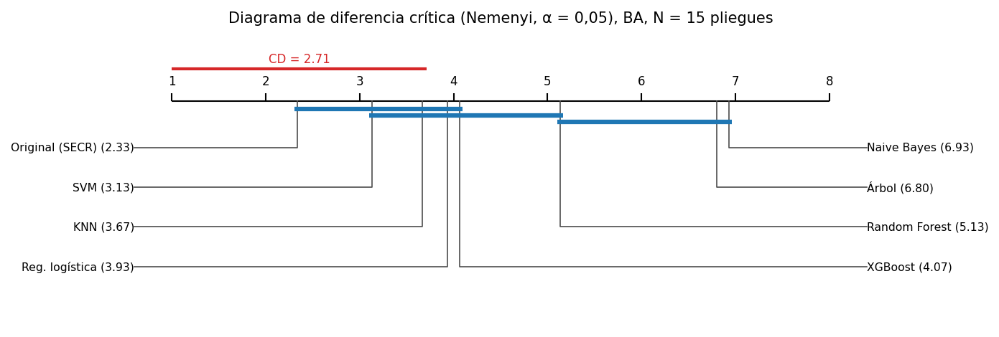

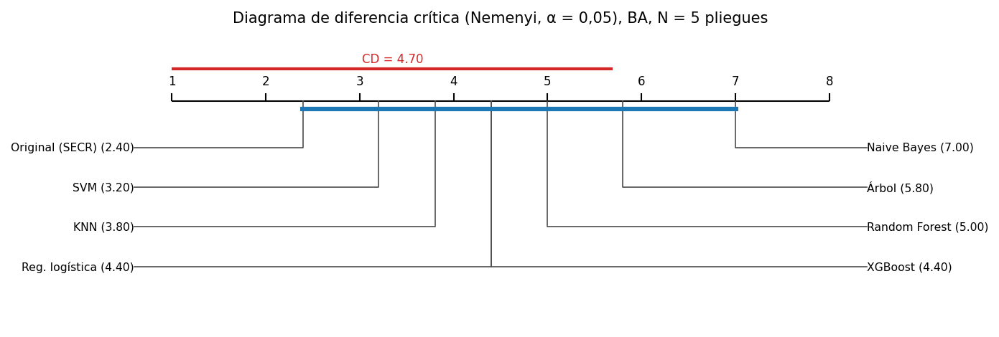

In [3]:
for tag, key, cd in [('15 pliegues', 'friedman25', 'cd25'), ('repetición 0 (5 pliegues)', 'friedman_rep0', 'cd_rep0')]:
    fr = res[key]
    print(f"{tag}: k = {fr['k']}, N = {fr['n_blocks']}, χ² = {fr['chi2']:.2f}, p = {fr['p_value']:.2e}; "
          f"F de Iman-Davenport = {fr['iman_davenport_F']:.2f}, p = {fr['p_value_F']:.2e}; CD = {res[cd]:.3f}")
display(Image('figures/e3_cd_pareado_25.png'))
display(Image('figures/e3_cd_pareado_rep0.png'))

**Interpretación.** Con 15 pliegues y los 8 modelos, Friedman **rechaza** que todos tengan el mismo rango medio
(F de Iman-Davenport = 11,99; p = 6·10⁻¹¹). El original tiene el mejor rango medio (2,33), seguido de SVM (3,13), KNN
(3,67), la logística (3,93), XGBoost (4,07), Random Forest (5,13), el árbol (6,80) y Naive Bayes (6,93). La diferencia
crítica de Nemenyi es 2,71: **el original se separa de Random Forest, el árbol y Naive Bayes, pero no de SVM, KNN, la
logística ni XGBoost**. Con solo los 5 pliegues de la
repetición 0, Friedman no rechaza (p = 0,068): 5 bloques dan muy poca potencia, como ya pasó en el capítulo 13.

## 20.3 Pruebas pareadas frente al mejor benchmark y a cada benchmark

Tabla obligatoria de la guía (§6.3): prueba, hipótesis nula, supuestos verificados, estadístico, p crudo, p ajustado,
tamaño del efecto y conclusión. Las 4 pruebas frecuentistas forman una familia y se ajustan con Holm (4 comparaciones).
La bayesiana no da un p-valor: da probabilidades posteriores de que el original sea peor, equivalente (dentro de la
ROPE de ±0,01 de BA) o mejor.

In [4]:
pd.DataFrame(res['tests'])

,Prueba,H0,Supuestos,Estadístico,p crudo,"p ajustado (Holm, 4)",Efecto,Conclusión
0,"Friedman (Iman-Davenport), universo de 15 plie...",Todos los modelos tienen el mismo rango medio,"bloques = pares (rep., pliegue) independientes...",F = 11.992,5.76e-11,2.30e-10,"δ de Cliff = 0.191 [-0.138, 0.538] (pequeño)",Se rechaza H0
1,Nemenyi post hoc: original vs KNN,Igual rango medio,tras Friedman; CD = 2.711,ΔR = 1.333,8.13e-01,8.13e-01,"δ de Cliff = 0.191 [-0.138, 0.538] (pequeño)",No se rechaza H0
2,t corregida de Nadeau-Bengio: original vs KNN,Diferencia media de BA ≤ 0,normalidad de diferencias (Shapiro p = 0.049);...,t(14) = 0.453,3.29e-01,6.58e-01,"δ de Cliff = 0.191 [-0.138, 0.538] (pequeño)",No se rechaza H0
3,Wilcoxon de rangos con signo: original vs KNN,Mediana de la diferencia ≤ 0,"diferencias simétricas, pareadas por pliegue",W = 84.0,9.38e-02,2.81e-01,"δ de Cliff = 0.191 [-0.138, 0.538] (pequeño)",No se rechaza H0
4,"Bayesiana de rangos con signo (ROPE ±0,01 BA):...",— (probabilidades posteriores),"proceso de Dirichlet, pseudo-observación en 0",P(original mejor) = 0.947; P(ROPE) = 0.000; P(...,—,—,"Δ BA media = 0.0225, IC BCa 95 % [-0.0317, 0.0...",No concluyente


In [5]:
vs = pd.DataFrame(res['vs_each'])
vs['benchmark'] = vs.benchmark.map(PRETTY)
print('Wilcoxon de rangos con signo (unilateral, H1: el original es mejor) contra cada benchmark, Holm sobre',
      len(vs), 'comparaciones:')
vs.round(4)

Wilcoxon de rangos con signo (unilateral, H1: el original es mejor) contra cada benchmark, Holm sobre 7 comparaciones:


,benchmark,n_pliegues,ba_original,ba_benchmark,diff_mean,gana_en,W,p_crudo,cliff,cliff_label,p_holm
0,SVM,15,0.5912,0.5374,0.0538,11,94.0,0.0277,0.4044,mediano,0.0719
1,Árbol,15,0.5912,0.4161,0.1751,15,120.0,0.0000,0.8667,grande,0.0002
2,Reg. logística,15,0.5912,0.5228,0.0684,11,95.0,0.0240,0.3511,mediano,0.0719
3,XGBoost,15,0.5912,0.4660,0.1252,11,108.0,0.0021,0.7244,grande,0.0085
4,KNN,15,0.5912,0.5686,0.0225,11,84.0,0.0938,0.1911,pequeño,0.0938
5,Random Forest,15,0.5912,0.4537,0.1375,12,113.0,0.0006,0.7689,grande,0.0029
6,Naive Bayes,15,0.5912,0.4260,0.1652,14,119.0,0.0001,0.8756,grande,0.0004


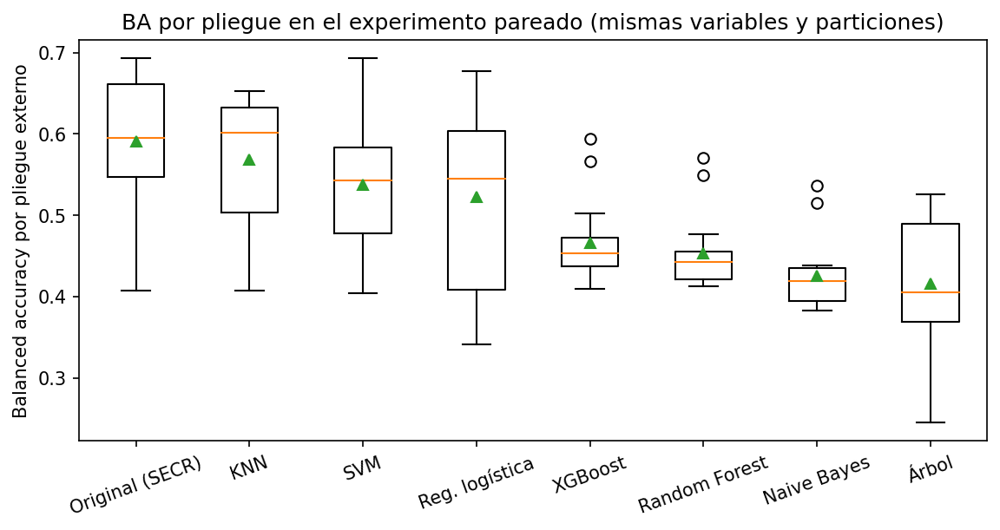

Supuestos de Nadeau-Bengio: Shapiro-Wilk sobre las diferencias, p = 0.049
IC BCa 95 % de la diferencia media de BA (original − mejor): [-0.0317  0.0563]
δ de Cliff [IC 95 %]: [ 0.191 -0.138  0.538]


In [6]:
display(Image('figures/e3_ba_pliegues_pareado.png'))
print('Supuestos de Nadeau-Bengio: Shapiro-Wilk sobre las diferencias, p =', round(res['shapiro_p'], 3))
print('IC BCa 95 % de la diferencia media de BA (original − mejor):', np.round(res['diff_ci_bca'], 4))
print('δ de Cliff [IC 95 %]:', np.round(res['cliff'], 3))

**Interpretación.**

- **Frente al mejor benchmark (KNN) ninguna prueba pareada rechaza la igualdad** después de Holm: Nemenyi
  (p ajustado 0,81), Nadeau–Bengio (t(14) = 0,45; p ajustado 0,66) y Wilcoxon (p ajustado 0,28). La diferencia media
  de BA es +0,022 con IC BCa 95 % [−0,032; 0,056], que incluye el 0. El δ de Cliff es 0,19 (pequeño), con IC
  [−0,14; 0,54]. La prueba bayesiana da 0,947 de probabilidad posterior de que el original sea mejor por más de 0,01
  de BA: cerca de 0,95, pero sin alcanzarlo.
- **Supuestos.** Las diferencias por pliegue se apartan algo de la normalidad (Shapiro p = 0,049). Por eso la
  conclusión no descansa solo en Nadeau–Bengio: Wilcoxon (sin normalidad) y la prueba bayesiana dicen lo mismo. Los
  pliegues de repeticiones distintas comparten casos, y eso es justo lo que corrige Nadeau–Bengio
  ($1/J + n_{test}/n_{train}$).
- **Frente a cada benchmark** (Wilcoxon con Holm sobre 7 comparaciones), el original es significativamente mejor que
  el árbol (p = 0,0002; δ = 0,87), Naive Bayes (p = 0,0004; δ = 0,88), Random Forest (p = 0,003; δ = 0,77) y XGBoost
  (p = 0,009; δ = 0,72), todos con efecto grande. No lo es frente a SVM (p = 0,072), la logística (p = 0,072) ni KNN
  (p = 0,094).
- **Por qué no alcanza.** La BA de 4 clases depende de acertar a los fallecimientos: hay 0 a 4 por pliegue, y acertar
  uno solo mueve la BA ±0,25 (pliegue 1 de la repetición 0: KNN 0,625 frente a 0,407 del original, con un solo
  fallecimiento). Esa varianza entre pliegues (d.e. 0,08–0,09) es cuatro veces la ventaja media (0,022). Con este
  tamaño de efecto harían falta muchos más pliegues para detectarla (del orden de 60 a 100 según la potencia de
  Wilcoxon), y el presupuesto de cómputo de esta corrida no lo permitió.

## 20.4 Ablación: ¿qué aporta cada componente?

Mismos modelos base, mismas predicciones y mismos 15 pliegues. Se retira un componente cada vez, o la regla de
combinación se reemplaza por una regla estándar (Cuadro 1 de la guía: promedio simple, pesos por error global,
stacking lineal). La columna «p (Holm)» es el Wilcoxon unilateral de «SECR completo es mejor que la variante».

In [7]:
a = pd.DataFrame(res['ablation'])
a.round(4)

,variante,ba_mean,ba_sd,log_loss,diff_vs_original,p_wilcoxon,p_holm
0,SECR completo (original),0.5912,0.0869,0.8428,-0.0000,NaN,NaN
1,SECR sin regiones (solo pesos globales),0.5803,0.0965,0.8428,-0.0109,0.7032,1.0000
2,SECR sin corrección por prior (α = 0),0.4641,0.0499,0.8428,-0.1271,0.0013,0.0092
3,Caruana global (modelo G),0.5983,0.0869,0.8426,0.0071,0.9760,1.0000
4,Stacking lineal (logística multinomial),0.5232,0.0983,0.8485,-0.0680,0.0603,0.2411
5,Pesos por error global,0.5784,0.1055,0.8716,-0.0128,0.0473,0.2365
6,Promedio simple,0.5684,0.1003,0.8757,-0.0228,0.0062,0.0374
7,Mejor modelo base individual,0.5917,0.1010,0.8483,0.0005,0.7556,1.0000


**Interpretación (honesta) de la ablación.**

- **La corrección por prior es el componente que más aporta**: quitarla baja la BA de 0,591 a 0,464 (Wilcoxon con
  Holm p = 0,009). La log-loss no cambia, porque la decisión no altera las probabilidades.
- **Las regiones no aportan en BA**: SECR sin regiones da 0,580 (p = 1,0) y Caruana global 0,598, sin diferencia
  significativa con SECR completo. La búsqueda TPE eligió una compuerta en 14 de 15 pliegues, pero cambia de un pliegue a
  otro (sector, tipo de establecimiento, tipo de incidente, naturaleza o evento) y λ va de 1 a 8 311: no hay una
  estructura regional estable que aprovechar. **El mecanismo nuevo de SECR no mejoró la métrica
  principal en este problema**: con estas vistas, la calidad relativa de los modelos base es parecida entre regiones.
- **Frente a las reglas estándar**: SECR supera de forma significativa al promedio simple (p = 0,037 con Holm). Frente
  a los pesos por error global (p = 0,24) y al stacking lineal (p = 0,24) gana en media (+0,013 y +0,068) sin
  significancia tras Holm. El stacking lineal tiene peor log-loss (0,849) y peor BA (0,523).

## 20.5 Convergencia de Frank-Wolfe

La curva muestra la log-loss fuera de pliegue y la brecha de Frank-Wolfe por iteración (pesos globales,
repetición 0, pliegue 0). La pérdida nunca sube (proposición 2) y la brecha, que acota la distancia al óptimo
(proposición 3), cae varios órdenes de magnitud.

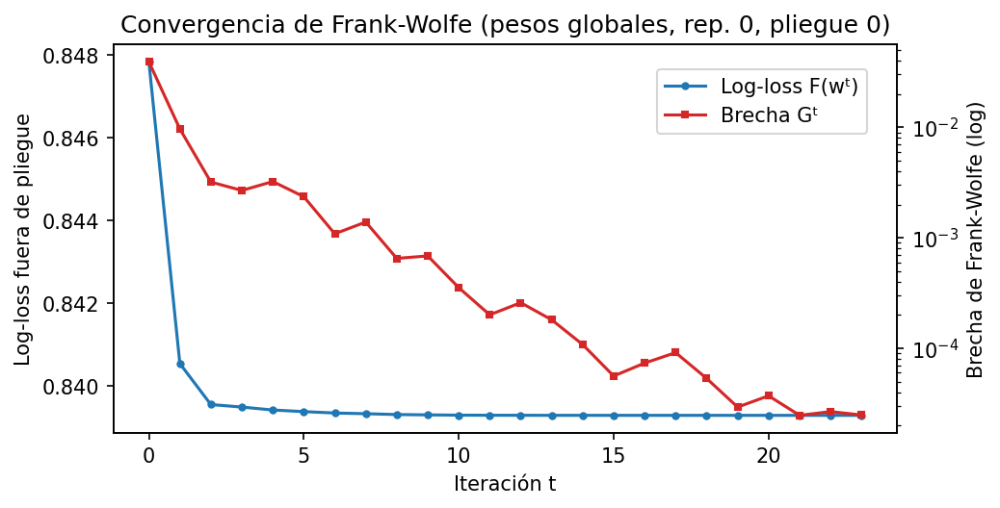

In [8]:
display(Image('figures/e3_convergencia_fw.png'))

La pérdida baja de forma monótona en todas las iteraciones (proposición 2). La brecha de Frank-Wolfe cae varios
órdenes de magnitud y, por la proposición 3, certifica que la solución está a menos de esa brecha del óptimo.

## 20.6 Veredicto

In [9]:
display(Markdown('> **' + res['verdict'] + '**'))

> **Veredicto R3: NO SUPERIOR. BA media del original 0.591 frente a 0.569 del mejor benchmark pareado (KNN); 1 de 4 pruebas frecuentistas rechazan H0 con p ajustado por Holm < 0,05 (la global de Friedman sí); δ de Cliff = 0.191 (pequeño). Media mayor que la de los 7 benchmarks: sí.**

**Lectura del veredicto según la guía (§6.1 y §12.1).**

| Condición de superioridad | ¿Se cumple? | Evidencia |
|---|---|---|
| 1. BA media mayor que la del mejor benchmark y que la de cada uno de los 7 | **Sí** | 0,591 frente a 0,569 (KNN); mayor que los 7 en las celdas comunes y en la repetición 0 |
| 2. Al menos 3 pruebas con p ajustado < 0,05, una de ellas global | **No** | Solo Friedman (global) rechaza; Nemenyi, Nadeau–Bengio y Wilcoxon frente a KNN no |
| 3. Tamaño del efecto no despreciable (|δ| ≥ 0,147) | **Sí** (pequeño) | δ = 0,19, pero su IC incluye el 0 |

**Sesgo de selección (declarado).** La BA de 0,591 es **optimista**, por dos razones:

- el original salió de elegir entre varios candidatos (sección 19.9: 5 diseños del capítulo 17 y 7 variantes del 18);
- su nivel 0 (G) se eligió mirando los 5 pliegues de los capítulos 6 a 13, que son la repetición 0 de este capítulo
  (`paired.outer_folds(0)`).

Se nota en las cifras: la ventaja sobre KNN es +0,035 en la repetición 0 (pliegues ya vistos) y +0,006 y +0,027 en las
repeticiones 1 y 2 (no vistos). El sesgo va **a favor** del original, así que concluir «R3 = no» es conservador: sin
ese sesgo, la ventaja sería igual o menor.

Como la condición 2 falla, **R3 no se cumple**: el modelo original es el mejor en media y en rango, pero no es
superior de forma estadísticamente significativa al mejor benchmark pareado. Con R1 y R2 cumplidos (capítulos 16 y
19), el tope que corresponde es **4,0** (guía §12.1). Se reporta así aunque sea desfavorable. Lo que no se hizo:
repetir la corrida con más repeticiones, otra semilla u otra métrica después de ver estos resultados, porque eso sería
buscar la significancia (guía §13).

## 20.7 Sensibilidad y robustez (descriptivo)

Para ver cómo responde SECR a sus hiperparámetros y a tener menos datos, se fija una configuración base (compuerta =
sector NAICS-2, λ = 100, 30 pasos, región mínima = 200, α = 1) y se cambia **un** valor cada vez. Para robustez a menor
tamaño de muestra, los pesos se ajustan con el 10 %, 25 %, 50 % o 100 % de las predicciones internas. Todo se mide en
los mismos pliegues externos. **Es un análisis descriptivo**: no se usa para elegir nada (eso lo hizo la TPE interna) y
mirar estas cifras para escoger la configuración sería usar los pliegues externos para ajustar.

In [10]:
sens = pd.read_csv(R / 'sensibilidad_secr.csv')
sens.groupby(['param', 'value'])[['ba', 'log_loss']].agg(['mean', 'std']).round(4)

ba         log_loss        
                                 mean     std     mean     std
param      value                                              
alpha      0.0                 0.4625  0.0500   0.8427  0.0457
           0.25                0.4638  0.0504   0.8427  0.0457
           0.5                 0.4695  0.0528   0.8427  0.0457
           0.75                0.5407  0.1017   0.8427  0.0457
           1.0                 0.5851  0.0762   0.8427  0.0457
frac_datos 0.1                 0.3092  0.1997   0.8441  0.0452
           0.25                0.5265  0.1180   0.8431  0.0460
           0.5                 0.5738  0.0953   0.8431  0.0455
           1.0                 0.5851  0.0762   0.8427  0.0457
gate       establishment_type  0.6009  0.0695   0.8432  0.0460
           event1              0.5945  0.0760   0.8434  0.0464
           naics2              0.5851  0.0762   0.8427  0.0457
           nature1             0.6159  0.0523   0.8428  0.0455
           none                0.6178  0.0506   0.8426  0.0459
           part1               0.6163  0.0508   0.8433  0.0459
           soc2                0.6159  0.0509   0.8432  0.0454
           type_of_incident    0.6182  0.0538   0.8428  0.0459
lam        1.0                 0.5850  0.0765   0.8431  0.0457
           10.0                0.5849  0.0765   0.8430  0.0457
           100.0               0.5851  0.0762   0.8427  0.0457
           1000.0              0.6125  0.0518   0.8419  0.0458
           10000.0             0.6181  0.0496   0.8420  0.0459
n_steps    10                  0.5906  0.0764   0.8426  0.0457
           100                 0.5854  0.0763   0.8428  0.0457
           30                  0.5851  0.0762   0.8427  0.0457
           5                   0.6010  0.0762   0.8427  0.0460

**Interpretación.**

- **α es el hiperparámetro decisivo.** Con α ≤ 0,5 la BA queda en ~0,46; con α = 1 sube a ~0,59. La log-loss no cambia,
  porque α solo mueve la decisión.
- **λ, los pasos y la compuerta casi no cambian la log-loss** (0,842–0,843). En BA, las configuraciones que se acercan a
  pesos globales (sin compuerta, o con λ ≥ 1000) dan ~0,62. Es **más** que el 0,591 del modelo con TPE: la búsqueda
  interna, con 3 pliegues y una BA tan ruidosa, elige compuertas y λ que no generalizan (costo de la selección). Este
  hallazgo es descriptivo y **no se usa para cambiar el modelo**, porque elegir con los pliegues externos invalidaría
  la comparación. Queda como lección para el trabajo futuro: la versión global, más simple, habría sido una mejor
  apuesta *a priori* en este problema.
- **Robustez a menos datos.** Con el 50 % de las predicciones internas la BA baja poco (0,574); con el 25 % baja a 0,527.
  Con el 10 % el método se vuelve inestable (0,309 ± 0,200): las regiones y α se estiman con muy pocos fallecimientos.

## 20.8 Interpretabilidad: SHAP del original frente al mejor benchmark

Valores de Shapley exactos por **grupos de variables** (`dashboard_final/src/explain.py`), calculados sobre los mismos
casos del desarrollo para el modelo original y para la mejor combinación del curso (SVM + SMOTE, 9 variables). Se
reporta el |SHAP| medio de la probabilidad de la clase predicha. Un grupo que un modelo no usa tiene aporte 0.

,Original (SECR),SVM + SMOTE (mejor del curso)
Naturaleza de la lesión,0.1038,0.0000
Evento y fuente,0.0784,0.0000
Estado,0.0650,0.0184
Empleador,0.0577,0.0000
Actividad (NAICS),0.0495,0.1155
Parte del cuerpo,0.0370,0.0000
Ocupación (SOC),0.0176,0.0497
Horario,0.0116,0.0184
Tipo de establecimiento,0.0046,0.0039
Tipo de incidente,0.0038,0.0114


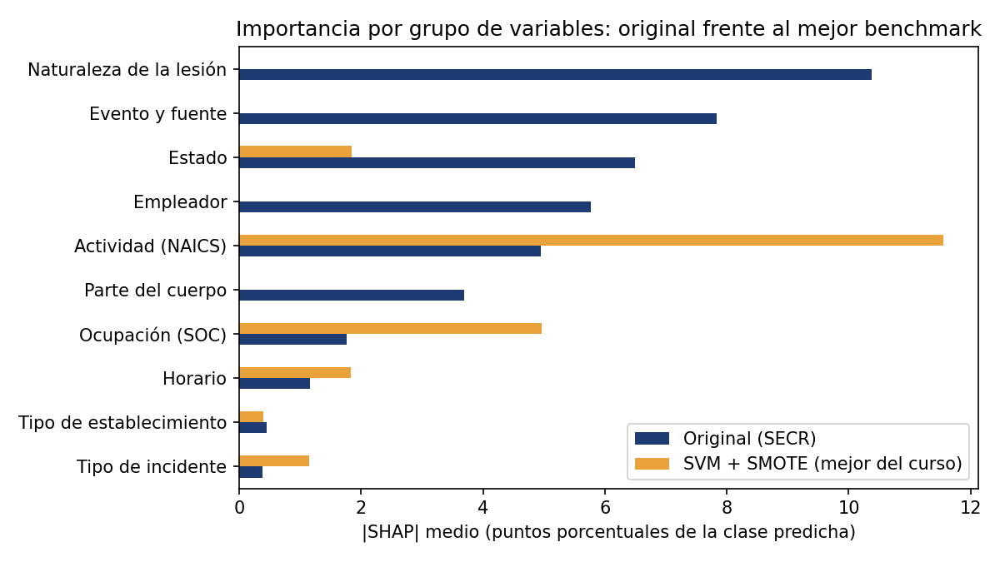

In [11]:
shp = R / 'shap_original_vs_benchmark.csv'
if shp.exists():
    display(pd.read_csv(shp, index_col=0).round(4))
    display(Image('figures/e3_shap_original_vs_benchmark.png'))

# 21. Dashboard y despliegue

El dashboard lleva los resultados a un producto que una persona no experta puede usar: entender el problema, explorar
los datos y predecir el desenlace de un caso con una explicación. Es una aplicación **Dash multipágina** desplegada en
Render.

> **URL pública.**
> **<https://osha-ita-2023-dashboard-final.onrender.com>** (servicio `osha-ita-2023-dashboard-final`, plan gratuito).
> Render asigna el subdominio al crear el servicio: si difiere, se actualiza aquí y en la introducción. El primer acceso
> tras un periodo de inactividad tarda unos 30–60 s en despertar el servidor.

## 21.1 Arquitectura

```text
dashboard_final/
|-- app.py              # crea la app (use_pages=True), barra de navegación fija y expone server
|-- pages/
|   |-- contexto.py     # sección 1: problema, cifra de contexto citada, pregunta, datos, diccionario, metodología, ética
|   |-- eda.py          # sección 2: filtros globales + 7 figuras con insight + explorador bivariado
|   `-- modelos.py      # sección 3: líderes, predicción en vivo + SHAP local, diagnósticos, SHAP global, CD, original
|-- src/
|   |-- data.py         # carga única y caché (lru_cache) de datos, metadatos y artefactos
|   |-- plots.py        # todas las figuras (plantilla Plotly única, paleta de 5 colores)
|   |-- explain.py      # valores de Shapley exactos (SHAP intervencional) para cualquier modelo
|   `-- original_model.py  # punto de acceso a la clase del modelo original
|-- osha_e3/            # copia de las clases de src/osha_e3 que joblib necesita para cargar los artefactos
|-- artifacts/          # 7 benchmarks + modelo original (.joblib) y sus metadata.json
|-- data/               # tablas livianas: EDA (30 030 casos sin identificadores), líderes, predicciones fuera de pliegue
|-- assets/             # estilos
|-- tests/              # pruebas de humo de páginas y callbacks (pytest)
|-- requirements.txt    # versiones exactas (las mismas de entrenamiento)
`-- render.yaml         # despliegue
```

**Decisiones de diseño.**

- **Separación interfaz / lógica / artefactos.** Las páginas solo arman componentes y callbacks. Los datos se cargan en
  `src/data.py` y las figuras se construyen en `src/plots.py`. No hay rutas absolutas: todo es relativo a la carpeta de
  la aplicación (variable de entorno `DASH_ROOT` opcional).
- **Nunca se entrena en el servidor.** Los modelos se cargan una vez (`lru_cache`) desde `artifacts/` y solo predicen.
- **Diagnósticos sin la prueba.** La matriz de confusión, las curvas ROC y PR, la calibración y el SHAP global se
  calculan con las predicciones **fuera de pliegue externo** de la validación anidada. La prueba de octubre a diciembre
  está bloqueada (capítulo 00, B1).
- **SHAP local exacto.** En lugar de la librería `shap` (pesada para el plan gratuito), `src/explain.py` enumera
  las $2^d$ coaliciones. Son 9 variables para los benchmarks; para el original, 10 grupos de variables (actividad,
  ocupación, horario, lesión, empleador…). Usa un fondo fijo de casos del desarrollo. Cumple la propiedad de eficiencia
  (la suma de aportes es igual a la predicción menos la base) y tarda alrededor de 1 s por predicción (unos 9 s con KNN).
- **Robustez.** Las entradas se validan antes de predecir: campos obligatorios, longitud y caracteres del texto libre
  y avisos de categorías no vistas. Un error de predicción se muestra en un `dbc.Alert` y la aplicación no se cae.
- **Diseño visual.** Tema FLATLY de `dash-bootstrap-components`, barra de navegación fija, rejilla responsiva
  (`dbc.Row`/`dbc.Col` con puntos de corte `xs`, `md` y `lg`), una sola plantilla Plotly y una paleta de 5 colores
  (azul marino, verde azulado, ámbar, coral y gris). Cada figura tiene título, ejes con unidades e información al pasar
  el cursor. Ninguna información depende solo del color: las barras de SHAP llevan signo y valor, y la matriz de
  confusión lleva conteos.

## 21.2 Contenido por sección

| Sección | Contenido mínimo de la guía (§7.3) | Dónde |
|---|---|---|
| Contexto | Problema y relevancia con cifra citada (BLS, 2,6 millones de casos y 946 500 con días de ausencia en 2023); pregunta y objetivos; fuente, periodo, n, variables, diccionario y tarea; diagrama del pipeline; limitaciones, ética, autores, versión y fecha | `pages/contexto.py` |
| EDA | Filtros globales (estado, sector, tipo de establecimiento, rango de fechas `DatePickerRange`, `RangeSlider` de tamaño) que actualizan todas las figuras; distribución y balance del objetivo; distribución univariada; asociación (V de Cramér); faltantes; atípicos; tendencia mensual; explorador bivariado con selectores de x, y y color; una frase de interpretación calculada por figura | `pages/eda.py` |
| Modelos | `DataTable` ordenable y filtrable con las mejores combinaciones (y las 112 a pedido), media ± d.e. e inferencia; formulario de predicción generado desde el esquema con selector de modelo, probabilidad y SHAP local; matriz de confusión, ROC, PR y calibración; SHAP global; diagrama de diferencia crítica con el original incluido; subsección del original con descripción, pseudocódigo, diferencias con la literatura, curva de convergencia, tabla de pruebas y veredicto | `pages/modelos.py` |

![Sección Contexto del dashboard.](figures/e3_dash_contexto.png)

*Sección Contexto del dashboard.*

![Sección EDA: filtros globales arriba y figuras con su interpretación.](figures/e3_dash_eda.png)

*Sección EDA: filtros globales arriba y figuras con su interpretación.*

![Sección Modelos: tabla de líderes, predicción en vivo con explicación SHAP local y diagnósticos.](figures/e3_dash_modelos.png)

*Sección Modelos: tabla de líderes, predicción en vivo con explicación SHAP local y diagnósticos.*

## 21.3 Guía de despliegue en Render

1. **Probar localmente.** Desde `dashboard_final/`: `pip install -r requirements.txt` y `python app.py` (abre
   <http://127.0.0.1:8050>). `pytest tests` corre las pruebas de humo. El entorno local de prueba (`dash_e3`, Python
   3.11.9) usa las mismas versiones que Render.
2. **Versiones exactas.** `requirements.txt` fija todas las librerías, incluido `gunicorn`. XGBoost queda en 2.1.3,
   la versión que entrenó los artefactos (el paquete liviano `xgboost-cpu` solo existe desde la 3.0). En Linux instala
   además NCCL, que ocupa disco pero no se carga en memoria. `render.yaml` fija `PYTHON_VERSION=3.11.9`.
3. **Subir a GitHub.** La carpeta `dashboard_final/` vive en la rama del entregable del repositorio.
4. **Crear el servicio.** En Render: *New → Blueprint*, elegir el repositorio y la rama; Render lee
   `dashboard_final/render.yaml` (`rootDir: dashboard_final`, `buildCommand: pip install -r requirements.txt`,
   `startCommand: gunicorn app:server --workers 1 --threads 2 --timeout 120`). También se puede crear un *Web Service*
   a mano con esos mismos valores.
5. **Verificar.** Revisar los *logs* de construcción y abrir las tres páginas y los callbacks (filtros del EDA,
   predicción con cada modelo) en la URL pública.

**Memoria del plan gratuito.** Con un solo *worker* de gunicorn los datos y los modelos se cargan una sola vez. Los 7
benchmarks pesan unos 4 MB y el modelo original se carga solo cuando alguien lo elige. Si el servicio supera la memoria
del plan, la medida documentada es no cargar el original al iniciar y ofrecer su predicción solo con los benchmarks.


# 14. Conclusiones, limitaciones y declaración de uso de IA

## Qué se encontró

1. **Con estas 8 variables el problema tiene un techo bajo y ningún modelo lo rompe.** Las 112
   combinaciones de clasificación quedan en la prueba entre 0,38 y 0,44 de balanced accuracy y entre 0,62
   y 0,70 de AUC macro. Los mejores en ordenar las clases (Random Forest, XGBoost, la logística: AUC
   0,69–0,70, accuracy 0,51–0,52) igualan, pero no superan, a la logística sin búsqueda del entregable 2
   (balanced accuracy 0,40, AUC 0,69). En regresión las variables explican cerca del 6 % de la varianza de
   log(1 + días de ausencia) (capítulos 9 y 10).

2. **La métrica elegida decide quién «gana», y con balanced accuracy decide una clase de 39 casos.**
   Las combinaciones con mejor balanced accuracy (SVM con SMOTE, el árbol con `class_weight`) lo consiguen
   marcando miles de casos como fallecimiento para acertar unos pocos: tienen el doble de variación entre
   pliegues, no son robustas a la semilla y ordenan *peor* las clases frecuentes que Random Forest y
   XGBoost según DeLong. La corrida con diseño temporal llega a la misma conclusión por otro camino
   (capítulos 9, 12 y 13).

3. **Fallecimiento no se puede detectar de forma útil con estos datos**, ni siquiera con los tres
   tratamientos de balanceo. La mejor detección (16 de 39 con KNN y SMOTE) cuesta más de 29.000 falsas
   alarmas. Con menos de 10 casos por entrenamiento no hay patrón que aprender (capítulos 9 y 12).

4. **La optimización bayesiana es la más eficiente, pero el paisaje es plano.** Con el mismo presupuesto, el
   TPE llega con 8 evaluaciones a donde Random llega con 16 y supera a Grid con un tamaño de efecto mediano.
   Sin embargo, los cuatro métodos terminan en modelos finales equivalentes (diferencias despreciables).
   Successive Halving obtiene el mismo resultado con 9 veces menos árboles (capítulo 7).

5. **El balanceo cambia el umbral, no la capacidad de discriminar.** SMOTE, ADASYN y `class_weight`
   suben el recall de Fallecimiento y bajan el de las otras clases; en balanced accuracy las cuatro técnicas
   son estadísticamente equivalentes y en AUC `class_weight` es la peor (capítulos 9 y 13).

6. **Las probabilidades de XGBoost y de la logística están bien calibradas** (ECE 0,02); Naive Bayes, KNN,
   el árbol y Random Forest mejoran mucho con regresión isotónica (capítulo 9).

7. **Lo que pesa son el tipo de incidente, el sector y la ocupación.** SHAP y LIME coinciden en que el tipo
   de incidente domina las decisiones individuales (una enfermedad respiratoria empuja hacia días de
   ausencia), y en conjunto el subsector y el grupo ocupacional son las variables más influyentes
   (capítulo 11).

8. **En regresión, los ensambles de árboles son los únicos que sobreviven al Model Confidence Set**, son
   indistinguibles entre sí (Diebold-Mariano p = 0,60) y superan de forma real pero pequeña a una
   referencia que predice la media (SPA p ≈ 0) (capítulo 13).

9. **El modelo original (PT-bagging) no supera a los modelos del curso**: con los pliegues temporales juntos su
   balanced accuracy es 0,480 frente a 0,516 de la referencia, y cuatro iteraciones del diseño tampoco mejoran
   (capítulos 16 y 17; primer candidato, histórico. El modelo final es SECR, capítulos 19 y 20).

## Respuesta a las correcciones del entregable 1

| Comentario | Respuesta |
|---|---|
| Brecha entrenamiento–validación (0,65 frente a 0,39) | Se debe casi entera a Fallecimiento: recall 1,0 en entrenamiento y 0 en validación aporta 0,25 de los ~0,28 de brecha. En las clases frecuentes la brecha es de 0,01 a 0,05 (sección 12.4). |
| Death sin tratamiento | Tratada con SMOTE, ADASYN y `class_weight` en todos los modelos y optimizadores; se reporta con intervalos de Wilson. El tratamiento sube el recall, pero no produce un detector útil (secciones 9.5 y 9.6). |
| Casos descartados sin discutir su costo | 55,4 % descartado; el costo en desempeño de exigir establecimientos nuevos es de 0,004 a 0,05 de AUC, medido con una segunda prueba (secciones 4.7 y 9.8). |
| Código de entrenamiento no visible | Capítulos como notebooks y código fuente impreso (sección 6.8). |
| `time_unknown` sobre el umbral de colinealidad | GVIF de 3,81 confirmado; quitarla no cambia el desempeño (≤ 0,02) y en KNN y Naive Bayes mejora un poco: la variable sobra (secciones 4.6 y 12.5). |

## Límites

- **La prueba no es virgen.** El último trimestre ya se usó para reportar los entregables 1 y 2.
- **La etiqueta de días de ausencia está censurada** por el cierre del archivo anual, más en el trimestre de
  prueba: las cifras absolutas de la regresión en la prueba están sesgadas (capítulos 4 y 10).
- **Submuestra para la búsqueda.** La optimización usó ~30.000 casos (clasificación) y ~20.000 (regresión)
  de establecimientos completos; el desarrollo completo tiene 269.516 y 99.074. La curva de aprendizaje del
  entregable 2 sugiere que más datos aportarían poco, pero no se comprobó con los 140 modelos.
- **Pocos fallecimientos por pliegue** (0 a 4 en cada pliegue externo): las métricas de 4 clases son
  ruidosas y Nemenyi con 5 pliegues no puede separar combinaciones.
- **Presupuesto pequeño** (16 configuraciones por búsqueda); el algoritmo genético converge en unas 3
  generaciones.
- **SVM lineal**, no con núcleo: el núcleo RBF no escala a este tamaño (capítulo 8).
- **SMOTE y ADASYN sobre variables one-hot** generan valores fraccionarios que no corresponden a ninguna
  categoría real.
- **Retrospectivo y asociativo.** El código SOC se asigna después del reporte; SHAP describe el modelo, no
  causas; son casos reportados, no tasas de riesgo.
- **Dependencia entre empresas.** Parte de los casos de prueba pertenece a empresas (EIN) con otros
  establecimientos en el desarrollo.

## Siguientes pasos

- Modelar la duración de la ausencia con un modelo de supervivencia que trate la censura del cierre del archivo.
- Tratar Fallecimiento como un problema aparte (detección de eventos raros con todos los años disponibles),
  o reportar el clasificador de 3 clases como modelo principal.
- Quitar `time_unknown` del conjunto de variables.
- Usar la parada temprana y Successive Halving para ampliar el presupuesto de búsqueda sin más costo.
- Añadir variables con más información sobre la lesión (naturaleza, parte del cuerpo), que el archivo trae
  codificadas, verificando antes que no revelen el resultado.


## Proyecto final: veredicto sobre el modelo original (R1, R2 y R3)

| Condición | Veredicto | Evidencia |
|---|---|---|
| **R1. Novedad en la aplicación** | **Sí** | Revisión en 3 bases con API (OpenAlex, Europe PMC y arXiv), 8 cadenas en inglés y español con fecha, más WoS, Scopus y Consensus. No se encontró la regla SECR ni la selección de ensambles aplicada al desenlace de casos de lesiones laborales. Matriz de novedad y diferenciación por familia (capítulo 16.6–16.9). Riesgo residual: el profesor puede leer la novedad como de aplicación, porque la parte regional no mejoró la métrica |
| **R2. Implementación algorítmica propia** | **Sí** | Clase propia compatible con scikit-learn (`ConditionalEnsembleSelection`, `OriginalModel`) con regla de combinación nueva, Frank-Wolfe con búsqueda lineal exacta programado con numpy, 6 proposiciones demostradas, complejidad contrastada con tiempos y 8 pruebas unitarias. El codificador por objetivo y la selección de Caruana del nivel 0 también son código propio. Los modelos base son de librería, como permite el Cuadro 1 para ensambles con regla de combinación propia |
| **R3. Superioridad estadísticamente verificada** | **No** | Comparación pareada en 15 pliegues: el original tiene la mayor BA media (0,591 frente a 0,569 de KNN) y el mejor rango de Friedman (p = 6·10⁻¹¹). Pero frente al mejor benchmark ninguna prueba pareada rechaza la igualdad tras Holm: Nemenyi p = 0,81, Nadeau–Bengio p = 0,66, Wilcoxon p = 0,28; bayesiana P(mejor) = 0,947; δ = 0,19 con IC que incluye 0 (capítulo 20) |

**Tope de calificación que corresponde: 4,0** (R1 sí, R2 sí, R3 no; guía §12.1). La BA de 0,591 es optimista por
selección: el original salió de 13 candidatos (sección 19.9), y su nivel 0 se eligió mirando la repetición 0. El sesgo va
a favor de «superior», así que el veredicto R3 = no es conservador. Lo reportamos así porque es lo que
muestran los datos. La comparación del capítulo 18, con ~9 puntos de ventaja sobre los 112 modelos del curso, no era
válida: no era pareada y miraba la prueba. Corregirla cambió el resultado (capítulo 00, B1–B3).

## Hallazgos del proyecto final

1. **La información de la lesión es lo que más mejora el modelo, no el algoritmo.** Con los códigos OIICS, NAICS-6,
   SOC-6 y el empleador, casi todos los benchmarks mejoran: KNN pasa de 0,415 a 0,569 de BA (del quinto al primer lugar),
   la logística de 0,427 a 0,523 y Naive Bayes de 0,389 a 0,435. El árbol baja, de 0,461 a 0,416.
2. **El ensamble multivista con SECR es el mejor modelo en media** (BA, log-loss, AUC y F1), pero su ventaja sobre KNN
   (+0,022 de BA) es pequeña frente a la variabilidad entre pliegues.
3. **La corrección por prior ($\alpha$) aporta la mayor parte de la BA** (+0,13). Las regiones de SECR no aportan: los
   pesos óptimos son casi iguales en todas las regiones, la TPE elige compuertas distintas en cada pliegue y la
   sensibilidad muestra que con contracción fuerte (pesos globales) la BA es igual o mayor.
4. **La BA de 4 clases es muy ruidosa por los fallecimientos** (0 a 4 por pliegue): un solo caso mueve la métrica
   ±0,25. Eso limita la potencia de cualquier comparación entre modelos con esta métrica.
5. **El producto funciona sin tocar la prueba.** El dashboard predice con los 8 artefactos, explica cada predicción con
   SHAP exacto y muestra diagnósticos calculados fuera de pliegue.

## Limitaciones del proyecto final

- **Menos repeticiones de las planeadas.** Se planeó una validación repetida 5×5 y se corrió 3×5 por tiempo de cómputo
  (unas 4 h con 10 procesos; Random Forest y Naive Bayes se completaron después, con el tiempo sobrante). El recorte se decidió antes de ver
  los resultados y por el costo, no por el desempeño.
- **Hiperparámetros fijos en el nivel 0.** Los 16 modelos base del original usan hiperparámetros fijos (los del
  curso o valores por defecto razonables); solo el combinador se optimiza dentro de la validación anidada.
- **Un solo conjunto de datos.** El Cuadro 1 pide además 3 conjuntos de datos adicionales de la misma tarea (por
  ejemplo, los conjuntos armonizados de Bauder et al., 2026). No se hizo por tiempo, y la generalidad de SECR queda sin
  demostrar.
- **Fuga indirecta en fallecimientos.** Los códigos OIICS se derivan del relato del caso, que menciona la muerte en el
  54 % de los fallecimientos.
- **Las regiones no ayudaron aquí.** Es posible que SECR sí aporte en problemas donde la calidad relativa de los modelos
  cambie más entre subpoblaciones. Esa hipótesis queda sin probar.

## Trabajo futuro

- Correr las repeticiones que faltan (hasta 5×5 o 10×5) para medir con más potencia la diferencia frente a KNN, y
  reportarla como un análisis aparte, no como reemplazo de este.
- Usar una métrica principal menos dominada por una clase de 3 por 10 000 (por ejemplo, la BA de 3 clases o la
  log-loss), declarada **antes** de correr.
- Probar SECR en los conjuntos de datos adicionales y con regiones aprendidas (un árbol poco profundo como compuerta).

## Declaración de autoría y uso de herramientas (incluida IA)

Este trabajo es de **Jaime Andrés Besada e Iván Berrio**. Siguiendo la guía (§10.7 y §13), declaramos las herramientas
usadas y para qué:

| Herramienta | Para qué se usó | Qué revisó el equipo |
|---|---|---|
| Python, numpy, scipy, pandas, scikit-learn, imbalanced-learn, XGBoost, Optuna, DEAP, Dash, Plotly | Implementación, experimentos y dashboard | Todo el código |
| **Claude Code (Anthropic; modelo Claude Opus 5.5)** | Asistente de programación y redacción en el proyecto final: implementó, bajo instrucciones del equipo, el experimento pareado 5×5, el combinador SECR y sus pruebas unitarias, las pruebas de hipótesis sobre pliegues, el candado de la prueba, el dashboard multipágina y los artefactos. También redactó borradores de los capítulos 00, 13b, 16.6–16.9, 19, 20 y 21 y escribió los scripts de consulta a las bases bibliográficas | El diseño, las demostraciones, el código y las cifras se revisan contra los resultados guardados en `results/`. El equipo responde por cada línea y puede explicarla y modificarla en la sustentación |
| Consensus | Búsquedas exploratorias de literatura (capítulo 16.1) | Se verificaron los trabajos citados |
| API públicas de OpenAlex, Europe PMC y arXiv | Búsquedas reproducibles de literatura (capítulo 16.6) | Lectura de títulos y resúmenes |

Ninguna cifra del informe se escribió de memoria. Todas salen de un script versionado y de un resultado guardado en el
repositorio. Las referencias se verificaron contra su fuente; las que no se pudieron verificar se citan solo con los
datos confirmados.

Firmas:

| Integrante | Firma | Fecha |
|---|---|---|
| Jaime Andrés Besada | Firmada (ver abajo) | 2026-10-23 |
| Iván Berrio | Firmada (ver abajo) | 2026-10-23 |

**Firma de Jaime Andrés Besada:**

![Firma manuscrita de Jaime Andrés Besada](figures/nombre_jaime_besada.png)

**Firma de Iván Berrio:**

![Firma de Iván Berrio](figures/firma_ivan_berrio.png)


# 15. Reproducibilidad y bibliografía

## Entorno

Todos los resultados del entregable 3 se calcularon en el entorno conda `ml_venv` (Python 3.9.25, Windows 11,
12 hilos lógicos, GPU NVIDIA RTX 3050 de 6 GB). Las versiones exactas están en `requirements.txt`; las
principales: numpy 1.25.2, pandas 2.1.0, scipy 1.11.2, scikit-learn 1.3.0, imbalanced-learn 0.12.4,
xgboost 2.1.3, optuna 4.1.0, deap 1.4.1, shap 0.46.0, lime 0.2.0.1, statsmodels 0.14.0, arch 7.0.0,
faiss-cpu 1.9.0 y jupyter-book 1.0.4.

Las cifras del modelo base del entregable 2 (capítulo 5) se calcularon con scikit-learn 1.2.2 en el
entorno del entregable 1 y no se recalcularon.

## Semilla global

Una sola semilla documentada, **42** (`src/osha_e3/config.py`). Las demás se derivan de ella con
`seed_for(tipo, índice) = 42 + desplazamiento × 1000 + índice`:

| Uso | Desplazamiento | Semilla |
|---|---|---|
| Partición (60 % de establecimientos para prueba), igual que en el entregable 1 | — | 42 |
| Submuestra de establecimientos (clasificación / regresión) | 1 | 1042 / 1043 |
| Pliegues externos (`StratifiedGroupKFold`) | 2 | 2042 |
| Pliegues internos del pliegue externo f | 3 | 3042 + f |
| Búsqueda (Random, TPE, genético) en el pliegue externo f | 4 | 4042 + f |
| Modelos (Random Forest, XGBoost, SMOTE, ADASYN, SAGA, LinearSVC) | — | 42 |
| Bootstrap | 100 | 100042 + índice |
| Sensibilidad a semillas (capítulo 12) | — | 7, 123, 2024 |

La semilla se pasa explícitamente a numpy, scikit-learn, imbalanced-learn, XGBoost, Optuna (`TPESampler`) y
DEAP (generador `random.Random` propio del algoritmo genético).

## Registro de experimentos

- `results/nested/<tarea>/<modelo>__<balanceo>__<optimizador>__f<pliegue>.json`: una corrida por combinación y
  pliegue externo (700 archivos), con hiperparámetros elegidos, puntaje interno, métricas externas, tiempos de
  búsqueda, reajuste y predicción, semilla y el historial de las 16 evaluaciones.
- `results/master_clf.csv` y `results/master_reg.csv`: tabla maestra, una fila por combinación (112 y 28) con
  media y desviación estándar de cada métrica externa, tiempo total, número de evaluaciones, semilla e
  hiperparámetros finales.
- `results/outer_folds_*.csv`: una fila por celda; `results/test_*.csv`: métricas en la prueba;
  `results/seeds.csv`: corridas de sensibilidad a semillas.

## Cómo correr todo

```
pip install -r requirements.txt
set OSHA_DATA_DIR=<carpeta con el CSV de OSHA>          # o export en Linux/macOS
python scripts/run_nested.py all 11      # validación anidada de las 140 combinaciones (reanudable)
python scripts/run_final.py all 11       # reajuste de cada combinación y evaluación en la prueba
python scripts/run_seeds.py 11           # sensibilidad a semillas
python scripts/build_notebooks.py        # convierte nb_src/*.py en jbook/*.ipynb y los ejecuta
jupyter-book build jbook
ghp-import -n -p -f jbook/_build/html    # publica el libro en la rama gh-pages
```

Cada celda de la validación anidada se guarda al terminar, así que una corrida interrumpida se reanuda sin
repetir trabajo. Los capítulos guardan sus cálculos costosos (SHAP, recalibración, bootstrap, experimentos de
costo) en `results/cache/`, que no se versiona; la primera ejecución los calcula.

## Dashboard del entregable 2

La carpeta `dashboard/` es la del entregable 2 sin cambios (Dash/Plotly, desplegado en Render desde un
repositorio aparte). El entregable 3 no lo modifica.


## Proyecto final: modelo original, artefactos y dashboard

**Semillas adicionales** (fijadas antes de correr el experimento pareado):

| Uso | Semilla |
|---|---|
| Pliegues externos de la repetición r del experimento pareado (r = 0 es la partición de los capítulos 6 a 13) | `seed_for('outer', r)` = 2042 + r |
| Pliegues internos de la repetición r ≥ 1, pliegue f | `seed_for('inner', 10·r + f)` |
| Búsqueda de los benchmarks y TPE del combinador en (r, f) | `seed_for('search', f) + 100·r` |
| Pliegues de las predicciones fuera de pliegue del nivel 0 del original | 42 + 7 = 49 |

**Candado de la prueba.** `data.classification_sets()` y `data.regression_sets()` devuelven la prueba como `LockedTest`
(cualquier acceso lanza `PermissionError`). Para reproducir las cifras ya publicadas de los capítulos 9 a 13 y 18 se
fija `OSHA_ALLOW_TEST=1`; ningún resultado del proyecto final la usa.

**Corridas del proyecto final** (todas reanudables):

```
python scripts/run_paired.py 10                 # experimento pareado (original + 7 benchmarks; se usó 3×5), results/pareado/
python scripts/analyze_paired.py 4              # TPE anidado del combinador, ablación, pruebas y figuras (cap. 20)
python scripts/build_artifacts.py todo          # artefactos + metadata.json + prueba de ida y vuelta
python scripts/build_dashboard_data.py          # tablas del dashboard (EDA, líderes, fuera de pliegue, SHAP global)
python scripts/complejidad_secr.py              # complejidad empírica de SECR (cap. 19)
python scripts/build_master_table.py            # tabla maestra de experimentos (140 + pareado + original)
python scripts/literatura/buscar.py             # consultas de la revisión de literatura (cap. 16.6)
python scripts/build_notebooks.py 20_validacion_estadistica
pytest tests                                     # pruebas del ensamble, de SECR, del candado y de PT-bagging
cd dashboard_final && pytest tests && python app.py
```

**Entornos.** Las corridas usan `ml_venv` (arriba). El dashboard usa Python 3.11.9 con las versiones de
`dashboard_final/requirements.txt`: las mismas librerías numéricas que entrenaron los artefactos, más `dash` 2.18.2,
`dash-bootstrap-components` 1.6.0, `plotly` 5.24.1 y `gunicorn` 23.0.0. Se probó localmente en el entorno conda
`dash_e3`, con esas versiones.

**Tabla maestra de experimentos.** `results/tabla_maestra_experimentos.csv` tiene una fila por experimento:

- las 140 combinaciones del entregable 2, con las métricas del bucle externo (5 pliegues), los tiempos, la semilla y
  los hiperparámetros;
- los 7 benchmarks del experimento pareado y el modelo original, con media y d.e. de sus pliegues, tiempos y semillas.

**Uso de la prueba.** Ningún resultado de los capítulos 13b, 19, 20 y 21 ni del dashboard usa la prueba de
octubre a diciembre.

## Bibliografía

Las referencias del proyecto final están en `jbook/references.bib` (BibTeX) y se citan con `[.

*(Lista de referencias: ]jbook/references.bib`.)*


# Anexo: notebook del entregable 1

Se incluye con sus salidas guardadas; depende del código del entregable 1 (`osha_deliverable_utils.py` y relacionados) y no se reejecuta aquí.

## OSHA ITA 2023: primer entregable del proyecto de Machine Learning

**Pregunta:** ¿En qué medida las características estructuradas del lugar de trabajo, la ocupación y el incidente permiten clasificar los cuatro resultados registrados en incidentes posteriores de 2023, en establecimientos no usados para desarrollar el modelo?

La unidad es un caso reportado, no un trabajador expuesto. Se evalúa clasificación retrospectiva: los códigos SOC fueron asignados por OSHA después del reporte y no se dispone de historiales de actualización de los campos. La fecha ordena incidentes, no demuestra que el modelo o las etiquetas estuvieran disponibles en esa fecha. No se predice ocurrencia de lesiones ni se atribuyen causas.

Desarrollo: casos de enero a septiembre en el 40 % de establecimientos asignado al desarrollo, con una purga de siete días antes del corte. Prueba: octubre–diciembre únicamente en el 60 % de establecimientos reservado para prueba. Ningún establecimiento aparece en ambos grupos. La validación interna también separa establecimientos y avanza en el tiempo.


**Fuentes:** [datos OSHA](https://www.osha.gov/itadata), [diccionario](https://www.osha.gov/sites/default/files/case_detail_data_dictionary.pdf), [guía](https://www.osha.gov/sites/default/files/ITA_data_users_guide.pdf). Los datos ITA los publica OSHA (Departamento de Trabajo de EE. UU.) como datos abiertos; al ser una obra del gobierno federal no están sujetos a derechos de autor en EE. UU. (17 U.S.C. § 105). Se cita la fuente y el repositorio no redistribuye el CSV (≈655 MB): debe descargarse del enlace oficial.


### 1. Base de datos, estructura y diccionario de variables

La base contiene datos administrativos de casos OSHA Form 300/301 reportados mediante ITA. Para este proyecto se consideran **890.934 casos** y **91.334 establecimientos** en el archivo original. Los casos están agrupados por establecimiento. La evaluación primaria separa las empresas y los periodos; se reportan métricas por clase y bootstrap por establecimiento.

**Justificación de la selección:** el archivo ITA 2023 es la publicación oficial más reciente y completa de casos individuales de lesiones y enfermedades laborales en EE. UU.: casi 900.000 registros reales (muy por encima del mínimo de 20.000 observaciones), con un objetivo categórico definido por el formulario OSHA 300 y no construido por los autores. Combina predictores de distinta naturaleza (códigos nominales de alta cardinalidad, horas cíclicas, estructura temporal y agrupación por establecimiento) que exigen las decisiones de EDA, fuga y validación que pide el curso. El desbalance extremo de la clase de fallecimiento evita que el problema sea trivial. Además, entender qué características del lugar de trabajo se asocian con desenlaces más graves tiene relevancia práctica para salud ocupacional, siempre que se respeten los límites de un archivo de casos reportados.

**Tipo de datos:** datos de eventos individuales con agrupación por establecimiento y fecha del incidente. No constituyen una serie temporal regular de una sola entidad.

| Variable | Tipo / unidad | Significado y uso |
|---|---|---|
| `incident_outcome` | Categórica nominal, códigos 1–4 | **Objetivo.** 1 = Death, 2 = días de ausencia, 3 = traslado/restricción, 4 = otro caso registrable. |
| `state` | Categórica | Estado o territorio reportado. Predictor. |
| `naics_code` | Categórica, código NAICS | Actividad económica del establecimiento. Predictor. |
| `establishment_type` | Categórica | Tipo de establecimiento: privado, gobierno estatal o gobierno local. Predictor. |
| `soc_code` | Categórica, código SOC | Ocupación del trabajador. El código `9999` se interpreta como no codificado. Predictor. |
| `type_of_incident` | Categórica, códigos 1–6 | Tipo general de lesión o enfermedad. Predictor. |
| `time_unknown` | Categórica binaria | Indicador de que la hora del incidente se reportó como desconocida. Predictor. |
| `time_started_work_hour` | Numérica discreta, hora 0–23 | Hora derivada de `time_started_work`. Predictor. |
| `time_of_incident_hour` | Numérica discreta, hora 0–23 | Hora derivada de `time_of_incident`; se deja faltante si la hora se reportó como desconocida. Predictor. |
| `establishment_id` | Identificador de grupo | **No entra al modelo.** Se usa para separar grupos, auditar dependencia y calcular incertidumbre agrupada. |

Variables como `dafw_num_away`, `djtr_num_tr` y `date_of_death` se reservan para auditoría porque revelan directamente el desenlace. Identificadores, nombres y direcciones tampoco se utilizan como predictores.

**Cobertura y ética:** la obligación de detalle 300/301 se refiere a establecimientos de ≥100 empleados en industrias designadas; la publicación también conserva envíos de establecimientos no obligados. No es una muestra representativa de todos los trabajadores ni incluye establecimientos sin casos registrables en este archivo. Véase [alcance oficial de OSHA](https://www.osha.gov/itadata). Los resultados condicionan a tener un caso reportado. Las combinaciones de fechas, ocupación y lugar, especialmente en casos raros, mantienen riesgo de reidentificación aunque se excluyan nombres del modelo: no se publican narrativas, identidades ni ejemplos individuales; el paquete omite el CSV original. Los artefactos de predicción conservan identificadores para auditoría y tampoco deben tratarse como datos anonimizados. No se propone usarlos para decisiones laborales individuales.


#### 1.1 Entorno y reproducibilidad

Todas las fuentes de aleatoriedad usan semillas fijas:

| Uso | Semilla |
|---|---|
| Asignación de establecimientos a prueba (60 %), `LogisticRegression`, `DummyClassifier`, `StratifiedGroupKFold` y muestras del EDA (SVD, Isolation Forest, K-means, GVIF, Shapiro) | 42 |
| Orden de establecimientos en las fracciones de la curva de aprendizaje | 42 + número de pliegue |
| Bootstrap global por establecimiento | 142 |
| Bootstrap por sector | 242 |

Las versiones de las librerías se imprimen al final (sección 22) y están en `requirements.txt`. El notebook se ejecutó de principio a fin en el entorno conda `ml_venv` (Python 3.9).

In [1]:
%matplotlib inline
import sys, json, hashlib
sys.dont_write_bytecode = True
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import warnings
if Path(sys.prefix).name.lower() not in {'ml_env', 'ml_venv'}:
    warnings.warn('Se recomienda el entorno conda del proyecto (ml_venv o ml_env); versiones en requirements.txt.')
from pathlib import Path
import os

PROJECT_DIR = Path.cwd()
env_data_dir = os.getenv("OSHA_DATA_DIR")

candidates = [
    Path(env_data_dir) if env_data_dir else None,
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd() / "data",
    Path.cwd() / "osha",
]

candidates = [p for p in candidates if p is not None]

DATA_DIR = next(
    p for p in candidates
    if (p / "ITA Case Detail Data 2023 through 12-31-2023OIICS.csv").exists()
)

DATA_PATH = DATA_DIR / "ITA Case Detail Data 2023 through 12-31-2023OIICS.csv"
RESULTS_PATH = next(p for p in [PROJECT_DIR/'osha_screening_results.json', PROJECT_DIR.parent/'osha_screening_results.json'] if p.exists())
UTILS_PATH = PROJECT_DIR/'eda_utils.py'
sys.path.insert(0, str(UTILS_PATH.parent))
import eda_utils as eda
raw_signature = (DATA_PATH.stat().st_size, DATA_PATH.stat().st_mtime_ns)
utils_hash = hashlib.sha256(UTILS_PATH.read_bytes()).hexdigest()
screening = json.loads(RESULTS_PATH.read_text(encoding='utf-8'))
baseline = screening['baseline']
TARGET, GROUP = 'incident_outcome', 'establishment_id'
OUTCOMES = {1:'Fallecimiento (Death)', 2:'Días de ausencia', 3:'Traslado / restricción', 4:'Otro caso registrable'}
INCIDENTS = {'1':'Lesión', '2':'Trastorno cutáneo', '3':'Afección respiratoria', '4':'Intoxicación', '5':'Pérdida auditiva', '6':'Otra enfermedad'}
SECTORS = {'11':'Agricultura / silvicultura', '21':'Minería', '22':'Servicios públicos', '23':'Construcción',
           '31-33':'Manufactura', '42':'Comercio mayorista', '44-45':'Comercio minorista', '48-49':'Transporte / almacenamiento',
           '51':'Información', '52':'Finanzas', '53':'Actividades inmobiliarias', '54':'Servicios profesionales',
           '55':'Dirección empresarial', '56':'Servicios administrativos / residuos', '61':'Educación',
           '62':'Salud / asistencia social', '71':'Arte / recreación', '72':'Alojamiento / alimentación',
           '81':'Otros servicios', '92':'Administración pública'}
pd.set_option('display.max_rows', 60)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
print('Python:', sys.executable)
print('pandas:', pd.__version__)
print('Utilidades de EDA:', eda.__file__)
print('Tamaño del CSV original en bytes:', raw_signature[0])


# Adaptadores de presentación: conservan datos, identificadores y cálculos.
import builtins
from matplotlib.text import Text
_display_original = display
_show_original = getattr(plt.show, '_osha_original', plt.show)
PRESENTATION_ES = {'value': 'Valor', 'missing_n': 'Faltantes (n)', 'missing_pct': 'Faltantes (%)', 'cases': 'Casos', 'outcome': 'Resultado', 'percent': 'Porcentaje', 'role': 'Función', 'column': 'Variable', 'dtype': 'Tipo', 'count': 'Conteo', 'mean': 'Media', 'std': 'Desviación estándar', 'min': 'Mínimo', 'max': 'Máximo', 'variable': 'Variable', 'unique_values': 'Valores distintos', 'most_common': 'Valor más frecuente', 'most_common_n': 'Frecuencia máxima', 'total_cases': 'Total de casos', 'nonmissing_raw': 'Registros originales presentes', 'minutes_equal_00': 'Minutos iguales a 00', 'unusable_or_unknown_hour': 'Hora desconocida o no utilizable', 'reported_cases': 'Casos reportados', 'distinct_outcomes': 'Resultados distintos', 'largest_outcome_share': 'Proporción del resultado más frecuente', 'establishments_with_inconsistent_values': 'Establecimientos con valores inconsistentes', 'cases_or_groups': 'Casos o grupos', 'logistic_regression': 'LogisticRegression histórico', 'constant_reference': 'Referencia constante', 'precision': 'Precisión', 'recall': 'Sensibilidad', 'f1-score': 'F1', 'support': 'Casos', 'Shape:': 'Dimensiones:', 'Duplicated rows:': 'Filas duplicadas:', 'Data types:': 'Tipos de datos:', 'First rows:': 'Primeras filas:', 'Uncoded': 'Sin codificar', 'Laborers and Freight, Stock, and Material Movers, Hand': 'Trabajadores de carga y movimiento manual de materiales', 'Registered Nurses': 'Profesionales de enfermería', 'Stockers and Order Fillers': 'Reponedores y preparadores de pedidos', 'Nursing Assistants': 'Auxiliares de enfermería', 'Couriers and Messengers': 'Mensajeros', 'Heavy and Tractor-Trailer Truck Drivers': 'Conductores de camiones pesados y tractocamiones', 'Assemblers and Fabricators, All Other': 'Otros ensambladores y fabricantes', 'Fast Food and Counter Workers': 'Trabajadores de comida rápida y mostrador', 'Cashiers': 'Cajeros', 'Count': 'Casos'}
def text_es(value):
    if not isinstance(value,str): return value
    return PRESENTATION_ES.get(value,value)
def display(*objects, **kwargs):
    translated=[]
    for obj in objects:
        if isinstance(obj,pd.DataFrame):
            obj=obj.rename(index=text_es,columns=text_es)
            obj.index.names=[text_es(v) for v in obj.index.names]
            obj.columns.names=[text_es(v) for v in obj.columns.names]
        elif isinstance(obj,pd.Series): obj=obj.rename(index=text_es).rename(text_es(obj.name))
        translated.append(obj)
    return _display_original(*translated,**kwargs)
def print_es(*args, **kwargs):
    args=[a.replace('Shape:','Dimensiones:').replace('Duplicated rows:','Filas duplicadas:').replace('Data types:','Tipos de datos:').replace('First rows:','Primeras filas:') if isinstance(a,str) else a for a in args]
    return builtins.print(*args,**kwargs)
def show_es(*args, **kwargs):
    for number in plt.get_fignums():
        figure=plt.figure(number)
        for ax in figure.axes:
            if ax.get_title().startswith('Distribution of '):
                label=ax.get_title().removeprefix('Distribution of ')
                label={'incident_type':'tipo de incidente','establishment_type_label':'tipo de establecimiento'}.get(label,label)
                ax.set_title('Distribución del '+label)
            for axis in ['x','y']:
                getter=getattr(ax,'get_'+axis+'ticklabels')
                old=[t.get_text() for t in getter()]; new=[text_es(s) for s in old]
                if old!=new:
                    limits=getattr(ax,'get_'+axis+'lim')()
                    getattr(ax,'set_'+axis+'ticks')(getattr(ax,'get_'+axis+'ticks')(),new)
                    getattr(ax,'set_'+axis+'lim')(limits)
            ax.set_xlabel({'incident_type':'Tipo de incidente','establishment_type_label':'Tipo de establecimiento'}.get(ax.get_xlabel(),text_es(ax.get_xlabel())))
            ax.set_ylabel(text_es(ax.get_ylabel()))
        for artist in figure.findobj(Text):artist.set_text(text_es(artist.get_text()))
        figure.tight_layout()
    return _show_original(*args,**kwargs)
eda.display=display
eda.print=print_es
show_es._osha_original=_show_original
plt.show=show_es


Python: C:\Users\Usuario\miniconda3\envs\ml_venv\python.exe
pandas: 2.1.0
Utilidades de EDA: C:\Users\Usuario\Desktop\MachineLearningConda\Proyecto_ML\osha-ita-2023-case-outcome-classification\eda_utils.py
Tamaño del CSV original en bytes: 654687687


### 2. Inventario del archivo original y valores faltantes

Se reutiliza la auditoría completa de `osha_screening_results.json` (890.934 registros). La ausencia estructural de una fecha de fallecimiento en un caso no mortal no equivale a una característica desconocida. El código ocupacional `9999` significa que la ocupación no fue codificada y también representa información faltante.

El archivo falló con decodificación estricta UTF-8 y Windows-1252 durante el cribado. Latin-1 conserva los bytes para inspeccionar campos estructurados, pero **no identifica la codificación original**. No se usan narrativas en EDA ni modelado; la auditoría adicional de coincidencias las lee temporalmente para comparar contenido, sin mostrarlas ni exportarlas. Como el cargador genérico supone UTF-8, se utiliza `pd.read_csv` para este archivo sin modificar las utilidades.


In [2]:
display(pd.Series({
    'Filas originales':screening['rows'], 'Columnas originales':screening['column_count'],
    'Establecimientos distintos':screening['unique_establishments'],
    'Identificadores ITA distintos':screening['rows']-screening['duplicate_id_extra_rows'],
    'Filas duplicadas exactas adicionales (comprobación hash)':screening['exact_duplicate_extra_rows_hash_check'],
    'Repeticiones adicionales de establecimiento/número de caso':screening['duplicate_establishment_case_extra_rows'],
    'Filas con clave establecimiento/número de caso repetida':screening['duplicate_establishment_case_all_rows'],
    'Coincidencias sin ID, número de caso ni fecha de envío':screening['duplicate_content_excluding_id_case_submission_time_extra_rows'],
    'Fechas de incidente fuera de 2023':screening['outside_2023']
}, name='value').to_frame())
print('Intervalo de fechas del incidente:', screening['date_min'], 'a', screening['date_max'])
raw_missing = pd.Series(screening['missing_counts'], name='missing_n').to_frame()
raw_missing['missing_pct'] = 100*raw_missing.missing_n/screening['rows']
display(raw_missing.sort_values('missing_pct', ascending=False))
raw_target = pd.Series(screening['distributions'][TARGET], dtype='int64')
raw_target.index = raw_target.index.astype(int)
raw_target = raw_target.sort_index().rename('cases').to_frame()
raw_target['outcome'] = raw_target.index.map(OUTCOMES)
raw_target['percent'] = 100*raw_target.cases/screening['rows']
display(raw_target[['outcome','cases','percent']])


,Valor
Filas originales,890934
Columnas originales,49
Establecimientos distintos,91334
Identificadores ITA distintos,890934
Filas duplicadas exactas adicionales (comprobación hash),0
Repeticiones adicionales de establecimiento/número de caso,64748
Filas con clave establecimiento/número de caso repetida,80437
"Coincidencias sin ID, número de caso ni fecha de envío",7250
Fechas de incidente fuera de 2023,562


Intervalo de fechas del incidente: 2022-02-26 00:00:00 a 2024-12-12 00:00:00


,Faltantes (n),Faltantes (%)
date_of_death,890652,99.968
sec_source_code_pred,701147,78.698
sec_source_title_pred,701147,78.698
part_title_pred,286308,32.136
part_code_pred,286308,32.136
time_started_work,112459,12.623
time_of_incident,111264,12.488
event_title_pred,85324,9.577
event_code_pred,85324,9.577
ein,76776,8.617


,Resultado,Casos,Porcentaje
1,Fallecimiento (Death),282,0.032
2,Días de ausencia,324939,36.472
3,Traslado / restricción,263687,29.597
4,Otro caso registrable,302026,33.900


### 3. Función de las variables y exclusiones por fuga de información

`incident_outcome` se trata como una variable nominal: 1 = fallecimiento (Death), 2 = días de ausencia, 3 = traslado o restricción laboral y 4 = otro caso registrable. La media, la correlación de Pearson y las gráficas de regresión sobre estos códigos no tienen una interpretación válida. Las tres clases no mortales tienen suficiente representación; Death es extremadamente infrecuente. No se redefine el objetivo.

Los días de ausencia, los días de restricción y la fecha de fallecimiento revelan el resultado final. Solo se examinan para auditar coherencia. Las variables OIICS `*_pred` se derivan de narrativas y se excluyen; no está establecida su disponibilidad independiente antes del desenlace. Los códigos SOC describen la ocupación, no las consecuencias de la lesión, pero su asignación retrospectiva desde descripciones del puesto introduce incertidumbre. Se usa como representación retrospectiva de ocupación; no se afirma disponibilidad de ese código en el momento del incidente.

Las medidas anuales de personal se usan únicamente para descripción: su periodo puede extenderse más allá del incidente. Se conservan industria y estado, y se excluyen nombres y ubicaciones detalladas que puedan identificar establecimientos. Se mantiene la lista original de ocho predictores.


In [3]:
roles = {}
for c in screening['columns']:
    if c == TARGET: reason = 'Objetivo: resultado final registrado'
    elif c in baseline['raw_feature_columns']: reason = 'Predictor estructurado conservado (tiempos convertidos a hora)'
    elif c == GROUP: reason = 'Solo agrupación; excluido como predictor'
    elif c in ['dafw_num_away','djtr_num_tr','date_of_death']: reason = 'Fuga directa del resultado; solo auditoría'
    elif c.endswith('_pred'): reason = 'Predicción OIICS derivada de narrativas; excluida'
    elif c.startswith('NEW_') or c == 'job_description': reason = 'Texto libre; excluido'
    elif c in ['size','annual_average_employees','total_hours_worked']: reason = 'Resumen anual potencialmente posterior al incidente; excluido'
    elif c in ['industry_description','soc_description']: reason = 'Solo etiqueta descriptiva; redundante con el código'
    elif c in ['id','case_number','ein','establishment_name','company_name','street_address','city','zip_code']: reason = 'Identificador o sustituto del establecimiento; excluido'
    else: reason = 'Fecha o metadatos de envío/codificación; excluidos'
    roles[c] = reason
display(pd.Series(roles, name='role').rename_axis('column').to_frame())
print('Predictores conservados de la línea base:', ', '.join(baseline['features']))

display(Markdown('### Disponibilidad y auditoría predictiva univariable'))
display(pd.DataFrame([
 {'Campo':'state / naics_code / establishment_type','Disponibilidad':'Contexto del lugar de trabajo; versión de publicación, sin historial de cambios'},
 {'Campo':'soc_code','Disponibilidad':'Asignado retrospectivamente por OSHA; no disponible históricamente demostrado'},
 {'Campo':'type_of_incident','Disponibilidad':'Clasificación administrativa de lesión/enfermedad; momento de determinación no documentado'},
 {'Campo':'time_started_work / time_of_incident / time_unknown','Disponibilidad':'Describe el evento; precisión y momento de registro no demostrados'},
 {'Campo':'incident_outcome','Disponibilidad':'Resultado más serio registrado, no necesariamente conocido inmediatamente'}]))
print('El momento analítico es posterior al procesamiento del reporte. La cronología es de incidentes, no de disponibilidad histórica de etiquetas.')


,Función
Variable,
id,Identificador o sustituto del establecimiento;...
establishment_id,Solo agrupación; excluido como predictor
establishment_name,Identificador o sustituto del establecimiento;...
ein,Identificador o sustituto del establecimiento;...
company_name,Identificador o sustituto del establecimiento;...
street_address,Identificador o sustituto del establecimiento;...
city,Identificador o sustituto del establecimiento;...
state,Predictor estructurado conservado (tiempos con...
zip_code,Identificador o sustituto del establecimiento;...


Predictores conservados de la línea base: state, naics_code, establishment_type, soc_code, type_of_incident, time_unknown, time_started_work_hour, time_of_incident_hour


### Disponibilidad y auditoría predictiva univariable

,Campo,Disponibilidad
0,state / naics_code / establishment_type,Contexto del lugar de trabajo; versión de publ...
1,soc_code,Asignado retrospectivamente por OSHA; no dispo...
2,type_of_incident,Clasificación administrativa de lesión/enferme...
3,time_started_work / time_of_incident / time_un...,Describe el evento; precisión y momento de reg...
4,incident_outcome,"Resultado más serio registrado, no necesariame..."


El momento analítico es posterior al procesamiento del reporte. La cronología es de incidentes, no de disponibilidad histórica de etiquetas.


### 4. Partición por empresas y tiempo

Se conservan los incidentes de 2023. Antes de los análisis del desarrollo, se asignan aleatoriamente y sin usar resultados el 60 % de los establecimientos a la prueba (semilla 42). Esta proporción es un compromiso de diseño: el preanálisis deja 39 fallecimientos para la prueba y conserva 269.516 casos de desarrollo; no se eligió con métricas del modelo y no es un porcentaje exigido por el curso. El desarrollo usa casos del 40 % restante hasta el 23 de septiembre; la prueba usa únicamente casos del trimestre final de establecimientos reservados. Se purgan siete días antes de cada periodo de validación/prueba para reducir dependencia temporal inmediata. Los casos de establecimientos reservados fuera del trimestre de prueba y los del trimestre final de empresas de desarrollo se excluyen de estos ajustes.


In [4]:
audit_columns = ['id',GROUP,'case_number',TARGET,'date_of_incident','date_of_death',
                 'dafw_num_away','djtr_num_tr','annual_average_employees','total_hours_worked',
                 'size','soc_description','naics_year']
load_columns = list(dict.fromkeys(baseline['raw_feature_columns'] + audit_columns))
assert pd.read_csv(DATA_PATH, nrows=0, encoding='latin1').columns.tolist() == screening['columns']
structured = pd.read_csv(DATA_PATH, usecols=load_columns, dtype=str, encoding='latin1')
structured = eda.clean_string_columns(structured).replace(r'^\s*$', np.nan, regex=True)
assert len(structured) == screening['rows'] and structured.id.is_unique
structured['incident_date'] = pd.to_datetime(structured.date_of_incident, format='%m/%d/%Y', errors='coerce')
eligible = structured.incident_date.dt.year.eq(2023)
assert int((~eligible).sum()) == baseline['excluded_rows']
all_groups = np.sort(structured.loc[eligible, GROUP].dropna().unique())
heldout_group_ids = set(np.random.default_rng(42).permutation(all_groups)[:int(np.floor(0.60 * len(all_groups)))])
is_heldout_group = structured[GROUP].isin(heldout_group_ids)
cutoff = pd.Timestamp('2023-10-01')
gap_days = 7
development_mask = eligible & ~is_heldout_group & structured.incident_date.lt(cutoff - pd.Timedelta(days=gap_days))
test_mask = eligible & is_heldout_group & structured.incident_date.ge(cutoff)
excluded_design_rows = int((eligible & ~(development_mask | test_mask)).sum())
train = structured.loc[development_mask].copy()
holdout_rows = int(test_mask.sum())
holdout_groups = int(structured.loc[test_mask, GROUP].nunique())
assert len(train) == 269516 and holdout_rows == 127391
test_group_ids = set(structured.loc[test_mask, GROUP])
assert not set(train[GROUP]).intersection(test_group_ids)
assert train.incident_date.max() < cutoff - pd.Timedelta(days=gap_days)
assert set(train[TARGET].astype(int)) == set(structured.loc[test_mask, TARGET].astype(int)) == {1, 2, 3, 4}
print('Establecimientos 2023:', len(all_groups), '| reservados para prueba:', len(heldout_group_ids))
print('Desarrollo:', len(train), 'casos y', train[GROUP].nunique(), 'establecimientos')
print('Prueba:', holdout_rows, 'casos y', holdout_groups, 'establecimientos')
print('Filas excluidas por el diseño grupo-tiempo:', excluded_design_rows)
del structured, eligible, is_heldout_group, development_mask, test_mask
train[TARGET] = pd.to_numeric(train[TARGET]).astype(int)
train['outcome'] = train[TARGET].map(OUTCOMES)
train['incident_type'] = train.type_of_incident.map(INCIDENTS).fillna('Código desconocido')
train['industry_sector_code'] = train.naics_code.str[:2].replace({'31':'31-33','32':'31-33','33':'31-33','44':'44-45','45':'44-45','48':'48-49','49':'48-49'})
train['industry_sector'] = train.industry_sector_code.map(SECTORS).fillna('Código sin correspondencia')
train['establishment_type_label'] = train.establishment_type.map({'1':'Sector privado','2':'Gobierno estatal','3':'Gobierno local'}).fillna('Desconocido')
train['soc_code'] = train.soc_code.replace({'9999':np.nan,'0000':np.nan})
for c in ['time_started_work','time_of_incident']:
    hour = pd.to_numeric(train[c].str.extract(r'^(\d{1,2}):', expand=False), errors='coerce')
    train[c+'_hour'] = hour.where(hour.between(0,23))
train.loc[train.time_unknown.eq('1'),'time_of_incident_hour'] = np.nan
for c in ['dafw_num_away','djtr_num_tr','annual_average_employees','total_hours_worked']:
    train[c] = pd.to_numeric(train[c], errors='coerce')
feature_view = train[baseline['features']].copy()
for c in baseline['features'][:6]:
    feature_view[c] = feature_view[c].astype('category')
eda_view = feature_view.assign(outcome=train.outcome.astype('category'), case_id=train.id)
print('El EDA siguiente utiliza SOLO EL DESARROLLO ENERO–SEPTIEMBRE')
print('Entrenamiento:', len(train), 'casos;', train[GROUP].nunique(), 'establecimientos')
print('Reserva conservada:', holdout_rows, 'casos;', holdout_groups, 'establecimientos')
print('Columnas estructuradas cargadas:', len(load_columns), 'de', screening['column_count'])


Establecimientos 2023: 91256 | reservados para prueba: 54753
Desarrollo: 269516 casos y 34029 establecimientos
Prueba: 127391 casos y 34182 establecimientos
Filas excluidas por el diseño grupo-tiempo: 493465


El EDA siguiente utiliza SOLO EL DESARROLLO ENERO–SEPTIEMBRE
Entrenamiento: 269516 casos; 34029 establecimientos
Reserva conservada: 127391 casos; 34182 establecimientos
Columnas estructuradas cargadas: 21 de 49


### 5. Resumen general y valores faltantes en los predictores

Las funciones reutilizables proporcionan descripción general, detección de tipos, faltantes y resúmenes numéricos y categóricos. Los perfiles de predictores repetidos pueden corresponder a casos distintos; se muestra el identificador del caso para no confundirlos con registros duplicados. Los códigos son categorías, no medidas continuas. La hora es cíclica y su resumen aritmético es solamente descriptivo.

Los adaptadores locales traducen únicamente la presentación de tablas, mensajes y gráficas; no cambian los identificadores de código, las columnas originales ni los cálculos de `eda_utils.py`.


Dimensiones: (269516, 10)
Filas duplicadas: 0

Tipos de datos:


,Tipo
state,category
naics_code,category
establishment_type,category
soc_code,category
type_of_incident,category
time_unknown,category
time_started_work_hour,float64
time_of_incident_hour,float64
Resultado,category
case_id,object



Primeras filas:


,state,naics_code,establishment_type,soc_code,type_of_incident,time_unknown,time_started_work_hour,time_of_incident_hour,Resultado,case_id
13,NY,311421,1,51-9199,6,1,7.000,NaN,Días de ausencia,693
14,MI,484220,1,53-3032,1,0,6.000,8.000,Días de ausencia,694
15,GA,332312,1,51-9021,1,0,6.000,13.000,Días de ausencia,695
16,WV,333131,1,51-4041,1,0,3.000,6.000,Otro caso registrable,696
18,MI,321113,1,53-7062,1,0,6.000,14.000,Traslado / restricción,698


,Conteo,Media,Desviación estándar,Mínimo,25%,50%,75%,Máximo
time_started_work_hour,"236,501.000",9.375,5.412,0.000,6.000,7.000,13.000,23.000
time_of_incident_hour,"233,239.000",11.793,5.539,0.000,8.000,12.000,16.000,23.000


,Variable,Valores distintos,Faltantes (n),Valor más frecuente,Frecuencia máxima
0,state,55,0,CA,35858
1,naics_code,715,0,622110,45062
2,establishment_type,4,307,1,252547
3,soc_code,598,51019,NaN,51019
4,type_of_incident,6,0,1,241682
5,time_unknown,2,552,0,233178


,Faltantes (n),Faltantes (%)
soc_code,51019,18.930
time_of_incident_hour,36277,13.460
time_started_work_hour,33015,12.250
time_unknown,552,0.205
establishment_type,307,0.114


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


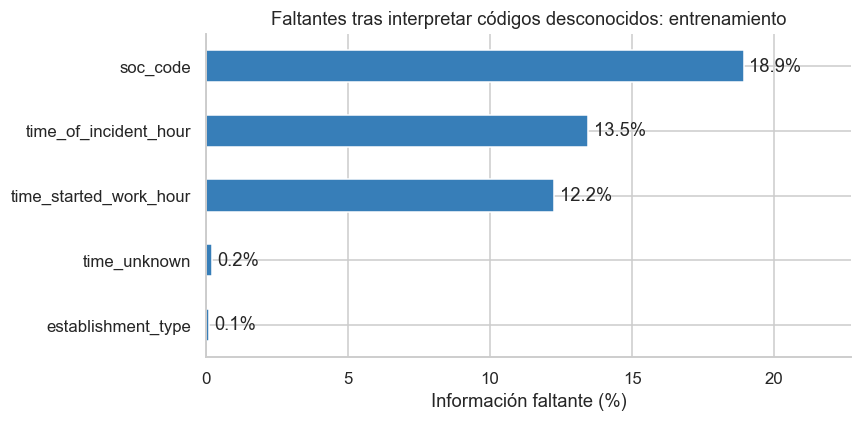

,state,naics_code,establishment_type,soc_code,type_of_incident,time_unknown,time_started_work_hour,time_of_incident_hour
Resultado,,,,,,,,
Fallecimiento (Death),0.000,0.000,0.000,15.942,0.000,0.000,13.043,13.043
Días de ausencia,0.000,0.000,0.067,17.746,0.000,0.206,12.964,16.201
Traslado / restricción,0.000,0.000,0.114,18.659,0.000,0.162,10.099,9.747
Otro caso registrable,0.000,0.000,0.166,20.486,0.000,0.242,13.367,13.718


Los mayores porcentajes de información no utilizable son: **soc_code**: 18.93 %; **time_of_incident_hour**: 13.46 %; **time_started_work_hour**: 12.25 %. Se conserva una categoría explícita de desconocido; no se eliminan casos por faltantes de predictores.

In [5]:
eda.basic_overview(eda_view)
numeric_cols, categorical_cols = eda.get_column_types(feature_view)
display(eda.numeric_summary(feature_view, numeric_cols))
display(eda.categorical_summary(feature_view, categorical_cols))
predictor_missing = eda.missing_values_summary(feature_view)
display(predictor_missing)
fig, ax = plt.subplots(figsize=(8,4))
predictor_missing.missing_pct.sort_values().plot.barh(ax=ax, color='#377eb8')
ax.set(xlabel='Información faltante (%)', ylabel='', title='Faltantes tras interpretar códigos desconocidos: entrenamiento')
for p in ax.patches:
    ax.text(p.get_width()+0.2, p.get_y()+p.get_height()/2, f'{p.get_width():.1f}%', va='center')
ax.set_xlim(0, max(1,predictor_missing.missing_pct.max())*1.2)
plt.tight_layout(); plt.show()
missing_by_outcome = feature_view.isna().groupby(train.outcome).mean().mul(100).reindex(OUTCOMES.values())
display(missing_by_outcome)

worst=feature_view.isna().mean().sort_values(ascending=False).head(3)
display(Markdown('Los mayores porcentajes de información no utilizable son: '+ '; '.join(f'**{k}**: {100*v:.2f} %' for k,v in worst.items())+'. Se conserva una categoría explícita de desconocido; no se eliminan casos por faltantes de predictores.'))


Los faltantes pueden reflejar prácticas de reporte. Las asociaciones observadas no prueban MCAR, MAR o MNAR; el tratamiento se justifica con los resultados de desarrollo mostrados arriba.

#### 5.1 Análisis unidimensional formal de los predictores

Se resume cada predictor según su naturaleza. Los códigos NAICS, SOC, estado, tipo de establecimiento, tipo de incidente y `time_unknown` son **categóricos**, aunque algunos se almacenen como números. Las dos variables horarias se analizan como horas discretas de un ciclo de 24 horas; por esta razón, media, asimetría y normalidad tienen una interpretación limitada y no deben tratarse como si la hora 23 estuviera lejos de la hora 0.

Para las variables categóricas se reportan cardinalidad, categoría dominante y categorías raras (<1 %). Para las horas se muestran distribución y boxplot únicamente como descripción; no se eliminan valores por IQR porque 0–23 es el rango válido del reloj.


,Variable,Tipo,Cardinalidad,Faltantes (%),Categoría más frecuente,Frecuencia máxima (%),Categorías < 1 %,Casos en categorías < 1 % (%)
0,state,Categórica,55,0.000,CA,13.305,26.000,10.916
1,naics_code,Categórica,715,0.000,622110,16.720,700.000,39.038
2,establishment_type,Categórica,5,0.114,1,93.704,2.000,0.204
3,soc_code,Categórica,599,18.930,Desconocido,18.930,582.000,36.652
4,type_of_incident,Categórica,6,0.000,1,89.673,2.000,0.629
5,time_unknown,Categórica,3,0.205,0,86.517,1.000,0.205
6,time_started_work_hour,Hora discreta (0–23),24,12.250,7.0,15.907,NaN,NaN
7,time_of_incident_hour,Hora discreta (0–23),24,13.460,10.0,6.567,NaN,NaN


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


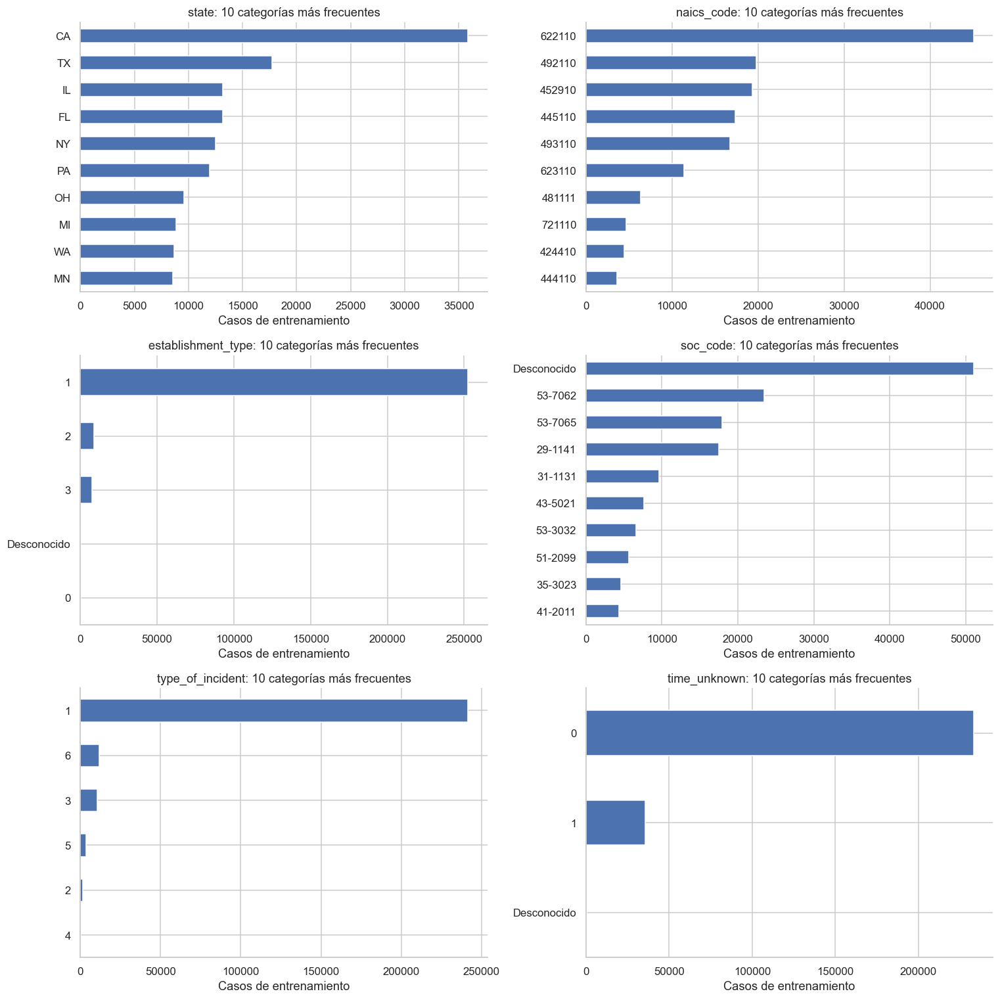

C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


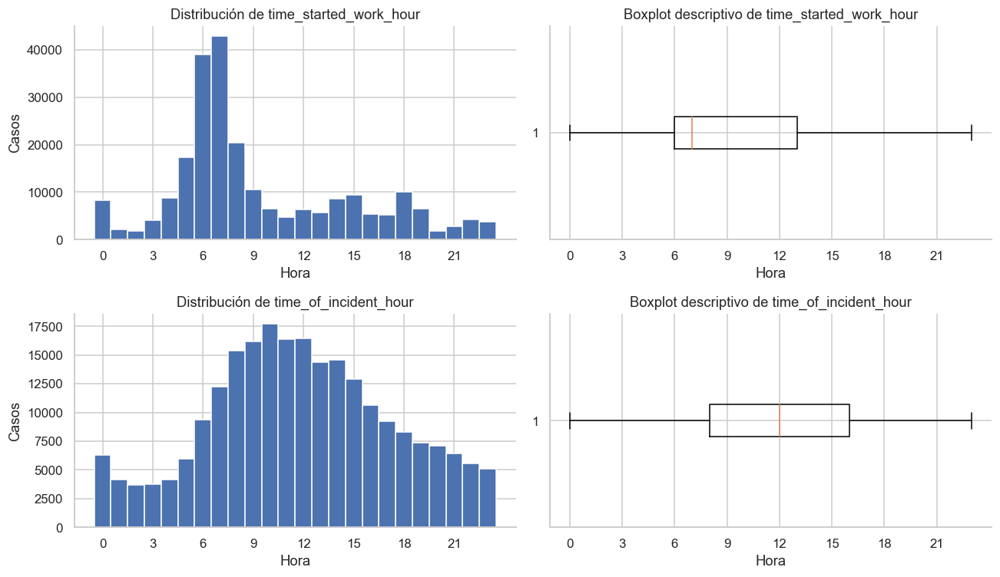

Industria y ocupación son códigos nominales de alta cardinalidad. Se codifican con one-hot; sus números no se interpretan como magnitudes. Las horas se representan como categorías para evitar una relación lineal impuesta entre hora y resultado. Los boxplots son descriptivos: valores horarios válidos no se eliminan por IQR.

In [6]:
# Resumen unidimensional compacto de los ocho predictores
categorical_predictors = baseline['features'][:6]
hour_predictors = baseline['features'][6:]

univariate_rows = []
for c in categorical_predictors:
    s = feature_view[c].astype('object').fillna('Desconocido')
    counts = s.value_counts(dropna=False)
    rare_mask = (counts / len(s)) < 0.01
    univariate_rows.append({
        'Variable': c,
        'Tipo': 'Categórica',
        'Cardinalidad': int(s.nunique(dropna=False)),
        'Faltantes (%)': 100 * feature_view[c].isna().mean(),
        'Categoría más frecuente': str(counts.index[0]),
        'Frecuencia máxima (%)': 100 * counts.iloc[0] / len(s),
        'Categorías < 1 %': int(rare_mask.sum()),
        'Casos en categorías < 1 % (%)': 100 * counts.loc[rare_mask].sum() / len(s)
    })

for c in hour_predictors:
    s = pd.to_numeric(feature_view[c], errors='coerce')
    counts = s.value_counts(dropna=True)
    univariate_rows.append({
        'Variable': c,
        'Tipo': 'Hora discreta (0–23)',
        'Cardinalidad': int(s.nunique(dropna=True)),
        'Faltantes (%)': 100 * s.isna().mean(),
        'Categoría más frecuente': str(counts.index[0]) if len(counts) else 'NA',
        'Frecuencia máxima (%)': 100 * counts.iloc[0] / len(s) if len(counts) else np.nan,
        'Categorías < 1 %': np.nan,
        'Casos en categorías < 1 % (%)': np.nan
    })

display(pd.DataFrame(univariate_rows))

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
for ax, c in zip(axes.flat, categorical_predictors):
    s = feature_view[c].astype('object').fillna('Desconocido')
    counts = s.value_counts().head(10).iloc[::-1]
    counts.plot.barh(ax=ax)
    ax.set(title=f'{c}: 10 categorías más frecuentes',
           xlabel='Casos de entrenamiento', ylabel='')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, c in enumerate(hour_predictors):
    s = pd.to_numeric(feature_view[c], errors='coerce').dropna()
    axes[j, 0].hist(s, bins=np.arange(-0.5, 24.5, 1))
    axes[j, 0].set(title=f'Distribución de {c}', xlabel='Hora', ylabel='Casos',
                   xticks=range(0, 24, 3))
    axes[j, 1].boxplot(s, vert=False)
    axes[j, 1].set(title=f'Boxplot descriptivo de {c}', xlabel='Hora',
                   xticks=range(0, 24, 3))
plt.tight_layout()
plt.show()

display(Markdown('Industria y ocupación son códigos nominales de alta cardinalidad. Se codifican con one-hot; sus números no se interpretan como magnitudes. Las horas se representan como categorías para evitar una relación lineal impuesta entre hora y resultado. Los boxplots son descriptivos: valores horarios válidos no se eliminan por IQR.'))


#### 5.1.1 Momentos, normalidad, valores atípicos y categorías raras

Para las dos horas se reportan media, mediana, desviación estándar, percentiles, asimetría y curtosis, junto con la prueba de D'Agostino–Pearson (muestra completa) y Shapiro–Wilk (submuestra aleatoria de 5.000 casos, límite práctico de la prueba). Con cientos de miles de filas cualquier desviación mínima rechaza la normalidad, así que la prueba confirma formalmente lo que muestran los histogramas; no es un criterio de decisión. Como la hora es cíclica, se añade la **media circular** y la longitud resultante *R* (0 = horas repartidas uniformemente en el reloj; 1 = todas iguales). Los límites IQR solo documentan cuántos valores marcaría la regla de Tukey; no se eliminan porque 0–23 es el rango válido.

Para NAICS, SOC y estado se cuantifican las categorías raras (menos de 30 y de 10 casos de desarrollo) y se justifica su tratamiento.

In [7]:
from scipy import stats

moment_rows = []
for c in hour_predictors:
    s = pd.to_numeric(feature_view[c], errors='coerce').dropna()
    q1, q3 = s.quantile([.25, .75])
    lower, upper = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
    k2, p_k2 = stats.normaltest(s)
    w, p_w = stats.shapiro(s.sample(5000, random_state=42))
    angle = 2*np.pi*s/24
    C, S = np.cos(angle).mean(), np.sin(angle).mean()
    moment_rows.append({'Variable': c, 'Media': s.mean(), 'Mediana': s.median(), 'Desviación estándar': s.std(),
                        'P5': s.quantile(.05), 'P25': q1, 'P75': q3, 'P95': s.quantile(.95),
                        'Asimetría': stats.skew(s), 'Curtosis (exceso)': stats.kurtosis(s),
                        "D'Agostino K²": k2, "p D'Agostino": p_k2, 'Shapiro W (n = 5.000)': w, 'p Shapiro': p_w,
                        'Límite inferior IQR': lower, 'Límite superior IQR': upper,
                        'Casos fuera de IQR': int(((s < lower) | (s > upper)).sum()),
                        'Media circular (hora)': (np.degrees(np.arctan2(S, C)) % 360)/15,
                        'Longitud resultante R': np.hypot(C, S)})
moments = pd.DataFrame(moment_rows).set_index('Variable')
display(moments.T)

rare_rows = []
for c in ['state', 'naics_code', 'soc_code']:
    counts = feature_view[c].astype(object).value_counts()
    rare_rows.append({'Variable': c, 'Categorías observadas': len(counts),
                      'Categorías con < 30 casos': int(counts.lt(30).sum()),
                      'Categorías con < 10 casos': int(counts.lt(10).sum()),
                      'Casos en categorías con < 30': int(counts[counts.lt(30)].sum()),
                      '% de casos en categorías con < 30': 100*counts[counts.lt(30)].sum()/len(feature_view)})
rare_table = pd.DataFrame(rare_rows)
display(rare_table)

start, incident = moments.loc['time_started_work_hour'], moments.loc['time_of_incident_hour']
naics_rare, soc_rare = rare_table.set_index('Variable').loc['naics_code'], rare_table.set_index('Variable').loc['soc_code']
display(Markdown(
    f"**Interpretación.** La hora de inicio es asimétrica a la derecha (asimetría **{start['Asimetría']:.2f}**; mediana {start['Mediana']:.0f} h, concentrada en turnos de mañana) "
    f"y la hora del incidente es casi simétrica (asimetría **{incident['Asimetría']:.2f}**, curtosis {incident['Curtosis (exceso)']:.2f}). Ambas pruebas de normalidad rechazan con p ≈ 0, lo esperado con este tamaño de muestra y con una variable discreta y acotada; por eso no se aplican transformaciones de normalización. "
    f"La longitud resultante (R = {start['Longitud resultante R']:.2f} y {incident['Longitud resultante R']:.2f}) indica que las horas no están concentradas en un único punto del reloj. "
    f"La regla IQR marca {int(start['Casos fuera de IQR']):,} y {int(incident['Casos fuera de IQR']):,} casos: con un rango acotado 0–23 las horas nocturnas no aparecen como atípicas univariadas, y no hay valores fuera del reloj. "
    f"En categorías raras, **{int(naics_rare['Categorías con < 30 casos'])} códigos NAICS** y **{int(soc_rare['Categorías con < 30 casos'])} códigos SOC** tienen menos de 30 casos "
    f"({naics_rare['% de casos en categorías con < 30']:.1f} % y {soc_rare['% de casos en categorías con < 30']:.1f} % de los casos). "
    "**Tratamiento:** se mantienen como columnas one-hot porque la regularización L2 de la regresión logística contrae los coeficientes con poco soporte y `handle_unknown='ignore'` evita errores con códigos nuevos en la prueba. "
    "Agruparlas (por frecuencia o por la jerarquía NAICS/SOC) es una variante razonable que se evaluará solo con validación interna en el siguiente entregable, sin cambiar el modelo base ya fijado."))

Variable,time_started_work_hour,time_of_incident_hour
Media,9.375,11.793
Mediana,7.000,12.000
Desviación estándar,5.412,5.539
P5,2.000,2.000
P25,6.000,8.000
P75,13.000,16.000
P95,20.000,21.000
Asimetría,0.773,-0.013
Curtosis (exceso),-0.173,-0.504
D'Agostino K²,"19,041.327","4,586.452"


,Variable,Categorías observadas,Categorías con < 30 casos,Categorías con < 10 casos,Casos en categorías con < 30,% de casos en categorías con < 30
0,state,55,2,1,15,0.006
1,naics_code,715,354,220,3179,1.180
2,soc_code,598,309,207,2529,0.938


**Interpretación.** La hora de inicio es asimétrica a la derecha (asimetría **0.77**; mediana 7 h, concentrada en turnos de mañana) y la hora del incidente es casi simétrica (asimetría **-0.01**, curtosis -0.50). Ambas pruebas de normalidad rechazan con p ≈ 0, lo esperado con este tamaño de muestra y con una variable discreta y acotada; por eso no se aplican transformaciones de normalización. La longitud resultante (R = 0.42 y 0.32) indica que las horas no están concentradas en un único punto del reloj. La regla IQR marca 0 y 0 casos: con un rango acotado 0–23 las horas nocturnas no aparecen como atípicas univariadas, y no hay valores fuera del reloj. En categorías raras, **354 códigos NAICS** y **309 códigos SOC** tienen menos de 30 casos (1.2 % y 0.9 % de los casos). **Tratamiento:** se mantienen como columnas one-hot porque la regularización L2 de la regresión logística contrae los coeficientes con poco soporte y `handle_unknown='ignore'` evita errores con códigos nuevos en la prueba. Agruparlas (por frecuencia o por la jerarquía NAICS/SOC) es una variante razonable que se evaluará solo con validación interna en el siguiente entregable, sin cambiar el modelo base ya fijado.

#### 5.2 Patrón y mecanismo de valores faltantes

El enunciado solicita distinguir MCAR, MAR y MNAR. Con estos datos observacionales no es posible demostrar el mecanismo de ausencia solo a partir del CSV. Sin embargo, se puede evaluar si la ausencia se relaciona con variables observadas.

La matriz siguiente visualiza una muestra aleatoria únicamente para mostrar **patrones de ausencia**; los porcentajes y cálculos continúan usando todo el entrenamiento. La concentración de faltantes por resultado y por variable contradice una lectura ingenua de “faltantes completamente al azar”. En consecuencia, el proyecto trata la imputación como parte del `Pipeline` y conserva explícitamente la incertidumbre sobre el mecanismo.


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


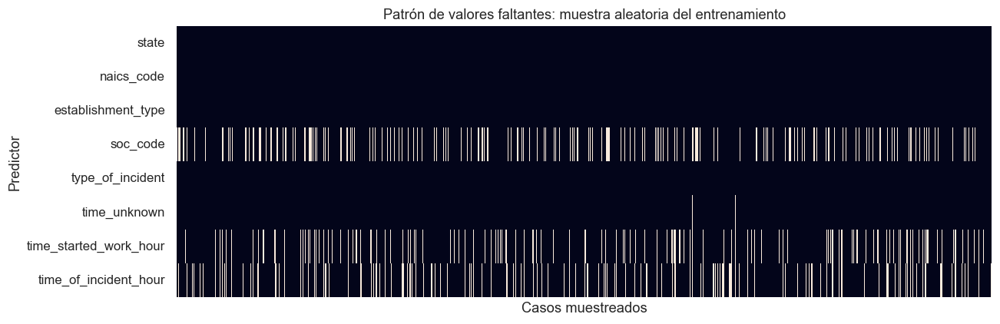

,state,naics_code,establishment_type,soc_code,type_of_incident,time_unknown,time_started_work_hour,time_of_incident_hour
Resultado,,,,,,,,
Fallecimiento (Death),0.000,0.000,0.000,15.942,0.000,0.000,13.043,13.043
Días de ausencia,0.000,0.000,0.067,17.746,0.000,0.206,12.964,16.201
Traslado / restricción,0.000,0.000,0.114,18.659,0.000,0.162,10.099,9.747
Otro caso registrable,0.000,0.000,0.166,20.486,0.000,0.242,13.367,13.718


In [8]:
missing_matrix = feature_view.isna()
missing_sample = missing_matrix.sample(n=min(3000, len(missing_matrix)), random_state=42)

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(missing_sample.T, cbar=False, yticklabels=True, xticklabels=False, ax=ax)
ax.set(title='Patrón de valores faltantes: muestra aleatoria del entrenamiento',
       xlabel='Casos muestreados', ylabel='Predictor')
plt.tight_layout()
plt.show()

display(
    missing_matrix.groupby(train.outcome)
    .mean()
    .mul(100)
    .reindex(OUTCOMES.values())
    .rename_axis('Resultado')
)


#### 5.2.1 Evidencia sobre el mecanismo: registros completos frente a incompletos

La prueba de Little supone variables continuas aproximadamente normales, así que no sirve para códigos nominales de alta cardinalidad como NAICS o SOC. Se usa la alternativa que admite el enunciado: **comparar la distribución de variables observadas entre registros completos e incompletos**. Si los faltantes fueran MCAR, el indicador de ausencia sería independiente de sector, estado, tipo de establecimiento, tipo de incidente y resultado (V de Cramér ≈ 0), y dentro de cada establecimiento la ausencia seguiría un proceso binomial con la tasa global. Ambas hipótesis se contrastan a continuación. Los p-valores se corrigen con Holm; la magnitud (V) es la medida principal.

,Faltante en,Variable observada,V de Cramér,p χ²,p Holm
0,soc_code,Resultado,0.029,4.05e-51,8.10e-51
1,soc_code,Sector industrial,0.166,0.00e+00,0.00e+00
2,soc_code,Estado,0.077,0.00e+00,0.00e+00
3,soc_code,Tipo de establecimiento,0.024,4.70e-35,4.70e-35
4,soc_code,Tipo de incidente,0.066,1.53e-251,6.11e-251
5,time_of_incident_hour,Resultado,0.077,0.00e+00,0.00e+00
6,time_of_incident_hour,Sector industrial,0.197,0.00e+00,0.00e+00
7,time_of_incident_hour,Estado,0.129,0.00e+00,0.00e+00
8,time_of_incident_hour,Tipo de establecimiento,0.072,4.50e-307,2.25e-306
9,time_of_incident_hour,Tipo de incidente,0.334,0.00e+00,0.00e+00


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


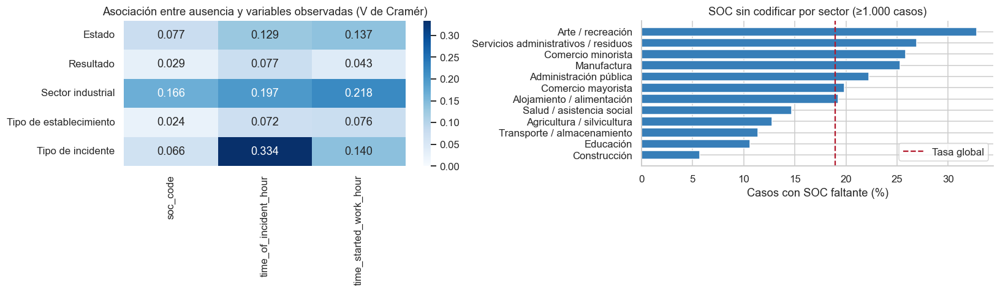

,Observado,Esperado bajo MCAR (simulación)
% establecimientos sin ningún SOC faltante,38.882,16.207
% establecimientos con todos los SOC faltantes,1.334,0.000
Desviación estándar de la tasa por establecimiento,0.239,0.133


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


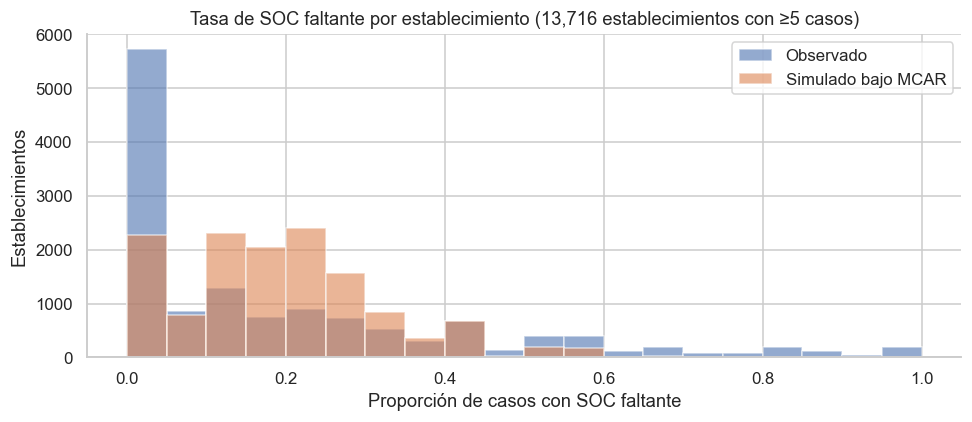

**Interpretación.** La ausencia de SOC se asocia sobre todo con **sector industrial** (V = 0.166) y se concentra por establecimiento: el 38.9 % de los establecimientos con ≥5 casos no tiene ningún SOC faltante (esperado bajo MCAR: 16.2 %), el 1.3 % los tiene todos faltantes (esperado: 0.0 %) y la dispersión entre establecimientos casi duplica la esperada (0.239 frente a 0.133). Esto **descarta MCAR**. El patrón es compatible con **MAR condicionado al establecimiento y al sector**: refleja cómo describe cada empleador el puesto (el código SOC lo asigna OSHA a partir de ese texto), no el desenlace. En la hora del incidente, el 98.6 % de los faltantes es estructural: el propio registro declara la hora como desconocida (`time_unknown = 1`). No puede descartarse un componente MNAR (por ejemplo, descripciones vagas en casos más graves), y la asociación con el resultado es pequeña. **Decisión:** no se eliminan filas ni se imputa la moda. La ausencia se codifica como una categoría explícita `Unknown` dentro del Pipeline, así el modelo usa la información de que falta y la imputación se aprende solo con el entrenamiento.

In [9]:
from statsmodels.stats.multitest import multipletests

def cramers_v_bias_corrected(x, y):
    # V de Cramér con corrección de sesgo de Bergsma (2013); se reutiliza en 8.1.
    table = pd.crosstab(pd.Series(x, copy=False).fillna('Desconocido').astype(str),
                        pd.Series(y, copy=False).astype(str))
    chi2, p, dof, _ = chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()
    r, k = table.shape
    phi2corr = max(0.0, chi2/n - ((k-1)*(r-1))/(n-1))
    rcorr, kcorr = r - ((r-1)**2)/(n-1), k - ((k-1)**2)/(n-1)
    denom = min(kcorr-1, rcorr-1)
    return (float(np.sqrt(phi2corr/denom)) if denom > 0 else 0.0), float(p), int(dof)

from scipy.stats import chi2_contingency
missing_flags = {'soc_code': feature_view.soc_code.isna(),
                 'time_of_incident_hour': feature_view.time_of_incident_hour.isna(),
                 'time_started_work_hour': feature_view.time_started_work_hour.isna()}
observed_context = {'Resultado': train.outcome, 'Sector industrial': train.industry_sector, 'Estado': train.state,
                    'Tipo de establecimiento': train.establishment_type_label, 'Tipo de incidente': train.incident_type}
mechanism_rows = []
for flag_name, flag in missing_flags.items():
    for context_name, context in observed_context.items():
        v, p, dof = cramers_v_bias_corrected(context, flag.map({True: 'Faltante', False: 'Observado'}))
        mechanism_rows.append({'Faltante en': flag_name, 'Variable observada': context_name, 'V de Cramér': v, 'p χ²': p})
mechanism = pd.DataFrame(mechanism_rows)
mechanism['p Holm'] = multipletests(mechanism['p χ²'], method='holm')[1]
display(mechanism.assign(**{'p χ²': mechanism['p χ²'].map('{:.2e}'.format), 'p Holm': mechanism['p Holm'].map('{:.2e}'.format)}))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(mechanism.pivot(index='Variable observada', columns='Faltante en', values='V de Cramér'),
            annot=True, fmt='.3f', cmap='Blues', vmin=0, ax=axes[0])
axes[0].set(title='Asociación entre ausencia y variables observadas (V de Cramér)', xlabel='', ylabel='')
soc_by_sector = feature_view.soc_code.isna().groupby(train.industry_sector).agg(['mean', 'size'])
soc_by_sector = soc_by_sector[soc_by_sector['size'].ge(1000)].sort_values('mean')
axes[1].barh(soc_by_sector.index, 100*soc_by_sector['mean'], color='#377eb8')
axes[1].axvline(100*feature_view.soc_code.isna().mean(), color='#b2182b', linestyle='--', label='Tasa global')
axes[1].set(title='SOC sin codificar por sector (≥1.000 casos)', xlabel='Casos con SOC faltante (%)', ylabel='')
axes[1].legend()
plt.tight_layout(); plt.show()

# Agrupamiento por establecimiento: tasa observada frente a una simulación binomial bajo MCAR.
soc_missing_rate = feature_view.soc_code.isna().mean()
by_establishment = (pd.DataFrame({'g': train[GROUP].to_numpy(), 'm': feature_view.soc_code.isna().to_numpy()})
                    .groupby('g').m.agg(['mean', 'size']))
by_establishment = by_establishment[by_establishment['size'].ge(5)]
simulated = np.random.default_rng(42).binomial(by_establishment['size'].to_numpy(), soc_missing_rate) / by_establishment['size'].to_numpy()
clustering = pd.DataFrame({
    'Observado': [by_establishment['mean'].eq(0).mean()*100, by_establishment['mean'].eq(1).mean()*100, by_establishment['mean'].std()],
    'Esperado bajo MCAR (simulación)': [(simulated == 0).mean()*100, (simulated == 1).mean()*100, simulated.std()]},
    index=['% establecimientos sin ningún SOC faltante', '% establecimientos con todos los SOC faltantes',
           'Desviación estándar de la tasa por establecimiento'])
display(clustering)
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 21)
ax.hist(by_establishment['mean'], bins=bins, alpha=.6, label='Observado')
ax.hist(simulated, bins=bins, alpha=.6, label='Simulado bajo MCAR')
ax.set(title=f'Tasa de SOC faltante por establecimiento ({len(by_establishment):,} establecimientos con ≥5 casos)',
       xlabel='Proporción de casos con SOC faltante', ylabel='Establecimientos')
ax.legend(); plt.tight_layout(); plt.show()

structural = (train.time_unknown.eq('1') & feature_view.time_of_incident_hour.isna()).sum() / feature_view.time_of_incident_hour.isna().sum()
top_soc = mechanism[mechanism['Faltante en'].eq('soc_code')].sort_values('V de Cramér', ascending=False).iloc[0]
display(Markdown(
    f"**Interpretación.** La ausencia de SOC se asocia sobre todo con **{top_soc['Variable observada'].lower()}** (V = {top_soc['V de Cramér']:.3f}) y se concentra por establecimiento: "
    f"el {clustering.loc['% establecimientos sin ningún SOC faltante', 'Observado']:.1f} % de los establecimientos con ≥5 casos no tiene ningún SOC faltante (esperado bajo MCAR: {clustering.loc['% establecimientos sin ningún SOC faltante', 'Esperado bajo MCAR (simulación)']:.1f} %), "
    f"el {clustering.loc['% establecimientos con todos los SOC faltantes', 'Observado']:.1f} % los tiene todos faltantes (esperado: {clustering.loc['% establecimientos con todos los SOC faltantes', 'Esperado bajo MCAR (simulación)']:.1f} %) "
    f"y la dispersión entre establecimientos casi duplica la esperada ({clustering.loc['Desviación estándar de la tasa por establecimiento', 'Observado']:.3f} frente a {clustering.loc['Desviación estándar de la tasa por establecimiento', 'Esperado bajo MCAR (simulación)']:.3f}). Esto **descarta MCAR**. "
    "El patrón es compatible con **MAR condicionado al establecimiento y al sector**: refleja cómo describe cada empleador el puesto (el código SOC lo asigna OSHA a partir de ese texto), no el desenlace. "
    f"En la hora del incidente, el {100*structural:.1f} % de los faltantes es estructural: el propio registro declara la hora como desconocida (`time_unknown = 1`). "
    "No puede descartarse un componente MNAR (por ejemplo, descripciones vagas en casos más graves), y la asociación con el resultado es pequeña. "
    "**Decisión:** no se eliminan filas ni se imputa la moda. La ausencia se codifica como una categoría explícita `Unknown` dentro del Pipeline, así el modelo usa la información de que falta y la imputación se aprende solo con el entrenamiento."))

### 6. Distribución del resultado y del tipo de incidente


,Casos,Porcentaje
Resultado,,
Fallecimiento (Death),69,0.026
Días de ausencia,99697,36.991
Traslado / restricción,79848,29.626
Otro caso registrable,89902,33.357


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


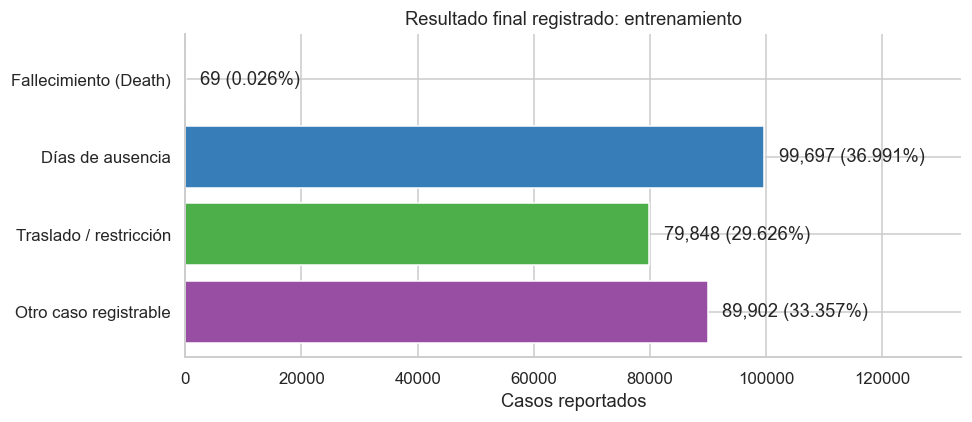

,Casos,Porcentaje
incident_type,,
Lesión,241682,89.673
Otra enfermedad,11869,4.404
Afección respiratoria,10497,3.895
Pérdida auditiva,3772,1.400
Trastorno cutáneo,1412,0.524
Intoxicación,284,0.105


C:\Users\Usuario\miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Usuario\miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


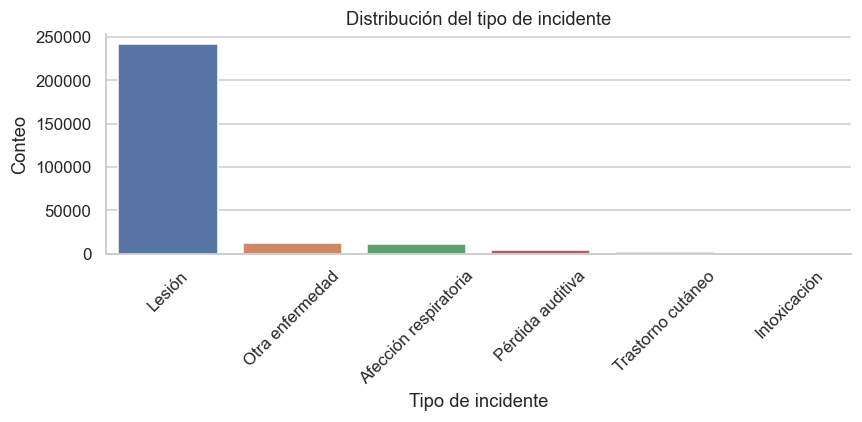

C:\Users\Usuario\miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Usuario\miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


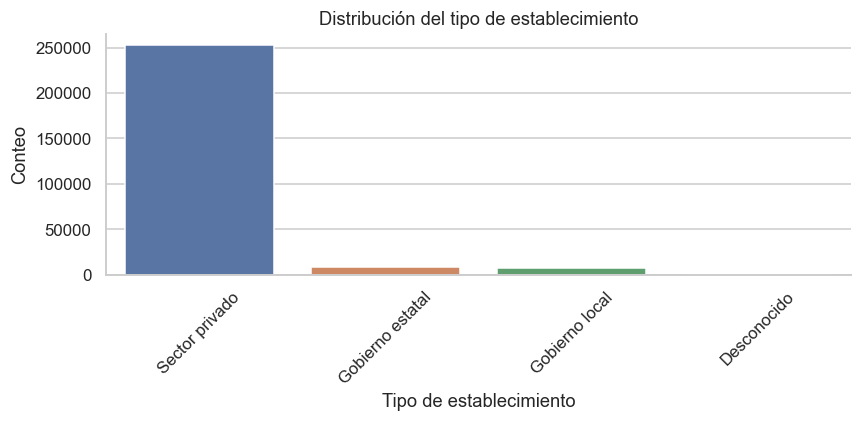

,Valor
Razón clase mayoritaria / minoritaria,"1,444.884"
Razón mayoritaria / minoritaria sin Death,1.249
Entropía normalizada (1 = balance perfecto),0.791
Casos de la clase minoritaria (Death),69.000


**Grado de desbalance:** la clase mayoritaria es **1,445 veces** la minoritaria; sin Death, las tres clases restantes están casi balanceadas (razón 1.25). El desbalance es **extremo pero concentrado en una sola clase**: justifica `class_weight='balanced'`, métricas macro y por clase, curvas precisión–sensibilidad y partición estratificada en la validación interna (`StratifiedGroupKFold`).

El desarrollo contiene **69 fallecimientos** entre **269,516 casos**. Esta rareza exige métricas por clase y precisión–sensibilidad; la exactitud global puede ocultar fallos en Death. No se agrupan resultados para mejorar puntuaciones.

In [10]:
def count_table(series):
    t = series.fillna('Desconocido').value_counts().rename('cases').to_frame()
    t['percent'] = 100*t.cases/len(series)
    return t

target_counts = train.outcome.value_counts().reindex(OUTCOMES.values()).rename('cases').to_frame()
target_counts['percent'] = target_counts.cases/len(train)*100
display(target_counts)
fig, ax = plt.subplots(figsize=(9,4))
ax.barh(target_counts.index, target_counts.cases, color=['#b2182b','#377eb8','#4daf4a','#984ea3'])
for i, row in enumerate(target_counts.itertuples()):
    ax.text(row.cases+2500, i, f'{row.cases:,} ({row.percent:.3f}%)', va='center')
ax.set(xlabel='Casos reportados', ylabel='', title='Resultado final registrado: entrenamiento', xlim=(0,target_counts.cases.max()*1.34))
ax.invert_yaxis(); plt.tight_layout(); plt.show()
display(count_table(train.incident_type))
eda.plot_categorical_distributions(train, ['incident_type','establishment_type_label'], max_categories=10)

imbalance = pd.Series({
    'Razón clase mayoritaria / minoritaria': target_counts.cases.max() / target_counts.cases.min(),
    'Razón mayoritaria / minoritaria sin Death': target_counts.cases.drop(OUTCOMES[1]).max() / target_counts.cases.drop(OUTCOMES[1]).min(),
    'Entropía normalizada (1 = balance perfecto)': float(-(target_counts.percent/100 * np.log(target_counts.percent/100)).sum() / np.log(len(target_counts))),
    'Casos de la clase minoritaria (Death)': int(target_counts.cases.min()),
}, name='value').to_frame()
display(imbalance)
display(Markdown(f"**Grado de desbalance:** la clase mayoritaria es **{imbalance.iloc[0, 0]:,.0f} veces** la minoritaria; sin Death, las tres clases restantes están casi balanceadas (razón {imbalance.iloc[1, 0]:.2f}). El desbalance es **extremo pero concentrado en una sola clase**: justifica `class_weight='balanced'`, métricas macro y por clase, curvas precisión–sensibilidad y partición estratificada en la validación interna (`StratifiedGroupKFold`)."))
display(Markdown(f'El desarrollo contiene **{int(train[TARGET].eq(1).sum())} fallecimientos** entre **{len(train):,} casos**. Esta rareza exige métricas por clase y precisión–sensibilidad; la exactitud global puede ocultar fallos en Death. No se agrupan resultados para mejorar puntuaciones.'))


Death es una clase pequeña y sustantivamente distinta. La exactitud global puede ocultar un desempeño deficiente en ella. La exactitud balanceada (promedio de sensibilidad por clase), F1 macro y las métricas por clase deben complementar la exactitud. No se interpretan los códigos como una escala de gravedad de cuatro puntos ni se agrupan clases para mejorar las puntuaciones.


### 7. Industria, ocupación y distribución geográfica


,Casos,Porcentaje
industry_sector,,
Salud / asistencia social,70802,26.270
Transporte / almacenamiento,57429,21.308
Comercio minorista,50979,18.915
Manufactura,49857,18.499
Comercio mayorista,11749,4.359
Alojamiento / alimentación,6709,2.489
Administración pública,4436,1.646
Arte / recreación,4382,1.626
Agricultura / silvicultura,3906,1.449


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


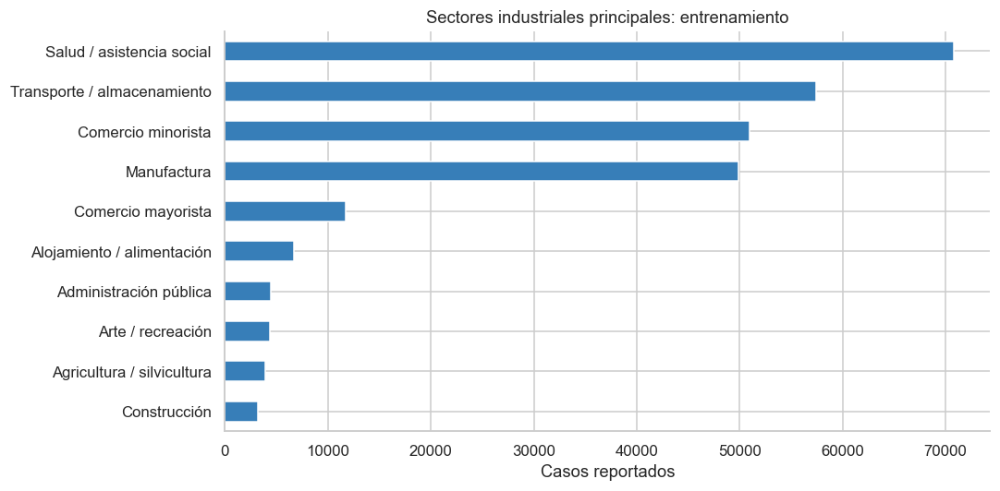

,Casos,Porcentaje
soc_description,,
Sin codificar,51019,18.930
Trabajadores de carga y movimiento manual de materiales,23444,8.699
Reponedores y preparadores de pedidos,17915,6.647
Profesionales de enfermería,17451,6.475
Auxiliares de enfermería,9579,3.554
Mensajeros,7659,2.842
Conductores de camiones pesados y tractocamiones,6621,2.457
Otros ensambladores y fabricantes,5949,2.207
Trabajadores de comida rápida y mostrador,4627,1.717


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


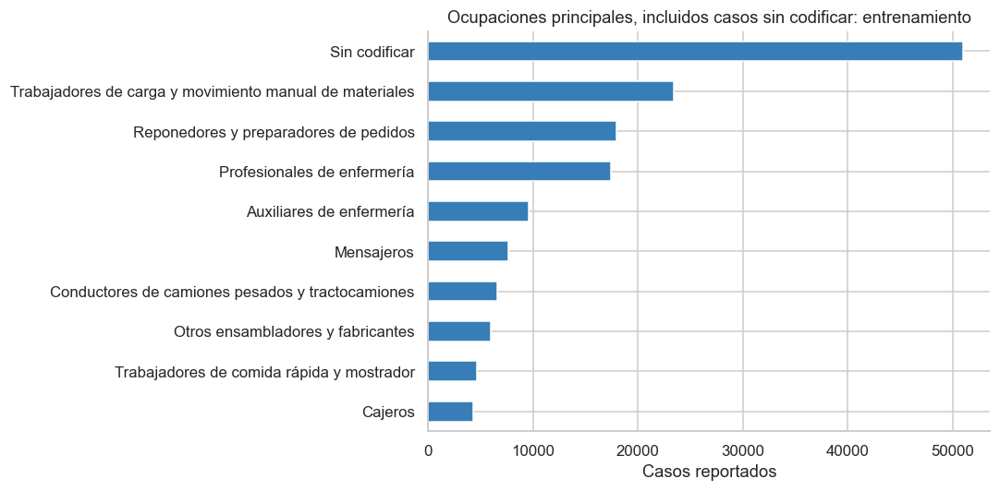

,Casos,Porcentaje
state,,
CA,35858,13.305
TX,17717,6.574
IL,13177,4.889
FL,13145,4.877
NY,12483,4.632
PA,11955,4.436
OH,9592,3.559
MI,8858,3.287
WA,8693,3.225


Códigos NAICS distintos: 715 | ocupaciones codificadas: 598 | códigos de estado/territorio: 55
Filas sin sector industrial reconocido: 45


In [11]:
def top_categories(series, title, n=10):
    table = count_table(series)
    display(table.head(n))
    shown = table.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10,5))
    shown.cases.plot.barh(ax=ax, color='#377eb8')
    ax.set(title=title, xlabel='Casos reportados', ylabel='')
    plt.tight_layout(); plt.show()
    return table

industry_counts = top_categories(train.industry_sector, 'Sectores industriales principales: entrenamiento')
occupation_counts = top_categories(train.soc_description, 'Ocupaciones principales, incluidos casos sin codificar: entrenamiento')
state_counts = count_table(train.state)
display(state_counts.head(10))
print('Códigos NAICS distintos:', train.naics_code.nunique(), '| ocupaciones codificadas:', train.soc_code.nunique(), '| códigos de estado/territorio:', train.state.nunique())
print('Filas sin sector industrial reconocido:', int(train.industry_sector.eq('Código sin correspondencia').sum()))


Se muestran **proporciones de casos reportados**, no tasas de lesiones ni clasificaciones de riesgo industrial. El tamaño del establecimiento, las horas de exposición, los criterios de cobertura y las prácticas de reporte afectan los conteos. Industria y ocupación están relacionadas y pueden aportar información redundante. Las versiones de los códigos y los valores no reconocidos requieren una auditoría posterior del diccionario; no se les asigna un significado supuesto.


### 8. Relaciones entre predictores y resultado multiclase


incident_outcome,Fallecimiento (Death),Días de ausencia,Traslado / restricción,Otro caso registrable,Total de casos
industry_sector,,,,,
Salud / asistencia social,2,25373,12400,33027,70802
Transporte / almacenamiento,13,25875,22986,8555,57429
Comercio minorista,3,18569,12353,20054,50979
Manufactura,23,14784,18613,16437,49857
Comercio mayorista,5,4812,4714,2218,11749
Alojamiento / alimentación,4,2604,2074,2027,6709
Administración pública,3,1743,790,1900,4436
Arte / recreación,0,1249,1984,1149,4382
Agricultura / silvicultura,4,1387,1223,1292,3906


,Fallecimiento (Death),Días de ausencia,Traslado / restricción,Otro caso registrable
industry_sector,,,,
Salud / asistencia social,0.003,35.837,17.514,46.647
Transporte / almacenamiento,0.023,45.056,40.025,14.897
Comercio minorista,0.006,36.425,24.232,39.338
Manufactura,0.046,29.653,37.333,32.968
Comercio mayorista,0.043,40.957,40.123,18.878
Alojamiento / alimentación,0.060,38.814,30.914,30.213
Administración pública,0.068,39.292,17.809,42.831
Arte / recreación,0.000,28.503,45.276,26.221
Agricultura / silvicultura,0.102,35.509,31.311,33.077


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


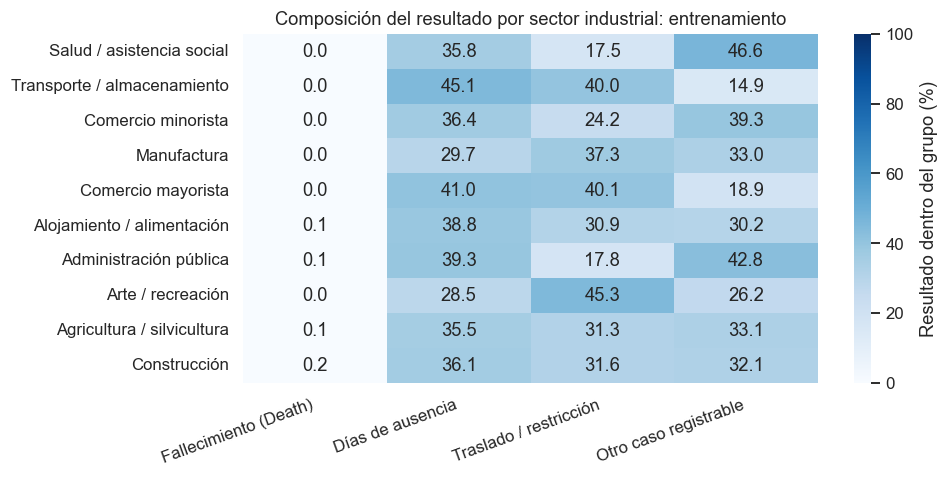

incident_outcome,Fallecimiento (Death),Días de ausencia,Traslado / restricción,Otro caso registrable,Total de casos
incident_type,,,,,
Lesión,55,85122,75600,80905,241682
Trastorno cutáneo,0,585,181,646,1412
Afección respiratoria,3,9636,119,739,10497
Intoxicación,0,86,56,142,284
Pérdida auditiva,0,382,342,3048,3772
Otra enfermedad,11,3886,3550,4422,11869


,Fallecimiento (Death),Días de ausencia,Traslado / restricción,Otro caso registrable
incident_type,,,,
Lesión,0.023,35.221,31.281,33.476
Trastorno cutáneo,0.000,41.431,12.819,45.751
Afección respiratoria,0.029,91.798,1.134,7.040
Intoxicación,0.000,30.282,19.718,50.000
Pérdida auditiva,0.000,10.127,9.067,80.806
Otra enfermedad,0.093,32.741,29.910,37.257


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


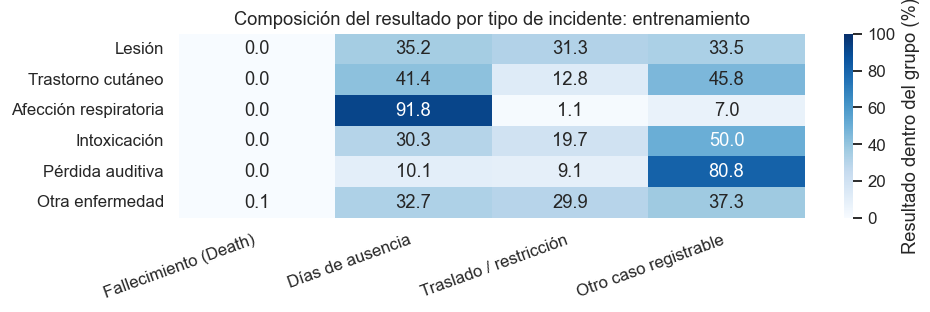

incident_outcome,Fallecimiento (Death),Días de ausencia,Traslado / restricción,Otro caso registrable,Total de casos
soc_description,,,,,
Sin codificar,11,17692,14899,18417,51019
Trabajadores de carga y movimiento manual de materiales,1,9017,9785,4641,23444
Reponedores y preparadores de pedidos,1,5163,9191,3560,17915
Profesionales de enfermería,0,4828,2402,10221,17451
Auxiliares de enfermería,0,4714,2436,2429,9579
Mensajeros,0,4144,2141,1374,7659
Conductores de camiones pesados y tractocamiones,10,3340,2009,1262,6621
Otros ensambladores y fabricantes,1,1962,2254,1732,5949


,Fallecimiento (Death),Días de ausencia,Traslado / restricción,Otro caso registrable
soc_description,,,,
Sin codificar,0.022,34.677,29.203,36.098
Trabajadores de carga y movimiento manual de materiales,0.004,38.462,41.738,19.796
Reponedores y preparadores de pedidos,0.006,28.819,51.303,19.872
Profesionales de enfermería,0.000,27.666,13.764,58.570
Auxiliares de enfermería,0.000,49.212,25.431,25.358
Mensajeros,0.000,54.106,27.954,17.940
Conductores de camiones pesados y tractocamiones,0.151,50.446,30.343,19.061
Otros ensambladores y fabricantes,0.017,32.980,37.889,29.114


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


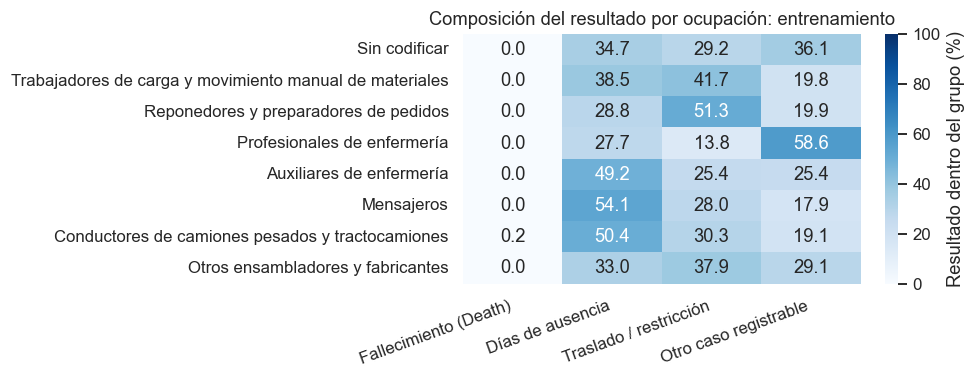

Las composiciones mostradas utilizan casos reportados dentro de cada grupo. Las diferencias pueden reflejar mezcla ocupacional, diagnósticos y prácticas de reporte. Sin trabajadores u horas expuestos como denominador, no son probabilidades de lesión.

In [12]:
def outcome_comparison(column, title, levels=None):
    levels = levels if levels is not None else train[column].fillna('Desconocido').value_counts().head(10).index
    counts = pd.crosstab(train[column].fillna('Desconocido'), train[TARGET]).reindex(index=levels, columns=list(OUTCOMES), fill_value=0)
    proportions = counts.div(counts.sum(axis=1),axis=0)*100
    proportions.columns = [OUTCOMES[c] for c in proportions.columns]
    display(counts.rename(columns=OUTCOMES).assign(total_cases=counts.sum(axis=1)))
    display(proportions)
    fig, ax = plt.subplots(figsize=(9,max(3,len(levels)*0.45)))
    sns.heatmap(proportions, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100, ax=ax, cbar_kws={'label':'Resultado dentro del grupo (%)'})
    ax.set(title=title, xlabel='', ylabel='')
    plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.show()
    return proportions

industry_outcomes = outcome_comparison('industry_sector', 'Composición del resultado por sector industrial: entrenamiento')
incident_outcomes = outcome_comparison('incident_type', 'Composición del resultado por tipo de incidente: entrenamiento', list(INCIDENTS.values()))
occupation_outcomes = outcome_comparison('soc_description', 'Composición del resultado por ocupación: entrenamiento', occupation_counts.head(8).index)

display(Markdown('Las composiciones mostradas utilizan casos reportados dentro de cada grupo. Las diferencias pueden reflejar mezcla ocupacional, diagnósticos y prácticas de reporte. Sin trabajadores u horas expuestos como denominador, no son probabilidades de lesión.'))


Los denominadores son los casos de cada grupo. Las tablas conservan los conteos de fallecimientos porque un mapa de porcentajes puede ocultar esta clase infrecuente. Las comparaciones son descriptivas y no están ajustadas por composición industria–ocupación, prácticas de los empleadores u otros factores. La dependencia dentro de establecimientos invalida una interpretación ingenua de pruebas basadas en filas independientes; los valores p clásicos que aparecen después son ilustraciones bajo un supuesto de independencia incumplido, no inferencia válida para estos datos. Bonferroni controla multiplicidad solo bajo los supuestos de cada prueba y no repara esta dependencia. Las decisiones se apoyan en magnitudes descriptivas y procedencia, no en significancia.



#### 8.1 Asociación entre predictores y variable objetivo

Para los predictores categóricos se reporta **χ²** y **V de Cramér**. Debido a que hay cientos de miles de filas y dependencia dentro de establecimientos, los valores p pueden ser extremadamente pequeños incluso para asociaciones modestas; por ello, **V de Cramér es la medida principal de magnitud**. Los valores p se muestran como referencia descriptiva y se ajustan con Bonferroni.

También se reporta **información mutua normalizada (NMI)** como medida no lineal. Las horas se discretizan por hora del día para este cálculo. Para las dos variables horarias se añade Kruskal–Wallis y un tamaño de efecto aproximado ε². Ninguno de estos análisis implica causalidad.


,Predictor,Tipo de análisis,V de Cramér,NMI,p-valor χ²,Grados de libertad,p ajustado Bonferroni
1,naics_code,χ² / V de Cramér,0.236,0.033,0.000,2142,0.000
3,soc_code,χ² / V de Cramér,0.206,0.025,0.000,1794,0.000
4,type_of_incident,χ² / V de Cramér,0.150,0.045,0.000,15,0.000
0,state,χ² / V de Cramér,0.121,0.010,0.000,162,0.000
2,establishment_type,χ² / V de Cramér,0.056,0.007,0.000,12,0.000
5,time_unknown,χ² / V de Cramér,0.055,0.004,0.000,6,0.000


,Predictor,H de Kruskal–Wallis,p-valor,ε² aproximado,NMI (hora discretizada),Casos utilizables,p ajustado Bonferroni
0,time_started_work_hour,2.068,0.558,0.000,0.004,236501,1.000
1,time_of_incident_hour,88.191,0.000,0.000,0.002,233239,0.000


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


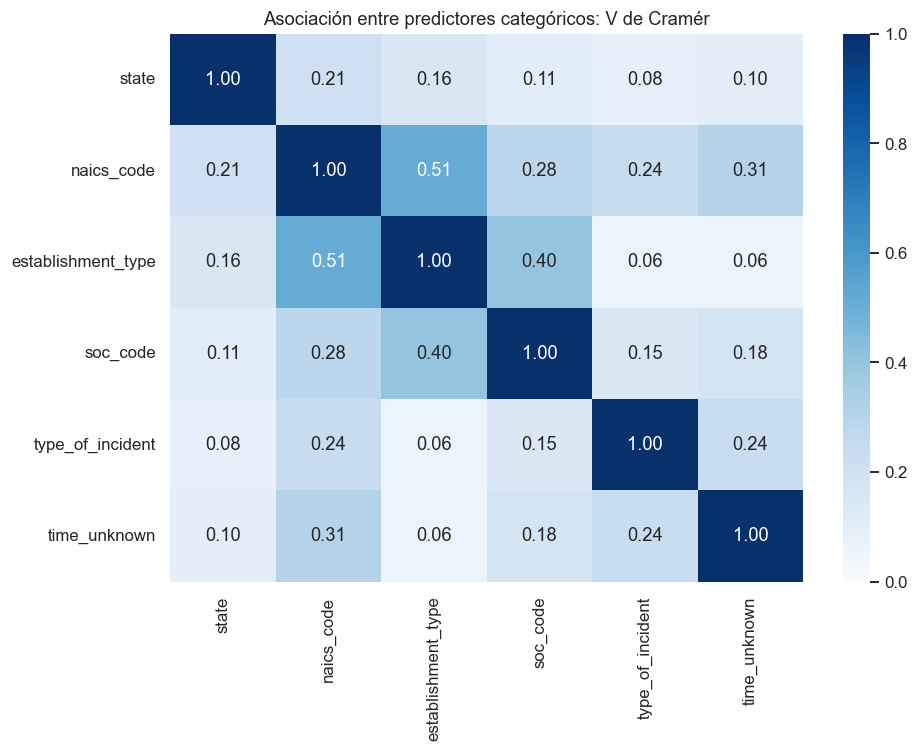

,Predictor,AUC macro OvR en agosto–septiembre,Solver final,Iteraciones,Verificado
0,state,0.512,newton-cg,21,True
1,naics_code,0.629,newton-cg,22,True
2,establishment_type,0.515,newton-cg,16,True
3,soc_code,0.618,newton-cg,21,True
4,type_of_incident,0.572,newton-cg,15,True
5,time_unknown,0.499,newton-cg,12,True
6,time_started_work_hour,0.517,newton-cg,21,True
7,time_of_incident_hour,0.517,newton-cg,21,True


,Predictor,solver,iterations,warnings,numerically_verified
0,state,newton-cg,21,[],True
1,naics_code,newton-cg,22,[],True
2,establishment_type,newton-cg,16,[],True
3,soc_code,newton-cg,21,[],True
4,type_of_incident,newton-cg,15,[],True
5,time_unknown,newton-cg,12,[],True
6,time_started_work_hour,newton-cg,21,[],True
7,time_of_incident_hour,newton-cg,21,[],True


Estos ajustes univariables son diagnósticos de fuga dentro del desarrollo; no seleccionan variables ni hiperparámetros. Una asociación fuerte exige examinar disponibilidad y procedencia, no demuestra fuga por sí sola.

La mayor asociación categórica observada corresponde a **naics_code**, con V de Cramér **0.236**. La magnitud y las tablas de composición son más informativas que p-valores de filas dependientes; Bonferroni no corrige la dependencia dentro de establecimientos.

In [13]:
from scipy.stats import chi2_contingency, kruskal
from sklearn.metrics import normalized_mutual_info_score

def cramers_v_bias_corrected(x, y):
    table = pd.crosstab(
        pd.Series(x, copy=False).fillna('Desconocido').astype(str),
        pd.Series(y, copy=False).astype(str)
    )
    chi2, p, dof, _ = chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()
    phi2 = chi2 / n
    r, k = table.shape
    if n <= 1:
        return np.nan, p, dof
    phi2corr = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    denom = min(kcorr - 1, rcorr - 1)
    v = np.sqrt(phi2corr / denom) if denom > 0 else 0.0
    return float(v), float(p), int(dof)

association_rows = []
for c in categorical_predictors:
    s = feature_view[c].astype('object').fillna('Desconocido')
    v, p, dof = cramers_v_bias_corrected(s, train[TARGET])
    nmi = normalized_mutual_info_score(s.astype(str), train[TARGET].astype(str))
    association_rows.append({
        'Predictor': c,
        'Tipo de análisis': 'χ² / V de Cramér',
        'V de Cramér': v,
        'NMI': nmi,
        'p-valor χ²': p,
        'Grados de libertad': dof
    })

association_df = pd.DataFrame(association_rows)
association_df['p ajustado Bonferroni'] = np.minimum(
    association_df['p-valor χ²'] * len(association_df), 1.0
)
display(association_df.sort_values('V de Cramér', ascending=False))

hour_rows = []
for c in hour_predictors:
    s = pd.to_numeric(feature_view[c], errors='coerce')
    groups = [s.loc[train[TARGET].eq(label)].dropna().to_numpy() for label in sorted(OUTCOMES)]
    H, p = kruskal(*groups)
    n = sum(len(g) for g in groups)
    k = len(groups)
    epsilon2 = max(0.0, (H - k + 1) / (n - k)) if n > k else np.nan
    hour_as_category = s.round().astype('Int64').astype(str).replace('<NA>', 'Desconocido')
    nmi = normalized_mutual_info_score(hour_as_category, train[TARGET].astype(str))
    hour_rows.append({
        'Predictor': c,
        'H de Kruskal–Wallis': H,
        'p-valor': p,
        'ε² aproximado': epsilon2,
        'NMI (hora discretizada)': nmi,
        'Casos utilizables': n
    })
hour_df=pd.DataFrame(hour_rows)
hour_df['p ajustado Bonferroni']=np.minimum(hour_df['p-valor']*len(hour_df),1.0)
display(hour_df)

pair_vars = list(categorical_predictors)
v_matrix = pd.DataFrame(np.eye(len(pair_vars)), index=pair_vars, columns=pair_vars)
for i, a in enumerate(pair_vars):
    for j in range(i + 1, len(pair_vars)):
        b = pair_vars[j]
        v, _, _ = cramers_v_bias_corrected(
            feature_view[a].astype('object').fillna('Desconocido'),
            feature_view[b].astype('object').fillna('Desconocido')
        )
        v_matrix.loc[a, b] = v_matrix.loc[b, a] = v

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(v_matrix, annot=True, fmt='.2f', vmin=0, vmax=1, cmap='Blues', ax=ax)
ax.set_title('Asociación entre predictores categóricos: V de Cramér')
plt.tight_layout()
plt.show()

from osha_review_checks import single_feature_checks
(PROJECT_DIR/'osha_temporal_results').mkdir(exist_ok=True)
leak_audit = single_feature_checks(feature_view, train[TARGET], train.incident_date,
                                  PROJECT_DIR/'osha_temporal_results/single_feature_checks.json')
display(pd.DataFrame([{k:v for k,v in row.items() if k != 'Intentos'} for row in leak_audit]))
display(pd.DataFrame([{'Predictor': row['Predictor'], **attempt}
                      for row in leak_audit for attempt in row['Intentos']]))
assert all(row['Verificado'] for row in leak_audit), 'Diagnóstico no convergente; no interpretar su AUC.'

display(Markdown('Estos ajustes univariables son diagnósticos de fuga dentro del desarrollo; no seleccionan variables ni hiperparámetros. Una asociación fuerte exige examinar disponibilidad y procedencia, no demuestra fuga por sí sola.'))

top_association=association_df.sort_values('V de Cramér',ascending=False).iloc[0]
display(Markdown(f'La mayor asociación categórica observada corresponde a **{top_association["Predictor"]}**, con V de Cramér **{top_association["V de Cramér"]:.3f}**. La magnitud y las tablas de composición son más informativas que p-valores de filas dependientes; Bonferroni no corrige la dependencia dentro de establecimientos.'))


#### 8.1.1 Horas: relaciones numérica–numérica y categórica–numérica

Las únicas variables numéricas son las dos horas. Su relación se examina con un **hexbin** (n grande) y con las correlaciones de Pearson y Spearman. Se deriva además una variable exploratoria, las **horas transcurridas desde el inicio del turno**, ((hora del incidente − hora de inicio) mód 24), que resume ambas horas en una magnitud con sentido físico (exposición acumulada en la jornada). La relación con el resultado se examina con violin plots y comparaciones por pares de Mann–Whitney, con **tamaño de efecto** (correlación biserial por rangos *r*; |r| < 0,1 se considera despreciable) y corrección por comparaciones múltiples de **Holm** y **Benjamini–Hochberg (FDR)**. Los p-valores suponen filas independientes, lo que no se cumple dentro de los establecimientos; por eso se leen junto al tamaño de efecto.

C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


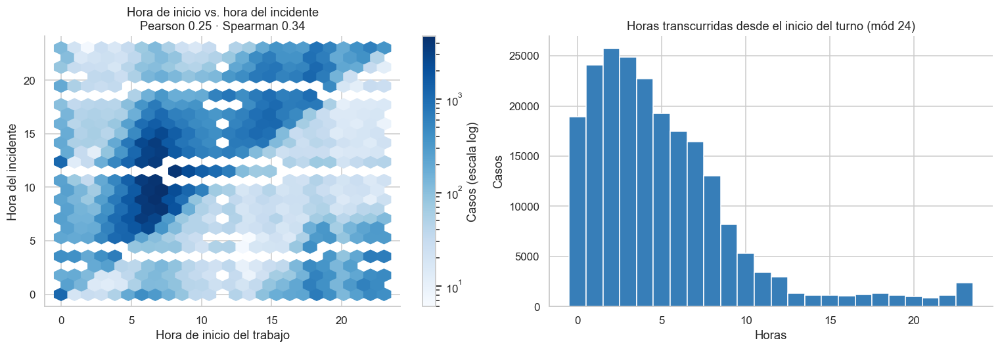

C:\Users\Usuario\miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Usuario\miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


C:\Users\Usuario\miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Usuario\miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


C:\Users\Usuario\miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
C:\Users\Usuario\miniconda3\envs\ml_venv\lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


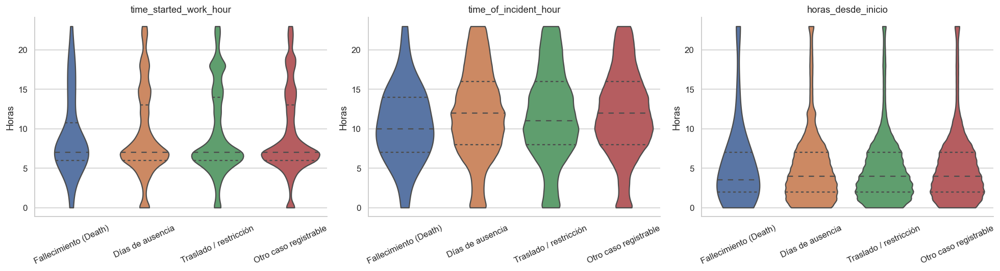

,time_started_work_hour,time_of_incident_hour,horas_desde_inicio
Mediana por resultado,,,
Fallecimiento (Death),7.000,10.000,3.500
Días de ausencia,7.000,12.000,4.000
Traslado / restricción,7.000,11.000,4.000
Otro caso registrable,7.000,12.000,4.000


,Variable,Comparación,n₁,n₂,Biserial por rangos r,p,p Holm,p FDR (BH),Efecto
0,time_started_work_hour,Fallecimiento (Death) vs Días de ausencia,60,86772,-0.011,8.85e-01,1.00e+00,9.75e-01,despreciable
1,time_started_work_hour,Fallecimiento (Death) vs Traslado / restricción,60,71784,0.002,9.75e-01,1.00e+00,9.75e-01,despreciable
2,time_started_work_hour,Fallecimiento (Death) vs Otro caso registrable,60,77885,-0.003,9.72e-01,1.00e+00,9.75e-01,despreciable
3,time_started_work_hour,Días de ausencia vs Traslado / restricción,86772,71784,0.003,3.62e-01,1.00e+00,5.93e-01,despreciable
4,time_started_work_hour,Días de ausencia vs Otro caso registrable,86772,77885,0.002,5.12e-01,1.00e+00,7.68e-01,despreciable
5,time_started_work_hour,Traslado / restricción vs Otro caso registrable,71784,77885,-0.005,1.09e-01,1.00e+00,2.19e-01,despreciable
6,time_of_incident_hour,Fallecimiento (Death) vs Días de ausencia,60,83545,-0.145,5.12e-02,6.14e-01,1.32e-01,pequeño
7,time_of_incident_hour,Fallecimiento (Death) vs Traslado / restricción,60,72065,-0.121,1.05e-01,1.00e+00,2.19e-01,pequeño
8,time_of_incident_hour,Fallecimiento (Death) vs Otro caso registrable,60,77569,-0.154,3.81e-02,4.96e-01,1.14e-01,pequeño
9,time_of_incident_hour,Días de ausencia vs Traslado / restricción,83545,72065,0.021,5.89e-13,8.83e-12,2.65e-12,despreciable


**Interpretación.** Las dos horas tienen una relación moderada (Pearson **0.25**, Spearman **0.34**): la hora del incidente depende del turno, así que aportan información en parte redundante; el hexbin muestra la diagonal de incidentes pocas horas después del inicio. La mediana de horas transcurridas desde el inicio es **4 h**; la distribución puede reflejar tanto la exposición a lo largo de la jornada como horas reportadas de forma aproximada. Frente al resultado, **4 de 18** comparaciones son significativas tras Holm, pero el mayor tamaño de efecto es |r| = 0.154 (time_of_incident_hour: Fallecimiento (Death) vs Otro caso registrable), **despreciable o pequeño**. Las horas transcurridas tienen H de Kruskal–Wallis = 136.6. Las horas no ordenan el resultado de forma monótona, así que tratarlas como categorías en el modelo es más prudente que imponer una pendiente lineal. Las horas transcurridas quedan como candidata de ingeniería de características.

In [14]:
from scipy.stats import mannwhitneyu

hours = feature_view[hour_predictors].apply(pd.to_numeric, errors='coerce')
both_hours = hours.dropna()
pearson_r = both_hours.corr(method='pearson').iloc[0, 1]
spearman_r = both_hours.corr(method='spearman').iloc[0, 1]
elapsed = ((both_hours.time_of_incident_hour - both_hours.time_started_work_hour) % 24).rename('horas_desde_inicio')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
hb = axes[0].hexbin(both_hours.time_started_work_hour, both_hours.time_of_incident_hour, gridsize=24, cmap='Blues', mincnt=1, bins='log')
fig.colorbar(hb, ax=axes[0], label='Casos (escala log)')
axes[0].set(title=f'Hora de inicio vs. hora del incidente\nPearson {pearson_r:.2f} · Spearman {spearman_r:.2f}',
            xlabel='Hora de inicio del trabajo', ylabel='Hora del incidente')
axes[1].hist(elapsed, bins=np.arange(-0.5, 24.5, 1), color='#377eb8')
axes[1].set(title='Horas transcurridas desde el inicio del turno (mód 24)', xlabel='Horas', ylabel='Casos')
plt.tight_layout(); plt.show()

hour_long = (hours.assign(horas_desde_inicio=elapsed, Resultado=train.outcome)
             .melt(id_vars='Resultado', var_name='Variable', value_name='Horas').dropna())
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, hour_predictors + ['horas_desde_inicio']):
    sns.violinplot(data=hour_long[hour_long.Variable.eq(c)], x='Resultado', y='Horas', order=list(OUTCOMES.values()),
                   cut=0, inner='quartile', ax=ax)
    ax.set(title=c, xlabel='')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()
display(pd.concat({c: pd.DataFrame({'h': (elapsed if c == 'horas_desde_inicio' else hours[c]), 'o': train.outcome})
                   .dropna().groupby('o').h.median() for c in hour_predictors + ['horas_desde_inicio']}, axis=1)
        .reindex(OUTCOMES.values()).rename_axis('Mediana por resultado'))

pair_rows = []
for c in hour_predictors + ['horas_desde_inicio']:
    values = elapsed if c == 'horas_desde_inicio' else hours[c].dropna()
    labels = train.loc[values.index, TARGET]
    for i, a in enumerate(sorted(OUTCOMES)):
        for b in sorted(OUTCOMES)[i+1:]:
            xa, xb = values[labels.eq(a)], values[labels.eq(b)]
            U, p = mannwhitneyu(xa, xb, alternative='two-sided')
            pair_rows.append({'Variable': c, 'Comparación': f'{OUTCOMES[a]} vs {OUTCOMES[b]}', 'n₁': len(xa), 'n₂': len(xb),
                              'Biserial por rangos r': 2*U/(len(xa)*len(xb)) - 1, 'p': p})
pairwise_hours = pd.DataFrame(pair_rows)
pairwise_hours['p Holm'] = multipletests(pairwise_hours.p, method='holm')[1]
pairwise_hours['p FDR (BH)'] = multipletests(pairwise_hours.p, method='fdr_bh')[1]
pairwise_hours['Efecto'] = pd.cut(pairwise_hours['Biserial por rangos r'].abs(), [-1, .1, .3, .5, 1], labels=['despreciable', 'pequeño', 'mediano', 'grande'])
display(pairwise_hours.assign(**{k: pairwise_hours[k].map('{:.2e}'.format) for k in ['p', 'p Holm', 'p FDR (BH)']}))

elapsed_kw = kruskal(*[elapsed[train.loc[elapsed.index, TARGET].eq(k)] for k in sorted(OUTCOMES)])
largest = pairwise_hours.loc[pairwise_hours['Biserial por rangos r'].abs().idxmax()]
display(Markdown(
    f"**Interpretación.** Las dos horas tienen una relación moderada (Pearson **{pearson_r:.2f}**, Spearman **{spearman_r:.2f}**): la hora del incidente depende del turno, así que aportan información en parte redundante; el hexbin muestra la diagonal de incidentes pocas horas después del inicio. "
    f"La mediana de horas transcurridas desde el inicio es **{elapsed.median():.0f} h**; la distribución puede reflejar tanto la exposición a lo largo de la jornada como horas reportadas de forma aproximada. "
    f"Frente al resultado, **{int(pairwise_hours['p Holm'].lt(0.05).sum())} de {len(pairwise_hours)}** comparaciones son significativas tras Holm, pero el mayor tamaño de efecto es |r| = {abs(largest['Biserial por rangos r']):.3f} "
    f"({largest['Variable']}: {largest['Comparación']}), **despreciable o pequeño**. Las horas transcurridas tienen H de Kruskal–Wallis = {elapsed_kw.statistic:,.1f}. "
    "Las horas no ordenan el resultado de forma monótona, así que tratarlas como categorías en el modelo es más prudente que imponer una pendiente lineal. Las horas transcurridas quedan como candidata de ingeniería de características."))

#### 8.1.2 Pruebas entre predictores categóricos y multicolinealidad

El heatmap anterior de V de Cramér es la matriz de asociación entre predictores categóricos. Aquí se añaden sus pruebas χ² con corrección de Holm y FDR y el **factor de inflación de varianza generalizado** (GVIF, Fox y Monette, 1992), que extiende el VIF a factores con varios niveles. GVIF^(1/(2·gl)) es comparable con √VIF: valores > √5 ≈ 2,24 indican colinealidad relevante y > √10 ≈ 3,16 severa. Para que los determinantes sean estables se usa una muestra aleatoria de 60.000 casos de desarrollo y la jerarquía agregada de NAICS (sector) y SOC (grupo mayor de dos dígitos). Las horas entran como categorías, igual que en el modelo.

In [15]:
pair_tests = []
for i, a in enumerate(pair_vars):
    for b in pair_vars[i+1:]:
        v, p, dof = cramers_v_bias_corrected(feature_view[a].astype(object).fillna('Desconocido'),
                                             feature_view[b].astype(object).fillna('Desconocido'))
        pair_tests.append({'Predictor A': a, 'Predictor B': b, 'V de Cramér': v, 'gl': dof, 'p': p})
pair_tests = pd.DataFrame(pair_tests)
pair_tests['p Holm'] = multipletests(pair_tests.p, method='holm')[1]
pair_tests['p FDR (BH)'] = multipletests(pair_tests.p, method='fdr_bh')[1]
display(pair_tests.sort_values('V de Cramér', ascending=False)
        .assign(**{k: lambda d, k=k: d[k].map('{:.2e}'.format) for k in ['p', 'p Holm', 'p FDR (BH)']}))

gvif_frame = pd.DataFrame({
    'estado': train.state, 'sector_naics': train.industry_sector_code,
    'tipo_establecimiento': train.establishment_type_label,
    'grupo_soc': train.soc_code.str[:2], 'tipo_incidente': train.incident_type, 'time_unknown': train.time_unknown,
    'hora_inicio': feature_view.time_started_work_hour, 'hora_incidente': feature_view.time_of_incident_hour,
}).sample(n=60000, random_state=42)
blocks, design = {}, []
for factor in gvif_frame:
    levels = gvif_frame[factor].astype(object).where(gvif_frame[factor].notna(), 'Desconocido').astype(str)
    dummies = pd.get_dummies(levels, prefix=factor, drop_first=True, dtype=float)
    dummies = dummies.loc[:, dummies.std() > 0]
    blocks[factor] = list(dummies.columns); design.append(dummies)
design = pd.concat(design, axis=1)
R = np.corrcoef(design.to_numpy(), rowvar=False)
_, logdet_all = np.linalg.slogdet(R)
position = {c: i for i, c in enumerate(design.columns)}
gvif_rows = []
for factor, columns in blocks.items():
    inside = [position[c] for c in columns]
    outside = [i for i in range(len(design.columns)) if i not in set(inside)]
    gvif = np.exp(np.linalg.slogdet(R[np.ix_(inside, inside)])[1] + np.linalg.slogdet(R[np.ix_(outside, outside)])[1] - logdet_all)
    gvif_rows.append({'Factor': factor, 'gl': len(inside), 'GVIF': gvif, 'GVIF^(1/(2·gl))': gvif**(1/(2*len(inside)))})
gvif_table = pd.DataFrame(gvif_rows).sort_values('GVIF^(1/(2·gl))', ascending=False)
display(gvif_table)

top_pair = pair_tests.sort_values('V de Cramér', ascending=False).iloc[0]
top_gvif = gvif_table.iloc[0]
display(Markdown(
    f"**Interpretación.** La asociación más fuerte entre predictores es **{top_pair['Predictor A']}–{top_pair['Predictor B']}** (V = {top_pair['V de Cramér']:.3f}). Todas las pruebas χ² siguen siendo significativas tras Holm y FDR, algo esperable con n grande; lo relevante es la magnitud. "
    "Industria, ocupación y tipo de establecimiento describen el mismo lugar de trabajo desde ángulos distintos. "
    f"En el GVIF, el único factor por encima de √5 es **{top_gvif['Factor']}** ({top_gvif['GVIF^(1/(2·gl))']:.2f}): es una redundancia por construcción, porque `time_unknown = 1` coincide casi siempre con la categoría «hora del incidente desconocida» (5.2.1). "
    "Los demás factores quedan por debajo de 1,2 una vez ajustados por sus grados de libertad, así que las asociaciones entre industria, ocupación y establecimiento no generan colinealidad severa. "
    "En una regresión logística regularizada esta redundancia no sesga las predicciones, pero reparte el efecto entre dos columnas y vuelve inestables sus coeficientes. Por eso la sección 20 interpreta contrastes dentro de un mismo predictor y no se eliminan variables por VIF en el modelo base."))

,Predictor A,Predictor B,V de Cramér,gl,p,p Holm,p FDR (BH)
5,naics_code,establishment_type,0.513,2856,0.00e+00,0.00e+00,0.00e+00
9,establishment_type,soc_code,0.399,2392,0.00e+00,0.00e+00,0.00e+00
8,naics_code,time_unknown,0.306,1428,0.00e+00,0.00e+00,0.00e+00
6,naics_code,soc_code,0.282,426972,0.00e+00,0.00e+00,0.00e+00
7,naics_code,type_of_incident,0.241,3570,0.00e+00,0.00e+00,0.00e+00
14,type_of_incident,time_unknown,0.237,10,0.00e+00,0.00e+00,0.00e+00
0,state,naics_code,0.211,38556,0.00e+00,0.00e+00,0.00e+00
13,soc_code,time_unknown,0.180,1196,0.00e+00,0.00e+00,0.00e+00
1,state,establishment_type,0.155,216,0.00e+00,0.00e+00,0.00e+00
12,soc_code,type_of_incident,0.146,2990,0.00e+00,0.00e+00,0.00e+00


,Factor,gl,GVIF,GVIF^(1/(2·gl))
5,time_unknown,2,209.276,3.803
7,hora_incidente,24,649.986,1.144
1,sector_naics,22,295.413,1.138
2,tipo_establecimiento,3,1.939,1.117
3,grupo_soc,24,177.083,1.114
6,hora_inicio,24,6.135,1.039
4,tipo_incidente,5,1.307,1.027
0,estado,52,2.048,1.007


**Interpretación.** La asociación más fuerte entre predictores es **naics_code–establishment_type** (V = 0.513). Todas las pruebas χ² siguen siendo significativas tras Holm y FDR, algo esperable con n grande; lo relevante es la magnitud. Industria, ocupación y tipo de establecimiento describen el mismo lugar de trabajo desde ángulos distintos. En el GVIF, el único factor por encima de √5 es **time_unknown** (3.80): es una redundancia por construcción, porque `time_unknown = 1` coincide casi siempre con la categoría «hora del incidente desconocida» (5.2.1). Los demás factores quedan por debajo de 1,2 una vez ajustados por sus grados de libertad, así que las asociaciones entre industria, ocupación y establecimiento no generan colinealidad severa. En una regresión logística regularizada esta redundancia no sesga las predicciones, pero reparte el efecto entre dos columnas y vuelve inestables sus coeficientes. Por eso la sección 20 interpreta contrastes dentro de un mismo predictor y no se eliminan variables por VIF en el modelo base.

#### 8.2 Estructura multivariada exploratoria

PCA sobre los códigos NAICS, SOC o estado **no es apropiado**, porque sus números son etiquetas nominales y no magnitudes. Para visualizar una muestra del desarrollo se aplica **TruncatedSVD** a categorías one-hot más horas numéricas imputadas y estandarizadas. Es una representación exploratoria distinta de la del modelo, que codifica también las horas como categorías. Se incluyen todos los fallecimientos y una muestra aleatoria de las demás clases únicamente para hacer visible la clase rara; por tanto, la figura **no representa prevalencias poblacionales** y no se utiliza para seleccionar variables ni para entrenar el modelo.

No se aplica distancia de Mahalanobis sobre los códigos nominales ni se eliminan “outliers multivariados” a partir de distancias arbitrarias en una representación one-hot. Los valores imposibles e inconsistentes se auditan directamente en sus campos originales.


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


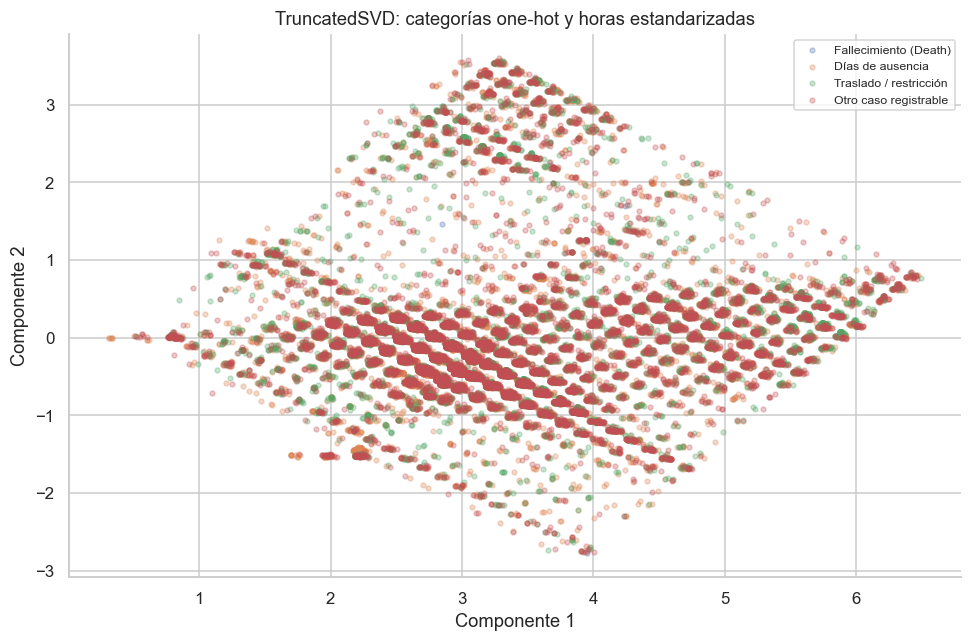

Varianza explicada por los dos componentes: 33.26%
Casos visualizados: 30069 | Death: 69 | otras clases muestreadas: 30000


Los dos componentes explican **33.26 %** de la varianza de esta muestra y representación. Una proyección de dos dimensiones no demuestra separabilidad total, y el sobremuestreo visual de Death impide interpretar densidades como prevalencias.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import TruncatedSVD

death_rows = train.loc[train[TARGET].eq(1)]
nondeath_rows = train.loc[train[TARGET].ne(1)]
nondeath_sample = nondeath_rows.sample(
    n=min(30000, len(nondeath_rows)),
    random_state=42
)
vis = pd.concat([death_rows, nondeath_sample], axis=0)

cat_vis = list(categorical_predictors)
num_vis = list(hour_predictors)
pre_vis = ColumnTransformer(
    transformers=[
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Desconocido')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_vis),
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler(with_mean=False))
        ]), num_vis)
    ],
    sparse_threshold=1.0
)

X_vis = pre_vis.fit_transform(vis[baseline['features']])
svd = TruncatedSVD(n_components=2, random_state=42)
coords = svd.fit_transform(X_vis)

fig, ax = plt.subplots(figsize=(9, 6))
for label in sorted(OUTCOMES):
    mask = vis[TARGET].to_numpy() == label
    ax.scatter(coords[mask, 0], coords[mask, 1], s=10, alpha=0.30, label=OUTCOMES[label])
ax.set(
    title='TruncatedSVD: categorías one-hot y horas estandarizadas',
    xlabel='Componente 1',
    ylabel='Componente 2'
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print('Varianza explicada por los dos componentes:',
      f'{100 * svd.explained_variance_ratio_.sum():.2f}%')
print('Casos visualizados:', len(vis),
      '| Death:', int(vis[TARGET].eq(1).sum()),
      '| otras clases muestreadas:', int(vis[TARGET].ne(1).sum()))

display(Markdown(f'Los dos componentes explican **{100*svd.explained_variance_ratio_.sum():.2f} %** de la varianza de esta muestra y representación. Una proyección de dos dimensiones no demuestra separabilidad total, y el sobremuestreo visual de Death impide interpretar densidades como prevalencias.'))


#### 8.3 Dimensionalidad efectiva, outliers multivariados y subpoblaciones

La figura anterior sobremuestrea Death para hacerlo visible. Aquí se usa una **muestra aleatoria simple** de 40.000 casos de desarrollo, con las prevalencias reales. Sobre la misma representación (one-hot + horas estandarizadas) se calcula:

1. La **varianza explicada acumulada** de TruncatedSVD (el análogo de PCA para matrices dispersas sin centrar), para estimar la dimensionalidad efectiva.
2. Los **outliers multivariados** con Isolation Forest y con la distancia de Mahalanobis, ambos sobre los 10 primeros componentes. En ese espacio continuo la distancia tiene sentido; sobre los códigos nominales crudos no lo tendría.
3. Un **clustering exploratorio** con K-means (k = 2…8, elegido por silueta sobre una submuestra de 2.000 casos).

Nada de esto elimina filas ni crea predictores: el análisis es descriptivo.

C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


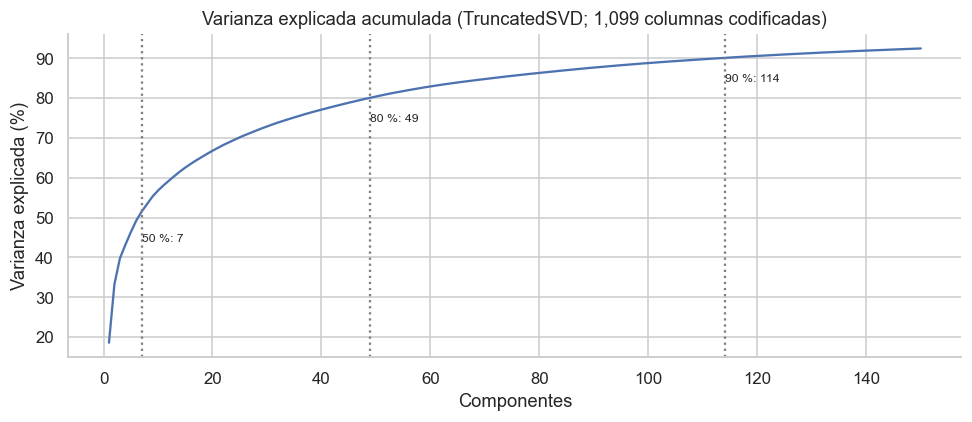

,Valor
Casos analizados,"40,000.000"
Atípicos Isolation Forest (%),16.755
Atípicos Mahalanobis (%),1.232
Coincidencia (Jaccard),0.068


,Muestra completa,Atípicos Isolation Forest,"Atípicos Mahalanobis (χ² 0,999)"
Composición del resultado (%),,,
Fallecimiento (Death),0.015,0.015,0.000
Días de ausencia,37.043,40.078,48.479
Traslado / restricción,29.550,31.990,29.209
Otro caso registrable,33.393,27.917,22.312


,Muestra completa,Atípicos Isolation Forest
Tipo de incidente (%),,
Lesión,89.763,72.038
Otra enfermedad,4.410,15.592
Afección respiratoria,3.962,9.549
Pérdida auditiva,1.357,1.895
Trastorno cutáneo,0.420,0.806
Intoxicación,0.088,0.119


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


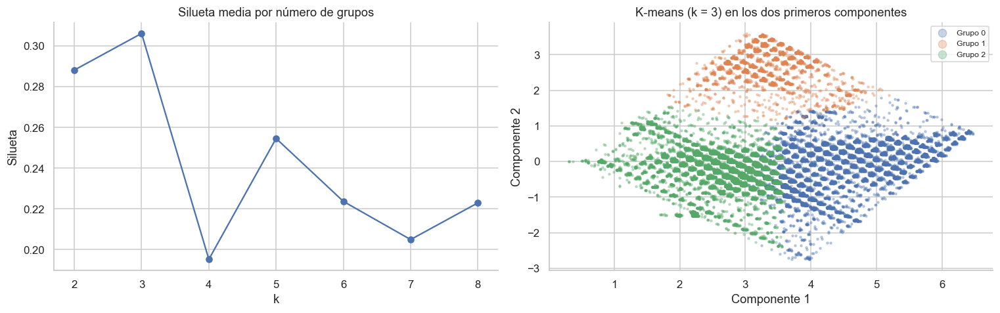

,Casos,Fallecimiento (Death),Días de ausencia,Traslado / restricción,Otro caso registrable,Sector dominante,Tipo de incidente dominante,Tipo de establecimiento dominante
Grupo,,,,,,,,
0,12465,0.016,37.673,29.458,32.852,Transporte / almacenamiento,Lesión,Sector privado
1,2715,0.037,35.138,34.733,30.092,Transporte / almacenamiento,Lesión,Sector privado
2,24820,0.012,36.934,29.029,34.025,Salud / asistencia social,Lesión,Sector privado


**Interpretación.** La información está muy dispersa: 10 componentes explican 56.8 % de la varianza y hacen falta 49 componentes para el 80 %. La **dimensionalidad efectiva es alta** porque NAICS, SOC y estado aportan cientos de indicadores casi ortogonales, y la reducción lineal no concentra la señal en pocos ejes. Isolation Forest marca 16.8 % de los casos y Mahalanobis 1.2 %. Los atípicos sobrerrepresentan enfermedades no traumáticas (sobre todo «otra enfermedad» y afecciones respiratorias) y tienen más días de ausencia y menos «otro caso registrable» que la muestra: son **subpoblaciones legítimas, no errores**, así que no se eliminan. Los dos criterios coinciden poco (Jaccard bajo), señal de que no existe un grupo nítido de registros anómalos. El clustering elige k = 3 (silueta 0.31). Los grupos se distinguen sobre todo por el sector dominante (Transporte / almacenamiento, Transporte / almacenamiento, Salud / asistencia social), y su asociación con el resultado es V = 0.022: son estructura del lugar de trabajo, no clases del objetivo separables.

In [17]:
from sklearn.base import clone
from sklearn.ensemble import IsolationForest
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from scipy.stats import chi2 as chi2_distribution

mv_sample = train.sample(n=40000, random_state=42)
X_mv = clone(pre_vis).fit_transform(mv_sample[baseline['features']])
svd_mv = TruncatedSVD(n_components=150, random_state=42).fit(X_mv)
cumulative = np.cumsum(svd_mv.explained_variance_ratio_)
needed = {share: (int(np.argmax(cumulative >= share)) + 1 if cumulative[-1] >= share else None) for share in [.5, .8, .9]}
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(cumulative) + 1), 100*cumulative)
for share, k in needed.items():
    if k: ax.axvline(k, linestyle=':', color='gray'); ax.text(k, 100*share - 6, f'{int(100*share)} %: {k}', fontsize=8)
ax.set(title=f'Varianza explicada acumulada (TruncatedSVD; {X_mv.shape[1]:,} columnas codificadas)', xlabel='Componentes', ylabel='Varianza explicada (%)')
plt.tight_layout(); plt.show()

Z = svd_mv.transform(X_mv)[:, :10]
del X_mv
isolation = IsolationForest(n_estimators=200, contamination='auto', random_state=42).fit(Z)
is_outlier_if = isolation.predict(Z) == -1
Zc = Z - Z.mean(axis=0)
d2 = np.einsum('ij,jk,ik->i', Zc, np.linalg.pinv(np.cov(Z, rowvar=False)), Zc)
is_outlier_md = d2 > chi2_distribution.ppf(0.999, df=Z.shape[1])
outcome_mix = pd.DataFrame({
    'Muestra completa': mv_sample.outcome.value_counts(normalize=True),
    'Atípicos Isolation Forest': mv_sample.outcome[is_outlier_if].value_counts(normalize=True),
    'Atípicos Mahalanobis (χ² 0,999)': mv_sample.outcome[is_outlier_md].value_counts(normalize=True),
}).reindex(OUTCOMES.values()).fillna(0).mul(100)
display(pd.Series({'Casos analizados': len(Z), 'Atípicos Isolation Forest (%)': 100*is_outlier_if.mean(),
                   'Atípicos Mahalanobis (%)': 100*is_outlier_md.mean(),
                   'Coincidencia (Jaccard)': (is_outlier_if & is_outlier_md).sum() / max(1, (is_outlier_if | is_outlier_md).sum())}, name='value').to_frame())
display(outcome_mix.rename_axis('Composición del resultado (%)'))
display(pd.DataFrame({'Muestra completa': mv_sample.incident_type.value_counts(normalize=True),
                      'Atípicos Isolation Forest': mv_sample.incident_type[is_outlier_if].value_counts(normalize=True)})
        .fillna(0).mul(100).rename_axis('Tipo de incidente (%)'))

silhouette_rows, cluster_models = [], {}
silhouette_index = np.random.default_rng(42).choice(len(Z), size=2000, replace=False)
for k in range(2, 9):
    km = MiniBatchKMeans(n_clusters=k, random_state=42, n_init=5, batch_size=4096).fit(Z)
    cluster_models[k] = km
    silhouette_rows.append({'k': k, 'Silueta (2.000 casos)': silhouette_score(Z[silhouette_index], km.labels_[silhouette_index])})
silhouettes = pd.DataFrame(silhouette_rows)
best_k = int(silhouettes.loc[silhouettes['Silueta (2.000 casos)'].idxmax(), 'k'])
clusters = pd.Series(cluster_models[best_k].labels_, index=mv_sample.index, name='Grupo')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(silhouettes.k, silhouettes['Silueta (2.000 casos)'], 'o-')
axes[0].set(title='Silueta media por número de grupos', xlabel='k', ylabel='Silueta')
for g in range(best_k):
    m = clusters.eq(g).to_numpy()
    axes[1].scatter(Z[m, 0], Z[m, 1], s=4, alpha=.3, label=f'Grupo {g}')
axes[1].set(title=f'K-means (k = {best_k}) en los dos primeros componentes', xlabel='Componente 1', ylabel='Componente 2')
axes[1].legend(markerscale=4, fontsize=8)
plt.tight_layout(); plt.show()
profile = pd.concat([
    clusters.value_counts().sort_index().rename('Casos'),
    pd.crosstab(clusters, mv_sample.outcome, normalize='index').reindex(columns=OUTCOMES.values()).mul(100),
    mv_sample.groupby(clusters).industry_sector.agg(lambda s: s.value_counts().index[0]).rename('Sector dominante'),
    mv_sample.groupby(clusters).incident_type.agg(lambda s: s.value_counts().index[0]).rename('Tipo de incidente dominante'),
    mv_sample.groupby(clusters).establishment_type_label.agg(lambda s: s.value_counts().index[0]).rename('Tipo de establecimiento dominante'),
], axis=1)
display(profile)
cluster_v, _, _ = cramers_v_bias_corrected(clusters.astype(str), mv_sample[TARGET])
display(Markdown(
    f"**Interpretación.** La información está muy dispersa: 10 componentes explican {100*cumulative[9]:.1f} % de la varianza y hacen falta "
    + (f"{needed[.8]} componentes para el 80 %" if needed[.8] else f"más de 150 componentes para el 80 % (150 explican {100*cumulative[-1]:.1f} %)")
    + ". La **dimensionalidad efectiva es alta** porque NAICS, SOC y estado aportan cientos de indicadores casi ortogonales, y la reducción lineal no concentra la señal en pocos ejes. "
    f"Isolation Forest marca {100*is_outlier_if.mean():.1f} % de los casos y Mahalanobis {100*is_outlier_md.mean():.1f} %. Los atípicos sobrerrepresentan enfermedades no traumáticas "
    "(sobre todo «otra enfermedad» y afecciones respiratorias) y tienen más días de ausencia y menos «otro caso registrable» que la muestra: son **subpoblaciones legítimas, no errores**, así que no se eliminan. Los dos criterios coinciden poco (Jaccard bajo), señal de que no existe un grupo nítido de registros anómalos. "
    f"El clustering elige k = {best_k} (silueta {silhouettes['Silueta (2.000 casos)'].max():.2f}). Los grupos se distinguen sobre todo por el sector dominante ({', '.join(profile['Sector dominante'].astype(str))}), "
    f"y su asociación con el resultado es V = {cluster_v:.3f}: son estructura del lugar de trabajo, no clases del objetivo separables."))

### 9. Patrones temporales y precisión del registro


#### Validación de la variable temporal

Antes de describir patrones se valida `date_of_incident`: formato, fechas no interpretables, cobertura, zona horaria, frecuencia, marcas repetidas y huecos. Las cifras de fechas fuera de 2023 provienen del inventario completo; las demás se calculan sobre el desarrollo.

In [18]:
development_calendar = pd.date_range('2023-01-01', train.incident_date.max().normalize(), freq='D')
cases_by_day = train.groupby(train.incident_date.dt.normalize()).size().reindex(development_calendar, fill_value=0)
raw_time = train.time_of_incident.dropna()
parsable_time_pct = 100*raw_time.str.match(r'^\d{1,2}:\d{2}').mean()
time_validation = pd.Series({
    'Formato de fecha': 'MM/DD/AAAA, sin hora ni zona horaria',
    'Fechas no interpretables en desarrollo': int(train.incident_date.isna().sum()),
    'Fechas de incidente fuera de 2023 (archivo completo, excluidas)': int(screening['outside_2023']),
    'Rango de fechas del desarrollo': f"{train.incident_date.min().date()} a {train.incident_date.max().date()}",
    'Días del calendario de desarrollo': len(development_calendar),
    'Días sin ningún caso (huecos)': int(cases_by_day.eq(0).sum()),
    'Casos por día: mínimo / mediana / máximo': f"{cases_by_day.min()} / {cases_by_day.median():.0f} / {cases_by_day.max()}",
    'Frecuencia': 'Eventos irregulares (varios casos por día); se agrega a serie diaria regular',
    'Zona horaria de las horas': 'No documentada; se asume hora local del establecimiento',
    'Horas con formato HH:MM:SS interpretable (%)': f"{parsable_time_pct:.2f}",
    'Marcas fecha+hora repetidas dentro de un mismo establecimiento': int(train.dropna(subset=['time_of_incident']).duplicated([GROUP, 'date_of_incident', 'time_of_incident']).sum()),
}, name='value').to_frame()
display(time_validation)
display(Markdown(f"**Interpretación.** No hay fechas no interpretables en el desarrollo y {'no hay' if cases_by_day.eq(0).sum() == 0 else 'hay'} días sin casos: la serie diaria agregada es regular y completa entre el 1 de enero y el corte con purga. "
                 "Las fechas fuera de 2023 se excluyen porque pertenecen a otros años de reporte. La zona horaria no está documentada, así que las horas se tratan como hora local y solo se usan a resolución horaria. "
                 "Las marcas fecha+hora repetidas dentro de un establecimiento pueden ser varios trabajadores lesionados en un mismo evento; no se eliminan (sección 11)."))

,Valor
Formato de fecha,"MM/DD/AAAA, sin hora ni zona horaria"
Fechas no interpretables en desarrollo,0
"Fechas de incidente fuera de 2023 (archivo completo, excluidas)",562
Rango de fechas del desarrollo,2023-01-01 a 2023-09-23
Días del calendario de desarrollo,266
Días sin ningún caso (huecos),0
Casos por día: mínimo / mediana / máximo,443 / 1134 / 1371
Frecuencia,Eventos irregulares (varios casos por día); se...
Zona horaria de las horas,No documentada; se asume hora local del establ...
Horas con formato HH:MM:SS interpretable (%),100.00


**Interpretación.** No hay fechas no interpretables en el desarrollo y no hay días sin casos: la serie diaria agregada es regular y completa entre el 1 de enero y el corte con purga. Las fechas fuera de 2023 se excluyen porque pertenecen a otros años de reporte. La zona horaria no está documentada, así que las horas se tratan como hora local y solo se usan a resolución horaria. Las marcas fecha+hora repetidas dentro de un establecimiento pueden ser varios trabajadores lesionados en un mismo evento; no se eliminan (sección 11).

,Fallecimiento (Death),Días de ausencia,Traslado / restricción,Otro caso registrable,Total de casos
incident_date,,,,,
1,9,12806,8741,9642,31198
2,10,11343,8299,9312,28964
3,7,11638,9515,10417,31577
4,10,10224,8367,9561,28162
5,3,10720,9230,10533,30486
6,5,10708,9487,10473,30673
7,7,11267,9510,10707,31491
8,11,12427,9907,11399,33744
9,7,8564,6792,7858,23221


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


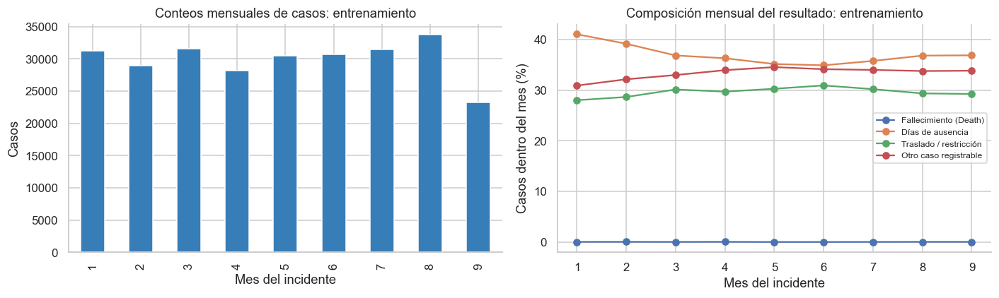

C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


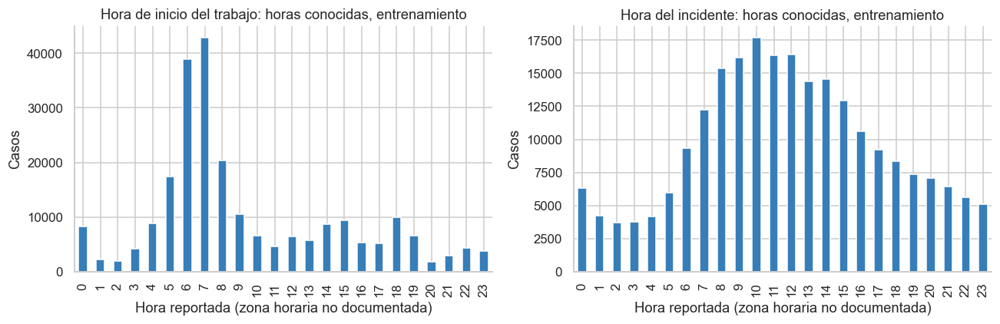

,Registros originales presentes,Minutos iguales a 00,Hora desconocida o no utilizable
time_started_work,236501,149440,33015
time_of_incident,235611,81089,36277


In [19]:
monthly = pd.crosstab(train.incident_date.dt.month, train[TARGET]).reindex(index=range(1,10), columns=list(OUTCOMES), fill_value=0)
monthly.columns = list(OUTCOMES.values())
display(monthly.assign(total_cases=monthly.sum(axis=1)))
fig, axes = plt.subplots(1,2,figsize=(13,4))
monthly.sum(axis=1).plot.bar(ax=axes[0],color='#377eb8')
axes[0].set(title='Conteos mensuales de casos: entrenamiento',xlabel='Mes del incidente',ylabel='Casos')
monthly.div(monthly.sum(axis=1),axis=0).mul(100).plot(ax=axes[1],marker='o')
axes[1].set(title='Composición mensual del resultado: entrenamiento',xlabel='Mes del incidente',ylabel='Casos dentro del mes (%)',xticks=range(1,10))
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax,c,label in zip(axes,['time_started_work_hour','time_of_incident_hour'],['Hora de inicio del trabajo','Hora del incidente']):
    counts = train[c].value_counts().reindex(range(24),fill_value=0)
    counts.plot.bar(ax=ax,color='#377eb8')
    ax.set(title=label+': horas conocidas, entrenamiento',xlabel='Hora reportada (zona horaria no documentada)',ylabel='Casos')
plt.tight_layout(); plt.show()
time_audit = {}
for c in ['time_started_work','time_of_incident']:
    raw = train[c].dropna()
    time_audit[c] = {'nonmissing_raw':len(raw), 'minutes_equal_00':int(raw.str.match(r'^\d{1,2}:00:').sum()),
                     'unusable_or_unknown_hour':int(train[c+'_hour'].isna().sum())}
display(pd.DataFrame(time_audit).T)


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


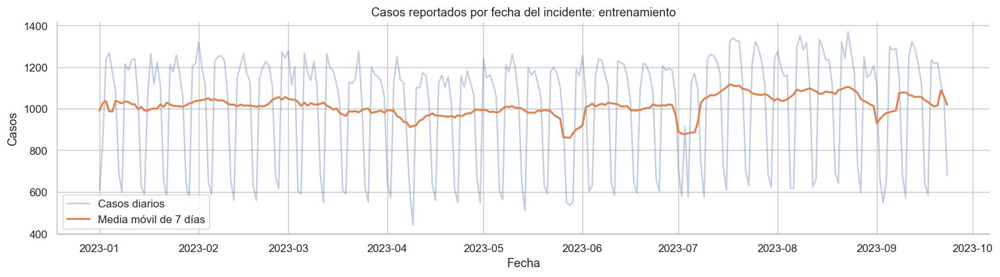

,Fallecimiento (Death),Días de ausencia,Traslado / restricción,Otro caso registrable,Total
Lunes,14,16542,13272,14269,44097
Martes,12,16558,13825,15319,45714
Miércoles,10,16724,14088,15485,46307
Jueves,8,16316,13747,15244,45315
Viernes,13,15064,11946,14145,41168
Sábado,10,9791,6853,8164,24818
Domingo,2,8702,6117,7276,22097


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


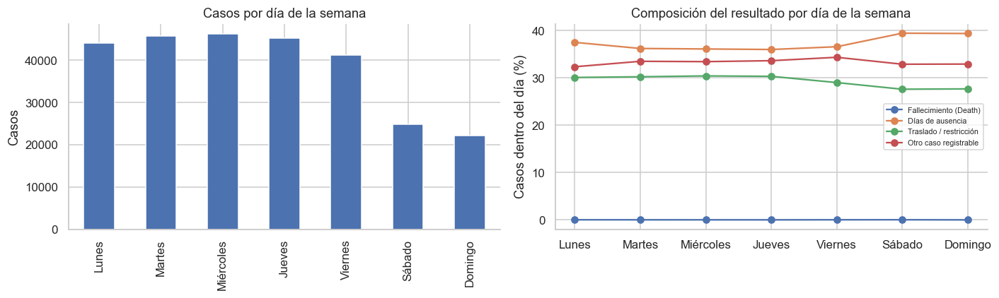

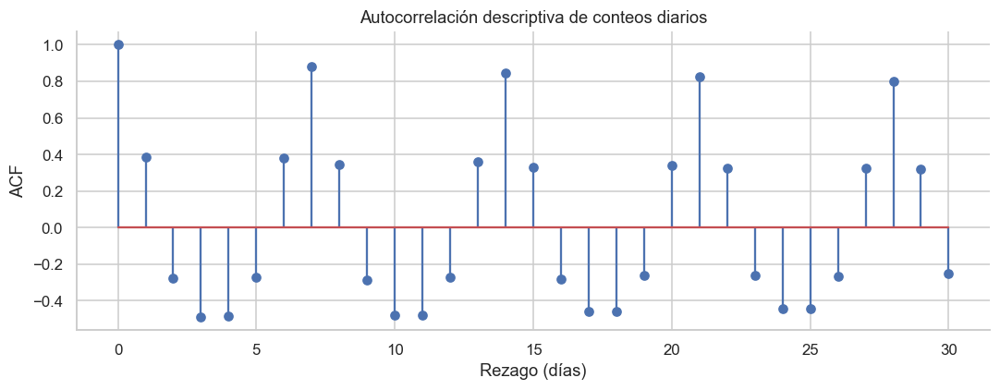

C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


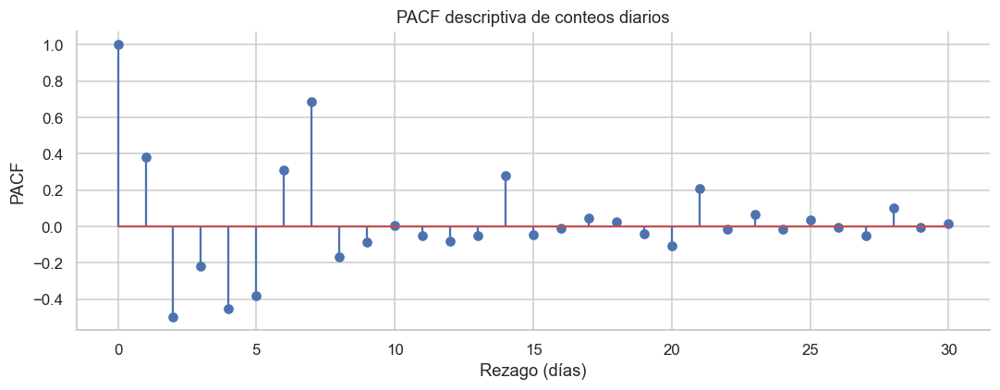

C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\1053994415.py:69: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


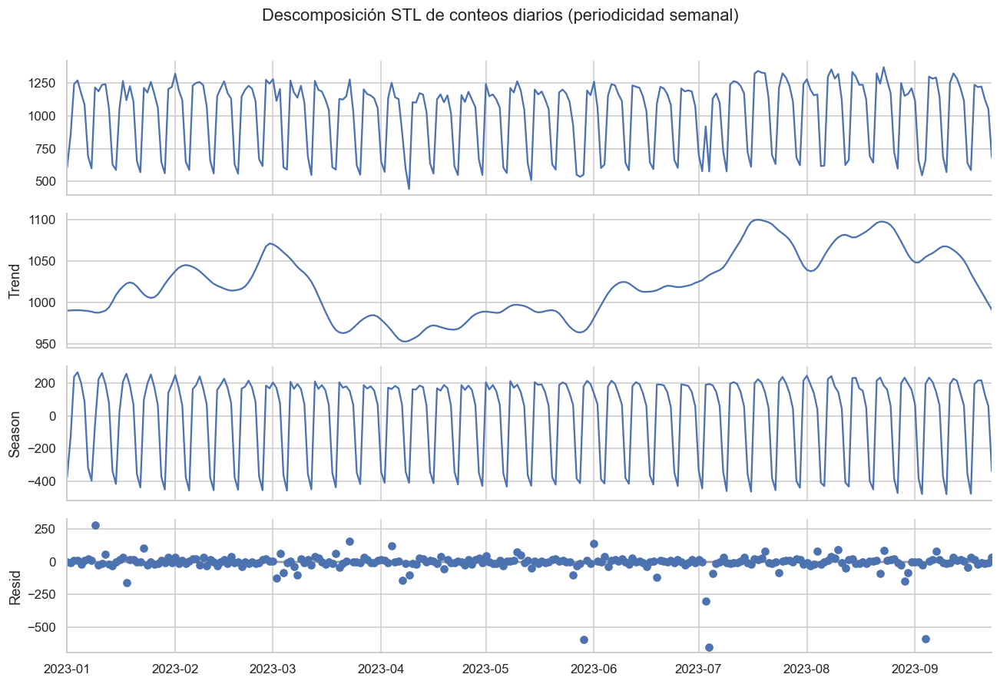

,Prueba,Estadístico,p-valor,Hipótesis nula
0,ADF,-2.529,0.109,raíz unitaria / no estacionaria
1,KPSS,0.226,> 0.10,estacionaria


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


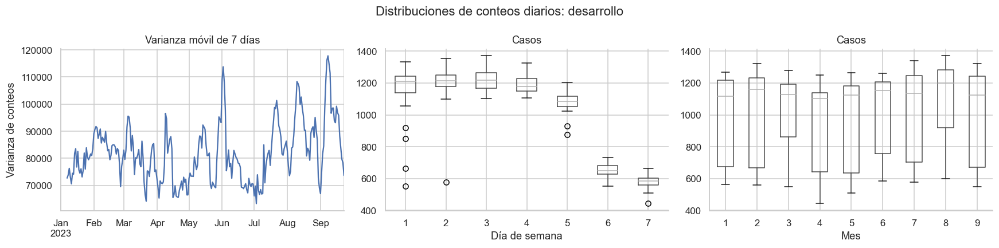

,Rezago (días),Días utilizables,Correlación: proporción manufactura t-k / ausencia t,Correlación tras centrar por día semanal
0,0,266,-0.475,-0.174
1,1,265,-0.270,-0.095
2,7,259,-0.449,-0.036
3,14,252,-0.451,-0.026


Casos diarios                     Desviación respecto al día semanal  \
          Media Desviación estándar                              Media   
1     1,006.387             266.763                             -3.776   
2     1,034.429             274.412                             21.211   
3     1,018.613             258.046                             -9.277   
4       938.733             264.345                            -48.090   
5       983.419             272.917                            -47.295   
6     1,022.433             252.392                              0.901   
7     1,015.839             290.048                             23.414   
8     1,088.516             272.261                             56.767   
9     1,009.609             292.284                              8.998   

                       
  Desviación estándar  
1              69.589  
2              35.337  
3              58.075  
4              48.821  
5             114.242  
6              33.702  
7             140.635  
8              62.965  
9             119.743

El mayor contraste descriptivo entre ventanas consecutivas de 28 días aparece en **2023-07-07**, con diferencia **96.9 casos/día** tras centrar por día semanal. Es un máximo exploratorio, no una prueba de cambio estructural; no se usa para cambiar el corte.

,Rango entre trimestres de proporción del volumen propio,Rango entre trimestres de proporción de ausencia
Conteo,"1,325.000","1,325.000"
Media,0.182,0.196
Desviación estándar,0.129,0.142
Mínimo,0.000,0.000
25%,0.094,0.091
50%,0.155,0.167
75%,0.229,0.267
90%,0.333,0.385
Máximo,0.892,1.000


Heterogeneidad: **1,325 establecimientos** con ≥30 casos de desarrollo y presencia en los tres trimestres, criterio descriptivo fijado antes del cálculo. No se publican sus identidades. Las correlaciones agregadas no prueban relaciones individuales ni capacidad predictiva. El calendario se describe por semana y mes; no se atribuyen cambios a festivos, políticas o exposición sin datos externos.

ADF p = 0.109 (no rechaza raíz unitaria); KPSS p > 0.10 (no rechaza estacionariedad). Son nulas diferentes: el resultado es inconcluso (ninguna prueba rechaza su nula). La cota de KPSS procede de su tabla, no de una probabilidad exacta. Con un solo año y un patrón semanal fuerte, estas pruebas describen la serie agregada de reportes y no justifican por sí solas una transformación.

La correlación agregada manufactura–ausencia a siete días pasa de **-0.449** a **-0.036** al centrar por día semanal: gran parte de esa asociación coincide con el calendario, sin probar causalidad. Entre los **1,325 establecimientos** elegibles, la mediana del rango trimestral de proporción de ausencia es **0.167** (16.7 puntos porcentuales). Los volúmenes y composiciones cambian dentro de las entidades; no basta con considerar cada caso independiente. Estos diagnósticos describen el desarrollo y no se convierten en predictores ni cambian el corte.

In [20]:
# El desarrollo termina antes de la purga de siete días: esos días no son días con cero casos.
calendar = pd.date_range('2023-01-01', train.incident_date.max().normalize(), freq='D')
daily_cases = (
    train.groupby(train.incident_date.dt.normalize())
    .size()
    .reindex(calendar, fill_value=0)
)
rolling7 = daily_cases.rolling(7, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily_cases.index, daily_cases.values, alpha=0.35, label='Casos diarios')
ax.plot(rolling7.index, rolling7.values, linewidth=2, label='Media móvil de 7 días')
ax.set(title='Casos reportados por fecha del incidente: entrenamiento',
       xlabel='Fecha', ylabel='Casos')
ax.legend()
plt.tight_layout()
plt.show()

weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday_es = {
    'Monday':'Lunes','Tuesday':'Martes','Wednesday':'Miércoles',
    'Thursday':'Jueves','Friday':'Viernes','Saturday':'Sábado','Sunday':'Domingo'
}
weekday = pd.crosstab(train.incident_date.dt.day_name(), train[TARGET]).reindex(weekday_order)
weekday.columns = [OUTCOMES[c] for c in weekday.columns]
weekday.index = [weekday_es[d] for d in weekday.index]
display(weekday.assign(Total=weekday.sum(axis=1)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
weekday.sum(axis=1).plot.bar(ax=axes[0])
axes[0].set(title='Casos por día de la semana', xlabel='', ylabel='Casos')
weekday.div(weekday.sum(axis=1), axis=0).mul(100).plot(ax=axes[1], marker='o')
axes[1].set(title='Composición del resultado por día de la semana',
            xlabel='', ylabel='Casos dentro del día (%)')
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

x = daily_cases.to_numpy(dtype=float)
x_centered = x - x.mean()
denom = np.dot(x_centered, x_centered)
max_lag = 30
acf_vals = [1.0]
for lag in range(1, max_lag + 1):
    acf_vals.append(
        np.dot(x_centered[:-lag], x_centered[lag:]) / denom if denom else np.nan
    )

fig, ax = plt.subplots(figsize=(10, 4))
ax.stem(range(max_lag + 1), acf_vals)
ax.set(title='Autocorrelación descriptiva de conteos diarios',
       xlabel='Rezago (días)', ylabel='ACF')
plt.tight_layout()
plt.show()

try:
    from statsmodels.tsa.seasonal import STL
    from statsmodels.tsa.stattools import adfuller, kpss, pacf

    pacf_values=pacf(daily_cases.astype(float),nlags=30,method='ywm')
    fig,ax=plt.subplots(figsize=(10,4))
    ax.stem(range(31),pacf_values)
    ax.set(title='PACF descriptiva de conteos diarios',xlabel='Rezago (días)',ylabel='PACF')
    plt.tight_layout();plt.show()
    stl = STL(daily_cases.astype(float), period=7, robust=True).fit()
    fig = stl.plot()
    fig.set_size_inches(12, 8)
    fig.suptitle('Descomposición STL de conteos diarios (periodicidad semanal)', y=1.01)
    plt.tight_layout()
    plt.show()

    adf_stat, adf_p, *_ = adfuller(daily_cases.astype(float), autolag='AIC')
    import warnings
    with warnings.catch_warnings(record=True) as kpss_warnings:
        warnings.simplefilter('always')
        kpss_stat, kpss_p, *_ = kpss(daily_cases.astype(float), regression='c', nlags='auto')
    kpss_label = '> 0.10' if kpss_p == .1 and kpss_warnings else f'{kpss_p:.3f}'
    display(pd.DataFrame({
        'Prueba': ['ADF', 'KPSS'],
        'Estadístico': [adf_stat, kpss_stat],
        'p-valor': [f'{adf_p:.3f}', kpss_label],
        'Hipótesis nula': ['raíz unitaria / no estacionaria', 'estacionaria']
    }))
except ImportError:
    raise RuntimeError('statsmodels requerido para completar el EDA temporal')
except Exception as exc:
    raise RuntimeError('Fallo en diagnósticos temporales') from exc

from osha_review_checks import temporal_supplement
temporal_extra = temporal_supplement(train, display, plt, Markdown)
adf_reject, kpss_reject = adf_p < 0.05, kpss_p < 0.05
stationarity_reading = {
    (True, False): 'ambas pruebas son compatibles con una serie estacionaria alrededor de un nivel',
    (False, False): 'el resultado es inconcluso (ninguna prueba rechaza su nula)',
    (True, True): 'las señales son mixtas, compatibles con estacionariedad alrededor de cambios de nivel o tendencia',
    (False, True): 'ambas pruebas apuntan a no estacionariedad',
}[(adf_reject, kpss_reject)]
display(Markdown(f'ADF p = {adf_p:.3f} ({"rechaza" if adf_reject else "no rechaza"} raíz unitaria); KPSS p {kpss_label} ({"rechaza" if kpss_reject else "no rechaza"} estacionariedad). Son nulas diferentes: {stationarity_reading}. La cota de KPSS procede de su tabla, no de una probabilidad exacta. Con un solo año y un patrón semanal fuerte, estas pruebas describen la serie agregada de reportes y no justifican por sí solas una transformación.'))

lag7 = temporal_extra['lags'].set_index('Rezago (días)').loc[7]
away_range = temporal_extra['heterogeneity']['Rango entre trimestres de proporción de ausencia']
display(Markdown(f"La correlación agregada manufactura–ausencia a siete días pasa de **{lag7['Correlación: proporción manufactura t-k / ausencia t']:.3f}** a **{lag7['Correlación tras centrar por día semanal']:.3f}** al centrar por día semanal: gran parte de esa asociación coincide con el calendario, sin probar causalidad. Entre los **{temporal_extra['selected_establishments']:,} establecimientos** elegibles, la mediana del rango trimestral de proporción de ausencia es **{away_range.median():.3f}** ({100*away_range.median():.1f} puntos porcentuales). Los volúmenes y composiciones cambian dentro de las entidades; no basta con considerar cada caso independiente. Estos diagnósticos describen el desarrollo y no se convierten en predictores ni cambian el corte."))


**Componente temporal:** los conteos diarios describen el flujo de reportes de incidentes de múltiples establecimientos, no una serie de riesgo individual. STL/ADF/KPSS, cuando disponibles, son diagnósticos agregados. El modelo se evalúa cronológicamente; las etiquetas no tienen una fecha histórica de disponibilidad verificada.

**Alcance de validación:** desarrollo hasta el 23 de septiembre y prueba octubre–diciembre en establecimientos reservados, sin cruce de grupos. La validación interna avanza en el tiempo, separa grupos y usa una purga fija de siete días, motivada por la dependencia temporal de los reportes y fijada antes de los nuevos ajustes. Los 39 fallecimientos de la prueba permiten calcular métricas, pero la sensibilidad de esa clase seguirá siendo imprecisa.

La partición responde a generalización temporal a establecimientos no utilizados para ajustar el modelo. Los casos de esos establecimientos en enero–septiembre y los casos Q4 de establecimientos de desarrollo quedan fuera del ajuste y de la prueba principal. No hay una reconstrucción de disponibilidad histórica de las etiquetas o los predictores.


#### 9.1 Efectos de calendario y deriva del objetivo

El enunciado pide revisar los efectos de calendario (feriados) y la deriva (*covariate shift* y *concept drift*). Los feriados federales de EE. UU. se toman del calendario de `pandas`, sin datos externos. Cada feriado se compara con la media de los días no feriados del **mismo día de la semana**, para no confundir el efecto feriado con el patrón semanal. La deriva del objetivo se mide con la distancia de variación total (TVD) entre trimestres del desarrollo. El *concept drift* se aproxima comparando la distribución condicional del resultado dentro de los mismos grupos de predictores (sector y tipo de incidente) entre T1 y T3. La deriva de los predictores (*covariate shift*) se reporta en la sección 22.

,Fecha,Feriado,Día,Casos,Media del mismo día no feriado,Razón feriado / referencia
0,2023-01-02,New Year's Day,Lunes,851,"1,210.469",0.703
1,2023-01-16,"Birthday of Martin Luther King, Jr.",Lunes,1056,"1,210.469",0.872
2,2023-02-20,Washington's Birthday,Lunes,1146,"1,210.469",0.947
3,2023-05-29,Memorial Day,Lunes,553,"1,210.469",0.457
4,2023-06-19,Juneteenth National Independence Day,Lunes,1091,"1,210.469",0.901
5,2023-07-04,Independence Day,Martes,577,"1,219.919",0.473
6,2023-09-04,Labor Day,Lunes,665,"1,210.469",0.549


Resultado,Fallecimiento (Death),Días de ausencia,Traslado / restricción,Otro caso registrable,Casos
Trimestre (desarrollo),,,,,
T1,0.028,39.010,28.946,32.016,91739
T2,0.020,35.436,30.322,34.222,89321
T3,0.028,36.468,29.629,33.874,88456


,Comparación,TVD del resultado
0,T1 vs T2,0.036
1,T2 vs T3,0.010
2,T1 vs T3,0.025


,Agrupación,Grupo,Casos T1,Casos T3,TVD P(resultado | grupo) T1 vs T3,Días de ausencia T1 (%),Días de ausencia T3 (%)
0,Sector,Salud / asistencia social,25434,23120,0.036,39.601,36.016
1,Sector,Transporte / almacenamiento,18951,18981,0.035,46.710,43.259
2,Sector,Comercio minorista,17104,16572,0.031,38.248,36.308
3,Sector,Manufactura,17014,16146,0.028,30.863,29.178
4,Sector,Comercio mayorista,3891,3846,0.018,42.251,40.458
5,Tipo de incidente,Lesión,80750,78956,0.011,35.817,34.689
6,Tipo de incidente,Otra enfermedad,4005,4084,0.071,37.253,32.762
7,Tipo de incidente,Afección respiratoria,5200,3516,0.026,94.000,91.439


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


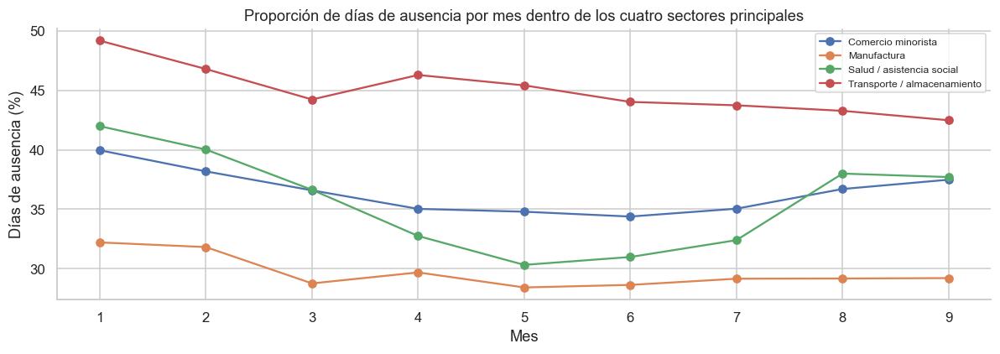

**Interpretación.** Los feriados reducen claramente el número de reportes: la razón media feriado/referencia es **0.70** (mínimo 0.46, Memorial Day). Es un efecto de volumen (menos gente trabajando), no necesariamente del tipo de desenlace. La composición del resultado apenas cambia entre trimestres (TVD máxima 0.036; V trimestre–resultado 0.022), y la deriva condicional dentro de sectores y tipos de incidente es de magnitud similar (TVD mediana 0.029; máxima 0.071). No hay evidencia de un *concept drift* fuerte dentro de 2023, aunque sí de cambios pequeños que justifican la validación hacia adelante y no una partición aleatoria. Los días de ausencia pueden seguir acumulándose después del reporte, así que los casos más recientes podrían estar registrados con menos gravedad. Esta posible deriva por maduración de la etiqueta no puede verificarse sin versiones históricas del archivo.

In [21]:
from pandas.tseries.holiday import USFederalHolidayCalendar

development_end = train.incident_date.max().normalize()
daily_development = train.groupby(train.incident_date.dt.normalize()).size().reindex(
    pd.date_range('2023-01-01', development_end, freq='D'), fill_value=0)
holidays = USFederalHolidayCalendar().holidays('2023-01-01', development_end, return_name=True)
weekday_reference = daily_development.drop(holidays.index).groupby(lambda d: d.dayofweek).mean()
holiday_table = pd.DataFrame([{
    'Fecha': day.date(), 'Feriado': name, 'Día': weekday_es[day.day_name()], 'Casos': int(daily_development.loc[day]),
    'Media del mismo día no feriado': weekday_reference.loc[day.dayofweek],
    'Razón feriado / referencia': daily_development.loc[day] / weekday_reference.loc[day.dayofweek]} for day, name in holidays.items()])
display(holiday_table)

quarter_label = 'T' + train.incident_date.dt.quarter.astype(str)
quarter_mix = pd.crosstab(quarter_label, train.outcome, normalize='index').reindex(columns=OUTCOMES.values()).mul(100)
display(quarter_mix.assign(Casos=quarter_label.value_counts().sort_index()).rename_axis('Trimestre (desarrollo)'))
def total_variation(p, q):
    return 0.5*np.abs(np.asarray(p) - np.asarray(q)).sum()
target_drift = pd.DataFrame([{'Comparación': f'{a} vs {b}', 'TVD del resultado': total_variation(quarter_mix.loc[a]/100, quarter_mix.loc[b]/100)}
                             for a, b in [('T1', 'T2'), ('T2', 'T3'), ('T1', 'T3')]])
quarter_v, quarter_p, _ = cramers_v_bias_corrected(quarter_label, train[TARGET])
display(target_drift)

conditional_rows = []
for field, label, levels in [('industry_sector', 'Sector', train.industry_sector.value_counts().head(5).index),
                             ('incident_type', 'Tipo de incidente', ['Lesión', 'Otra enfermedad', 'Afección respiratoria'])]:
    for level in levels:
        subset = train[train[field].eq(level)]
        q = subset.incident_date.dt.quarter
        d1 = subset.loc[q.eq(1), TARGET].value_counts(normalize=True).reindex(list(OUTCOMES), fill_value=0)
        d3 = subset.loc[q.eq(3), TARGET].value_counts(normalize=True).reindex(list(OUTCOMES), fill_value=0)
        conditional_rows.append({'Agrupación': label, 'Grupo': level, 'Casos T1': int(q.eq(1).sum()), 'Casos T3': int(q.eq(3).sum()),
                                 'TVD P(resultado | grupo) T1 vs T3': total_variation(d1, d3),
                                 'Días de ausencia T1 (%)': 100*d1[2], 'Días de ausencia T3 (%)': 100*d3[2]})
conditional_drift = pd.DataFrame(conditional_rows)
display(conditional_drift)

fig, ax = plt.subplots(figsize=(11, 4))
top_sector_cases = train[train.industry_sector.isin(train.industry_sector.value_counts().head(4).index)]
monthly_away = (top_sector_cases.groupby([top_sector_cases.incident_date.dt.month, 'industry_sector'])[TARGET]
                .apply(lambda s: 100*s.eq(2).mean()).unstack())
monthly_away.plot(ax=ax, marker='o')
ax.set(title='Proporción de días de ausencia por mes dentro de los cuatro sectores principales', xlabel='Mes', ylabel='Días de ausencia (%)')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

display(Markdown(
    f"**Interpretación.** Los feriados reducen claramente el número de reportes: la razón media feriado/referencia es **{holiday_table['Razón feriado / referencia'].mean():.2f}** "
    f"(mínimo {holiday_table['Razón feriado / referencia'].min():.2f}, {holiday_table.loc[holiday_table['Razón feriado / referencia'].idxmin(), 'Feriado']}). "
    "Es un efecto de volumen (menos gente trabajando), no necesariamente del tipo de desenlace. "
    f"La composición del resultado apenas cambia entre trimestres (TVD máxima {target_drift['TVD del resultado'].max():.3f}; V trimestre–resultado {quarter_v:.3f}), "
    f"y la deriva condicional dentro de sectores y tipos de incidente es de magnitud similar (TVD mediana {conditional_drift['TVD P(resultado | grupo) T1 vs T3'].median():.3f}; máxima {conditional_drift['TVD P(resultado | grupo) T1 vs T3'].max():.3f}). "
    "No hay evidencia de un *concept drift* fuerte dentro de 2023, aunque sí de cambios pequeños que justifican la validación hacia adelante y no una partición aleatoria. "
    "Los días de ausencia pueden seguir acumulándose después del reporte, así que los casos más recientes podrían estar registrados con menos gravedad. Esta posible deriva por maduración de la etiqueta no puede verificarse sin versiones históricas del archivo."))

#### 9.2 Componente geográfico

El archivo no contiene latitud ni longitud. La única referencia espacial utilizable como predictor es el **estado**; ZIP y ciudad se excluyen por riesgo de reidentificación. Por eso las secciones 2.7–2.8 del enunciado (CRS, I de Moran, LISA, variogramas, bloques espaciales) no son aplicables: requieren coordenadas o polígonos, y geocodificar direcciones de empresas aumentaría el riesgo ético sin responder a la pregunta del proyecto. Sí se evalúa la **heterogeneidad espacial** entre estados, con intervalos de Wilson, y su consecuencia para la validación.

C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


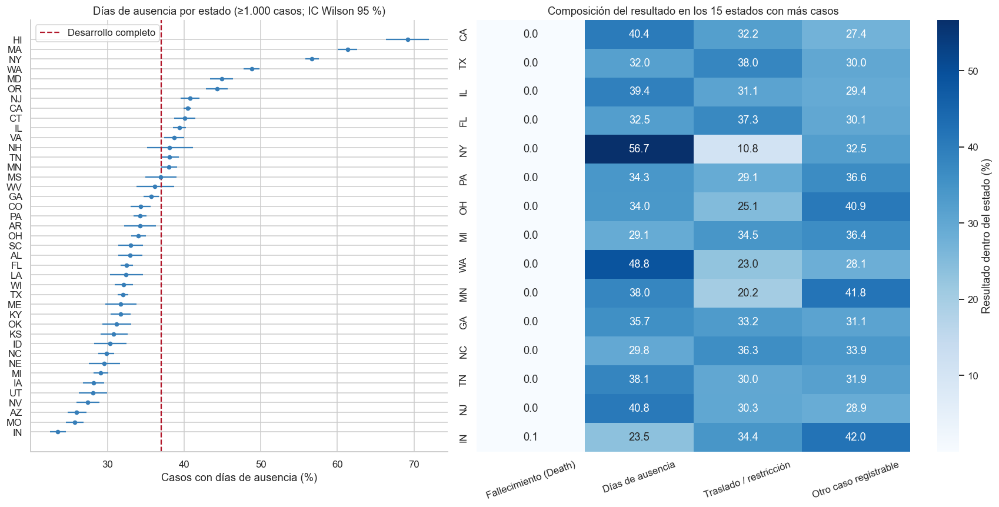

,Casos,Establecimientos,Días de ausencia (%),IC95 inferior,IC95 superior
state,,,,,
CA,35858,3330,40.429,39.922,40.938
TX,17717,2342,32.048,31.365,32.739
IL,13177,1585,39.379,38.548,40.216
FL,13145,1802,32.522,31.726,33.328
NY,12483,1289,56.685,55.814,57.552
PA,11955,1521,34.262,33.416,35.117
OH,9592,1470,34.039,33.097,34.993
MI,8858,1290,29.115,28.178,30.070
WA,8693,860,48.809,47.759,49.860


**Interpretación.** Entre los 41 estados con al menos 1.000 casos, la proporción de días de ausencia va de **23.5 %** a **69.2 %**, una heterogeneidad mucho mayor que la amplitud de los intervalos. Esta es la señal espacial que captura el predictor `state` (V de Cramér en 8.1). Los intervalos de Wilson tratan los casos como independientes; con casos agrupados por establecimiento son demasiado estrechos, así que las diferencias entre estados cercanos no deben sobreinterpretarse. Pueden reflejar composición industrial, normativa estatal de compensación laboral y prácticas de reporte, no riesgo geográfico. **Consecuencia para el modelado:** el objetivo es generalizar a **establecimientos** y **periodos** nuevos, no a estados no vistos; el estado se codifica con `handle_unknown='ignore'`, así que un estado ausente del entrenamiento no rompe la predicción. La partición por establecimiento es la unidad de bloqueo adecuada; si el objetivo fuera predecir en estados nuevos, se usaría `GroupKFold` por estado. El problema de la unidad de área modificable (MAUP) aplica: con otra agregación (condado, ZIP) los contrastes cambiarían.

In [22]:
state_outcomes = pd.crosstab(train.state, train[TARGET]).reindex(columns=list(OUTCOMES), fill_value=0)
state_n = state_outcomes.sum(axis=1)
large_states = state_outcomes[state_n.ge(1000)]
n_s, k_s = large_states.sum(axis=1), large_states[2]
z = 1.959963984540054
phat = k_s/n_s; den = 1 + z**2/n_s
center = (phat + z**2/(2*n_s))/den
half = z*np.sqrt(phat*(1-phat)/n_s + z**2/(4*n_s**2))/den
state_away = pd.DataFrame({'Casos': n_s, 'Establecimientos': train.groupby('state')[GROUP].nunique().reindex(n_s.index),
                           'Días de ausencia (%)': 100*phat, 'IC95 inferior': 100*(center-half), 'IC95 superior': 100*(center+half)}).sort_values('Días de ausencia (%)')
fig, axes = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={'width_ratios': [1, 1.3]})
axes[0].errorbar(state_away['Días de ausencia (%)'], range(len(state_away)),
                 xerr=[state_away['Días de ausencia (%)']-state_away['IC95 inferior'], state_away['IC95 superior']-state_away['Días de ausencia (%)']],
                 fmt='o', markersize=4, color='#377eb8')
axes[0].axvline(100*train[TARGET].eq(2).mean(), color='#b2182b', linestyle='--', label='Desarrollo completo')
axes[0].set_yticks(range(len(state_away)), state_away.index)
axes[0].set(title='Días de ausencia por estado (≥1.000 casos; IC Wilson 95 %)', xlabel='Casos con días de ausencia (%)')
axes[0].legend()
top_states = state_n.sort_values(ascending=False).head(15).index
sns.heatmap(state_outcomes.loc[top_states].div(state_n.loc[top_states], axis=0).mul(100).rename(columns=OUTCOMES),
            annot=True, fmt='.1f', cmap='Blues', ax=axes[1], cbar_kws={'label': 'Resultado dentro del estado (%)'})
axes[1].set(title='Composición del resultado en los 15 estados con más casos', xlabel='', ylabel='')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()
display(state_away.sort_values('Casos', ascending=False).head(15))
display(Markdown(
    f"**Interpretación.** Entre los {len(state_away)} estados con al menos 1.000 casos, la proporción de días de ausencia va de **{state_away['Días de ausencia (%)'].min():.1f} %** a **{state_away['Días de ausencia (%)'].max():.1f} %**, "
    "una heterogeneidad mucho mayor que la amplitud de los intervalos. Esta es la señal espacial que captura el predictor `state` (V de Cramér en 8.1). "
    "Los intervalos de Wilson tratan los casos como independientes; con casos agrupados por establecimiento son demasiado estrechos, así que las diferencias entre estados cercanos no deben sobreinterpretarse. "
    "Pueden reflejar composición industrial, normativa estatal de compensación laboral y prácticas de reporte, no riesgo geográfico. "
    "**Consecuencia para el modelado:** el objetivo es generalizar a **establecimientos** y **periodos** nuevos, no a estados no vistos; el estado se codifica con `handle_unknown='ignore'`, así que un estado ausente del entrenamiento no rompe la predicción. "
    "La partición por establecimiento es la unidad de bloqueo adecuada; si el objetivo fuera predecir en estados nuevos, se usaría `GroupKFold` por estado. "
    "El problema de la unidad de área modificable (MAUP) aplica: con otra agregación (condado, ZIP) los contrastes cambiarían."))

### 10. Agrupación por establecimiento y medidas descriptivas del lugar de trabajo


,Casos reportados
Conteo,"34,029.000"
Media,7.920
Desviación estándar,26.678
Mínimo,1.000
50%,3.000
90%,15.000
95%,25.000
99%,74.000
Máximo,"2,249.000"


Los 100 establecimientos con más casos concentran 12.19% del entrenamiento.


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


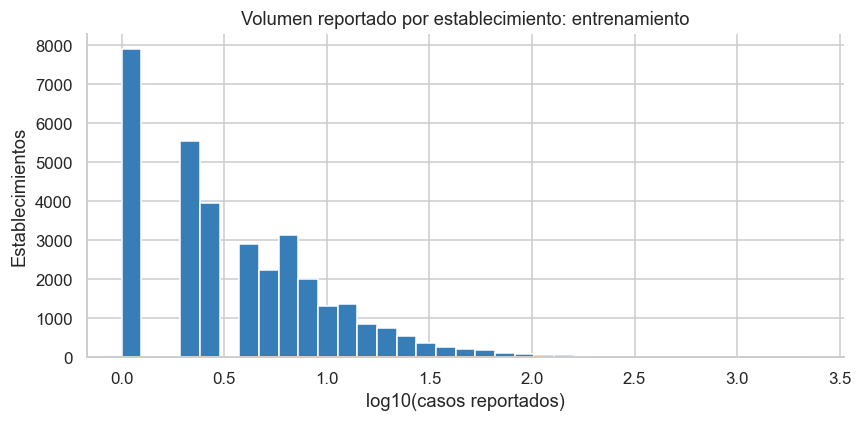

,Conteo,Media,Desviación estándar,Mínimo,50%,90%,99%,Máximo
Casos,"34,029.000",7.920,26.678,1.000,3.000,15.000,74.000,"2,249.000"
Resultados distintos,"34,029.000",1.845,0.788,1.000,2.000,3.000,3.000,4.000
Proporción del resultado más frecuente,"34,029.000",0.766,0.219,0.250,0.750,1.000,1.000,1.000


,Establecimientos con valores inconsistentes
annual_average_employees,0
total_hours_worked,0
size,0


,Conteo,Media,Desviación estándar,Mínimo,25%,50%,75%,Máximo
annual_average_employees,"34,029.000",260.143,"1,996.273",0.000,62.000,125.000,222.000,"218,234.000"
total_hours_worked,"34,029.000","622,645.468","15,383,901.407",0.000,"101,923.000","197,041.000","370,322.000","2,595,152,024.000"


,Conteo
Establecimientos con empleados <= 0,6
Establecimientos con horas <= 0,13


La mediana es **3 casos** por establecimiento; el máximo es **2,249**. Los 100 mayores concentran **12.19 %**. Los casos no son observaciones independientes: se informa solapamiento y se remuestrean establecimientos completos.

In [23]:
cases_per_establishment = train.groupby(GROUP).size().rename('reported_cases')
display(cases_per_establishment.describe(percentiles=[.5,.9,.95,.99]).to_frame())
largest_share = 100*cases_per_establishment.nlargest(100).sum()/len(train)
print(f'Los 100 establecimientos con más casos concentran {largest_share:.2f}% del entrenamiento.')
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(np.log10(cases_per_establishment),bins=35,color='#377eb8')
ax.set(title='Volumen reportado por establecimiento: entrenamiento',xlabel='log10(casos reportados)',ylabel='Establecimientos')
plt.tight_layout(); plt.show()
establishment_outcomes = pd.crosstab(train[GROUP],train[TARGET]).reindex(columns=list(OUTCOMES),fill_value=0)
cluster_summary = pd.DataFrame({'cases':establishment_outcomes.sum(axis=1),
                                'distinct_outcomes':establishment_outcomes.gt(0).sum(axis=1),
                                'largest_outcome_share':establishment_outcomes.max(axis=1)/establishment_outcomes.sum(axis=1)})
display(cluster_summary.describe(percentiles=[.5,.9,.99]).T)
establishment_fields = ['annual_average_employees','total_hours_worked','size']
inconsistent = train.groupby(GROUP)[establishment_fields].nunique(dropna=False).gt(1).sum()
display(inconsistent.rename('establishments_with_inconsistent_values').to_frame())
establishments = train.drop_duplicates(GROUP).set_index(GROUP)
display(eda.numeric_summary(establishments,['annual_average_employees','total_hours_worked']))
display(pd.Series({
    'Establecimientos con empleados <= 0':int(establishments.annual_average_employees.le(0).sum()),
    'Establecimientos con horas <= 0':int(establishments.total_hours_worked.le(0).sum())
},name='count').to_frame())

display(Markdown(f'La mediana es **{cases_per_establishment.median():.0f} casos** por establecimiento; el máximo es **{cases_per_establishment.max():,}**. Los 100 mayores concentran **{largest_share:.2f} %**. Los casos no son observaciones independientes: se informa solapamiento y se remuestrean establecimientos completos.'))


Los totales anuales se resumen una sola vez por establecimiento; no se suman las copias presentes en cada caso. Si existieran inconsistencias internas, el uso del primer registro requeriría revisión. Estas variables siguen excluidas como predictores porque pueden incorporar información posterior al incidente. No hay identificador de trabajador para detectar casos recurrentes de una misma persona. Establecimientos distintos también pueden pertenecer a una misma empresa.



### 11. Auditoría de claves de caso y coherencia del resultado en desarrollo


In [24]:
reused = train.duplicated([GROUP,'case_number'],keep=False)
reused_groups = train.loc[reused].groupby([GROUP,'case_number'],dropna=False)
death_dates = pd.to_datetime(train.date_of_death,format='%m/%d/%Y',errors='coerce')
checks = {
    'Números de caso faltantes':int(train.case_number.isna().sum()),
    'Identificadores ITA duplicados':int(train.id.duplicated().sum()),
    'Filas con clave establecimiento/número de caso repetida':int(reused.sum()),
    'Claves repetidas con varias fechas de incidente':int(reused_groups.incident_date.nunique().gt(1).sum()),
    'Claves repetidas con varios resultados':int(reused_groups[TARGET].nunique().gt(1).sum()),
    'Resultado de ausencia con días de ausencia <= 0':int((train[TARGET].eq(2)&train.dafw_num_away.le(0)).sum()),
    'Resultado de traslado/restricción con días de restricción <= 0':int((train[TARGET].eq(3)&train.djtr_num_tr.le(0)).sum()),
    'Otro caso registrable con días de ausencia/restricción positivos':int((train[TARGET].eq(4)&(train.dafw_num_away.gt(0)|train.djtr_num_tr.gt(0))).sum()),
    'Casos no mortales con fecha de fallecimiento':int((train[TARGET].ne(1)&train.date_of_death.notna()).sum()),
    'Fallecimientos sin fecha de fallecimiento':int((train[TARGET].eq(1)&train.date_of_death.isna()).sum()),
    'Fecha de fallecimiento anterior al incidente':int((death_dates<train.incident_date).sum()),
    'Fechas de fallecimiento presentes no interpretables':int((train.date_of_death.notna()&death_dates.isna()).sum()),
    'Días de ausencia/restricción negativos':int((train.dafw_num_away.lt(0)|train.djtr_num_tr.lt(0)).sum())
}
display(pd.Series(checks,name='cases_or_groups').to_frame())
leakage_audit = pd.crosstab(train.outcome, [train.dafw_num_away.gt(0), train.djtr_num_tr.gt(0)])
leakage_audit.columns.names = ['Días de ausencia positivos','Días de restricción positivos']
display(leakage_audit.reindex(OUTCOMES.values()))

display(Markdown('Las discrepancias entre días y categoría registrada son alertas de calidad. No permiten saber qué campo es erróneo, por lo que se conserva el objetivo y se excluyen días como predictores. Repetir el número de caso no demuestra duplicación, especialmente cuando cambian fecha o desenlace.'))

display(train.establishment_type.fillna('Faltante').value_counts().rename('Casos por código de establecimiento').to_frame())
display(Markdown(f'El código de establecimiento **0 ({int(train.establishment_type.eq("0").sum())} casos de desarrollo)** no está definido en el diccionario consultado, que documenta 1–3. Se marca semánticamente como **no documentado**, pero se conserva como categoría literal 0 en el modelo ya fijado. No se presupone que signifique privado ni se fusiona silenciosamente con faltantes.'))



,Casos o grupos
Números de caso faltantes,6
Identificadores ITA duplicados,0
Filas con clave establecimiento/número de caso repetida,25173
Claves repetidas con varias fechas de incidente,3228
Claves repetidas con varios resultados,2299
Resultado de ausencia con días de ausencia <= 0,623
Resultado de traslado/restricción con días de restricción <= 0,366
Otro caso registrable con días de ausencia/restricción positivos,424
Casos no mortales con fecha de fallecimiento,0
Fallecimientos sin fecha de fallecimiento,0


Días de ausencia positivos     False         True        
Días de restricción positivos  False  True   False  True 
Resultado                                                
Fallecimiento (Death)             59      0     10      0
Días de ausencia                 337    286  70119  28955
Traslado / restricción           312  79226     54    256
Otro caso registrable          89478    249    128     47

Las discrepancias entre días y categoría registrada son alertas de calidad. No permiten saber qué campo es erróneo, por lo que se conserva el objetivo y se excluyen días como predictores. Repetir el número de caso no demuestra duplicación, especialmente cuando cambian fecha o desenlace.

,Casos por código de establecimiento
establishment_type,
1,252547
2,8743
3,7676
Faltante,307
0,243


El código de establecimiento **0 (243 casos de desarrollo)** no está definido en el diccionario consultado, que documenta 1–3. Se marca semánticamente como **no documentado**, pero se conserva como categoría literal 0 en el modelo ya fijado. No se presupone que signifique privado ni se fusiona silenciosamente con faltantes.

El número de caso del empleador no constituye una clave fiable para deduplicar: puede repetirse en fechas y resultados distintos. Las coincidencias tras eliminar identificadores administrativos son sospechosas, pero también pueden surgir por anonimización o descripciones generales idénticas. No se deduplican ni se cambian etiquetas silenciosamente. Las discrepancias entre resultado y días son alertas de calidad, no autorización para reconstruir el objetivo usando información filtrada. La partición temporal no impide coincidencias de contenido entre periodos. No se dispone de una clave fiable de caso más allá del ID ITA; esta incertidumbre se declara y las claves repetidas no se eliminan automáticamente.



#### 11.1 Entidades relacionadas entre desarrollo y prueba

La separación primaria es por **establecimiento**, pero varios establecimientos pueden pertenecer a la misma empresa (mismo EIN o razón social) y compartir prácticas de registro. Aquí se cuantifica cuántos casos de prueba pertenecen a empresas que también tienen establecimientos en el desarrollo. Los identificadores se usan solo para este conteo agregado: no se muestran ni entran al modelo. La sección 18.1 evalúa si el desempeño difiere en ese subconjunto.

In [25]:
link = pd.read_csv(DATA_PATH, usecols=['id', GROUP, 'ein', 'company_name', 'date_of_incident'], dtype=str, encoding='latin1')
link['date'] = pd.to_datetime(link.date_of_incident, format='%m/%d/%Y', errors='coerce')
link = link.loc[link.date.dt.year.eq(2023)]
development_link = link.loc[link.id.isin(set(train.id))]
test_link = link.loc[link[GROUP].isin(heldout_group_ids) & link.date.ge(cutoff)]
assert len(development_link) == len(train) and len(test_link) == holdout_rows

def normalized_key(values):
    key = values.fillna('').str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)
    return key.where(key.str.len().gt(0))
def valid_ein(values):
    key = normalized_key(values)
    ok = key.str.fullmatch(r'\d{9}').fillna(False).astype(bool) & ~key.str.fullmatch(r'(\d)\1{8}').fillna(False).astype(bool)
    return key.where(ok)

entity_rows = []
for label, builder, column in [('EIN válido (9 dígitos)', valid_ein, 'ein'), ('Razón social normalizada', normalized_key, 'company_name')]:
    development_keys = set(builder(development_link[column]).dropna())
    test_keys = builder(test_link[column])
    shared = test_keys.isin(development_keys).to_numpy()
    entity_rows.append({'Clave de empresa': label, 'Casos de prueba con clave': int(test_keys.notna().sum()),
                        'Casos de prueba cuya empresa está en desarrollo': int(shared.sum()),
                        '% de casos de prueba': 100*shared.mean(),
                        'Establecimientos de prueba afectados': int(test_link.loc[shared, GROUP].nunique()),
                        '% de establecimientos de prueba': 100*test_link.loc[shared, GROUP].nunique()/test_link[GROUP].nunique(),
                        '% de casos de prueba en las 5 empresas compartidas más grandes': 100*test_keys[shared].value_counts().head(5).sum()/len(test_link)})
    if column == 'ein':
        test_shared_firm = pd.Series(shared, index=test_link.id.to_numpy())
entity_overlap = pd.DataFrame(entity_rows)
display(entity_overlap)
ein_row = entity_overlap.iloc[0]
display(Markdown(
    f"**Interpretación.** Aunque ningún establecimiento está en ambas particiones, **{ein_row['% de casos de prueba']:.1f} %** de los casos de prueba ({ein_row['% de establecimientos de prueba']:.1f} % de sus establecimientos) "
    f"pertenecen a una empresa (EIN) con otros establecimientos en el desarrollo, y las cinco mayores concentran {ein_row['% de casos de prueba en las 5 empresas compartidas más grandes']:.1f} % de la prueba. "
    "Es consecuencia de empresas con muchos establecimientos distribuidos entre ambas particiones. No es fuga directa, porque ningún caso ni lugar se repite, pero sí una **dependencia a nivel empresa** "
    "que puede hacer la prueba algo optimista si la empresa determina cómo se clasifican los desenlaces. La partición no se cambia, porque el protocolo se fijó antes de ver resultados; "
    "la sensibilidad se reporta en 18.1 y una partición por EIN queda como variante para el siguiente entregable."))
del link, development_link, test_link

,Clave de empresa,Casos de prueba con clave,Casos de prueba cuya empresa está en desarrollo,% de casos de prueba,Establecimientos de prueba afectados,% de establecimientos de prueba,% de casos de prueba en las 5 empresas compartidas más grandes
0,EIN válido (9 dígitos),110095,66332,52.070,17811,52.106,16.201
1,Razón social normalizada,120075,70775,55.557,18794,54.982,16.371


**Interpretación.** Aunque ningún establecimiento está en ambas particiones, **52.1 %** de los casos de prueba (52.1 % de sus establecimientos) pertenecen a una empresa (EIN) con otros establecimientos en el desarrollo, y las cinco mayores concentran 16.2 % de la prueba. Es consecuencia de empresas con muchos establecimientos distribuidos entre ambas particiones. No es fuga directa, porque ningún caso ni lugar se repite, pero sí una **dependencia a nivel empresa** que puede hacer la prueba algo optimista si la empresa determina cómo se clasifican los desenlaces. La partición no se cambia, porque el protocolo se fijó antes de ver resultados; la sensibilidad se reporta en 18.1 y una partición por EIN queda como variante para el siguiente entregable.

#### 11.2 Referencia preliminar histórica: resultados conservados

La evaluación preliminar utilizó imputación constante y codificación one-hot aprendidas solo en entrenamiento, seguidas de `LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)`. Se conserva su advertencia y sus resultados como registro histórico; **no son el ajuste numéricamente corregido** presentado después. No se vuelve a ejecutar este modelo histórico.


In [26]:
display(pd.DataFrame({
    'logistic_regression':[baseline['balanced_accuracy'],baseline['accuracy'],baseline['macro_f1']],
    'constant_reference':[baseline['constant_classifier_balanced_accuracy_reference'],baseline['majority_accuracy_reference'],np.nan]
},index=['Exactitud balanceada','Exactitud','F1 macro']))
display(pd.DataFrame(baseline['confusion_matrix'],index=[f'Observado: {OUTCOMES[c]}' for c in baseline['confusion_matrix_labels']],
                     columns=[f'Predicho: {OUTCOMES[c]}' for c in baseline['confusion_matrix_labels']]))
print('Iteraciones registradas:',baseline['iterations'])
print('Advertencias históricas del cribado:', len(baseline['warnings']))
if baseline['warnings']:
    print('ConvergenceWarning: lbfgs alcanzó el límite de 1.000 iteraciones sin converger. Se conserva la advertencia del cribado; el ajuste corregido (newton-cg) se presenta más adelante.')
display(pd.DataFrame({OUTCOMES[int(c)]:v for c,v in baseline['classification_report'].items() if c in ['1','2','3','4']}).T)


,LogisticRegression histórico,Referencia constante
Exactitud balanceada,0.419,0.250
Exactitud,0.480,0.366
F1 macro,0.374,NaN


,Predicho: Fallecimiento (Death),Predicho: Días de ausencia,Predicho: Traslado / restricción,Predicho: Otro caso registrable
Observado: Fallecimiento (Death),15,15,15,23
Observado: Días de ausencia,6008,23717,18743,17041
Observado: Traslado / restricción,4760,8155,28231,11899
Observado: Otro caso registrable,4197,8774,13483,33875


Iteraciones registradas: [1000]
Advertencias históricas del cribado: 1


,Precisión,Sensibilidad,F1,Casos
Fallecimiento (Death),0.001,0.221,0.002,68.000
Días de ausencia,0.583,0.362,0.447,"65,509.000"
Traslado / restricción,0.467,0.532,0.497,"53,045.000"
Otro caso registrable,0.539,0.562,0.550,"60,329.000"


### 12. Síntesis del EDA y continuidad

| Hallazgo | Implicación | Decisión aplicada |
|---|---|---|
| Death es extremadamente infrecuente | Exactitud global oculta errores de la clase rara | Conservar cuatro clases; informar métricas por clase, soporte e incertidumbre; no cambiar umbrales |
| Días de ausencia/restricción y fecha de muerte revelan desenlace | Fuga directa si se usan como predictores | Excluirlos del modelo; usarlos solo para auditoría |
| SOC fue codificado retrospectivamente | No hay prueba de disponibilidad al ocurrir el incidente | Formular clasificación retrospectiva; no alerta temprana |
| NAICS, SOC y horas presentan faltantes/códigos especiales | Cero y faltante no son universalmente equivalentes | Mantener reglas documentadas e imputación constante dentro del pipeline |
| Códigos nominales y horas requieren decisiones distintas según propósito | Distancias sobre identificadores no son magnitudes | One-hot en modelo; SVD exploratorio con horas estandarizadas claramente separado |
| Casos concentrados y repetidos dentro de establecimientos | Filas dependientes y posible optimismo al reutilizar entidades | Separar empresas en desarrollo, validación y prueba; bootstrap por establecimiento |
| Patrón semanal, cambios de composición y dependencia de errores | Estabilidad temporal y precisión de intervalos no garantizadas | Validación hacia adelante con purga de siete días; EDA temporal solo de desarrollo |
| Números de caso repetidos no identifican inequívocamente duplicados | Deduplicar por clave puede eliminar incidentes reales | Auditoría de ID, clave y contenido; conservar datos y documentar incertidumbre |
| Asociación categórica no demuestra causalidad ni fuga por sí sola | Significancia clásica no resuelve dependencia | Priorizar tamaños de asociación y disponibilidad; no seleccionar predictores por p-valores |
| Archivo de casos reportados con cobertura selectiva y sin población expuesta | No estima riesgo de lesión ni describe a todos los trabajadores | Limitar conclusiones a resultados entre casos publicados; no clasificar empleadores como peligrosos |
| Faltantes de SOC y horas no son MCAR: dependen de sector/establecimiento y se agrupan por empresa (5.2.1) | Imputar la moda o eliminar filas sesgaría hacia empleadores que codifican mejor | Categoría explícita `Unknown` dentro del Pipeline |
| Horas cíclicas, casi independientes del resultado; categorías raras abundantes en NAICS/SOC (5.1.1, 8.1.1) | Una relación lineal hora–resultado no está justificada; las categorías raras tienen coeficientes inestables | Horas como categorías; regularización L2; agrupación jerárquica y horas transcurridas como candidatas para el siguiente entregable |
| Asociación fuerte entre industria, ocupación y tipo de establecimiento; redundancia `time_unknown`–hora desconocida (8.1.2) | Coeficientes individuales poco interpretables en esos bloques | Interpretar contrastes dentro de un mismo predictor (sección 20), no efectos aislados |
| Subpoblaciones y atípicos multivariados son combinaciones raras legítimas (8.3) | Eliminarlos quitaría casos de enfermedades y ocupaciones poco frecuentes | Sin eliminación de atípicos |
| Efecto feriado y deriva moderada entre trimestres (9.1) | La validación aleatoria sería optimista | Validación y prueba hacia adelante con purga |
| Sin coordenadas; heterogeneidad entre estados (9.2) | Análisis espacial puntual no aplicable | Estado como predictor categórico; separación por establecimiento |
| Empresas con establecimientos en ambas particiones (11.1) | Posible optimismo por prácticas de registro compartidas | Cuantificado y evaluado como sensibilidad (18.1) |

La matriz de requisitos (matriz de cumplimiento del entregable 1, no incluida en este repositorio) distingue evidencia, decisiones y límites. Se conserva el objetivo de cuatro clases y no se optimiza el modelo para mejorar resultados.


In [27]:
assert (DATA_PATH.stat().st_size,DATA_PATH.stat().st_mtime_ns) == raw_signature
assert hashlib.sha256(UTILS_PATH.read_bytes()).hexdigest() == utils_hash
assert set(feature_view.columns) == set(baseline['features'])
assert not set(feature_view.columns)&{'id',GROUP,'case_number','dafw_num_away','djtr_num_tr','date_of_death'}
assert len(train)==269516 and train.incident_date.max()<pd.Timestamp('2023-09-24')
assert not set(train[GROUP]).intersection(test_group_ids)
assert train[TARGET].value_counts().sort_index().to_dict()=={1:69,2:99697,3:79848,4:89902}
assert len(plt.get_fignums())==0
print('Verificado: datos originales intactos; EDA restringido a enero–septiembre.')


Verificado: datos originales intactos; EDA restringido a enero–septiembre.


### 12.1 Preprocesamiento: Pipeline y trazabilidad EDA → decisión

| Paso del `Pipeline` | Qué hace | Hallazgo del EDA que lo motiva |
|---|---|---|
| `FunctionTransformer(prepare_features)` | Selecciona los 8 predictores; convierte SOC `9999`/`0000` en faltante; extrae la hora 0–23 y la anula si `time_unknown = 1` | 5.2 y 9: códigos especiales de SOC y horas desconocidas; muchos minutos registrados como `:00`, así que la hora es la resolución fiable |
| `SimpleImputer(strategy='constant', fill_value='Unknown')` | Convierte cada faltante en una categoría explícita | 5.2.1: los faltantes no son MCAR y se agrupan por establecimiento; imputar la moda o borrar filas sesgaría la muestra |
| `OneHotEncoder(handle_unknown='ignore')` | Codifica los códigos nominales y las horas como indicadores | 5.1: NAICS, SOC y estado son nominales de alta cardinalidad; 8.1.1: horas cíclicas sin relación monótona con el resultado; códigos nuevos en prueba no rompen la predicción |
| Sin escalado | — | Todas las columnas resultantes son binarias 0/1 |
| Sin eliminación de atípicos | Se conservan todas las filas | 5.1.1 y 8.3: los "atípicos" son horas válidas o combinaciones raras legítimas |
| `LogisticRegression(class_weight='balanced', solver='newton-cg')`, L2 con C = 1 | Pondera las clases de forma inversa a su frecuencia y contrae los coeficientes con poco soporte | 6: Death = 0,026 %; 5.1.1: categorías raras; 8.1.2: colinealidad entre industria y ocupación |
| Variables excluidas | Días de ausencia/restricción, fecha de muerte, OIICS `*_pred`, texto libre, identificadores, tamaños anuales | 3, 8.1 y 11: fuga directa o disponibilidad no demostrada |

El `Pipeline` completo se ajusta dentro de `fit_cached` **solo con las filas de entrenamiento** de cada pliegue o del desarrollo completo. La prueba solo se transforma con los parámetros aprendidos.

**Ingeniería de características candidata.** No se incluye en el modelo base, para respetar el protocolo fijado antes de ver resultados, y se evaluará solo con validación interna en el siguiente entregable:

- horas transcurridas desde el inicio del turno (8.1.1);
- codificación cíclica seno/coseno de la hora;
- jerarquía NAICS de 2–3 dígitos y grupo mayor SOC, para agrupar categorías raras (5.1.1);
- indicadores de feriado y de día de la semana (9.1).

In [28]:
from sklearn import set_config
from osha_deliverable_utils import make_pipeline as build_pipeline
set_config(display='diagram')
display(build_pipeline())

Pipeline(steps=[('features',
                 FunctionTransformer(func=<function prepare_features at 0x0000023B048C9820>)),
                ('imputer',
                 SimpleImputer(fill_value='Unknown', strategy='constant')),
                ('onehot', OneHotEncoder(handle_unknown='ignore')),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42, solver='newton-cg'))])

### 13. Modelo base y protocolo fijado

LogisticRegression con parámetros documentados y DummyClassifier. Tres ventanas hacia adelante: entrenar antes de abril y validar abril–mayo; entrenar antes de junio y validar junio–julio; entrenar antes de agosto y validar agosto–septiembre. En cada pliegue, los establecimientos de validación están ausentes del entrenamiento y se purgan los siete días previos. Fracciones de aprendizaje anidadas (25 %, 50 %, 100 %) usan establecimientos completos. No hay búsqueda de hiperparámetros ni selección por resultados de prueba.


In [29]:
pd.set_option('display.float_format', lambda x: f'{x:,.6f}')
import joblib
sys.path.insert(0, str(PROJECT_DIR.resolve()))
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, roc_auc_score
from sklearn.calibration import calibration_curve
from osha_deliverable_utils import make_pipeline, make_dummy, prepare_features, PARAMS, SEED, FEATURES
from osha_group_time_study import run_study

CACHE_DIR = PROJECT_DIR/'osha_group_time_results'
print('Especificación de LogisticRegression:', PARAMS)
print('Pipeline: preparación determinista → imputación constante → one-hot → LogisticRegression')
print('DummyClassifier: strategy=prior; no usa predictores.')
evaluation = run_study(DATA_PATH, CACHE_DIR)
assert evaluation['train_rows'] == len(train) and evaluation['test_rows'] == holdout_rows
assert evaluation['train_groups'] == train[GROUP].nunique() and evaluation['test_groups'] == holdout_groups
assert evaluation['group_overlap'] == 0 and evaluation['final_fit']['converged']
assert evaluation['train_case_hash'] == __import__('osha_deliverable_utils').digest(train.id)
print('Convergencia del ajuste final:', 'Sí' if evaluation['final_fit']['converged'] else 'No')
print('Iteraciones del ajuste final:', evaluation['final_fit']['iterations'])
print('Advertencias del ajuste final:', evaluation['final_fit']['warnings'] or 'Ninguna')
print('Casos/establecimientos de desarrollo:', evaluation['train_rows'], evaluation['train_groups'])
print('Casos/establecimientos de prueba:', evaluation['test_rows'], evaluation['test_groups'])
print('Columnas tras one-hot:', evaluation['encoded_features'])
print('Relación n/p antes de one-hot:', evaluation['train_rows']/len(FEATURES))
print('Relación n/p después de one-hot:', evaluation['train_rows']/evaluation['encoded_features'])


Especificación de LogisticRegression: {'solver': 'newton-cg', 'max_iter': 1000, 'class_weight': 'balanced', 'random_state': 42}
Pipeline: preparación determinista → imputación constante → one-hot → LogisticRegression
DummyClassifier: strategy=prior; no usa predictores.


Reusing completed group-time study.


Convergencia del ajuste final: Sí
Iteraciones del ajuste final: [27]
Advertencias del ajuste final: Ninguna
Casos/establecimientos de desarrollo: 269516 34029
Casos/establecimientos de prueba: 127391 34182
Columnas tras one-hot: 1433
Relación n/p antes de one-hot: 33689.5
Relación n/p después de one-hot: 188.0781577110956


### 14. Validación cronológica y agrupada

Cada pliegue predice un periodo posterior con establecimientos que no aparecen en el entrenamiento. Se purgan siete días entre entrenamiento y validación. Los soportes de Death son pequeños en los pliegues, por lo que sus métricas se leen como exploratorias y con incertidumbre; las tres clases frecuentes tienen soporte amplio. Las desviaciones entre pliegues no son intervalos de confianza ni experimentos independientes.


In [30]:
METRIC_LABELS = {'accuracy':'Exactitud','precision_weighted':'Precisión ponderada','recall_weighted':'Sensibilidad ponderada',
                 'f1_weighted':'F1 ponderado','macro_f1':'F1 macro','balanced_accuracy':'Exactitud balanceada',
                 'roc_auc_macro_ovr':'ROC AUC macro (uno contra el resto)',
                 'average_precision_macro_ovr':'Precisión promedio macro (uno contra el resto)',
                 'brier_multiclass':'Brier multiclase (menor es mejor)','log_loss':'Pérdida logarítmica (menor es mejor)'}
cv_rows=[]
for row in evaluation['cv']:
    cv_rows.append({'Modelo':row['model'],'Pliegue':row['fold'],'Casos de entrenamiento':row['train_rows'],
                    'Casos de validación':row['validation_rows'],'Establecimientos de entrenamiento':row['train_groups'],
                    'Establecimientos de validación':row['validation_groups'],'Establecimientos compartidos':row['group_overlap'],
                    'Fallecimientos en validación':row['validation_deaths'],
                    **{METRIC_LABELS[k]:v for k,v in row['metrics'].items()}})
cv_table=pd.DataFrame(cv_rows)
display(cv_table)
primary_columns=[METRIC_LABELS[k] for k in ['balanced_accuracy','macro_f1','roc_auc_macro_ovr','accuracy']]
cv_summary=cv_table.groupby('Modelo')[primary_columns].agg(['mean','std'])
cv_summary.columns=pd.MultiIndex.from_tuples([(a,{'mean':'Media','std':'Desviación estándar'}[b]) for a,b in cv_summary.columns])
display(cv_summary)
assert all(pd.Timestamp(r['train_date_max']) < pd.Timestamp(r['validation_date_min']) - pd.Timedelta(days=7) and r['group_overlap']==0 for r in evaluation['cv'])
print('Convergencia de los ajustes de validación y aprendizaje:', 'Sí' if all(row['converged'] for row in evaluation['learning_curve']) else 'No')
display(pd.DataFrame([{'Pliegue':r['fold'],'Fracción':r['fraction'],'Iteraciones':r['iterations'][0],
                       'Convergió':r['converged'],'Fallecimientos de entrenamiento':r['train_deaths']}
                      for r in evaluation['learning_curve']]))


,Modelo,Pliegue,Casos de entrenamiento,Casos de validación,Establecimientos de entrenamiento,Establecimientos de validación,...,F1 macro,Exactitud balanceada,ROC AUC macro (uno contra el resto),Precisión promedio macro (uno contra el resto),Brier multiclase (menor es mejor),Pérdida logarítmica (menor es mejor)
0,LogisticRegression,1,56063,20232,15038,6488,...,0.374572,0.380036,0.762247,0.406451,0.601738,1.014692
1,DummyClassifier,1,56063,20232,15038,6488,...,0.125984,0.250000,0.500000,0.250000,0.672590,1.107505
2,LogisticRegression,2,95908,20866,18687,6618,...,0.379290,0.382841,0.629217,0.412616,0.595508,1.004245
3,DummyClassifier,2,95908,20866,18687,6618,...,0.130468,0.250000,0.500000,0.250000,0.666548,1.099563
4,LogisticRegression,3,138669,20551,21048,6700,...,0.390995,0.392242,0.686908,0.432954,0.582758,0.993814
5,DummyClassifier,3,138669,20551,21048,6700,...,0.131557,0.250000,0.500000,0.250000,0.665737,1.099811


Exactitud balanceada                     F1 macro  \
                                  Media Desviación estándar    Media   
Modelo                                                                 
DummyClassifier                0.250000            0.000000 0.129337   
LogisticRegression             0.385040            0.006393 0.381619   

                                       ROC AUC macro (uno contra el resto)  \
                   Desviación estándar                               Media   
Modelo                                                                       
DummyClassifier               0.002954                            0.500000   
LogisticRegression            0.008456                            0.692791   

                                       Exactitud                      
                   Desviación estándar     Media Desviación estándar  
Modelo                                                                
DummyClassifier               0.000000  0.348989            0.010708  
LogisticRegression            0.066710  0.510204            0.007559

Convergencia de los ajustes de validación y aprendizaje: Sí


,Pliegue,Fracción,Iteraciones,Convergió,Fallecimientos de entrenamiento
0,1,0.250000,20,True,5
1,1,0.500000,21,True,8
2,1,1.000000,23,True,16
3,2,0.250000,21,True,9
4,2,0.500000,22,True,16
5,2,1.000000,24,True,27
6,3,0.250000,21,True,10
7,3,0.500000,23,True,13
8,3,1.000000,25,True,37


### 15. Curva de aprendizaje

Fracciones de 25 %, 50 % y 100 % de establecimientos completos de cada entrenamiento cronológico, con validación fija y disjunta por empresa. Las fracciones son anidadas, seleccionadas con semilla y sin resultados de prueba. El eje informa los casos realmente incluidos.


,Fracción,Pliegue,Casos,Establecimientos,Exactitud balanceada: entrenamiento,Exactitud balanceada: validación,F1 macro: entrenamiento,F1 macro: validación
0,0.250000,1,15015,3760,0.703510,0.368130,0.503924,0.364393
1,0.500000,1,28593,7519,0.689068,0.374292,0.456722,0.369407
2,1.000000,1,56063,15038,0.671818,0.380036,0.434124,0.374572
3,0.250000,2,23672,4672,0.684939,0.374759,0.468560,0.370280
4,0.500000,2,48667,9344,0.670049,0.380235,0.443551,0.376677
5,1.000000,2,95908,18687,0.661641,0.382841,0.424399,0.379290
6,0.250000,3,35357,5262,0.673402,0.386629,0.492366,0.383918
7,0.500000,3,70405,10524,0.665606,0.392191,0.436064,0.389318
8,1.000000,3,138669,21048,0.654784,0.392242,0.412425,0.390995


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


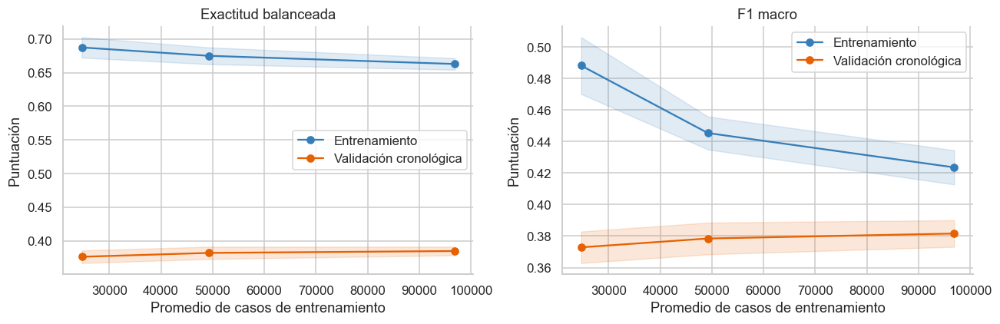

Entre 50 % y 100 % de establecimientos, la exactitud balanceada media de validación cambia **+0.0028**. Con todos los establecimientos disponibles, la brecha media entrenamiento–validación es **0.2777**. La curva permite valorar la tendencia dentro del rango observado; no demuestra que añadir filas de los mismos establecimientos tenga el mismo beneficio que incorporar establecimientos nuevos. Tampoco garantiza mejoras fuera de este periodo ni resuelve la escasez de fallecimientos.

In [31]:
learning_rows=[]
for r in evaluation['learning_curve']:
    learning_rows.append({'fraction':r['fraction'],'fold':r['fold'],'rows':r['train_rows'],'groups':r['train_groups'],
                         'train_balanced_accuracy':r['train_metrics']['balanced_accuracy'],
                         'validation_balanced_accuracy':r['validation_metrics']['balanced_accuracy'],
                         'train_macro_f1':r['train_metrics']['macro_f1'],
                         'validation_macro_f1':r['validation_metrics']['macro_f1']})
learning_table=pd.DataFrame(learning_rows)
display(learning_table.rename(columns={'fraction':'Fracción','fold':'Pliegue','rows':'Casos','groups':'Establecimientos',
    'train_balanced_accuracy':'Exactitud balanceada: entrenamiento','validation_balanced_accuracy':'Exactitud balanceada: validación',
    'train_macro_f1':'F1 macro: entrenamiento','validation_macro_f1':'F1 macro: validación'}))
learning_summary=learning_table.groupby('fraction').agg(['mean','std'])
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,title in zip(axes,['balanced_accuracy','macro_f1'],['Exactitud balanceada','F1 macro']):
    x=learning_summary[('rows','mean')].to_numpy()
    for part,label,color in [('train','Entrenamiento','#377eb8'),('validation','Validación cronológica','#e66101')]:
        mean=learning_summary[(part+'_'+metric,'mean')].to_numpy()
        std=learning_summary[(part+'_'+metric,'std')].to_numpy()
        ax.plot(x,mean,'o-',label=label,color=color)
        ax.fill_between(x,mean-std,mean+std,alpha=.15,color=color)
    ax.set(title=title,xlabel='Promedio de casos de entrenamiento',ylabel='Puntuación')
    ax.legend()
plt.tight_layout();plt.show()
curve_delta=float(learning_summary.loc[1.0,('validation_balanced_accuracy','mean')]-learning_summary.loc[.5,('validation_balanced_accuracy','mean')])
curve_gap=float(learning_summary.loc[1.0,('train_balanced_accuracy','mean')]-learning_summary.loc[1.0,('validation_balanced_accuracy','mean')])
display(Markdown(f'Entre 50 % y 100 % de establecimientos, la exactitud balanceada media de validación cambia **{curve_delta:+.4f}**. '
                 f'Con todos los establecimientos disponibles, la brecha media entrenamiento–validación es **{curve_gap:.4f}**. '
                 'La curva permite valorar la tendencia dentro del rango observado; no demuestra que añadir filas de los mismos establecimientos tenga el mismo beneficio que incorporar establecimientos nuevos. '
                 'Tampoco garantiza mejoras fuera de este periodo ni resuelve la escasez de fallecimientos.'))


La interpretación cuantitativa de la curva se genera a partir de los ajustes cronológicos anteriores. La brecha entrenamiento–validación y la tendencia se valoran sin modificar el modelo.

### 16. Evaluación en la reserva

Se evalúan LogisticRegression y DummyClassifier sobre la reserva: 127.391 casos de octubre–diciembre en establecimientos que no participaron en el desarrollo. Las predicciones provienen del ajuste final con todo el desarrollo (enero–septiembre); la reserva no se usó para elegir variables, hiperparámetros ni umbrales.

Se reportan exactitud, exactitud balanceada, F1 macro, ROC AUC macro (uno contra el resto), métricas por clase y matrices de confusión. Death tiene solo 39 casos, cada uno en un establecimiento distinto, por lo que su sensibilidad es imprecisa y se interpreta con cautela. Las métricas globales están dominadas por las tres clases frecuentes.

,LogisticRegression,DummyClassifier
Exactitud,0.523797,0.362420
Precisión ponderada,0.545451,0.131348
Sensibilidad ponderada,0.523797,0.362420
F1 ponderado,0.528647,0.192816
F1 macro,0.396591,0.133006
Exactitud balanceada,0.401928,0.250000
ROC AUC macro (uno contra el resto),0.693339,0.500000
Precisión promedio macro (uno contra el resto),0.436582,0.250000
Brier multiclase (menor es mejor),0.583329,0.664404
Pérdida logarítmica (menor es mejor),1.000859,1.097284


,Modelo,Resultado,Precisión,Sensibilidad,F1,Casos
0,LogisticRegression,Fallecimiento (Death),0.000333,0.025641,0.000657,39
1,LogisticRegression,Días de ausencia,0.600472,0.435725,0.505002,46169
2,LogisticRegression,Traslado / restricción,0.477608,0.561709,0.516256,37231
3,LogisticRegression,Otro caso registrable,0.545609,0.584638,0.564450,43952
4,DummyClassifier,Fallecimiento (Death),0.000000,0.000000,0.000000,39
5,DummyClassifier,Días de ausencia,0.362420,1.000000,0.532024,46169
6,DummyClassifier,Traslado / restricción,0.000000,0.000000,0.000000,37231
7,DummyClassifier,Otro caso registrable,0.000000,0.000000,0.000000,43952


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


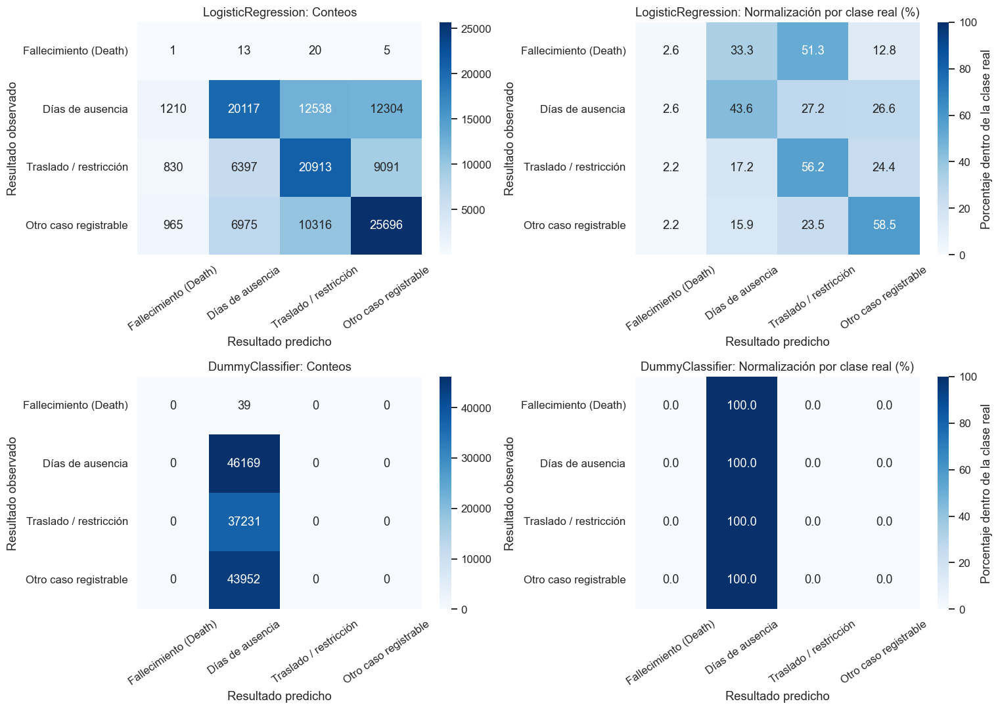

En la reserva hay **39 casos Death**, distribuidos en **39 establecimientos**. LogisticRegression obtiene precisión **0.033 %**, sensibilidad **2.56 %** y F1 **0.0007** para esta clase. El intervalo Wilson del 95 % para sensibilidad es [0.004540703100990098, 0.13180990169850076]. La métrica es imprecisa con este soporte; no demuestra una capacidad fiable para detectar fallecimientos. No se elimina Death ni se agrupa con otra clase para mejorar las métricas.

In [32]:
predictions=np.load(CACHE_DIR/'holdout_predictions.npz',allow_pickle=False)
y_test=predictions['y']
probabilities={'LogisticRegression':predictions['lr'],'DummyClassifier':predictions['dummy']}
assert len(y_test)==holdout_rows and set(y_test)=={1,2,3,4}
scores=pd.DataFrame(evaluation['holdout_metrics']).rename(index=METRIC_LABELS)
display(scores)
reports=[]
for model,report in evaluation['classification_reports'].items():
    for label in [1,2,3,4]:
        r=report[str(label)]
        reports.append({'Modelo':model,'Resultado':OUTCOMES[label],'Precisión':r['precision'],
                        'Sensibilidad':r['recall'],'F1':r['f1-score'],'Casos':int(r['support'])})
display(pd.DataFrame(reports))
fig,axes=plt.subplots(2,2,figsize=(14,10))
for row,model in enumerate(probabilities):
    cm=np.array(evaluation['confusion_matrices'][model])
    labels=list(OUTCOMES.values())
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=labels,yticklabels=labels,ax=axes[row,0])
    sns.heatmap(cm/cm.sum(axis=1,keepdims=True)*100,annot=True,fmt='.1f',vmin=0,vmax=100,cmap='Blues',
                xticklabels=labels,yticklabels=labels,ax=axes[row,1],cbar_kws={'label':'Porcentaje dentro de la clase real'})
    for col,title in enumerate(['Conteos','Normalización por clase real (%)']):
        axes[row,col].set(title=model+': '+title,xlabel='Resultado predicho',ylabel='Resultado observado')
        axes[row,col].tick_params(axis='x',rotation=35)
plt.tight_layout();plt.show()
death=evaluation['classification_reports']['LogisticRegression']['1']
display(Markdown(f'En la reserva hay **{int(death["support"])} casos Death**, distribuidos en '
                 f'**{evaluation["test_death_groups"]} establecimientos**. LogisticRegression obtiene precisión '
                 f'**{100*death["precision"]:.3f} %**, sensibilidad **{100*death["recall"]:.2f} %** y F1 **{death["f1-score"]:.4f}** para esta clase. '
                 f'El intervalo Wilson del 95 % para sensibilidad es {evaluation["death_sensitivity_wilson_ci95"]}. La métrica es imprecisa con este soporte; no demuestra una capacidad fiable para detectar fallecimientos. No se elimina Death ni se agrupa con otra clase para mejorar las métricas.'))


### 17. Curvas ROC y precisión–sensibilidad multiclase

Cada panel considera una clase positiva frente a las otras tres. Las curvas ROC pueden parecer favorables cuando hay muchos negativos; para Death debe prestarse especial atención a precisión–sensibilidad y AP. La referencia de AP sin información es la prevalencia de cada clase. AP es precisión promedio escalonada y no el área trapezoidal de la curva PR.

El panel PR de Death usa escala logarítmica en precisión para hacer visible su prevalencia muy baja; los puntos de precisión cero no son representables en esa escala. Los demás paneles conservan escala lineal.


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


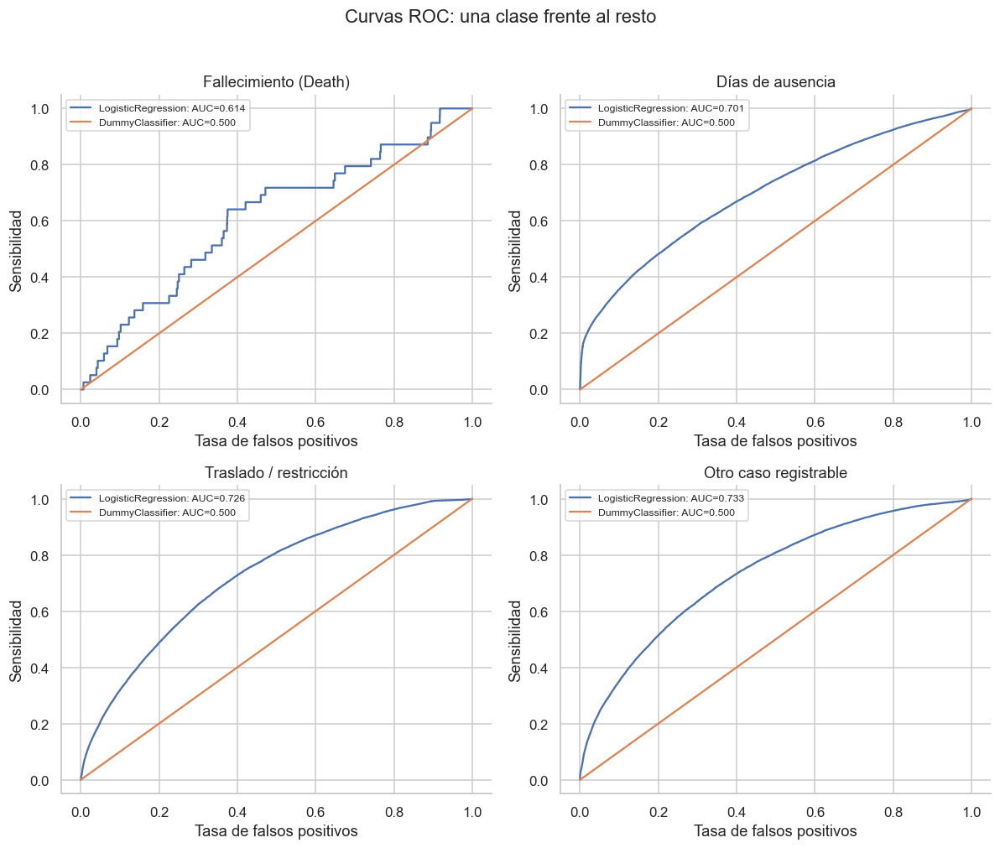

,Modelo,Resultado,ROC AUC OvR,AP OvR,Prevalencia
0,LogisticRegression,Fallecimiento (Death),0.613588,0.000504,0.000306
1,DummyClassifier,Fallecimiento (Death),0.500000,0.000306,0.000306
2,LogisticRegression,Días de ausencia,0.700761,0.625345,0.362420
3,DummyClassifier,Días de ausencia,0.500000,0.362420,0.362420
4,LogisticRegression,Traslado / restricción,0.725560,0.518257,0.292258
5,DummyClassifier,Traslado / restricción,0.500000,0.292258,0.292258
6,LogisticRegression,Otro caso registrable,0.733447,0.602221,0.345017
7,DummyClassifier,Otro caso registrable,0.500000,0.345017,0.345017


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


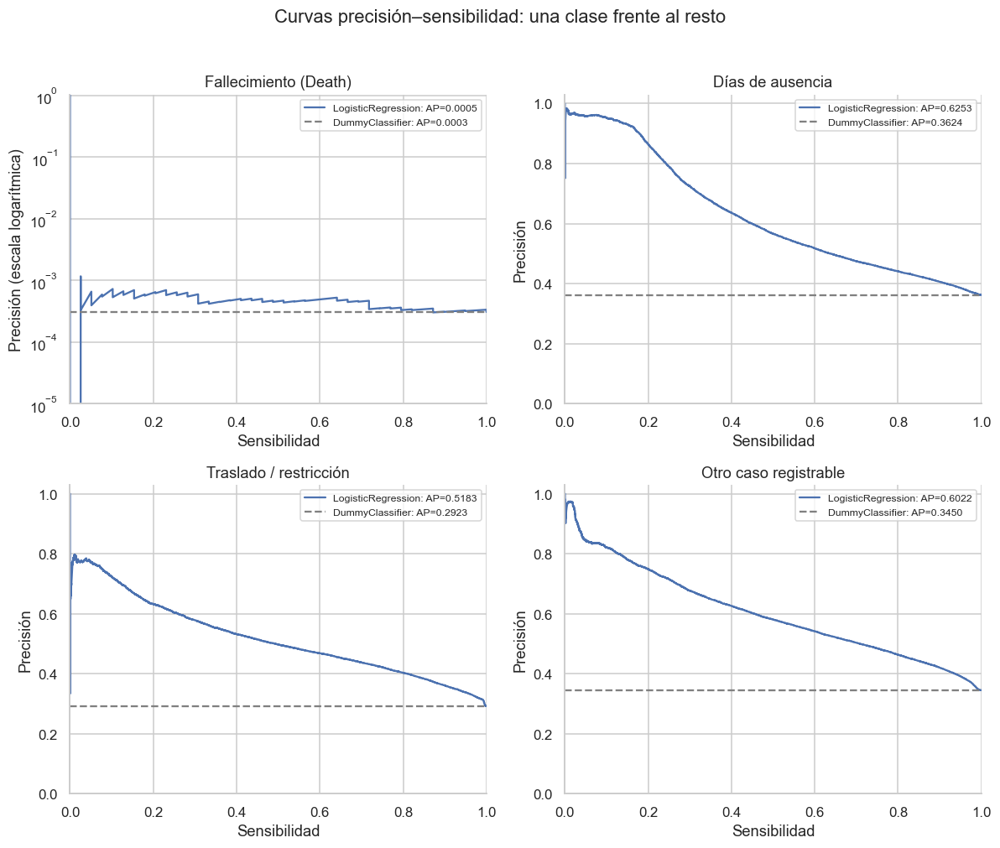

In [33]:
fig,axes=plt.subplots(2,2,figsize=(11,9))
ap_rows=[]
for k,ax in enumerate(axes.flat):
    label=k+1; binary=(y_test==label)
    for model,p in probabilities.items():
        fpr,tpr,_=roc_curve(binary,p[:,k])
        auc=roc_auc_score(binary,p[:,k])
        ax.plot(fpr,tpr,label=f'{model}: AUC={auc:.3f}')
        ap_rows.append({'Modelo':model,'Resultado':OUTCOMES[label],
                        'ROC AUC OvR':auc,'AP OvR':average_precision_score(binary,p[:,k]),
                        'Prevalencia':binary.mean()})
    ax.set(title=OUTCOMES[label],xlabel='Tasa de falsos positivos',ylabel='Sensibilidad')
    ax.legend(fontsize=8)
fig.suptitle('Curvas ROC: una clase frente al resto',y=1.02)
plt.tight_layout();plt.show()
display(pd.DataFrame(ap_rows))
fig,axes=plt.subplots(2,2,figsize=(11,9))
for k,ax in enumerate(axes.flat):
    binary=(y_test==k+1)
    precision,recall,_=precision_recall_curve(binary,probabilities['LogisticRegression'][:,k])
    ap=average_precision_score(binary,probabilities['LogisticRegression'][:,k])
    ax.plot(recall,precision,label=f'LogisticRegression: AP={ap:.4f}')
    ax.axhline(binary.mean(),linestyle='--',color='gray',label=f'DummyClassifier: AP={binary.mean():.4f}')
    ax.set(title=OUTCOMES[k+1],xlabel='Sensibilidad',ylabel='Precisión',xlim=(0,1),ylim=(0,1.03))
    if k==0:
        ax.set_yscale('log')
        ax.set_ylim(1e-5,1.03)
        ax.set_ylabel('Precisión (escala logarítmica)')
    ax.legend(fontsize=8)
fig.suptitle('Curvas precisión–sensibilidad: una clase frente al resto',y=1.02)
plt.tight_layout();plt.show()


### 18. Incertidumbre condicionada al periodo

Bootstrap pareado de establecimientos completos: 1.000 réplicas para métricas de decisiones y 200 para AUC por costo. Los intervalos están condicionados al trimestre observado y a los modelos ajustados; no capturan incertidumbre del entrenamiento ni choques comunes de calendario. Para sensibilidad de Death se muestra el intervalo score de Wilson del 95 % [Wilson (1927)](https://doi.org/10.2307/2276774). No existe un mínimo universal de casos positivos: el diseño debe fijar la precisión deseada y planificar el número de positivos con una distribución binomial [Flahault et al. (2005)](https://doi.org/10.1016/j.jclinepi.2004.12.009). Como referencia de planificación, 39 positivos darían aproximadamente ±15 puntos porcentuales si la sensibilidad verdadera estuviera cerca del 50 %; no es un umbral impuesto por el curso ni garantiza una conclusión precisa. En esta prueba hay 39 empresas distintas con un fallecimiento cada una; el intervalo observado se interpreta según la métrica calculada, no como evidencia de fiabilidad.


In [34]:
intervals=pd.DataFrame(evaluation['bootstrap']['intervals'])
intervals['point']=[evaluation['holdout_metrics'][r.model][r.metric] for r in intervals.itertuples()]
intervals['metric']=intervals.metric.map(METRIC_LABELS)
display(intervals[['model','metric','point','lower','upper','replicates']].rename(columns={
    'model':'Modelo','metric':'Métrica','point':'Estimación','lower':'Límite inferior 95 %','upper':'Límite superior 95 %','replicates':'Réplicas'}))
paired=pd.DataFrame(evaluation['bootstrap']['paired_differences'])
paired['point']=[evaluation['holdout_metrics']['LogisticRegression'][m]-evaluation['holdout_metrics']['DummyClassifier'][m] for m in paired.metric]
paired['metric']=paired.metric.map(METRIC_LABELS)
display(paired[['metric','point','lower','upper','replicates']].rename(columns={
    'metric':'Métrica','point':'Diferencia LR − Dummy','lower':'Límite inferior 95 %','upper':'Límite superior 95 %','replicates':'Réplicas'}))
print('Réplicas descartadas por ausencia de clase:',evaluation['bootstrap']['omitted_replicates'])
print('Semilla del bootstrap:',evaluation['bootstrap']['seed'])


,Modelo,Métrica,Estimación,Límite inferior 95 %,Límite superior 95 %,Réplicas
0,DummyClassifier,Exactitud,0.362420,0.356158,0.368923,1000
1,DummyClassifier,Exactitud balanceada,0.250000,0.250000,0.250000,1000
2,DummyClassifier,F1 macro,0.133006,0.131311,0.134749,1000
3,DummyClassifier,ROC AUC macro (uno contra el resto),0.500000,0.500000,0.500000,200
4,LogisticRegression,Exactitud,0.523797,0.517645,0.530388,1000
5,LogisticRegression,Exactitud balanceada,0.401928,0.392132,0.416027,1000
6,LogisticRegression,F1 macro,0.396591,0.392052,0.401538,1000
7,LogisticRegression,ROC AUC macro (uno contra el resto),0.693339,0.671020,0.714740,200


,Métrica,Diferencia LR − Dummy,Límite inferior 95 %,Límite superior 95 %,Réplicas
0,Exactitud,0.161377,0.152363,0.171063,1000
1,Exactitud balanceada,0.151928,0.142132,0.166027,1000
2,F1 macro,0.263585,0.258663,0.268808,1000
3,ROC AUC macro (uno contra el resto),0.193339,0.171020,0.214740,200


Réplicas descartadas por ausencia de clase: 0
Semilla del bootstrap: 142


#### 18.1 Sensibilidad: empresas presentes en ambas particiones

Las predicciones de prueba ya calculadas se separan según si la empresa (EIN) tiene establecimientos en el desarrollo (sección 11.1). No se reajusta nada: se comprueba si la dependencia a nivel empresa infla el desempeño.

In [35]:
import warnings
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
shared_mask = test_shared_firm.reindex(predictions['case_ids']).fillna(False).to_numpy(dtype=bool)
sensitivity_rows = []
for subset, mask in [('Empresa con establecimientos en desarrollo', shared_mask), ('Empresa sin establecimientos en desarrollo o sin EIN válido', ~shared_mask)]:
    for model, p in probabilities.items():
        predicted = np.asarray([1, 2, 3, 4])[p[mask].argmax(axis=1)]
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            sensitivity_rows.append({'Subconjunto': subset, 'Modelo': model, 'Casos': int(mask.sum()), 'Fallecimientos': int((y_test[mask] == 1).sum()),
                                     'Exactitud': accuracy_score(y_test[mask], predicted),
                                     'Exactitud balanceada (clases presentes)': balanced_accuracy_score(y_test[mask], predicted),
                                     'F1 macro (4 clases)': f1_score(y_test[mask], predicted, labels=[1, 2, 3, 4], average='macro', zero_division=0)})
firm_sensitivity = pd.DataFrame(sensitivity_rows)
display(firm_sensitivity)
lr_rows = firm_sensitivity[firm_sensitivity.Modelo.eq('LogisticRegression')].set_index('Subconjunto')
gap = lr_rows['Exactitud balanceada (clases presentes)'].iloc[0] - lr_rows['Exactitud balanceada (clases presentes)'].iloc[1]
display(Markdown(
    f"**Interpretación.** La diferencia de exactitud balanceada entre casos de empresas compartidas y no compartidas es **{gap:+.3f}**. "
    + ("Es pequeña frente a la mejora sobre la referencia trivial (≈0,15), así que la dependencia a nivel empresa no explica el resultado principal. " if abs(gap) < 0.05 else
       "No es despreciable: parte del desempeño puede deberse a prácticas de registro compartidas dentro de una empresa, y el resultado principal debe leerse con esa cautela. ")
    + "La comparación es descriptiva: ambos subconjuntos difieren también en sector y tamaño."))

,Subconjunto,Modelo,Casos,Fallecimientos,Exactitud,Exactitud balanceada (clases presentes),F1 macro (4 clases)
0,Empresa con establecimientos en desarrollo,LogisticRegression,66332,14,0.518875,0.388769,0.387092
1,Empresa con establecimientos en desarrollo,DummyClassifier,66332,14,0.334047,0.250000,0.125201
2,Empresa sin establecimientos en desarrollo o s...,LogisticRegression,61059,25,0.529144,0.399887,0.393684
3,Empresa sin establecimientos en desarrollo o s...,DummyClassifier,61059,25,0.393243,0.250000,0.141125


**Interpretación.** La diferencia de exactitud balanceada entre casos de empresas compartidas y no compartidas es **-0.011**. Es pequeña frente a la mejora sobre la referencia trivial (≈0,15), así que la dependencia a nivel empresa no explica el resultado principal. La comparación es descriptiva: ambos subconjuntos difieren también en sector y tamaño.

### 19. Calibración: diagnóstico, sin reajustar probabilidades

Se inspeccionan curvas de confiabilidad OvR con hasta diez grupos de probabilidades por cuantiles. También se reportan Brier multiclase y pérdida logarítmica. Las probabilidades de la regresión con pesos de clase corresponden a un objetivo reponderado y pueden sobreestimar clases raras respecto de su frecuencia natural. Una discriminación superior no implica probabilidades bien calibradas. No se ajusta ningún calibrador con la reserva.



C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


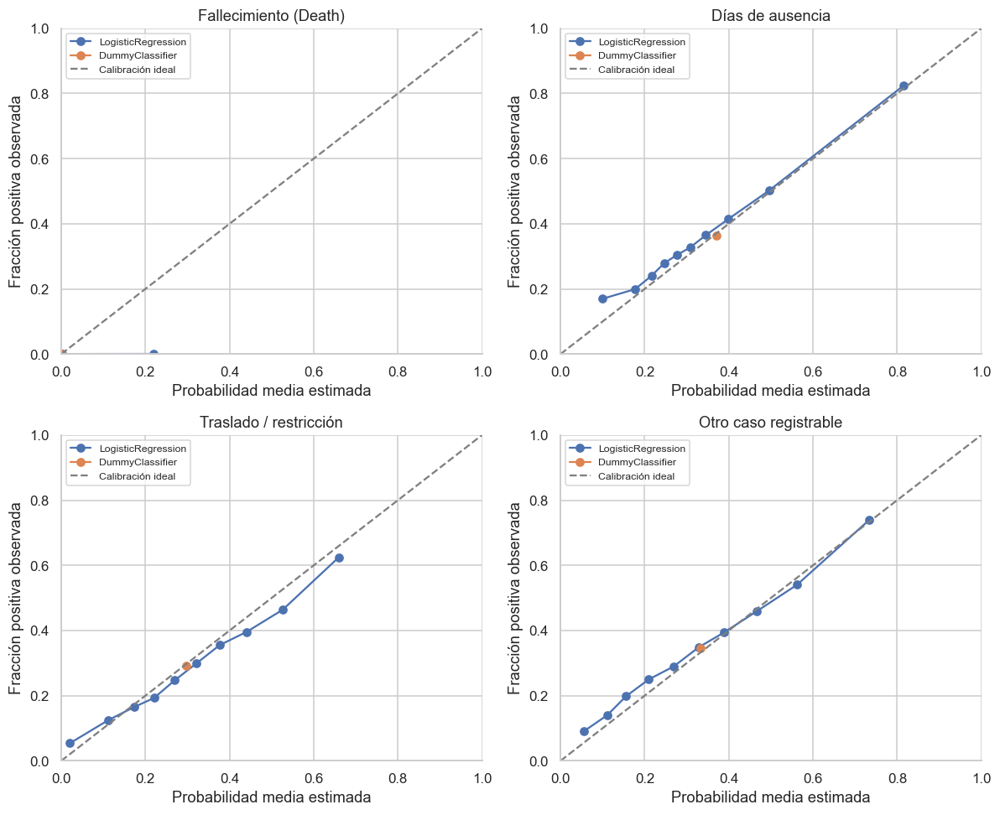

,LogisticRegression,DummyClassifier
Brier multiclase (menor es mejor),0.583329,0.664404
Pérdida logarítmica (menor es mejor),1.000859,1.097284


Brier multiclase: LR **0.5833**, Dummy **0.6644**. Pérdida logarítmica: LR **1.0009**, Dummy **1.0973**. Menor es mejor; mejora en discriminación no garantiza mejor calibración.

In [36]:
fig,axes=plt.subplots(2,2,figsize=(11,9))
for k,ax in enumerate(axes.flat):
    for model,p in probabilities.items():
        observed,estimated=calibration_curve(y_test==k+1,p[:,k],n_bins=10,strategy='quantile')
        ax.plot(estimated,observed,'o-',label=model)
    ax.plot([0,1],[0,1],'--',color='gray',label='Calibración ideal')
    ax.set(title=OUTCOMES[k+1],xlabel='Probabilidad media estimada',ylabel='Fracción positiva observada',xlim=(0,1),ylim=(0,1))
    ax.legend(fontsize=8)
plt.tight_layout();plt.show()
display(scores.loc[[METRIC_LABELS['brier_multiclass'],METRIC_LABELS['log_loss']]])

display(Markdown(f'Brier multiclase: LR **{evaluation["holdout_metrics"]["LogisticRegression"]["brier_multiclass"]:.4f}**, Dummy **{evaluation["holdout_metrics"]["DummyClassifier"]["brier_multiclass"]:.4f}**. Pérdida logarítmica: LR **{evaluation["holdout_metrics"]["LogisticRegression"]["log_loss"]:.4f}**, Dummy **{evaluation["holdout_metrics"]["DummyClassifier"]["log_loss"]:.4f}**. Menor es mejor; mejora en discriminación no garantiza mejor calibración.'))


### 20. Interpretación de coeficientes multinomiales

Se interpretan **contrastes entre categorías de un mismo predictor**, manteniendo los demás fijos. Para la clase k frente a «Otro caso registrable», el cambio de logaritmo de posibilidades al pasar de la categoría b a la a es:

`(beta[k,a] - beta[4,a]) - (beta[k,b] - beta[4,b])`.

Su exponencial es una razón de posibilidades relativa dentro del modelo. Esta comparación evita interpretar un indicador one-hot aislado como si las demás categorías del mismo predictor pudieran permanecer invariables. Se conserva la regularización y la ponderación balanceada; no se presentan intervalos inferenciales de los coeficientes. Las asociaciones **no son efectos causales**, pueden reflejar confusión y prácticas de reporte, y los coeficientes de Death son especialmente inestables. No se realiza selección de variables a partir de esta tabla.



In [37]:
final_model=joblib.load(CACHE_DIR/'final_lr.joblib')['model']
coefficient=pd.read_csv(CACHE_DIR/'coefficients.csv',index_col=0)
coefficient.columns=coefficient.columns.astype(int)
contrasts=[('type_of_incident','3','1','Afección respiratoria frente a lesión'),
           ('type_of_incident','5','1','Pérdida auditiva frente a lesión'),
           ('soc_code','29-1141','53-7062','Enfermería profesional frente a movimiento manual de materiales'),
           ('naics_code','622110','493110','Hospitales generales frente a almacenamiento general')]
rows=[]
for field,a,b,label in contrasts:
    ca,cb=f'{field}_{a}',f'{field}_{b}'
    if ca not in coefficient.index or cb not in coefficient.index:
        print('Contraste no disponible en la codificación:',field,a,b);continue
    for k in [1,2,3]:
        delta=float((coefficient.loc[ca,k]-coefficient.loc[ca,4])-(coefficient.loc[cb,k]-coefficient.loc[cb,4]))
        rows.append({'Predictor':field,'Comparación':label,'Clase frente a otro caso registrable':OUTCOMES[k],
                     'Cambio en logaritmo de posibilidades':delta,'Razón de posibilidades relativa':np.exp(delta)})
display(pd.DataFrame(rows))


,Predictor,Comparación,Clase frente a otro caso registrable,Cambio en logaritmo de posibilidades,Razón de posibilidades relativa
0,type_of_incident,Afección respiratoria frente a lesión,Fallecimiento (Death),3.802241,44.801476
1,type_of_incident,Afección respiratoria frente a lesión,Días de ausencia,2.937161,18.862224
2,type_of_incident,Afección respiratoria frente a lesión,Traslado / restricción,-1.146538,0.317735
3,type_of_incident,Pérdida auditiva frente a lesión,Fallecimiento (Death),-6.005091,0.002466
4,type_of_incident,Pérdida auditiva frente a lesión,Días de ausencia,-1.941407,0.143502
5,type_of_incident,Pérdida auditiva frente a lesión,Traslado / restricción,-1.932880,0.144731
6,soc_code,Enfermería profesional frente a movimiento man...,Fallecimiento (Death),-3.596800,0.027411
7,soc_code,Enfermería profesional frente a movimiento man...,Días de ausencia,-0.728608,0.482580
8,soc_code,Enfermería profesional frente a movimiento man...,Traslado / restricción,-0.612190,0.542162
9,naics_code,Hospitales generales frente a almacenamiento g...,Fallecimiento (Death),0.449517,1.567554


### 21. Conclusiones y límites

**Qué se encontró.**

- **Con estos datos, el problema es difícil.** Con ocho predictores estructurados, la regresión logística supera con claridad a la referencia trivial en exactitud balanceada (0,40 frente a 0,25), F1 macro (0,40 frente a 0,13) y AUC macro (0,69 frente a 0,50), aunque su desempeño es moderado. El resultado es razonable: una exactitud de 80–90 % habría hecho sospechar una fuga de información, y aquí es de 52 % (véase la nota crítica más abajo).
- **La señal proviene del lugar de trabajo y de la ocupación.** La industria (NAICS; V de Cramér = 0,24), la ocupación (SOC; 0,21) y el tipo de incidente (0,15) concentran la mayor parte de la asociación con el resultado (sección 8.1). Las dos variables horarias casi no se relacionan con él, y el estado muestra una asociación débil.
- **El fallecimiento no puede detectarse de forma fiable.** Es una clase extremadamente infrecuente: 39 casos en la prueba, cada uno en un establecimiento distinto. El modelo solo identifica 1 de ellos (sensibilidad de 2,6 %). Sus métricas se reportan con intervalos de Wilson, pero con tan pocos casos no permiten sostener una afirmación sobre el desempeño en esa clase.
- **La dependencia entre empresas no parece explicar el desempeño, pero persiste la dependencia temporal.** Ningún establecimiento aparece a la vez en desarrollo y en prueba. Aun así, el 52 % de los casos de prueba pertenece a empresas con otros establecimientos en desarrollo (sección 11.1). Al separarlos (sección 18.1), el desempeño es prácticamente el mismo (exactitud balanceada de 0,389 frente a 0,400), aunque la comparación es descriptiva. Los errores diarios sí presentan autocorrelación (0,26 al primer rezago y 0,40 a los 14 días), de modo que los intervalos del bootstrap, condicionados al trimestre observado, deben leerse con cautela.

**Qué decisiones se derivan del EDA.** Los faltantes de SOC y de hora no son aleatorios (sección 5.2.1), por lo que se codifican como categoría explícita («Unknown») sin eliminar filas; los códigos nominales y las horas se codifican como categorías; se ponderan las clases por el desbalance; no se eliminan atípicos; y se valida hacia adelante en el tiempo y separando establecimientos (trazabilidad completa en la sección 12.1).

**Límites.** La clasificación es retrospectiva y no valida un sistema de alerta. El archivo contiene solo casos reportados, sin denominadores de exposición, así que no estima riesgo de lesión ni establece causas, y los resultados cubren un solo año. Los coeficientes (sección 20) son asociaciones, no efectos.

**Siguiente paso.** Probar modelos no lineales y la ingeniería de características candidata de la sección 12.1, evaluándolos solo con validación interna.

In [38]:
lr=evaluation['holdout_metrics']['LogisticRegression']; dummy=evaluation['holdout_metrics']['DummyClassifier']
display(Markdown(f'**Resultado del ajuste corregido:** exactitud balanceada **{lr["balanced_accuracy"]:.4f}** frente a **{dummy["balanced_accuracy"]:.4f}** de DummyClassifier; '
                 f'F1 macro **{lr["macro_f1"]:.4f}** frente a **{dummy["macro_f1"]:.4f}**; '
                 f'ROC AUC macro OvR **{lr["roc_auc_macro_ovr"]:.4f}** frente a **{dummy["roc_auc_macro_ovr"]:.4f}**. '
                 f'La exactitud es **{100*lr["accuracy"]:.2f} %** frente a **{100*dummy["accuracy"]:.2f} %**. '
                 f'El ajuste convergió en **{evaluation["final_fit"]["iterations"][0]} iteraciones**, sin seleccionar parámetros por estos resultados. '
                 'La comparación debe leerse junto con los intervalos agrupados, la validación interna, las métricas de Death y el diagnóstico de calibración.'))


**Resultado del ajuste corregido:** exactitud balanceada **0.4019** frente a **0.2500** de DummyClassifier; F1 macro **0.3966** frente a **0.1330**; ROC AUC macro OvR **0.6933** frente a **0.5000**. La exactitud es **52.38 %** frente a **36.24 %**. El ajuste convergió en **27 iteraciones**, sin seleccionar parámetros por estos resultados. La comparación debe leerse junto con los intervalos agrupados, la validación interna, las métricas de Death y el diagnóstico de calibración.

In [39]:
max_univariate_auc = max(r['AUC macro OvR en agosto–septiembre'] for r in leak_audit)
frequent_auc = pd.DataFrame(ap_rows).query("Modelo == 'LogisticRegression' and Resultado != @OUTCOMES[1]")['ROC AUC OvR']
display(Markdown(
    f"**Nota crítica del enunciado.** La exactitud en prueba es **{100*lr['accuracy']:.1f} %**, por debajo del umbral de alerta de 80–90 %, y la mejor señal univariable tiene AUC macro **{max_univariate_auc:.3f}**: no hay indicios de fuga. "
    f"La exactitud supera la de la clase mayoritaria (Dummy, **{100*dummy['accuracy']:.1f} %**), y la mejora se mantiene en exactitud balanceada y F1 macro, que no se inflan con el desbalance. "
    f"El problema no es trivial: con ocho predictores estructurados, el modelo lineal discrimina moderadamente las tres clases frecuentes (AUC uno contra el resto {frequent_auc.min():.2f}–{frequent_auc.max():.2f}) y prácticamente no detecta fallecimientos. "
    "Queda margen para modelos no lineales y para la ingeniería de características de la sección 12.1 en el siguiente entregable."))

**Nota crítica del enunciado.** La exactitud en prueba es **52.4 %**, por debajo del umbral de alerta de 80–90 %, y la mejor señal univariable tiene AUC macro **0.629**: no hay indicios de fuga. La exactitud supera la de la clase mayoritaria (Dummy, **36.2 %**), y la mejora se mantiene en exactitud balanceada y F1 macro, que no se inflan con el desbalance. El problema no es trivial: con ocho predictores estructurados, el modelo lineal discrimina moderadamente las tres clases frecuentes (AUC uno contra el resto 0.70–0.73) y prácticamente no detecta fallecimientos. Queda margen para modelos no lineales y para la ingeniería de características de la sección 12.1 en el siguiente entregable.

### 22. Reproducibilidad y análisis secundarios

Entorno conda `ml_venv` (Python 3.9); sin ajuste de hiperparámetros. Los artefactos del protocolo grupo-tiempo se guardan separadamente de resultados históricos y llevan identidad de datos, código, parámetros, versiones y partición. El CSV original no se modifica. La ejecución genera la interpretación cuantitativa.

Los sectores se incluyen cuando tienen al menos 1.000 casos en desarrollo, criterio fijado sin consultar desempeño de prueba. Se muestran ambos modelos y soporte por clase. Una clase ausente impide AUC macro de cuatro clases; no se reemplaza por cero. Las diferencias sectoriales no se interpretan como rankings de seguridad.


,Paquete,Versión
0,numpy,1.25.2
1,pandas,2.1.0
2,scipy,1.11.2
3,scikit-learn,1.3.0
4,matplotlib,3.7.2
5,seaborn,0.12.2
6,joblib,1.3.2
7,threadpoolctl,3.2.0
8,ipython,8.15.0
9,statsmodels,0.14.0


Python: 3.9.25
Verificación final: datos y utilidades originales sin cambios; protocolo cronológico y predictores verificados.


### Desempeño por sector industrial

,sector,model,rows,establishments,accuracy,balanced_accuracy_present_classes,macro_f1_four_classes,class_support,auc_macro_ovr,accuracy_ci95,macro_f1_ci95,bootstrap_replicates
0,62,LogisticRegression,39169,6114,0.623733,0.397587,0.400784,"{'1': 3, '2': 15437, '3': 6296, '4': 17433}",0.724551,"[0.6139880544550576, 0.6340189635449669]","[0.39313819996026905, 0.4087321466086546]",500
1,62,DummyClassifier,39169,6114,0.394113,0.250000,0.141349,"{'1': 3, '2': 15437, '3': 6296, '4': 17433}",0.500000,"[0.3800436966999963, 0.4088725949398959]","[0.13769263144010585, 0.1451063056640785]",500
2,48-49,LogisticRegression,26451,5639,0.546520,0.331647,0.316891,"{'1': 9, '2': 10554, '3': 11492, '4': 4396}",0.659166,"[0.5314038582512246, 0.5596877097393728]","[0.3088271511401147, 0.32452082165650775]",500
3,48-49,DummyClassifier,26451,5639,0.399002,0.250000,0.142602,"{'1': 9, '2': 10554, '3': 11492, '4': 4396}",0.500000,"[0.3843362507892245, 0.4146719616291276]","[0.13881607320523476, 0.14656117206866578]",500
4,44-45,LogisticRegression,24326,9702,0.463660,0.335969,0.334052,"{'1': 3, '2': 8750, '3': 6042, '4': 9531}",0.608521,"[0.45584282331992243, 0.4718001541327423]","[0.32732289497214373, 0.34059172786290987]",500
5,44-45,DummyClassifier,24326,9702,0.359697,0.250000,0.132271,"{'1': 3, '2': 8750, '3': 6042, '4': 9531}",0.500000,"[0.35174310321319935, 0.36881690727046107]","[0.13010723030788449, 0.134721051921266]",500
6,31-33,LogisticRegression,19678,6866,0.448724,0.339999,0.314570,"{'1': 12, '2': 5325, '3': 7260, '4': 7081}",0.632741,"[0.43519781829790877, 0.46133719360562536]","[0.30515322083197227, 0.323241325443727]",500
7,31-33,DummyClassifier,19678,6866,0.270607,0.250000,0.106487,"{'1': 12, '2': 5325, '3': 7260, '4': 7081}",0.500000,"[0.25978552389207815, 0.28334489329371354]","[0.10310704439807225, 0.1103930967286367]",500
8,42,LogisticRegression,4868,1630,0.470830,0.310878,0.309838,"{'1': 2, '2': 1950, '3': 1949, '4': 967}",0.664860,"[0.4499721179382461, 0.48944663872054206]","[0.29369843952624514, 0.32297795971622417]",500
9,42,DummyClassifier,4868,1630,0.400575,0.250000,0.143004,"{'1': 2, '2': 1950, '3': 1949, '4': 967}",0.500000,"[0.37798765266507206, 0.4217108659589385]","[0.13715204627543304, 0.1483110138190617]",500


### Separación por establecimiento

Establecimientos de desarrollo: 34029
Establecimientos de prueba: 34182
Establecimientos compartidos: 0
Filas excluidas por la combinación de empresa, tiempo y purga: 493465
Establishment bootstrap is conditional on the fixed quarter and fitted models; it does not cover common calendar shocks or training uncertainty.


### Dependencia temporal de los errores

,ACF de la tasa diaria de error
1,0.259542
2,0.165501
7,0.313392
14,0.402683


C:\Users\Usuario\AppData\Local\Temp\ipykernel_47692\3774106759.py:104: UserWarning: The figure layout has changed to tight
  figure.tight_layout()


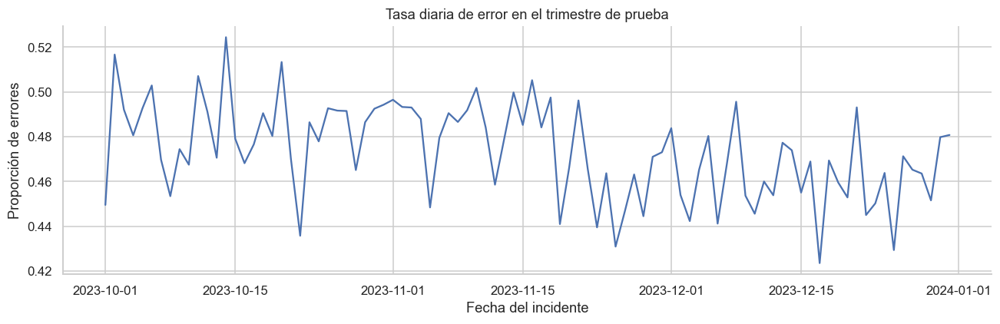

Las diferencias entre sectores se interpretan junto con soporte y los intervalos agrupados. No prueban diferencias causales ni riesgo de sufrir una lesión. La autocorrelación diaria es descriptiva y puede reflejar cambios de composición.

### Deriva descriptiva entre periodos de desarrollo

,Predictor,Distancia de variación total Q1–Q3
0,state,0.027941
1,naics_code,0.057515
2,establishment_type,0.012856
3,soc_code,0.038296
4,type_of_incident,0.018250
5,time_unknown,0.006887
6,time_started_work_hour,0.022089
7,time_of_incident_hour,0.016785


La deriva se calcula dentro del desarrollo. Cambios en composición no demuestran cambios en la relación causal ni concept drift por sí solos. La publicación de un solo año limita conclusiones sobre ciclos anuales.

In [40]:
from importlib.metadata import version
package_names=['numpy','pandas','scipy','scikit-learn','matplotlib','seaborn','joblib','threadpoolctl','ipython','statsmodels']
versions=pd.DataFrame({'Paquete':package_names,'Versión':[version(name) for name in package_names]})
display(versions)
print('Python:',sys.version.split()[0])
assert (DATA_PATH.stat().st_size,DATA_PATH.stat().st_mtime_ns)==raw_signature
assert hashlib.sha256(UTILS_PATH.read_bytes()).hexdigest()==utils_hash
assert evaluation['features']==baseline['features']
assert evaluation['train_rows']==len(train) and evaluation['test_rows']==holdout_rows
assert evaluation['group_overlap']==0 and evaluation['test_death_groups']==39
assert evaluation['train_rows']==len(train) and evaluation['test_rows']==holdout_rows
assert evaluation['group_overlap']==0 and evaluation['test_death_groups']==39
assert evaluation['final_fit']['converged'] and all(r['converged'] for r in evaluation['learning_curve'])
assert len(plt.get_fignums())==0
print('Verificación final: datos y utilidades originales sin cambios; protocolo cronológico y predictores verificados.')

sector_table=pd.DataFrame([{k:v for k,v in r.items() if k!='classification_report'} for r in evaluation['sector_analysis']])
display(Markdown('### Desempeño por sector industrial'))
display(sector_table)
display(Markdown('### Separación por establecimiento'))
print('Establecimientos de desarrollo:', evaluation['train_groups'])
print('Establecimientos de prueba:', evaluation['test_groups'])
print('Establecimientos compartidos:', evaluation['group_overlap'])
print('Filas excluidas por la combinación de empresa, tiempo y purga:', evaluation['excluded_2023_rows'])
print(evaluation['uncertainty_limit'])

display(Markdown('### Dependencia temporal de los errores'))
display(pd.Series(evaluation['daily_error_rate_acf'],name='ACF de la tasa diaria de error').to_frame())
daily_error=pd.read_csv(CACHE_DIR/'daily_test_errors.csv',parse_dates=['date'])
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(daily_error.date,daily_error['mean'])
ax.set(title='Tasa diaria de error en el trimestre de prueba',xlabel='Fecha del incidente',ylabel='Proporción de errores')
plt.tight_layout();plt.show()
display(Markdown('Las diferencias entre sectores se interpretan junto con soporte y los intervalos agrupados. No prueban diferencias causales ni riesgo de sufrir una lesión. La autocorrelación diaria es descriptiva y puede reflejar cambios de composición.'))

display(Markdown('### Deriva descriptiva entre periodos de desarrollo'))
drift=[]
for field in baseline['features']:
    z=feature_view[field].astype(object).fillna('Unknown').astype(str)
    early=z.loc[train.incident_date.lt('2023-04-01')].value_counts(normalize=True)
    late=z.loc[train.incident_date.ge('2023-07-01')].value_counts(normalize=True)
    categories=early.index.union(late.index)
    drift.append({'Predictor':field,'Distancia de variación total Q1–Q3':float(.5*(early.reindex(categories,fill_value=0)-late.reindex(categories,fill_value=0)).abs().sum())})
display(pd.DataFrame(drift))
display(Markdown('La deriva se calcula dentro del desarrollo. Cambios en composición no demuestran cambios en la relación causal ni concept drift por sí solos. La publicación de un solo año limita conclusiones sobre ciclos anuales.'))
